<a href="https://colab.research.google.com/github/tamer-kose/waterfootprint/blob/main/final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

# ---------------------------------------------------------
# 1. COLAB DOSYA YOLLARININ TANIMLANMASI
# ---------------------------------------------------------
# Dosyaları doğrudan Colab'a yüklediğiniz için /content/ dizinini kullanıyoruz.
referans_path = "/content/istasyon.xlsx"
secili_path = "/content/Secili_Istasyon_Verileri.xlsx"

# ---------------------------------------------------------
# 2. VERİLERİN BELLEĞE ALINMASI VE TEMİZLENMESİ
# ---------------------------------------------------------
print("Veri setleri Colab üzerinden okunuyor...")
df_ref = pd.read_excel(referans_path)
df_secili = pd.read_excel(secili_path)

# Referans dosyasındaki (istasyon.xlsx) karakter kodlaması hatalarını ('?stasyon Numaras?', 'Rak?m' vb.)
# aşmak için sütun isimlerini manuel olarak standartlaştırıyoruz.
df_ref.columns = ['istasyon_no', 'istasyon_adi', 'il', 'ilce', 'Enlem', 'Boylam', 'Rakim']

# Seçili veriler dosyasındaki ortak anahtarın (İstasyon Numarası) ilk sütun olduğunu varsayıyoruz.
# Eğer başlık farklıysa, veri kaybını önlemek için kod üzerinden 'istasyon_no' olarak eşitliyoruz.
df_secili.rename(columns={df_secili.columns[0]: 'istasyon_no'}, inplace=True)

# ---------------------------------------------------------
# 3. AŞAMA: 92 İSTASYONUN KARŞILAŞTIRILMASI (Uyuşmazlık Tespiti)
# ---------------------------------------------------------
print("\n--- 1. AŞAMA: Seçili İstasyon Verileri ile Referans Dosya Karşılaştırması ---")

# Ortak ID (istasyon_no) üzerinden verileri birleştir
karsilastirma = pd.merge(df_secili, df_ref, on='istasyon_no', suffixes=('_secili', '_ref'))

# Float (ondalık) hassasiyeti hatalarını önlemek için virgülden sonra 6 haneye yuvarlayıp kıyaslıyoruz
karsilastirma['Enlem_Uyumsuz'] = np.where(karsilastirma['Enlem_secili'].round(6) == karsilastirma['Enlem_ref'].round(6), False, True)
karsilastirma['Boylam_Uyumsuz'] = np.where(karsilastirma['Boylam_secili'].round(6) == karsilastirma['Boylam_ref'].round(6), False, True)

uyumsuzlar_listesi = karsilastirma[(karsilastirma['Enlem_Uyumsuz'] == True) | (karsilastirma['Boylam_Uyumsuz'] == True)]

if uyumsuzlar_listesi.empty:
    print("Sonuç: Seçili veri setindeki (92 İstasyon) koordinatlar referans dosya ile tamamen örtüşmektedir.")
else:
    print(f"Sonuç: Toplam {len(uyumsuzlar_listesi)} istasyonun koordinatlarında sapma mevcuttur. Uyumsuzluklar:")
    # Ekrana uyuşmazlık olanları bas
    print(uyumsuzlar_listesi[['istasyon_no', 'Enlem_secili', 'Enlem_ref', 'Boylam_secili', 'Boylam_ref']])

# ---------------------------------------------------------
# 4. AŞAMA: EKSİK VERİLERİN (68 İSTASYON) DOLDURULMASI / GÜNCELLENMESİ
# ---------------------------------------------------------
print("\n--- 2. AŞAMA: Eksik Mekânsal Verilerin (Enlem, Boylam, Rakım) Güncellenmesi ---")

# Veri doldurma (update) işlemi için istasyon numaralarını geçici olarak Index (satır etiketi) yapıyoruz
df_secili.set_index('istasyon_no', inplace=True)
df_ref_indexli = df_ref.set_index('istasyon_no')

# Referans dosyadaki Enlem, Boylam ve Rakim sütunlarını Seçili dosyaya enjekte ediyoruz
df_secili.update(df_ref_indexli[['Enlem', 'Boylam', 'Rakim']])

# İndeksi tekrar normal sütuna dönüştürüyoruz
df_secili.reset_index(inplace=True)

# ---------------------------------------------------------
# 5. DIŞA AKTARIM
# ---------------------------------------------------------
cikti_yolu = "/content/Secili_Istasyon_Verileri_Guncellenmis.xlsx"
df_secili.to_excel(cikti_yolu, index=False)

print(f"İşlem tamamlandı! Enlem, Boylam ve Rakım verileri güncellenen nihai dosya şu konuma kaydedildi:\n{cikti_yolu}")

Veri setleri Colab üzerinden okunuyor...

--- 1. AŞAMA: Seçili İstasyon Verileri ile Referans Dosya Karşılaştırması ---
Sonuç: Toplam 160 istasyonun koordinatlarında sapma mevcuttur. Uyumsuzluklar:
     istasyon_no  Enlem_secili  Enlem_ref  Boylam_secili  Boylam_ref
0          17015       41.0865  41.089500        31.1384   31.137400
1          17684       40.1554  40.162300        38.0870   38.075200
2          17020       41.6190  41.624800        32.3528   32.356900
3          17688       40.2895  40.301300        41.5524   41.540900
4          17022       41.4477  41.449242        31.7895   31.777917
..           ...           ...        ...            ...         ...
155        19226           NaN  41.628990            NaN   35.556600
156        17602       41.7362  41.752600        32.3826   32.382700
157        19903           NaN  39.800997            NaN   44.071791
158        17614           NaN  40.408800            NaN   27.060000
159        19991           NaN  41.059440  

In [ ]:
import pandas as pd
from google.colab import files

# 1. Temel Veri Setinin Okunması
veri_yolu = "ET0mm_F_160.xlsx"
df_et0 = pd.read_excel(veri_yolu)

# 2. 2023 Yılı İçin 365 Günlük Referans Takviminin Oluşturulması
# 1 Ocak 2023 - 31 Aralık 2023 tarihleri arasını kapsayan zaman dizisi
tarihler = pd.date_range(start="2023-01-01", end="2023-12-31")
takvim_df = pd.DataFrame({'Tarih': tarihler})

# Takvim verisinden Yıl, Ay, Gün ve Yılın Günü (DOY) parametrelerinin çıkarılması
takvim_df['YYYY'] = takvim_df['Tarih'].dt.year
takvim_df['MM'] = takvim_df['Tarih'].dt.month
takvim_df['DD'] = takvim_df['Tarih'].dt.day
takvim_df['DOY'] = takvim_df['Tarih'].dt.dayofyear

# 3. İstasyon Verileri ile Takvimin Çapraz Birleştirilmesi (Cross Join)
# Orijinal veri setindeki benzersiz (unique) istasyon numaralarının çekilmesi
istasyonlar = pd.DataFrame({'Station_no': df_et0['station_no'].dropna().unique()})

# Her bir istasyon numarası ile 365 günlük takvimin eşleştirilerek tam matrisin oluşturulması
df_iskelet = istasyonlar.merge(takvim_df, how='cross')

# 4. Eslestirme_ID Parametresinin Dinamik Olarak Üretilmesi
# Format: İstasyonNo_YYYY_MM_DD (Örn: 17015_2023_1_1)
df_iskelet['Eslestirme_ID'] = (
    df_iskelet['Station_no'].astype(int).astype(str) + "_" +
    df_iskelet['YYYY'].astype(str) + "_" +
    df_iskelet['MM'].astype(str) + "_" +
    df_iskelet['DD'].astype(str)
)

# 5. Eksik Verilerin Orijinal Veri Seti ile Entegrasyonu
# Mevcut ET0 verilerinin tam zaman serisi üzerine Sol Birleştirme (Left Join) ile aktarılması
# Bu işlem sonucunda orijinal dosyada olmayan tarihler iskelete eklenecek, ET0mm değeri NaN (boş) kalacaktır.

# Sütun tekrarını önlemek için orijinal veriden yalnızca Eslestirme_ID ve hedeflenen veri sütunları çekilir
# Eğer orijinal tabloda halihazırda 'YYYY', 'MM', 'DD' sütunları varsa, mükerrerliği önlemek adına sadece 'Eslestirme_ID' ve 'ET0mm' üzerinden birleştirme yapılır.
df_birlesik = pd.merge(
    df_iskelet,
    df_et0[['Eslestirme_ID', 'ET0mm']],
    on='Eslestirme_ID',
    how='left'
)

# İstasyonların meta verilerini (Enlem, Boylam, Rakım vb.) orijinal veriden alıp boş kalan satırlara kopyalamak için:
istasyon_meta = df_et0.drop(columns=['Eslestirme_ID', 'ET0mm', 'YYYY', 'MM', 'DD', 'DOY', 'Tarih'], errors='ignore').drop_duplicates(subset=['station_no'])
# Rename 'station_no' to 'Station_no' in istasyon_meta to match df_birlesik
istasyon_meta.rename(columns={'station_no': 'Station_no'}, inplace=True)
df_nihai = pd.merge(df_birlesik, istasyon_meta, on='Station_no', how='left')

# 6. Tamamlanmış Zaman Serisi Veri Setinin Dışa Aktarılması
cikis_dosyasi = "ET0mm_F_160_Takvim_Tamamlanmis.xlsx"
df_nihai.to_excel(cikis_dosyasi, index=False)
files.download(cikis_dosyasi)

print(f"Zaman serisi tamamlama işlemi başarılı. Toplam satır sayısı: {len(df_nihai)})")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Zaman serisi tamamlama işlemi başarılı. Toplam satır sayısı: 58400)


In [ ]:
import pandas as pd
from google.colab import files

# 1. Veri Setlerinin Çalışma Ortamına Alınması
# Colab dizinine yüklenen Excel dosyalarının pandas veri çerçevelerine aktarılması
df_et0 = pd.read_excel("ET0mm_F_160.xlsx")
df_tmax = pd.read_excel("Tmax_F_160.xlsx")
df_tmin = pd.read_excel("Tmin_F_160.xlsx")
df_rain = pd.read_excel("Rain_mm_OMGI_F_160.xlsx")
df_station = pd.read_excel("station_160blg_grid.xlsx")

# 2. İklim Parametrelerinin Optimizasyonu
# Sütun karmaşasını (dublicate columns) önlemek adına birleştirilecek dosyalardan
# yalnızca referans ID ve hedef değişkenlerin filtrelenmesi
df_tmax_hedef = df_tmax[['Eslestirme_ID', 'TmaxC']]
df_tmin_hedef = df_tmin[['Eslestirme_ID', 'TminC']]
df_rain_hedef = df_rain[['Eslestirme_ID', 'Rain_mm']]

# 3. İklim Verilerinin Temel Veri Seti Üzerinde Birleştirilmesi
# Sol birleştirme (left join) yöntemi ile veri kaybının önüne geçilmesi
df_merge_1 = pd.merge(df_et0, df_tmax_hedef, on='Eslestirme_ID', how='left')
df_merge_2 = pd.merge(df_merge_1, df_tmin_hedef, on='Eslestirme_ID', how='left')
df_iklim_birlestirilmis = pd.merge(df_merge_2, df_rain_hedef, on='Eslestirme_ID', how='left')

# Sütun isimlerindeki büyük/küçük harf uyumsuzluğunu giderme
df_iklim_birlestirilmis.rename(columns={'station_no': 'Station_no'}, inplace=True)

# 4. İstasyon Meta Verilerinin (Mekânsal Konumların) Entegrasyonu
# İstasyon dosyasından lokasyon bildiren sütunların ayıklanması
df_station_hedef = df_station[['Station_no', 'Enlem', 'Boylam', 'Rakim', 'BLG']]

# Sütun isimlendirmelerinde oluşabilecek potansiyel uyuşmazlıkları aşmak için
# Station_no değişkeninin tam eşleştiğinden emin olunarak son birleştirmenin yapılması
df_final = pd.merge(df_iklim_birlestirilmis, df_station_hedef, on='Station_no', how='left')

# 5. Nihai Veri Setinin Dışa Aktarılması
# Entegre edilmiş yapının yeni bir dosya olarak kaydedilmesi ve Colab üzerinden indirilmesi
dosya_adi = "Entegre_Iklim_Veri_Seti.xlsx"
df_final.to_excel(dosya_adi, index=False)
files.download(dosya_adi)

print(f"İşlem başarıyla tamamlandı. {len(df_final)} satırlık veri seti oluşturuldu.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

İşlem başarıyla tamamlandı. 58400 satırlık veri seti oluşturuldu.


In [ ]:
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist

# 1. Veri setinin çalışma ortamına alınması
dosya_yolu = 'Climate_160blg.xlsx'
print(f"'{dosya_yolu}' dosyası okunuyor...")
df = pd.read_excel(dosya_yolu)

# Kronolojik enterpolasyonun hatalı hesaplanmaması için verinin tarihe göre sıralanması
df['Tarih'] = pd.to_datetime(df['Tarih'])
df = df.sort_values(by=['Station_no', 'Tarih']).reset_index(drop=True)

# ---------------------------------------------------------
# AŞAMA 1: SICAKLIK VERİLERİ (DOĞRUSAL ENTERPOLASYON)
# ---------------------------------------------------------
print("1. Aşama: Eksik TminC ve TmaxC verileri istasyon bazlı doğrusal enterpolasyon ile tamamlanıyor...")

# limit_direction='both' argümanı, serinin en başında veya en sonunda yer alan eksik verilerin de kapsanmasını sağlar.
df['TminC'] = df.groupby('Station_no')['TminC'].transform(lambda x: x.interpolate(method='linear', limit_direction='both'))
df['TmaxC'] = df.groupby('Station_no')['TmaxC'].transform(lambda x: x.interpolate(method='linear', limit_direction='both'))


# ---------------------------------------------------------
# AŞAMA 2: YAĞIŞ VERİLERİ (K-EN YAKIN KOMŞU MEDYANI)
# ---------------------------------------------------------
print("2. Aşama: Eksik Rain_mm verileri aynı BLG içindeki K-En Yakın Komşu medyanı ile tamamlanıyor...")

def fill_rain_knn_median(data, k=3):
    df_filled = data.copy()

    # Mesafe hesaplamaları için istasyonların tekil koordinat referans matrisini oluştur
    stations = df_filled.drop_duplicates('Station_no').set_index('Station_no')[['Enlem', 'Boylam']]

    # Sadece yağış verisi eksik olan iterasyonları izole et
    missing_rain = df_filled[df_filled['Rain_mm'].isnull()]

    for idx, row in missing_rain.iterrows():
        date = row['Tarih']
        target_station = row['Station_no']
        target_blg = row['BLG']
        target_coords = stations.loc[target_station].values.reshape(1, -1)

        # Eksik verinin yaşandığı spesifik güne ait tüm aktif ölçümleri al
        day_data = df_filled[(df_filled['Tarih'] == date) & (df_filled['Rain_mm'].notnull())]

        # Hatalı eşleşmeleri önlemek adına, yalnızca AYNI BLG koduna sahip olan istasyonları aday listesine ekle
        candidates = day_data[day_data['BLG'] == target_blg]

        # Opsiyonel: Veri setinde tek istasyona sahip BLG'ler olması veya aynı BLG'deki tüm verilerin o gün eksik olması
        # durumunda Null bırakmamak için küresel en yakın komşuya geçiş (Fallback)
        if len(candidates) == 0:
            candidates = day_data

        if len(candidates) > 0:
            # Aday istasyonlar ile hedef istasyon arasındaki Öklid mesafesini hesapla
            candidate_coords = stations.loc[candidates['Station_no']].values
            distances = cdist(target_coords, candidate_coords)[0]

            # Gerçek K değerini belirle (Aday sayısı K'dan küçükse var olanların tamamını kullan)
            k_actual = min(k, len(candidates))
            nearest_indices = np.argsort(distances)[:k_actual]

            # K adet mekânsal komşunun medyan değerini alarak eksik veriye ata
            median_rain = np.median(candidates.iloc[nearest_indices]['Rain_mm'])
            df_filled.at[idx, 'Rain_mm'] = median_rain

    return df_filled

# K parametresini tezinizdeki literatür varsayımlarına göre 3, 5 veya 7 olarak ayarlayabilirsiniz.
df = fill_rain_knn_median(df, k=3)

# ---------------------------------------------------------
# AŞAMA 3: DIŞA AKTARIM
# ---------------------------------------------------------
cikti_dosyasi = 'Climate_160blg_Tamamlanmis.xlsx'
df.to_excel(cikti_dosyasi, index=False)
print(f"Tüm istatistiksel imputasyon işlemleri tamamlandı. Temizlenmiş veri seti '{cikti_dosyasi}' olarak kaydedildi.")

'Climate_160blg.xlsx' dosyası okunuyor...
1. Aşama: Eksik TminC ve TmaxC verileri istasyon bazlı doğrusal enterpolasyon ile tamamlanıyor...
2. Aşama: Eksik Rain_mm verileri aynı BLG içindeki K-En Yakın Komşu medyanı ile tamamlanıyor...
Tüm istatistiksel imputasyon işlemleri tamamlandı. Temizlenmiş veri seti 'Climate_160blg_Tamamlanmis.xlsx' olarak kaydedildi.


In [ ]:
import pandas as pd
import numpy as np

# 1. Veri Setinin İçeri Aktarılması
# İşlem yapılacak veri seti dosya yolunu belirtiniz.
df = pd.read_excel("Climate_58400.xlsx")

# 2. Enlem (Latitude) Değerinin Radyana Dönüştürülmesi
# FAO-56 Eşitlik 22: phi (radyan) = (pi / 180) * enlem (derece)
df['Enlem_rad'] = (np.pi / 180) * df['Enlem']

# 3. Dünya-Güneş Arası Nispi Mesafe (dr) ve Güneşin Sapma Açısı (delta) Hesaplaması
# J = DOY (Day of Year - Yılın Günü)
# FAO-56 Eşitlik 23: dr = 1 + 0.033 * cos(2 * pi * J / 365)
df['dr'] = 1 + 0.033 * np.cos(2 * np.pi * df['DOY'] / 365)

# FAO-56 Eşitlik 24: delta = 0.409 * sin((2 * pi * J / 365) - 1.39)
df['delta'] = 0.409 * np.sin((2 * np.pi * df['DOY'] / 365) - 1.39)

# 4. Gün Batımı Saat Açısı (omega_s) Hesaplaması
# FAO-56 Eşitlik 25: omega_s = arccos(-tan(phi) * tan(delta))
# np.clip kullanılarak olası ekstrem enlem/matematiksel yuvarlama hatalarının (-1, 1 aralığı dışına çıkma) önüne geçilir
tan_term = -np.tan(df['Enlem_rad']) * np.tan(df['delta'])
tan_term = np.clip(tan_term, -1.0, 1.0)
df['omega_s'] = np.arccos(tan_term)

# 5. Atmosfer Dışı Güneş Radyasyonu (Ra) Hesaplaması
# Gsc (Solar Constant) = 0.0820 MJ m-2 min-1
# FAO-56 Eşitlik 21: Ra = (24 * 60 / pi) * Gsc * dr * [omega_s * sin(phi) * sin(delta) + cos(phi) * cos(delta) * sin(omega_s)]
Gsc = 0.0820
df['Ra_MJ_m2_gun'] = (24 * 60 / np.pi) * Gsc * df['dr'] * (
    df['omega_s'] * np.sin(df['Enlem_rad']) * np.sin(df['delta']) +
    np.cos(df['Enlem_rad']) * np.cos(df['delta']) * np.sin(df['omega_s'])
)

# Ara işlem sütunlarının temizlenmesi (isteğe bağlı)
df = df.drop(columns=['Enlem_rad', 'dr', 'delta', 'omega_s', 'tan_term'], errors='ignore')
# Hesaplanan Ra değerlerini 0,01 hassasiyetine yuvarlama
df['Ra_MJ_m2_gun'] = df['Ra_MJ_m2_gun'].round(2)
# 6. Hesaplanan Ra Değerlerinin Bulunduğu Setin Dışa Aktarılması
df.to_excel("ET0mm_F_160_Ra_Eklenmis.xlsx", index=False)
print("FAO-56 standartlarına uygun Ra hesaplaması tamamlandı ve veri setine eklendi.")

FAO-56 standartlarına uygun Ra hesaplaması tamamlandı ve veri setine eklendi.


In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import warnings
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error, r2_score
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from google.colab import drive

# Uyarı mesajlarının gizlenmesi
warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
print("Google Drive bağlantısı kuruluyor...")
drive.mount('/content/drive', force_remount=False)

# Temel çalışma dizini
ana_dizin = "/content/drive/MyDrive/Doktora"
# Modellerin kaydedileceği alt klasör
model_dizini = os.path.join(ana_dizin, "Egitilmis_Modeller")

# Klasör mevcut değilse oluşturulması
if not os.path.exists(model_dizini):
    os.makedirs(model_dizini)
    print(f"'{model_dizini}' dizini oluşturuldu.")

# Girdi ve çıktı dosya yollarının tanımlanması
giris_dosyasi = os.path.join(ana_dizin, "Climate_58400_Ra.xlsx")
# Görselinizdeki yapıya uygun çıktı ismi
cikis_dosyasi = os.path.join(ana_dizin, "Climate_58400_Tamamlanmis_Global_SuperEnsemble.xlsx")

# =====================================================================
# 2. VERİ SETİNİN YÜKLENMESİ VE HAZIRLANMASI
# =====================================================================
print(f"\nVeri seti okunuyor: {giris_dosyasi}")
df = pd.read_excel(giris_dosyasi)

ozellikler = ['TmaxC', 'TminC', 'Rain_mm', 'Ra', 'Enlem', 'Boylam', 'Rakim', 'DOY']

# Veri setinin eksik ve mevcut ET0 değerlerine göre ayrıştırılması
df_bilinen = df[df['ET0mm'].notna()].copy()
df_eksik = df[df['ET0mm'].isna()].copy()

X = df_bilinen[ozellikler]
y = df_bilinen['ET0mm']

# Eğitim ve test setlerinin %80-%20 oranında bölünmesi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Değişkenlerin yapay sinir ağları mimarileri için ölçeklendirilmesi
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
X_eksik_scaled = scaler.transform(df_eksik[ozellikler])

# Derin öğrenme (LSTM) algoritması için 3 boyutlu tensör (Samples, TimeSteps, Features) yapılandırması
X_train_lstm = X_train_scaled.reshape(X_train_scaled.shape[0], 1, X_train_scaled.shape[1])
X_test_lstm = X_test_scaled.reshape(X_test_scaled.shape[0], 1, X_test_scaled.shape[1])
X_eksik_lstm = X_eksik_scaled.reshape(X_eksik_scaled.shape[0], 1, X_eksik_scaled.shape[1])

# =====================================================================
# 3. MODELLERİN EĞİTİLMESİ
# =====================================================================
print("\nModeller eğitiliyor, bu süreç donanım kaynaklarına bağlı olarak zaman alabilir...")

rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, random_state=42)
xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)

ann_model = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=500, random_state=42)
ann_model.fit(X_train_scaled, y_train)
ann_pred = ann_model.predict(X_test_scaled)

lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(1, len(ozellikler))),
    Dense(32, activation='relu'),
    Dense(1)
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train_lstm, y_train, epochs=20, batch_size=64, verbose=0)
lstm_pred = lstm_model.predict(X_test_lstm, verbose=0).flatten()

# =====================================================================
# 4. PERFORMANS METRİKLERİNİN RAPORLANMASI
# =====================================================================
modeller = {
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
    "ANN (MLP)": ann_pred,
    "LSTM": lstm_pred
}

print("\n" + "-" * 45)
print(f"{'Algoritma Türü':<20} | {'Model':<10} | {'RMSE':<8} | {'R²':<6}")
print("-" * 45)
for isim, tahmin in modeller.items():
    rmse = np.sqrt(mean_squared_error(y_test, tahmin))
    r2 = r2_score(y_test, tahmin)
    tur = "Karar Ağaçları" if "Forest" in isim or "XGBoost" in isim else ("Derin Öğrenme" if "LSTM" in isim else "Sinir Ağları")
    print(f"{tur:<20} | {isim:<10} | {rmse:<8.4f} | {r2:<.4f}")
print("-" * 45)

# =====================================================================
# 5. EKSİK VERİLERİN HİBRİT YAKLAŞIM İLE EKSİK DEĞER ATAMASI VE KAYIT
# =====================================================================
print("\nEksik 2.842 veri hibrit (ensemble) yöntemle tahmin ediliyor...")
rf_eksik_pred = rf_model.predict(df_eksik[ozellikler])
xgb_eksik_pred = xgb_model.predict(df_eksik[ozellikler])
ann_eksik_pred = ann_model.predict(X_eksik_scaled)
lstm_eksik_pred = lstm_model.predict(X_eksik_lstm, verbose=0).flatten()

# Dört algoritmanın sonuçlarının aritmetik ortalaması
hibrit_tahmin = (rf_eksik_pred + xgb_eksik_pred + ann_eksik_pred + lstm_eksik_pred) / 4

# Verinin ana sete entegrasyonu ve 0.01 hassasiyetine yuvarlanması
df.loc[df['ET0mm'].isna(), 'ET0mm'] = np.round(hibrit_tahmin, 2)

# Tamamlanan setin dışa aktarılması
df.to_excel(cikis_dosyasi, index=False)
print(f"\nTamamlanmış veri seti Google Drive'a kaydedildi:\n-> {cikis_dosyasi}")

# =====================================================================
# 6. EĞİTİLMİŞ MODELLERİN VE SCALER DOSYASININ DIŞA AKTARILMASI
# =====================================================================
print("\nModeller ve ölçeklendirici (Scaler) kalıcı olarak Drive'a kaydediliyor...")

joblib.dump(scaler, os.path.join(model_dizini, "Turkiye_Geneli_Scaler.pkl"))
joblib.dump(rf_model, os.path.join(model_dizini, "Turkiye_Geneli_RF_Model.pkl"))
joblib.dump(xgb_model, os.path.join(model_dizini, "Turkiye_Geneli_XGB_Model.pkl"))
joblib.dump(ann_model, os.path.join(model_dizini, "Turkiye_Geneli_ANN_Model.pkl"))
lstm_model.save(os.path.join(model_dizini, "Turkiye_Geneli_LSTM_Model.keras"))

print(f"İşlem başarıyla tamamlandı! Gelecek RCP/SSP senaryoları için kullanılacak tüm dosyalar '{model_dizini}' dizininde güvence altına alınmıştır.")

Google Drive bağlantısı kuruluyor...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Veri seti okunuyor: /content/drive/MyDrive/Doktora/Climate_58400_Ra.xlsx

Modeller eğitiliyor, bu süreç donanım kaynaklarına bağlı olarak zaman alabilir...

---------------------------------------------
Algoritma Türü       | Model      | RMSE     | R²    
---------------------------------------------
Karar Ağaçları       | Random Forest | 1.8511   | 0.8653
Karar Ağaçları       | XGBoost    | 1.8885   | 0.8598
Sinir Ağları         | ANN (MLP)  | 2.2273   | 0.8050
Derin Öğrenme        | LSTM       | 2.5797   | 0.7384
---------------------------------------------

Eksik 2.842 veri hibrit (ensemble) yöntemle tahmin ediliyor...

Tamamlanmış veri seti Google Drive'a kaydedildi:
-> /content/drive/MyDrive/Doktora/Climate_58400_Tamamlanmis_Global_SuperEnsemble.xlsx

Modeller ve ölçeklendirici (Scaler) kalıcı olarak Drive'a kayded

In [ ]:
import ee
import pandas as pd
import numpy as np
import os
import re
from google.colab import drive

print("🌍 Google Earth Engine Kimlik Doğrulaması Başlatılıyor...")
# GEE Authentication ve Initialization
try:
    ee.Initialize()
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='ee-tamerkose1')

print("✅ GEE Bağlantısı Başarılı!")

print("📁 Google Drive Bağlantısı Kuruluyor...")
# Doğrudan aktarım için Google Drive sisteme entegre ediliyor
drive.mount('/content/drive', force_remount=False)
print("✅ Google Drive Başarıyla Bağlandı!")

# Çıktıların kaydedileceği klasörün Drive içinde oluşturulması
drive_hedef_klasor = "/content/drive/MyDrive/Iklim_Verileri_2021_2098"
if not os.path.exists(drive_hedef_klasor):
    os.makedirs(drive_hedef_klasor)

# 1. İstasyon Verilerinin Yüklenmesi (YOL GÜNCELLENDİ)
dosya_adi = "/content/drive/MyDrive/Doktora/Climate_58400SON.xlsx"
df_istasyon = pd.read_excel(dosya_adi)

istasyonlar = df_istasyon[['Station_no', 'Enlem', 'Boylam']].drop_duplicates()
print(f"Toplam {len(istasyonlar)} benzersiz istasyon işleme alınıyor...")

features = []
for index, row in istasyonlar.iterrows():
    pt = ee.Feature(ee.Geometry.Point([row['Boylam'], row['Enlem']]), {'station_no': str(row['Station_no'])})
    features.append(pt)
fc = ee.FeatureCollection(features)

# =====================================================================
# YENİ MODÜL: STATİK GRİD ID (PİKSEL KİMLİĞİ) VE KOORDİNATLARI ÇIKARMA
# =====================================================================
print("🔍 İstasyonların beslendiği kaynak pikseller (Grid ID ve Koordinatlar) hesaplanıyor...")
sample_image = ee.ImageCollection('NASA/GDDP-CMIP6').first().select('tasmax')
land_mask = sample_image.mask()

lon_img = ee.Image.pixelLonLat().select('longitude')
lat_img = ee.Image.pixelLonLat().select('latitude')

valid_lon = lon_img.updateMask(land_mask).unmask(lon_img.focal_mean(radius=1.5, units='pixels'))
valid_lat = lat_img.updateMask(land_mask).unmask(lat_img.focal_mean(radius=1.5, units='pixels'))

grid_image = ee.Image.cat([valid_lon, valid_lat])
grid_extracted = grid_image.reduceRegions(collection=fc, reducer=ee.Reducer.first(), scale=27830).getInfo()

# Grid bilgilerini hem ID hem de Koordinat olarak saklıyoruz
grid_dict = {}
for feature in grid_extracted['features']:
    st = feature['properties'].get('station_no')
    g_lon = feature['properties'].get('longitude')
    g_lat = feature['properties'].get('latitude')

    if g_lon is not None and g_lat is not None:
        grid_dict[st] = {
            'Grid_ID': f"Grid_{round(g_lat, 3)}_{round(g_lon, 3)}",
            'Grid_Lat': round(g_lat, 5), # Grid Enlemi
            'Grid_Lon': round(g_lon, 5)  # Grid Boylamı
        }
    else:
        grid_dict[st] = {'Grid_ID': "No_Grid", 'Grid_Lat': np.nan, 'Grid_Lon': np.nan}

# =====================================================================

# 2. İklim Modelleri, Senaryolar ve Hedef Yıllar
modeller = ['HadGEM3-GC31-LL', 'MPI-ESM1-2-HR']
senaryolar = ['ssp245', 'ssp585']
yillar = [2021, 2022, 2023, 2024, 2025, 2046, 2047, 2048, 2049, 2050, 2069, 2070, 2071, 2072, 2073, 2096, 2097, 2098]

def process_and_fill_gaps(img):
    filled_img = img.unmask(img.focal_mean(radius=1.5, units='pixels'))
    date_str = ee.Date(filled_img.get('system:time_start')).format('YYYY_MM_dd')
    new_names = filled_img.bandNames().map(lambda b: ee.String('T').cat(date_str).cat('_').cat(b))
    return filled_img.rename(new_names)

# 3. İndirme ve İşleme Döngüsü
toplam_islem = len(modeller) * len(senaryolar) * len(yillar)
islem_sayaci = 1

for model in modeller:
    for senaryo in senaryolar:
        for yil in yillar:
            print(f"[{islem_sayaci}/{toplam_islem}] Çekiliyor: {model} | {senaryo} | {yil}...")

            baslangic = f'{yil}-01-01'
            bitis = f'{yil+1}-01-01'

            dataset = ee.ImageCollection('NASA/GDDP-CMIP6') \
                .filter(ee.Filter.eq('model', model)) \
                .filter(ee.Filter.eq('scenario', senaryo)) \
                .filterDate(baslangic, bitis) \
                .select(['tasmin', 'tasmax', 'pr']) \
                .map(process_and_fill_gaps)

            if dataset.size().getInfo() == 0:
                print(f"Uyarı: Kataloğunda {model} | {senaryo} | {yil} için veri bulunamadı.")
                islem_sayaci += 1
                continue

            multi_band_img = dataset.toBands()

            try:
                extracted = multi_band_img.reduceRegions(
                    collection=fc,
                    reducer=ee.Reducer.first(),
                    scale=27830
                ).getInfo()
            except Exception as e:
                print(f"Hata oluştu ({yil}): {e}")
                islem_sayaci += 1
                continue

            parsed_data = []
            for feature in extracted['features']:
                props = feature['properties']
                st_no = props.get('station_no')

                dates_dict = {}
                for key, val in props.items():
                    match = re.search(r'T(\d{4})_(\d{2})_(\d{2})_([a-zA-Z]+)', key)
                    if match:
                        y, m, d, param = match.groups()
                        if int(y) != yil:
                            continue

                        date_str = f"{y}-{m}-{d}"

                        if date_str not in dates_dict:
                            dates_dict[date_str] = {}
                        dates_dict[date_str][param] = val

                for d_str, vals in dates_dict.items():
                    # İlgili istasyonun grid bilgilerini sözlükten çek
                    grid_info = grid_dict.get(st_no, {'Grid_ID': 'No_Grid', 'Grid_Lat': np.nan, 'Grid_Lon': np.nan})

                    parsed_data.append({
                        'station_no': st_no,
                        'Grid_ID': grid_info['Grid_ID'],
                        'Grid_Lat': grid_info['Grid_Lat'], # Grid Enlemi Sütunu
                        'Grid_Lon': grid_info['Grid_Lon'], # Grid Boylamı Sütunu
                        'Tarih': d_str,
                        'tasmax': vals.get('tasmax'),
                        'tasmin': vals.get('tasmin'),
                        'pr': vals.get('pr')
                    })

            res_df = pd.DataFrame(parsed_data)

            if res_df.empty:
                print(f"Uyarı: {model} {senaryo} {yil} periyodunda veri dönmedi.")
                islem_sayaci += 1
                continue

            # Termodinamik Dönüşümler ve Yuvarlama İşlemleri (Virgülden Sonra 1 Basamak)
            res_df['TmaxC'] = (res_df['tasmax'] - 273.15).round(1)
            res_df['TminC'] = (res_df['tasmin'] - 273.15).round(1)
            res_df['Rain_mm'] = (res_df['pr'] * 86400).round(1)

            # Sütunları düzenle ve null olan satırları at
            final_df = res_df[['station_no', 'Grid_ID', 'Grid_Lat', 'Grid_Lon', 'Tarih', 'TmaxC', 'TminC', 'Rain_mm']].dropna()

            # Verilerin doğrudan Google Drive'daki klasöre CSV olarak kaydedilmesi
            dosya_ismi = f"Iklim_Verisi_{model}_{senaryo}_{yil}.csv"
            kayit_yolu = os.path.join(drive_hedef_klasor, dosya_ismi)
            final_df.to_csv(kayit_yolu, index=False)

            islem_sayaci += 1

print("\n✅ Tüm işlemler başarıyla tamamlandı.")
print(f"🚀 CSV dosyaları doğrudan Google Drive içerisindeki '{drive_hedef_klasor}' klasörüne yüklendi.")

🌍 Google Earth Engine Kimlik Doğrulaması Başlatılıyor...
✅ GEE Bağlantısı Başarılı!
📁 Google Drive Bağlantısı Kuruluyor...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive Başarıyla Bağlandı!
Toplam 160 benzersiz istasyon işleme alınıyor...
🔍 İstasyonların beslendiği kaynak pikseller (Grid ID ve Koordinatlar) hesaplanıyor...
[1/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2021...
[2/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2022...
[3/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2023...
[4/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2024...
[5/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2025...
[6/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2046...
[7/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2047...
[8/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2048...
[9/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2049...
[10/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2050...
[11/72] Çekiliyor: HadGEM3-GC31-LL | ssp245 | 2

In [ ]:
import os
import glob
import pandas as pd
from google.colab import drive

# 1. Google Drive Entegrasyonu
drive.mount('/content/drive')

# 2. Dizin Tanımlamaları
# G:\Drive'ım dizinleri Google Colab sistem mimarisine göre uyarlanmıştır
girdi_klasoru = "/content/drive/MyDrive/Doktora/SSP/Iklim_Verileri_2021_2098"
cikti_klasoru = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"

# Çıktı dizininin hiyerarşik olarak oluşturulması (Sistemde mevcut değilse)
os.makedirs(cikti_klasoru, exist_ok=True)

# 3. Analiz Parametreleri
hedef_sutunlar = ['TmaxC', 'TminC', 'Rain_mm']
ondalik_hassasiyet = 1

# Girdi dizinindeki hedef (CSV) dosyalarının listelenmesi
dosyalar = glob.glob(os.path.join(girdi_klasoru, "*.csv"))
print(f"Aşama 1: Toplam {len(dosyalar)} adet SSP projeksiyon dosyası işleme alınacaktır.\n")

# 4. Veri Dönüşüm (Transformation) ve Aktarım Döngüsü
for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)
    print(f"İşleniyor: {dosya_adi}")

    # Veri setinin belleğe alınması
    df = pd.read_csv(dosya)

    # Analiz kapsamında değerlendirilmeyen 'Grid_ID' sütununun veri setinden elemine edilmesi
    if 'Grid_ID' in df.columns:
        df.drop(columns=['Grid_ID'], inplace=True)

    # İstasyon numarasındaki ondalık (float) görünümün giderilmesi ve veri tipinin tamsayıya zorlanması
    if 'station_no' in df.columns:
        # 'Int64' formatı, eksik (NaN) değerler içerse dahi verinin ondalık format almasını matematiksel olarak engeller
        df['station_no'] = df['station_no'].astype('Int64')

    # Veri çerçevesinde iklim parametrelerinin doğrulanması
    mevcut_hedef_sutunlar = [col for col in hedef_sutunlar if col in df.columns]

    if mevcut_hedef_sutunlar:
        # İklim verilerinin ondalık hassasiyetinin optimize edilmesi (1 basamak)
        df[mevcut_hedef_sutunlar] = df[mevcut_hedef_sutunlar].round(ondalik_hassasiyet)
    else:
        print(f"  [UYARI] {dosya_adi} veri setinde hedeflenen iklim parametreleri tespit edilemedi.")

    # Optimize edilmiş ve veri tipleri düzeltilmiş veri setinin yeni hedef klasöre aktarımı
    kayit_yolu = os.path.join(cikti_klasoru, dosya_adi)
    df.to_csv(kayit_yolu, index=False)
    print(f"  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.\n")

print("TÜM VERİ OPTİMİZASYON (PRECISION & DATA TYPE), SÜTUN ELEMİNASYONU VE AKTARIM İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Aşama 1: Toplam 72 adet SSP projeksiyon dosyası işleme alınacaktır.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2021.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2022.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2023.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2024.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2025.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine aktarıldı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2046.csv
  Tamamlandı: Veri, format optimizasyonları sağlanarak yeni dizine akta

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Google Drive Entegrasyonu
drive.mount('/content/drive')

# 2. Dizin ve Değişken Tanımlamaları
# Bir önceki kod ile uyumlu hale getirilen klasör yolu
klasor_yolu = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
dosyalar = glob.glob(os.path.join(klasor_yolu, "*.csv"))

print(f"Aşama 1: Toplam {len(dosyalar)} adet SSP projeksiyon dosyasında zaman serisi standardizasyonu başlatılıyor...\n")

# Tarih ve hedef sütun adlarının belirlenmesi
tarih_sutunu = 'Tarih'
sabit_sutunlar = ['station_no', 'Enlem', 'Boylam', 'Rakim'] # İstasyon bazlı statik coğrafi veriler
iklim_sutunlari = ['TmaxC', 'TminC', 'Rain_mm']

# 3. Zamansal Standardizasyon ve İnterpolasyon Döngüsü
for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)
    print(f"İşleniyor: {dosya_adi}")

    # Veri setinin okunması ve tarih sütununun Datetime formatına dönüştürülmesi
    df = pd.read_csv(dosya)

    if tarih_sutunu in df.columns:
        df[tarih_sutunu] = pd.to_datetime(df[tarih_sutunu])
    else:
        print(f"  [HATA] {dosya_adi} dosyasında '{tarih_sutunu}' sütunu bulunamadı. Atlanıyor.")
        continue

    istasyon_verileri = []

    # İŞLEM 1: İstasyon Bazlı İzolasyon ve Zaman Serisi Genişletme
    for station, group in df.groupby('station_no'):
        # Tarih sütununu indeks yaparak kronolojik sıralama
        group = group.sort_values(tarih_sutunu).set_index(tarih_sutunu)

        # İstasyonun başlangıç ve bitiş tarihleri arasında EKSİKSİZ (Artık yıllar dahil) Gregoryen takvimi oluşturma
        tam_tarih_indeksi = pd.date_range(start=group.index.min(), end=group.index.max(), freq='D')

        # Veri setini yeni eksiksiz takvime göre yeniden indeksleme (Eksik günler NaN olarak satıra eklenir)
        group = group.reindex(tam_tarih_indeksi)

        # Sabit Coğrafi Verilerin Doldurulması: İleri ve geri kopyalama (Forward/Backward Fill)
        mevcut_sabitler = [col for col in sabit_sutunlar if col in group.columns]
        group[mevcut_sabitler] = group[mevcut_sabitler].ffill().bfill()

        # İstasyon numarasının ondalıklı (float) formata dönüşmesini engellemek için yeniden Int64 zorlaması
        if 'station_no' in group.columns:
            group['station_no'] = group['station_no'].astype('Int64')

        # İklim Verilerinin İnterpolasyonu: Doğrusal (Linear) İçdeğerleme
        mevcut_iklimler = [col for col in iklim_sutunlari if col in group.columns]
        group[mevcut_iklimler] = group[mevcut_iklimler].interpolate(method='linear')

        # Fiziksel Kısıt: Yağış değerlerinin interpolasyon sonucu negatif olmasını engelleme (Sıfıra sabitleme)
        if 'Rain_mm' in group.columns:
            group['Rain_mm'] = group['Rain_mm'].clip(lower=0.0)

        # Tarih indeksini tekrar standart sütuna dönüştürme
        group = group.reset_index().rename(columns={'index': tarih_sutunu})
        istasyon_verileri.append(group)

    # İşlenen istasyonların tek bir DataFrame altında tekrar birleştirilmesi
    if istasyon_verileri:
        df_islemli = pd.concat(istasyon_verileri, ignore_index=True)

        # Ondalık hassasiyetin korunması (Önceki aşamadaki gibi tek basamaklı tutma)
        mevcut_iklimler_islem = [col for col in iklim_sutunlari if col in df_islemli.columns]
        df_islemli[mevcut_iklimler_islem] = df_islemli[mevcut_iklimler_islem].round(1)

        # İŞLEM 2: "ET0mm" sütununun entegrasyonu (NaN olarak tahsis edilmesi)
        df_islemli['ET0mm'] = np.nan

        # İŞLEM 3: Dosyanın yerinde (In-Place) güncellenerek üzerine yazdırılması
        df_islemli.to_csv(dosya, index=False)
        print(f"  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.\n")

print("TÜM TAKVİM STANDARDİZASYONU VE VERİ GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Aşama 1: Toplam 72 adet SSP projeksiyon dosyasında zaman serisi standardizasyonu başlatılıyor...

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2021.csv
  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2022.csv
  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2023.csv
  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2024.csv
  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2025.csv
  Tamamlandı: Takvim eşzamanlılığı, interpolasyon ve ET0mm entegrasyonu sağlandı.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2046.csv
  Tamamlandı: Takvim e

In [ ]:
import os
import glob
import pandas as pd
from google.colab import drive
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
drive.mount('/content/drive')

# =====================================================================
# 2. DİZİN VE DOSYA YOLU TANIMLAMALARI
# =====================================================================
# Bir önceki aşamalarla uyumlu Google Colab dizinleri
hedef_klasor = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
referans_dosyasi = "/content/drive/MyDrive/Doktora/Climate_58400SON.xlsx"

# =====================================================================
# 3. REFERANS VERİ SETİNİN YÜKLENMESİ VE TEKİLLEŞTİRİLMESİ
# =====================================================================
print("Aşama 1: Referans veri seti (Climate_58400SON.xlsx) belleğe alınıyor ve yapısal olarak tekilleştiriliyor...")

# Excel dosyasının okunması
df_ref = pd.read_excel(referans_dosyasi)

# 'Station_no' sütununun, hedef dosyalardaki 'station_no' ile eşleşebilmesi için isminin standartlaştırılması
df_ref.rename(columns={'Station_no': 'station_no'}, inplace=True)

# Eşleştirme anahtarının Int64 (Nullable Integer) formatına zorlanması
df_ref['station_no'] = df_ref['station_no'].astype('Int64')

# Çoka-çok ilişkiyi (Veri patlamasını/çoğalmasını) önlemek için duplikasyonların istasyon bazlı silinmesi
df_ref = df_ref.drop_duplicates(subset=['station_no'])

# Yalnızca hedef dosyalara eklenecek mekansal sütunların filtreye alınması
referans_sutunlar = ['station_no', 'Enlem', 'Boylam', 'Rakim', 'BLG']
df_ref = df_ref[referans_sutunlar]

# =====================================================================
# 4. İKLİM MODELİ ÇIKTILARININ TESPİTİ VE BİRLEŞTİRME (JOIN) DÖNGÜSÜ
# =====================================================================
dosyalar = glob.glob(os.path.join(hedef_klasor, "*.csv"))
print(f"\nAşama 2: Toplam {len(dosyalar)} adet SSP projeksiyon dosyasında mekansal birleştirme (Spatial Join) başlatılıyor...\n")

# Mükerrer sütun oluşumunu (_x, _y vb.) engellemek için hedef dosyalardan birleştirme öncesi temizlenecek sütunlar
silinecek_sutunlar = ['Enlem', 'Boylam', 'Rakim', 'Rakım', 'BLG']

for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)
    print(f"İşleniyor: {dosya_adi}")

    df = pd.read_csv(dosya)

    # Hedef veri setindeki eşleştirme anahtarının format senkronizasyonu
    if 'station_no' in df.columns:
        df['station_no'] = df['station_no'].astype('Int64')
    else:
        print(f"  [HATA] {dosya_adi} dosyasında 'station_no' sütunu bulunamadı. İşlem atlanıyor.")
        continue

    # İlgili hedef veri setinde önceden kalmış mekansal değişkenler varsa silinmesi
    mevcut_silinecekler = [col for col in silinecek_sutunlar if col in df.columns]
    if mevcut_silinecekler:
        df.drop(columns=mevcut_silinecekler, inplace=True)

    # İŞLEM 1: Referans Excel verisi ile Sol Birleştirme (Left Join)
    # Her iki veri setinde de eşleştirme anahtarı: 'station_no'
    df = df.merge(df_ref, on='station_no', how='left')

    # İŞLEM 2: Dosyanın üzerine yazılarak yerinde (In-Place) güncellenmesi
    df.to_csv(dosya, index=False)
    print(f"  Tamamlandı: Enlem, Boylam, Rakim ve BLG parametreleri veri setine eksiksiz entegre edildi.\n")

print("TÜM MEKANSAL BİRLEŞTİRME (SPATIAL JOIN) VE VERİ GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Aşama 1: Referans veri seti (Climate_58400SON.xlsx) belleğe alınıyor ve yapısal olarak tekilleştiriliyor...

Aşama 2: Toplam 72 adet SSP projeksiyon dosyasında mekansal birleştirme (Spatial Join) başlatılıyor...

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2021.csv
  Tamamlandı: Enlem, Boylam, Rakim ve BLG parametreleri veri setine eksiksiz entegre edildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2022.csv
  Tamamlandı: Enlem, Boylam, Rakim ve BLG parametreleri veri setine eksiksiz entegre edildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2023.csv
  Tamamlandı: Enlem, Boylam, Rakim ve BLG parametreleri veri setine eksiksiz entegre edildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2024.csv
  Tamamlandı: Enlem, Boylam, Rakim ve BLG parametreleri veri setine eksiksiz entegre edildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2025.csv
  

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

# 1. Google Drive Entegrasyonu (Dinamik Kontrol)
try:
    from google.colab import drive
    # Eğer Drive zaten bağlıysa tekrar mount etmeye çalışmasını engeller
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# 2. Dizin Tanımlaması
# G:\Drive'ım dizininin Colab karşılığı /content/drive/MyDrive/ şeklindedir.
klasor_yolu = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
dosyalar = glob.glob(os.path.join(klasor_yolu, "*.csv"))

print(f"\nAşama 1: Hedef dizin taranıyor: {klasor_yolu}")

# Hata Ayıklama (Debugging) Modülü: Dosya bulunamazsa dizin içeriğini kontrol et
if len(dosyalar) == 0:
    print(f"\n[HATA] Belirtilen dizinde işlenecek CSV dosyası tespit edilemedi!")
    if os.path.exists(klasor_yolu):
        mevcut_dosyalar = os.listdir(klasor_yolu)
        print(f"Klasör mevcut, ancak içindeki dosyalar şunlardır (İlk 10 dosya):")
        for f in mevcut_dosyalar[:10]:
            print(f" - {f}")
        print("Lütfen dosyaların '.csv' uzantılı olduğundan emin olunuz.")
    else:
        print(f"[HATA] Klasör yolu bulunamadı. Lütfen klasör ismindeki büyük/küçük harfleri ve boşlukları kontrol ediniz.")
else:
    print(f"Aşama 2: Toplam {len(dosyalar)} adet SSP projeksiyon dosyasında DOY ve Ra (Dünya Dışı Işınım) hesaplamaları başlatılıyor...\n")

    # Sabit Fiziksel ve Astronomik Parametreler (FAO-56)
    Gsc = 0.0820  # Güneş sabiti (MJ m-2 min-1)
    pi = np.pi

    # 3. Vektörel Hesaplama ve Veri Seti Güncelleme Döngüsü
    for dosya in dosyalar:
        dosya_adi = os.path.basename(dosya)
        print(f"İşleniyor: {dosya_adi}")

        df = pd.read_csv(dosya)

        # Gerekli önkoşul sütunlarının kontrolü
        if 'Tarih' not in df.columns or 'Enlem' not in df.columns:
            print(f"  [HATA] {dosya_adi} dosyasında 'Tarih' veya 'Enlem' sütunu eksik. Analiz atlanıyor.")
            continue

        # İŞLEM 1: Tarih formatının standartlaştırılması ve Yılın Günü (DOY) Çıkarımı
        df['Tarih'] = pd.to_datetime(df['Tarih'])
        df['DOY'] = df['Tarih'].dt.dayofyear

        # İŞLEM 2: Vektörel FAO-56 Ra Hesaplaması
        # a) Enlem derecesinin radyana çevrilmesi
        enlem_rad = np.radians(df['Enlem'])

        # b) J (DOY) bazlı astronomik dönüşümler
        J = df['DOY']

        # Güneş sapma açısı (solar declination) - radyan
        delta = 0.409 * np.sin((2 * pi * J / 365) - 1.39)

        # Dünya-Güneş arası göreli mesafe (inverse relative distance)
        dr = 1 + 0.033 * np.cos(2 * pi * J / 365)

        # Gün batımı saat açısı (sunset hour angle)
        # tan(enlem) * tan(delta) çarpımının arccos sınırları (-1, 1) dışına çıkmasını engelleme (matematiksel stabilite)
        tan_tan = -np.tan(enlem_rad) * np.tan(delta)
        tan_tan_clipped = np.clip(tan_tan, -1.0, 1.0)
        omega_s = np.arccos(tan_tan_clipped)

        # c) Nihai Ra Hesaplaması (MJ m-2 day-1)
        katsayi = (24 * 60 / pi) * Gsc
        terim1 = omega_s * np.sin(enlem_rad) * np.sin(delta)
        terim2 = np.cos(enlem_rad) * np.cos(delta) * np.sin(omega_s)

        # Ra sütununun veri setine entegrasyonu ve ondalık hassasiyetin 2 basamağa optimize edilmesi
        df['Ra'] = np.round(katsayi * dr * (terim1 + terim2), 2)

        # İŞLEM 3: Dosyanın üzerine yazılarak yerinde (In-Place) güncellenmesi
        df.to_csv(dosya, index=False)
        print(f"  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.\n")

    print("TÜM FİZİKSEL PARAMETRİZASYON (DOY & Ra) VE GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.

Aşama 1: Hedef dizin taranıyor: /content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp
Aşama 2: Toplam 72 adet SSP projeksiyon dosyasında DOY ve Ra (Dünya Dışı Işınım) hesaplamaları başlatılıyor...

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2021.csv
  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2022.csv
  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2023.csv
  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2024.csv
  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2025.csv
  Tamamlandı: DOY ve Ra astronomik parametreleri hesaplanarak mevcut dosyaya kaydedildi.

İşleniyor: Ik

In [ ]:
import os
import glob
import pandas as pd

# 1. Google Drive Entegrasyonu (Dinamik Kontrol)
try:
    from google.colab import drive
    # Eğer Drive zaten bağlıysa tekrar mount etmeye çalışmasını engeller
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# 2. Dizin Tanımlaması
# Bir önceki aşamalarla uyumlu Google Colab dizini
klasor_yolu = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
dosyalar = glob.glob(os.path.join(klasor_yolu, "*.csv"))

print(f"\nAşama 1: Hedef dizin taranıyor: {klasor_yolu}")

# Hata Ayıklama (Debugging) Modülü: Dosya bulunamazsa dizin içeriğini raporla
if len(dosyalar) == 0:
    print(f"\n[HATA] Belirtilen dizinde işlenecek CSV dosyası tespit edilemedi!")
    if os.path.exists(klasor_yolu):
        mevcut_dosyalar = os.listdir(klasor_yolu)
        print(f"Klasör mevcut, ancak içindeki dosyalar şunlardır (İlk 10 dosya):")
        for f in mevcut_dosyalar[:10]:
            print(f" - {f}")
        print("Lütfen dosyaların '.csv' uzantılı olduğundan emin olunuz.")
    else:
        print(f"[HATA] Klasör yolu bulunamadı. Lütfen klasör ismindeki büyük/küçük harfleri ve dizin yolunu kontrol ediniz.")
else:
    print(f"Aşama 2: Toplam {len(dosyalar)} adet SSP dosyasında tarih ayrıştırma ve Birincil Anahtar (ID) oluşturma işlemi başlatılıyor...\n")

    # 3. Tarih Ayrıştırma ve ID Enjeksiyon Döngüsü
    for dosya in dosyalar:
        dosya_adi = os.path.basename(dosya)
        print(f"İşleniyor: {dosya_adi}")

        df = pd.read_csv(dosya)

        # Gerekli sütunların varlığının teyit edilmesi
        if 'Tarih' not in df.columns or 'station_no' not in df.columns:
            print(f"  [HATA] {dosya_adi} dosyasında 'Tarih' veya 'station_no' bulunamadı. Atlanıyor.")
            continue

        # İŞLEM 1: Tarih formatının Datetime objesine dönüştürülmesi ve Zaman Bileşenlerine Ayrıştırılması
        df['Tarih'] = pd.to_datetime(df['Tarih'])

        df['YYYY'] = df['Tarih'].dt.year
        df['MM'] = df['Tarih'].dt.month
        df['DD'] = df['Tarih'].dt.day

        # İŞLEM 2: Eşleştirme ID'sinin (Primary Key) Oluşturulması
        # İstasyon numarasının (.0) ondalık uzantısı almasını engellemek için string dönüşümü öncesi Int64 güvencesi sağlanır
        station_str = df['station_no'].astype('Int64').astype(str)

        # "station_no_YYYY_MM_DD" formatında (Örn: 17015_2046_1_1) metinsel birleştirme (Concatenation)
        eslestirme_idsi = station_str + "_" + df['YYYY'].astype(str) + "_" + df['MM'].astype(str) + "_" + df['DD'].astype(str)

        # Matrisin yanlışlıkla çoklu işlenmesi durumunda eski ID sütununun mükerrerleşmesini engelleyen yapı
        if 'Eslestirme_ID' in df.columns:
            df.drop(columns=['Eslestirme_ID'], inplace=True)

        # İŞLEM 3: Oluşturulan ID sütununun veri setinin EN BAŞINA (0. İndeks) konumlandırılması
        df.insert(0, 'Eslestirme_ID', eslestirme_idsi)

        # İŞLEM 4: Güncellenen matrisin dosya üzerine (In-Place) yazdırılması
        df.to_csv(dosya, index=False)
        print(f"  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.\n")

    print("TÜM KİMLİKLENDİRME (PRIMARY KEY) VE VERİ GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.

Aşama 1: Hedef dizin taranıyor: /content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp
Aşama 2: Toplam 72 adet SSP dosyasında tarih ayrıştırma ve Birincil Anahtar (ID) oluşturma işlemi başlatılıyor...

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2021.csv
  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2022.csv
  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2023.csv
  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2024.csv
  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.

İşleniyor: Iklim_Verisi_HadGEM3-GC31-LL_ssp245_2025.csv
  Tamamlandı: Tarih ayrıştırıldı ve Eslestirme_ID sütunu matrisin ilk indeksine eklendi.

İşleniyor:

In [ ]:
import os
import glob
import pandas as pd

# 1. Google Drive Entegrasyonu (Dinamik Kontrol)
try:
    from google.colab import drive
    # Drive halihazırda bağlıysa, sistemin tekrar mount etmeye zorlanmasını engeller
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# 2. Dizin Tanımlaması
# Veri ön işleme mimarisi ile uyumlu güncel hedef klasör
klasor_ssp = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"

print(f"\nFaz 1: Hedef dizin taranıyor ve Dosya İsimlendirme Standardizasyonu Başlatılıyor... ({klasor_ssp})\n")

# Mevcut dosyaların tespiti
ssp_dosyalar = glob.glob(os.path.join(klasor_ssp, "*.csv"))

# Hata Ayıklama (Debugging) Modülü: Hedef dizinde dosya tespit edilememesi durumunu raporlar
if len(ssp_dosyalar) == 0:
    print(f"[HATA] Belirtilen dizinde işlenecek CSV dosyası tespit edilemedi!")
    if os.path.exists(klasor_ssp):
        mevcut_dosyalar = os.listdir(klasor_ssp)
        print(f"Klasör mevcut, ancak içindeki dosyalar şunlardır (İlk 10 dosya):")
        for f in mevcut_dosyalar[:10]:
            print(f" - {f}")
        print("Lütfen dosyaların '.csv' uzantılı olduğundan emin olunuz.")
    else:
        print(f"[HATA] Klasör yolu bulunamadı. Lütfen dizin isimlendirmesini kontrol ediniz.")
else:
    adlandirilan_dosya_sayisi = 0

    # İŞLEM 1: Dosya adlarından "Iklim_Verisi_" teriminin temizlenmesi
    for dosya in ssp_dosyalar:
        dosya_adi = os.path.basename(dosya)
        if "Iklim_Verisi_" in dosya_adi:
            yeni_ad = dosya_adi.replace("Iklim_Verisi_", "")
            yeni_yol = os.path.join(klasor_ssp, yeni_ad)
            os.rename(dosya, yeni_yol)
            adlandirilan_dosya_sayisi += 1

    print(f"-> Toplam {adlandirilan_dosya_sayisi} adet dosyanın isminden 'Iklim_Verisi_' terimi silindi.\n")


    print("Faz 2: Veri Matrisi Manipülasyonu ('Tarih' Sütununun Silinmesi) Başlatılıyor...\n")

    # İsimleri değişmiş olabileceği için güncel dosya yollarının belleğe (RAM) yeniden alınması
    guncel_ssp_dosyalar = glob.glob(os.path.join(klasor_ssp, "*.csv"))
    islenen_veri_sayisi = 0

    # İŞLEM 2 ve 3: "Tarih" sütununun silinmesi ve dosyaların güncellenmesi
    for dosya in guncel_ssp_dosyalar:
        dosya_adi = os.path.basename(dosya)

        # Veri setinin okunması
        df = pd.read_csv(dosya)

        # "Tarih" sütununun varlık kontrolü ve eksenden (axis=1) düşürülmesi
        if 'Tarih' in df.columns:
            df.drop(columns=['Tarih'], inplace=True)

            # Güncellenen veri matrisinin dosya üzerine (In-Place) yazdırılması
            df.to_csv(dosya, index=False)
            islenen_veri_sayisi += 1
            print(f"  [GÜNCELLENDİ] {dosya_adi} ('Tarih' sütunu eksenden çıkarıldı)")
        else:
            print(f"  [ATLANDI] {dosya_adi} (İlgili matris halihazırda 'Tarih' sütunu içermemektedir)")

    print(f"\n-> Toplam {islenen_veri_sayisi} adet dosyanın veri seti güncellendi.")
    print("TÜM İSİMLENDİRME VE MATRİS MANİPÜLASYONU İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.

Faz 1: Hedef dizin taranıyor ve Dosya İsimlendirme Standardizasyonu Başlatılıyor... (/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp)

-> Toplam 72 adet dosyanın isminden 'Iklim_Verisi_' terimi silindi.

Faz 2: Veri Matrisi Manipülasyonu ('Tarih' Sütununun Silinmesi) Başlatılıyor...

  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2021.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2022.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2023.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2024.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2025.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2046.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2047.csv ('Tarih' sütunu eksenden çıkarıldı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2048.csv ('Tarih' sütun

In [ ]:
import os
import glob
import pandas as pd
import numpy as np

# 1. Google Drive Entegrasyonu (Dinamik Kontrol)
try:
    from google.colab import drive
    # Drive halihazırda bağlıysa, sistemin tekrar mount etmeye zorlanmasını engeller
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# 2. Dizin Tanımlaması
# Veri ön işleme mimarisi ile uyumlu güncel hedef klasör
klasor_ssp = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"

print(f"\nFaz 1: Hedef dizin taranıyor ve Şema Standardizasyonu Başlatılıyor... ({klasor_ssp})\n")

# SSP klasöründeki tüm CSV dosyalarının tespiti
ssp_dosyalar = glob.glob(os.path.join(klasor_ssp, "*.csv"))

# Hata Ayıklama (Debugging) Modülü
if len(ssp_dosyalar) == 0:
    print(f"[HATA] Belirtilen dizinde işlenecek CSV dosyası tespit edilemedi!")
    if os.path.exists(klasor_ssp):
        mevcut_dosyalar = os.listdir(klasor_ssp)
        print(f"Klasör mevcut, ancak içindeki dosyalar şunlardır (İlk 10 dosya):")
        for f in mevcut_dosyalar[:10]:
            print(f" - {f}")
        print("Lütfen dosyaların '.csv' uzantılı olduğundan emin olunuz.")
    else:
        print(f"[HATA] Klasör yolu bulunamadı. Lütfen dizin isimlendirmesini kontrol ediniz.")
else:
    print(f"Toplam {len(ssp_dosyalar)} adet SSP dosyasında şema standardizasyonu başlatılıyor...\n")

    # İŞLEM 1: Sütun İsimlerini Değiştirme Sözlüğü
    # Yalnızca birincil anahtar olan 'Eslestirme_ID' sütunu 'ID' olarak revize edilecektir.
    sutun_degisim_sozlugu = {
        'Eslestirme_ID': 'ID'
    }

    # İŞLEM 2: Nihai Hedef Sütun Sıralaması (Hiyerarşik Yapı)
    # İhtiyaç duyulmayan coğrafi kimlikler (İstasyon Adı, İl, İlçe, GRIDNO) matristen tamamen arındırılmıştır.
    hedef_sutun_sirasi = [
        'ID', 'station_no', 'BLG', 'Enlem', 'Boylam', 'Rakim',
        'YYYY', 'MM', 'DD', 'DOY', 'TmaxC', 'TminC', 'Rain_mm', 'Ra', 'ET0mm'
    ]

    islenen_dosya_sayisi = 0

    # İŞLEM 3: Veri Matrisi Güncelleme Döngüsü
    for dosya in ssp_dosyalar:
        dosya_adi = os.path.basename(dosya)

        # Veri setinin okunması
        df = pd.read_csv(dosya)

        # Sütun isimlerinin sözlüğe göre güncellenmesi
        df.rename(columns=sutun_degisim_sozlugu, inplace=True)

        # Güvenlik Kalkanı: Veri setinde hedef sırada olan ancak mevcut dosyada bulunmayan
        # bir değişken (sütun) tespit edilirse matris boyut hatasını önlemek için (NaN) olarak tahsis edilir.
        for col in hedef_sutun_sirasi:
            if col not in df.columns:
                df[col] = np.nan

        # Sütunların belirlenen mutlak sıraya göre (Hedef Sıra) dizilmesi ve
        # hedef sırada yer almayan olası tüm redundant (gereksiz) sütunların eksenden otomatik olarak düşürülmesi
        df = df[hedef_sutun_sirasi]

        # Güncellenen matrisin dosya üzerine (In-Place) yazdırılması
        df.to_csv(dosya, index=False)
        islenen_dosya_sayisi += 1
        print(f"  [GÜNCELLENDİ] {dosya_adi} (Şema hiyerarşisi başarıyla uygulandı)")

    print(f"\n-> Toplam {islenen_dosya_sayisi} adet dosyanın sütun isimleri ve sıralamaları başarıyla revize edildi.")
    print("TÜM ŞEMA STANDARDİZASYON İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.

Faz 1: Hedef dizin taranıyor ve Şema Standardizasyonu Başlatılıyor... (/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp)

Toplam 72 adet SSP dosyasında şema standardizasyonu başlatılıyor...

  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2021.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2022.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2023.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2024.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2025.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2046.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2047.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2048.csv (Şema hiyerarşisi başarıyla uygulandı)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2049.csv (

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import joblib
from tensorflow.keras.models import load_model

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU (DİNAMİK KONTROL)
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# =====================================================================
# 2. DİZİN VE DEĞİŞKEN TANIMLAMALARI
# =====================================================================
# Veri ön işleme mimarisi ile uyumlu güncel hedef klasörler
veri_klasoru = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
model_klasoru = "/content/drive/MyDrive/Doktora/Egitilmis_Modeller"

# Tahminleyici bağımsız değişkenlerin (Özellik Vektörü) mutlak sıralaması
# Not: Eğitim aşamasındaki sütun sırası ile bu sıranın birebir aynı olması zorunludur.
ozellikler = ['TmaxC', 'TminC', 'Rain_mm', 'Ra', 'Enlem', 'Boylam', 'Rakim', 'DOY'] # 'Rain_mm' eklendi ve sıralama güncellendi

print(f"\nAşama 1: Eğitilmiş modeller ve veri ölçeklendirici (Scaler) sisteme entegre ediliyor...\n(Hedef Dizin: {model_klasoru})\n")

# Dosya yollarını dinamik oluşturan yardımcı fonksiyon
def get_model_path(filename):
    return os.path.join(model_klasoru, filename)

try:
    # Hata toleranslı (Fallback) model yükleme fonksiyonu
    def load_joblib_model(primary_name, fallback_name):
        try:
            return joblib.load(get_model_path(primary_name))
        except FileNotFoundError:
            return joblib.load(get_model_path(fallback_name))

    # Scikit-learn ve XGBoost Modellerinin Yüklenmesi
    scaler = load_joblib_model('Turkiye_Geneli_Scaler (1).pkl', 'Turkiye_Geneli_Scaler.pkl')
    rf_model = load_joblib_model('Turkiye_Geneli_RF_Model.pkl', 'Turkiye_Geneli_RF_Model (1).pkl')
    xgb_model = load_joblib_model('Turkiye_Geneli_XGB_Model (1).pkl', 'Turkiye_Geneli_XGB_Model.pkl')
    ann_model = load_joblib_model('Turkiye_Geneli_ANN_Model.pkl', 'Turkiye_Geneli_ANN_Model (1).pkl')

    # Derin Öğrenme (LSTM) Modelinin Yüklenmesi (Keras formatı)
    # İlk olarak Turkiye_Geneli_LSTM_Model.keras'ı dene, sonra Turkiye_Geneli_LSTM_Model (1).keras'ı dene.
    try:
        lstm_model = load_model(get_model_path('Turkiye_Geneli_LSTM_Model.keras'))
    except (FileNotFoundError, ValueError):
        lstm_model = load_model(get_model_path('Turkiye_Geneli_LSTM_Model (1).keras'))

    print("✅ Tüm model ağırlıkları ve hiperparametreler (Scaler, RF, XGB, ANN, LSTM) başarıyla yüklendi.\n")
except Exception as e:
    print(f"[HATA] Model yükleme işleminde başarısız olundu: {e}\nLütfen '{model_klasoru}' dizinindeki '.pkl' ve '.keras' uzantılı dosyaların eksiksiz olduğunu kontrol ediniz.")
    raise e

# =====================================================================
# 3. HEDEF VERİ SETLERİNİN TESPİTİ
# =====================================================================
dosyalar = glob.glob(os.path.join(veri_klasoru, "*.csv"))

if len(dosyalar) == 0:
    print(f"[HATA] {veri_klasoru} dizininde analiz edilecek CSV dosyası bulunamadı.")
else:
    print(f"Aşama 2: Toplam {len(dosyalar)} adet SSP iklim projeksiyon dosyasında Topluluk Kararı (Ensemble Inference) uygulanacaktır.\n")

    # =====================================================================
    # 4. TOPLU TAHMİN (BATCH INFERENCE) VE MATRİS GÜNCELLEME DÖNGÜSÜ
    # =====================================================================
    islenen_dosya_sayisi = 0

    for dosya in dosyalar:
        dosya_adi = os.path.basename(dosya)

        df = pd.read_csv(dosya)

        # Hata Toleransı: Özellik vektörü bütünlüğünün denetlenmesi
        eksik_sutunlar = [col for col in ozellikler if col not in df.columns]
        if eksik_sutunlar:
            print(f"  [UYARI] {dosya_adi} veri matrisinde modelin ihtiyaç duyduğu bağımsız değişkenler eksik: {eksik_sutunlar}. Dosya atlanıyor.")
            continue

        # İklim parametrelerindeki olası boşlukların (NaN) doğrusal (linear) interpolasyon ile doldurulması
        df[ozellikler] = df[ozellikler].interpolate(method='linear', limit_direction='both')

        # Tahmin matrisinin izolasyonu ve Z-Score standardizasyonu
        X_yeni = df[ozellikler]
        X_yeni_scaled = scaler.transform(X_yeni)

        # LSTM sinir ağı için tensör boyutunun 3D (Samples, TimeSteps, Features) olarak yeniden yapılandırılması
        X_yeni_lstm = X_yeni_scaled.reshape((X_yeni_scaled.shape[0], 1, X_yeni_scaled.shape[1]))

        # Modeller üzerinden eşzamanlı bağımsız çıkarımların gerçekleştirilmesi
        rf_tahmin = rf_model.predict(X_yeni_scaled)
        xgb_tahmin = xgb_model.predict(X_yeni_scaled)
        ann_tahmin = ann_model.predict(X_yeni_scaled).flatten() # Boyut uyumsuzluğunu önlemek için flatten() eklendi
        lstm_tahmin = lstm_model.predict(X_yeni_lstm, verbose=0).flatten()

        # Makine Öğrenmesi Topluluk Kararı: Eşit Ağırlıklı Ortalama (Averaging Ensemble)
        ensemble_tahmin = (rf_tahmin + xgb_tahmin + ann_tahmin + lstm_tahmin) / 4

        # Evapotranspirasyon (ET0) sonuçlarının virgülden sonra 2 basamağa sabitlenerek veri setine işlenmesi
        df['ET0mm'] = np.round(ensemble_tahmin, 2)

        # Veri setinin üzerine (In-Place) yazdırılması
        df.to_csv(dosya, index=False)
        islenen_dosya_sayisi += 1
        print(f"  [GÜNCELLENDİ] {dosya_adi} (ET0 tahminleri matrise başarıyla entegre edildi)")

    print(f"\n-> Toplam {islenen_dosya_sayisi} adet senaryo dosyasının projeksiyonu gerçekleştirilmiştir.")
    print("TÜM ENSEMBLE HESAPLAMA VE VERİ SETİ GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.

Aşama 1: Eğitilmiş modeller ve veri ölçeklendirici (Scaler) sisteme entegre ediliyor...
(Hedef Dizin: /content/drive/MyDrive/Doktora/Egitilmis_Modeller)

✅ Tüm model ağırlıkları ve hiperparametreler (Scaler, RF, XGB, ANN, LSTM) başarıyla yüklendi.

Aşama 2: Toplam 72 adet SSP iklim projeksiyon dosyasında Topluluk Kararı (Ensemble Inference) uygulanacaktır.

  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2021.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2022.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2023.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2024.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2025.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [GÜNCELLENDİ] HadGEM3-GC31-LL_ssp245_2046.csv (ET0 tahminleri matrise başarıyla entegre edildi)
  [

In [ ]:
import pandas as pd

# 1. Veri Setlerinin İçe Aktarılması
istasyon_dosyasi = "station_160blg.xlsx"
grid_dosyasi = "grid_bilgi.csv"

# İstasyon matrisi (Excel) ve Grid matrisi (Noktalı virgül ile ayrılmış CSV) okunur
station_df = pd.read_excel(istasyon_dosyasi)
grid_df = pd.read_csv(grid_dosyasi, sep=';')

# 2. İlişkisel Eşleştirme (Left Join)
# 'station_df' içerisindeki 'Station_no' ile 'grid_df' içerisindeki 'istno' eşleştirilir
merged_df = station_df.merge(grid_df[['istno', 'gridno']],
                             left_on='Station_no',
                             right_on='istno',
                             how='left')

# 3. Veri Temizliği ve İsimlendirme Standardizasyonu
# Eşleşme sonrası gelen gereksiz 'istno' sütunu eksenden düşürülür
merged_df.drop(columns=['istno'], inplace=True)
merged_df.rename(columns={'gridno': 'GRIDNO'}, inplace=True)

# ---> REVİZE EDİLEN KISIM: ".0" İfadelerinin Temizlenmesi <---
# Sütun, NaN değerleri destekleyen 'Int64' (büyük 'I' ile) formatına dönüştürülür.
# Böylece "3227.0" formatı "3227" şekline gelirken, eşleşmeyenler "<NA>" (boş) olarak kalır.
merged_df['GRIDNO'] = merged_df['GRIDNO'].astype('Int64')

# 4. Doğrulama (Log) ve Dışa Aktarım
print(f"Toplam İstasyon Sayısı: {len(merged_df)}")
print(f"Doğrudan Eşleşen İstasyon Sayısı (GRIDNO mevcut): {merged_df['GRIDNO'].notna().sum()}")
print(f"Mekansal Analiz (ArcGIS) Gerektiren İstasyon Sayısı (NaN): {merged_df['GRIDNO'].isna().sum()}")

# Güncellenmiş matrisin yeni bir dosya olarak çalışma dizinine kaydedilmesi
merged_df.to_excel('station_160blg_Guncel.xlsx', index=False)

Toplam İstasyon Sayısı: 160
Doğrudan Eşleşen İstasyon Sayısı (GRIDNO mevcut): 111
Mekansal Analiz (ArcGIS) Gerektiren İstasyon Sayısı (NaN): 49


In [ ]:
import pandas as pd

# 1. Dosyaların İçe Aktarılması
eksik_df = pd.read_excel('eksik49_grid.xls')
guncel_df = pd.read_excel('station_160blg_Guncel.xlsx')

# 2. Eşleştirme Sözlüğünün (Mapping) Oluşturulması
# "station no" (Anahtar) ve "GRID no" (Değer) eşleşmesi sözlük (dictionary) formatına çevrilir.
grid_map = eksik_df.set_index('station no')['GRID no'].to_dict()

# 3. Boş (NaN) Değerlerin Doldurulması
# Sadece 'GRIDNO' sütununda eksik olan yerler, eşleşen istasyon numarasının karşılığındaki değerle doldurulur.
guncel_df['GRIDNO'] = guncel_df['GRIDNO'].fillna(guncel_df['Station_no'].map(grid_map))

# 4. Veri Standardizasyonu (".0" uzantılarının engellenmesi)
guncel_df['GRIDNO'] = guncel_df['GRIDNO'].astype('Int64')

# 5. Sonuçların Dışa Aktarılması
guncel_df.to_excel('station_160blg_Tamamlanmis_Nihai.xlsx', index=False)

# 6. Doğrulama Analizi
print(f"Toplam İstasyon Sayısı: {len(guncel_df)}")
print(f"Dolu GRIDNO Sayısı: {guncel_df['GRIDNO'].notna().sum()}")
print(f"Boş GRIDNO Sayısı: {guncel_df['GRIDNO'].isna().sum()}")

Toplam İstasyon Sayısı: 160
Dolu GRIDNO Sayısı: 160
Boş GRIDNO Sayısı: 0


In [ ]:
import pandas as pd
import numpy as np
import os

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# =====================================================================
# 2. DİZİN VE DEĞİŞKEN TANIMLAMALARI
# =====================================================================
base_path = "/content/drive/MyDrive/Doktora/RCP"
output_dir = os.path.join(base_path, "Model_Ciktilari_Ayrilmis")
os.makedirs(output_dir, exist_ok=True)

# Sabit kabul edilecek mekansal sütunlar ve dinamik iklim değişkenleri
sabit_sutunlar = ['Station_no', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'GRIDNO']
iklim_sutunlar = ['TmaxC', 'TminC', 'Rain_mm']
hedef_sutun_sirasi = ['ID'] + sabit_sutunlar + ['YYYY', 'MM', 'DD'] + iklim_sutunlar + ['ET0mm']

# =====================================================================
# 3. İSTASYON-GRID REFERANS MATRİSİNİN HAZIRLANMASI
# =====================================================================
station_file_path = os.path.join(base_path, "station_160blg_grid.xlsx")
try:
    print(f"Mekansal referans veri seti okunuyor: {station_file_path}")
    df_station = pd.read_excel(station_file_path)
    df_station.columns = df_station.columns.str.strip()
except Exception as e:
    print(f"[HATA] İstasyon referans dosyası okunamadı: {e}")
    raise e

# Sütun standardizasyonu
sutun_haritalamasi = {
    'gridno': 'GRIDNO',
    'İstasyon Numarası': 'Station_no',
    'station no': 'Station_no',
    'station_no': 'Station_no',
    'Rakım': 'Rakim'
}
df_station.rename(columns=sutun_haritalamasi, inplace=True)

# İhtiyaç duyulan özelliklerin izolasyonu ve mükerrer kayıt engellemesi
df_station_subset = df_station[sabit_sutunlar].copy().drop_duplicates(subset=['Station_no'])

# =====================================================================
# 4. YARDIMCI FONKSİYON: TAKVİM DOĞRULAMA VE İNTERPOLASYON
# =====================================================================
def takvim_esitle_ve_doldur(df_senaryo, yil):
    """Bellekteki veriyi 1 Ocak - 31 Aralık aralığına zorlar ve boşlukları doldurur."""
    # Hatalı günlerin (Örn: 30 Şubat) NaT yapılıp silinmesi
    df_senaryo['Tarih'] = pd.to_datetime(df_senaryo[['YYYY', 'MM', 'DD']].rename(columns={'YYYY':'year', 'MM':'month', 'DD':'day'}), errors='coerce')
    df_senaryo = df_senaryo.dropna(subset=['Tarih'])

    islenmis_istasyonlar = []
    # Yılı 1 Ocak'tan 31 Aralık'a kadar tam Gregoryen takvime sabitliyoruz
    tam_takvim = pd.date_range(start=f"{yil}-01-01", end=f"{yil}-12-31", freq='D')

    for station, group in df_senaryo.groupby('Station_no'):
        group = group.set_index('Tarih').sort_index()

        # Mükerrer günleri (varsa) temizleme
        group = group[~group.index.duplicated(keep='first')]

        # 360-gün problemini çözmek için tam takvime indeksleme
        group = group.reindex(tam_takvim)

        # Eksik verilerin (Örn: Eklenen 31 Aralık veya boşluklar) doldurulması
        group[sabit_sutunlar] = group[sabit_sutunlar].ffill().bfill()
        group[iklim_sutunlar] = group[iklim_sutunlar].interpolate(method='linear', limit_direction='both')
        group['Rain_mm'] = group['Rain_mm'].clip(lower=0.0)

        # Zaman hiyerarşisinin ve Benzersiz ID'nin güncellenmesi
        group['YYYY'] = group.index.year
        group['MM'] = group.index.month
        group['DD'] = group.index.day
        group['ID'] = group['Station_no'].astype(int).astype(str) + "_" + group['YYYY'].astype(str) + "_" + group['MM'].astype(str) + "_" + group['DD'].astype(str)

        islenmis_istasyonlar.append(group)

    # İstasyonları birleştir, ET0mm ekle ve sütunları sırala
    df_nihai = pd.concat(islenmis_istasyonlar).reset_index(drop=True)
    df_nihai['ET0mm'] = np.nan
    return df_nihai[hedef_sutun_sirasi]

# =====================================================================
# 5. ANA FONKSİYON: BİRLEŞTİRİLMİŞ VERİ İŞLEME VE İHRAÇ
# =====================================================================
def iklim_modelini_isle(model_filename, model_prefix):
    file_path = os.path.join(base_path, model_filename)
    if not os.path.exists(file_path):
        print(f"  [UYARI] {model_filename} dosyası bulunamadı.")
        return

    print(f"\n[{model_prefix}] Veri seti okunuyor ve mekansal eşleştirme yapılıyor...")
    df_model = pd.read_csv(file_path, sep=';')
    df_model.columns = df_model.columns.str.strip()

    # Model ile İstasyon referanslarının birleştirilmesi
    df_merged = pd.merge(df_station_subset, df_model, on='GRIDNO', how='inner')
    df_merged.rename(columns={'YIL': 'YYYY', 'AY': 'MM', 'GUN': 'DD'}, inplace=True)

    yillar = df_merged['YYYY'].unique()
    print(f"[{model_prefix}] Analiz edilecek toplam yıl sayısı: {len(yillar)}")

    islenen_dosya = 0

    for yil in yillar:
        df_yil = df_merged[df_merged['YYYY'] == yil].copy()

        # --- RCP 4.5 SENARYOSU ---
        if all(col in df_yil.columns for col in ['Maxsck45', 'Minsck45', 'YAG45']):
            # Sütun izolasyonu ve isimlendirme
            df_rcp45 = df_yil[sabit_sutunlar + ['YYYY', 'MM', 'DD', 'Maxsck45', 'Minsck45', 'YAG45']].copy()
            df_rcp45.rename(columns={'Maxsck45': 'TmaxC', 'Minsck45': 'TminC', 'YAG45': 'Rain_mm'}, inplace=True)

            # Takvim eşitleme, interpolasyon ve ET0mm ilavesi (Tek adımda)
            df_rcp45_nihai = takvim_esitle_ve_doldur(df_rcp45, yil)

            # Diske kaydetme
            df_rcp45_nihai.to_csv(os.path.join(output_dir, f"{model_prefix}_rcp45_{yil}.csv"), index=False)
            islenen_dosya += 1

        # --- RCP 8.5 SENARYOSU ---
        if all(col in df_yil.columns for col in ['Maxsck85', 'Minsck85', 'YAG85']):
            # Sütun izolasyonu ve isimlendirme
            df_rcp85 = df_yil[sabit_sutunlar + ['YYYY', 'MM', 'DD', 'Maxsck85', 'Minsck85', 'YAG85']].copy()
            df_rcp85.rename(columns={'Maxsck85': 'TmaxC', 'Minsck85': 'TminC', 'YAG85': 'Rain_mm'}, inplace=True)

            # Takvim eşitleme, interpolasyon ve ET0mm ilavesi (Tek adımda)
            df_rcp85_nihai = takvim_esitle_ve_doldur(df_rcp85, yil)

            # Diske kaydetme
            df_rcp85_nihai.to_csv(os.path.join(output_dir, f"{model_prefix}_rcp85_{yil}.csv"), index=False)
            islenen_dosya += 1

    print(f"[{model_prefix}] İşlem Tamamlandı. {islenen_dosya} adet dosya tam takvim standardıyla oluşturuldu.")

# =====================================================================
# 6. TOPLU ANALİZİN (BATCH PROCESSING) YÜRÜTÜLMESİ
# =====================================================================
iklim_modelini_isle(model_filename="hg.csv", model_prefix="HadGEM2-ES")
iklim_modelini_isle(model_filename="mpi.csv", model_prefix="MPI-ESM-MR")

print("\nTÜM İŞLEMLER BAŞARIYLA TAMAMLANDI. Ayrıştırma, interpolasyon ve ET0mm entegrasyonu tek bir aşamada yürütülmüştür.")

✅ Google Drive bağlantısı aktiftir.
Mekansal referans veri seti okunuyor: /content/drive/MyDrive/Doktora/RCP/station_160blg_grid.xlsx

[HadGEM2-ES] Veri seti okunuyor ve mekansal eşleştirme yapılıyor...
[HadGEM2-ES] Analiz edilecek toplam yıl sayısı: 19
[HadGEM2-ES] İşlem Tamamlandı. 38 adet dosya tam takvim standardıyla oluşturuldu.

[MPI-ESM-MR] Veri seti okunuyor ve mekansal eşleştirme yapılıyor...
[MPI-ESM-MR] Analiz edilecek toplam yıl sayısı: 19
[MPI-ESM-MR] İşlem Tamamlandı. 38 adet dosya tam takvim standardıyla oluşturuldu.

TÜM İŞLEMLER BAŞARIYLA TAMAMLANDI. Ayrıştırma, interpolasyon ve ET0mm entegrasyonu tek bir aşamada yürütülmüştür.


In [ ]:
import pandas as pd
import numpy as np
import os

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# =====================================================================
# 2. DİZİN VE SABİT PARAMETRE TANIMLAMALARI
# =====================================================================
base_path = "/content/drive/MyDrive/Doktora/RCP/Model_Ciktilari_Ayrilmis"

# Sabit parametrelerin tanımlanması (FAO-56 Standartları)
Gsc = 0.0820  # MJ m-2 min-1
pi = np.pi

# =====================================================================
# 3. İKLİM MODELLERİNİN İŞLENMESİ (DOY VE Ra HESAPLAMALARI)
# =====================================================================
dosyalar = [f for f in os.listdir(base_path) if f.endswith('.csv')]
print(f"Toplam {len(dosyalar)} adet dosya için DOY ve Ra hesaplamaları başlatılıyor...\n")

for filename in dosyalar:
    file_path = os.path.join(base_path, filename)

    # İklim model çıktısının belleğe alınması
    df = pd.read_csv(file_path)

    # Olası eski DOY ve Ra sütunlarının üzerine yazılabilmesi için temizlenmesi
    if 'DOY' in df.columns:
        df.drop(columns=['DOY'], inplace=True)
    if 'Ra' in df.columns:
        df.drop(columns=['Ra'], inplace=True)

    # -------------------------------------------------------------
    # Yılın Günü (DOY) Hesaplanması
    # -------------------------------------------------------------
    # YYYY, MM, DD sütunlarından datetime objesi oluşturulup 'Day of Year' çekilir
    tarih_serisi = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY':'year', 'MM':'month', 'DD':'day'}), errors='coerce')
    df['DOY'] = tarih_serisi.dt.dayofyear

    # -------------------------------------------------------------
    # Dünya Dışı Işınım (Ra) Hesaplanması
    # -------------------------------------------------------------
    J = df['DOY'].values

    # Enlem değerinin derece (degree) formatından radyana (radian) çevrilmesi
    # Güvenlik Kontrolü: Enlem sütununun adını kontrol edip standardize etme
    enlem_col = 'Enlem' if 'Enlem' in df.columns else 'enlem'
    phi = df[enlem_col].values * (pi / 180)

    # Dünya-Güneş arası ters göreceli mesafe (dr)
    dr = 1 + 0.033 * np.cos(2 * pi * J / 365)

    # Güneş sapma açısı (delta)
    delta = 0.409 * np.sin((2 * pi * J / 365) - 1.39)

    # Gün batımı saat açısı (omega_s)
    # -tan(phi) * tan(delta) değerinin [-1, 1] aralığında kalmasını garantilemek için np.clip uygulanır
    x = -np.tan(phi) * np.tan(delta)
    x = np.clip(x, -1.0, 1.0)
    omegas = np.arccos(x)

    # Ra Formülünün Uygulanması (FAO-56)
    terim1 = omegas * np.sin(phi) * np.sin(delta)
    terim2 = np.cos(phi) * np.cos(delta) * np.sin(omegas)

    Ra = (24 * 60 / pi) * Gsc * dr * (terim1 + terim2)

    # Hesaplanmış Ra değerinin veri çerçevesine eklenmesi (Virgülden sonra 3 basamak hassasiyetle)
    df['Ra'] = np.round(Ra, 3)

    # -------------------------------------------------------------
    # Sütunların Yeniden Düzenlenmesi
    # -------------------------------------------------------------
    # DOY ve Ra sütunlarının analitik kolaylık açısından YYYY, MM, DD'den hemen sonra konumlandırılması
    cols = df.columns.tolist()
    if 'DD' in cols:
        hedef_index = cols.index('DD') + 1

        cols.remove('DOY')
        cols.remove('Ra')
        cols.insert(hedef_index, 'DOY')
        cols.insert(hedef_index + 1, 'Ra')

        df = df[cols]

    # Güncellenmiş veri setinin diske (üzerine yazılarak) ihraç edilmesi
    df.to_csv(file_path, index=False)
    print(f"[{filename}] - DOY ve Ra hesaplamaları tamamlandı.")

print("\nTüm dosyalar başarıyla güncellenmiş ve FAO-56 uyumlu ışınım verileri sisteme entegre edilmiştir.")

✅ Google Drive bağlantısı aktiftir.
Toplam 76 adet dosya için DOY ve Ra hesaplamaları başlatılıyor...

[HadGEM2-ES_rcp45_2015.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2015.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2021.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2021.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2022.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2022.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2023.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2023.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2024.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2024.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2025.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2025.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp45_2046.csv] - DOY ve Ra hesaplamaları tamamlandı.
[HadGEM2-ES_rcp85_2046.csv] - DOY ve Ra

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import joblib
from tensorflow.keras.models import load_model

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor.")

# =====================================================================
# 2. DİZİN VE DEĞİŞKEN TANIMLAMALARI (GÜNCELLENMİŞ ADRESLER)
# =====================================================================
# Hedef CSV dosyalarının bulunduğu klasör
veri_klasoru = "/content/drive/MyDrive/Doktora/RCP/Model_Ciktilari_Ayrilmis"

# Eğitilmiş modellerin (pkl, keras) bulunduğu klasör
model_klasoru = "/content/drive/MyDrive/Doktora/Egitilmis_Modeller"

# Tahminleyici bağımsız değişkenlerin (Özellik Vektörü) tanımlanması
ozellikler = ['TmaxC', 'TminC', 'Rain_mm', 'Ra', 'Enlem', 'Boylam', 'Rakim', 'DOY']

print("Aşama 1: Eğitilmiş modeller ve veri ölçeklendirici (scaler) sisteme entegre ediliyor...")

def get_model_path(filename):
    return os.path.join(model_klasoru, filename)

try:
    # Hata toleranslı (Fallback) model yükleme fonksiyonu
    def load_joblib_model(primary_name, fallback_name):
        try:
            return joblib.load(get_model_path(primary_name))
        except:
            return joblib.load(get_model_path(fallback_name))

    # Scikit-learn ve XGBoost Modellerinin Yüklenmesi
    scaler = load_joblib_model('Turkiye_Geneli_Scaler (1).pkl', 'Turkiye_Geneli_Scaler.pkl')
    rf_model = load_joblib_model('Turkiye_Geneli_RF_Model.pkl', 'Turkiye_Geneli_RF_Model (1).pkl')
    xgb_model = load_joblib_model('Turkiye_Geneli_XGB_Model (1).pkl', 'Turkiye_Geneli_XGB_Model.pkl')
    ann_model = load_joblib_model('Turkiye_Geneli_ANN_Model.pkl', 'Turkiye_Geneli_ANN_Model (1).pkl')

    # Derin Öğrenme (LSTM) Modelinin Yüklenmesi
    try:
        lstm_model = load_model(get_model_path('Turkiye_Geneli_LSTM_Model (1).keras'))
    except:
        lstm_model = load_model(get_model_path('Turkiye_Geneli_LSTM_Model.keras'))

    print("Tüm model ağırlıkları ve parametreler (Scaler, RF, XGB, ANN, LSTM) başarıyla yüklendi.\n")
except Exception as e:
    print(f"Model yükleme hatası: {e}\nLütfen '{model_klasoru}' dizinindeki dosyaların tam ve eksiksiz olduğundan emin olun.")
    raise e

# =====================================================================
# 3. VERİ OKUMA VE TOPLU TAHMİN (BATCH INFERENCE) SÜRECİ
# =====================================================================
dosyalar = glob.glob(os.path.join(veri_klasoru, "*.csv"))
print(f"Aşama 2: Toplam {len(dosyalar)} adet iklim projeksiyon dosyası işleme alınacak.\n")

for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)
    print(f"Analiz ediliyor: {dosya_adi}")

    df = pd.read_csv(dosya)

    # Veri setindeki olası Türkçe karakter farklılığını ("Rakım" vs "Rakim") tolere etme
    if 'Rakım' in df.columns and 'Rakim' not in df.columns:
        df.rename(columns={'Rakım': 'Rakim'}, inplace=True)

    # Özellik vektörü bütünlüğünün denetlenmesi
    eksik_sutunlar = [col for col in ozellikler if col not in df.columns]
    if eksik_sutunlar:
        print(f"  [UYARI] {dosya_adi} veri setinde modelin ihtiyaç duyduğu bağımsız değişkenler eksik: {eksik_sutunlar}")
        continue

    # İklim parametrelerindeki olası (NaN) boşlukların lineer interpolasyon ile doldurulması
    df[ozellikler] = df[ozellikler].interpolate(method='linear', limit_direction='both')

    # Tahmin matrisinin oluşturulması ve standartlaştırılması
    X_yeni = df[ozellikler]
    X_yeni_scaled = scaler.transform(X_yeni)

    # LSTM ağı için tensör boyutunun 3D (Samples, TimeSteps, Features) olarak yeniden yapılandırılması
    X_yeni_lstm = X_yeni_scaled.reshape((X_yeni_scaled.shape[0], 1, X_yeni_scaled.shape[1]))

    # Modeller üzerinden bağımsız çıkarımların (inference) yapılması
    rf_tahmin = rf_model.predict(X_yeni_scaled)
    xgb_tahmin = xgb_model.predict(X_yeni_scaled)
    ann_tahmin = ann_model.predict(X_yeni_scaled)
    lstm_tahmin = lstm_model.predict(X_yeni_lstm, verbose=0).flatten()

    # Topluluk Kararı: Ortalama tabanlı birleştirme (Averaging Ensemble)
    ensemble_tahmin = (rf_tahmin + xgb_tahmin + ann_tahmin + lstm_tahmin) / 4

    # Tahmin edilen ET0 değerlerinin virgülden sonra 2 basamak olacak şekilde ana veri setine entegrasyonu
    df['ET0mm'] = np.round(ensemble_tahmin, 2)

    # Güncellenmiş veri setinin aynı dizine (orijinal dosyanın üzerine) kaydedilmesi
    df.to_csv(dosya, index=False)
    print(f"  Tamamlandı: {dosya_adi} güncellendi.\n")

print("TÜM ET0 HESAPLAMA VE VERİ SETİ GÜNCELLEME İŞLEMLERİ BAŞARIYLA TAMAMLANDI.")

✅ Google Drive bağlantısı halihazırda aktiftir.
Aşama 1: Eğitilmiş modeller ve veri ölçeklendirici (scaler) sisteme entegre ediliyor...
Tüm model ağırlıkları ve parametreler (Scaler, RF, XGB, ANN, LSTM) başarıyla yüklendi.

Aşama 2: Toplam 76 adet iklim projeksiyon dosyası işleme alınacak.

Analiz ediliyor: HadGEM2-ES_rcp45_2015.csv
  Tamamlandı: HadGEM2-ES_rcp45_2015.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp85_2015.csv
  Tamamlandı: HadGEM2-ES_rcp85_2015.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp45_2021.csv
  Tamamlandı: HadGEM2-ES_rcp45_2021.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp85_2021.csv
  Tamamlandı: HadGEM2-ES_rcp85_2021.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp45_2022.csv
  Tamamlandı: HadGEM2-ES_rcp45_2022.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp85_2022.csv
  Tamamlandı: HadGEM2-ES_rcp85_2022.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_rcp45_2023.csv
  Tamamlandı: HadGEM2-ES_rcp45_2023.csv güncellendi.

Analiz ediliyor: HadGEM2-ES_r

In [ ]:
import pandas as pd
import os

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# =====================================================================
# 2. DİZİN VE DEĞİŞKEN TANIMLAMALARI
# =====================================================================
# Colab mimarisine uygun mutlak yollar
iklim_dosyasi = '/content/drive/MyDrive/Doktora/Climate_58400SON.xlsx'
fenoloji_klasoru = '/content/drive/MyDrive/Doktora/Fenoloji/Producs_fenolojik'
cikis_klasoru = '/content/drive/MyDrive/Doktora/Fenoloji/Products'

# Hedef klasörün (Products) yoksa oluşturulması
os.makedirs(cikis_klasoru, exist_ok=True)

# =====================================================================
# 3. İKLİM VERİSİNİN (ANA MATRİS) OKUNMASI VE İŞLENMESİ
# =====================================================================
print("İklim ana veri seti okunuyor...")
try:
    df_iklim = pd.read_excel(iklim_dosyasi)
except Exception as e:
    print(f"[HATA] İklim dosyası okunamadı: {e}")
    raise e

# İlişkisel eşleştirme için istasyon numarası sütununun standartlaştırılması
if 'Station_no' in df_iklim.columns:
    df_iklim.rename(columns={'Station_no': 'station_no'}, inplace=True)

# =====================================================================
# 4. FENOLOJİ DOSYALARININ TOPLU ENTEGRASYONU (BATCH PROCESSING)
# =====================================================================
# Klasördeki tüm excel uzantılı dosyaların listelenmesi
fenoloji_dosyalari = [f for f in os.listdir(fenoloji_klasoru) if f.endswith('.xlsx') or f.endswith('.xls')]
print(f"Toplam {len(fenoloji_dosyalari)} adet fenolojik ürün dosyası işleme alınıyor...\n")

# İstenen spesifik fenolojik özniteliklerin tanımlanması ("code" sütunu çıkarılmıştır)
hedef_sutunlar = ['station_no', 'Ekim_date', 'Hasat_date', 'D1', 'D2', 'D3', 'D4', 'vegetation', 'Kc_1', 'Kc_3', 'Kc_4']

for dosya_adi in fenoloji_dosyalari:
    dosya_yolu = os.path.join(fenoloji_klasoru, dosya_adi)

    # 1. Fenolojik matrisin belleğe alınması
    df_fenoloji = pd.read_excel(dosya_yolu)
    df_fenoloji.columns = df_fenoloji.columns.str.strip() # Görünmez boşlukların temizlenmesi

    if 'Station_no' in df_fenoloji.columns:
        df_fenoloji.rename(columns={'Station_no': 'station_no'}, inplace=True)

    # 2. Sadece hedeflenen değişkenlerin izole edilmesi
    mevcut_sutunlar = [col for col in hedef_sutunlar if col in df_fenoloji.columns]
    df_fenoloji_alt = df_fenoloji[mevcut_sutunlar].copy()

    # 3. İklim ve Fenoloji verilerinin Left Join ile entegrasyonu
    birlestirilmis_df = pd.merge(df_iklim, df_fenoloji_alt, on='station_no', how='left')

    # 4. İşlenen veri setinin ayrı bir dosya olarak dışa aktarılması
    urun_adi = os.path.splitext(dosya_adi)[0] # Uzantısız dosya adı (Örn: zeytinyag_fenolojik)
    cikis_dosya_adi = f"Climate_58400SON_{urun_adi}.xlsx"
    cikis_dosya_yolu = os.path.join(cikis_klasoru, cikis_dosya_adi)

    birlestirilmis_df.to_excel(cikis_dosya_yolu, index=False)

    # Döngü çıktısının raporlanması
    print(f"[{urun_adi}] dosyası başarıyla sentezlendi ve kaydedildi.")

print("\nTüm ürün matrisleri entegre edilerek 'Products' klasörüne aktarılmıştır.")

✅ Google Drive bağlantısı halihazırda aktiftir.
İklim ana veri seti okunuyor...
Toplam 11 adet fenolojik ürün dosyası işleme alınıyor...

[bezelye_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[zeytinyag_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[sogankuru_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[kayisi_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[sunflower_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[pamuk_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[limon_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[domatessal_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[incir_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[zeytinsofr_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.
[findik_fenolojik] dosyası başarıyla sentezlendi ve kaydedildi.

Tüm ürün matrisleri entegre edilerek 'Products' klasörüne aktarılmıştır.


In [ ]:
import pandas as pd
import numpy as np
import os
import re

# =====================================================================
# 1. GOOGLE DRIVE ENTEGRASYONU
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# =====================================================================
# 2. DİZİN VE DEĞİŞKEN TANIMLAMALARI
# =====================================================================
girdi_klasoru = '/content/drive/MyDrive/Doktora/Fenoloji/Products'
referans_klasoru = '/content/drive/MyDrive/Doktora/Fenoloji/Urun_BLG_Referanslari'

cikis_klasoru = '/content/drive/MyDrive/Doktora/Fenoloji/Products_Filtered'
os.makedirs(cikis_klasoru, exist_ok=True)

overlapping_features = ['Ekim_date', 'Hasat_date', 'D1', 'D2', 'D3', 'D4', 'vegetation', 'Kc_1', 'Kc_3', 'Kc_4']

# MÜDAHALE ADIMI: İstisnai isimlendirmeler için referans sözlüğü (Alias Mapping)
# Eğer girdi dosyasındaki ürün adı ile referans dosya adı birebir aynı değilse buraya eklenir.
istisnai_isimler = {
    'sogankuru': 'sogan'
    # Örnek: 'domatessalca': 'domates'
}

# =====================================================================
# 3. YARDIMCI FONKSİYON: BLG KODUNDAN SAYISAL İNDEKS ÇIKARMA
# =====================================================================
def extract_numeric_id(blg_string):
    """
    Farklı formatlardaki BLG metinlerini standart sayısal (integer) formata dönüştürür.
    """
    if pd.isna(blg_string):
        return None
    match = re.search(r'\d+', str(blg_string))
    return int(match.group()) if match else None

# =====================================================================
# 4. TOPLU İŞLEME VE FİLTRELEME DÖNGÜSÜ (BATCH PROCESSING)
# =====================================================================
girdi_dosyalari = [f for f in os.listdir(girdi_klasoru) if f.endswith('.xlsx') or f.endswith('.xls')]
referans_dosyalari = [f for f in os.listdir(referans_klasoru) if f.endswith('.xlsx') or f.endswith('.xls')]

print(f"Toplam {len(girdi_dosyalari)} adet ürün dosyası işleme alınıyor...\n")
print("-" * 60)

rapor_listesi = []

for dosya_adi in girdi_dosyalari:
    girdi_yolu = os.path.join(girdi_klasoru, dosya_adi)

    # Dosya adından ürünün anahtar kelimesini belirleme
    urun_anahtar = dosya_adi.replace('Climate_58400SON_', '').replace('.xlsx', '')
    kisa_urun_adi = urun_anahtar.split('_')[0].lower()

    # Sözlük kontrolü: İstisnai bir isim varsa onun karşılığını al, yoksa orijinal adı kullan
    arama_kelimesi = istisnai_isimler.get(kisa_urun_adi, kisa_urun_adi)

    # Dinamik Referans Dosyası Tespiti
    eslesen_referans = None
    for ref_dosya in referans_dosyalari:
        if arama_kelimesi in ref_dosya.lower():
            eslesen_referans = ref_dosya
            break

    if not eslesen_referans:
        print(f"  [UYARI] '{dosya_adi}' için referans klasöründe '{arama_kelimesi}' kelimesini içeren dosya bulunamadı. Atlanıyor...")
        continue

    ref_yolu = os.path.join(referans_klasoru, eslesen_referans)

    # Matrislerin Belleğe Alınması
    df_climate = pd.read_excel(girdi_yolu)
    df_blg = pd.read_excel(ref_yolu)

    orijinal_satir = len(df_climate)

    # BLG sütun isimlerini standartlaştırma
    blg_col_climate = 'BLG' if 'BLG' in df_climate.columns else 'BLG_Kodu'
    blg_col_master = 'BLG_Kodu' if 'BLG_Kodu' in df_blg.columns else ('BLG' if 'BLG' in df_blg.columns else df_blg.columns[0])

    # Standard_BLG_ID sütununun oluşturulması
    df_climate['Standard_BLG_ID'] = df_climate[blg_col_climate].apply(extract_numeric_id)
    df_blg['Standard_BLG_ID'] = df_blg[blg_col_master].apply(extract_numeric_id)

    # -------------------------------------------------------------
    # İLİŞKİSEL EŞLEŞTİRME VE VERİ İKAMESİ (IMPUTATION)
    # -------------------------------------------------------------
    df_merged = pd.merge(df_climate, df_blg, on='Standard_BLG_ID', how='inner')

    for feature in overlapping_features:
        col_climate = f"{feature}_x"
        col_master = f"{feature}_y"

        if col_climate in df_merged.columns and col_master in df_merged.columns:
            df_merged[col_climate] = df_merged[col_climate].fillna(df_merged[col_master])
            df_merged = df_merged.drop(columns=[col_master])
            df_merged = df_merged.rename(columns={col_climate: feature})

    df_merged = df_merged.drop(columns=['Standard_BLG_ID'], errors='ignore')

    # -------------------------------------------------------------
    # KAYIT VE RAPORLAMA METRİKLERİNİN HESAPLANMASI
    # -------------------------------------------------------------
    cikis_yolu = os.path.join(cikis_klasoru, dosya_adi)
    df_merged.to_excel(cikis_yolu, index=False)

    nihai_satir = len(df_merged)
    # Toplam satır sayısının yılın gün sayısına bölünmesi ile net istasyon sayısının bulunması
    istasyon_sayisi = int(nihai_satir / 365)
    silinen_satir = orijinal_satir - nihai_satir

    rapor_listesi.append({
        'Ürün Tipi': kisa_urun_adi.capitalize(),
        'Nihai Satır': nihai_satir,
        'Elenen Satır': silinen_satir,
        'Net İstasyon Sayısı': istasyon_sayisi
    })

    print(f"[{kisa_urun_adi.capitalize()}] dosyası işlendi -> {istasyon_sayisi} İstasyon kaldı.")

# =====================================================================
# 5. İSTASYON VE VERİ BÜTÜNLÜĞÜ RAPORUNUN YAZDIRILMASI
# =====================================================================
print("\n" + "="*65)
print("             ÜRÜN BAZLI İSTASYON FİLTRELEME RAPORU")
print("="*65)
if rapor_listesi:
    df_rapor = pd.DataFrame(rapor_listesi)
    print(df_rapor.to_string(index=False))
else:
    print("İşlenen dosya bulunamadı.")
print("="*65)
print(f"Filtrelenmiş ve doğrulanmış tüm dosyalar '{cikis_klasoru}' dizinine kaydedilmiştir.")

In [ ]:
# ==============================================================================
# DİNAMİK REFERANSLI BİTKİ FENOLOJİK MODELLEME VE NİHAİ ETc HESAPLAMA SİSTEMİ
# ==============================================================================

import os
import glob
import pandas as pd
import numpy as np

# 1. Google Drive Bağlantısı
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# 2. Dizin Yolları
BASE_DIR = '/content/drive/MyDrive/Doktora'
INPUT_DIR = os.path.join(BASE_DIR, 'Fenoloji', 'Products_Filtered')
OUTPUT_DIR = os.path.join(BASE_DIR, 'Referans')

# Çıktı klasörünün oluşturulması
os.makedirs(OUTPUT_DIR, exist_ok=True)

# 3. Taban ve Tavan Sıcaklık Parametreleri
# REVİZYON: 'limon' anahtarı narenciye parametreleri (13.0 - 35.0) ile sisteme entegre edilmiştir.
URUN_PARAMETRELERI = {
    'bezelye': {'Taban': 5.0, 'Tavan': 27.0},
    'kayisi': {'Taban': 7.0, 'Tavan': 35.0},
    'sogan': {'Taban': 2.0, 'Tavan': 35.0},
    'findik': {'Taban': 5.0, 'Tavan': 35.0},
    'sunflower': {'Taban': 6.0, 'Tavan': 30.0},
    'incir': {'Taban': 10.0, 'Tavan': 35.0},
    'zeytinsofr': {'Taban': 7.0, 'Tavan': 35.0},
    'zeytinyag': {'Taban': 7.0, 'Tavan': 35.0},
    'domates': {'Taban': 7.0, 'Tavan': 33.0},
    'narenciye': {'Taban': 13.0, 'Tavan': 35.0},
    'limon': {'Taban': 13.0, 'Tavan': 35.0},  # Limon dosyası için spesifik eşleştirme
    'pamuk': {'Taban': 12.0, 'Tavan': 35.0}
}

# 4. Klasördeki Excel Dosyalarının İşlenmesi
dosyalar = glob.glob(os.path.join(INPUT_DIR, '*.xlsx'))
print(f"Toplam {len(dosyalar)} adet dosya tespit edildi. Analiz başlatılıyor...\n")

for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)

    # Dosya isminden ürün adının eşleştirilmesi
    urun_adi = None
    for anahtar in URUN_PARAMETRELERI.keys():
        if anahtar in dosya_adi.lower():
            urun_adi = anahtar
            break

    if not urun_adi:
        print(f"[UYARI] {dosya_adi} için sıcaklık parametreleri tanımlı değil. Atlanıyor.")
        continue

    print(f"İşleniyor: {dosya_adi} | Model: Tam Dinamik ETc Optimizasyonu")

    df = pd.read_excel(dosya, engine='openpyxl')

    # Tarih Ayrıştırma Protokolü
    if all(col in df.columns for col in ['YYYY', 'MM', 'DD']):
        df['Tarih'] = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY':'year', 'MM':'month', 'DD':'day'}))
    elif 'Eslestirme_ID' in df.columns:
        df['Tarih'] = pd.to_datetime(df['Eslestirme_ID'].str.split('_').str[-3:].str.join('-'), errors='coerce')
    else:
        print(f"[HATA] {dosya_adi} dosyasında Tarih parametresi bulunamadı.")
        continue

    # Ekim ve Hasat tarihlerinin dönüşümü
    if 'Ekim_date' in df.columns:
        df['ekim'] = pd.to_datetime(df['Ekim_date'], errors='coerce')
    if 'Hasat_date' in df.columns:
        df['hasat'] = pd.to_datetime(df['Hasat_date'], errors='coerce')

    # Zaman serisi kronolojisinin sağlanması
    station_col = 'station_no' if 'station_no' in df.columns else 'Station_no'
    df = df.sort_values(by=[station_col, 'Tarih']).reset_index(drop=True)

    T_base = URUN_PARAMETRELERI[urun_adi]['Taban']
    T_upper = URUN_PARAMETRELERI[urun_adi]['Tavan']

    # 4. Günlük GDD Hesabı (Parçalı Fonksiyon)
    df['T_avg_fao'] = (df['TmaxC'] + df['TminC']) / 2

    kosullar = [
        df['T_avg_fao'] <= T_base,
        (df['T_avg_fao'] > T_base) & (df['T_avg_fao'] <= T_upper),
        df['T_avg_fao'] > T_upper
    ]
    sonuclar = [0, df['T_avg_fao'] - T_base, T_upper - T_base]
    df['GDD_gunluk'] = np.select(kosullar, sonuclar, default=0)

    # Çıktı Sütunlarının İlklendirilmesi
    df['Referans_Baslangic'] = pd.NaT
    for col in ['CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4']:
        df[col] = np.nan
    df['CGDD_Birikim'] = 0.0
    df['Gelisim_Gunu'] = 0
    df['Dinamik_Ekim_Tarihi'] = df['ekim']
    df['Dinamik_Hasat_Tarihi'] = df['hasat']

    # --- İSTASYON BAZLI DİNAMİK HESAPLAMALAR ---
    for (station, year), group in df.groupby([station_col, 'YYYY']):
        idx = group.index

        gecerli_ekimler = group['ekim'].dropna()
        if gecerli_ekimler.empty:
            continue

        ekim_tarihi = gecerli_ekimler.iloc[0]

        d1 = group['D1'].iloc[0] if 'D1' in group.columns else 20
        d2 = group['D2'].iloc[0] if 'D2' in group.columns else 30
        d3 = group['D3'].iloc[0] if 'D3' in group.columns else 40
        d4 = group['D4'].iloc[0] if 'D4' in group.columns else 20

        # 30 Günlük Geriye Dönük Pencere
        pencere_baslangic = ekim_tarihi - pd.Timedelta(days=30)
        pencere_maskesi = (group['Tarih'] >= pencere_baslangic) & (group['Tarih'] < ekim_tarihi)
        pencere_verisi = group[pencere_maskesi]

        # -3°C Kriteri Taraması
        eksi_uc_gunler = pencere_verisi[pencere_verisi['TminC'] <= -3.0]

        if not eksi_uc_gunler.empty:
            son_eksi_uc_tarihi = eksi_uc_gunler['Tarih'].max()
            ref_baslangic = son_eksi_uc_tarihi + pd.Timedelta(days=1)
        else:
            ref_baslangic = pencere_baslangic

        df.loc[idx, 'Referans_Baslangic'] = ref_baslangic

        # Faz Tarihleri
        tarih_0 = ekim_tarihi
        tarih_1 = tarih_0 + pd.Timedelta(days=int(d1))
        tarih_2 = tarih_1 + pd.Timedelta(days=int(d2))
        tarih_3 = tarih_2 + pd.Timedelta(days=int(d3))
        tarih_4 = tarih_3 + pd.Timedelta(days=int(d4))

        # CGDD Birikimi
        akümülasyon_maskesi = (group['Tarih'] >= ref_baslangic) & (group['Tarih'] <= tarih_4)
        df.loc[idx[akümülasyon_maskesi], 'CGDD_Birikim'] = group.loc[akümülasyon_maskesi, 'GDD_gunluk'].cumsum()

        # Gelişim Günü
        gelisim_maskesi = (group['Tarih'] >= ekim_tarihi) & (group['Tarih'] <= tarih_4)
        df.loc[idx[gelisim_maskesi], 'Gelisim_Gunu'] = (group.loc[gelisim_maskesi, 'Tarih'] - ekim_tarihi).dt.days

        # O Yıla Özgü Dinamik CGDD Hedeflerinin Belirlenmesi
        def hesapla_hedef(bitis_tarihi):
            mask = (group['Tarih'] >= ref_baslangic) & (group['Tarih'] < bitis_tarihi)
            return group.loc[mask, 'GDD_gunluk'].sum()

        df.loc[idx, 'CGDD_Ekim_Hedefi'] = hesapla_hedef(tarih_0)
        df.loc[idx, 'CGDD_Hedef_1'] = hesapla_hedef(tarih_1)
        df.loc[idx, 'CGDD_Hedef_2'] = hesapla_hedef(tarih_2)
        df.loc[idx, 'CGDD_Hedef_3'] = hesapla_hedef(tarih_3)
        df.loc[idx, 'CGDD_Hedef_4'] = hesapla_hedef(tarih_4)

    # 5. Kc İnterpolasyonu
    df['Kc_dinamik'] = 0.0

    for idx, row in df.iterrows():
        if pd.isna(row['CGDD_Hedef_1']) or row['Tarih'] < row['ekim'] or row['Tarih'] > row['Dinamik_Hasat_Tarihi']:
            continue

        cgdd = row['CGDD_Birikim']
        h1 = row['CGDD_Hedef_1']
        h2 = row['CGDD_Hedef_2']
        h3 = row['CGDD_Hedef_3']
        h4 = row['CGDD_Hedef_4']

        kc1 = row['Kc_1'] if 'Kc_1' in df.columns else 0.5
        kc3 = row['Kc_3'] if 'Kc_3' in df.columns else 1.15
        kc4 = row['Kc_4'] if 'Kc_4' in df.columns else 1.0

        # Doğrusal Gelişim Eğrisi
        if cgdd <= h1:
            kc = kc1
        elif cgdd <= h2:
            kc = kc1 + ((cgdd - h1) / (h2 - h1)) * (kc3 - kc1) if h2 > h1 else kc1
        elif cgdd <= h3:
            kc = kc3
        elif cgdd <= h4:
            kc = kc3 + ((cgdd - h3) / (h4 - h3)) * (kc4 - kc3) if h4 > h3 else kc3
        else:
            kc = kc4

        df.at[idx, 'Kc_dinamik'] = kc

    # -------------------------------------------------------------------------
    # 6. NİHAİ ADIM: GÜNLÜK ETc DEĞERİNİN VEKTÖREL OLARAK HESAPLANMASI
    # -------------------------------------------------------------------------
    if 'ET0mm' in df.columns:
        df['ETc_mm'] = df['Kc_dinamik'] * df['ET0mm']
        df['ETc_mm'] = df['ETc_mm'].fillna(0)
    else:
        df['ETc_mm'] = np.nan
        print("  [UYARI] ET0mm sütunu bulunamadığı için ETc_mm hesaplanamadı.")

    # 7. Çıktı Formatlaması ve Dışa Aktarım
    istenen_sutunlar = [
        'T_avg_fao', 'GDD_gunluk', 'Referans_Baslangic', 'CGDD_Ekim_Hedefi',
        'Dinamik_Ekim_Tarihi', 'Gelisim_Gunu', 'CGDD_Birikim',
        'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4',
        'Dinamik_Hasat_Tarihi', 'Kc_dinamik', 'ETc_mm'
    ]

    ana_sutunlar = [c for c in df.columns if c not in istenen_sutunlar] + istenen_sutunlar
    df_final = df[ana_sutunlar]

    cikis_yolu = os.path.join(OUTPUT_DIR, f"{urun_adi}_Dynamic_ETc.xlsx")
    df_final.to_excel(cikis_yolu, index=False)
    print(f"  Tamamlandı -> {cikis_yolu}\n")

print("="*75)
print("Model Yürütme Raporu: Tüm hidro-meteorolojik parametreler ve nihai ETc değerleri başarıyla oluşturulmuştur.")
print("="*75)

In [ ]:
# ==============================================================================
# FAO AYLIK METODU İLE SU AYAK İZİ HESAPLAMA VE CBS MATRİSİ ÜRETİM SİSTEMİ (TOPLU İŞLEM)
# ==============================================================================

import pandas as pd
import numpy as np
import os
import glob

print("💧 FAO Aylık Metodu ile Su Ayak İzi Hesaplama ve CBS Matrisi Üretimi Başlıyor...\n")

# 1. Drive Bağlantısı (Daha önce bağlanmadıysa)
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# 2. Girdi ve Çıktı Dizinleri
WORK_DIR = '/content/drive/MyDrive/Doktora/Referans'
OUTPUT_DIR = '/content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri'

os.makedirs(OUTPUT_DIR, exist_ok=True)

# İşlenecek tüm '_Dynamic_ETc.xlsx' dosyalarını bulma
dosyalar = glob.glob(os.path.join(WORK_DIR, '*_Dynamic_ETc.xlsx'))

if not dosyalar:
    raise FileNotFoundError(f"Hata: {WORK_DIR} dizininde işlenecek uygun dosya bulunamadı.")

print(f"Toplam {len(dosyalar)} adet dosya tespit edildi. Analiz döngüsü başlatılıyor...\n")

# 3. Her Bir Dosyanın Döngü İçerisinde İşlenmesi
for dosya_yolu in dosyalar:
    orijinal_isim = os.path.basename(dosya_yolu)
    urun_adi = orijinal_isim.split('_')[0]

    OUTPUT_FILE_PATH = os.path.join(OUTPUT_DIR, f"{urun_adi}_SON.xlsx")
    print(f"[{urun_adi.upper()}] Veri seti yükleniyor ve analiz ediliyor...")

    df = pd.read_excel(dosya_yolu, engine='openpyxl')

    if 'Tarih' not in df.columns:
        print(f"Uyarı: {urun_adi} dosyasında 'Tarih' sütunu bulunamadı. Atlanıyor.\n")
        continue

    df['Tarih'] = pd.to_datetime(df['Tarih'], errors='coerce')

    ekim_col = 'Dinamik_Ekim_Tarihi' if 'Dinamik_Ekim_Tarihi' in df.columns else 'ekim'
    hasat_col = 'Dinamik_Hasat_Tarihi' if 'Dinamik_Hasat_Tarihi' in df.columns else 'hasat'

    df[ekim_col] = pd.to_datetime(df[ekim_col], errors='coerce')
    df[hasat_col] = pd.to_datetime(df[hasat_col], errors='coerce')

    # =====================================================================
    # KRİTİK DÜZELTME: EKSİK HASAT TARİHLERİNİ STATİK OLARAK TAMAMLAMA
    # =====================================================================
    eksik_hasat_maskesi = df[hasat_col].isna() & df[ekim_col].notna()

    if eksik_hasat_maskesi.any():
        print(f"  -> Bilgi: {eksik_hasat_maskesi.sum()} satırda eksik hasat tarihi tespit edildi. D1+D2+D3+D4 ile tamamlanıyor...")

        # Gün sayılarını güvenli bir şekilde çek ve topla
        d1 = pd.to_numeric(df['D1'], errors='coerce').fillna(20)
        d2 = pd.to_numeric(df['D2'], errors='coerce').fillna(30)
        d3 = pd.to_numeric(df['D3'], errors='coerce').fillna(40)
        d4 = pd.to_numeric(df['D4'], errors='coerce').fillna(20)

        toplam_vejetasyon = d1 + d2 + d3 + d4

        # Eksik hasat tarihlerine, ekim tarihi + toplam vejetasyon süresini ekle
        df.loc[eksik_hasat_maskesi, hasat_col] = df.loc[eksik_hasat_maskesi, ekim_col] + pd.to_timedelta(toplam_vejetasyon[eksik_hasat_maskesi], unit='D')

    # Eksik tarihleri olan satırları filtreleme
    df = df.dropna(subset=['Tarih', ekim_col, hasat_col])

    if df.empty:
        print(f"Uyarı: {urun_adi} için geçerli bir tarih verisi bulunamadı, bu ürün atlanıyor.\n")
        continue

    aktif_sezon_mask = (df['Tarih'] >= df[ekim_col]) & (df['Tarih'] <= df[hasat_col])
    df_sezon = df[aktif_sezon_mask].copy()

    if df_sezon.empty:
        print(f"Uyarı: {urun_adi} için aktif büyüme sezonu verisi bulunamadı, atlanıyor.\n")
        continue

    station_col = 'station_no' if 'station_no' in df.columns else 'Station_no'

    df_sezon['Ay'] = df_sezon['Tarih'].dt.month
    df_sezon['YYYY'] = df_sezon['Tarih'].dt.year

    aylik_grup = df_sezon.groupby([station_col, 'YYYY', 'Ay']).agg(
        P_aylik=('Rain_mm', 'sum'),
        ETc_aylik=('ETc_mm', 'sum')
    ).reset_index()

    kosullar_fao = [aylik_grup['P_aylik'] > 75, aylik_grup['P_aylik'] <= 75]
    sonuclar_fao = [(0.8 * aylik_grup['P_aylik']) - 25, (0.6 * aylik_grup['P_aylik']) - 10]

    aylik_grup['P_eff_aylik'] = np.select(kosullar_fao, sonuclar_fao, default=0)
    aylik_grup['P_eff_aylik'] = np.maximum(0, aylik_grup['P_eff_aylik'])

    olasi_sutunlar = [
        station_col, 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim',
        'Measurement_error', ekim_col, hasat_col
    ]

    statik_sutunlar = [col for col in olasi_sutunlar if col in df_sezon.columns]
    df_statik = df_sezon[statik_sutunlar].drop_duplicates(subset=[station_col])

    vejetasyon_gunu = df_sezon.groupby(station_col)['Tarih'].count().reset_index(name='Toplam_Vejetasyon_Gunu')

    sezon_grup = aylik_grup.groupby(station_col).agg(
        Toplam_Yagis_mm=('P_aylik', 'sum'),
        Toplam_Efektif_Yagis_mm=('P_eff_aylik', 'sum'),
        Toplam_ETc_mm=('ETc_aylik', 'sum')
    ).reset_index()

    df_matris = pd.merge(df_statik, vejetasyon_gunu, on=station_col)
    df_matris = pd.merge(df_matris, sezon_grup, on=station_col)

    df_matris['ET_green_mm'] = np.minimum(df_matris['Toplam_ETc_mm'], df_matris['Toplam_Efektif_Yagis_mm'])
    df_matris['ET_blue_mm'] = np.maximum(0, df_matris['Toplam_ETc_mm'] - df_matris['Toplam_Efektif_Yagis_mm'])

    df_matris['Yesil_Su_Ayak_Izi_m3_ha'] = df_matris['ET_green_mm'] * 10
    df_matris['Mavi_Su_Ayak_Izi_m3_ha'] = df_matris['ET_blue_mm'] * 10
    df_matris['Toplam_Su_Ayak_Izi_m3_ha'] = df_matris['Toplam_ETc_mm'] * 10

    istenen_sira = [
        station_col, 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'Measurement_error',
        ekim_col, hasat_col, 'Toplam_Vejetasyon_Gunu',
        'Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm',
        'Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'
    ]

    final_sutunlar = [col for col in istenen_sira if col in df_matris.columns]
    df_matris = df_matris[final_sutunlar]

    df_matris.to_excel(OUTPUT_FILE_PATH, index=False)

    print(f"✅ Başarılı: {urun_adi.capitalize()} ürününe ait FAO Aylık matrisi '{os.path.basename(OUTPUT_FILE_PATH)}' olarak kaydedildi. | Toplam İstasyon: {len(df_matris)}\n")

print("=" * 70)
print("Tüm ürün dosyalarına ait su ayak izi CBS matrisi üretim süreçleri başarıyla tamamlanmıştır.")
print(f"Çıktılar {OUTPUT_DIR} dizininde mevcuttur.")
print("=" * 70)

💧 FAO Aylık Metodu ile Su Ayak İzi Hesaplama ve CBS Matrisi Üretimi Başlıyor...

✅ Google Drive bağlantısı halihazırda aktiftir.
Toplam 11 adet dosya tespit edildi. Analiz döngüsü başlatılıyor...

[BEZELYE] Veri seti yükleniyor ve analiz ediliyor...
  -> Bilgi: 24820 satırda eksik hasat tarihi tespit edildi. D1+D2+D3+D4 ile tamamlanıyor...
✅ Başarılı: Bezelye ürününe ait FAO Aylık matrisi 'bezelye_SON.xlsx' olarak kaydedildi. | Toplam İstasyon: 159

[ZEYTINYAG] Veri seti yükleniyor ve analiz ediliyor...
  -> Bilgi: 13870 satırda eksik hasat tarihi tespit edildi. D1+D2+D3+D4 ile tamamlanıyor...
✅ Başarılı: Zeytinyag ürününe ait FAO Aylık matrisi 'zeytinyag_SON.xlsx' olarak kaydedildi. | Toplam İstasyon: 81

[SOGAN] Veri seti yükleniyor ve analiz ediliyor...
  -> Bilgi: 21170 satırda eksik hasat tarihi tespit edildi. D1+D2+D3+D4 ile tamamlanıyor...
✅ Başarılı: Sogan ürününe ait FAO Aylık matrisi 'sogan_SON.xlsx' olarak kaydedildi. | Toplam İstasyon: 136

[KAYISI] Veri seti yükleniyor ve 

In [ ]:
# ==============================================================================
# ENTEGRE REFERANS DÖNEM MODELİ: FENOLOJİ, ETc VE SU AYAK İZİ CBS MATRİSİ
# Kapsam: -3°C Kuralı İptali, Tüm ETc ve Hedefler için 5-Gün Kuralı Modeli, Dtype Optimizasyonu
# ==============================================================================

import os
import glob
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)

# =====================================================================
# GENEL AYARLAR VE DİZİN YAPILANDIRMASI
# =====================================================================
print("🚀 Entegre Referans Dönem Modeli Başlatılıyor...\n")

try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.\n")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.\n")

BASE_DIR = '/content/drive/MyDrive/Doktora'
INPUT_DIR = os.path.join(BASE_DIR, 'Fenoloji', 'Products_Filtered')
MID_DIR = os.path.join(BASE_DIR, 'Referans')
OUTPUT_DIR = os.path.join(MID_DIR, 'Su_Ayak_Izi_Matrisleri')

os.makedirs(MID_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# =====================================================================
# BÖLÜM 1: 5-GÜN KURALI İLE BİTKİ FENOLOJİK MODELLEME VE NİHAİ ETc
# =====================================================================
print("="*75)
print("💧 BÖLÜM 1: Hidro-Meteorolojik Parametrelerin ve ETc'nin Hesaplanması")
print("="*75)

URUN_PARAMETRELERI = {
    'kayisi': {'Taban': 7.0, 'Tavan': 35.0},
    'sogan': {'Taban': 2.0, 'Tavan': 35.0},
    'findik': {'Taban': 5.0, 'Tavan': 35.0},
    'sunflower': {'Taban': 6.0, 'Tavan': 30.0},
    'incir': {'Taban': 10.0, 'Tavan': 35.0},
    'zeytinsofr': {'Taban': 7.0, 'Tavan': 35.0},
    'zeytinyag': {'Taban': 7.0, 'Tavan': 35.0},
    'domates': {'Taban': 7.0, 'Tavan': 33.0},
    'narenciye': {'Taban': 13.0, 'Tavan': 35.0},
    'limon': {'Taban': 13.0, 'Tavan': 35.0},
    'pamuk': {'Taban': 12.0, 'Tavan': 35.0}
}
# Not: Bezelye kasten hariç tutulmuştur.

dosyalar_bolum1 = glob.glob(os.path.join(INPUT_DIR, '*.xlsx'))
print(f"Toplam {len(dosyalar_bolum1)} adet ham dosya tespit edildi.\n")

for dosya in dosyalar_bolum1:
    dosya_adi = os.path.basename(dosya)

    urun_adi = None
    for anahtar in URUN_PARAMETRELERI.keys():
        if anahtar in dosya_adi.lower():
            urun_adi = anahtar
            break

    if not urun_adi:
        continue

    print(f"[{urun_adi.upper()}] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...")
    df = pd.read_excel(dosya, engine='openpyxl')

    if all(col in df.columns for col in ['YYYY', 'MM', 'DD']):
        df['Tarih'] = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY':'year', 'MM':'month', 'DD':'day'}))
    elif 'Eslestirme_ID' in df.columns:
        df['Tarih'] = pd.to_datetime(df['Eslestirme_ID'].str.split('_').str[-3:].str.join('-'), errors='coerce')
    else:
        continue

    if 'Ekim_date' in df.columns:
        df['ekim'] = pd.to_datetime(df['Ekim_date'], errors='coerce')

    station_col = 'station_no' if 'station_no' in df.columns else 'Station_no'
    df = df.sort_values(by=[station_col, 'Tarih']).reset_index(drop=True)

    T_base = URUN_PARAMETRELERI[urun_adi]['Taban']
    T_upper = URUN_PARAMETRELERI[urun_adi]['Tavan']

    df['T_avg_fao'] = (df['TmaxC'] + df['TminC']) / 2
    kosullar = [
        df['T_avg_fao'] <= T_base,
        (df['T_avg_fao'] > T_base) & (df['T_avg_fao'] <= T_upper),
        df['T_avg_fao'] > T_upper
    ]
    sonuclar = [0, df['T_avg_fao'] - T_base, T_upper - T_base]
    df['GDD_gunluk'] = np.select(kosullar, sonuclar, default=0)
    df['T_gt_base'] = (df['T_avg_fao'] > T_base).astype(int)

    # Veri Tipi Uyuşmazlık (FutureWarning) Çözümü: Tarih ve Sayısal Sütunların Ayrı İlklendirilmesi
    tarih_sutunlari = ['Referans_Baslangic', 'Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi']
    for col in tarih_sutunlari:
        df[col] = pd.NaT

    sayisal_sutunlar = ['CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4']
    for col in sayisal_sutunlar:
        df[col] = np.nan

    df['CGDD_Birikim'] = 0.0
    df['Gelisim_Gunu'] = 0

    for (station, year), group in df.groupby([station_col, 'YYYY']):
        idx = group.index

        # 1. LİMON ÖZEL KURGU (Yıl Boyu Sabit)
        if urun_adi in ['limon', 'narenciye']:
            orijinal_ekim = pd.to_datetime(f"{year}-01-01")
            ref_baslangic = orijinal_ekim

            d1 = pd.to_numeric(group['D1'].iloc[0]) if 'D1' in group.columns else 36
            d2 = pd.to_numeric(group['D2'].iloc[0]) if 'D2' in group.columns else 90
            d3 = pd.to_numeric(group['D3'].iloc[0]) if 'D3' in group.columns else 165
            d4 = pd.to_numeric(group['D4'].iloc[0]) if 'D4' in group.columns else 74

            t_h1 = orijinal_ekim + pd.Timedelta(days=d1)
            t_h2 = t_h1 + pd.Timedelta(days=d2)
            t_h3 = t_h2 + pd.Timedelta(days=d3)
            orijinal_hasat = pd.to_datetime(f"{year}-12-31")

        # 2. DİĞER ÜRÜNLER (45 Gün Kuralı)
        else:
            if 'ekim' not in group.columns or group['ekim'].dropna().empty:
                continue
            orijinal_ekim = pd.to_datetime(group['ekim'].dropna().iloc[0])

            pencere_baslangic = orijinal_ekim - pd.Timedelta(days=45)
            pencere_maskesi = (group['Tarih'] >= pencere_baslangic) & (group['Tarih'] <= orijinal_ekim)
            alt_grup = group[pencere_maskesi]

            valid_starts = pd.Series(dtype=int)
            if not alt_grup.empty:
                sub_rolling = alt_grup['T_gt_base'].rolling(window=5).sum()
                valid_starts = sub_rolling[sub_rolling == 5]

            if not valid_starts.empty:
                end_idx = valid_starts.index[0]
                pos = alt_grup.index.get_loc(end_idx)
                start_pos = max(0, pos - 4)
                ref_baslangic = alt_grup.iloc[start_pos]['Tarih']
            else:
                ref_baslangic = pencere_baslangic

            d1 = pd.to_numeric(group['D1'].iloc[0]) if 'D1' in group.columns else 20
            d2 = pd.to_numeric(group['D2'].iloc[0]) if 'D2' in group.columns else 30
            d3 = pd.to_numeric(group['D3'].iloc[0]) if 'D3' in group.columns else 40
            d4 = pd.to_numeric(group['D4'].iloc[0]) if 'D4' in group.columns else 20

            t_h1 = orijinal_ekim + pd.Timedelta(days=d1)
            t_h2 = t_h1 + pd.Timedelta(days=d2)
            t_h3 = t_h2 + pd.Timedelta(days=d3)
            orijinal_hasat = t_h3 + pd.Timedelta(days=d4)

        # ORTAK İŞLEMLER
        df.loc[idx, 'Referans_Baslangic'] = ref_baslangic
        df.loc[idx, 'Dinamik_Ekim_Tarihi'] = orijinal_ekim
        df.loc[idx, 'Dinamik_Hasat_Tarihi'] = orijinal_hasat

        # Termal Isı Birikimi
        akümülasyon_maskesi = (group['Tarih'] >= ref_baslangic) & (group['Tarih'] <= orijinal_hasat)
        df.loc[idx[akümülasyon_maskesi], 'CGDD_Birikim'] = group.loc[akümülasyon_maskesi, 'GDD_gunluk'].cumsum()

        # Gelisim Günü
        gelisim_maskesi = (group['Tarih'] >= orijinal_ekim) & (group['Tarih'] <= orijinal_hasat)
        df.loc[idx[gelisim_maskesi], 'Gelisim_Gunu'] = (group.loc[gelisim_maskesi, 'Tarih'] - orijinal_ekim).dt.days

        # Termal Hedeflerin Matrise İşlenmesi
        def getir_cgdd(tarih):
            satir = df.loc[idx[group['Tarih'] == tarih], 'CGDD_Birikim']
            return satir.values[0] if not satir.empty else np.nan

        df.loc[idx, 'CGDD_Ekim_Hedefi'] = getir_cgdd(orijinal_ekim)
        df.loc[idx, 'CGDD_Hedef_1'] = getir_cgdd(t_h1)
        df.loc[idx, 'CGDD_Hedef_2'] = getir_cgdd(t_h2)
        df.loc[idx, 'CGDD_Hedef_3'] = getir_cgdd(t_h3)
        df.loc[idx, 'CGDD_Hedef_4'] = getir_cgdd(orijinal_hasat)

    # Dinamik Bitki Katsayısı (Kc) İnterpolasyonu
    df['Kc_dinamik'] = 0.0
    for idx, row in df.iterrows():
        if pd.isna(row['CGDD_Hedef_1']) or row['Tarih'] < row['Dinamik_Ekim_Tarihi'] or row['Tarih'] > row['Dinamik_Hasat_Tarihi']:
            continue
        cgdd = row['CGDD_Birikim']
        h1, h2, h3, h4 = row['CGDD_Hedef_1'], row['CGDD_Hedef_2'], row['CGDD_Hedef_3'], row['CGDD_Hedef_4']
        kc1 = row['Kc_1'] if 'Kc_1' in df.columns else 0.5
        kc3 = row['Kc_3'] if 'Kc_3' in df.columns else 1.15
        kc4 = row['Kc_4'] if 'Kc_4' in df.columns else 1.0

        if cgdd <= h1: kc = kc1
        elif cgdd <= h2: kc = kc1 + ((cgdd - h1) / (h2 - h1)) * (kc3 - kc1) if h2 > h1 else kc1
        elif cgdd <= h3: kc = kc3
        elif cgdd <= h4: kc = kc3 + ((cgdd - h3) / (h4 - h3)) * (kc4 - kc3) if h4 > h3 else kc3
        else: kc = kc4
        df.at[idx, 'Kc_dinamik'] = kc

    if 'ET0mm' in df.columns:
        df['ETc_mm'] = (df['Kc_dinamik'] * df['ET0mm']).fillna(0)
    else:
        df['ETc_mm'] = np.nan

    istenen_sutunlar = [
        'T_avg_fao', 'GDD_gunluk', 'Referans_Baslangic', 'CGDD_Ekim_Hedefi',
        'Dinamik_Ekim_Tarihi', 'Gelisim_Gunu', 'CGDD_Birikim',
        'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4',
        'Dinamik_Hasat_Tarihi', 'Kc_dinamik', 'ETc_mm'
    ]
    ana_sutunlar = [c for c in df.columns if c not in istenen_sutunlar] + istenen_sutunlar
    df_final = df[ana_sutunlar]

    cikis_yolu = os.path.join(MID_DIR, f"{urun_adi}_Dynamic_ETc.xlsx")
    df_final.to_excel(cikis_yolu, index=False)
    print(f"  -> Ara Çıktı Oluşturuldu: {urun_adi}_Dynamic_ETc.xlsx")

print("\nBölüm 1 Tamamlandı. GDD hedefleri ve ETc hesaplamaları MID_DIR (Referans) klasörüne aktarıldı.\n")


# =====================================================================
# BÖLÜM 2: SU AYAK İZİ HESAPLAMA VE CBS MATRİSİ (BÖLÜM 1'E DAYALI)
# =====================================================================
print("="*75)
print("💧 BÖLÜM 2: WF CBS Matrisi Üretimi (Statik Büyüme Sezonu Filtresiyle)")
print("="*75)

dosyalar_bolum2 = glob.glob(os.path.join(MID_DIR, '*_Dynamic_ETc.xlsx'))

for dosya_yolu in dosyalar_bolum2:
    orijinal_isim = os.path.basename(dosya_yolu)
    urun_adi = orijinal_isim.split('_')[0].lower()

    if urun_adi not in URUN_PARAMETRELERI:
        continue

    OUTPUT_FILE_PATH = os.path.join(OUTPUT_DIR, f"{urun_adi}_SON.xlsx")
    print(f"[{urun_adi.upper()}] Su Ayak İzi Matrisi Oluşturuluyor...")

    df = pd.read_excel(dosya_yolu, engine='openpyxl')

    if 'Tarih' not in df.columns or 'Dinamik_Ekim_Tarihi' not in df.columns:
        continue

    df['Tarih'] = pd.to_datetime(df['Tarih'], errors='coerce')
    df['Dinamik_Ekim_Tarihi'] = pd.to_datetime(df['Dinamik_Ekim_Tarihi'], errors='coerce')
    df['Dinamik_Hasat_Tarihi'] = pd.to_datetime(df['Dinamik_Hasat_Tarihi'], errors='coerce')
    df['YYYY'] = df['Tarih'].dt.year

    station_col = 'station_no' if 'station_no' in df.columns else 'Station_no'

    # SU AYAK İZİ HESAPLAMALARI (Sadece Aktif Sezon: Statik TAGEM Takvimi İçinde Kalan Günler)
    df = df.dropna(subset=['Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi'])
    if df.empty: continue

    aktif_sezon_mask = (df['Tarih'] >= df['Dinamik_Ekim_Tarihi']) & (df['Tarih'] <= df['Dinamik_Hasat_Tarihi'])
    df_sezon = df[aktif_sezon_mask].copy()
    if df_sezon.empty: continue

    df_sezon['Ay'] = df_sezon['Tarih'].dt.month

    aylik_grup = df_sezon.groupby([station_col, 'YYYY', 'Ay']).agg(
        P_aylik=('Rain_mm', 'sum'),
        ETc_aylik=('ETc_mm', 'sum')
    ).reset_index()

    kosullar_fao = [aylik_grup['P_aylik'] > 75, aylik_grup['P_aylik'] <= 75]
    sonuclar_fao = [(0.8 * aylik_grup['P_aylik']) - 25, (0.6 * aylik_grup['P_aylik']) - 10]
    aylik_grup['P_eff_aylik'] = np.maximum(0, np.select(kosullar_fao, sonuclar_fao, default=0))

    olasi_sutunlar = [
        station_col, 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim',
        'Measurement_error', 'Referans_Baslangic', 'Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi',
        'CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4'
    ]
    statik_sutunlar = [col for col in olasi_sutunlar if col in df_sezon.columns]
    df_statik = df_sezon[statik_sutunlar].drop_duplicates(subset=[station_col])

    vejetasyon_gunu = df_sezon.groupby(station_col)['Tarih'].count().reset_index(name='Toplam_Vejetasyon_Gunu')
    sezon_grup = aylik_grup.groupby(station_col).agg(
        Toplam_Yagis_mm=('P_aylik', 'sum'),
        Toplam_Efektif_Yagis_mm=('P_eff_aylik', 'sum'),
        Toplam_ETc_mm=('ETc_aylik', 'sum')
    ).reset_index()

    df_matris = pd.merge(df_statik, vejetasyon_gunu, on=station_col)
    df_matris = pd.merge(df_matris, sezon_grup, on=station_col)

    df_matris['ET_green_mm'] = np.minimum(df_matris['Toplam_ETc_mm'], df_matris['Toplam_Efektif_Yagis_mm'])
    df_matris['ET_blue_mm'] = np.maximum(0, df_matris['Toplam_ETc_mm'] - df_matris['Toplam_Efektif_Yagis_mm'])

    df_matris['Yesil_Su_Ayak_Izi_m3_ha'] = df_matris['ET_green_mm'] * 10
    df_matris['Mavi_Su_Ayak_Izi_m3_ha'] = df_matris['ET_blue_mm'] * 10
    df_matris['Toplam_Su_Ayak_Izi_m3_ha'] = df_matris['Toplam_ETc_mm'] * 10

    istenen_sira = [
        station_col, 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'Measurement_error',
        'Referans_Baslangic', 'Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi', 'Toplam_Vejetasyon_Gunu',
        'CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2', 'CGDD_Hedef_3', 'CGDD_Hedef_4',
        'Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm',
        'Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'
    ]
    df_matris = df_matris[[col for col in istenen_sira if col in df_matris.columns]]
    df_matris.to_excel(OUTPUT_FILE_PATH, index=False)

    print(f"  -> Nihai Matris Üretildi: {os.path.basename(OUTPUT_FILE_PATH)}")

print("\n" + "="*75)
print("✅ TÜM İŞLEMLER KUSURSUZ TAMAMLANDI!")
print("Fenolojik modellemeler (5-Gün Kurallı), ETc hesaplamaları ve Nihai WF CBS Matrisleri başarıyla güncellenmiştir.")
print("="*75)

🚀 Entegre Referans Dönem Modeli Başlatılıyor...

✅ Google Drive bağlantısı halihazırda aktiftir.

💧 BÖLÜM 1: Hidro-Meteorolojik Parametrelerin ve ETc'nin Hesaplanması
Toplam 11 adet ham dosya tespit edildi.

[ZEYTINYAG] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: zeytinyag_Dynamic_ETc.xlsx
[SOGAN] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: sogan_Dynamic_ETc.xlsx
[KAYISI] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: kayisi_Dynamic_ETc.xlsx
[SUNFLOWER] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: sunflower_Dynamic_ETc.xlsx
[PAMUK] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: pamuk_Dynamic_ETc.xlsx
[LIMON] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: limon_Dynamic_ETc.xlsx
[DOMATES] ETc ve Fenoloji Modelleniyor (5-Gün Kuralı ile)...
  -> Ara Çıktı Oluşturuldu: domates_Dynamic_ETc.xlsx


In [ ]:
import os
import pandas as pd
from google.colab import drive

# Google Drive'ı çalışma ortamına bağlama (Kod çalıştırıldığında erişim izni istenecektir)
drive.mount('/content/drive')

def veri_analizi_ve_pivot_olustur(klasor_yolu, rapor_adi):
    """
    Belirtilen Google Drive klasöründeki Excel dosyalarını analiz ederek
    ürün bazlı merkezi eğilim ve yayılım istatistiklerini hesaplar.
    """
    print(f"\n[{klasor_yolu}] dizinindeki veriler analiz ediliyor...")

    if not os.path.exists(klasor_yolu):
        print(f"Hata: Yol bulunamadı ({klasor_yolu}). Klasör hiyerarşisini kontrol ediniz.")
        return

    tum_dosyalar = os.listdir(klasor_yolu)
    hedef_dosyalar = [f for f in tum_dosyalar if f.lower().endswith(('.xlsx', '.xls'))]

    if not hedef_dosyalar:
        print(f"Uyarı: {klasor_yolu} dizininde analiz edilecek Excel dosyası bulunamadı.")
        return

    tum_veriler = []

    for dosya_adi in hedef_dosyalar:
        dosya_yolu = os.path.join(klasor_yolu, dosya_adi)
        # Dosya adından bitki türünün (ürün grubunun) çekilmesi
        urun_adi = dosya_adi.split('_')[0].upper()

        try:
            df = pd.read_excel(dosya_yolu)

            # Sadece nicel (sayısal) değişkenlerin analize dahil edilmesi
            sayisal_sutunlar = df.select_dtypes(include=['number', 'float64', 'int64']).columns

            if len(sayisal_sutunlar) > 0:
                df_sayisal = df[sayisal_sutunlar].copy()
                df_sayisal['Ürün Grubu'] = urun_adi
                tum_veriler.append(df_sayisal)
            else:
                print(f" Atlandı: {dosya_adi} (Sayısal veri bulunamadı)")

        except Exception as e:
            print(f" Hata ({dosya_adi}): Dosya okunamadı. Detay: {e}")

    # Veri setlerinin birleştirilmesi ve istatistiksel matrisin (pivot) oluşturulması
    if tum_veriler:
        birlesik_veri = pd.concat(tum_veriler, ignore_index=True)

        # Frekans (count), Aritmetik Ortalama (mean) ve Standart Sapma (std) metrikleri
        pivot_ozet = birlesik_veri.groupby('Ürün Grubu').agg(['count', 'mean', 'std']).round(2)

        # Sütun isimlendirmelerinin tek katmanlı yapıya indirgenmesi
        pivot_ozet.columns = ['_'.join(col).strip() for col in pivot_ozet.columns.values]

        # Nihai raporun kaynak Drive klasörüne aktarılması
        cikis_yolu = os.path.join(klasor_yolu, rapor_adi)
        pivot_ozet.to_excel(cikis_yolu)
        print(f" BAŞARILI: Analiz raporu oluşturuldu -> {cikis_yolu}")
    else:
        print(" Uyarı: Birleştirilecek geçerli sayısal veri bulunamadı.")

# Google Colab ortamına (Linux altyapısına) uygun Drive dizin yolları
referans_klasoru = "/content/drive/MyDrive/Doktora/Referans"
matris_klasoru = "/content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri"

if __name__ == "__main__":
    print("--- Teziniz Kapsamındaki Veri Seti Analiz Süreci Başlıyor ---")

    veri_analizi_ve_pivot_olustur(referans_klasoru, "Urun_Referans_Istatistik_Raporu.xlsx")
    veri_analizi_ve_pivot_olustur(matris_klasoru, "Su_Ayak_Izi_Istatistik_Raporu.xlsx")

    print("\n--- Analiz Süreci Tamamlandı ---")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Teziniz Kapsamındaki Veri Seti Analiz Süreci Başlıyor ---

[/content/drive/MyDrive/Doktora/Referans] dizinindeki veriler analiz ediliyor...
 BAŞARILI: Analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Referans/Urun_Referans_Istatistik_Raporu.xlsx

[/content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri] dizinindeki veriler analiz ediliyor...
 BAŞARILI: Analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri/Su_Ayak_Izi_Istatistik_Raporu.xlsx

--- Analiz Süreci Tamamlandı ---


In [ ]:
import os
import pandas as pd
from google.colab import drive

# 1. Google Drive'ı Bağla
drive.mount('/content/drive')

def veri_analizi_ve_pivot_olustur(klasor_yolu, rapor_adi):
    """
    Belirtilen klasördeki Excel dosyalarını okuyarak ürün bazlı betimsel istatistikleri
    (frekans, ortalama, standart sapma) hesaplar ve dışa aktarır.
    """
    print(f"\n[{klasor_yolu}] dizinindeki veriler analiz ediliyor...")

    # Klasör kontrolü
    if not os.path.exists(klasor_yolu):
        print(f"Hata: Yol bulunamadı ({klasor_yolu}).")
        return

    tum_dosyalar = os.listdir(klasor_yolu)
    hedef_dosyalar = [f for f in tum_dosyalar if f.lower().endswith(('.xlsx', '.xls'))]

    if not hedef_dosyalar:
        print(f"Uyarı: {klasor_yolu} dizininde Excel dosyası bulunamadı.")
        return

    tum_veriler = []

    for dosya_adi in hedef_dosyalar:
        dosya_yolu = os.path.join(klasor_yolu, dosya_adi)
        # Dosya adından ürün grubunu çıkarma
        urun_adi = dosya_adi.split('_')[0].upper()

        try:
            df = pd.read_excel(dosya_yolu)
            sayisal_sutunlar = df.select_dtypes(include=['number', 'float64', 'int64']).columns

            if len(sayisal_sutunlar) > 0:
                df_sayisal = df[sayisal_sutunlar].copy()
                df_sayisal['Ürün Grubu'] = urun_adi
                tum_veriler.append(df_sayisal)
        except Exception as e:
            print(f" Hata ({dosya_adi}): {e}")

    # Verileri birleştirme ve pivot tablo oluşturma
    if tum_veriler:
        birlesik_veri = pd.concat(tum_veriler, ignore_index=True)
        pivot_ozet = birlesik_veri.groupby('Ürün Grubu').agg(['count', 'mean', 'std']).round(2)
        pivot_ozet.columns = ['_'.join(col).strip() for col in pivot_ozet.columns.values]

        cikis_yolu = os.path.join(klasor_yolu, rapor_adi)
        pivot_ozet.to_excel(cikis_yolu)
        print(f" BAŞARILI: Analiz raporu oluşturuldu -> {cikis_yolu}")
    else:
        print(" Uyarı: Geçerli sayısal veri bulunamadı.")

# Google Colab (Linux) İçin Doğru Yollar
referans_klasoru = "/content/drive/MyDrive/Doktora/Referans"
matris_klasoru = "/content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri"

if __name__ == "__main__":
    print("--- Veri Seti Analiz Süreci Başlıyor ---")

    # Referans veri setlerinin analizi
    veri_analizi_ve_pivot_olustur(referans_klasoru, "Urun_Referans_Istatistik_Raporu.xlsx")

    # Su ayak izi veri setlerinin analizi
    veri_analizi_ve_pivot_olustur(matris_klasoru, "Su_Ayak_Izi_Istatistik_Raporu.xlsx")

    print("\n--- Analiz Süreci Tamamlandı ---")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- Veri Seti Analiz Süreci Başlıyor ---

[/content/drive/MyDrive/Doktora/Referans] dizinindeki veriler analiz ediliyor...
 BAŞARILI: Analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Referans/Urun_Referans_Istatistik_Raporu.xlsx

[/content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri] dizinindeki veriler analiz ediliyor...
 BAŞARILI: Analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Referans/Su_Ayak_Izi_Matrisleri/Su_Ayak_Izi_Istatistik_Raporu.xlsx

--- Analiz Süreci Tamamlandı ---


In [ ]:
import os
import glob
import pandas as pd
import gc  # RAM'i zorla boşaltmak için
from google.colab import drive

# =====================================================================
# 1. Google Drive Entegrasyonu
# =====================================================================
drive.mount('/content/drive')

# Klasör Yolları (Google Colab Posix Formatı)
kaynak_ssp_klasor = "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
fenoloji_klasor = "/content/drive/MyDrive/Doktora/Referans"
hedef_ana_klasor = "/content/drive/MyDrive/Doktora/Projection/Products"

# Ana çıktı klasörünü oluştur
os.makedirs(hedef_ana_klasor, exist_ok=True)

# İlgilenilen spesifik sütunlar
kopyalanacak_sutunlar = [
    'station_no', 'Ekim_date', 'Hasat_date', 'D1', 'D2',
    'D3', 'D4', 'vegetation', 'Kc_1', 'Kc_3', 'Kc_4',
    'CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2',
    'CGDD_Hedef_3', 'CGDD_Hedef_4'
]

print("ADIM 1: Ürün (Fenoloji) Dosyaları Belleğe Alınıyor...\n")

# Ürün dosyalarını bul
urun_dosyalari = glob.glob(os.path.join(fenoloji_klasor, "*.xlsx"))
urun_dict = {}

for dosya in urun_dosyalari:
    dosya_adi = os.path.basename(dosya)

    # Ürün adını dinamik olarak çıkarma (Örn: "findik_Dynamic_ETc.xlsx" -> "findik")
    urun_adi = dosya_adi.split("_")[0]

    # Excel dosyasını oku
    df_urun = pd.read_excel(dosya)

    # GÜVENLİK ADIMI: İstasyon sütununun adını standartlaştırma (Case Sensitivity Önlemi)
    if 'Station_no' in df_urun.columns:
        df_urun.rename(columns={'Station_no': 'station_no'}, inplace=True)

    # Sadece kopyalanacak hedef sütunları filtrele
    mevcut_sutunlar = [col for col in kopyalanacak_sutunlar if col in df_urun.columns]
    df_urun = df_urun[mevcut_sutunlar]

    # RAM Optimizasyonu: Her station_no için SADECE 1 satır statik olarak bırakılır.
    df_urun = df_urun.drop_duplicates(subset=['station_no'])

    # Temizlenmiş veriyi bellekte (sözlükte) tut
    urun_dict[urun_adi] = df_urun

    # Ürüne özel (Örn: Products/findik) alt klasör oluştur
    os.makedirs(os.path.join(hedef_ana_klasor, urun_adi), exist_ok=True)

    print(f"  [HAZIR] {urun_adi} -> Yalnızca {len(df_urun)} tekil istasyon satırı alındı.")

print("\nADIM 2: İklim Dosyaları Alınıyor ve Eşleştirme (Left Join) İşlemi Başlıyor...\n")

ssp_dosyalar = glob.glob(os.path.join(kaynak_ssp_klasor, "*.csv"))

if not ssp_dosyalar:
    print(f"[HATA] {kaynak_ssp_klasor} dizininde okunacak CSV dosyası bulunamadı!")
else:
    toplam_islem = len(ssp_dosyalar) * len(urun_dict)
    islenen_dosya_sayisi = 0

    for ssp_dosya in ssp_dosyalar:
        orijinal_dosya_adi = os.path.basename(ssp_dosya)

        # Günlük iklim verisini oku
        df_gunluk = pd.read_csv(ssp_dosya)

        # GÜVENLİK ADIMI: İklim dosyasındaki istasyon sütununu standartlaştırma
        if 'Station_no' in df_gunluk.columns:
            df_gunluk.rename(columns={'Station_no': 'station_no'}, inplace=True)

        # Günlük veriyi ürünlerle sırayla eşleştir (Left Join)
        for urun_adi, df_urun_statik in urun_dict.items():

            # Günlük verideki tarihler sabit kalır, ürün dosyasındaki statik sütunlar ilgili günlere yapıştırılır
            df_merged = pd.merge(df_gunluk, df_urun_statik, on='station_no', how='left')

            # İsimlendirme Kuralı (Örn: findik_MPI-ESM1-2-HR_ssp585_2073.csv)
            yeni_dosya_adi = f"{urun_adi}_{orijinal_dosya_adi}"
            kayit_yolu = os.path.join(hedef_ana_klasor, urun_adi, yeni_dosya_adi)

            # CSV olarak diske kaydet
            df_merged.to_csv(kayit_yolu, index=False)

            # RAM KONTROLÜ: Oluşan büyük dosyayı RAM'den derhal sil
            del df_merged
            islenen_dosya_sayisi += 1

        # Bir döngü bitince ana günlük dosyayı RAM'den sil ve çöp toplayıcıyı çalıştır
        del df_gunluk
        gc.collect()

        print(f"[{islenen_dosya_sayisi}/{toplam_islem}] {orijinal_dosya_adi} başarıyla çoklandı ve fenolojik veri setiyle entegre edildi.")

    print("\nTÜM BİRLEŞTİRME VE İHRAÇ İŞLEMLERİ BAŞARIYLA TAMAMLANMIŞTIR.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ADIM 1: Ürün (Fenoloji) Dosyaları Belleğe Alınıyor...

  [HAZIR] zeytinyag -> Yalnızca 81 tekil istasyon satırı alındı.
  [HAZIR] sogan -> Yalnızca 136 tekil istasyon satırı alındı.
  [HAZIR] kayisi -> Yalnızca 128 tekil istasyon satırı alındı.
  [HAZIR] sunflower -> Yalnızca 157 tekil istasyon satırı alındı.
  [HAZIR] pamuk -> Yalnızca 84 tekil istasyon satırı alındı.
  [HAZIR] limon -> Yalnızca 48 tekil istasyon satırı alındı.
  [HAZIR] domates -> Yalnızca 98 tekil istasyon satırı alındı.
  [HAZIR] incir -> Yalnızca 78 tekil istasyon satırı alındı.
  [HAZIR] zeytinsofr -> Yalnızca 97 tekil istasyon satırı alındı.
  [HAZIR] findik -> Yalnızca 29 tekil istasyon satırı alındı.
  [HAZIR] bezelye -> Yalnızca 159 tekil istasyon satırı alındı.

ADIM 2: İklim Dosyaları Alınıyor ve Eşleştirme (Left Join) İşlemi Başlıyor...

[11/792] HadGEM3-GC31-LL_ssp245_2021.csv b

In [ ]:
import os
import glob
import pandas as pd
import gc  # RAM'i zorla boşaltmak için
from google.colab import drive

# =====================================================================
# 1. Google Drive Entegrasyonu
# =====================================================================
drive.mount('/content/drive')

# Klasör Yolları (Google Colab Posix Formatı)
kaynak_rcp_klasor = "/content/drive/MyDrive/Doktora/RCP/Model_Ciktilari_Ayrilmis"
fenoloji_klasor = "/content/drive/MyDrive/Doktora/Referans"
# Hedef dizin Products klasörü altında RCP alt klasörü olacak şekilde güncellendi
hedef_ana_klasor = "/content/drive/MyDrive/Doktora/Projection/Products/RCP"

# Ana çıktı klasörünü (Products/RCP) oluştur
os.makedirs(hedef_ana_klasor, exist_ok=True)

# İlgilenilen spesifik sütunlar
kopyalanacak_sutunlar = [
    'station_no', 'Ekim_date', 'Hasat_date', 'D1', 'D2',
    'D3', 'D4', 'vegetation', 'Kc_1', 'Kc_3', 'Kc_4',
    'CGDD_Ekim_Hedefi', 'CGDD_Hedef_1', 'CGDD_Hedef_2',
    'CGDD_Hedef_3', 'CGDD_Hedef_4'
]

print("ADIM 1: Ürün (Fenoloji) Dosyaları Belleğe Güvenli Şekilde Alınıyor...\n")

# Ürün dosyalarını bul
urun_dosyalari = glob.glob(os.path.join(fenoloji_klasor, "*.xlsx"))
urun_dict = {}

for dosya in urun_dosyalari:
    dosya_adi = os.path.basename(dosya)

    # Ürün adını dinamik olarak çıkarma (Örn: "findik_Dynamic_ETc.xlsx" -> "findik")
    urun_adi = dosya_adi.split("_")[0]

    # Excel dosyasını oku
    df_urun = pd.read_excel(dosya)

    # GÜVENLİK ADIMI: İstasyon sütununun adını standartlaştırma (Case Sensitivity Önlemi)
    if 'Station_no' in df_urun.columns:
        df_urun.rename(columns={'Station_no': 'station_no'}, inplace=True)

    # Sadece kopyalanacak hedef sütunları filtrele
    mevcut_sutunlar = [col for col in kopyalanacak_sutunlar if col in df_urun.columns]
    df_urun = df_urun[mevcut_sutunlar]

    # RAM KORUMASI: Her station_no için SADECE 1 satır bırak
    df_urun = df_urun.drop_duplicates(subset=['station_no'])

    # Temizlenmiş veriyi bellekte (sözlükte) tut
    urun_dict[urun_adi] = df_urun

    # Ürüne özel alt klasörü "RCP" dizini altında oluştur (Örn: Products/RCP/findik)
    os.makedirs(os.path.join(hedef_ana_klasor, urun_adi), exist_ok=True)

    print(f"  [HAZIR] {urun_adi} -> Yalnızca {len(df_urun)} tekil istasyon satırı alındı.")

print("\nADIM 2: RCP Dosyaları Alınıyor ve Merge (Left Join) İşlemi Başlıyor...\n")

rcp_dosyalar = glob.glob(os.path.join(kaynak_rcp_klasor, "*.csv"))

if not rcp_dosyalar:
    print(f"[HATA] {kaynak_rcp_klasor} dizininde okunacak CSV dosyası bulunamadı!")
else:
    toplam_islem = len(rcp_dosyalar) * len(urun_dict)
    islenen_dosya_sayisi = 0

    for rcp_dosya in rcp_dosyalar:
        orijinal_dosya_adi = os.path.basename(rcp_dosya)

        # Günlük RCP ham verisini oku
        df_gunluk = pd.read_csv(rcp_dosya)

        # GÜVENLİK ADIMI: İklim dosyasındaki istasyon sütununu standartlaştırma
        if 'Station_no' in df_gunluk.columns:
            df_gunluk.rename(columns={'Station_no': 'station_no'}, inplace=True)

        # Günlük veriyi ürünlerle sırayla eşleştir (Left Join)
        for urun_adi, df_urun_statik in urun_dict.items():

            # Birleştirme işlemi
            df_merged = pd.merge(df_gunluk, df_urun_statik, on='station_no', how='left')

            # İsimlendirme Kuralı
            yeni_dosya_adi = f"{urun_adi}_{orijinal_dosya_adi}"
            kayit_yolu = os.path.join(hedef_ana_klasor, urun_adi, yeni_dosya_adi)

            # CSV olarak diske kaydet
            df_merged.to_csv(kayit_yolu, index=False)

            # Bellek temizliği (Anında silme)
            del df_merged
            islenen_dosya_sayisi += 1

        # Her günlük dosya ürünlerle eşleşip bittikten sonra RAM'i tamamen sıfırla
        del df_gunluk
        gc.collect()

        print(f"[{islenen_dosya_sayisi}/{toplam_islem}] {orijinal_dosya_adi} başarıyla çoklandı ve fenolojik matrislere entegre edildi.")

    print("\nTÜM BİRLEŞTİRME VE İHRAÇ İŞLEMLERİ BAŞARIYLA TAMAMLANMIŞTIR.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
ADIM 1: Ürün (Fenoloji) Dosyaları Belleğe Güvenli Şekilde Alınıyor...

  [HAZIR] zeytinyag -> Yalnızca 81 tekil istasyon satırı alındı.
  [HAZIR] sogan -> Yalnızca 136 tekil istasyon satırı alındı.
  [HAZIR] kayisi -> Yalnızca 128 tekil istasyon satırı alındı.
  [HAZIR] sunflower -> Yalnızca 157 tekil istasyon satırı alındı.
  [HAZIR] pamuk -> Yalnızca 84 tekil istasyon satırı alındı.
  [HAZIR] limon -> Yalnızca 48 tekil istasyon satırı alındı.
  [HAZIR] domates -> Yalnızca 98 tekil istasyon satırı alındı.
  [HAZIR] incir -> Yalnızca 78 tekil istasyon satırı alındı.
  [HAZIR] zeytinsofr -> Yalnızca 97 tekil istasyon satırı alındı.
  [HAZIR] findik -> Yalnızca 29 tekil istasyon satırı alındı.
  [HAZIR] bezelye -> Yalnızca 159 tekil istasyon satırı alındı.

ADIM 2: RCP Dosyaları Alınıyor ve Merge (Left Join) İşlemi Başlıyor...

[11/792] HadGEM2-ES_rcp45_2021.cs

In [ ]:
# ==============================================================================
# ENTEGRE FENOLOJİ, SU AYAK İZİ VE TERMAL STRES MODELİ (Sürüm 6.1)
# Kapsam: Çift Çıktılı Sistem (Günlük Fenoloji + Nihai WF Matrisi)
# ==============================================================================

import os
import glob
import pandas as pd
import numpy as np
import gc
import warnings
from google.colab import drive

# Düşük bellek uyarılarını terminal ekranında gizle
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)

# 1. Drive Bağlantısı ve Dizin Yolları
drive.mount('/content/drive')

# Dizin yolları Google Colab (Linux) mimarisine göre standardize edilmiştir (İleri eğik çizgi '/')
BASE_DIR = '/content/drive/MyDrive/Doktora/Projection/Products'
OUTPUT_DIR_PHENO = '/content/drive/MyDrive/Doktora/Projection/Products_Phenology'
OUTPUT_DIR_WF = '/content/drive/MyDrive/Doktora/Projection/Products_WF_Results'

# Çıktı klasörleri yoksa oluştur
for directory in [OUTPUT_DIR_PHENO, OUTPUT_DIR_WF]:
    if not os.path.exists(directory):
        os.makedirs(directory)

# Alt klasörler (Örn: Products/findik/, Products/limon/) dahil tüm CSV dosyalarını tara
DOSYA_DESENI = os.path.join(BASE_DIR, '**', '*.csv')
tum_dosyalar = glob.glob(DOSYA_DESENI, recursive=True)

if not tum_dosyalar:
    raise FileNotFoundError(f"Hata: {BASE_DIR} dizininde dosya bulunamadı. Lütfen dizin yolunu kontrol ediniz.")

# ==============================================================================
# ÇALIŞMA MODU AYARI
# ==============================================================================
TEST_MODU = False
TEST_DOSYASI_ADI = 'limon_MPI-ESM-MR_rcp45_2022.csv'

# 2. Taban ve Tavan Sıcaklık Parametreleri
URUN_PARAMETRELERI = {
    'bezelye': {'Taban': 5.0, 'Tavan': 27.0},
    'kayisi': {'Taban': 7.0, 'Tavan': 35.0},
    'sogan': {'Taban': 2.0, 'Tavan': 35.0},
    'findik': {'Taban': 5.0, 'Tavan': 35.0},
    'sunflower': {'Taban': 6.0, 'Tavan': 30.0},
    'incir': {'Taban': 10.0, 'Tavan': 35.0},
    'zeytinsofr': {'Taban': 7.0, 'Tavan': 35.0},
    'zeytinyag': {'Taban': 7.0, 'Tavan': 35.0},
    'domates': {'Taban': 7.0, 'Tavan': 33.0},
    'limon': {'Taban': 13.0, 'Tavan': 35.0},
    'pamuk': {'Taban': 12.0, 'Tavan': 35.0}
}

islenen_sayi = 0
hedef_dosyalar = [d for d in tum_dosyalar if TEST_DOSYASI_ADI in d] if TEST_MODU else tum_dosyalar
toplam_dosya = len(hedef_dosyalar)

print(f"Toplam {toplam_dosya} dosya için çift çıktılı analiz başlatılıyor...\n")

for dosya_yolu in hedef_dosyalar:
    dosya_adi = os.path.basename(dosya_yolu)

    # Dosya adından ürünü tespit et
    urun_adi = None
    for anahtar in URUN_PARAMETRELERI.keys():
        if anahtar in dosya_adi.lower():
            urun_adi = anahtar
            break

    if not urun_adi:
        continue

    FILE_PATH_PHENO = os.path.join(OUTPUT_DIR_PHENO, dosya_adi.replace('.csv', '_PHENO.csv'))
    FILE_PATH_WF = os.path.join(OUTPUT_DIR_WF, dosya_adi.replace('.csv', '_WF.csv'))

    print(f"[{islenen_sayi+1}/{toplam_dosya}] İşleniyor: {dosya_adi}")

    # ==============================================================================
    # FAZ 1: HİBRİT FENOLOJİ HESAPLAMASI (Kc ve Tarih Atamaları)
    # ==============================================================================
    df = pd.read_csv(dosya_yolu, low_memory=False)

    if df.empty:
        print(f"  -> Uyarı: {dosya_adi} boş, atlanıyor.")
        continue

    # Tarih formatlamaları
    if 'Tarih' not in df.columns:
        if all(col in df.columns for col in ['YYYY', 'MM', 'DD']):
            df['Tarih'] = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY': 'year', 'MM': 'month', 'DD': 'day'}), errors='coerce')
    else:
        df['Tarih'] = pd.to_datetime(df['Tarih'], errors='coerce')

    for col in ['Ekim_date', 'Hasat_date']:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors='coerce')

    df = df.dropna(subset=['Tarih']).reset_index(drop=True)
    df['YYYY'] = df['Tarih'].dt.year

    # Statik Ekim tarihini projeksiyon yılı ile uyumlu hale getirme
    if 'Ekim_date' in df.columns:
        ekim_gecici = df['Ekim_date']
        mask = ekim_gecici.notnull()
        df['ekim_statik_gecici'] = pd.NaT
        if mask.any():
            ay = ekim_gecici[mask].dt.month.astype(int).astype(str).str.zfill(2)
            gun = ekim_gecici[mask].dt.day.astype(int).astype(str).str.zfill(2)
            yil = df.loc[mask, 'YYYY'].astype(int).astype(str)
            df.loc[mask, 'ekim_statik_gecici'] = pd.to_datetime(yil + '-' + ay + '-' + gun, errors='coerce')
    else:
        df['ekim_statik_gecici'] = pd.NaT

    df = df.sort_values(by=['station_no', 'Tarih']).reset_index(drop=True)

    T_base = URUN_PARAMETRELERI[urun_adi]['Taban']
    T_upper = URUN_PARAMETRELERI[urun_adi]['Tavan']

    if 'T_avg_fao' not in df.columns:
        df['T_avg_fao'] = (df['TmaxC'] + df['TminC']) / 2

    kosullar = [
        df['T_avg_fao'] <= T_base,
        (df['T_avg_fao'] > T_base) & (df['T_avg_fao'] <= T_upper),
        df['T_avg_fao'] > T_upper
    ]
    df['GDD_gunluk'] = np.select(kosullar, [0, df['T_avg_fao'] - T_base, T_upper - T_base], default=0)

    # İlklendirmeler
    for col in ['Referans_Baslangic', 'Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi', 'Dinamik_D1', 'Dinamik_D2', 'Dinamik_D3', 'Dinamik_D4', 'Dinamik_vegetation', 'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation']:
        df[col] = pd.NaT if 'Tarih' in col or 'Baslangic' in col else np.nan
    df['Hesaplama_Yontemi'] = 'Bilinmiyor'
    df['CGDD_Birikim'] = 0.0
    df['Kc_dinamik'] = 0.0

    kc1 = df['Kc_1'].fillna(0.5).values
    kc3 = df['Kc_3'].fillna(1.15).values
    kc4 = df['Kc_4'].fillna(1.0).values

    # İstasyon Bazlı Döngü
    for (station, year), group in df.groupby(['station_no', 'YYYY']):
        idx = group.index
        dinamik_basarili = False
        gecerli_ekimler = group['ekim_statik_gecici'].dropna()

        # A. Dinamik Yöntem
        if not gecerli_ekimler.empty:
            ekim_tarihi = gecerli_ekimler.iloc[0]
            pencere_baslangic = ekim_tarihi - pd.Timedelta(days=30)
            pencere_maskesi = (group['Tarih'] >= pencere_baslangic) & (group['Tarih'] < ekim_tarihi)
            eksi_uc_gunler = group[pencere_maskesi][group[pencere_maskesi]['TminC'] <= -3.0]

            ref_baslangic = eksi_uc_gunler['Tarih'].max() + pd.Timedelta(days=1) if not eksi_uc_gunler.empty else pencere_baslangic

            baslama_maskesi = group['Tarih'] >= ref_baslangic
            cgdd_serisi = group.loc[baslama_maskesi, 'GDD_gunluk'].cumsum()
            df.loc[idx[baslama_maskesi], 'CGDD_Birikim'] = cgdd_serisi

            try:
                h_ekim = group['CGDD_Ekim_Hedefi'].iloc[0]
                h_1, h_2, h_3, h_4 = group['CGDD_Hedef_1'].iloc[0], group['CGDD_Hedef_2'].iloc[0], group['CGDD_Hedef_3'].iloc[0], group['CGDD_Hedef_4'].iloc[0]

                if pd.notna(h_ekim) and pd.notna(h_4):
                    t_ekim = group.loc[cgdd_serisi[cgdd_serisi >= h_ekim].index[0], 'Tarih']
                    t_h1 = group.loc[cgdd_serisi[cgdd_serisi >= h_1].index[0], 'Tarih']
                    t_h2 = group.loc[cgdd_serisi[cgdd_serisi >= h_2].index[0], 'Tarih']
                    t_h3 = group.loc[cgdd_serisi[cgdd_serisi >= h_3].index[0], 'Tarih']
                    t_hasat = group.loc[cgdd_serisi[cgdd_serisi >= h_4].index[0], 'Tarih']

                    df.loc[idx, 'Nihai_Ekim_Tarihi'] = t_ekim
                    df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_hasat
                    df.loc[idx, 'Nihai_vegetation'] = (t_hasat - t_ekim).days
                    df.loc[idx, 'Hesaplama_Yontemi'] = 'Dinamik (CGDD)'

                    g_cgdd = df.loc[idx, 'CGDD_Birikim']
                    k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                    df.loc[idx[(g_cgdd >= h_ekim) & (g_cgdd <= h_1)], 'Kc_dinamik'] = k1_val
                    df.loc[idx[(g_cgdd > h_1) & (g_cgdd <= h_2)], 'Kc_dinamik'] = k1_val + ((g_cgdd[(g_cgdd > h_1) & (g_cgdd <= h_2)] - h_1) / (h_2 - h_1)) * (k3_val - k1_val)
                    df.loc[idx[(g_cgdd > h_2) & (g_cgdd <= h_3)], 'Kc_dinamik'] = k3_val
                    df.loc[idx[(g_cgdd > h_3) & (g_cgdd <= h_4)], 'Kc_dinamik'] = k3_val + ((g_cgdd[(g_cgdd > h_3) & (g_cgdd <= h_4)] - h_3) / (h_4 - h_3)) * (k4_val - k3_val)

                    dinamik_basarili = True
            except IndexError:
                pass

        # B. Klasik Yöntem (Yedek)
        if not dinamik_basarili:
            try:
                if 'Ekim_date' in group.columns and not gecerli_ekimler.empty:
                    d1_len = group['D1'].iloc[0] if 'D1' in group.columns else 20
                    d2_len = group['D2'].iloc[0] if 'D2' in group.columns else 30
                    d3_len = group['D3'].iloc[0] if 'D3' in group.columns else 40
                    d4_len = group['D4'].iloc[0] if 'D4' in group.columns else 20

                    statik_ekim = gecerli_ekimler.iloc[0]
                    t_k_h1 = statik_ekim + pd.Timedelta(days=d1_len)
                    t_k_h2 = t_k_h1 + pd.Timedelta(days=d2_len)
                    t_k_h3 = t_k_h2 + pd.Timedelta(days=d3_len)
                    t_k_hasat = t_k_h3 + pd.Timedelta(days=d4_len)

                    df.loc[idx, 'Nihai_Ekim_Tarihi'] = statik_ekim
                    df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_k_hasat
                    df.loc[idx, 'Nihai_vegetation'] = (t_k_hasat - statik_ekim).days
                    df.loc[idx, 'Hesaplama_Yontemi'] = 'Klasik (Statik)'

                    g_tarih = group['Tarih']
                    k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                    df.loc[idx[(g_tarih >= statik_ekim) & (g_tarih <= t_k_h1)], 'Kc_dinamik'] = k1_val
                    df.loc[idx[(g_tarih > t_k_h1) & (g_tarih <= t_k_h2)], 'Kc_dinamik'] = k1_val + ((g_tarih[(g_tarih > t_k_h1) & (g_tarih <= t_k_h2)].dt.days / d2_len) * (k3_val - k1_val))
                    df.loc[idx[(g_tarih > t_k_h2) & (g_tarih <= t_k_h3)], 'Kc_dinamik'] = k3_val
                    df.loc[idx[(g_tarih > t_k_h3) & (g_tarih <= t_k_hasat)], 'Kc_dinamik'] = k3_val + ((g_tarih[(g_tarih > t_k_h3) & (g_tarih <= t_k_hasat)].dt.days / d4_len) * (k4_val - k3_val))
            except Exception:
                pass

    if 'ET0mm' in df.columns:
        df['ETc_mm'] = (df['Kc_dinamik'] * df['ET0mm']).fillna(0)
    else:
        df['ETc_mm'] = np.nan

    # -------------------------------------------------------------------------
    # ARA ÇIKTI KAYDI: Günlük Fenoloji Veri Seti (Yuvarlama ve Kayıt)
    # -------------------------------------------------------------------------
    yuvarlanacak_sutunlar = ['GDD_gunluk', 'CGDD_Birikim', 'Kc_dinamik', 'ETc_mm']
    for col in yuvarlanacak_sutunlar:
        if col in df.columns:
            df[col] = df[col].round(2)

    df.drop(columns=['ekim_statik_gecici'], inplace=True, errors='ignore')

    df.to_csv(FILE_PATH_PHENO, index=False)
    print(f"    -> Faz 1 Kaydedildi: {os.path.basename(FILE_PATH_PHENO)}")

    # ==============================================================================
    # FAZ 2: SU AYAK İZİ, TERMAL STRES VE MATRİS İNDİRGEME
    # ==============================================================================
    df = df.dropna(subset=['Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi'])

    aktif_sezon_mask = (df['Tarih'] >= df['Nihai_Ekim_Tarihi']) & (df['Tarih'] <= df['Nihai_Hasat_Tarihi'])
    df_sezon = df[aktif_sezon_mask].copy()

    if df_sezon.empty:
        print(f"    -> Uyarı: {dosya_adi} için geçerli sezon verisi üretilemedi.")
        del df, df_sezon
        gc.collect()
        continue

    df_sezon['Stres_Taban_Alti'] = (df_sezon['TminC'] < T_base).astype(int)
    df_sezon['Stres_Tavan_Ustu'] = (df_sezon['TmaxC'] > T_upper).astype(int)

    df_sezon['Ay'] = df_sezon['Tarih'].dt.month
    aylik_grup = df_sezon.groupby(['station_no', 'YYYY', 'Ay']).agg(
        P_aylik=('Rain_mm', 'sum'),
        ETc_aylik=('ETc_mm', 'sum')
    ).reset_index()

    kosullar_fao = [aylik_grup['P_aylik'] > 75, aylik_grup['P_aylik'] <= 75]
    aylik_grup['P_eff_aylik'] = np.maximum(0, np.select(kosullar_fao, [(0.8 * aylik_grup['P_aylik']) - 25, (0.6 * aylik_grup['P_aylik']) - 10], default=0))

    statik_sutunlar = [col for col in ['station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO', 'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi'] if col in df_sezon.columns]
    df_statik = df_sezon.groupby('station_no')[statik_sutunlar].first().reset_index(drop=True)

    gun_grup = df_sezon.groupby('station_no').agg(
        Toplam_Vejetasyon_Gunu=('Tarih', 'count'),
        Taban_Altinda_Gun=('Stres_Taban_Alti', 'sum'),
        Tavan_Ustunde_Gun=('Stres_Tavan_Ustu', 'sum')
    ).reset_index()

    sezon_grup = aylik_grup.groupby('station_no').agg(
        Toplam_Yagis_mm=('P_aylik', 'sum'),
        Toplam_Efektif_Yagis_mm=('P_eff_aylik', 'sum'),
        Toplam_ETc_mm=('ETc_aylik', 'sum')
    ).reset_index()

    df_matris = pd.merge(df_statik, gun_grup, on='station_no').merge(sezon_grup, on='station_no')

    df_matris['ET_green_mm'] = np.minimum(df_matris['Toplam_ETc_mm'], df_matris['Toplam_Efektif_Yagis_mm'])
    df_matris['ET_blue_mm'] = np.maximum(0, df_matris['Toplam_ETc_mm'] - df_matris['Toplam_Efektif_Yagis_mm'])

    df_matris['Yesil_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_green_mm'] * 10).round(2)
    df_matris['Mavi_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_blue_mm'] * 10).round(2)
    df_matris['Toplam_Su_Ayak_Izi_m3_ha'] = (df_matris['Toplam_ETc_mm'] * 10).round(2)

    for col in ['Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm']:
        df_matris[col] = df_matris[col].round(2)

    istenen_sira = [
        'station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO',
        'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi',
        'Toplam_Vejetasyon_Gunu', 'Taban_Altinda_Gun', 'Tavan_Ustunde_Gun',
        'Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm',
        'Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'
    ]
    df_matris = df_matris[[col for col in istenen_sira if col in df_matris.columns]]

    df_matris.to_csv(FILE_PATH_WF, index=False)
    print(f"    -> Faz 2 Kaydedildi: {os.path.basename(FILE_PATH_WF)}")

    islenen_sayi += 1

    del df, df_sezon, aylik_grup, df_matris
    gc.collect()

print(f"\n✅ İŞLEM TAMAMLANDI! {islenen_sayi} dosyanın ara ve nihai çıktıları Drive'a başarıyla kaydedilmiştir.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Toplam 1584 dosya için çift çıktılı analiz başlatılıyor...

[1/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2021.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2021_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2021_WF.csv
[2/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2022.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2022_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2022_WF.csv
[3/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2023.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2023_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2023_WF.csv
[4/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2024.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2024_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2024_WF.csv
[5/1584] İşleni

In [ ]:
# ==============================================================================
# ENTEGRE FENOLOJİ, SU AYAK İZİ VE TERMAL STRES MODELİ (Sürüm 6.2)
# Kapsam: Klasik Yöntem Düzeltmesi, Limon Fenolojisi, Boşluk Temizliği
# ==============================================================================

import os
import glob
import pandas as pd
import numpy as np
import gc
import warnings
from google.colab import drive

# Düşük bellek uyarılarını terminal ekranında gizle
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)

# 1. Drive Bağlantısı ve Dizin Yolları
drive.mount('/content/drive')

# YENİ ÇIKTI KLASÖRLERİ (V2)
BASE_DIR = '/content/drive/MyDrive/Doktora/Projection/Products'
OUTPUT_DIR_PHENO = '/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V2'
OUTPUT_DIR_WF = '/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V2'

# Çıktı klasörleri yoksa oluştur
for directory in [OUTPUT_DIR_PHENO, OUTPUT_DIR_WF]:
    if not os.path.exists(directory):
        os.makedirs(directory)

# CSV dosyalarını tara
DOSYA_DESENI = os.path.join(BASE_DIR, '**', '*.csv')
tum_dosyalar = glob.glob(DOSYA_DESENI, recursive=True)

if not tum_dosyalar:
    raise FileNotFoundError(f"Hata: {BASE_DIR} dizininde dosya bulunamadı.")

# ==============================================================================
# ÇALIŞMA MODU AYARI VE PARAMETRELER
# ==============================================================================
TEST_MODU = False
TEST_DOSYASI_ADI = 'limon_MPI-ESM-MR_rcp45_2022.csv'

URUN_PARAMETRELERI = {
    'bezelye': {'Taban': 5.0, 'Tavan': 27.0},
    'kayisi': {'Taban': 7.0, 'Tavan': 35.0},
    'sogan': {'Taban': 2.0, 'Tavan': 35.0},
    'findik': {'Taban': 5.0, 'Tavan': 35.0},
    'sunflower': {'Taban': 6.0, 'Tavan': 30.0},
    'incir': {'Taban': 10.0, 'Tavan': 35.0},
    'zeytinsofr': {'Taban': 7.0, 'Tavan': 35.0},
    'zeytinyag': {'Taban': 7.0, 'Tavan': 35.0},
    'domates': {'Taban': 7.0, 'Tavan': 33.0},
    'limon': {'Taban': 13.0, 'Tavan': 35.0},
    'pamuk': {'Taban': 12.0, 'Tavan': 35.0}
}

islenen_sayi = 0
hedef_dosyalar = [d for d in tum_dosyalar if TEST_DOSYASI_ADI in d] if TEST_MODU else tum_dosyalar
toplam_dosya = len(hedef_dosyalar)

print(f"Toplam {toplam_dosya} dosya için Güncel (V2) analiz başlatılıyor...\n")

for dosya_yolu in hedef_dosyalar:
    dosya_adi = os.path.basename(dosya_yolu)

    urun_adi = None
    for anahtar in URUN_PARAMETRELERI.keys():
        if anahtar in dosya_adi.lower():
            urun_adi = anahtar
            break

    if not urun_adi:
        continue

    FILE_PATH_PHENO = os.path.join(OUTPUT_DIR_PHENO, dosya_adi.replace('.csv', '_PHENO.csv'))
    FILE_PATH_WF = os.path.join(OUTPUT_DIR_WF, dosya_adi.replace('.csv', '_WF.csv'))

    print(f"[{islenen_sayi+1}/{toplam_dosya}] İşleniyor: {dosya_adi}")

    # ==============================================================================
    # FAZ 1: HİBRİT FENOLOJİ HESAPLAMASI
    # ==============================================================================
    df = pd.read_csv(dosya_yolu, low_memory=False)

    if df.empty:
        print(f"    -> Uyarı: {dosya_adi} boş, atlanıyor.")
        continue

    # Tarih formatlamaları
    if 'Tarih' not in df.columns:
        if all(col in df.columns for col in ['YYYY', 'MM', 'DD']):
            df['Tarih'] = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY': 'year', 'MM': 'month', 'DD': 'day'}), errors='coerce')
    else:
        df['Tarih'] = pd.to_datetime(df['Tarih'], errors='coerce')

    for col in ['Ekim_date', 'Hasat_date']:
        if col in df.columns:
            df[col] = pd.to_datetime(df[col], errors='coerce')

    df = df.dropna(subset=['Tarih']).reset_index(drop=True)
    df['YYYY'] = df['Tarih'].dt.year

    # LİMON İÇİ: ZORUNLU 1 OCAK - 31 ARALIK TAKVİMİ
    if urun_adi == 'limon':
        df['ekim_statik_gecici'] = pd.to_datetime(df['YYYY'].astype(str) + '-01-01')
        df['hasat_statik_gecici'] = pd.to_datetime(df['YYYY'].astype(str) + '-12-31')
    else:
        if 'Ekim_date' in df.columns:
            ekim_gecici = df['Ekim_date']
            mask = ekim_gecici.notnull()
            df['ekim_statik_gecici'] = pd.NaT
            if mask.any():
                ay = ekim_gecici[mask].dt.month.astype(int).astype(str).str.zfill(2)
                gun = ekim_gecici[mask].dt.day.astype(int).astype(str).str.zfill(2)
                yil = df.loc[mask, 'YYYY'].astype(int).astype(str)
                df.loc[mask, 'ekim_statik_gecici'] = pd.to_datetime(yil + '-' + ay + '-' + gun, errors='coerce')
        else:
            df['ekim_statik_gecici'] = pd.NaT

    df = df.sort_values(by=['station_no', 'Tarih']).reset_index(drop=True)

    T_base = URUN_PARAMETRELERI[urun_adi]['Taban']
    T_upper = URUN_PARAMETRELERI[urun_adi]['Tavan']

    if 'T_avg_fao' not in df.columns:
        df['T_avg_fao'] = (df['TmaxC'] + df['TminC']) / 2

    kosullar = [
        df['T_avg_fao'] <= T_base,
        (df['T_avg_fao'] > T_base) & (df['T_avg_fao'] <= T_upper),
        df['T_avg_fao'] > T_upper
    ]
    df['GDD_gunluk'] = np.select(kosullar, [0, df['T_avg_fao'] - T_base, T_upper - T_base], default=0)

    # İlklendirmeler
    for col in ['Referans_Baslangic', 'Dinamik_Ekim_Tarihi', 'Dinamik_Hasat_Tarihi', 'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation']:
        df[col] = pd.NaT if 'Tarih' in col or 'Baslangic' in col else np.nan

    df['Hesaplama_Yontemi'] = 'Bilinmiyor'
    df['CGDD_Birikim'] = 0.0
    df['Kc_dinamik'] = 0.0

    kc1 = df['Kc_1'].fillna(0.5).values
    kc3 = df['Kc_3'].fillna(1.15).values
    kc4 = df['Kc_4'].fillna(1.0).values

    # İstasyon Bazlı Döngü
    for (station, year), group in df.groupby(['station_no', 'YYYY']):
        idx = group.index
        dinamik_basarili = False
        gecerli_ekimler = group['ekim_statik_gecici'].dropna()

        # A. Dinamik Yöntem (Limon Hariç)
        if urun_adi != 'limon' and not gecerli_ekimler.empty:
            ekim_tarihi = gecerli_ekimler.iloc[0]
            pencere_baslangic = ekim_tarihi - pd.Timedelta(days=30)
            pencere_maskesi = (group['Tarih'] >= pencere_baslangic) & (group['Tarih'] < ekim_tarihi)
            eksi_uc_gunler = group[pencere_maskesi][group[pencere_maskesi]['TminC'] <= -3.0]

            ref_baslangic = eksi_uc_gunler['Tarih'].max() + pd.Timedelta(days=1) if not eksi_uc_gunler.empty else pencere_baslangic

            baslama_maskesi = group['Tarih'] >= ref_baslangic
            cgdd_serisi = group.loc[baslama_maskesi, 'GDD_gunluk'].cumsum()
            df.loc[idx[baslama_maskesi], 'CGDD_Birikim'] = cgdd_serisi

            try:
                h_ekim = group['CGDD_Ekim_Hedefi'].iloc[0]
                h_1, h_2, h_3, h_4 = group['CGDD_Hedef_1'].iloc[0], group['CGDD_Hedef_2'].iloc[0], group['CGDD_Hedef_3'].iloc[0], group['CGDD_Hedef_4'].iloc[0]

                if pd.notna(h_ekim) and pd.notna(h_4):
                    t_ekim = group.loc[cgdd_serisi[cgdd_serisi >= h_ekim].index[0], 'Tarih']
                    t_h1 = group.loc[cgdd_serisi[cgdd_serisi >= h_1].index[0], 'Tarih']
                    t_h2 = group.loc[cgdd_serisi[cgdd_serisi >= h_2].index[0], 'Tarih']
                    t_h3 = group.loc[cgdd_serisi[cgdd_serisi >= h_3].index[0], 'Tarih']
                    t_hasat = group.loc[cgdd_serisi[cgdd_serisi >= h_4].index[0], 'Tarih']

                    df.loc[idx, 'Nihai_Ekim_Tarihi'] = t_ekim
                    df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_hasat
                    df.loc[idx, 'Nihai_vegetation'] = (t_hasat - t_ekim).days
                    df.loc[idx, 'Hesaplama_Yontemi'] = 'Dinamik (CGDD)'

                    g_cgdd = df.loc[idx, 'CGDD_Birikim']
                    k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                    df.loc[idx[(g_cgdd >= h_ekim) & (g_cgdd <= h_1)], 'Kc_dinamik'] = k1_val
                    df.loc[idx[(g_cgdd > h_1) & (g_cgdd <= h_2)], 'Kc_dinamik'] = k1_val + ((g_cgdd[(g_cgdd > h_1) & (g_cgdd <= h_2)] - h_1) / (h_2 - h_1)) * (k3_val - k1_val)
                    df.loc[idx[(g_cgdd > h_2) & (g_cgdd <= h_3)], 'Kc_dinamik'] = k3_val
                    df.loc[idx[(g_cgdd > h_3) & (g_cgdd <= h_4)], 'Kc_dinamik'] = k3_val + ((g_cgdd[(g_cgdd > h_3) & (g_cgdd <= h_4)] - h_3) / (h_4 - h_3)) * (k4_val - k3_val)

                    dinamik_basarili = True
            except IndexError:
                pass

        # B. Klasik Yöntem (Limon veya Dinamik Yöntemi Çökenler İçin)
        if not dinamik_basarili:
            try:
                if not gecerli_ekimler.empty:
                    statik_ekim = gecerli_ekimler.iloc[0]

                    if urun_adi == 'limon':
                        # Limon için Yıl Boyu Sabit Klasik Döngü
                        t_k_hasat = group['hasat_statik_gecici'].dropna().iloc[0]
                        vejetasyon_gunu = (t_k_hasat - statik_ekim).days

                        # Limon D fazlarını yılın uzunluğuna göre oranla (Yaklaşık: %10, %25, %45, %20)
                        d1_len = int(vejetasyon_gunu * 0.10)
                        d2_len = int(vejetasyon_gunu * 0.25)
                        d3_len = int(vejetasyon_gunu * 0.45)
                        d4_len = vejetasyon_gunu - (d1_len + d2_len + d3_len)
                    else:
                        # Diğer ürünler için veritabanındaki D fazları
                        d1_len = group['D1'].iloc[0] if 'D1' in group.columns else 20
                        d2_len = group['D2'].iloc[0] if 'D2' in group.columns else 30
                        d3_len = group['D3'].iloc[0] if 'D3' in group.columns else 40
                        d4_len = group['D4'].iloc[0] if 'D4' in group.columns else 20
                        t_k_hasat = statik_ekim + pd.Timedelta(days=(d1_len + d2_len + d3_len + d4_len))

                    t_k_h1 = statik_ekim + pd.Timedelta(days=d1_len)
                    t_k_h2 = t_k_h1 + pd.Timedelta(days=d2_len)
                    t_k_h3 = t_k_h2 + pd.Timedelta(days=d3_len)

                    df.loc[idx, 'Nihai_Ekim_Tarihi'] = statik_ekim
                    df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_k_hasat
                    df.loc[idx, 'Nihai_vegetation'] = (t_k_hasat - statik_ekim).days
                    df.loc[idx, 'Hesaplama_Yontemi'] = 'Klasik (Statik)'

                    g_tarih = group['Tarih']
                    k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                    # KLASİK YÖNTEM MATEMATİK DÜZELTMESİ (dt.days Hatası Giderildi)
                    mask_d1 = (g_tarih >= statik_ekim) & (g_tarih <= t_k_h1)
                    mask_d2 = (g_tarih > t_k_h1) & (g_tarih <= t_k_h2)
                    mask_d3 = (g_tarih > t_k_h2) & (g_tarih <= t_k_h3)
                    mask_d4 = (g_tarih > t_k_h3) & (g_tarih <= t_k_hasat)

                    df.loc[idx[mask_d1], 'Kc_dinamik'] = k1_val
                    if mask_d2.any():
                        df.loc[idx[mask_d2], 'Kc_dinamik'] = k1_val + (((g_tarih[mask_d2] - t_k_h1).dt.days / d2_len) * (k3_val - k1_val))
                    df.loc[idx[mask_d3], 'Kc_dinamik'] = k3_val
                    if mask_d4.any():
                        df.loc[idx[mask_d4], 'Kc_dinamik'] = k3_val + (((g_tarih[mask_d4] - t_k_h3).dt.days / d4_len) * (k4_val - k3_val))

            except Exception as e:
                pass

    # BİLİNMİYOR OLAN İSTASYONLARIN TEMİZLENMESİ
    df = df[df['Hesaplama_Yontemi'] != 'Bilinmiyor']

    if df.empty:
        print(f"    -> Uyarı: {dosya_adi} içinde Bilinmiyor'lar silinince veri kalmadı.")
        continue

    if 'ET0mm' in df.columns:
        df['ETc_mm'] = (df['Kc_dinamik'] * df['ET0mm']).fillna(0)
    else:
        df['ETc_mm'] = np.nan

    # TAMAMEN BOŞ SÜTUNLARIN (NaN) TEMİZLENMESİ
    df = df.dropna(axis=1, how='all')

    # -------------------------------------------------------------------------
    # ARA ÇIKTI KAYDI: Günlük Fenoloji
    # -------------------------------------------------------------------------
    yuvarlanacak_sutunlar = ['GDD_gunluk', 'CGDD_Birikim', 'Kc_dinamik', 'ETc_mm']
    for col in yuvarlanacak_sutunlar:
        if col in df.columns:
            df[col] = df[col].round(2)

    df.drop(columns=['ekim_statik_gecici', 'hasat_statik_gecici'], inplace=True, errors='ignore')
    df.to_csv(FILE_PATH_PHENO, index=False)
    print(f"    -> Faz 1 Kaydedildi: {os.path.basename(FILE_PATH_PHENO)}")

    # ==============================================================================
    # FAZ 2: SU AYAK İZİ, TERMAL STRES VE MATRİS İNDİRGEME
    # ==============================================================================
    if 'Nihai_Ekim_Tarihi' not in df.columns or 'Nihai_Hasat_Tarihi' not in df.columns:
        continue

    df = df.dropna(subset=['Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi'])
    aktif_sezon_mask = (df['Tarih'] >= df['Nihai_Ekim_Tarihi']) & (df['Tarih'] <= df['Nihai_Hasat_Tarihi'])
    df_sezon = df[aktif_sezon_mask].copy()

    if df_sezon.empty:
        continue

    df_sezon['Stres_Taban_Alti'] = (df_sezon['TminC'] < T_base).astype(int)
    df_sezon['Stres_Tavan_Ustu'] = (df_sezon['TmaxC'] > T_upper).astype(int)

    df_sezon['Ay'] = df_sezon['Tarih'].dt.month
    aylik_grup = df_sezon.groupby(['station_no', 'YYYY', 'Ay']).agg(
        P_aylik=('Rain_mm', 'sum'),
        ETc_aylik=('ETc_mm', 'sum')
    ).reset_index()

    kosullar_fao = [aylik_grup['P_aylik'] > 75, aylik_grup['P_aylik'] <= 75]
    aylik_grup['P_eff_aylik'] = np.maximum(0, np.select(kosullar_fao, [(0.8 * aylik_grup['P_aylik']) - 25, (0.6 * aylik_grup['P_aylik']) - 10], default=0))

    statik_sutunlar = [col for col in ['station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO', 'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi'] if col in df_sezon.columns]
    df_statik = df_sezon.groupby('station_no')[statik_sutunlar].first().reset_index(drop=True)

    gun_grup = df_sezon.groupby('station_no').agg(
        Toplam_Vejetasyon_Gunu=('Tarih', 'count'),
        Taban_Altinda_Gun=('Stres_Taban_Alti', 'sum'),
        Tavan_Ustunde_Gun=('Stres_Tavan_Ustu', 'sum')
    ).reset_index()

    sezon_grup = aylik_grup.groupby('station_no').agg(
        Toplam_Yagis_mm=('P_aylik', 'sum'),
        Toplam_Efektif_Yagis_mm=('P_eff_aylik', 'sum'),
        Toplam_ETc_mm=('ETc_aylik', 'sum')
    ).reset_index()

    df_matris = pd.merge(df_statik, gun_grup, on='station_no').merge(sezon_grup, on='station_no')

    df_matris['ET_green_mm'] = np.minimum(df_matris['Toplam_ETc_mm'], df_matris['Toplam_Efektif_Yagis_mm'])
    df_matris['ET_blue_mm'] = np.maximum(0, df_matris['Toplam_ETc_mm'] - df_matris['Toplam_Efektif_Yagis_mm'])

    df_matris['Yesil_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_green_mm'] * 10).round(2)
    df_matris['Mavi_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_blue_mm'] * 10).round(2)
    df_matris['Toplam_Su_Ayak_Izi_m3_ha'] = (df_matris['Toplam_ETc_mm'] * 10).round(2)

    for col in ['Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm']:
        df_matris[col] = df_matris[col].round(2)

    istenen_sira = [
        'station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO',
        'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi',
        'Toplam_Vejetasyon_Gunu', 'Taban_Altinda_Gun', 'Tavan_Ustunde_Gun',
        'Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm',
        'Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'
    ]
    df_matris = df_matris[[col for col in istenen_sira if col in df_matris.columns]]

    df_matris.to_csv(FILE_PATH_WF, index=False)
    print(f"    -> Faz 2 Kaydedildi: {os.path.basename(FILE_PATH_WF)}")

    islenen_sayi += 1

    del df, df_sezon, aylik_grup, df_matris
    gc.collect()

print(f"\n✅ İŞLEM TAMAMLANDI! {islenen_sayi} dosyanın ara ve nihai çıktıları V2 klasörlerine kaydedilmiştir.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Toplam 1584 dosya için Güncel (V2) analiz başlatılıyor...

[1/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2021.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2021_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2021_WF.csv
[2/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2022.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2022_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2022_WF.csv
[3/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2023.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2023_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2023_WF.csv
[4/1584] İşleniyor: bezelye_HadGEM3-GC31-LL_ssp245_2024.csv
    -> Faz 1 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2024_PHENO.csv
    -> Faz 2 Kaydedildi: bezelye_HadGEM3-GC31-LL_ssp245_2024_WF.csv
[5/1584] İşleniy

In [ ]:
# ==============================================================================
# ENTEGRE FENOLOJİ VE SU AYAK İZİ MODELİ (Sürüm 6.3 - TÜM ÜRÜNLER PROJEKSİYONU)
# Kapsam: Limon (Statik), Diğerleri (45-Gün Kuralı) ve Yöntem Sınıflandırma
# ==============================================================================

import os
import glob
import pandas as pd
import numpy as np
import gc
import warnings
from google.colab import drive

# Düşük bellek uyarılarını gizle
warnings.filterwarnings('ignore', category=pd.errors.DtypeWarning)

# 1. Drive Bağlantısı ve Dizin Yolları
drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Doktora/Projection/Products'
OUTPUT_DIR_PHENO = '/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3'
OUTPUT_DIR_WF = '/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3'

for directory in [OUTPUT_DIR_PHENO, OUTPUT_DIR_WF]:
    if not os.path.exists(directory):
        os.makedirs(directory)

DOSYA_DESENI = os.path.join(BASE_DIR, '**', '*.csv')
tum_dosyalar = glob.glob(DOSYA_DESENI, recursive=True)

# ÜRÜN PARAMETRELERİ (Bezelye Hariç)
URUN_PARAMETRELERI = {
    'kayisi': {'Taban': 7.0, 'Tavan': 35.0},
    'sogan': {'Taban': 2.0, 'Tavan': 35.0},
    'findik': {'Taban': 5.0, 'Tavan': 35.0},
    'sunflower': {'Taban': 6.0, 'Tavan': 30.0},
    'incir': {'Taban': 10.0, 'Tavan': 35.0},
    'zeytinsofr': {'Taban': 7.0, 'Tavan': 35.0},
    'zeytinyag': {'Taban': 7.0, 'Tavan': 35.0},
    'domates': {'Taban': 7.0, 'Tavan': 33.0},
    'limon': {'Taban': 13.0, 'Tavan': 35.0},
    'pamuk': {'Taban': 12.0, 'Tavan': 35.0}
}

# Sadece URUN_PARAMETRELERI listesinde olan ürünlerin dosyalarını filtrele
hedef_dosyalar = []
for dosya_yolu in tum_dosyalar:
    for urun in URUN_PARAMETRELERI.keys():
        if urun in os.path.basename(dosya_yolu).lower():
            hedef_dosyalar.append(dosya_yolu)
            break

toplam_dosya = len(hedef_dosyalar)

if toplam_dosya == 0:
    raise FileNotFoundError("İşlenecek geçerli ürün verisi bulunamadı. Dizin yolunu kontrol ediniz.")

print(f"Toplam {toplam_dosya} dosya için Çoklu Ürün V6.3 analizi başlatılıyor...\n")

islenen_sayi = 0
rapor_verileri = []

for dosya_yolu in hedef_dosyalar:
    dosya_adi = os.path.basename(dosya_yolu)

    # İlgili dosyanın hangi ürüne ait olduğunu bul
    urun_adi = None
    for anahtar in URUN_PARAMETRELERI.keys():
        if anahtar in dosya_adi.lower():
            urun_adi = anahtar
            break

    if not urun_adi:
        continue

    FILE_PATH_PHENO = os.path.join(OUTPUT_DIR_PHENO, dosya_adi.replace('.csv', '_PHENO.csv'))
    FILE_PATH_WF = os.path.join(OUTPUT_DIR_WF, dosya_adi.replace('.csv', '_WF.csv'))

    print(f"[{islenen_sayi+1}/{toplam_dosya}] İşleniyor: {urun_adi.upper()} -> {dosya_adi}")

    # ==============================================================================
    # FAZ 1: HİBRİT FENOLOJİ HESAPLAMASI
    # ==============================================================================
    df = pd.read_csv(dosya_yolu, low_memory=False)

    if df.empty:
        continue

    if 'Tarih' not in df.columns:
        if all(col in df.columns for col in ['YYYY', 'MM', 'DD']):
            df['Tarih'] = pd.to_datetime(df[['YYYY', 'MM', 'DD']].rename(columns={'YYYY': 'year', 'MM': 'month', 'DD': 'day'}), errors='coerce')
    else:
        df['Tarih'] = pd.to_datetime(df['Tarih'], errors='coerce')

    if 'Ekim_date' in df.columns:
        df['Ekim_date'] = pd.to_datetime(df['Ekim_date'], errors='coerce')

    df = df.dropna(subset=['Tarih']).sort_values(by=['station_no', 'Tarih']).reset_index(drop=True)
    df['YYYY'] = df['Tarih'].dt.year

    if 'T_avg_fao' not in df.columns:
        df['T_avg_fao'] = (df['TmaxC'] + df['TminC']) / 2

    # Ürüne Özel T_base ve T_upper Çekimi
    T_base = URUN_PARAMETRELERI[urun_adi]['Taban']
    T_upper = URUN_PARAMETRELERI[urun_adi]['Tavan']

    kosullar = [
        df['T_avg_fao'] <= T_base,
        (df['T_avg_fao'] > T_base) & (df['T_avg_fao'] <= T_upper),
        df['T_avg_fao'] > T_upper
    ]
    df['GDD_gunluk'] = np.select(kosullar, [0, df['T_avg_fao'] - T_base, T_upper - T_base], default=0)
    df['T_gt_base'] = (df['T_avg_fao'] > T_base).astype(int)

    # Veri tiplerini (dtype) güvenceye almak için pd.NaT kullanımı
    for col in ['Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi']:
        df[col] = pd.NaT

    df['Nihai_vegetation'] = np.nan
    df['Hesaplama_Yontemi'] = 'Bilinmiyor'
    df['CGDD_Birikim'] = 0.0
    df['Kc_dinamik'] = 0.0

    kc1 = df['Kc_1'].fillna(0.60).values
    kc3 = df['Kc_3'].fillna(1.15).values
    kc4 = df['Kc_4'].fillna(0.80).values

    # İstasyon Bazlı Dinamik Döngü
    for (station, year), group in df.groupby(['station_no', 'YYYY']):
        idx = group.index
        dinamik_basarili = False

        if 'Ekim_date' not in group.columns or group['Ekim_date'].dropna().empty:
            df.loc[idx, 'Hesaplama_Yontemi'] = 'Bilinmiyor'
            continue

        # ==========================================================
        # ÜRÜN AYRIMI: LİMON (Statik Yıl Boyu) vs DİĞERLERİ (Dinamik)
        # ==========================================================
        if urun_adi == 'limon':
            # Limon için doğrudan Klasik Yöntem (1 Ocak - 31 Aralık)
            statik_ekim_hedef = pd.to_datetime(f"{year}-01-01")
            t_k_hasat = pd.to_datetime(f"{year}-12-31")

            d1_len = group['D1'].iloc[0] if 'D1' in group.columns else 36
            d2_len = group['D2'].iloc[0] if 'D2' in group.columns else 90
            d3_len = group['D3'].iloc[0] if 'D3' in group.columns else 165
            d4_len = group['D4'].iloc[0] if 'D4' in group.columns else 74

            t_k_h1 = statik_ekim_hedef + pd.Timedelta(days=d1_len)
            t_k_h2 = t_k_h1 + pd.Timedelta(days=d2_len)
            t_k_h3 = t_k_h2 + pd.Timedelta(days=d3_len)

            df.loc[idx, 'Nihai_Ekim_Tarihi'] = statik_ekim_hedef
            df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_k_hasat
            df.loc[idx, 'Nihai_vegetation'] = (t_k_hasat - statik_ekim_hedef).days
            df.loc[idx, 'Hesaplama_Yontemi'] = 'Klasik (Statik)'

            g_tarih = group['Tarih']
            k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

            mask_d1 = (g_tarih >= statik_ekim_hedef) & (g_tarih <= t_k_h1)
            mask_d2 = (g_tarih > t_k_h1) & (g_tarih <= t_k_h2)
            mask_d3 = (g_tarih > t_k_h2) & (g_tarih <= t_k_h3)
            mask_d4 = (g_tarih > t_k_h3) & (g_tarih <= t_k_hasat)

            df.loc[idx[mask_d1], 'Kc_dinamik'] = k1_val
            if mask_d2.any():
                df.loc[idx[mask_d2], 'Kc_dinamik'] = k1_val + (((g_tarih[mask_d2] - t_k_h1).dt.days / d2_len) * (k3_val - k1_val))
            df.loc[idx[mask_d3], 'Kc_dinamik'] = k3_val
            if mask_d4.any():
                df.loc[idx[mask_d4], 'Kc_dinamik'] = k3_val + (((g_tarih[mask_d4] - t_k_h3).dt.days / d4_len) * (k4_val - k3_val))

            dinamik_basarili = True # Fallback bloğunu atlamak için True yapıyoruz

        else:
            # DİĞER ÜRÜNLER İÇİN 45 GÜNLÜK PENCERE VE DİNAMİK HESAPLAMA
            orijinal_ekim = group['Ekim_date'].dropna().iloc[0]
            ay = str(orijinal_ekim.month).zfill(2)
            gun = str(orijinal_ekim.day).zfill(2)
            statik_ekim_hedef = pd.to_datetime(f"{year}-{ay}-{gun}", errors='coerce')

            pencere_baslangic = statik_ekim_hedef - pd.Timedelta(days=45)
            pencere_bitis = statik_ekim_hedef + pd.Timedelta(days=10)

            pencere_maskesi = (group['Tarih'] >= pencere_baslangic) & (group['Tarih'] <= pencere_bitis)
            alt_grup = group[pencere_maskesi]

            valid_starts = pd.Series(dtype=int)
            if not alt_grup.empty:
                sub_rolling = alt_grup['T_gt_base'].rolling(window=5).sum()
                valid_starts = sub_rolling[sub_rolling == 5]

            if not valid_starts.empty:
                end_idx = valid_starts.index[0]
                pos = group.index.get_loc(end_idx)
                start_pos = max(0, pos - 4)
                ekim_tarihi = group.iloc[start_pos]['Tarih']

                try:
                    h_ekim_ref = group['CGDD_Ekim_Hedefi'].iloc[0]
                    h_1_ref = group['CGDD_Hedef_1'].iloc[0]
                    h_2_ref = group['CGDD_Hedef_2'].iloc[0]
                    h_3_ref = group['CGDD_Hedef_3'].iloc[0]
                    h_4_ref = group['CGDD_Hedef_4'].iloc[0]

                    if pd.notna(h_ekim_ref) and pd.notna(h_4_ref):
                        d_1 = h_1_ref - h_ekim_ref
                        d_2 = h_2_ref - h_ekim_ref
                        d_3 = h_3_ref - h_ekim_ref
                        d_4 = h_4_ref - h_ekim_ref

                        baslama_maskesi = group['Tarih'] >= ekim_tarihi
                        cgdd_serisi = group.loc[baslama_maskesi, 'GDD_gunluk'].cumsum()
                        df.loc[idx[baslama_maskesi], 'CGDD_Birikim'] = cgdd_serisi

                        t_h1 = group.loc[cgdd_serisi[cgdd_serisi >= d_1].index[0], 'Tarih']
                        t_h2 = group.loc[cgdd_serisi[cgdd_serisi >= d_2].index[0], 'Tarih']
                        t_h3 = group.loc[cgdd_serisi[cgdd_serisi >= d_3].index[0], 'Tarih']
                        t_hasat = group.loc[cgdd_serisi[cgdd_serisi >= d_4].index[0], 'Tarih']

                        df.loc[idx, 'Nihai_Ekim_Tarihi'] = ekim_tarihi
                        df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_hasat
                        df.loc[idx, 'Nihai_vegetation'] = (t_hasat - ekim_tarihi).days
                        df.loc[idx, 'Hesaplama_Yontemi'] = 'Dinamik (CGDD)'

                        g_cgdd = df.loc[idx, 'CGDD_Birikim']
                        k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                        mask_d1 = (g_cgdd >= 0) & (g_cgdd <= d_1)
                        mask_d2 = (g_cgdd > d_1) & (g_cgdd <= d_2)
                        mask_d3 = (g_cgdd > d_2) & (g_cgdd <= d_3)
                        mask_d4 = (g_cgdd > d_3) & (g_cgdd <= d_4)

                        df.loc[idx[mask_d1], 'Kc_dinamik'] = k1_val
                        if mask_d2.any():
                            df.loc[idx[mask_d2], 'Kc_dinamik'] = k1_val + ((g_cgdd[mask_d2] - d_1) / (d_2 - d_1)) * (k3_val - k1_val)
                        df.loc[idx[mask_d3], 'Kc_dinamik'] = k3_val
                        if mask_d4.any():
                            df.loc[idx[mask_d4], 'Kc_dinamik'] = k3_val + ((g_cgdd[mask_d4] - d_3) / (d_4 - d_3)) * (k4_val - k3_val)

                        dinamik_basarili = True

                except (IndexError, ValueError, TypeError):
                    pass

        # 5. YEDEK (FALLBACK): KLASİK YÖNTEM (Dinamik Hesaplama Çöken Standart Ürünler İçin)
        if not dinamik_basarili:
            try:
                d1_len = group['D1'].iloc[0] if 'D1' in group.columns else 20
                d2_len = group['D2'].iloc[0] if 'D2' in group.columns else 30
                d3_len = group['D3'].iloc[0] if 'D3' in group.columns else 40
                d4_len = group['D4'].iloc[0] if 'D4' in group.columns else 20
                t_k_hasat = statik_ekim_hedef + pd.Timedelta(days=(d1_len + d2_len + d3_len + d4_len))

                t_k_h1 = statik_ekim_hedef + pd.Timedelta(days=d1_len)
                t_k_h2 = t_k_h1 + pd.Timedelta(days=d2_len)
                t_k_h3 = t_k_h2 + pd.Timedelta(days=d3_len)

                df.loc[idx, 'Nihai_Ekim_Tarihi'] = statik_ekim_hedef
                df.loc[idx, 'Nihai_Hasat_Tarihi'] = t_k_hasat
                df.loc[idx, 'Nihai_vegetation'] = (t_k_hasat - statik_ekim_hedef).days
                df.loc[idx, 'Hesaplama_Yontemi'] = 'Klasik (Statik)'

                g_tarih = group['Tarih']
                k1_val, k3_val, k4_val = kc1[idx][0], kc3[idx][0], kc4[idx][0]

                mask_d1 = (g_tarih >= statik_ekim_hedef) & (g_tarih <= t_k_h1)
                mask_d2 = (g_tarih > t_k_h1) & (g_tarih <= t_k_h2)
                mask_d3 = (g_tarih > t_k_h2) & (g_tarih <= t_k_h3)
                mask_d4 = (g_tarih > t_k_h3) & (g_tarih <= t_k_hasat)

                df.loc[idx[mask_d1], 'Kc_dinamik'] = k1_val
                if mask_d2.any():
                    df.loc[idx[mask_d2], 'Kc_dinamik'] = k1_val + (((g_tarih[mask_d2] - t_k_h1).dt.days / d2_len) * (k3_val - k1_val))
                df.loc[idx[mask_d3], 'Kc_dinamik'] = k3_val
                if mask_d4.any():
                    df.loc[idx[mask_d4], 'Kc_dinamik'] = k3_val + (((g_tarih[mask_d4] - t_k_h3).dt.days / d4_len) * (k4_val - k3_val))
            except Exception:
                pass

    # ==============================================================================
    # VERİ TEMİZLİĞİ VE BÖLGE DIŞI (BİLİNMİYOR) KONTROLÜ
    # ==============================================================================
    df = df[df['Hesaplama_Yontemi'] != 'Bilinmiyor']

    if df.empty:
        print(f"    -> Uyarı: {dosya_adi} için hedef istasyon eşleşmesi bulunamadı.")
        continue

    # YÖNTEM SINIFLANDIRMASI (DİNAMİK VS KLASİK) İSTASYON SAYIMLARI
    istasyon_ozeti = df.groupby('Hesaplama_Yontemi')['station_no'].nunique().to_dict()
    dinamik_sayi = istasyon_ozeti.get('Dinamik (CGDD)', 0)
    klasik_sayi = istasyon_ozeti.get('Klasik (Statik)', 0)
    toplam_istasyon = dinamik_sayi + klasik_sayi

    print(f"    -> Teşhis: {toplam_istasyon} Hedef İstasyon ({dinamik_sayi} Dinamik, {klasik_sayi} Klasik Yöntem)")

    rapor_verileri.append({
        'Ürün': urun_adi.capitalize(),
        'Dosya Adı': dosya_adi,
        'Dinamik İstasyon Sayısı': dinamik_sayi,
        'Klasik İstasyon Sayısı': klasik_sayi,
        'Toplam Hesaplanan İstasyon': toplam_istasyon
    })

    df = df.dropna(axis=1, how='all')

    if 'ET0mm' in df.columns:
        df['ETc_mm'] = (df['Kc_dinamik'] * df['ET0mm']).fillna(0)
    else:
        df['ETc_mm'] = np.nan

    yuvarlanacak_sutunlar = ['GDD_gunluk', 'CGDD_Birikim', 'Kc_dinamik', 'ETc_mm']
    for col in yuvarlanacak_sutunlar:
        if col in df.columns:
            df[col] = df[col].round(2)

    df.to_csv(FILE_PATH_PHENO, index=False)

    # ==============================================================================
    # FAZ 2: SU AYAK İZİ, MATRİS İNDİRGEME
    # ==============================================================================
    df = df.dropna(subset=['Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi'])
    aktif_sezon_mask = (df['Tarih'] >= df['Nihai_Ekim_Tarihi']) & (df['Tarih'] <= df['Nihai_Hasat_Tarihi'])
    df_sezon = df[aktif_sezon_mask].copy()

    if df_sezon.empty:
        continue

    df_sezon['Stres_Taban_Alti'] = (df_sezon['TminC'] < T_base).astype(int)
    df_sezon['Stres_Tavan_Ustu'] = (df_sezon['TmaxC'] > T_upper).astype(int)

    df_sezon['Ay'] = df_sezon['Tarih'].dt.month
    aylik_grup = df_sezon.groupby(['station_no', 'YYYY', 'Ay']).agg(
        P_aylik=('Rain_mm', 'sum'),
        ETc_aylik=('ETc_mm', 'sum')
    ).reset_index()

    kosullar_fao = [aylik_grup['P_aylik'] > 75, aylik_grup['P_aylik'] <= 75]
    aylik_grup['P_eff_aylik'] = np.maximum(0, np.select(kosullar_fao, [(0.8 * aylik_grup['P_aylik']) - 25, (0.6 * aylik_grup['P_aylik']) - 10], default=0))

    statik_sutunlar = [col for col in ['station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO', 'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi'] if col in df_sezon.columns]
    df_statik = df_sezon.groupby('station_no')[statik_sutunlar].first().reset_index(drop=True)

    gun_grup = df_sezon.groupby('station_no').agg(
        Taban_Altinda_Gun=('Stres_Taban_Alti', 'sum'),
        Tavan_Ustunde_Gun=('Stres_Tavan_Ustu', 'sum')
    ).reset_index()

    sezon_grup = aylik_grup.groupby('station_no').agg(
        Toplam_Yagis_mm=('P_aylik', 'sum'),
        Toplam_Efektif_Yagis_mm=('P_eff_aylik', 'sum'),
        Toplam_ETc_mm=('ETc_aylik', 'sum')
    ).reset_index()

    df_matris = pd.merge(df_statik, gun_grup, on='station_no').merge(sezon_grup, on='station_no')

    df_matris['ET_green_mm'] = np.minimum(df_matris['Toplam_ETc_mm'], df_matris['Toplam_Efektif_Yagis_mm'])
    df_matris['ET_blue_mm'] = np.maximum(0, df_matris['Toplam_ETc_mm'] - df_matris['Toplam_Efektif_Yagis_mm'])

    df_matris['Yesil_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_green_mm'] * 10).round(2)
    df_matris['Mavi_Su_Ayak_Izi_m3_ha'] = (df_matris['ET_blue_mm'] * 10).round(2)
    df_matris['Toplam_Su_Ayak_Izi_m3_ha'] = (df_matris['Toplam_ETc_mm'] * 10).round(2)

    for col in ['Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm']:
        df_matris[col] = df_matris[col].round(2)

    istenen_sira = [
        'station_no', 'station_name', 'BLG', 'Enlem', 'Boylam', 'Rakim', 'İl', 'İlçe', 'GRIDNO',
        'Nihai_Ekim_Tarihi', 'Nihai_Hasat_Tarihi', 'Nihai_vegetation', 'Hesaplama_Yontemi',
        'Taban_Altinda_Gun', 'Tavan_Ustunde_Gun',
        'Toplam_Yagis_mm', 'Toplam_Efektif_Yagis_mm', 'Toplam_ETc_mm',
        'Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'
    ]
    df_matris = df_matris[[col for col in istenen_sira if col in df_matris.columns]]

    df_matris.to_csv(FILE_PATH_WF, index=False)
    print(f"    -> Faz 2 Kaydedildi: {os.path.basename(FILE_PATH_WF)}")

    islenen_sayi += 1

    del df, df_sezon, aylik_grup, df_matris
    gc.collect()

# ==============================================================================
# SINIFLANDIRMA RAPORUNUN EXCEL OLARAK KAYDEDİLMESİ
# ==============================================================================
if rapor_verileri:
    df_rapor = pd.DataFrame(rapor_verileri)
    rapor_yolu = os.path.join(BASE_DIR, 'TUM_URUNLER_YONTEM_SINIFLANDIRMA_RAPORU.xlsx')
    df_rapor.to_excel(rapor_yolu, index=False)
    print(f"\n✅ Yöntem Sınıflandırma Raporu (Excel) başarıyla kaydedildi: {rapor_yolu}")

print(f"✅ İŞLEM TAMAMLANDI! {islenen_sayi} adet dosya V3 klasörlerine aktarıldı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Toplam 1440 dosya için Çoklu Ürün V6.3 analizi başlatılıyor...

[1/1440] İşleniyor: ZEYTINYAG -> zeytinyag_HadGEM3-GC31-LL_ssp245_2021.csv
    -> Teşhis: 81 Hedef İstasyon (61 Dinamik, 20 Klasik Yöntem)
    -> Faz 2 Kaydedildi: zeytinyag_HadGEM3-GC31-LL_ssp245_2021_WF.csv
[2/1440] İşleniyor: ZEYTINYAG -> zeytinyag_HadGEM3-GC31-LL_ssp245_2022.csv
    -> Teşhis: 81 Hedef İstasyon (73 Dinamik, 8 Klasik Yöntem)
    -> Faz 2 Kaydedildi: zeytinyag_HadGEM3-GC31-LL_ssp245_2022_WF.csv
[3/1440] İşleniyor: ZEYTINYAG -> zeytinyag_HadGEM3-GC31-LL_ssp245_2023.csv
    -> Teşhis: 81 Hedef İstasyon (46 Dinamik, 35 Klasik Yöntem)
    -> Faz 2 Kaydedildi: zeytinyag_HadGEM3-GC31-LL_ssp245_2023_WF.csv
[4/1440] İşleniyor: ZEYTINYAG -> zeytinyag_HadGEM3-GC31-LL_ssp245_2024.csv
    -> Teşhis: 81 Hedef İstasyon (63 Dinamik, 18 Klasik Yöntem)
    -> Faz 2 Kaydedildi: zeytinyag_HadGEM3

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import warnings
import gc

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE TEMEL DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

base_dir = "/content/drive/MyDrive/Doktora"

# GİRDİ KLASÖRLERİ (V3 Sürümüne Göre Güncellendi)
weight_dir = os.path.join(base_dir, "weight_rates")
ref_dir = os.path.join(base_dir, "Referans", "Su_Ayak_Izi_Matrisleri")
proj_dir = os.path.join(base_dir, "Projection", "Products_WF_Results_V3") # V3 olarak güncellendi

# ÇIKTI KLASÖRLERİ (V3 Sürümüne Göre Güncellendi)
out_master_dir = os.path.join(base_dir, "Tez_Bulgulari_Urun_Master_V3")
out_ort_dir = os.path.join(base_dir, "Ortalamali_Tez_Bulgulari_Urun_Master_V3")

os.makedirs(out_master_dir, exist_ok=True)
os.makedirs(out_ort_dir, exist_ok=True)

# SADECE DOMATES SEÇİLDİ
urunler = ['domates']
wf_parametreleri = ['Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']

print("🚀 BÖLÜM 1: Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...\n")

for urun in urunler:
    print("=" * 65)
    print(f"📌 İŞLENİYOR: {urun.upper()}")

    master_list = []

    # 1. AĞIRLIK MATRİSİNİN YÜKLENMESİ
    weight_file = glob.glob(os.path.join(weight_dir, f"{urun}*agirlik_matrisi.csv"))
    if not weight_file:
        print(f"⚠️ {urun} için ağırlık matrisi bulunamadı. Atlanıyor.")
        continue

    df_weight = pd.read_csv(weight_file[0])
    ilce_col = 'kodnew' if 'kodnew' in df_weight.columns else 'KODNEW'
    df_weight['station_no'] = pd.to_numeric(df_weight['station_no'], errors='coerce').fillna(0).astype(int).astype(str)

    # =====================================================================
    # 2. REFERANS DÖNEMİN İLÇE BAZINA İNDİRGENMESİ
    # =====================================================================
    ref_file = glob.glob(os.path.join(ref_dir, f"{urun}_SON.xlsx"))
    if ref_file:
        df_ref = pd.read_excel(ref_file[0], engine='openpyxl')
        s_col = 'station_no' if 'station_no' in df_ref.columns else 'Station_no'

        df_ref[s_col] = pd.to_numeric(df_ref[s_col], errors='coerce').fillna(0).astype(int).astype(str)
        df_ref_merged = pd.merge(df_ref, df_weight, left_on=s_col, right_on='station_no', how='inner')

        if not df_ref_merged.empty:
            for param in wf_parametreleri:
                if param in df_ref_merged.columns:
                    df_ref_merged[f"{param}_Agirlikli"] = df_ref_merged[param] * df_ref_merged['istasyon_agirligi']

            df_ref_ilce = df_ref_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_ref_merged.columns
            }).reset_index()

            df_ref_ilce.columns = [col.replace('_Agirlikli', '') for col in df_ref_ilce.columns]

            df_ref_ilce.insert(0, 'Yil', 'Gecmis')
            df_ref_ilce.insert(0, 'Senaryo', 'Mevcut')
            df_ref_ilce.insert(0, 'Model', 'Gozlem')
            df_ref_ilce.insert(0, 'Donem', 'Referans')
            df_ref_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_ref_ilce)
            print(f"   ✔️ Referans dönem verileri listeye eklendi.")

    # =====================================================================
    # 3. PROJEKSİYON DÖNEMİNİN İLÇE BAZINA İNDİRGENMESİ (V3'ten)
    # =====================================================================
    proj_files = glob.glob(os.path.join(proj_dir, "**", f"{urun}_*.csv"), recursive=True)

    if proj_files:
        basarili_projeksiyon_sayisi = 0
        for p_file in proj_files:
            basename = os.path.basename(p_file).replace('.csv', '').replace('_WF', '').replace('_PHENO', '')
            parts = basename.split('_')
            try:
                model = parts[1]
                senaryo = parts[2]
                yil = parts[3]
            except IndexError:
                model, senaryo, yil = "Bilinmiyor", "Bilinmiyor", "Bilinmiyor"

            df_proj = pd.read_csv(p_file)
            s_col = 'station_no' if 'station_no' in df_proj.columns else 'Station_no'

            if s_col not in df_proj.columns:
                continue

            df_proj[s_col] = pd.to_numeric(df_proj[s_col], errors='coerce').fillna(0).astype(int).astype(str)
            df_p_merged = pd.merge(df_proj, df_weight, left_on=s_col, right_on='station_no', how='inner')

            if df_p_merged.empty:
                continue

            for param in wf_parametreleri:
                if param in df_p_merged.columns:
                    df_p_merged[f"{param}_Agirlikli"] = df_p_merged[param] * df_p_merged['istasyon_agirligi']

            df_p_ilce = df_p_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_p_merged.columns
            }).reset_index()

            df_p_ilce.columns = [col.replace('_Agirlikli', '') for col in df_p_ilce.columns]

            df_p_ilce.insert(0, 'Yil', yil)
            df_p_ilce.insert(0, 'Senaryo', senaryo)
            df_p_ilce.insert(0, 'Model', model)
            df_p_ilce.insert(0, 'Donem', 'Projeksiyon')
            df_p_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_p_ilce)
            basarili_projeksiyon_sayisi += 1

        print(f"   ✔️ Projeksiyonlar ({basarili_projeksiyon_sayisi} dosya) listeye eklendi.")

    # =====================================================================
    # 4. ÜRÜNÜN NİHAİ (MASTER) EXCEL DOSYASININ OLUŞTURULMASI
    # =====================================================================
    if master_list:
        df_master = pd.concat(master_list, ignore_index=True)
        df_master = df_master.sort_values(by=['Donem', 'Model', 'Senaryo', 'Yil', ilce_col])
        df_master = df_master.round(2)

        out_path = os.path.join(out_master_dir, f"{urun.capitalize()}_Tez_Bulgulari_Master_V3.xlsx")
        df_master.to_excel(out_path, index=False)
        print(f"   💾 BÖLÜM 1 KAYIT BAŞARILI: {os.path.basename(out_path)}")

    del master_list, df_weight
    gc.collect()

print("\n" + "=" * 65)
print("🚀 BÖLÜM 2: Dönem Ortalamaları Hesaplama ve Nihai Birleştirme İşlemi Başlıyor...\n")

# =====================================================================
# BÖLÜM 2: ORTALAMALARIN HESAPLANMASI
# =====================================================================
out_file_ort = os.path.join(out_ort_dir, "DOMATES_Ortalamali_Master_V3.xlsx")

master_files = glob.glob(os.path.join(out_master_dir, "*_V3.xlsx"))

if not master_files:
    print(f"Hata: {out_master_dir} dizininde Master Excel dosyası bulunamadı.")
else:
    periods = {
        "2021-2025 Ortalama": [2021, 2022, 2023, 2024, 2025],
        "2046-2050 Ortalama": [2046, 2047, 2048, 2049, 2050],
        "2069-2073 Ortalama": [2069, 2070, 2071, 2072, 2073],
        "2096-2098 Ortalama": [2096, 2097, 2098]
    }

    def get_sort_key(y):
        y_str = str(y)
        if y_str == "Gecmis": return 0
        if "2021-2025 Ortalama" in y_str: return 2025.5
        if "2046-2050 Ortalama" in y_str: return 2050.5
        if "2069-2073 Ortalama" in y_str: return 2073.5
        if "2096-2098 Ortalama" in y_str: return 2098.5
        try:
            return float(y_str)
        except:
            return 9999

    all_products_df_list = []

    for file_path in master_files:
        urun_adi = os.path.basename(file_path).split('_')[0]
        print(f"📌 Ortalamalar Hesaplanıyor: {urun_adi.upper()}")

        df = pd.read_excel(file_path)
        group_cols = [c for c in df.columns if c not in wf_parametreleri + ['Yil']]
        df['Yil_num'] = pd.to_numeric(df['Yil'], errors='coerce')

        new_rows_list = []

        for label, years in periods.items():
            mask = df['Yil_num'].isin(years)
            df_period = df[mask]

            if not df_period.empty:
                df_mean = df_period.groupby(group_cols)[wf_parametreleri].mean().reset_index()
                df_mean['Yil'] = label
                new_rows_list.append(df_mean)

        df = df.drop(columns=['Yil_num'])

        if new_rows_list:
            df_new = pd.concat(new_rows_list, ignore_index=True)
            df_final = pd.concat([df, df_new], ignore_index=True)
        else:
            df_final = df.copy()

        all_products_df_list.append(df_final)

    print("\n💾 Nihai (Ortalamalı) Excel Dosyası Oluşturuluyor...")

    if all_products_df_list:
        df_merged = pd.concat(all_products_df_list, ignore_index=True)
        df_merged['Yil_Sort'] = df_merged['Yil'].apply(get_sort_key)

        sort_columns = ['Urun', 'Donem', 'Model', 'Senaryo', ilce_col, 'Yil_Sort']
        sort_columns_present = [c for c in sort_columns if c in df_merged.columns]

        df_merged = df_merged.sort_values(by=sort_columns_present)
        df_merged = df_merged.drop(columns=['Yil_Sort'])
        df_merged[wf_parametreleri] = df_merged[wf_parametreleri].round(2)

        df_merged.to_excel(out_file_ort, index=False)

        del all_products_df_list, df_merged, df, df_final
        gc.collect()

print("=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print(f"Domates için ortalamalı nihai bulgular '{os.path.basename(out_file_ort)}' dosyasına kaydedildi.")
print(f"Klasör: {out_ort_dir}")

🚀 BÖLÜM 1: Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...

📌 İŞLENİYOR: DOMATES
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Domates_Tez_Bulgulari_Master_V3.xlsx

🚀 BÖLÜM 2: Dönem Ortalamaları Hesaplama ve Nihai Birleştirme İşlemi Başlıyor...

📌 Ortalamalar Hesaplanıyor: DOMATES

💾 Nihai (Ortalamalı) Excel Dosyası Oluşturuluyor...
🎉 İŞLEM KUSURSUZ TAMAMLANDI!
Domates için ortalamalı nihai bulgular 'DOMATES_Ortalamali_Master_V3.xlsx' dosyasına kaydedildi.
Klasör: /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import warnings
import gc

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE TEMEL DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

base_dir = "/content/drive/MyDrive/Doktora"

# GİRDİ KLASÖRLERİ (Referans ve V3 Projeksiyon)
weight_dir = os.path.join(base_dir, "weight_rates")
ref_dir = os.path.join(base_dir, "Referans", "Su_Ayak_Izi_Matrisleri")
proj_dir = os.path.join(base_dir, "Projection", "Products_WF_Results_V3")

# ÇIKTI KLASÖRLERİ
out_master_dir = os.path.join(base_dir, "Tez_Bulgulari_Urun_Master_V3")
out_ort_dir = os.path.join(base_dir, "Ortalamali_Tez_Bulgulari_Urun_Master_V3")

os.makedirs(out_master_dir, exist_ok=True)
os.makedirs(out_ort_dir, exist_ok=True)

# İŞLENECEK TÜM ÜRÜNLER LİSTESİ (Bezelye Dâhil 11 Ürün)
urunler = [
    'bezelye', 'kayisi', 'sogan', 'findik', 'sunflower',
    'incir', 'zeytinsofr', 'zeytinyag', 'domates', 'limon', 'pamuk'
]

wf_parametreleri = ['Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']

print("🚀 BÖLÜM 1: Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...\n")

for urun in urunler:
    print("=" * 65)
    print(f"📌 İŞLENİYOR: {urun.upper()}")

    master_list = []

    # 1. AĞIRLIK MATRİSİNİN YÜKLENMESİ
    weight_file = glob.glob(os.path.join(weight_dir, f"{urun}*agirlik_matrisi.csv"))
    if not weight_file:
        print(f"⚠️ {urun} için ağırlık matrisi bulunamadı. Atlanıyor.")
        continue

    df_weight = pd.read_csv(weight_file[0])
    ilce_col = 'kodnew' if 'kodnew' in df_weight.columns else 'KODNEW'
    df_weight['station_no'] = pd.to_numeric(df_weight['station_no'], errors='coerce').fillna(0).astype(int).astype(str)

    # =====================================================================
    # 2. REFERANS DÖNEMİN İLÇE BAZINA İNDİRGENMESİ
    # =====================================================================
    ref_file = glob.glob(os.path.join(ref_dir, f"{urun}_SON.xlsx"))
    if ref_file:
        df_ref = pd.read_excel(ref_file[0], engine='openpyxl')
        s_col = 'station_no' if 'station_no' in df_ref.columns else 'Station_no'

        df_ref[s_col] = pd.to_numeric(df_ref[s_col], errors='coerce').fillna(0).astype(int).astype(str)
        df_ref_merged = pd.merge(df_ref, df_weight, left_on=s_col, right_on='station_no', how='inner')

        if not df_ref_merged.empty:
            for param in wf_parametreleri:
                if param in df_ref_merged.columns:
                    df_ref_merged[f"{param}_Agirlikli"] = df_ref_merged[param] * df_ref_merged['istasyon_agirligi']

            df_ref_ilce = df_ref_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_ref_merged.columns
            }).reset_index()

            df_ref_ilce.columns = [col.replace('_Agirlikli', '') for col in df_ref_ilce.columns]

            df_ref_ilce.insert(0, 'Yil', 'Gecmis')
            df_ref_ilce.insert(0, 'Senaryo', 'Mevcut')
            df_ref_ilce.insert(0, 'Model', 'Gozlem')
            df_ref_ilce.insert(0, 'Donem', 'Referans')
            df_ref_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_ref_ilce)
            print(f"   ✔️ Referans dönem verileri listeye eklendi.")

    # =====================================================================
    # 3. PROJEKSİYON DÖNEMİNİN İLÇE BAZINA İNDİRGENMESİ (V3'ten)
    # =====================================================================
    proj_files = glob.glob(os.path.join(proj_dir, "**", f"{urun}_*.csv"), recursive=True)

    if proj_files:
        basarili_projeksiyon_sayisi = 0
        for p_file in proj_files:
            basename = os.path.basename(p_file).replace('.csv', '').replace('_WF', '').replace('_PHENO', '')
            parts = basename.split('_')
            try:
                model = parts[1]
                senaryo = parts[2]
                yil = parts[3]
            except IndexError:
                model, senaryo, yil = "Bilinmiyor", "Bilinmiyor", "Bilinmiyor"

            df_proj = pd.read_csv(p_file)
            s_col = 'station_no' if 'station_no' in df_proj.columns else 'Station_no'

            if s_col not in df_proj.columns:
                continue

            df_proj[s_col] = pd.to_numeric(df_proj[s_col], errors='coerce').fillna(0).astype(int).astype(str)
            df_p_merged = pd.merge(df_proj, df_weight, left_on=s_col, right_on='station_no', how='inner')

            if df_p_merged.empty:
                continue

            for param in wf_parametreleri:
                if param in df_p_merged.columns:
                    df_p_merged[f"{param}_Agirlikli"] = df_p_merged[param] * df_p_merged['istasyon_agirligi']

            df_p_ilce = df_p_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_p_merged.columns
            }).reset_index()

            df_p_ilce.columns = [col.replace('_Agirlikli', '') for col in df_p_ilce.columns]

            df_p_ilce.insert(0, 'Yil', yil)
            df_p_ilce.insert(0, 'Senaryo', senaryo)
            df_p_ilce.insert(0, 'Model', model)
            df_p_ilce.insert(0, 'Donem', 'Projeksiyon')
            df_p_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_p_ilce)
            basarili_projeksiyon_sayisi += 1

        print(f"   ✔️ Projeksiyonlar ({basarili_projeksiyon_sayisi} dosya) listeye eklendi.")

    # =====================================================================
    # 4. ÜRÜNÜN NİHAİ (MASTER) EXCEL DOSYASININ OLUŞTURULMASI
    # =====================================================================
    if master_list:
        df_master = pd.concat(master_list, ignore_index=True)
        df_master = df_master.sort_values(by=['Donem', 'Model', 'Senaryo', 'Yil', ilce_col])
        df_master = df_master.round(2)

        out_path = os.path.join(out_master_dir, f"{urun.capitalize()}_Tez_Bulgulari_Master_V3.xlsx")
        df_master.to_excel(out_path, index=False)
        print(f"   💾 BÖLÜM 1 KAYIT BAŞARILI: {os.path.basename(out_path)}")

    del master_list, df_weight
    gc.collect()

print("\n" + "=" * 65)
print("🚀 BÖLÜM 2: Tüm Ürünler İçin Dönem Ortalamaları Hesaplama İşlemi Başlıyor...\n")

# =====================================================================
# BÖLÜM 2: TÜM ÜRÜNLERİN ORTALAMALARININ HESAPLANMASI
# =====================================================================
out_file_ort = os.path.join(out_ort_dir, "TUM_URUNLER_Ortalamali_Master_V3.xlsx")

master_files = glob.glob(os.path.join(out_master_dir, "*_V3.xlsx"))

if not master_files:
    print(f"Hata: {out_master_dir} dizininde Master Excel dosyası bulunamadı.")
else:
    periods = {
        "2021-2025 Ortalama": [2021, 2022, 2023, 2024, 2025],
        "2046-2050 Ortalama": [2046, 2047, 2048, 2049, 2050],
        "2069-2073 Ortalama": [2069, 2070, 2071, 2072, 2073],
        "2096-2098 Ortalama": [2096, 2097, 2098]
    }

    def get_sort_key(y):
        y_str = str(y)
        if y_str == "Gecmis": return 0
        if "2021-2025 Ortalama" in y_str: return 2025.5
        if "2046-2050 Ortalama" in y_str: return 2050.5
        if "2069-2073 Ortalama" in y_str: return 2073.5
        if "2096-2098 Ortalama" in y_str: return 2098.5
        try:
            return float(y_str)
        except:
            return 9999

    all_products_df_list = []

    for file_path in master_files:
        urun_adi = os.path.basename(file_path).split('_')[0]
        print(f"📌 Ortalamalar Hesaplanıyor: {urun_adi.upper()}")

        df = pd.read_excel(file_path)
        group_cols = [c for c in df.columns if c not in wf_parametreleri + ['Yil']]
        df['Yil_num'] = pd.to_numeric(df['Yil'], errors='coerce')

        new_rows_list = []

        for label, years in periods.items():
            mask = df['Yil_num'].isin(years)
            df_period = df[mask]

            if not df_period.empty:
                df_mean = df_period.groupby(group_cols)[wf_parametreleri].mean().reset_index()
                df_mean['Yil'] = label
                new_rows_list.append(df_mean)

        df = df.drop(columns=['Yil_num'])

        if new_rows_list:
            df_new = pd.concat(new_rows_list, ignore_index=True)
            df_final = pd.concat([df, df_new], ignore_index=True)
        else:
            df_final = df.copy()

        all_products_df_list.append(df_final)

    print("\n💾 Nihai Konsolide (Tüm Ürünler Ortalamalı) Excel Dosyası Oluşturuluyor...")

    if all_products_df_list:
        df_merged = pd.concat(all_products_df_list, ignore_index=True)
        df_merged['Yil_Sort'] = df_merged['Yil'].apply(get_sort_key)

        sort_columns = ['Urun', 'Donem', 'Model', 'Senaryo', ilce_col, 'Yil_Sort']
        sort_columns_present = [c for c in sort_columns if c in df_merged.columns]

        df_merged = df_merged.sort_values(by=sort_columns_present)
        df_merged = df_merged.drop(columns=['Yil_Sort'])
        df_merged[wf_parametreleri] = df_merged[wf_parametreleri].round(2)

        df_merged.to_excel(out_file_ort, index=False)

        del all_products_df_list, df_merged, df, df_final
        gc.collect()

print("=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print(f"Tüm ürünler için ortalamalı nihai bulgular '{os.path.basename(out_file_ort)}' dosyasına kaydedildi.")
print(f"Klasör: {out_ort_dir}")

🚀 BÖLÜM 1: Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...

📌 İŞLENİYOR: BEZELYE
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Bezelye_Tez_Bulgulari_Master_V3.xlsx
📌 İŞLENİYOR: KAYISI
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Kayisi_Tez_Bulgulari_Master_V3.xlsx
📌 İŞLENİYOR: SOGAN
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Sogan_Tez_Bulgulari_Master_V3.xlsx
📌 İŞLENİYOR: FINDIK
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Findik_Tez_Bulgulari_Master_V3.xlsx
📌 İŞLENİYOR: SUNFLOWER
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 BÖLÜM 1 KAYIT BAŞARILI: Sunflower_Tez_Bulgulari_Master_V3

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE ÇALIŞMA ALANI YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    print("Yerel ortam tespit edildi. Google Drive bağlantısı atlandı.")

# Dizin Tanımlamaları
base_dir = r"/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
out_dir = r"/content/drive/MyDrive/Doktora/Fenoloji_Analiz_V3"

os.makedirs(out_dir, exist_ok=True)

def fenoloji_istatistik_analizi():
    print("🚀 BÖLÜM 1: Projeksiyon Dosyalarının Taranması ve Birleştirilmesi Başlıyor...\n")

    csv_files = glob.glob(os.path.join(base_dir, "**", "*.csv"), recursive=True)

    if not csv_files:
        print("HATA: Belirtilen dizinde .csv uzantılı dosya bulunamadı.")
        return

    master_list = []
    hatali_dosyalar = 0

    # ---------------------------------------------------------
    # ADIM 1: Veri Madenciliği (Data Extraction & Parsing)
    # ---------------------------------------------------------
    for file in csv_files:
        # Dosya isminden Ürün ve Yıl verisinin çekilmesi
        # Örnek format varsayımı: urun_model_senaryo_yil.csv (Örn: bezelye_HadGEM2_rcp45_2030.csv)
        basename = os.path.basename(file).replace('.csv', '').replace('_WF', '').replace('_PHENO', '')
        parts = basename.split('_')

        try:
            urun = parts[0].capitalize()
            # Yılın 3. indekste olduğu varsayılmaktadır. Değilse, metin içinde 20.. ile başlayan kısım aranabilir.
            yil = int([p for p in parts if p.isdigit() and len(p)==4][0])
        except Exception:
            hatali_dosyalar += 1
            continue

        try:
            df = pd.read_csv(file)

            # Sütun isimlerinin standartlaştırılması (Büyük/Küçük harf duyarlılığını aşmak için)
            df.columns = df.columns.str.strip().str.upper()
            hedef_sutun = 'NIHAI_VEGETATION'

            if 'BLG' in df.columns and hedef_sutun in df.columns:
                # BLG'ye (Bölge) göre ortalama vejetasyon süresinin hesaplanması
                df_grouped = df.groupby('BLG')[hedef_sutun].mean().reset_index()
                df_grouped['Urun'] = urun
                df_grouped['Yil'] = yil

                master_list.append(df_grouped)
            else:
                hatali_dosyalar += 1
        except Exception as e:
            hatali_dosyalar += 1
            continue

    if not master_list:
        print("İşlenecek geçerli veri bulunamadı. Lütfen sütun isimlerini (BLG, Nihai_vegetation) kontrol edin.")
        return

    # ---------------------------------------------------------
    # ADIM 2: Ansambl (Ensemble) Ortalamasının Hesaplanması
    # ---------------------------------------------------------
    print(f"   ✔️ Toplam {len(csv_files) - hatali_dosyalar} dosya başarıyla okundu.")
    print("🚀 BÖLÜM 2: Yıllara Göre Toplulaştırma ve İstatistiksel Analiz...\n")

    df_master = pd.concat(master_list, ignore_index=True)

    # Farklı iklim modelleri ve senaryolarından gelen aynı yıl/bölge verilerinin ortalaması
    df_final = df_master.groupby(['Urun', 'BLG', 'Yil'])['NIHAI_VEGETATION'].mean().reset_index()
    df_final.rename(columns={'NIHAI_VEGETATION': 'Ortalama_Nihai_Vegetation_Gun'}, inplace=True)
    df_final['Ortalama_Nihai_Vegetation_Gun'] = df_final['Ortalama_Nihai_Vegetation_Gun'].round(1)

    # ---------------------------------------------------------
    # ADIM 3: İstatistiksel Analizler ve Raporlama (Trend & Tanımlayıcı)
    # ---------------------------------------------------------
    istatistik_raporu = []

    # Her ürün ve bölge kombinasyonu için zaman serisi istatistikleri
    for (urun, blg), group in df_final.groupby(['Urun', 'BLG']):
        # Zaman serisi kronolojik olarak sıralanır
        group = group.sort_values('Yil')
        yillar = group['Yil'].values
        vejetasyon = group['Ortalama_Nihai_Vegetation_Gun'].values

        # Tanımlayıcı İstatistikler
        ortalama = np.mean(vejetasyon)
        std_sapma = np.std(vejetasyon)
        min_deger = np.min(vejetasyon)
        max_deger = np.max(vejetasyon)

        # Zaman Serisi Eğilim Analizi (Linear Regression Trend Analizi)
        # Eğim (Slope) negatifse vejetasyon süresi kısalıyor, pozitifse uzuyor demektir.
        if len(yillar) > 1:
            slope, intercept, r_value, p_value, std_err = stats.linregress(yillar, vejetasyon)
            trend_yonu = "Daralma (Kısalma)" if slope < -0.05 else ("Genişleme (Uzama)" if slope > 0.05 else "Stabil")
            anlamlilik = "Anlamlı" if p_value < 0.05 else "Anlamsız (p>0.05)"
        else:
            slope, p_value, trend_yonu, anlamlilik = np.nan, np.nan, "Veri Yetersiz", "-"

        istatistik_raporu.append({
            'Urun': urun,
            'BLG': blg,
            'Ortalama_Sure_Gun': round(ortalama, 1),
            'Standart_Sapma': round(std_sapma, 2),
            'Minimum_Sure': min_deger,
            'Maksimum_Sure': max_deger,
            'Yillik_Egim_(Gun/Yil)': round(slope, 3) if pd.notnull(slope) else np.nan,
            'Trend_Yonu': trend_yonu,
            'Istatistiksel_Anlamlilik': anlamlilik
        })

    df_istatistik = pd.DataFrame(istatistik_raporu)

    # ---------------------------------------------------------
    # ADIM 4: Excel Çıktısının Oluşturulması (Çoklu Sayfa/Sheet)
    # ---------------------------------------------------------
    out_file = os.path.join(out_dir, "Urunler_BLG_Vejetasyon_Zaman_Serisi_V3.xlsx")

    with pd.ExcelWriter(out_file, engine='openpyxl') as writer:
        df_final.to_excel(writer, sheet_name='Yillik_Ortalamalar', index=False)
        df_istatistik.to_excel(writer, sheet_name='Istatistik_Ozet_ve_Trend', index=False)

    print(f"🎉 İŞLEM BAŞARIYLA TAMAMLANDI!")
    print(f"💾 Nihai Rapor Kaydedildi: {out_file}")
    print(f"⚠️ Toplam Atlanan/Hatalı Dosya Sayısı: {hatali_dosyalar}")

if __name__ == "__main__":
    fenoloji_istatistik_analizi()

🚀 BÖLÜM 1: Projeksiyon Dosyalarının Taranması ve Birleştirilmesi Başlıyor...

   ✔️ Toplam 1584 dosya başarıyla okundu.
🚀 BÖLÜM 2: Yıllara Göre Toplulaştırma ve İstatistiksel Analiz...

🎉 İŞLEM BAŞARIYLA TAMAMLANDI!
💾 Nihai Rapor Kaydedildi: /content/drive/MyDrive/Doktora/Fenoloji_Analiz_V3/Urunler_BLG_Vejetasyon_Zaman_Serisi_V3.xlsx
⚠️ Toplam Atlanan/Hatalı Dosya Sayısı: 0


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE ÇALIŞMA ALANI YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    print("Yerel ortam tespit edildi. Google Drive bağlantısı atlandı.")

# Dizin Tanımlamaları
base_dir = r"/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
out_dir = r"/content/drive/MyDrive/Doktora/Fenoloji_Analiz_V3"

os.makedirs(out_dir, exist_ok=True)

def fenoloji_istasyon_analizi():
    print("🚀 BÖLÜM 1: Projeksiyon Dosyalarının Taranması ve Birleştirilmesi Başlıyor...\n")

    csv_files = glob.glob(os.path.join(base_dir, "**", "*.csv"), recursive=True)

    if not csv_files:
        print("HATA: Belirtilen dizinde .csv uzantılı dosya bulunamadı.")
        return

    master_list = []
    hatali_dosyalar = 0

    # ---------------------------------------------------------
    # ADIM 1: Veri Madenciliği (Meta Veri Çıkarımı)
    # ---------------------------------------------------------
    for file in csv_files:
        # Dosya formatı varsayımı: Urun_Model_Senaryo_Yil.csv
        # (Örn: Bezelye_HadGEM2-ES_rcp45_2030.csv)
        basename = os.path.basename(file).replace('.csv', '').replace('_WF', '').replace('_PHENO', '')
        parts = basename.split('_')

        try:
            urun = parts[0].capitalize()
            # Yılın 4 haneli sayısal bir değer olduğunu varsayarak çekiyoruz
            yil_str = [p for p in parts if p.isdigit() and len(p) == 4][0]
            yil = int(yil_str)
            yil_idx = parts.index(yil_str)

            # Model ve senaryonun ürün ile yıl arasında yer aldığını varsayıyoruz
            model = parts[1] if yil_idx > 1 else "Bilinmiyor"
            senaryo = parts[2] if yil_idx > 2 else "Bilinmiyor"

        except Exception:
            hatali_dosyalar += 1
            continue

        try:
            df = pd.read_csv(file)
            df.columns = df.columns.str.strip().str.upper()

            # İstasyon sütununu farklı isimlendirmelere karşı dinamik olarak bulma
            istasyon_sutunu = None
            for aday in ['ISTASYON', 'ISTASYON_ADI', 'STATION', 'BLG', 'KODNEW', 'IL_ILCE']:
                if aday in df.columns:
                    istasyon_sutunu = aday
                    break

            hedef_sutun = 'NIHAI_VEGETATION'

            if istasyon_sutunu and hedef_sutun in df.columns:
                # Sadece gerekli sütunları kopyalayıp meta verileri ekliyoruz
                df_sub = df[[istasyon_sutunu, hedef_sutun]].copy()
                df_sub = df_sub.rename(columns={istasyon_sutunu: 'Istasyon', hedef_sutun: 'Vegetation_Suresi_Gun'})

                df_sub['Urun'] = urun
                df_sub['Model'] = model
                df_sub['Senaryo'] = senaryo
                df_sub['Yil'] = yil

                master_list.append(df_sub)
            else:
                hatali_dosyalar += 1
        except Exception:
            hatali_dosyalar += 1
            continue

    if not master_list:
        print("İşlenecek geçerli veri bulunamadı. Lütfen İstasyon ve Nihai_vegetation sütun isimlerini kontrol edin.")
        return

    # ---------------------------------------------------------
    # ADIM 2: Verilerin Birleştirilmesi ve Gruplanması
    # ---------------------------------------------------------
    print(f"   ✔️ Toplam {len(csv_files) - hatali_dosyalar} dosya başarıyla okundu.")
    print("🚀 BÖLÜM 2: İstasyon Bazlı Analiz ve Standart Sapma Hesaplanması...\n")

    df_master = pd.concat(master_list, ignore_index=True)

    # Aynı istasyonda birden fazla grid/kayıt varsa önce istasyon içi ortalama alınır
    df_detay = df_master.groupby(['Urun', 'Model', 'Senaryo', 'Yil', 'Istasyon'])['Vegetation_Suresi_Gun'].mean().reset_index()
    df_detay['Vegetation_Suresi_Gun'] = df_detay['Vegetation_Suresi_Gun'].round(1)

    # ---------------------------------------------------------
    # ADIM 3: İstasyonlar Arası Standart Sapma ve Ortalama Analizi
    # ---------------------------------------------------------
    # İstasyonlar arasındaki mekansal varyasyonu (standart sapmayı) bulmak için
    df_std = df_detay.groupby(['Urun', 'Model', 'Senaryo', 'Yil'])['Vegetation_Suresi_Gun'].agg(
        Istasyon_Sayisi='count',
        Istasyonlar_Arasi_Ortalama_Gun='mean',
        Istasyonlar_Arasi_Standart_Sapma='std',
        Istasyonlar_Arasi_Min='min',
        Istasyonlar_Arasi_Max='max'
    ).reset_index()

    # İstatistiksel değerleri yuvarlama
    df_std['Istasyonlar_Arasi_Ortalama_Gun'] = df_std['Istasyonlar_Arasi_Ortalama_Gun'].round(1)
    df_std['Istasyonlar_Arasi_Standart_Sapma'] = df_std['Istasyonlar_Arasi_Standart_Sapma'].round(2)

    # Zaman Serisine Göre Sıralama
    df_detay = df_detay.sort_values(by=['Urun', 'Model', 'Senaryo', 'Istasyon', 'Yil'])
    df_std = df_std.sort_values(by=['Urun', 'Model', 'Senaryo', 'Yil'])

    # ---------------------------------------------------------
    # ADIM 4: Excel Çıktısının Oluşturulması
    # ---------------------------------------------------------
    out_file = os.path.join(out_dir, "Urunler_Istasyon_Model_Bazli_Vejetasyon_V3.xlsx")

    with pd.ExcelWriter(out_file, engine='openpyxl') as writer:
        df_detay.to_excel(writer, sheet_name='Istasyon_Detay', index=False)
        df_std.to_excel(writer, sheet_name='Mekansal_Standart_Sapma', index=False)

    print(f"🎉 İŞLEM BAŞARIYLA TAMAMLANDI!")
    print(f"💾 Nihai Rapor Kaydedildi: {out_file}")
    print("   -> 'Istasyon_Detay' sayfasında istasyon bazlı tüm süreleri,")
    print("   -> 'Mekansal_Standart_Sapma' sayfasında istasyonlar arası standart sapmaları bulabilirsiniz.")
    print(f"⚠️ Toplam Atlanan/Hatalı Dosya Sayısı: {hatali_dosyalar}")

if __name__ == "__main__":
    fenoloji_istasyon_analizi()

🚀 BÖLÜM 1: Projeksiyon Dosyalarının Taranması ve Birleştirilmesi Başlıyor...

   ✔️ Toplam 1584 dosya başarıyla okundu.
🚀 BÖLÜM 2: İstasyon Bazlı Analiz ve Standart Sapma Hesaplanması...

🎉 İŞLEM BAŞARIYLA TAMAMLANDI!
💾 Nihai Rapor Kaydedildi: /content/drive/MyDrive/Doktora/Fenoloji_Analiz_V3/Urunler_Istasyon_Model_Bazli_Vejetasyon_V3.xlsx
   -> 'Istasyon_Detay' sayfasında istasyon bazlı tüm süreleri,
   -> 'Mekansal_Standart_Sapma' sayfasında istasyonlar arası standart sapmaları bulabilirsiniz.
⚠️ Toplam Atlanan/Hatalı Dosya Sayısı: 0


In [ ]:
import os
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

base_dir = "/content/drive/MyDrive/Doktora"
out_ort_dir = os.path.join(base_dir, "Ortalamali_Tez_Bulgulari_Urun_Master_V3")

# Girdi Dosyası (Önceden hesaplanmış ortalamalı master dosya)
input_file = os.path.join(out_ort_dir, "TUM_URUNLER_Ortalamali_Master_V3.xlsx")

# Çıktı Dosyası (Sadece CBS Formatı)
cbs_out_path = os.path.join(out_ort_dir, "TUM_URUNLER_Genis_Format_CBS_Icin_Nihai.xlsx")

if not os.path.exists(input_file):
    raise FileNotFoundError(f"Hata: Girdi dosyası bulunamadı! Lütfen dizinde '{os.path.basename(input_file)}' dosyasının olduğundan emin olun.")

print(f"🚀 Veri yükleniyor: {os.path.basename(input_file)}\n")
df_merged = pd.read_excel(input_file)

# Parametre isimlerini CBS şablonuna uyması için basitleştirme
df_cbs_prep = df_merged.rename(columns={
    'Yesil_Su_Ayak_Izi_m3_ha': 'Yesil',
    'Mavi_Su_Ayak_Izi_m3_ha': 'Mavi',
    'Toplam_Su_Ayak_Izi_m3_ha': 'Toplam'
})

# =====================================================================
# ÇIKTI 1: CBS HARİTALARI İÇİN GENİŞ FORMAT (PIVOT) - SEKMELİ
# =====================================================================
print("⏳ CBS Haritaları için Geniş Formatlı Matris oluşturuluyor...")

with pd.ExcelWriter(cbs_out_path, engine='openpyxl') as writer:
    for urun_map in df_cbs_prep['Urun'].unique():
        df_u = df_cbs_prep[df_cbs_prep['Urun'] == urun_map].copy()

        df_ref = df_u[df_u['Donem'] == 'Referans'].copy()
        df_proj = df_u[df_u['Donem'] == 'Projeksiyon'].copy()

        # Referans Verisini İşleme
        if not df_ref.empty:
            df_ref = df_ref.groupby('kodnew')[['Mavi', 'Toplam', 'Yesil']].mean().reset_index()
            df_ref.rename(columns={'Mavi': 'Referans_Mavi', 'Toplam': 'Referans_Toplam', 'Yesil': 'Referans_Yesil'}, inplace=True)
            cbs_final = df_ref
        else:
            cbs_final = pd.DataFrame(columns=['kodnew'])

        # Projeksiyon Verisini İşleme
        if not df_proj.empty:
            df_proj['Col_Prefix'] = df_proj['Model'] + '_' + df_proj['Senaryo'] + '_' + df_proj['Yil'].astype(str)
            melted = df_proj.melt(id_vars=['kodnew', 'Col_Prefix'], value_vars=['Mavi', 'Toplam', 'Yesil'])
            melted['Final_Col'] = melted['Col_Prefix'] + '_' + melted['variable']
            pivot_proj = melted.pivot_table(index='kodnew', columns='Final_Col', values='value').reset_index()

            if cbs_final.empty or 'kodnew' not in cbs_final.columns:
                cbs_final = pivot_proj
            else:
                cbs_final = pd.merge(cbs_final, pivot_proj, on='kodnew', how='outer')

        cbs_final = cbs_final.round(2)

        # Kolon Sıralaması (Önce Referanslar, Sonra Alfabetik Projeksiyonlar)
        cols = ['kodnew']
        ref_cols = sorted([c for c in cbs_final.columns if 'Referans' in c])
        proj_cols = sorted([c for c in cbs_final.columns if c not in cols + ref_cols])

        final_cols = cols + ref_cols + proj_cols
        cbs_final = cbs_final[final_cols]

        # Ürünü kendi sekmesine kaydet
        cbs_final.to_excel(writer, sheet_name=str(urun_map)[:31], index=False)

print("\n" + "=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print(f"👉 CBS Harita Formatı: {os.path.basename(cbs_out_path)}")
print(f"📂 Dosya Konumu: {out_ort_dir}")
print("=" * 65)

In [ ]:
import pandas as pd
import os

# 1. Google Drive Klasör ve Dosya Yollarının Tanımlanması
# Windows dosya yolları için baştaki 'r' harfi çok önemlidir, kaçış (escape) hatalarını önler.
klasor_yolu = r"Drive'ım\Doktora\Ortalamali_Tez_Bulgulari_Urun_Master_V3"

girdi_dosyasi = os.path.join(klasor_yolu, "TUM_URUNLER_Grafik_Verisi_Pivot.xlsx")
cikti_dosyasi = os.path.join(klasor_yolu, "TUM_URUNLER_Birlestirilmis_Master.xlsx")

print("Google Drive'daki Excel dosyası okunuyor ve ürün sekmeleri birleştiriliyor...\n")

try:
    # sheet_name=None parametresi, dosyadaki tüm ürün sekmelerini okur.
    tum_sekmeler = pd.read_excel(girdi_dosyasi, sheet_name=None)

    birlestirilecek_veriler = []

    # 2. Döngü ile her bir ürün sekmesinin gezilmesi
    for sekme_adi, df in tum_sekmeler.items():

        # Kritik Adım: Pivot Tablolarda filtreleme yapabilmeniz için 'Ürün_Adı' sütununu ekliyoruz.
        # Bu sütun her satırın hangi ürüne ait olduğunu tanımlar.
        df.insert(0, 'Ürün_Adı', sekme_adi)

        birlestirilecek_veriler.append(df)
        print(f"[EKLENDİ] '{sekme_adi}' sekmesi başarıyla master tabloya alındı ({len(df)} satır).")

    # 3. Tüm ürün verilerinin alt alta tek bir tabloda (Master Table) birleştirilmesi
    birlesik_veri = pd.concat(birlestirilecek_veriler, ignore_index=True)

    # 4. Elde edilen Master Tablonun aynı Google Drive klasörüne yeni bir dosya olarak kaydedilmesi
    birlesik_veri.to_excel(cikti_dosyasi, index=False, sheet_name="Tüm_Ürünler_Master")

    print(f"\n[BAŞARILI] İşlem kusursuz tamamlandı!")
    print(f"Toplam {len(birlesik_veri)} satırlık veri şu adrese kaydedildi:\n{cikti_dosyasi}")
    print("\nArtık bu Excel dosyasını açıp Ekle -> Özet Tablo (Pivot Table) diyerek, 'Ürün_Adı' sütununu Filtreler veya Satırlar/Sütunlar kısmına sürükleyerek ürünler arası analizler yapabilirsiniz.")

except FileNotFoundError:
    print(f"\n[HATA] Dosya bulunamadı! Lütfen dosya adını kontrol edin.")
    print(f"Aranan yol: {girdi_dosyasi}")
except Exception as e:
    print(f"\n[HATA] Birleştirme işlemi sırasında bir sorun oluştu. Detay: {e}")

Google Drive'daki Excel dosyası okunuyor ve ürün sekmeleri birleştiriliyor...


[HATA] Dosya bulunamadı! Lütfen dosya adını kontrol edin.
Aranan yol: Drive'ım\Doktora\Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_Grafik_Verisi_Pivot.xlsx


In [ ]:
import pandas as pd
import os
from google.colab import drive

# 1. Google Drive'ı Colab Ortamına Bağlama
# Bu hücreyi çalıştırdığınızda sizden Drive'a erişim izni isteyecektir.
print("Google Drive bağlantısı kuruluyor...")
drive.mount('/content/drive')

# 2. Google Colab İçin Dosya Yollarının Tanımlanması
# Windows'taki "Drive'ım" klasörü Colab altyapısında "MyDrive" olarak geçer.
klasor_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3"

girdi_dosyasi = os.path.join(klasor_yolu, "TUM_URUNLER_Grafik_Verisi_Pivot.xlsx")
cikti_dosyasi = os.path.join(klasor_yolu, "TUM_URUNLER_Birlestirilmis_Master.xlsx")

print("\nGoogle Drive'daki Excel dosyası okunuyor ve ürün sekmeleri birleştiriliyor...\n")

try:
    # sheet_name=None parametresi, dosyadaki tüm ürün sekmelerini okur.
    tum_sekmeler = pd.read_excel(girdi_dosyasi, sheet_name=None)

    birlestirilecek_veriler = []

    # 3. Döngü ile her bir ürün sekmesinin gezilmesi
    for sekme_adi, df in tum_sekmeler.items():

        # Pivot Tablolarda filtreleme yapabilmeniz için 'Ürün_Adı' sütununu ekliyoruz.
        df.insert(0, 'Ürün_Adı', sekme_adi)

        birlestirilecek_veriler.append(df)
        print(f"[EKLENDİ] '{sekme_adi}' sekmesi başarıyla master tabloya alındı ({len(df)} satır).")

    # 4. Tüm ürün verilerinin alt alta tek bir tabloda (Master Table) birleştirilmesi
    birlesik_veri = pd.concat(birlestirilecek_veriler, ignore_index=True)

    # 5. Elde edilen Master Tablonun aynı Google Drive klasörüne yeni bir dosya olarak kaydedilmesi
    birlesik_veri.to_excel(cikti_dosyasi, index=False, sheet_name="Tüm_Ürünler_Master")

    print(f"\n[BAŞARILI] İşlem kusursuz tamamlandı!")
    print(f"Toplam {len(birlesik_veri)} satırlık veri Drive'daki şu adrese kaydedildi:\n{cikti_dosyasi}")

except FileNotFoundError:
    print(f"\n[HATA] Dosya bulunamadı! Lütfen dosya yolunun ve adının Colab yapısına uygunluğunu kontrol edin.")
    print(f"Aranan yol: {girdi_dosyasi}")
except Exception as e:
    print(f"\n[HATA] Birleştirme işlemi sırasında bir sorun oluştu. Detay: {e}")

Google Drive bağlantısı kuruluyor...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Google Drive'daki Excel dosyası okunuyor ve ürün sekmeleri birleştiriliyor...

[EKLENDİ] 'Bezelye' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Domates' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Findik' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Incir' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Kayisi' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Limon' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Pamuk' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Sogan' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Sunflower' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Zeytinsofr' sekmesi başarıyla master tabloya alındı (32 satır).
[EKLENDİ] 'Zeytinyag' sekmesi başarıyla

In [ ]:
import pandas as pd
import numpy as np
import os

# 1. GOOGLE COLAB DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

# Çalışma dizini (V3 Sürümüne Göre Güncellendi)
klasor_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3"

input_file = os.path.join(klasor_yolu, "TUM_URUNLER_Ortalamali_Master_V3.xlsx")
output_file = os.path.join(klasor_yolu, "TUM_URUNLER_Grafik_Verisi_Pivot.xlsx")

if not os.path.exists(input_file):
    raise FileNotFoundError(f"Hata: Girdi dosyası bulunamadı! Lütfen dizinde '{os.path.basename(input_file)}' dosyasının olduğundan emin olun.")

print("Ana veri seti okunuyor, lütfen bekleyin...")
df = pd.read_excel(input_file)

# 2. SADECE 4 ANA DÖNEMİN ORTALAMALARINI FİLTRELEME
hedef_yillar = [
    '2021-2025 Ortalama',
    '2046-2050 Ortalama',
    '2069-2073 Ortalama',
    '2096-2098 Ortalama'
]
df_filter = df[df['Yil'].isin(hedef_yillar)].copy()

# 3. İLÇE VERİLERİNİ ÜRÜN/MODEL/SENARYO/YIL BAZINDA BİRLEŞTİREREK ORTALAMASINI ALMA
# Bu işlem tüm ilçelerin ortalamasını alarak grafikteki tek sütunluk "Türkiye" değerini üretir.
grup = df_filter.groupby(['Urun', 'Model', 'Senaryo', 'Yil'])[[
    'Yesil_Su_Ayak_Izi_m3_ha',
    'Mavi_Su_Ayak_Izi_m3_ha',
    'Toplam_Su_Ayak_Izi_m3_ha'
]].mean().reset_index()

# 4. GRAFİK İÇİN İSİMLENDİRME VE KATEGORİZASYON (Tidy Data)
# Dönem isimlerini görseldeki gibi kronolojik sıralanacak formata çeviriyoruz
donem_sozluk = {
    '2021-2025 Ortalama': '1-Geçmiş (2021-25)',
    '2046-2050 Ortalama': '2-Yakın (2046-50)',
    '2069-2073 Ortalama': '3-Orta (2069-73)',
    '2096-2098 Ortalama': '4-Uzak (2096-98)'
}

grup['Dönem'] = grup['Yil'].map(donem_sozluk)
grup['Model_Senaryo'] = grup['Model'] + " (" + grup['Senaryo'] + ")"

# Gereksiz sütunları atıp grafikteki sıralamada yeniden adlandırıyoruz
final_df = grup[['Urun', 'Model_Senaryo', 'Dönem', 'Mavi_Su_Ayak_Izi_m3_ha', 'Yesil_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']].copy()
final_df.columns = ['Ürün', 'Model_Senaryo', 'Dönem', 'Mavi Su', 'Yeşil Su', 'Toplam Su']

# Grafikteki etiketler ondalıksız olduğu için sayıları en yakın tam sayıya yuvarlıyoruz
final_df['Mavi Su'] = final_df['Mavi Su'].round(0).astype(int)
final_df['Yeşil Su'] = final_df['Yeşil Su'].round(0).astype(int)
final_df['Toplam Su'] = final_df['Toplam Su'].round(0).astype(int)

# Hiyerarşik olarak önce Ürüne, Sonra Modele, Sonra Döneme göre sıralıyoruz
final_df.sort_values(by=['Ürün', 'Model_Senaryo', 'Dönem'], inplace=True)

# 5. YENİ EXCEL DOSYASINI KAYDETME (Her Ürün Ayrı Sekmede - Opsiyonel ama Tavsiye Edilir)
with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    for urun in final_df['Ürün'].unique():
        df_u = final_df[final_df['Ürün'] == urun].drop(columns=['Ürün'])
        # Sekme isimlerini temiz ve hatasız oluştur
        sekme_ismi = str(urun)[:31]
        df_u.to_excel(writer, sheet_name=sekme_ismi, index=False)

print(f"\n✅ İşlem Başarılı! Grafik için mükemmel pivot veriniz sekmeli olarak kaydedildi:\n{output_file}")

Ana veri seti okunuyor, lütfen bekleyin...

✅ İşlem Başarılı! Grafik için mükemmel pivot veriniz sekmeli olarak kaydedildi:
/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_Grafik_Verisi_Pivot.xlsx


In [ ]:
import pandas as pd
import numpy as np
import os

# 1. GOOGLE COLAB DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

# Çalışma dizini
klasor_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master"
input_file = os.path.join(klasor_yolu, "TUM_URUNLER_Ortalamali_Master.xlsx")
output_file = os.path.join(klasor_yolu, "TUM_URUNLER_Grafik_Verisi_Pivot.xlsx")

print("Ana veri seti okunuyor, lütfen bekleyin...")
df = pd.read_excel(input_file)

# 2. SADECE 4 ANA DÖNEMİN ORTALAMALARINI FİLTRELEME
hedef_yillar = [
    '2021-2025 Ortalama',
    '2046-2050 Ortalama',
    '2069-2073 Ortalama',
    '2096-2098 Ortalama'
]
df_filter = df[df['Yil'].isin(hedef_yillar)].copy()

# 3. İLÇE VERİLERİNİ ÜRÜN/MODEL/SENARYO/YIL BAZINDA BİRLEŞTİREREK ORTALAMASINI ALMA
# Bu işlem tüm ilçelerin ortalamasını alarak grafikteki tek sütunluk "Türkiye" değerini üretir.
grup = df_filter.groupby(['Urun', 'Model', 'Senaryo', 'Yil'])[[
    'Yesil_Su_Ayak_Izi_m3_ha',
    'Mavi_Su_Ayak_Izi_m3_ha',
    'Toplam_Su_Ayak_Izi_m3_ha'
]].mean().reset_index()

# 4. GRAFİK İÇİN İSİMLENDİRME VE KATEGORİZASYON (Tidy Data)
# Dönem isimlerini görseldeki gibi kronolojik sıralanacak formata çeviriyoruz
donem_sozluk = {
    '2021-2025 Ortalama': '1-Geçmiş (2021-25)',
    '2046-2050 Ortalama': '2-Yakın (2046-50)',
    '2069-2073 Ortalama': '3-Orta (2069-73)',
    '2096-2098 Ortalama': '4-Uzak (2096-98)'
}

grup['Dönem'] = grup['Yil'].map(donem_sozluk)
grup['Model_Senaryo'] = grup['Model'] + " (" + grup['Senaryo'] + ")"

# Gereksiz sütunları atıp grafikteki sıralamada yeniden adlandırıyoruz
final_df = grup[['Urun', 'Model_Senaryo', 'Dönem', 'Mavi_Su_Ayak_Izi_m3_ha', 'Yesil_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']].copy()
final_df.columns = ['Ürün', 'Model_Senaryo', 'Dönem', 'Mavi Su', 'Yeşil Su', 'Toplam Su']

# Grafikteki etiketler ondalıksız olduğu için sayıları en yakın tam sayıya yuvarlıyoruz
final_df['Mavi Su'] = final_df['Mavi Su'].round(0).astype(int)
final_df['Yeşil Su'] = final_df['Yeşil Su'].round(0).astype(int)
final_df['Toplam Su'] = final_df['Toplam Su'].round(0).astype(int)

# Hiyerarşik olarak önce Ürüne, Sonra Modele, Sonra Döneme göre sıralıyoruz
final_df.sort_values(by=['Ürün', 'Model_Senaryo', 'Dönem'], inplace=True)

# 5. YENİ EXCEL DOSYASINI KAYDETME
final_df.to_excel(output_file, index=False)

print(f"\n✅ İşlem Başarılı! Grafik için mükemmel pivot veriniz kaydedildi:\n{output_file}")
print("\nÖrnek Çıktı (Bezelye - HadGEM2-ES rcp45):")
print(final_df[(final_df['Ürün'] == 'Bezelye') & (final_df['Model_Senaryo'] == 'HadGEM2-ES (rcp45)')])

In [ ]:
import os
import glob
import pandas as pd
from openpyxl.utils import column_index_from_string

# ---------------------------------------------------------
# GOOGLE DRIVE BAĞLANTISI (Sadece Google Colab ortamı için)
# ---------------------------------------------------------
try:
    from google.colab import drive
    # Drive'ı /content/drive dizinine bağlıyoruz.
    # Çalıştırıldığında sizden erişim izni (authorization) isteyecektir.
    drive.mount('/content/drive')
    print("Google Drive başarıyla bağlandı.\n")
except ImportError:
    print("Yerel ortam tespit edildi, Drive bağlama adımı atlandı.\n")

def excel_veri_isleme():
    # Colab üzerinde Drive'ım klasörü standart olarak "MyDrive" şeklinde adlandırılır.
    # Dizin yolu Linux formatına (eğik çizgi) uygun hale getirilmiştir.
    klasor_yolu = "/content/drive/MyDrive/Doktora/Tables"

    # İlgili dizindeki tüm .xlsx uzantılı dosyaların tespit edilmesi
    excel_dosyalari = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

    if not excel_dosyalari:
        print(f"HATA: Belirtilen dizinde ({klasor_yolu}) Excel dosyası bulunamadı.")
        print("Lütfen dosya yolunun tam olarak doğru olduğundan emin olunuz.")
        return

    # Sütun harflerini Pandas DataFrame indekslerine dönüştüren yardımcı fonksiyon
    def get_col_name(harf, columns_list):
        idx = column_index_from_string(harf) - 1
        return columns_list[idx] if idx < len(columns_list) else None

    # Her bir dosya için iteratif işlem döngüsü
    for dosya in excel_dosyalari:
        dosya_adi = os.path.basename(dosya)

        # Daha önce işlenmiş (_WF uzantılı) dosyaları atlamak için kontrol
        if dosya_adi.endswith("_WF.xlsx"):
            continue

        print(f"İşleniyor: {dosya_adi}")
        dosya_adi_kok = os.path.splitext(dosya_adi)[0]
        yeni_dosya_yolu = os.path.join(klasor_yolu, f"{dosya_adi_kok}_WF.xlsx")

        # Veri setinin belleğe alınması
        df = pd.read_excel(dosya)
        orijinal_sutunlar = df.columns.tolist()

        # ---------------------------------------------------------
        # ADIM 3(a): J ve K Sütunlarındaki Metinlerin Birleştirilmesi
        # ---------------------------------------------------------
        col_j = get_col_name('J', orijinal_sutunlar)
        col_k = get_col_name('K', orijinal_sutunlar)

        if col_j and col_k:
            birlestirilmis_metin = df[col_j].fillna('').astype(str) + " " + df[col_k].fillna('').astype(str)
            birlestirilmis_metin = birlestirilmis_metin.str.strip()

            k_mevcut_idx = df.columns.get_loc(col_k)
            df.insert(loc=k_mevcut_idx + 1, column='J_K_Birlestirilmis', value=birlestirilmis_metin)

        # ---------------------------------------------------------
        # ADIM 2: M, N, O Sütunlarının İsimlendirilmesi
        # ---------------------------------------------------------
        rename_dict = {}
        if get_col_name('M', orijinal_sutunlar): rename_dict[get_col_name('M', orijinal_sutunlar)] = 'alan_ha'
        if get_col_name('N', orijinal_sutunlar): rename_dict[get_col_name('N', orijinal_sutunlar)] = 'uretim_t'
        if get_col_name('O', orijinal_sutunlar): rename_dict[get_col_name('O', orijinal_sutunlar)] = 'verim_t_ha'

        df.rename(columns=rename_dict, inplace=True)

        # ---------------------------------------------------------
        # ADIM 3(b): "verim_t_ha" Sütununun 0.1 Hassasiyete Yuvarlanması
        # ---------------------------------------------------------
        if 'verim_t_ha' in df.columns:
            df['verim_t_ha'] = pd.to_numeric(df['verim_t_ha'], errors='coerce').round(1)

        # ---------------------------------------------------------
        # ADIM 4: Y ve UI Arasındaki Değerlerin Tam Sayıya Yuvarlanması
        # ---------------------------------------------------------
        baslangic_idx = column_index_from_string('Y') - 1
        bitis_idx = column_index_from_string('UI') - 1

        yuvarlanacak_sutunlar = [orijinal_sutunlar[i] for i in range(baslangic_idx, bitis_idx + 1) if i < len(orijinal_sutunlar)]

        for col in yuvarlanacak_sutunlar:
            if col in df.columns:
                df[col] = pd.to_numeric(df[col], errors='coerce').round(0).astype('Int64')

        # ---------------------------------------------------------
        # ADIM 5, 6, 7: Su Ayak İzi Parametrelerinin Hesaplanması
        # ---------------------------------------------------------
        col_y = get_col_name('Y', orijinal_sutunlar)
        col_aa = get_col_name('AA', orijinal_sutunlar)
        col_z = get_col_name('Z', orijinal_sutunlar)

        if 'verim_t_ha' in df.columns:
            if col_y in df.columns:
                df['Referans mavi su ayakizi kg_lt'] = (pd.to_numeric(df[col_y], errors='coerce') / df['verim_t_ha']).round(1)

            if col_aa in df.columns:
                df['Referans yesil su ayakizi kg_lt'] = (pd.to_numeric(df[col_aa], errors='coerce') / df['verim_t_ha']).round(1)

            if col_z in df.columns:
                df['Referans toplam su ayakizi kg_lt'] = (pd.to_numeric(df[col_z], errors='coerce') / df['verim_t_ha']).round(1)

        # ---------------------------------------------------------
        # ADIM 1: Belirtilen Gereksiz Sütunların Veri Setinden Çıkarılması
        # ---------------------------------------------------------
        silinecek_harfler = ['A', 'B', 'C', 'D', 'F', 'G', 'H', 'I', 'L', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'UJ', 'UK']
        silinecek_sutunlar = [get_col_name(h, orijinal_sutunlar) for h in silinecek_harfler if get_col_name(h, orijinal_sutunlar) is not None]

        mevcut_silinecekler = [c for c in silinecek_sutunlar if c in df.columns]
        df.drop(columns=mevcut_silinecekler, inplace=True)

        # ---------------------------------------------------------
        # ADIM 8: Revize Edilmiş Veri Çerçevesinin Dışa Aktarılması
        # ---------------------------------------------------------
        df.to_excel(yeni_dosya_yolu, index=False)
        print(f"Başarıyla kaydedildi: {os.path.basename(yeni_dosya_yolu)}\n")

if __name__ == "__main__":
    excel_veri_isleme()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive başarıyla bağlandı.

İşleniyor: zeytinsofr1.xlsx
Başarıyla kaydedildi: zeytinsofr1_WF.xlsx

İşleniyor: sunflower1.xlsx
Başarıyla kaydedildi: sunflower1_WF.xlsx

İşleniyor: sogan1.xlsx
Başarıyla kaydedildi: sogan1_WF.xlsx

İşleniyor: pamuk1.xlsx
Başarıyla kaydedildi: pamuk1_WF.xlsx

İşleniyor: limon1.xlsx
Başarıyla kaydedildi: limon1_WF.xlsx

İşleniyor: kayisi1.xlsx
Başarıyla kaydedildi: kayisi1_WF.xlsx

İşleniyor: incir1.xlsx
Başarıyla kaydedildi: incir1_WF.xlsx

İşleniyor: findik1.xlsx
Başarıyla kaydedildi: findik1_WF.xlsx

İşleniyor: domates1.xlsx
Başarıyla kaydedildi: domates1_WF.xlsx

İşleniyor: bezelye1.xlsx
Başarıyla kaydedildi: bezelye1_WF.xlsx

İşleniyor: zeytinyag1.xlsx
Başarıyla kaydedildi: zeytinyag1_WF.xlsx



In [ ]:
import os
import shutil
from google.colab import drive

# 1. Google Drive'ın Colab ortamına bağlanması
drive.mount('/content/drive')

# 2. Çalışma klasörünün Colab dizinindeki güncel mutlak yolu
base_dir = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results"

# 3. Klasör mevcudiyet kontrolü ve dosya taşıma (tasnif) işlemleri
if not os.path.exists(base_dir):
    print(f"HATA: Belirtilen çalışma dizini bulunamadı: {base_dir}")
    print("Lütfen dizin yolunun doğruluğunu teyit ediniz.")
else:
    tasinan_dosya_sayisi = 0
    olusturulan_klasorler = set()

    print("Dosya tasnif ve gruplandırma işlemi başlatılıyor...\n")

    # İlgili dizindeki tüm içeriğin taranması
    for filename in os.listdir(base_dir):
        file_path = os.path.join(base_dir, filename)

        # Yalnızca dosyaların işleme alınması (mevcut alt klasörlerin atlanması)
        if os.path.isfile(file_path):

            # Dosya adındaki ilk dizgenin (ürün adının) '_' ayrıştırıcısı kullanılarak izole edilmesi
            # Örnek: 'kayisi_HadGEM3-GC31-LL_ssp245_2098_WF.csv' -> 'kayisi'
            product_name = filename.split('_')[0]

            # İlgili ürün sınıfına ait oluşturulacak hedef alt klasörün yolunun tanımlanması
            product_folder = os.path.join(base_dir, product_name)

            # Ürün sınıfına ait klasör mevcut değilse, sistem tarafından yeni bir dizin oluşturulması
            if not os.path.exists(product_folder):
                os.makedirs(product_folder)
                olusturulan_klasorler.add(product_name)

            # Dosyanın tanımlanan hedef alt klasöre taşınması
            new_file_path = os.path.join(product_folder, filename)
            shutil.move(file_path, new_file_path)

            tasinan_dosya_sayisi += 1

    print("-" * 40)
    print("Tasnif İşlemi Başarıyla Tamamlanmıştır.")
    print(f"Oluşturulan Alt Dizinler: {', '.join(olusturulan_klasorler) if olusturulan_klasorler else 'Yeni dizin oluşturulmadı (Mevcut dizinler kullanıldı).'}")
    print(f"Toplam Taşınan Veri Dosyası Sayısı: {tasinan_dosya_sayisi}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dosya tasnif ve gruplandırma işlemi başlatılıyor...

----------------------------------------
Tasnif İşlemi Başarıyla Tamamlanmıştır.
Oluşturulan Alt Dizinler: zeytinyag, sunflower, domates, pamuk, incir, findik, limon, zeytinsofr, sogan, bezelye, kayisi
Toplam Taşınan Veri Dosyası Sayısı: 1584


In [ ]:
import pandas as pd
import os
from google.colab import drive

# Google Drive'ı çalışma ortamına bağlama
drive.mount('/content/drive')

def urun_su_ayak_izi_iqr_analizi(klasor_yolu, kaynak_dosya, cikis_dosyasi):
    """
    Belirtilen Google Drive dizinindeki tarımsal su ayak izi verilerini okur;
    ortalama, standart sapma ve çeyrekler açıklığı (IQR) analizini gerçekleştirir.
    """
    dosya_yolu = os.path.join(klasor_yolu, kaynak_dosya)
    cikis_yolu = os.path.join(klasor_yolu, cikis_dosyasi)

    print(f"[{dosya_yolu}] okunuyor ve IQR analizi başlatılıyor...")

    try:
        df = pd.read_excel(dosya_yolu)

        hedef_sutunlar = [
            'Yesil_Su_Ayak_Izi_m3_ha',
            'Mavi_Su_Ayak_Izi_m3_ha',
            'Toplam_Su_Ayak_Izi_m3_ha'
        ]

        # Yüzdelik dilim (Quartile) tanımlamaları
        q1 = lambda x: x.quantile(0.25)
        q1.__name__ = 'Q1_25'
        q3 = lambda x: x.quantile(0.75)
        q3.__name__ = 'Q3_75'

        # Ürün bazında gruplandırma ve temel/IQR istatistiklerinin hesaplanması
        pivot = df.groupby('Urun')[hedef_sutunlar].agg(
            ['count', 'mean', 'std', 'min', q1, 'median', q3, 'max']
        ).round(2)

        # Sütun hiyerarşisini düzleştirme
        pivot.columns = ['_'.join(col).strip() for col in pivot.columns.values]
        pivot = pivot.reset_index()

        # Toplam Su Ayak İzi için IQR, Alt ve Üst Sınır Hesaplamaları
        pivot['Toplam_Su_IQR'] = pivot['Toplam_Su_Ayak_Izi_m3_ha_Q3_75'] - pivot['Toplam_Su_Ayak_Izi_m3_ha_Q1_25']
        pivot['Toplam_Su_Alt_Sinir'] = pivot['Toplam_Su_Ayak_Izi_m3_ha_Q1_25'] - (1.5 * pivot['Toplam_Su_IQR'])
        pivot['Toplam_Su_Ust_Sinir'] = pivot['Toplam_Su_Ayak_Izi_m3_ha_Q3_75'] + (1.5 * pivot['Toplam_Su_IQR'])

        # Negatif su tüketimi olamayacağı için alt sınırı sıfıra sabitleme
        pivot['Toplam_Su_Alt_Sinir'] = pivot['Toplam_Su_Alt_Sinir'].clip(lower=0)

        # Ortalama su tüketimine göre büyükten küçüğe sıralama
        pivot = pivot.sort_values(by='Toplam_Su_Ayak_Izi_m3_ha_mean', ascending=False)
        pivot = pivot.round(2)

        # Doğrudan aynı Google Drive klasörüne kaydetme
        pivot.to_excel(cikis_yolu, index=False)
        print(f"BAŞARILI: Kapsamlı analiz raporu oluşturuldu -> {cikis_yolu}")

    except Exception as e:
        print(f"Hata oluştu: {e}")

# Colab (Linux) ortamına uygun Google Drive dizin yolları
klasor_dizini = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3"
kaynak_veri = "TUM_URUNLER_Ortalamali_Master_V3.xlsx"
cikis_raporu = "Urun_IQR_Analiz_Raporu.xlsx"

if __name__ == "__main__":
    urun_su_ayak_izi_iqr_analizi(klasor_dizini, kaynak_veri, cikis_raporu)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_Ortalamali_Master_V3.xlsx] okunuyor ve IQR analizi başlatılıyor...
BAŞARILI: Kapsamlı analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/Urun_IQR_Analiz_Raporu.xlsx


In [ ]:
import pandas as pd
import os
from google.colab import drive

# Google Drive'ı çalışma ortamına bağlama
try:
    drive.mount('/content/drive')
except:
    pass

def urun_su_ayak_izi_iqr_analizi(klasor_yolu, kaynak_dosya, cikis_dosyasi):
    dosya_yolu = os.path.join(klasor_yolu, kaynak_dosya)
    cikis_yolu = os.path.join(klasor_yolu, cikis_dosyasi)

    print(f"🚀 [{kaynak_dosya}] okunuyor ve analiz başlatılıyor...")

    try:
        # Excel dosyasını okuma (Sütunlar bulunamazsa header=0 yerine header=1 yapın)
        df = pd.read_excel(dosya_yolu, sheet_name='Sheet1', header=0)

        # Sütun isimlerindeki boşlukları temizleme
        df.columns = df.columns.str.strip()

        # Dinamik Sütun Tespiti
        urun_col = None
        yil_col = None
        for col in df.columns:
            col_upper = str(col).upper()
            if col_upper in ['URUN', 'ÜRÜN']:
                urun_col = col
            elif col_upper in ['YIL', 'YEAR']:
                yil_col = col

        if not yil_col or not urun_col:
            print(f"HATA: Sütunlar bulunamadı! Mevcut sütunlar: {list(df.columns)}")
            return

        # =====================================================================
        # 1. VERİ TİPİ DÜZELTME VE FİLTRELEME (BOŞ EXCEL HATASININ ÇÖZÜMÜ)
        # =====================================================================
        # Yıl sütununu zorla sayı formatına çevir (Hatalı/metin olanları NaN yapar)
        df[yil_col] = pd.to_numeric(df[yil_col], errors='coerce')

        hedef_yillar = [
            2021, 2022, 2023, 2024, 2025,
            2046, 2047, 2048, 2049, 2050,
            2069, 2070, 2071, 2072, 2073,
            2096, 2097, 2098
        ]

        baslangic_kayit = len(df)
        df = df[df[yil_col].isin(hedef_yillar)].copy()

        print(f"✔️ Filtreleme: {baslangic_kayit} kayıttan {len(df)} kayıt (18 yıl) eşleşti.")

        # Eğer eşleşen kayıt 0 ise, işlemi durdur ve uyar
        if len(df) == 0:
            print("HATA: Hedef yıllarla eşleşen hiçbir veri bulunamadı. Lütfen Excel'deki 'Yil' sütunu içeriklerini kontrol edin.")
            return

        hedef_sutunlar = [
            'Yesil_Su_Ayak_Izi_m3_ha',
            'Mavi_Su_Ayak_Izi_m3_ha',
            'Toplam_Su_Ayak_Izi_m3_ha'
        ]

        # Su ayak izi değerlerini de matematiksel işlemler için zorla sayıya çevir
        for sutun in hedef_sutunlar:
            df[sutun] = pd.to_numeric(df[sutun], errors='coerce')

        # =====================================================================
        # 2. IQR (ÇEYREKLER AÇIKLIĞI) HESAPLAMALARI
        # =====================================================================
        q1 = lambda x: x.quantile(0.25)
        q1.__name__ = 'Q1_25'
        q3 = lambda x: x.quantile(0.75)
        q3.__name__ = 'Q3_75'

        pivot = df.groupby(urun_col)[hedef_sutunlar].agg(
            ['count', 'mean', 'std', 'min', q1, 'median', q3, 'max']
        ).round(2)

        # Sütun hiyerarşisini düzeltme
        pivot.columns = ['_'.join(col).strip() for col in pivot.columns.values]
        pivot = pivot.reset_index()

        # Toplam Su Ayak İzi Sınırları
        pivot['Toplam_Su_IQR'] = pivot['Toplam_Su_Ayak_Izi_m3_ha_Q3_75'] - pivot['Toplam_Su_Ayak_Izi_m3_ha_Q1_25']
        pivot['Toplam_Su_Alt_Sinir'] = (pivot['Toplam_Su_Ayak_Izi_m3_ha_Q1_25'] - (1.5 * pivot['Toplam_Su_IQR'])).clip(lower=0)
        pivot['Toplam_Su_Ust_Sinir'] = pivot['Toplam_Su_Ayak_Izi_m3_ha_Q3_75'] + (1.5 * pivot['Toplam_Su_IQR'])

        # =====================================================================
        # 3. EKSTREM (AYKIRI) DEĞERLERİN EŞLEŞTİRİLMESİ VE EXCEL ÇIKTISI
        # =====================================================================
        df_merged = df.merge(pivot[[urun_col, 'Toplam_Su_Ust_Sinir']], on=urun_col, how='left')
        df_merged['Ekstrem_Mi'] = df_merged['Toplam_Su_Ayak_Izi_m3_ha'] > df_merged['Toplam_Su_Ust_Sinir']

        aykiri_sayilari = df_merged.groupby(urun_col)['Ekstrem_Mi'].sum().reset_index()
        aykiri_sayilari.rename(columns={'Ekstrem_Mi': 'Aykiri_Deger_Sayisi'}, inplace=True)

        pivot = pivot.merge(aykiri_sayilari, on=urun_col, how='left')
        pivot['Aykiri_Orani_%'] = (pivot['Aykiri_Deger_Sayisi'] / pivot['Toplam_Su_Ayak_Izi_m3_ha_count']) * 100

        pivot = pivot.sort_values(by='Toplam_Su_Ayak_Izi_m3_ha_mean', ascending=False).round(2)

        ekstrem_detay = df_merged[df_merged['Ekstrem_Mi'] == True].drop(columns=['Ekstrem_Mi'])

        with pd.ExcelWriter(cikis_yolu, engine='openpyxl') as writer:
            pivot.to_excel(writer, sheet_name='Ozet_IQR', index=False)
            ekstrem_detay.to_excel(writer, sheet_name='Ekstrem_Detaylari', index=False)

        print(f"🎉 BAŞARILI: Veri kayıpsız analiz raporu oluşturuldu -> {cikis_yolu}")

    except Exception as e:
        import traceback
        print(f"❌ Hata oluştu:\n{traceback.format_exc()}")

# Çalıştırma yolları
klasor_dizini = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3"
kaynak_veri = "TUM_URUNLER_Ortalamali_Master_V3.xlsx"
cikis_raporu = "Urun_IQR_Analiz_Raporu_18Yil.xlsx"

if __name__ == "__main__":
    urun_su_ayak_izi_iqr_analizi(klasor_dizini, kaynak_veri, cikis_raporu)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🚀 [TUM_URUNLER_Ortalamali_Master_V3.xlsx] okunuyor ve analiz başlatılıyor...
✔️ Filtreleme: 114519 kayıttan 93168 kayıt (18 yıl) eşleşti.
🎉 BAŞARILI: Veri kayıpsız analiz raporu oluşturuldu -> /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/Urun_IQR_Analiz_Raporu_18Yil.xlsx


In [ ]:
import os
import shutil
from google.colab import drive

# 1. Google Drive'ı Colab ortamına bağlama
drive.mount('/content/drive')

# 2. Çalışma klasörünün Colab'deki tam yolu
# DİZİN GÜNCELLENDİ: Hacimli fenoloji dosyalarının bulunduğu hedef dizin
base_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology"

# 3. Klasör varlık kontrolü ve taşıma işlemleri (Batch Processing)
if not os.path.exists(base_dir):
    print(f"HATA: Belirtilen klasör bulunamadı (Path Error): {base_dir}")
    print("Lütfen klasör yolunun doğruluğundan ve Drive entegrasyonundan emin olun.")
else:
    tasinan_dosya_sayisi = 0
    olusturulan_klasorler = set()

    print("Fenoloji verisetleri için gruplandırma iterasyonu başlatılıyor...\n")

    # Temel dizindeki tüm içeriğin taranması
    for filename in os.listdir(base_dir):
        file_path = os.path.join(base_dir, filename)

        # Sadece dosyaların (file) tespiti (Mevcut klasör dizinleri (directory) atlanır)
        if os.path.isfile(file_path):

            # Sınıflandırma Mantığı: Dosya adındaki ilk kelimenin '_' karakterine göre ayrıştırılması
            # Örnek Operasyon: 'domates_HadGEM3-GC31-LL_ssp245_2073_PHENO.csv' -> 'domates'
            product_name = filename.split('_')[0]

            # İlgili tarımsal ürüne ait dinamik alt klasör yolunun tanımlanması
            product_folder = os.path.join(base_dir, product_name)

            # Hedef alt klasör hiyerarşide yoksa (not exist) sistem tarafından oluşturulması (makedirs)
            if not os.path.exists(product_folder):
                os.makedirs(product_folder)
                olusturulan_klasorler.add(product_name)

            # Veri dosyasının oluşturulan yeni alt dizine taşınması
            new_file_path = os.path.join(product_folder, filename)
            shutil.move(file_path, new_file_path)

            tasinan_dosya_sayisi += 1

    # Analitik Çıktı Raporlaması
    print("-" * 50)
    print("Sistematik Taşıma İşlemi Başarıyla Tamamlandı!")
    print(f"Oluşturulan Klasör Matrisi: {', '.join(olusturulan_klasorler) if olusturulan_klasorler else 'Yeni dizin oluşturulmadı (Klasörler mevcut)'}")
    print(f"Taşınan Toplam Veriseti Sayısı: {tasinan_dosya_sayisi}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fenoloji verisetleri için gruplandırma iterasyonu başlatılıyor...

--------------------------------------------------
Sistematik Taşıma İşlemi Başarıyla Tamamlandı!
Oluşturulan Klasör Matrisi: zeytinyag, sunflower, domates, pamuk, incir, findik, limon, zeytinsofr, sogan, bezelye, kayisi
Taşınan Toplam Veriseti Sayısı: 1584


In [ ]:
import os
import geopandas as gpd
import pandas as pd
from shapely.ops import voronoi_diagram
from shapely.geometry import MultiPoint
from rasterstats import zonal_stats
import warnings
import gc

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE COLAB DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

base_dir = "/content/drive/MyDrive/Doktora"
gis_dir = os.path.join(base_dir, "GIS")
products_dir = os.path.join(gis_dir, "Products")

clc_dir = os.path.join(products_dir, "CLC_tarim")
districts_dir = os.path.join(products_dir, "Districts")
stations_dir = os.path.join(products_dir, "Stations")
referans_dir = os.path.join(base_dir, "Referans", "Su_Ayak_Izi_Matrisleri")

out_weight_dir = os.path.join(base_dir, "weight_rates")
os.makedirs(out_weight_dir, exist_ok=True)

blg_path = os.path.join(gis_dir, "BLGnoSON.shp")
blg = gpd.read_file(blg_path)

# ID Temizleme Fonksiyonu (String/Float uyumsuzluğunu çözer: 17802.0 -> "17802")
def clean_id(series):
    return series.astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# =====================================================================
# 2. ÜRÜN MATRİSİ
# =====================================================================
CROP_FILES = {
    'bezelye': {'district': 'Bezelye53.shp', 'clc': 'bezelye53_CLC_tarim.tif', 'station': 'bezelye_159istasyon.shp', 'ref': 'bezelye_SON.xlsx'},
    'domates': {'district': 'Domates42.shp', 'clc': 'domates42_CLC_tarim.tif', 'station': 'domates_98istasyon.shp', 'ref': 'domates_SON.xlsx'},
    'findik':  {'district': 'findik65.shp', 'clc': 'findik65_clc_tarim.tif', 'station': 'findik_29istasyon.shp', 'ref': 'findik_SON.xlsx'},
    'incir':   {'district': 'incir32.shp', 'clc': 'incir32_clc_tarim.tif', 'station': 'incir_78istasyon.shp', 'ref': 'incir_SON.xlsx'},
    'kayisi':  {'district': 'Kayisi_36.shp', 'clc': 'kayisi36_clc_tarim.tif', 'station': 'kayisi_128istasyon.shp', 'ref': 'kayisi_SON.xlsx'},
    'limon':   {'district': 'Limon62.shp', 'clc': 'Limon62.tif', 'station': 'limon_48istasyon.shp', 'ref': 'limon_SON.xlsx'},
    'pamuk':   {'district': 'Pamuk42.shp', 'clc': 'Pamuk42_CLC_tarim.tif', 'station': 'pamuk_84istasyon.shp', 'ref': 'pamuk_SON.xlsx'},
    'sogan':   {'district': 'Sogan54.shp', 'clc': 'sogan54_CLC_tarim.tif', 'station': 'sogan_136istasyon.shp', 'ref': 'sogan_SON.xlsx'},
    'sunflower':{'district': 'Sunflower101.shp', 'clc': 'Sunflower101_clc.tif', 'station': 'sunflower_157istasyon.shp', 'ref': 'sunflower_SON.xlsx'},
    'zeytinsofr':{'district': 'Zeytinsof_80.shp', 'clc': 'Zeytinsofr80_clc.tif', 'station': 'zeytinsofr_97istasyon.shp', 'ref': 'zeytinsofr_SON.xlsx'},
    'zeytinyag': {'district': 'Zeytinyag80.shp', 'clc': 'Zetinyag80_clc.tif', 'station': 'zeytinyag_81istasyon.shp', 'ref': 'zeytinyag_SON.xlsx'}
}

# =====================================================================
# 3. İŞLEM BAŞLANGICI
# =====================================================================
for urun_adi, dosyalar in CROP_FILES.items():
    print("=" * 70)
    print(f"🚀 İŞLENİYOR: {urun_adi.upper()}")

    ilce_path = os.path.join(districts_dir, dosyalar['district'])
    raster_mask_path = os.path.join(clc_dir, dosyalar['clc'])
    istasyon_path = os.path.join(stations_dir, dosyalar['station'])
    matris_path = os.path.join(referans_dir, dosyalar['ref'])
    nihai_matris_out = os.path.join(out_weight_dir, f"{urun_adi}_ilce_istasyon_agirlik_matrisi.csv")

    eksik = False
    for p in [ilce_path, raster_mask_path, istasyon_path, matris_path]:
        if not os.path.exists(p):
            print(f"⚠️ Dosya eksik: {os.path.basename(p)}")
            eksik = True
    if eksik: continue

    # VERİ OKUMA VE CRS AYARI
    ilceler = gpd.read_file(ilce_path).to_crs(blg.crs)
    istasyonlar = gpd.read_file(istasyon_path).to_crs(blg.crs)

    # İlçe ID Temizliği (kodnew)
    ilce_col = 'kodnew' if 'kodnew' in ilceler.columns else 'KODNEW'
    if ilce_col not in ilceler.columns: ilce_col = ilceler.columns[0]
    ilceler[ilce_col] = clean_id(ilceler[ilce_col])
    orijinal_kodlar = set(ilceler[ilce_col].unique())

    # İstasyon ID Temizliği (station_no)
    ist_col = 'station_no' if 'station_no' in istasyonlar.columns else 'Station_no'
    istasyonlar[ist_col] = clean_id(istasyonlar[ist_col])
    istasyonlar.rename(columns={ist_col: 'station_no'}, inplace=True) # İsim standardizasyonu

    # THIESSEN (VORONOI) KURGULAMASI
    blg_thiessen_list = []
    for blg_isim in blg['BLG'].unique():
        blg_poly = blg[blg['BLG'] == blg_isim].geometry.iloc[0]
        blg_istasyonlar = istasyonlar[istasyonlar['BLG'] == blg_isim].copy()

        if len(blg_istasyonlar) == 0: continue
        elif len(blg_istasyonlar) == 1:
            blg_istasyonlar.loc[:, 'geometry'] = blg_poly
            blg_thiessen_list.append(blg_istasyonlar)
        else:
            noktalar = MultiPoint(blg_istasyonlar.geometry.tolist())
            voronoi_polys = voronoi_diagram(noktalar)
            v_gdf = gpd.GeoDataFrame(geometry=list(voronoi_polys.geoms), crs=blg.crs)
            v_clipped = gpd.clip(v_gdf, blg_poly)
            v_joined = gpd.sjoin(v_clipped, blg_istasyonlar, how="inner", predicate="intersects")
            v_joined = v_joined[['station_no', 'BLG', 'geometry']]
            blg_thiessen_list.append(v_joined)

    ist_etki = pd.concat(blg_thiessen_list, ignore_index=True)
    ist_etki = gpd.GeoDataFrame(ist_etki, geometry='geometry', crs=blg.crs)

    # İLÇE VE THIESSEN KESİŞİMİ
    mikro_polys = gpd.overlay(ilceler, ist_etki, how='intersection')

    # REFERANS EXCEL OKUMA VE ID TEMİZLİĞİ
    df_ref = pd.read_excel(matris_path, engine='openpyxl')
    ref_col = 'station_no' if 'station_no' in df_ref.columns else 'Station_no'
    df_ref[ref_col] = clean_id(df_ref[ref_col])
    gecerli_istasyonlar = df_ref[ref_col].unique().tolist()

    # GEÇERLİ İSTASYON FİLTRESİ
    mikro_polys['station_no'] = clean_id(mikro_polys['station_no'])
    mikro_polys = mikro_polys[mikro_polys['station_no'].isin(gecerli_istasyonlar)].reset_index(drop=True)

    # ZONAL STATS (PİKSEL SAYIMI)
    stats = zonal_stats(mikro_polys, raster_mask_path, stats="count", nodata=0)
    mikro_polys['tarim_piksel'] = [s['count'] if s['count'] is not None else 0 for s in stats]
    agirlik_df = mikro_polys[mikro_polys['tarim_piksel'] > 0].copy()

    # AĞIRLIK HESABI
    if len(agirlik_df) > 0:
        ilce_top_piksel = agirlik_df.groupby(ilce_col)['tarim_piksel'].transform('sum')
        agirlik_df['istasyon_agirligi'] = agirlik_df['tarim_piksel'] / ilce_top_piksel
        nihai_matris = agirlik_df[[ilce_col, 'BLG', 'station_no', 'tarim_piksel', 'istasyon_agirligi']]
        nihai_kodlar = set(nihai_matris[ilce_col].unique())
    else:
        nihai_matris = pd.DataFrame(columns=[ilce_col, 'BLG', 'station_no', 'tarim_piksel', 'istasyon_agirligi'])
        nihai_kodlar = set()

    # =====================================================================
    # 4. KESİN ÇÖZÜM: MEKÂNSAL ATAMA (SPATIAL IMPUTATION)
    # =====================================================================
    kayip_ilceler = orijinal_kodlar - nihai_kodlar

    if len(kayip_ilceler) > 0:
        print(f"⚠️ {len(kayip_ilceler)} ilçe düştü. 'Mekânsal Atama (KNN)' algoritması devreye giriyor...")

        # Referans matrisindeki geçerli istasyonların geometrilerini al
        gecerli_ist_gdf = istasyonlar[istasyonlar['station_no'].isin(gecerli_istasyonlar)].copy()
        kurtarilan_satirlar = []

        for kayip in kayip_ilceler:
            poly = ilceler[ilceler[ilce_col] == kayip]
            merkez = poly.geometry.centroid.iloc[0]

            # Mesafe hesapla ve en yakın geçerli istasyonu bul (BLG'ye bakmaksızın)
            mesafeler = gecerli_ist_gdf.geometry.distance(merkez)
            en_yakin_idx = mesafeler.idxmin()
            en_yakin_ist = gecerli_ist_gdf.loc[en_yakin_idx, 'station_no']
            ist_blg = gecerli_ist_gdf.loc[en_yakin_idx, 'BLG']

            # Piksel kontrolü yap
            test_stats = zonal_stats(poly, raster_mask_path, stats="count", nodata=0)
            piksel = test_stats[0]['count'] if test_stats and test_stats[0]['count'] is not None else 0

            # Eğer pikselsizse (CLC tarım alanı 0 ise), sembolik olarak 1 piksel ver
            if piksel == 0: piksel = 1

            kurtarilan_satirlar.append({
                ilce_col: kayip,
                'BLG': ist_blg, # En yakın istasyonun BLG'si yazılır
                'station_no': en_yakin_ist,
                'tarim_piksel': piksel,
                'istasyon_agirligi': 1.0 # Tek istasyon olduğu için ağırlık tam (%100) olur
            })

            print(f"   -> İlçe {kayip} kurtarıldı! En Yakın İstasyon: {en_yakin_ist} (Mesafe: {mesafeler.min():.0f} m)")

        # Kurtarılan ilçeleri nihai matrise ekle
        kurtarilan_df = pd.DataFrame(kurtarilan_satirlar)
        nihai_matris = pd.concat([nihai_matris, kurtarilan_df], ignore_index=True)

        print(f"🟢 HARİKA! Kayıp {len(kayip_ilceler)} ilçe başarıyla kurtarıldı ve matrise dikildi.")
    else:
        print(f"🟢 HARİKA! Tüm {len(orijinal_kodlar)} ilçe baştan firesiz korundu.")

    # =====================================================================
    # 5. KAYIT
    # =====================================================================
    if not nihai_matris.empty:
        nihai_matris.to_csv(nihai_matris_out, index=False)
        print(f"✅ Dosya Kaydedildi: {os.path.basename(nihai_matris_out)}")

    del ilceler, istasyonlar, mikro_polys, agirlik_df, df_ref, nihai_matris
    gc.collect()

print("=" * 70)
print(f"🎉 İŞLEM BİTTİ! Eksiksiz ağırlık matrisleri kaydedildi.")

🚀 İŞLENİYOR: BEZELYE
🟢 HARİKA! Tüm 53 ilçe baştan firesiz korundu.
✅ Dosya Kaydedildi: bezelye_ilce_istasyon_agirlik_matrisi.csv
🚀 İŞLENİYOR: DOMATES
⚠️ 2 ilçe düştü. 'Mekânsal Atama (KNN)' algoritması devreye giriyor...
   -> İlçe 1298 kurtarıldı! En Yakın İstasyon: 17847 (Mesafe: 64784 m)
   -> İlçe 1704 kurtarıldı! En Yakın İstasyon: 18912 (Mesafe: 93940 m)
🟢 HARİKA! Kayıp 2 ilçe başarıyla kurtarıldı ve matrise dikildi.
✅ Dosya Kaydedildi: domates_ilce_istasyon_agirlik_matrisi.csv
🚀 İŞLENİYOR: FINDIK
⚠️ 2 ilçe düştü. 'Mekânsal Atama (KNN)' algoritması devreye giriyor...
   -> İlçe 1202 kurtarıldı! En Yakın İstasyon: 17040 (Mesafe: 119617 m)
   -> İlçe 1465 kurtarıldı! En Yakın İstasyon: 17033 (Mesafe: 57736 m)
🟢 HARİKA! Kayıp 2 ilçe başarıyla kurtarıldı ve matrise dikildi.
✅ Dosya Kaydedildi: findik_ilce_istasyon_agirlik_matrisi.csv
🚀 İŞLENİYOR: INCIR
🟢 HARİKA! Tüm 32 ilçe baştan firesiz korundu.
✅ Dosya Kaydedildi: incir_ilce_istasyon_agirlik_matrisi.csv
🚀 İŞLENİYOR: KAYISI
⚠️ 2 il

In [ ]:
import gc
import os
import subprocess
import sys
import warnings
import geopandas as gpd
import numpy as np
import pandas as pd
from rasterstats import zonal_stats
from shapely.geometry import MultiPoint
from shapely.ops import voronoi_diagram

warnings.filterwarnings('ignore')

# .xls uzantılı DEM dosyalarının okunabilmesi için xlrd kütüphanesi kontrolü
try:
  import xlrd
except ImportError:
  subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd'])

# =====================================================================
# 1. GOOGLE COLAB DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
  from google.colab import drive

  if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')
except ImportError:
  pass

# G:\Drive'ım\Doktora dizininin Google Colab karşılığı
base_dir = '/content/drive/MyDrive/Doktora'
gis_dir = os.path.join(base_dir, 'GIS')
products_dir = os.path.join(gis_dir, 'Products')

clc_dir = os.path.join(products_dir, 'CLC_tarim')
districts_dir = os.path.join(products_dir, 'Districts')
stations_dir = os.path.join(products_dir, 'Stations')
referans_dir = os.path.join(base_dir, 'Referans', 'Su_Ayak_Izi_Matrisleri')

# GÜNCELLEME: G:\Drive'ım\Doktora\dem klasör yolu
dem_dir = os.path.join(base_dir, 'dem')
out_weight_dir = os.path.join(base_dir, 'weight_rates')
os.makedirs(out_weight_dir, exist_ok=True)

blg_path = os.path.join(gis_dir, 'BLGnoSON.shp')
blg = gpd.read_file(blg_path)


def clean_id(series):
  return series.astype(str).str.replace(r'\.0$', '', regex=True).str.strip()


def dosya_bul(klasor, dosya_adi):
  """Colab (Linux) büyük/küçük harf duyarlılığına karşı güvenli dosya yolu bulucu."""
  tam_yol = os.path.join(klasor, dosya_adi)
  if os.path.exists(tam_yol):
    return tam_yol
  if os.path.exists(klasor):
    hedef_kucuk = dosya_adi.lower()
    for mevcut in os.listdir(klasor):
      if mevcut.lower() == hedef_kucuk:
        return os.path.join(klasor, mevcut)
  return tam_yol


CROP_FILES = {
    'bezelye': {
        'district': 'Bezelye53.shp',
        'clc': 'bezelye53_CLC_tarim.tif',
        'station': 'bezelye_159istasyon.shp',
        'ref': 'bezelye_SON.xlsx',
        'dem': 'bezelye53_dem_tabulate.xls',
    },
    'domates': {
        'district': 'Domates42.shp',
        'clc': 'domates42_CLC_tarim.tif',
        'station': 'domates_98istasyon.shp',
        'ref': 'domates_SON.xlsx',
        'dem': 'domates42_dem_tabulate.xls',
    },
    'findik': {
        'district': 'findik65.shp',
        'clc': 'findik65_clc_tarim.tif',
        'station': 'findik_29istasyon.shp',
        'ref': 'findik_SON.xlsx',
        'dem': 'findik65_dem_tabulate.xls',
    },
    'incir': {
        'district': 'incir32.shp',
        'clc': 'incir32_clc_tarim.tif',
        'station': 'incir_78istasyon.shp',
        'ref': 'incir_SON.xlsx',
        'dem': 'incir32_dem_tabulate.xls',
    },
    'kayisi': {
        'district': 'Kayisi_36.shp',
        'clc': 'kayisi36_clc_tarim.tif',
        'station': 'kayisi_128istasyon.shp',
        'ref': 'kayisi_SON.xlsx',
        'dem': 'kayisi36_dem_tabulate.xls',
    },
    'limon': {
        'district': 'Limon62.shp',
        'clc': 'Limon62.tif',
        'station': 'limon_48istasyon.shp',
        'ref': 'limon_SON.xlsx',
        'dem': 'limon62_dem_tabulate.xls',
    },
    'pamuk': {
        'district': 'Pamuk42.shp',
        'clc': 'Pamuk42_CLC_tarim.tif',
        'station': 'pamuk_84istasyon.shp',
        'ref': 'pamuk_SON.xlsx',
        'dem': 'pamuk42_dem_tabulate.xls',
    },
    'sogan': {
        'district': 'Sogan54.shp',
        'clc': 'sogan54_CLC_tarim.tif',
        'station': 'sogan_136istasyon.shp',
        'ref': 'sogan_SON.xlsx',
        'dem': 'sogan54_dem_tabulate.xls',
    },
    'sunflower': {
        'district': 'Sunflower101.shp',
        'clc': 'Sunflower101_clc.tif',
        'station': 'sunflower_157istasyon.shp',
        'ref': 'sunflower_SON.xlsx',
        'dem': 'sunflower101_dem_tabulate.xls',
    },
    'zeytinsofr': {
        'district': 'Zeytinsof_80.shp',
        'clc': 'Zeytinsofr80_clc.tif',
        'station': 'zeytinsofr_97istasyon.shp',
        'ref': 'zeytinsofr_SON.xlsx',
        'dem': 'zeytinsof80_dem_tabulate.xls',
    },
    'zeytinyag': {
        'district': 'Zeytinyag80.shp',
        'clc': 'Zetinyag80_clc.tif',
        'station': 'zeytinyag_81istasyon.shp',
        'ref': 'zeytinyag_SON.xlsx',
        'dem': 'zeytinyag80_dem_tabulate.xls',
    },
}

# Not: 11 ürünün tamamında DEM ağırlıklandırması uygulamak isterseniz alt satırı:
# YUKSEKLIK_HASSAS_URUNLER = list(CROP_FILES.keys()) olarak değiştirebilirsiniz.
YUKSEKLIK_HASSAS_URUNLER = [
    'limon',
    'zeytinsofr',
    'zeytinyag',
    'incir',
    'findik',
]


# =====================================================================
# 2. MEKÂNSAL MATRİS ÜRETİM FONKSİYONU
# =====================================================================
def matris_hesapla(urun_adi, dosyalar, dislanacak_istasyonlar, matris_tipi):
  ilce_path = dosya_bul(districts_dir, dosyalar['district'])
  raster_mask_path = dosya_bul(clc_dir, dosyalar['clc'])
  istasyon_path = dosya_bul(stations_dir, dosyalar['station'])
  matris_path = dosya_bul(referans_dir, dosyalar['ref'])
  dem_file_path = dosya_bul(dem_dir, dosyalar['dem'])

  if not all(
      os.path.exists(p)
      for p in [ilce_path, raster_mask_path, istasyon_path, matris_path]
  ):
    print(f'    ❌ HATA ({urun_adi}): Temel girdi dosyalarından biri bulunamadı!')
    return pd.DataFrame()

  ilceler = gpd.read_file(ilce_path).to_crs(blg.crs)
  istasyonlar = gpd.read_file(istasyon_path).to_crs(blg.crs)

  # İlçe kod sütunu ('kodnew') standardizasyonu
  ilce_col = (
      'kodnew'
      if 'kodnew' in ilceler.columns
      else ('KODNEW' if 'KODNEW' in ilceler.columns else ilceler.columns[0])
  )
  ilceler[ilce_col] = clean_id(ilceler[ilce_col])
  orijinal_kodlar = set(ilceler[ilce_col].unique())
  ilceler = ilceler[[ilce_col, 'geometry']].copy()

  # İstasyon numarası ('station_no') standardizasyonu
  ist_col = (
      'station_no' if 'station_no' in istasyonlar.columns else 'Station_no'
  )
  istasyonlar[ist_col] = clean_id(istasyonlar[ist_col])
  istasyonlar.rename(columns={ist_col: 'station_no'}, inplace=True)

  # İstasyon rakım sütunu ('Rakim' -> 'RAKIM') standardizasyonu
  rakim_kaynak_col = None
  for aday in ['RAKIM', 'Rakim', 'rakim', 'Rakım', 'RAKİM']:
    if aday in istasyonlar.columns:
      s_num = pd.to_numeric(istasyonlar[aday], errors='coerce')
      if s_num.notna().any():
        rakim_kaynak_col = aday
        istasyonlar['RAKIM'] = s_num
        break

  if rakim_kaynak_col is None:
    for col in istasyonlar.columns:
      if 'rak' in col.lower() or 'elev' in col.lower():
        s_num = pd.to_numeric(istasyonlar[col], errors='coerce')
        if s_num.notna().any():
          rakim_kaynak_col = col
          istasyonlar['RAKIM'] = s_num
          break

  if rakim_kaynak_col is None:
    istasyonlar['RAKIM'] = np.nan

  istasyonlar = istasyonlar[['station_no', 'BLG', 'RAKIM', 'geometry']].copy()

  if dislanacak_istasyonlar:
    istasyonlar = istasyonlar[
        ~istasyonlar['station_no'].isin(dislanacak_istasyonlar)
    ].copy()

  # THIESSEN KURGULAMASI (Tek ve çok istasyonlu bölgelerde özdeş sütun yapısı)
  blg_thiessen_list = []
  standart_sutunlar = ['station_no', 'BLG', 'geometry', 'RAKIM']

  for blg_isim in blg['BLG'].unique():
    blg_poly = blg[blg['BLG'] == blg_isim].geometry.iloc[0]
    blg_istasyonlar = istasyonlar[istasyonlar['BLG'] == blg_isim].copy()

    if len(blg_istasyonlar) == 0:
      continue
    elif len(blg_istasyonlar) == 1:
      blg_istasyonlar.loc[:, 'geometry'] = blg_poly
      blg_thiessen_list.append(blg_istasyonlar[standart_sutunlar])
    else:
      noktalar = MultiPoint(blg_istasyonlar.geometry.tolist())
      voronoi_polys = voronoi_diagram(noktalar)
      v_gdf = gpd.GeoDataFrame(geometry=list(voronoi_polys.geoms), crs=blg.crs)
      v_clipped = gpd.clip(v_gdf, blg_poly)
      v_joined = gpd.sjoin(
          v_clipped, blg_istasyonlar, how='inner', predicate='intersects'
      )
      blg_thiessen_list.append(v_joined[standart_sutunlar])

  ist_etki = pd.concat(blg_thiessen_list, ignore_index=True)
  ist_etki = gpd.GeoDataFrame(ist_etki, geometry='geometry', crs=blg.crs)
  mikro_polys = gpd.overlay(ilceler, ist_etki, how='intersection')

  # EXCEL REFERANS (Sadece geçerlileri al)
  df_ref = pd.read_excel(matris_path, engine='openpyxl')
  ref_col = 'station_no' if 'station_no' in df_ref.columns else 'Station_no'
  gecerli_istasyonlar = clean_id(df_ref[ref_col]).unique().tolist()

  if dislanacak_istasyonlar:
    gecerli_istasyonlar = [
        i for i in gecerli_istasyonlar if i not in dislanacak_istasyonlar
    ]

  mikro_polys['station_no'] = clean_id(mikro_polys['station_no'])
  mikro_polys = mikro_polys[
      mikro_polys['station_no'].isin(gecerli_istasyonlar)
  ].reset_index(drop=True)

  # TARIM ALANI (PİKSEL) SAYIMI
  stats = zonal_stats(mikro_polys, raster_mask_path, stats='count', nodata=0)
  mikro_polys['tarim_piksel'] = [
      float(s['count']) if (s and s['count'] is not None) else 0.0
      for s in stats
  ]
  agirlik_df = mikro_polys[mikro_polys['tarim_piksel'] > 0].copy()

  # YÜKSEKLİK AĞIRLIKLANDIRMASI (Ekteki ['OBJECTID', 'kodnew', 'COUNT', 'AREA', 'MEAN'] yapısına uyumlu)
  if urun_adi in YUKSEKLIK_HASSAS_URUNLER and len(agirlik_df) > 0:
    if os.path.exists(dem_file_path):
      try:
        dem_df = pd.read_excel(dem_file_path, sheet_name=0)
        col_map = {str(c).upper().strip(): c for c in dem_df.columns}

        # Sütun seçimi: Öncelik 'KODNEW' ('kodnew') ve 'MEAN' sütunlarında
        dem_id_col = (
            col_map.get('KODNEW')
            or col_map.get('VALUE')
            or col_map.get('ID')
            or col_map.get('OBJECTID')
        )
        dem_mean_col = (
            col_map.get('MEAN')
            or col_map.get('ORTALAMA')
            or col_map.get('MEAN_ELEV')
        )

        dem_df[dem_id_col] = clean_id(dem_df[dem_id_col])
        dem_df[dem_mean_col] = pd.to_numeric(
            dem_df[dem_mean_col], errors='coerce'
        )

        # Sütun çakışmasını önlemek üzere yeniden adlandırarak tekilleştir
        dem_clean = (
            dem_df.groupby(dem_id_col, as_index=False)[dem_mean_col]
            .mean()
            .rename(
                columns={dem_id_col: ilce_col, dem_mean_col: 'tarla_rakimi'}
            )
        )

        agirlik_df = agirlik_df.merge(dem_clean, on=ilce_col, how='left')
        agirlik_df['tarla_rakimi'] = pd.to_numeric(
            agirlik_df['tarla_rakimi'], errors='coerce'
        )
        agirlik_df['RAKIM'] = pd.to_numeric(
            agirlik_df['RAKIM'], errors='coerce'
        )

        agirlik_df['delta_h'] = (
            (agirlik_df['tarla_rakimi'] - agirlik_df['RAKIM'])
            .abs()
            .fillna(0.0)
        )
        agirlik_df['yukseklik_carpani'] = 1.0 / (
            1.0 + (agirlik_df['delta_h'] / 200.0)
        )
        agirlik_df['tarim_piksel'] = (
            agirlik_df['tarim_piksel'] * agirlik_df['yukseklik_carpani']
        )

        if matris_tipi == 'CMIP6':
          etkilenen = (agirlik_df['yukseklik_carpani'] < 1.0).sum()
          ort_carpan = agirlik_df['yukseklik_carpani'].mean()
          print(
              f'    ⛰️ {urun_adi.upper()} DEM Ağırlıklandırması Başarılı:'
              f' {len(agirlik_df)} satırın {etkilenen} adedinde rakım farkı'
              f' uygulandı (Ort. Çarpan: {ort_carpan:.4f}).'
          )
      except Exception as e:
        print(
            f'    ⚠️ HATA ({urun_adi}): DEM dosyası ({dem_file_path})'
            f' işlenirken hata oluştu: {e}'
        )
    else:
      print(
          f'    ⚠️ UYARI ({urun_adi}): DEM dosyası bulunamadı ->'
          f' {dem_file_path}'
      )

  nihai_matris = pd.DataFrame()
  if len(agirlik_df) > 0:
    ilce_top_piksel = agirlik_df.groupby(ilce_col)['tarim_piksel'].transform(
        'sum'
    )
    agirlik_df['istasyon_agirligi'] = np.where(
        ilce_top_piksel > 0, agirlik_df['tarim_piksel'] / ilce_top_piksel, np.nan
    )
    agirlik_df = agirlik_df.dropna(
        subset=['tarim_piksel', 'istasyon_agirligi']
    ).copy()

    if len(agirlik_df) > 0:
      nihai_matris = agirlik_df[
          [ilce_col, 'BLG', 'station_no', 'tarim_piksel', 'istasyon_agirligi']
      ].copy()
      nihai_matris['urun'] = urun_adi

  # =====================================================================
  # BLG SINIR KORUMALI MEKÂNSAL ATAMA (KNN)
  # =====================================================================
  nihai_kodlar = (
      set(nihai_matris[ilce_col].unique()) if not nihai_matris.empty else set()
  )
  kayip_ilceler = orijinal_kodlar - nihai_kodlar

  if len(kayip_ilceler) > 0:
    gecerli_ist_gdf = istasyonlar[
        istasyonlar['station_no'].isin(gecerli_istasyonlar)
    ].copy()
    kurtarilan_satirlar = []

    for kayip in kayip_ilceler:
      poly = ilceler[ilceler[ilce_col] == kayip]
      merkez = poly.geometry.centroid.iloc[0]

      ilce_blg_match = blg[blg.geometry.contains(merkez)]
      if ilce_blg_match.empty:
        en_yakin_blg_idx = blg.geometry.distance(merkez).idxmin()
        ilce_blg_match = blg.loc[[en_yakin_blg_idx]]
      ilce_blg = ilce_blg_match['BLG'].values[0]

      ayni_blg_ist = gecerli_ist_gdf[gecerli_ist_gdf['BLG'] == ilce_blg]

      if not ayni_blg_ist.empty:
        mesafeler = ayni_blg_ist.geometry.distance(merkez)
        en_yakin_idx = mesafeler.idxmin()
        atanan_ist = ayni_blg_ist.loc[en_yakin_idx, 'station_no']
        atanan_blg = ayni_blg_ist.loc[en_yakin_idx, 'BLG']
      else:
        mesafeler = gecerli_ist_gdf.geometry.distance(merkez)
        en_yakin_idx = mesafeler.idxmin()
        atanan_ist = gecerli_ist_gdf.loc[en_yakin_idx, 'station_no']
        atanan_blg = gecerli_ist_gdf.loc[en_yakin_idx, 'BLG']

        print(
            f'    ⚠️ DİKKAT (BÖLGE İHLALİ): İlçe {kayip} ({urun_adi}) kendi'
            f" bölgesi '{ilce_blg}' içinde sağlam istasyon bulamadı!"
        )
        print(
            f"       -> Zorunlu olarak sınır aşıldı ve '{atanan_blg}'"
            f" bölgesindeki '{atanan_ist}' istasyonuna bağlandı."
        )

      kurtarilan_satirlar.append({
          ilce_col: kayip,
          'BLG': atanan_blg,
          'station_no': atanan_ist,
          'tarim_piksel': 1.0,
          'istasyon_agirligi': 1.0,
          'urun': urun_adi,
      })
    nihai_matris = pd.concat(
        [nihai_matris, pd.DataFrame(kurtarilan_satirlar)], ignore_index=True
    )

  return nihai_matris


# =====================================================================
# 3. İKİLİ SENARYO ÇALIŞTIRMA VE TÜM ÜRÜNLERİ KAYDETME
# =====================================================================
tum_urunler_cmip6 = []
tum_urunler_cmip5 = []

print('=' * 70)
print('🚀 ÜRÜN BAZLI VE BİRLEŞİK MATRİSLER ÜRETİLİYOR...')

for urun_adi, dosyalar in CROP_FILES.items():
  print(f'\n👉 İşleniyor: {urun_adi.upper()}')

  df_cmip6 = matris_hesapla(
      urun_adi, dosyalar, dislanacak_istasyonlar=[], matris_tipi='CMIP6'
  )
  if not df_cmip6.empty:
    out_path = os.path.join(
        out_weight_dir, f'{urun_adi}_cmip6_standart_agirlik.csv'
    )
    df_cmip6.to_csv(out_path, index=False)
    tum_urunler_cmip6.append(df_cmip6)

  df_cmip5 = matris_hesapla(
      urun_adi,
      dosyalar,
      dislanacak_istasyonlar=['17024', '18131'],
      matris_tipi='CMIP5',
  )
  if not df_cmip5.empty:
    out_path = os.path.join(
        out_weight_dir, f'{urun_adi}_cmip5_revize_agirlik.csv'
    )
    df_cmip5.to_csv(out_path, index=False)
    tum_urunler_cmip5.append(df_cmip5)

  gc.collect()

# =====================================================================
# 4. TEK DOSYADA BİRLEŞTİRME (MASTER MATRİSLER) VE KALİTE KONTROLÜ
# =====================================================================
print('\n' + '=' * 70)
print('💾 TÜM ÜRÜNLER BİRLEŞTİRİLİYOR (MASTER DOSYALAR)...')

if tum_urunler_cmip6:
  final_cmip6 = pd.concat(tum_urunler_cmip6, ignore_index=True)
  out_cmip6 = os.path.join(
      out_weight_dir, 'TUM_URUNLER_AGIRLIK_MATRISI_CMIP6_STANDART.csv'
  )
  final_cmip6.to_csv(out_cmip6, index=False)
  print(
      '🌟 BİRLEŞTİRİLMİŞ CMIP6 Matrisi Kaydedildi. | Toplam Satır:'
      f' {len(final_cmip6)} | NaN Sayısı:'
      f" {final_cmip6['istasyon_agirligi'].isna().sum()}"
  )

if tum_urunler_cmip5:
  final_cmip5 = pd.concat(tum_urunler_cmip5, ignore_index=True)
  out_cmip5 = os.path.join(
      out_weight_dir, 'TUM_URUNLER_AGIRLIK_MATRISI_CMIP5_REVIZE.csv'
  )
  final_cmip5.to_csv(out_cmip5, index=False)
  print(
      '🌟 BİRLEŞTİRİLMİŞ CMIP5 Matrisi Kaydedildi. | Toplam Satır:'
      f' {len(final_cmip5)} | NaN Sayısı:'
      f" {final_cmip5['istasyon_agirligi'].isna().sum()}"
  )

print('\n🎉 BÜTÜN İŞLEMLER KUSURSUZ BİR ŞEKİLDE TAMAMLANDI!')

🚀 ÜRÜN BAZLI VE BİRLEŞİK MATRİSLER ÜRETİLİYOR...

👉 İşleniyor: BEZELYE

👉 İşleniyor: DOMATES
    ⚠️ DİKKAT (BÖLGE İHLALİ): İlçe 1704 (domates) kendi bölgesi 'BLG_26' içinde sağlam istasyon bulamadı!
       -> Zorunlu olarak sınır aşıldı ve 'BLG_29' bölgesindeki '18912' istasyonuna bağlandı.
    ⚠️ DİKKAT (BÖLGE İHLALİ): İlçe 1298 (domates) kendi bölgesi 'BLG_20' içinde sağlam istasyon bulamadı!
       -> Zorunlu olarak sınır aşıldı ve 'BLG_19' bölgesindeki '17847' istasyonuna bağlandı.
    ⚠️ DİKKAT (BÖLGE İHLALİ): İlçe 1704 (domates) kendi bölgesi 'BLG_26' içinde sağlam istasyon bulamadı!
       -> Zorunlu olarak sınır aşıldı ve 'BLG_29' bölgesindeki '18912' istasyonuna bağlandı.
    ⚠️ DİKKAT (BÖLGE İHLALİ): İlçe 1298 (domates) kendi bölgesi 'BLG_20' içinde sağlam istasyon bulamadı!
       -> Zorunlu olarak sınır aşıldı ve 'BLG_19' bölgesindeki '17847' istasyonuna bağlandı.

👉 İşleniyor: FINDIK
    ⛰️ FINDIK DEM Ağırlıklandırması Başarılı: 108 satırın 108 adedinde rakım farkı uygulan

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import gc
import warnings

warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

base_dir = "/content/drive/MyDrive/Doktora"
weight_dir = os.path.join(base_dir, "weight_rates")
ref_dir = os.path.join(base_dir, "Referans", "Su_Ayak_Izi_Matrisleri")
proj_dir = os.path.join(base_dir, "Projection", "Products_WF_Results")

# TEZ BULGULARI İÇİN ÜRÜN BAZLI MASTER ÇIKTI KLASÖRÜ
out_master_dir = os.path.join(base_dir, "Tez_Bulgulari_Urun_Master")
os.makedirs(out_master_dir, exist_ok=True)

# Ürün Listesi
urunler = ['bezelye', 'domates', 'findik', 'incir', 'kayisi',
           'limon', 'pamuk', 'sogan', 'sunflower', 'zeytinsofr', 'zeytinyag']

# Hesaplanacak Hedef Parametreler
wf_parametreleri = ['Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']

print("🚀 Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...\n")

for urun in urunler:
    print("=" * 65)
    print(f"📌 İŞLENİYOR: {urun.upper()}")

    master_list = [] # Bu ürünün referans ve projeksiyonlarını tutacak liste

    # 1. AĞIRLIK MATRİSİNİN YÜKLENMESİ VE GÜVENLİ TİP DÖNÜŞÜMÜ
    weight_file = glob.glob(os.path.join(weight_dir, f"{urun}*agirlik_matrisi.csv"))
    if not weight_file:
        print(f"⚠️ {urun} için ağırlık matrisi bulunamadı. Atlanıyor.")
        continue

    df_weight = pd.read_csv(weight_file[0])
    ilce_col = 'kodnew' if 'kodnew' in df_weight.columns else 'KODNEW'

    # KRTİTİK HATA ÇÖZÜMÜ: İstasyon numaralarındaki float uyuşmazlığını (17119.0 -> "17119") düzeltme
    df_weight['station_no'] = pd.to_numeric(df_weight['station_no'], errors='coerce').fillna(0).astype(int).astype(str)

    # =====================================================================
    # 2. REFERANS DÖNEMİN İLÇE BAZINA İNDİRGENMESİ
    # =====================================================================
    ref_file = glob.glob(os.path.join(ref_dir, f"{urun}_SON.xlsx"))
    if ref_file:
        df_ref = pd.read_excel(ref_file[0], engine='openpyxl')
        s_col = 'station_no' if 'station_no' in df_ref.columns else 'Station_no'

        # Referans dosyasındaki istasyon numaralarını da aynı formata getir
        df_ref[s_col] = pd.to_numeric(df_ref[s_col], errors='coerce').fillna(0).astype(int).astype(str)

        # Inner Join ile kesiştir
        df_ref_merged = pd.merge(df_ref, df_weight, left_on=s_col, right_on='station_no', how='inner')

        if df_ref_merged.empty:
            print(f"   ❌ HATA: Referans verisi ve Ağırlık matrisi kesişmedi!")
        else:
            # Ağırlıklı çarpım
            for param in wf_parametreleri:
                if param in df_ref_merged.columns:
                    df_ref_merged[f"{param}_Agirlikli"] = df_ref_merged[param] * df_ref_merged['istasyon_agirligi']

            # İlçe bazında tek satır olacak şekilde topla (BLG'siz)
            df_ref_ilce = df_ref_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_ref_merged.columns
            }).reset_index()

            df_ref_ilce.columns = [col.replace('_Agirlikli', '') for col in df_ref_ilce.columns]

            # Etiketler
            df_ref_ilce.insert(0, 'Yil', 'Gecmis')
            df_ref_ilce.insert(0, 'Senaryo', 'Mevcut')
            df_ref_ilce.insert(0, 'Model', 'Gozlem')
            df_ref_ilce.insert(0, 'Donem', 'Referans')
            df_ref_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_ref_ilce)
            print(f"   ✔️ Referans dönem verileri listeye eklendi.")

    # =====================================================================
    # 3. PROJEKSİYON DÖNEMİNİN İLÇE BAZINA İNDİRGENMESİ
    # =====================================================================
    proj_files = glob.glob(os.path.join(proj_dir, "**", f"{urun}_*.csv"), recursive=True)

    if proj_files:
        basarili_projeksiyon_sayisi = 0
        for p_file in proj_files:
            basename = os.path.basename(p_file).replace('.csv', '').replace('_WF', '').replace('_PHENO', '')

            parts = basename.split('_')
            try:
                model = parts[1]
                senaryo = parts[2]
                yil = parts[3]
            except IndexError:
                model, senaryo, yil = "Bilinmiyor", "Bilinmiyor", "Bilinmiyor"

            df_proj = pd.read_csv(p_file)
            s_col = 'station_no' if 'station_no' in df_proj.columns else 'Station_no'

            if s_col not in df_proj.columns:
                continue

            # Projeksiyon istasyon numaralarını da güvenli formata al
            df_proj[s_col] = pd.to_numeric(df_proj[s_col], errors='coerce').fillna(0).astype(int).astype(str)

            df_p_merged = pd.merge(df_proj, df_weight, left_on=s_col, right_on='station_no', how='inner')

            if df_p_merged.empty:
                continue

            for param in wf_parametreleri:
                if param in df_p_merged.columns:
                    df_p_merged[f"{param}_Agirlikli"] = df_p_merged[param] * df_p_merged['istasyon_agirligi']

            df_p_ilce = df_p_merged.groupby(ilce_col).agg({
                f"{param}_Agirlikli": 'sum' for param in wf_parametreleri if param in df_p_merged.columns
            }).reset_index()

            df_p_ilce.columns = [col.replace('_Agirlikli', '') for col in df_p_ilce.columns]

            df_p_ilce.insert(0, 'Yil', yil)
            df_p_ilce.insert(0, 'Senaryo', senaryo)
            df_p_ilce.insert(0, 'Model', model)
            df_p_ilce.insert(0, 'Donem', 'Projeksiyon')
            df_p_ilce.insert(0, 'Urun', urun.capitalize())

            master_list.append(df_p_ilce)
            basarili_projeksiyon_sayisi += 1

        print(f"   ✔️ Projeksiyonlar ({basarili_projeksiyon_sayisi} dosya) listeye eklendi.")

    # =====================================================================
    # 4. ÜRÜNÜN NİHAİ (MASTER) EXCEL DOSYASININ OLUŞTURULMASI
    # =====================================================================
    if master_list:
        df_master = pd.concat(master_list, ignore_index=True)

        # Sıralama: Önce Referans/Projeksiyon -> Model -> Senaryo -> Yıl -> İlçe
        df_master = df_master.sort_values(by=['Donem', 'Model', 'Senaryo', 'Yil', ilce_col])
        df_master = df_master.round(2)

        out_path = os.path.join(out_master_dir, f"{urun.capitalize()}_Tez_Bulgulari_Master.xlsx")
        df_master.to_excel(out_path, index=False)
        print(f"   💾 NİHAİ KAYIT BAŞARILI: {os.path.basename(out_path)}")

    # RAM temizliği
    del master_list, df_weight
    if 'df_ref_merged' in locals(): del df_ref_merged
    gc.collect()

print("=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print("Bulgularınız ürünlere özel ayrılmış klasör olan 'Tez_Bulgulari_Urun_Master' içerisine kaydedilmiştir.")

🚀 Ürün Bazlı Entegre (Referans + Projeksiyon) İlçe İndirgeme İşlemi Başlıyor...

📌 İŞLENİYOR: BEZELYE
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 NİHAİ KAYIT BAŞARILI: Bezelye_Tez_Bulgulari_Master.xlsx
📌 İŞLENİYOR: DOMATES
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 NİHAİ KAYIT BAŞARILI: Domates_Tez_Bulgulari_Master.xlsx
📌 İŞLENİYOR: FINDIK
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 NİHAİ KAYIT BAŞARILI: Findik_Tez_Bulgulari_Master.xlsx
📌 İŞLENİYOR: INCIR
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 NİHAİ KAYIT BAŞARILI: Incir_Tez_Bulgulari_Master.xlsx
📌 İŞLENİYOR: KAYISI
   ✔️ Referans dönem verileri listeye eklendi.
   ✔️ Projeksiyonlar (144 dosya) listeye eklendi.
   💾 NİHAİ KAYIT BAŞARILI: Kayisi_Tez_Bulgulari_Master.xlsx
📌 İŞLENİYOR: LIMON
   ✔️ Referan

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import warnings
import gc

# Uyarıları gizle
warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
    else:
        print("✅ Google Drive bağlantısı halihazırda aktiftir.")
except ImportError:
    print("Uyarı: Google Colab ortamı dışında çalıştırılıyor. Yerel yolları kullanınız.")

# Girdi ve Çıktı Klasörleri
in_dir = "/content/drive/MyDrive/Doktora/Tez_Bulgulari_Urun_Master"
out_dir = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master"

# Yeni klasörü oluştur
os.makedirs(out_dir, exist_ok=True)

# Çıktı dosyasının tam yolu
out_file = os.path.join(out_dir, "TUM_URUNLER_Ortalamali_Master.xlsx")

# Master dosyaları bul (Önceki birleştirilmiş dosyalar veya hatalı dosyaları dahil etmemek için filtre)
master_files = glob.glob(os.path.join(in_dir, "*.xlsx"))
master_files = [f for f in master_files if "TUM_URUNLER" not in os.path.basename(f)]

if not master_files:
    print(f"Hata: {in_dir} dizininde Master Excel dosyası bulunamadı.")
else:
    print(f"🚀 Toplam {len(master_files)} ürün için Ortalama Hesaplama ve Birleştirme İşlemi Başlıyor...\n")

    # Hesaplanacak Metrikler
    metrics = ['Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']

    # Hesaplanacak Periyotlar ve İsimlendirmeleri
    periods = {
        "2021-2025 Ortalama": [2021, 2022, 2023, 2024, 2025],
        "2046-2050 Ortalama": [2046, 2047, 2048, 2049, 2050],
        "2069-2073 Ortalama": [2069, 2070, 2071, 2072, 2073],
        "2096-2098 Ortalama": [2096, 2097, 2098]
    }

    # Tabloyu estetik sıralamak için özel bir sıralama fonksiyonu (Ortalama satırlarını yıl sonlarına iter)
    def get_sort_key(y):
        y_str = str(y)
        if y_str == "Gecmis": return 0
        if "2021-2025 Ortalama" in y_str: return 2025.5
        if "2046-2050 Ortalama" in y_str: return 2050.5
        if "2069-2073 Ortalama" in y_str: return 2073.5
        if "2096-2098 Ortalama" in y_str: return 2098.5
        try:
            return float(y_str)
        except:
            return 9999

    all_products_df_list = []

    # Her bir ürün dosyasını sırayla işle
    for file_path in master_files:
        urun_adi = os.path.basename(file_path).split('_')[0]
        print(f"📌 İşleniyor ve Belleğe Alınıyor: {urun_adi.upper()}")

        df = pd.read_excel(file_path)

        # Gruplama yapılacak temel sütunları dinamik olarak belirle (Metrikler ve Yil HARİÇ tüm tanımlayıcı sütunlar)
        group_cols = [c for c in df.columns if c not in metrics + ['Yil']]

        # Filtreleme yapabilmek için geçici olarak Yıl sütununu sayısala çevir
        df['Yil_num'] = pd.to_numeric(df['Yil'], errors='coerce')

        new_rows_list = []

        # Her bir periyot için maskeleme, ortalama alma ve etiketleme
        for label, years in periods.items():
            mask = df['Yil_num'].isin(years)
            df_period = df[mask]

            if not df_period.empty:
                # İlgili gruplara göre (İlçe, Model, Senaryo vs.) ortalamayı al
                df_mean = df_period.groupby(group_cols)[metrics].mean().reset_index()

                # Yeni satırların 'Yil' sütununa "2046-2050 Ortalama" gibi isimleri yazdır
                df_mean['Yil'] = label
                new_rows_list.append(df_mean)

        # Geçici filtreleme sütununu sil
        df = df.drop(columns=['Yil_num'])

        # Orijinal tablo ile hesaplanan yeni "Ortalama" satırlarını alt alta birleştir
        if new_rows_list:
            df_new = pd.concat(new_rows_list, ignore_index=True)
            df_final = pd.concat([df, df_new], ignore_index=True)
        else:
            df_final = df.copy()

        all_products_df_list.append(df_final)

    print("\n💾 Tüm ürünler birleştiriliyor ve Excel'e yazılıyor (Bu işlem dosya boyutuna göre birkaç dakika sürebilir)...")

    if all_products_df_list:
        # 11 ürünü tek bir ana tabloda birleştir
        df_merged = pd.concat(all_products_df_list, ignore_index=True)

        # Sıralama anahtarını uygula ve tabloyu düzenle
        df_merged['Yil_Sort'] = df_merged['Yil'].apply(get_sort_key)

        # Urun -> Donem -> Model -> Senaryo -> İlçe (kodnew) -> Yıl sırasına göre diz
        sort_columns = ['Urun', 'Donem', 'Model', 'Senaryo', 'kodnew', 'Yil_Sort']

        # Mevcut olan sıralama sütunlarını filtrele (Eksik sütun hata vermesin)
        sort_columns_present = [c for c in sort_columns if c in df_merged.columns]

        df_merged = df_merged.sort_values(by=sort_columns_present)
        df_merged = df_merged.drop(columns=['Yil_Sort']) # Geçici sıralama sütununu sil

        # Sayısal değerleri 2 ondalık basamağa yuvarla
        df_merged[metrics] = df_merged[metrics].round(2)

        # Tek bir dosya olarak kaydet
        df_merged.to_excel(out_file, index=False)

        # RAM temizliği
        del all_products_df_list, df_merged, df, df_final
        gc.collect()

print("=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print(f"Tüm ürünler ve dönem ortalamaları '{os.path.basename(out_file)}' adlı tek bir dosyada birleştirildi.")
print(f"Klasör: {out_dir}")

✅ Google Drive bağlantısı halihazırda aktiftir.
🚀 Toplam 11 ürün için Ortalama Hesaplama ve Birleştirme İşlemi Başlıyor...

📌 İşleniyor ve Belleğe Alınıyor: BEZELYE
📌 İşleniyor ve Belleğe Alınıyor: DOMATES
📌 İşleniyor ve Belleğe Alınıyor: FINDIK
📌 İşleniyor ve Belleğe Alınıyor: INCIR
📌 İşleniyor ve Belleğe Alınıyor: KAYISI
📌 İşleniyor ve Belleğe Alınıyor: LIMON
📌 İşleniyor ve Belleğe Alınıyor: PAMUK
📌 İşleniyor ve Belleğe Alınıyor: SOGAN
📌 İşleniyor ve Belleğe Alınıyor: SUNFLOWER
📌 İşleniyor ve Belleğe Alınıyor: ZEYTINSOFR
📌 İşleniyor ve Belleğe Alınıyor: ZEYTINYAG

💾 Tüm ürünler birleştiriliyor ve Excel'e yazılıyor (Bu işlem dosya boyutuna göre birkaç dakika sürebilir)...
🎉 İŞLEM KUSURSUZ TAMAMLANDI!
Tüm ürünler ve dönem ortalamaları 'TUM_URUNLER_Ortalamali_Master.xlsx' adlı tek bir dosyada birleştirildi.
Klasör: /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master


In [ ]:
import os
import pandas as pd
import warnings

# Gereksiz Pandas uyarılarını kapatıyoruz
warnings.filterwarnings('ignore')

# =====================================================================
# 1. GOOGLE DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
# =====================================================================
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

# Girdi ve Çıktı Yolları (Drive yapınıza tam uygun)
in_dir = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master"
in_file = os.path.join(in_dir, "TUM_URUNLER_Ortalamali_Master.xlsx")
out_file = os.path.join(in_dir, "TUM_URUNLER_Genis_Format_CBS_Icin_Nihai.xlsx")

print("🚀 Veri Seti Okunuyor ve Tek Seferde Geniş Formata Dönüştürülüyor...\n")

# Ana Veriyi Oku
df = pd.read_excel(in_file)

# =====================================================================
# 2. İSİMLENDİRME VE ETİKETLEME FONKSİYONLARI
# =====================================================================
def yil_donem_formatla(y):
    """
    Hem tekil yılları hem de 'Ortalama' veya 'Gecmis' ifadelerini
    sütun başlığında temiz ve anlaşılır bir formata çevirir.
    """
    y_str = str(y)
    if 'Gecmis' in y_str: return 'Referans'
    if '2021-2025' in y_str: return 'GecmisProj'
    if '2046-2050' in y_str: return 'Yakin'
    if '2069-2073' in y_str: return 'Orta'
    if '2096-2098' in y_str: return 'Uzak'

    # Eğer "2021" gibi tekil bir yılsa veya başka bir "Ortalama" ise
    return y_str.replace(' Ortalama', '')

# 'Yil' kolonundaki tüm değerleri yeni şablona göre etiketliyoruz
df['Zaman_Etiketi'] = df['Yil'].apply(yil_donem_formatla)

# =====================================================================
# 3. PIVOT (GENİŞLETME) VE EXCEL'E YAZMA İŞLEMİ
# =====================================================================
# Pandas ExcelWriter ile her ürünü farklı bir sekmeye yazdıracağız
with pd.ExcelWriter(out_file, engine='openpyxl') as writer:

    urunler = df['Urun'].unique()

    for urun in urunler:
        print(f"📌 İşleniyor: {urun}")
        df_urun = df[df['Urun'] == urun]

        # Sütunları pivotla: kodnew satırlarda kalacak, geri kalan her şey sütun olacak
        pivot_df = df_urun.pivot_table(
            index='kodnew',
            columns=['Model', 'Senaryo', 'Zaman_Etiketi'],
            values=['Yesil_Su_Ayak_Izi_m3_ha', 'Mavi_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha'],
            aggfunc='first' # Her ilçenin o yıldaki/dönemdeki değeri tek olduğu için first yeterlidir
        )

        # Çok katmanlı (MultiIndex) sütun yapısını tek satırlık düz (Flat) isimlendirmeye çeviriyoruz
        new_columns = []
        for col in pivot_df.columns:
            metric = col[0]
            model = col[1]
            senaryo = col[2]
            zaman = col[3]

            # Su türünü belirle
            if 'Yesil' in metric: m_name = 'Yesil'
            elif 'Mavi' in metric: m_name = 'Mavi'
            else: m_name = 'Toplam'

            # Eğer veri Referans dönemiyse modeli veya senaryoyu yazmaya gerek yok
            if zaman == 'Referans' or model == 'Gozlem':
                new_col_name = f"Referans_{m_name}"
            else:
                # Örnek Çıktı: HadGEM2-ES_rcp45_Yakin_Mavi veya HadGEM2-ES_rcp45_2024_Mavi
                new_col_name = f"{model}_{senaryo}_{zaman}_{m_name}"

            new_columns.append(new_col_name)

        # Yeni sütun isimlerini atama
        pivot_df.columns = new_columns

        # Referans sütunları pivotlama mantığı gereği birden fazla modelden gelerek çoğalmış olabilir, tekilleştiriyoruz
        pivot_df = pivot_df.loc[:, ~pivot_df.columns.duplicated()]

        # Sütunları estetik bir sıraya dizelim: Önce Referanslar, Sonra Diğer Yıllar/Dönemler
        ref_cols = [c for c in pivot_df.columns if c.startswith('Referans')]
        other_cols = sorted([c for c in pivot_df.columns if not c.startswith('Referans')])
        pivot_df = pivot_df[ref_cols + other_cols]

        # 'kodnew' indeks durumundan çıkarıp normal ilk sütun yapalım (ArcGIS Join işlemi için şart)
        pivot_df.reset_index(inplace=True)

        # Excel sekmesine (sheet) kaydet
        sheet_name = str(urun)[:31] # Excel sekmeleri maksimum 31 karakter kabul eder
        pivot_df.to_excel(writer, sheet_name=sheet_name, index=False)

print("\n=" * 65)
print("🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print("Tekil yıllar (2021, 2022...) ve Ortalamalar (Yakın, Orta, Uzak) aynı tabloda sütunlaştırıldı.")
print(f"ArcGIS uyumlu dosyanız oluşturuldu: {os.path.basename(out_file)}")

🚀 Veri Seti Okunuyor ve Tek Seferde Geniş Formata Dönüştürülüyor...

📌 İşleniyor: Bezelye
📌 İşleniyor: Domates
📌 İşleniyor: Findik
📌 İşleniyor: Incir
📌 İşleniyor: Kayisi
📌 İşleniyor: Limon
📌 İşleniyor: Pamuk
📌 İşleniyor: Sogan
📌 İşleniyor: Sunflower
📌 İşleniyor: Zeytinsofr
📌 İşleniyor: Zeytinyag

=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
🎉 İŞLEM KUSURSUZ TAMAMLANDI!
Tekil yıllar (2021, 2022...) ve Ortalamalar (Yakın, Orta, Uzak) aynı tabloda sütunlaştırıldı.
ArcGIS uyumlu dosyanız oluşturuldu: TUM_URUNLER_Genis_Format_CBS_Icin_Nihai.xlsx


In [ ]:
import pandas as pd
import numpy as np

# 1. VERİ OKUMA VE KESİN SÜTUN TEMİZLİĞİ (Sıfır Hata Yöntemi)
file_path = '/content/drive/MyDrive/Doktora/Tables/bezelye.xls'
df = pd.read_excel(file_path)

# İstenen sütunların indeksleri (D=3, J=9, K=10, M=12, X=23, AI=34, BB=53'ten EW=152'ye)
cols_to_keep = [3, 9, 10, 12, 23, 34] + list(range(53, 153))

# Gerekli alt veri setini oluştur
df_sub = df.iloc[:, cols_to_keep].copy()

# İlk 6 sütunu doğrudan indeks sırasına göre yeniden adlandırıyoruz (Orijinal isme bakmaksızın)
new_cols = ['İlçe_Kodu', 'İl', 'İlçe', 'Alan_ha', 'Üretim_ton', 'Verim_ton_ha']

# Geri kalan senaryo sütunları (BB'den EW'ye) için otomatik temizlik
for col in df_sub.columns[6:]:
    clean_name = str(col)
    # CBS'ten gelen olası tüm ön ekleri sil
    clean_name = clean_name.replace('Bezelye53.', '').replace('Bezelye$.', '')
    # Noktaları alt çizgiye çevir (Referans.Mavi -> Referans_Mavi)
    clean_name = clean_name.replace('.', '_')
    new_cols.append(clean_name)

# Yeni isimleri tabloya uygula
df_sub.columns = new_cols

print("✅ Sütun isimleri başarıyla temizlendi ve standartlaştırıldı!\n")

# 2. EN DÜŞÜK SU TALEBİ ANALİZLERİ (m3/ha)
# Üretimi en yüksek 15 ilçeyi belirle
top_15_df = df_sub.nlargest(15, 'Üretim_ton')

print("--- ÜRETİMİ EN YÜKSEK (TOP 15) İLÇELER İÇİNDE EN DÜŞÜK SU DEĞERLERİ (m3/ha) ---")
print("📉 En Düşük TOPLAM Su:\n", top_15_df[['İl', 'İlçe', 'Üretim_ton', 'Referans_Toplam']].sort_values('Referans_Toplam').head(3).to_string(index=False))
print("\n📉 En Düşük MAVİ Su (Sulama):\n", top_15_df[['İl', 'İlçe', 'Üretim_ton', 'Referans_Mavi']].sort_values('Referans_Mavi').head(3).to_string(index=False))
print("\n📈 En Düşük YEŞİL Su (Not: Yeşil suyun düşük olması sulama ihtiyacının arttığını gösterir):\n", top_15_df[['İl', 'İlçe', 'Üretim_ton', 'Referans_Yesil']].sort_values('Referans_Yesil').head(3).to_string(index=False))

# 3. SU AYAK İZİ (Litre / Kilogram) HESAPLAMASI
# Formül: (m3/ha) / (ton/ha) = m3/ton = Litre/kg
df_sub['Mavi_lt_kg'] = (df_sub['Referans_Mavi'] / df_sub['Verim_ton_ha']).round(2)
df_sub['Yesil_lt_kg'] = (df_sub['Referans_Yesil'] / df_sub['Verim_ton_ha']).round(2)
df_sub['Toplam_lt_kg'] = (df_sub['Referans_Toplam'] / df_sub['Verim_ton_ha']).round(2)

top_15_wf = df_sub.nlargest(15, 'Üretim_ton').sort_values('Toplam_lt_kg')
print("\n--- ÜRETİMİ EN YÜKSEK İLÇELERDE SU AYAK İZİ VERİMLİLİĞİ (Litre / Kilogram) ---")
print("Birim ürün başına en az su harcayan en verimli ilçeler:")
print(top_15_wf[['İl', 'İlçe', 'Üretim_ton', 'Toplam_lt_kg', 'Mavi_lt_kg']].head(5).to_string(index=False))

# 4. SENARYO VE MODEL ANALİZLERİ (Gelecek Vizyonu)
sc_records = []
for col in df_sub.columns:
    if ("_Mavi" in col or "_Yesil" in col or "_Toplam" in col) and ("lt_kg" not in col and not col.startswith("Referans")):
        metrik = "Mavi" if "_Mavi" in col else ("Yesil" if "_Yesil" in col else "Toplam")
        periyot = "GecmisProj" if "GecmisProj" in col else ("Yakin" if "Yakin" in col else ("Orta" if "Orta" in col else "Uzak"))
        senaryo = [s for s in ['rcp45', 'rcp85', 'ssp245', 'ssp585'] if s in col]
        senaryo = senaryo[0] if senaryo else "Bilinmiyor"

        # Model adını ayıkla
        model_str = col.replace(f"_{senaryo}", "").replace(f"_{periyot}", "").replace(f"_{metrik}", "").strip('_')
        sc_records.append({'col': col, 'model': model_str, 'senaryo': senaryo, 'periyot': periyot, 'metrik': metrik})

sc_df = pd.DataFrame(sc_records)
# Tüm ilçelerin Türkiye ortalamasını alarak senaryoları değerlendir
sc_df['Tr_Ortalama'] = sc_df['col'].apply(lambda c: df_sub[c].mean())

print("\n--- GELECEK PROJEKSİYONLARI: EN İYİ VE EN KÖTÜ SENARYOLAR ---")
# Mavi ve Toplam suda DÜŞÜK değer iyi, Yeşil suda YÜKSEK değer iyidir.
for metrik in ['Mavi', 'Yesil', 'Toplam']:
    sub = sc_df[(sc_df['metrik'] == metrik) & (sc_df['periyot'] != 'GecmisProj')]

    if metrik in ['Mavi', 'Toplam']:
        best = sub.loc[sub['Tr_Ortalama'].idxmin()]
        worst = sub.loc[sub['Tr_Ortalama'].idxmax()]
    else: # Yeşil Su
        best = sub.loc[sub['Tr_Ortalama'].idxmax()]
        worst = sub.loc[sub['Tr_Ortalama'].idxmin()]

    print(f"🔸 {metrik} Su -> EN İYİ: {best['model']} ({best['senaryo']}, {best['periyot']}) | EN KÖTÜ: {worst['model']} ({worst['senaryo']}, {worst['periyot']})")

print("\n--- RCP vs SSP (Eski vs Yeni Nesil Modeller) ---")
for metrik in ['Mavi', 'Toplam']:
    sub = sc_df[(sc_df['metrik'] == metrik) & (sc_df['periyot'] != 'GecmisProj')]
    rcp_ort = sub[sub['senaryo'].str.startswith('rcp')]['Tr_Ortalama'].mean()
    ssp_ort = sub[sub['senaryo'].str.startswith('ssp')]['Tr_Ortalama'].mean()
    print(f"🔹 {metrik} Talebi -> Eski RCP: {rcp_ort:.1f} m3/ha | Yeni SSP: {ssp_ort:.1f} m3/ha")

print("\n--- GEÇMİŞ PROJEKSİYON (2021-2025) vs REFERANS (2023) TUTARLILIĞI ---")
for metrik in ['Mavi', 'Yesil', 'Toplam']:
    sub_gecmis = sc_df[(sc_df['metrik'] == metrik) & (sc_df['periyot'] == 'GecmisProj')].copy()
    ref_val = df_sub[f'Referans_{metrik}'].mean()
    sub_gecmis['fark'] = abs(sub_gecmis['Tr_Ortalama'] - ref_val)
    closest = sub_gecmis.loc[sub_gecmis['fark'].idxmin()]
    print(f"🟢 {metrik} -> Gerçeğe En Yakın Model: {closest['model']} ({closest['senaryo']}) - Sapma: Sadece {closest['fark']:.1f} m3/ha")

# Temizlenmiş veri setini dışa aktar
output_path = '/content/drive/MyDrive/Doktora/Tables/bezelye_Temiz_Analizli.xlsx'
df_sub.to_excel(output_path, index=False)
print(f"\n🎉 İşlem Tamamlandı! Tablonuz '{output_path}' konumuna kaydedildi.")

✅ Sütun isimleri başarıyla temizlendi ve standartlaştırıldı!

--- ÜRETİMİ EN YÜKSEK (TOP 15) İLÇELER İÇİNDE EN DÜŞÜK SU DEĞERLERİ (m3/ha) ---
📉 En Düşük TOPLAM Su:
             İl      İlçe  Üretim_ton  Referans_Toplam
Afyonkarahisar     Şuhut        4638          5217.70
     Eskişehir      Alpu        3465          5517.00
Afyonkarahisar Sinanpaşa       16000          6005.56

📉 En Düşük MAVİ Su (Sulama):
             İl      İlçe  Üretim_ton  Referans_Mavi
Afyonkarahisar     Şuhut        4638        3540.42
     Eskişehir      Alpu        3465        3772.92
Afyonkarahisar Sinanpaşa       16000        3980.73

📈 En Düşük YEŞİL Su (Not: Yeşil suyun düşük olması sulama ihtiyacının arttığını gösterir):
        İl     İlçe  Üretim_ton  Referans_Yesil
   Mersin   Tarsus        1426          890.82
Gaziantep İslahiye        3369         1056.91
    Hatay    Arsuz        3500         1069.63

--- ÜRETİMİ EN YÜKSEK İLÇELERDE SU AYAK İZİ VERİMLİLİĞİ (Litre / Kilogram) ---
Birim ürün başına e

In [ ]:
import pandas as pd
import numpy as np
import os

# 1. Google Drive Bağlantısı (Colab ortamı için)
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

# 2. Dosya Yollarının Belirlenmesi
klasor_yolu = '/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master'
input_file = f'{klasor_yolu}/Tez_Icin_Model_Bazli_Pivot_Veri.xlsx'
output_file = f'{klasor_yolu}/Tez_Icin_Duzenli_Veri_Grafik_Icin.xlsx'

print("Ham veri 'Tum_Ilceler_Ham_Pivot' sekmesinden okunuyor...")

# 3. Ham Veriyi Okuma
df_ham = pd.read_excel(input_file, sheet_name='Tum_Ilceler_Ham_Pivot')

# 4. Model ve Senaryoyu Birleştir (Örn: "HadGEM2-ES (rcp45)")
df_ham['Model_Senaryo'] = df_ham['Model'] + " (" + df_ham['Senaryo'] + ")"

# ==========================================
# ADIM A: GELECEK DÖNEMLERİ (Yakın, Orta, Uzak) AYIKLAMA
# ==========================================
future_df = df_ham[['Urun', 'Model_Senaryo', 'Analiz_Donemi', 'Mavi Su', 'Yeşil Su', 'Toplam Su']].copy()
future_df.rename(columns={'Urun': 'Ürün', 'Analiz_Donemi': 'Dönem'}, inplace=True)

# Dönem isimlerini numaralandırarak standartlaştıran fonksiyon
def fix_donem(d):
    d_lower = str(d).lower()
    if 'yakın' in d_lower: return '2-Yakın (2046-50)'
    elif 'orta' in d_lower: return '3-Orta (2069-73)'
    elif 'uzak' in d_lower: return '4-Uzak (2096-98)'
    return d

future_df['Dönem'] = future_df['Dönem'].apply(fix_donem)

# ==========================================
# ADIM B: GEÇMİŞ DÖNEMİ AYIKLAMA (Sütundan Satıra İndirme)
# ==========================================
# Aynı ilçenin geçmiş verisi her satırda tekrar ettiği için önce drop_duplicates ile tekilleştiriyoruz
past_df_raw = df_ham[['Urun', 'Model_Senaryo', 'kodnew',
                      'Geçmiş projeksiyon dönemi ( Mavi Su)',
                      'Geçmiş projeksiyon dönemi (Yesil Su)',
                      'Geçmiş projeksiyon dönemi (Toplam Su)']].drop_duplicates()

past_df = past_df_raw[['Urun', 'Model_Senaryo', 'Geçmiş projeksiyon dönemi ( Mavi Su)', 'Geçmiş projeksiyon dönemi (Yesil Su)', 'Geçmiş projeksiyon dönemi (Toplam Su)']].copy()

# Sütun isimlerini hedef formatımızla eşleştiriyoruz
past_df.rename(columns={
    'Urun': 'Ürün',
    'Geçmiş projeksiyon dönemi ( Mavi Su)': 'Mavi Su',
    'Geçmiş projeksiyon dönemi (Yesil Su)': 'Yeşil Su',
    'Geçmiş projeksiyon dönemi (Toplam Su)': 'Toplam Su'
}, inplace=True)

# Geçmiş döneme '1-' numarasını atıyoruz
past_df['Dönem'] = '1-Geçmiş (2021-25)'

# ==========================================
# ADIM C: BİRLEŞTİRME VE ÖZETLEME (Tidy Data)
# ==========================================
# Geçmiş ve Gelecek verilerini alt alta yapıştırıyoruz
tidy_df = pd.concat([future_df, past_df], ignore_index=True)

# Tüm odak ilçelerin ortalamasını alarak "Türkiye Modeli" ortalama tablosunu oluşturuyoruz
final_df = tidy_df.groupby(['Ürün', 'Model_Senaryo', 'Dönem'])[['Mavi Su', 'Yeşil Su', 'Toplam Su']].mean().reset_index()

# Verileri 2 ondalık basamağa yuvarlama
final_df['Mavi Su'] = final_df['Mavi Su'].round(2)
final_df['Yeşil Su'] = final_df['Yeşil Su'].round(2)
final_df['Toplam Su'] = final_df['Toplam Su'].round(2)

# Tabloyu önce Modele sonra Döneme göre kronolojik sıralama
final_df.sort_values(by=['Ürün', 'Model_Senaryo', 'Dönem'], inplace=True)

# 5. Excel'e Kaydetme
final_df.to_excel(output_file, index=False)

print("\n🎉 İşlem Başarılı! Verileriniz grafiğe hazır 'Tidy Data' formatına çevrildi.")
print(f"Oluşan dosya: {output_file}")
print("\nÖnizleme (İlk 5 Satır):")
print(final_df.head())

Ham veri 'Tum_Ilceler_Ham_Pivot' sekmesinden okunuyor...

🎉 İşlem Başarılı! Verileriniz grafiğe hazır 'Tidy Data' formatına çevrildi.
Oluşan dosya: /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master/Tez_Icin_Duzenli_Veri_Grafik_Icin.xlsx

Önizleme (İlk 5 Satır):
      Ürün       Model_Senaryo               Dönem  Mavi Su  Yeşil Su  \
0  Bezelye  HadGEM2-ES (rcp45)  1-Geçmiş (2021-25)  3536.62   1646.60   
1  Bezelye  HadGEM2-ES (rcp45)   2-Yakın (2046-50)  3620.97   1393.80   
2  Bezelye  HadGEM2-ES (rcp45)    3-Orta (2069-73)  3390.14   1659.62   
3  Bezelye  HadGEM2-ES (rcp45)    4-Uzak (2096-98)  3581.09   1412.22   
4  Bezelye  HadGEM2-ES (rcp85)  1-Geçmiş (2021-25)  3310.41   1859.20   

   Toplam Su  
0    5183.21  
1    5014.77  
2    5049.76  
3    4993.30  
4    5169.61  


In [ ]:
import pandas as pd
import numpy as np
import os

# 1. GOOGLE COLAB DRIVE BAĞLANTISI VE DİZİN YAPILANDIRMASI
try:
    from google.colab import drive
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive')
except ImportError:
    pass

# Çalışma dizini
klasor_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master"
input_file = os.path.join(klasor_yolu, "TUM_URUNLER_Ortalamali_Master.xlsx")
output_file = os.path.join(klasor_yolu, "TUM_URUNLER_Grafik_Verisi_Pivot.xlsx")

print("Ana veri seti okunuyor, lütfen bekleyin...")
df = pd.read_excel(input_file)

# 2. SADECE 4 ANA DÖNEMİN ORTALAMALARINI FİLTRELEME
hedef_yillar = [
    '2021-2025 Ortalama',
    '2046-2050 Ortalama',
    '2069-2073 Ortalama',
    '2096-2098 Ortalama'
]
df_filter = df[df['Yil'].isin(hedef_yillar)].copy()

# 3. İLÇE VERİLERİNİ ÜRÜN/MODEL/SENARYO/YIL BAZINDA BİRLEŞTİREREK ORTALAMASINI ALMA
# Bu işlem tüm ilçelerin ortalamasını alarak grafikteki tek sütunluk "Türkiye" değerini üretir.
grup = df_filter.groupby(['Urun', 'Model', 'Senaryo', 'Yil'])[[
    'Yesil_Su_Ayak_Izi_m3_ha',
    'Mavi_Su_Ayak_Izi_m3_ha',
    'Toplam_Su_Ayak_Izi_m3_ha'
]].mean().reset_index()

# 4. GRAFİK İÇİN İSİMLENDİRME VE KATEGORİZASYON (Tidy Data)
# Dönem isimlerini görseldeki gibi kronolojik sıralanacak formata çeviriyoruz
donem_sozluk = {
    '2021-2025 Ortalama': '1-Geçmiş (2021-25)',
    '2046-2050 Ortalama': '2-Yakın (2046-50)',
    '2069-2073 Ortalama': '3-Orta (2069-73)',
    '2096-2098 Ortalama': '4-Uzak (2096-98)'
}

grup['Dönem'] = grup['Yil'].map(donem_sozluk)
grup['Model_Senaryo'] = grup['Model'] + " (" + grup['Senaryo'] + ")"

# Gereksiz sütunları atıp grafikteki sıralamada yeniden adlandırıyoruz
final_df = grup[['Urun', 'Model_Senaryo', 'Dönem', 'Mavi_Su_Ayak_Izi_m3_ha', 'Yesil_Su_Ayak_Izi_m3_ha', 'Toplam_Su_Ayak_Izi_m3_ha']].copy()
final_df.columns = ['Ürün', 'Model_Senaryo', 'Dönem', 'Mavi Su', 'Yeşil Su', 'Toplam Su']

# Grafikteki etiketler ondalıksız olduğu için sayıları en yakın tam sayıya yuvarlıyoruz
final_df['Mavi Su'] = final_df['Mavi Su'].round(0).astype(int)
final_df['Yeşil Su'] = final_df['Yeşil Su'].round(0).astype(int)
final_df['Toplam Su'] = final_df['Toplam Su'].round(0).astype(int)

# Hiyerarşik olarak önce Ürüne, Sonra Modele, Sonra Döneme göre sıralıyoruz
final_df.sort_values(by=['Ürün', 'Model_Senaryo', 'Dönem'], inplace=True)

# 5. YENİ EXCEL DOSYASINI KAYDETME
final_df.to_excel(output_file, index=False)

print(f"\n✅ İşlem Başarılı! Grafik için mükemmel pivot veriniz kaydedildi:\n{output_file}")
print("\nÖrnek Çıktı (Bezelye - HadGEM2-ES rcp45):")
print(final_df[(final_df['Ürün'] == 'Bezelye') & (final_df['Model_Senaryo'] == 'HadGEM2-ES (rcp45)')])

Ana veri seti okunuyor, lütfen bekleyin...

✅ İşlem Başarılı! Grafik için mükemmel pivot veriniz kaydedildi:
/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master/TUM_URUNLER_Grafik_Verisi_Pivot.xlsx

Örnek Çıktı (Bezelye - HadGEM2-ES rcp45):
      Ürün       Model_Senaryo               Dönem  Mavi Su  Yeşil Su  \
0  Bezelye  HadGEM2-ES (rcp45)  1-Geçmiş (2021-25)     3537      1647   
1  Bezelye  HadGEM2-ES (rcp45)   2-Yakın (2046-50)     3621      1394   
2  Bezelye  HadGEM2-ES (rcp45)    3-Orta (2069-73)     3390      1660   
3  Bezelye  HadGEM2-ES (rcp45)    4-Uzak (2096-98)     3581      1412   

   Toplam Su  
0       5183  
1       5015  
2       5050  
3       4993  


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Google Drive Ortamının Sisteme Bağlanması (Mounting)
drive.mount('/content/drive')

# 2. Çalışma Dizinindeki Excel Dosyalarının Tespiti
# Yerel "G:\Drive'ım" dizini Colab'de "/content/drive/MyDrive" olarak tanımlanır.
klasor_yolu = "/content/drive/MyDrive/Doktora/Tables"
dosyalar = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"Toplam {len(dosyalar)} adet Excel dosyası tespit edildi.\n")

# 3. Yinelenen Hesaplama ve Kayıt İşlemi
for dosya in dosyalar:
    dosya_adi = os.path.basename(dosya)
    print(f"İşleniyor: {dosya_adi}...")

    try:
        # İlgili ürün verisinin (DataFrame) belleğe alınması
        df = pd.read_excel(dosya)

        # Excel harf kodlamasının Python indekslerine (0 tabanlı) dönüştürülmesi:
        # F Sütunu (Verim) = 5
        # G Sütunu (Mavi Su) = 6
        # H Sütunu (Toplam Su) = 7
        # I Sütunu (Yeşil Su) = 8
        # Verim verisinde olası 0 değerleri, "ZeroDivisionError" (sıfıra bölünme)
        # hatasını önlemek amacıyla NumPy NaN (Not a Number) olarak maskelenmektedir.
        verim = df.iloc[:, 5].replace(0, np.nan)

        # Formülasyon: Su Hacmi (m³/ha) / Verim (ton/ha) = Su Ayak İzi (L/kg)
        mavi_su_lt_kg = df.iloc[:, 6] / verim    # G / F
        toplam_su_lt_kg = df.iloc[:, 7] / verim  # H / F
        yesil_su_lt_kg = df.iloc[:, 8] / verim   # I / F

        # TR, TS, TT sütunlarına atanması (Excel: TR=538. sütun -> İndeks 537)
        # Dosyada hali hazırda 540 sütunluk iskelet mevcutsa hedef hücrelere yazılır.
        if len(df.columns) >= 540:
            df.iloc[:, 537] = mavi_su_lt_kg      # TR Sütunu
            df.iloc[:, 538] = yesil_su_lt_kg     # TS Sütunu
            df.iloc[:, 539] = toplam_su_lt_kg    # TT Sütunu
        else:
            # Sütunlar henüz mevcut değilse verisetinin sonuna başlıklarıyla eklenir.
            df['Mavi_lt_kg'] = mavi_su_lt_kg
            df['Yesil_lt_kg'] = yesil_su_lt_kg
            df['Toplam_lt_kg'] = toplam_su_lt_kg

        # Hesaplanan su ayak izi değerlerinin kalıcı hale getirilmesi
        df.to_excel(dosya, index=False)
        print(f"  ✓ Başarıyla tamamlandı ve kaydedildi: {dosya_adi}")

    except Exception as e:
        print(f"  X HATA! {dosya_adi} işlenirken bir sorun oluştu: {e}")

print("\nTüm odak ürün dosyalarına ait su ayak izi (L/kg) hesaplamaları başarıyla tamamlanmıştır.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Toplam 11 adet Excel dosyası tespit edildi.

İşleniyor: bezelye1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: bezelye1.xlsx
İşleniyor: domates1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: domates1.xlsx
İşleniyor: findik1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: findik1.xlsx
İşleniyor: incir1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: incir1.xlsx
İşleniyor: kayisi1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: kayisi1.xlsx
İşleniyor: limon1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: limon1.xlsx
İşleniyor: pamuk1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: pamuk1.xlsx
İşleniyor: sogan1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: sogan1.xlsx
İşleniyor: sunflower1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: sunflower1.xlsx
İşleniyor: zeytinsofr1.xlsx...
  ✓ Başarıyla tamamlandı ve kaydedildi: zeytinsofr1.xlsx
İşleniyor: zeyti

In [ ]:
import os
import pandas as pd
import numpy as np
from google.colab import drive

# 1. Google Drive Bağlantısı
drive.mount('/content/drive')

# 2. Dosya Yollarının Tanımlanması
input_folder = "/content/drive/MyDrive/Doktora/Tables"
output_folder = os.path.join(input_folder, "Model_Senaryo_Bazli_Raporlar")

# Çıktı klasörü yoksa oluşturulur
os.makedirs(output_folder, exist_ok=True)

# 3. Model ve Senaryoların Listesi
models = [
    "HadGEM2_ES_rcp45", "HadGEM2_ES_rcp85",
    "HadGEM3_GC31_LL_ssp245", "HadGEM3_GC31_LL_ssp585",
    "MPI_ESM_MR_rcp45", "MPI_ESM_MR_rcp85",
    "MPI_ESM1_2_HR_ssp245", "MPI_ESM1_2_HR_ssp585"
]

# Sütunlarda görmek istediğimiz kronolojik sıra
zaman_etiketleri = [
    'GecmisProj', 'Yakin', 'Orta', 'Uzak',
    '2021', '2022', '2023', '2024', '2025',
    '2046', '2047', '2048', '2049', '2050',
    '2069', '2070', '2071', '2072', '2073',
    '2096', '2097', '2098'
]

# Değişim oranı hesaplama fonksiyonu (Sıfıra bölünme şoklarını yönetir)
def yuzde_degisim(gelecek, gecmis):
    return np.where(
        gecmis == 0,
        np.where(gelecek == 0, 0, np.nan),
        ((gelecek - gecmis) / gecmis) * 100
    )

# 4. Klasördeki Dosyaların İşlenmesi
file_list = [f for f in os.listdir(input_folder) if f.endswith('.xlsx') and not f.startswith('~$')]
print(f"Toplam {len(file_list)} adet dosya işleniyor...\n")

for file_name in file_list:
    file_path = os.path.join(input_folder, file_name)
    df = pd.read_excel(file_path)
    product_name = os.path.splitext(file_name)[0]

    output_file_path = os.path.join(output_folder, f"{product_name}_Senaryo_Raporu.xlsx")

    with pd.ExcelWriter(output_file_path, engine='openpyxl') as writer:
        for model in models:
            # Sabit tanımlayıcı sütunlar (Belirttiğiniz tam isimlerle)
            out_dict = {
                'kodnew': df['kodnew'],
                'il_ilce': df['il_ilce'],
                'Üretim_ton': df['Üretim_ton']
            }

            # Referans alınacak geçmiş dönem verileri
            base_mavi = df[f"{model}_GecmisProj_Mavi"]
            base_yesil = df[f"{model}_GecmisProj_Yesil"]
            base_toplam = df[f"{model}_GecmisProj_Toplam"]

            # Belirlenen zaman sırasına göre Mavi, Yeşil, Toplam sütunlarını diz
            for t in zaman_etiketleri:
                varyasyonlar = [('Mavi', base_mavi), ('Yesil', base_yesil), ('Toplam', base_toplam)]

                for var_adi, base_veri in varyasyonlar:
                    col_name = f"{model}_{t}_{var_adi}"

                    if col_name in df.columns:
                        out_dict[col_name] = df[col_name]

                        # Geçmiş dönem hariç tüm verilerin yanına % değişim sütununu ekle
                        if t != 'GecmisProj':
                            pct_col_name = f"{t}_{var_adi}_Δ(%)"
                            out_dict[pct_col_name] = yuzde_degisim(df[col_name], base_veri)

            # Sözlüğü DataFrame'e çevir ve Excel sekmelerine 31 karakter sınırını koruyarak yaz
            df_model = pd.DataFrame(out_dict)
            sheet_name = model[:31]
            df_model.to_excel(writer, sheet_name=sheet_name, index=False)

    print(f"Kaydedildi: {output_file_path}")

print("\nTüm ürünler için analiz ve dışa aktarım başarıyla tamamlandı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Toplam 11 adet dosya işleniyor...

Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/domates1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/findik1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/incir1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/kayisi1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/limon1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/pamuk1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/sogan1_Senaryo_Raporu.xlsx
Kaydedildi: /content/drive/MyDrive/Doktora/Tables/Model_Senaryo_Bazli_Raporlar/sunflower1_

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from google.colab import drive

# -------------------------------------------------------------------
# AŞAMA 1: GOOGLE DRIVE ENTEGRASYONU VE DİZİN YAPILANDIRMASI
# -------------------------------------------------------------------
print("Google Drive bağlantısı kuruluyor...")
drive.mount('/content/drive')

input_folder = "/content/drive/MyDrive/Doktora/Tables/Products_WF_Figures"
output_folder = os.path.join(input_folder, "Pivot_Uyumlu_Tablolar")
os.makedirs(output_folder, exist_ok=True)

# -------------------------------------------------------------------
# AŞAMA 2: VERİ STANDARTLAŞTIRMA PARAMETRELERİ
# -------------------------------------------------------------------
model_mapping = {
    "HadGEM2_ES_rcp45": ("HadGEM2-ES", "rcp45"),
    "HadGEM2_ES_rcp85": ("HadGEM2-ES", "rcp85"),
    "HadGEM3_GC31_LL_ssp245": ("HadGEM3-GC31-LL", "ssp245"),
    "HadGEM3_GC31_LL_ssp585": ("HadGEM3-GC31-LL", "ssp585"),
    "MPI_ESM_MR_rcp45": ("MPI-ESM-MR", "rcp45"),
    "MPI_ESM_MR_rcp85": ("MPI-ESM-MR", "rcp85"),
    "MPI_ESM1_2_HR_ssp245": ("MPI-ESM1-2-HR", "ssp245"),
    "MPI_ESM1_2_HR_ssp585": ("MPI-ESM1-2-HR", "ssp585")
}

# 22 Adet Zaman Etiketi (4 Ortalama + 18 Tekil Yıl)
# Pivot Tabloda filtreleme kolaylığı sağlaması için mantıksal sıralamayla tanımlanmıştır.
zaman_eslesmeleri = {
    # Dönem Ortalamaları
    "1-Gecmis_Ortalama": "2021_2025_Ortalama",
    "2-Yakin_Ortalama": "2046_2050_Ortalama",
    "3-Orta_Ortalama": "2069_2073_Ortalama",
    "4-Uzak_Ortalama": "2096_2098_Ortalama",
    # Tekil Yıllar (Sütun uzantılarıyla aynı)
    "2021": "2021", "2022": "2022", "2023": "2023", "2024": "2024", "2025": "2025",
    "2046": "2046", "2047": "2047", "2048": "2048", "2049": "2049", "2050": "2050",
    "2069": "2069", "2070": "2070", "2071": "2071", "2072": "2072", "2073": "2073",
    "2096": "2096", "2097": "2097", "2098": "2098"
}

isim_sozlugu = {
    "bezelye_WF_Fig": "Bezelye", "domates1_WF_Fig": "Domates",
    "findik_WF_Fig": "Fındık", "incir_WF_Fig": "İncir",
    "kayisi_WF_Fig": "Kayısı", "limon_WF_Fig": "Limon",
    "pamuk_WF_Fig": "Pamuk", "sogan_WF_Fig": "Soğan",
    "Sunflower_WF_Fig": "Ayçiçeği", "Zeytinsof_WF_Fig": "Sofralık Zeytin",
    "Zeytinyag_WF_Fig": "Yağlık Zeytin"
}

def calc_pct(gelecek, gecmis):
    if pd.isna(gecmis) or pd.isna(gelecek):
        return None
    if gecmis == 0:
        return 0.0 if gelecek == 0 else None
    return ((gelecek - gecmis) / gecmis) * 100

# -------------------------------------------------------------------
# AŞAMA 3: YATAYDAN DİKEYE (LONG FORMAT) DÖNÜŞTÜRME İŞLEMİ
# -------------------------------------------------------------------
file_list = [f for f in os.listdir(input_folder) if f.endswith('.xlsx') and not f.startswith('~$') and "Pivot" not in f and "Master" not in f]
print(f"\n[İŞLEM BAŞLIYOR] Tespit edilen {len(file_list)} ürün dosyası Pivot formatına çevriliyor...\n")

for file_name in file_list:
    file_path = os.path.join(input_folder, file_name)

    try:
        df = pd.read_excel(file_path)
    except Exception as e:
        print(f"[HATA] {file_name} dosyası okunamadı. Detay: {e}")
        continue

    dosya_adi_uzantisiz = os.path.splitext(file_name)[0]
    product_name = isim_sozlugu.get(dosya_adi_uzantisiz, dosya_adi_uzantisiz)

    has_uretim = 'uretim_t' in df.columns
    has_alan = 'alan_ha' in df.columns
    master_rows = []

    for idx, row in df.iterrows():
        kodnew = row['kodnew'] if 'kodnew' in df.columns else None

        il_ilce = None
        if 'il_ilce' in df.columns: il_ilce = row['il_ilce']
        elif 'il' in df.columns and 'ilce' in df.columns: il_ilce = str(row['il']) + ' ' + str(row['ilce'])

        uretim = row['uretim_t'] if has_uretim else None
        alan = row['alan_ha'] if has_alan else None

        for model_key, (model_isim, senaryo) in model_mapping.items():

            # Formül (Δ) hesaplamaları için mutlak referans noktası: 2021-2025 Ortalaması
            base_uzanti = zaman_eslesmeleri["1-Gecmis_Ortalama"] # "2021_2025_Ortalama"
            base_mavi_col = f"{model_key}_{base_uzanti}_Mavi"
            base_yesil_col = f"{model_key}_{base_uzanti}_Yesil"
            base_toplam_col = f"{model_key}_{base_uzanti}_Toplam"

            base_mavi = row[base_mavi_col] if base_mavi_col in df.columns else np.nan
            base_yesil = row[base_yesil_col] if base_yesil_col in df.columns else np.nan
            base_toplam = row[base_toplam_col] if base_toplam_col in df.columns else np.nan

            # 22 Farklı Zaman Etiketi İçin Döngü
            for zaman_etiketi, yil_uzantisi in zaman_eslesmeleri.items():
                mavi_col = f"{model_key}_{yil_uzantisi}_Mavi"
                yesil_col = f"{model_key}_{yil_uzantisi}_Yesil"
                toplam_col = f"{model_key}_{yil_uzantisi}_Toplam"

                # İlgili yıl/dönem sütunu dosyada mevcutsa çek
                if toplam_col in df.columns:
                    val_mavi = row[mavi_col]
                    val_yesil = row[yesil_col]
                    val_toplam = row[toplam_col]

                    # Gecmis ortalama hariç tüm yıllar ve dönemler için % değişimi hesapla
                    if zaman_etiketi != "1-Gecmis_Ortalama":
                        pct_mavi = calc_pct(val_mavi, base_mavi)
                        pct_yesil = calc_pct(val_yesil, base_yesil)
                        pct_toplam = calc_pct(val_toplam, base_toplam)
                    else:
                        pct_mavi = pct_yesil = pct_toplam = None

                    master_rows.append([product_name, kodnew, il_ilce, uretim, alan, model_isim, senaryo, zaman_etiketi, 'Mavi Su', val_mavi, pct_mavi])
                    master_rows.append([product_name, kodnew, il_ilce, uretim, alan, model_isim, senaryo, zaman_etiketi, 'Yeşil Su', val_yesil, pct_yesil])
                    master_rows.append([product_name, kodnew, il_ilce, uretim, alan, model_isim, senaryo, zaman_etiketi, 'Toplam Su', val_toplam, pct_toplam])

    columns = ['Urun_Turu', 'Kodnew', 'Il_Ilce', 'Uretim_Ton', 'Alan_Ha', 'Model', 'Senaryo', 'Zaman_Etiketi', 'Su_Bileseni', 'Hacim_m3_ha', 'Degisim_Yuzdesi_Δ']
    df_product = pd.DataFrame(master_rows, columns=columns)

    if not has_uretim: df_product.drop(columns=['Uretim_Ton'], inplace=True, errors='ignore')
    if not has_alan: df_product.drop(columns=['Alan_Ha'], inplace=True, errors='ignore')

    output_file_path = os.path.join(output_folder, f"{product_name}_Pivot_Ready.xlsx")
    df_product.to_excel(output_file_path, index=False)
    print(f" [TAMAMLANDI] {product_name} verisi hazırlandı (Satır Sayısı: {len(df_product):,})")

# -------------------------------------------------------------------
# AŞAMA 4: TÜM ÜRÜNLERİN ANA VERİTABANINDA (MASTER DATA) KONSOLİDASYONU
# -------------------------------------------------------------------
print("\n[BİRLEŞTİRME BAŞLIYOR] Dikey formattaki ürün tabloları Master Tabloya dönüştürülüyor...\n")

dosya_sablonu = os.path.join(output_folder, "*_Pivot_Ready.xlsx")
excel_dosyalari = glob.glob(dosya_sablonu)
hedef_dosya_yolu = os.path.join(input_folder, "11_Urun_Tum_Yillar_Master_Pivot.xlsx")
veri_cerceveleri = []

for dosya in excel_dosyalari:
    try:
        veri_cerceveleri.append(pd.read_excel(dosya))
    except Exception as e:
        pass

if veri_cerceveleri:
    master_df = pd.concat(veri_cerceveleri, ignore_index=True)
    master_df.to_excel(hedef_dosya_yolu, index=False)

    print("=" * 70)
    print(f"[KUSURSUZ TAMAMLANDI] Tüm yıllar ve ortalamalar işlendi.")
    print(f"Toplam Satır Sayısı: {len(master_df):,}")
    print(f"Master Dosya Konumu: \n{hedef_dosya_yolu}")
    print("=" * 70)

Google Drive bağlantısı kuruluyor...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

[İŞLEM BAŞLIYOR] Tespit edilen 11 ürün dosyası Pivot formatına çevriliyor...

 [TAMAMLANDI] Domates verisi hazırlandı (Satır Sayısı: 22,176)
 [TAMAMLANDI] Bezelye verisi hazırlandı (Satır Sayısı: 27,984)
 [TAMAMLANDI] Fındık verisi hazırlandı (Satır Sayısı: 34,320)
 [TAMAMLANDI] İncir verisi hazırlandı (Satır Sayısı: 16,896)
 [TAMAMLANDI] Kayısı verisi hazırlandı (Satır Sayısı: 19,008)
 [TAMAMLANDI] Limon verisi hazırlandı (Satır Sayısı: 32,736)
 [TAMAMLANDI] Pamuk verisi hazırlandı (Satır Sayısı: 22,176)
 [TAMAMLANDI] Soğan verisi hazırlandı (Satır Sayısı: 28,512)
 [TAMAMLANDI] Ayçiçeği verisi hazırlandı (Satır Sayısı: 53,328)
 [TAMAMLANDI] Sofralık Zeytin verisi hazırlandı (Satır Sayısı: 42,240)
 [TAMAMLANDI] Yağlık Zeytin verisi hazırlandı (Satır Sayısı: 42,240)

[BİRLEŞTİRME BAŞLIYOR] Dikey formattaki ürün tabloları M

In [ ]:
import os
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. GOOGLE DRIVE'A BAĞLANMA
from google.colab import drive
drive.mount('/content/drive')

# Dosya Yollarınız (Kendi yollarınızı buraya teyit ederek yazın)
PHENO_DIR = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
WF_DIR = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
STATIK_DOSYA = "/content/drive/MyDrive/Doktora/bezelye_ilce_statik_TAMAMLANDI.xlsx"
AGIRLIK_MATRISI = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
VERIM_DOSYASI = "/content/drive/MyDrive/Doktora/bezelye_verim.xlsx"

print("--- 1. Statik Veriler ve Ağırlık Matrisi Yükleniyor ---")
df_statik = pd.read_excel(STATIK_DOSYA)
df_agirlik = pd.read_csv(AGIRLIK_MATRISI)
# İstasyon numaralarını integer yapalım
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)

# --- 2. PHENO VERİSİNDEN EVRELERİ (D1, D2, D3, D4) ÇIKARMA ---
# Örnek bir fonksiyon: Tüm PHENO csv'lerini okuyup evreleri gruplar
def extract_pheno_features(pheno_file_path):
    df_p = pd.read_csv(pheno_file_path, low_memory=False)

    # Sadece bitkinin arazide olduğu (CGDD_Birikim > 0) günleri alıyoruz
    df_active = df_p[df_p['CGDD_Birikim'] > df_p['CGDD_Ekim_Hedefi']].copy()

    # Günlerin hangi evreye (D1, D2, D3, D4) denk geldiğini CGDD hedeflerine göre buluyoruz
    conditions = [
        (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
    ]
    choices = ['D1', 'D2', 'D3', 'D4']
    df_active['Evre'] = np.select(conditions, choices, default='D4')

    # İstasyon, Yıl ve Evre bazında Yağış, ETc ve Maks Sıcaklık özetleri
    # Çiçeklenme dönemi (D3) sıcaklık ortalaması ve Yağış toplamı verim için çok kritiktir!
    df_summary = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
        'Rain_mm': 'sum',
        'ETc_mm': 'sum',
        'TmaxC': 'mean'
    }).unstack(fill_value=0)

    # Sütun isimlerini düzeltme (Örn: Rain_mm_D3)
    df_summary.columns = [f"{col[0]}_{col[1]}" for col in df_summary.columns]
    return df_summary.reset_index()

# Not: Gerçek analizde PHENO_DIR içindeki tüm dosyaları bir for döngüsü ile okuyup birleştireceksiniz.
# df_pheno_all = pd.concat([extract_pheno_features(f) for f in pheno_files])

print("\n--- 3. YIL BAZLI AYIRMA (Zaman Dışı Doğrulama) ---")
print("Bu strateji veri sızıntısını önler ve modelin gerçek gücünü kanıtlar.")

# Değişkenleri hazırladığınızı ve "df_ml_egitim" olarak birleştirdiğinizi varsayarak:
# df_ml_egitim = pd.read_excel("bezelye_ML_egitim_seti_V3_Pheno.xlsx")

# 2021-2024 EĞİTİM SETİ
# train_data = df_ml_egitim[df_ml_egitim['Yil'] <= 2024]
# X_train = train_data.drop(columns=['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha'])
# y_train = train_data['Verim_ton_ha']

# 2025 TEST (DOĞRULAMA) SETİ
# test_data = df_ml_egitim[df_ml_egitim['Yil'] == 2025]
# X_test = test_data.drop(columns=['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha'])
# y_test = test_data['Verim_ton_ha']

# print(f"Eğitim Seti (2021-2024) Büyüklüğü: {X_train.shape[0]} İlçe-Yıl verisi")
# print(f"Test Seti (2025) Büyüklüğü: {X_test.shape[0]} İlçe verisi")

# Modeli Eğitme (Örnek XGBoost)
# xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42)
# xgb_model.fit(X_train, y_train)

# 2025 Yılını Tahmin Etme
# y_pred_2025 = xgb_model.predict(X_test)
# r2_2025 = r2_score(y_test, y_pred_2025)

# print(f"2025 Yılı Gözü Kapalı Tahmin R2 Skoru: {r2_2025:.4f}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
--- 1. Statik Veriler ve Ağırlık Matrisi Yükleniyor ---

--- 3. YIL BAZLI AYIRMA (Zaman Dışı Doğrulama) ---
Bu strateji veri sızıntısını önler ve modelin gerçek gücünü kanıtlar.


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. GOOGLE DRIVE'A GÜVENLİ BAĞLANMA VE YOLLAR
# ==========================================
from google.colab import drive
print("--- Google Drive Bağlantısı Güncelleniyor ---")
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
    else:
        print("Google Drive zaten bağlı, doğrudan devam ediliyor.")
except Exception as e:
    print(f"Sistem uyarısı: Drive bağlanırken beklenmeyen bir durum oluştu (İşlemler bellekten devam edebilir): {e}")

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"
v3_kayit_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V3_PHENO.xlsx"

print("\n--- 1. Statik Veriler ve Ağırlık Matrisi Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)
df_ml = pd.read_excel(eski_ml_seti_yolu)

# ==========================================
# 2. PHENO DOSYALARINI BULMA VE EVRELERE BÖLME
# ==========================================
print("--- 2. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---")
arama_kriteri = os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv")
pheno_dosyalar = glob.glob(arama_kriteri)
print(f"Toplam {len(pheno_dosyalar)} adet referans PHENO dosyası bulundu. İşleniyor...")

tum_ozetler = []

for dosya in pheno_dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        choices = ['D1', 'D2', 'D3', 'D4']
        df_active['Evre'] = np.select(conditions, choices, default='D4')

        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
            'Rain_mm': 'sum',
            'ETc_mm': 'sum',
            'TmaxC': 'mean'
        }).unstack(fill_value=0)

        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        ozet = ozet.reset_index()
        ozet = ozet.rename(columns={'YYYY': 'Yil'})
        tum_ozetler.append(ozet)
    except Exception as e:
        print(f"Hata oluşan dosya ({os.path.basename(dosya)}): {e}")

if len(tum_ozetler) == 0:
    raise ValueError("Hiçbir PHENO dosyası başarıyla okunamadı. Lütfen Drive bağlantısını veya dosya yolunu kontrol edin!")

df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

# ==========================================
# 3. İLÇE DÜZEYİNE ÇEVİRME VE V3 SETİNİ KAYDETME
# ==========================================
print("--- 3. İstasyon Verileri İlçe Düzeyine Çevriliyor ---")
df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)

df_ml_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left')

df_ml_v3.to_excel(v3_kayit_yolu, index=False)
print(f"--- HARİKA! V3 Eğitim Seti Hazır ve Kaydedildi: {v3_kayit_yolu} ---")

# ==========================================
# 4. ZAMAN DIŞI DOĞRULAMA (2021-2024 TRAIN, 2025 TEST)
# ==========================================
print("\n--- 4. Makine Öğrenmesi Başlıyor (Hedef: 2025 Yılını Tahmin Etmek) ---")

df_ml_v3 = df_ml_v3.fillna(0)
df_ml_v3['Toprak_Tipi'] = df_ml_v3['Toprak_Tipi'].astype(str)
df_model = pd.get_dummies(df_ml_v3.drop(columns=['Ilce_Kodu', 'Urun']), drop_first=True)

train_data = df_model[df_model['Yil'] <= 2024]
test_data = df_model[df_model['Yil'] == 2025]

X_train = train_data.drop(columns=['Yil', 'Verim_ton_ha'])
y_train = train_data['Verim_ton_ha']

X_test = test_data.drop(columns=['Yil', 'Verim_ton_ha'])
y_test = test_data['Verim_ton_ha']

xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

# Model Performansı
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"\n--- MODEL PERFORMANSI (2025 TEST) ---")
print(f"R2 Skoru: {r2:.4f}")
print(f"RMSE Değeri: {rmse:.4f} ton/ha")

--- Google Drive Bağlantısı Güncelleniyor ---
Mounted at /content/drive

--- 1. Statik Veriler ve Ağırlık Matrisi Okunuyor ---
--- 2. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---
Toplam 40 adet referans PHENO dosyası bulundu. İşleniyor...
--- 3. İstasyon Verileri İlçe Düzeyine Çevriliyor ---
--- HARİKA! V3 Eğitim Seti Hazır ve Kaydedildi: /content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V3_PHENO.xlsx ---

--- 4. Makine Öğrenmesi Başlıyor (Hedef: 2025 Yılını Tahmin Etmek) ---

--- MODEL PERFORMANSI (2025 TEST) ---
R2 Skoru: 0.4868
RMSE Değeri: 2.5002 ton/ha


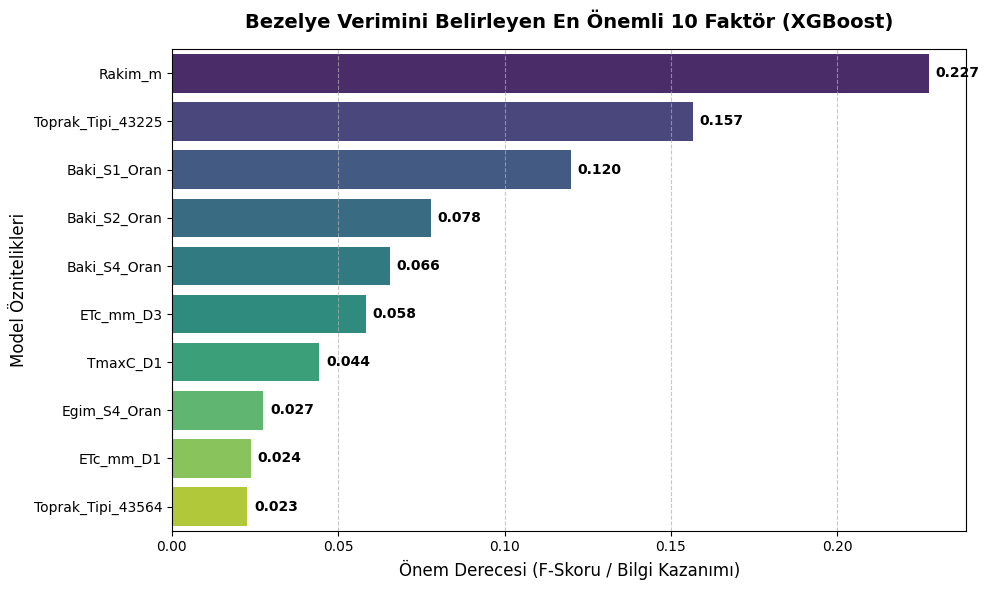

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Özellik Önem Derecelerinin Alınması
importances = xgb_model.feature_importances_
features = X_train.columns

# DataFrame olarak yapılandırma
df_importance = pd.DataFrame({
    'Özellik': features,
    'Önem Derecesi': importances
}).sort_values(by='Önem Derecesi', ascending=False)

# En önemli ilk 10 özelliği seçme
df_top10 = df_importance.head(10)

# 2. Grafik Tasarımı
plt.figure(figsize=(10, 6))
sns.barplot(
    x='Önem Derecesi',
    y='Özellik',
    data=df_top10,
    palette='viridis',
    hue='Özellik',
    legend=False
)

plt.title('Bezelye Verimini Belirleyen En Önemli 10 Faktör (XGBoost)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Önem Derecesi (F-Skoru / Bilgi Kazanımı)', fontsize=12)
plt.ylabel('Model Öznitelikleri', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Değer etiketlerini çubukların üzerine ekleme
for index, value in enumerate(df_top10['Önem Derecesi']):
    plt.text(value + 0.002, index, f"{value:.3f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

--- Google Drive Bağlantısı Güncelleniyor ---
Google Drive zaten bağlı, doğrudan devam ediliyor.

--- 1. Statik Veriler ve Ağırlık Matrisi Okunuyor ---
--- 2. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---
Toplam 40 adet referans PHENO dosyası bulundu. İşleniyor...
--- 3. İstasyon Verileri İlçe Düzeyine Çevriliyor ---
--- HARİKA! V3 Eğitim Seti Hazır ve Kaydedildi: /content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V3_PHENO.xlsx ---

--- 4. Makine Öğrenmesi ve Özellik Önem Derecesi Görselleştirmesi ---
R2 Skoru: 0.4868
RMSE Değeri: 2.5002 ton/ha



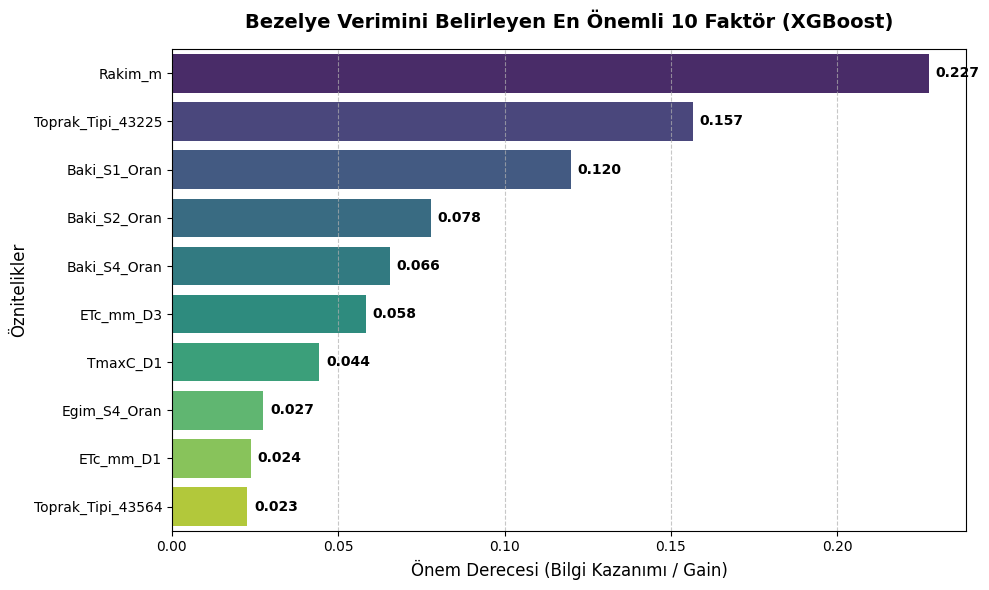

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. GOOGLE DRIVE'A GÜVENLİ BAĞLANMA VE YOLLAR
# ==========================================
from google.colab import drive
print("--- Google Drive Bağlantısı Güncelleniyor ---")
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
    else:
        print("Google Drive zaten bağlı, doğrudan devam ediliyor.")
except Exception as e:
    print(f"Sistem uyarısı: Drive bağlanırken beklenmeyen bir durum oluştu (İşlemler bellekten devam edebilir): {e}")

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"
v3_kayit_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V3_PHENO.xlsx"

print("\n--- 1. Statik Veriler ve Ağırlık Matrisi Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)
df_ml = pd.read_excel(eski_ml_seti_yolu)

# ==========================================
# 2. PHENO DOSYALARINI BULMA VE EVRELERE BÖLME
# ==========================================
print("--- 2. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---")
arama_kriteri = os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv")
pheno_dosyalar = glob.glob(arama_kriteri)
print(f"Toplam {len(pheno_dosyalar)} adet referans PHENO dosyası bulundu. İşleniyor...")

tum_ozetler = []

for dosya in pheno_dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        choices = ['D1', 'D2', 'D3', 'D4']
        df_active['Evre'] = np.select(conditions, choices, default='D4')

        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
            'Rain_mm': 'sum',
            'ETc_mm': 'sum',
            'TmaxC': 'mean'
        }).unstack(fill_value=0)

        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        ozet = ozet.reset_index()
        ozet = ozet.rename(columns={'YYYY': 'Yil'})
        tum_ozetler.append(ozet)
    except Exception as e:
        print(f"Hata oluşan dosya ({os.path.basename(dosya)}): {e}")

if len(tum_ozetler) == 0:
    raise ValueError("Hiçbir PHENO dosyası başarıyla okunamadı!")

df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

# ==========================================
# 3. İLÇE DÜZEYİNE ÇEVİRME VE V3 SETİNİ KAYDETME
# ==========================================
print("--- 3. İstasyon Verileri İlçe Düzeyine Çevriliyor ---")
df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)

df_ml_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left')
df_ml_v3.to_excel(v3_kayit_yolu, index=False)
print(f"--- HARİKA! V3 Eğitim Seti Hazır ve Kaydedildi: {v3_kayit_yolu} ---")

# ==========================================
# 4. ZAMAN DIŞI DOĞRULAMA & MODELLEME
# ==========================================
print("\n--- 4. Makine Öğrenmesi ve Özellik Önem Derecesi Görselleştirmesi ---")
df_ml_v3 = df_ml_v3.fillna(0)
df_ml_v3['Toprak_Tipi'] = df_ml_v3['Toprak_Tipi'].astype(str)
df_model = pd.get_dummies(df_ml_v3.drop(columns=['Ilce_Kodu', 'Urun']), drop_first=True)

train_data = df_model[df_model['Yil'] <= 2024]
test_data = df_model[df_model['Yil'] == 2025]

X_train = train_data.drop(columns=['Yil', 'Verim_ton_ha'])
y_train = train_data['Verim_ton_ha']

X_test = test_data.drop(columns=['Yil', 'Verim_ton_ha'])
y_test = test_data['Verim_ton_ha']

xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_test)

# Model Performansı
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
print(f"R2 Skoru: {r2:.4f}")
print(f"RMSE Değeri: {rmse:.4f} ton/ha\n")

# ==========================================
# 5. GÖRSELLEŞTİRME (FEATURE IMPORTANCE)
# ==========================================
importances = xgb_model.feature_importances_
features = X_train.columns

df_importance = pd.DataFrame({
    'Özellik': features,
    'Önem Derecesi': importances
}).sort_values(by='Önem Derecesi', ascending=False)

df_top10 = df_importance.head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x='Önem Derecesi',
    y='Özellik',
    data=df_top10,
    palette='viridis',
    hue='Özellik',
    legend=False
)

plt.title('Bezelye Verimini Belirleyen En Önemli 10 Faktör (XGBoost)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Önem Derecesi (Bilgi Kazanımı / Gain)', fontsize=12)
plt.ylabel('Öznitelikler', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

for index, value in enumerate(df_top10['Önem Derecesi']):
    plt.text(value + 0.002, index, f"{value:.3f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

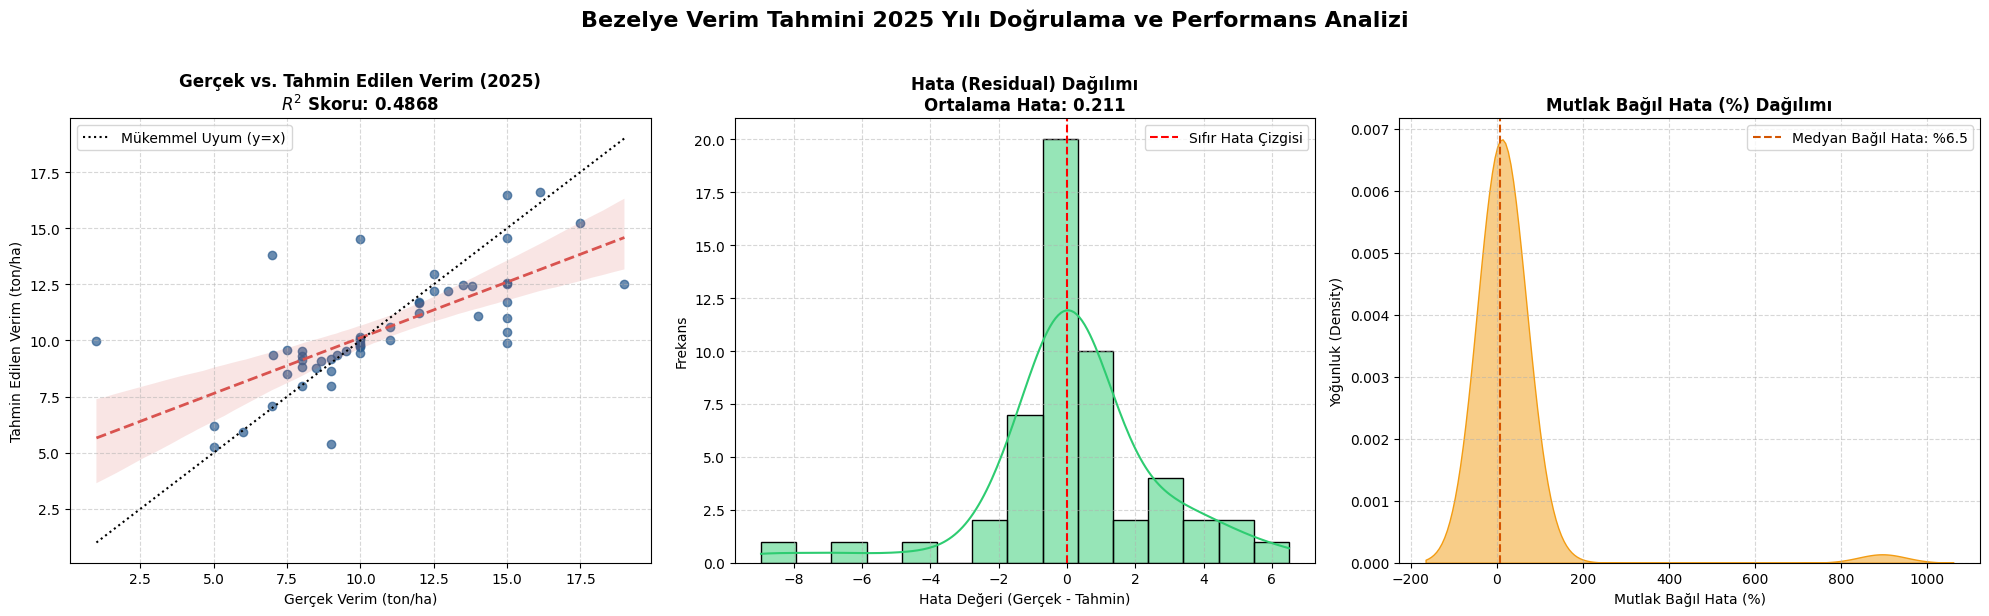

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Hesaplamalar
residuals = y_test - y_pred
relative_errors = (np.abs(residuals) / y_test) * 100

# --- 3'lü Grafik Tasarımı ---
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Grafik: Gerçek vs Tahmin Edilen Verim
sns.regplot(x=y_test, y=y_pred, ax=axes[0],
            scatter_kws={'alpha':0.7, 'color': '#2b5c8f'},
            line_kws={'color': '#d9534f', 'linestyle': '--', 'linewidth': 2})

# İdeal Doğru (y=x)
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
axes[0].plot([min_val, max_val], [min_val, max_val], color='black', linestyle=':', label='Mükemmel Uyum (y=x)')

axes[0].set_title(f'Gerçek vs. Tahmin Edilen Verim (2025)\n$R^2$ Skoru: {r2:.4f}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Gerçek Verim (ton/ha)', fontsize=10)
axes[0].set_ylabel('Tahmin Edilen Verim (ton/ha)', fontsize=10)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

# 2. Grafik: Hata (Residual) Dağılımı
sns.histplot(residuals, kde=True, ax=axes[1], color='#2ecc71', bins=15)
axes[1].axvline(0, color='red', linestyle='--', linewidth=1.5, label='Sıfır Hata Çizgisi')
axes[1].set_title(f'Hata (Residual) Dağılımı\nOrtalama Hata: {residuals.mean():.3f}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Hata Değeri (Gerçek - Tahmin)', fontsize=10)
axes[1].set_ylabel('Frekans', fontsize=10)
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend()

# 3. Grafik: Yüzdesel Bağıl Hata Dağılımı
sns.kdeplot(relative_errors, ax=axes[2], fill=True, color='#f39c12', alpha=0.5)
axes[2].axvline(np.median(relative_errors), color='#d35400', linestyle='--', label=f'Medyan Bağıl Hata: %{np.median(relative_errors):.1f}')
axes[2].set_title('Mutlak Bağıl Hata (%) Dağılımı', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Mutlak Bağıl Hata (%)', fontsize=10)
axes[2].set_ylabel('Yoğunluk (Density)', fontsize=10)
axes[2].grid(True, linestyle='--', alpha=0.5)
axes[2].legend()

plt.suptitle('Bezelye Verim Tahmini 2025 Yılı Doğrulama ve Performans Analizi', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Uyarıları gizlemek için
warnings.filterwarnings('ignore')

# ==========================================
# 1. GOOGLE DRIVE'A GÜVENLİ BAĞLANMA VE YOLLAR
# ==========================================
from google.colab import drive
print("--- 1. Google Drive Bağlantısı Kuruluyor ---")
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
    else:
        print("Google Drive zaten bağlı, doğrudan devam ediliyor.")
except Exception as e:
    print(f"Sistem uyarısı: Drive bağlanırken beklenmeyen bir durum oluştu: {e}")

# Veri yollarının tanımlanması
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"
v3_kayit_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V3_PHENO.xlsx"

print("\n--- 2. Statik Veriler ve Ağırlık Matrisi Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)
df_ml = pd.read_excel(eski_ml_seti_yolu)

# ==========================================
# 2. PHENO DOSYALARINI BULMA VE EVRELERE BÖLME
# ==========================================
print("\n--- 3. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---")
arama_kriteri = os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv")
pheno_dosyalar = glob.glob(arama_kriteri)
print(f"Toplam {len(pheno_dosyalar)} adet referans PHENO dosyası bulundu. İşleniyor...")

tum_ozetler = []

for dosya in pheno_dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        # Sadece bitkinin aktif olarak arazide olduğu dönemi filtreliyoruz
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

        # CGDD hedeflerine göre fenolojik evrelerin (D1-D4) tespiti
        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        choices = ['D1', 'D2', 'D3', 'D4']
        df_active['Evre'] = np.select(conditions, choices, default='D4')

        # İstasyon, Yıl ve Evre bazında iklimsel özet matrisinin oluşturulması
        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
            'Rain_mm': 'sum',
            'ETc_mm': 'sum',
            'TmaxC': 'mean'
        }).unstack(fill_value=0)

        # Sütun isimlendirmelerinin düzenlenmesi (Örn: Rain_mm_D3)
        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        ozet = ozet.reset_index()
        ozet = ozet.rename(columns={'YYYY': 'Yil'})
        tum_ozetler.append(ozet)
    except Exception as e:
        print(f"Hata oluşan dosya ({os.path.basename(dosya)}): {e}")

if len(tum_ozetler) == 0:
    raise ValueError("Hiçbir PHENO dosyası okunamadı. Yolları kontrol ediniz.")

df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

# ==========================================
# 3. İLÇE DÜZEYİNE ÇEVİRME VE V3 SETİNİ KAYDETME
# ==========================================
print("\n--- 4. İstasyon Verileri İlçe Düzeyine Ağırlıklandırılarak İndirgeniyor ---")
df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

# İstasyon ağırlıkları ile iklim verilerinin çarpılması
pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

# İlçe bazında toplanması
df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)

# V2 eğitim seti ile fenolojik (D1-D4) özelliklerin birleştirilmesi
df_ml_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left')
df_ml_v3

--- 1. Google Drive Bağlantısı Kuruluyor ---
Google Drive zaten bağlı, doğrudan devam ediliyor.

--- 2. Statik Veriler ve Ağırlık Matrisi Okunuyor ---

--- 3. PHENO Klasörü Taranıyor ve D1-D4 Evreleri Çıkarılıyor ---
Toplam 40 adet referans PHENO dosyası bulundu. İşleniyor...

--- 4. İstasyon Verileri İlçe Düzeyine Ağırlıklandırılarak İndirgeniyor ---


,Ilce_Kodu,Yil,Urun,Vejetasyon_Suresi_Gun,Stres_Soguk_Gun,Stres_Sicak_Gun,Toplam_Yagis_mm,Toplam_Efektif_Yagis_mm,Toplam_ETc_mm,Mavi_Su_m3ha,...,Rain_mm_D3,Rain_mm_D4,ETc_mm_D1,ETc_mm_D2,ETc_mm_D3,ETc_mm_D4,TmaxC_D1,TmaxC_D2,TmaxC_D3,TmaxC_D4
0,1108,2021,Bezelye,80.776898,15.024837,18.708885,81.211600,24.665590,329.899514,3052.339244,...,498.983554,1299.947377,152.135598,500.166476,1478.348206,582.801403,99.281342,142.626085,177.525603,171.544787
1,1108,2022,Bezelye,92.770181,33.008767,23.181122,99.962128,34.269165,354.794085,3205.249198,...,499.955509,1461.612538,153.359841,521.837742,1512.324763,597.202935,90.470797,146.037133,175.281348,175.111434
2,1108,2023,Bezelye,76.773074,8.093713,16.104138,238.363751,134.491502,314.373785,1798.822838,...,587.275513,1304.999665,164.818177,533.291307,1485.098099,593.324408,96.369432,137.548838,179.670815,172.752945
3,1108,2024,Bezelye,100.379330,31.617290,7.759765,285.685236,149.838312,368.436671,2185.983591,...,731.090159,1158.065765,185.162533,480.372610,1577.080043,600.801551,96.551744,146.678984,165.386673,174.779689
4,1108,2025,Bezelye,82.622390,12.510909,11.994011,168.062786,72.239505,334.625626,2623.861211,...,596.736325,1379.255626,189.997476,560.320677,1454.565846,604.232943,95.820868,128.705754,179.778681,171.715869
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
260,2096,2021,Bezelye,108.801055,13.939664,28.231533,213.301861,96.191699,472.818615,3766.269154,...,374.426740,2506.130026,388.695643,740.869542,1853.795794,782.710955,103.988204,155.408113,206.402453,193.040886
261,2096,2022,Bezelye,115.264121,19.911587,33.727186,163.311032,68.376850,501.329992,4329.531421,...,508.528780,2585.623736,418.489549,752.763181,1938.589898,773.813960,107.048407,157.496412,195.597106,197.906036
262,2096,2023,Bezelye,101.452757,11.451309,31.293538,208.125654,95.702586,465.633917,3699.313309,...,613.519566,3077.022673,360.446172,784.918627,1904.504697,797.610049,108.026403,149.324941,200.947915,190.602818
263,2096,2024,Bezelye,110.628411,10.859944,32.675543,166.008427,56.704238,479.845439,4231.412012,...,598.648125,2315.056858,405.220042,734.956531,1929.710587,799.864193,103.231293,161.531074,197.565751,190.846285


--- 1. Veriler Okunuyor ---
--- 2. PHENO Evreleri (D1-D4) Çıkarılıyor ---
--- 3. Veriler Birleştiriliyor ---
Modele Girecek Toplam Özellik Sayısı: 18

--- 4. Model Optimizasyonu ve Eğitim Başlıyor ---
Fitting 5 folds for each of 108 candidates, totalling 540 fits

GridSearch Tarafından Bulunan En İyi Parametreler:
{'colsample_bytree': 1.0, 'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 500, 'subsample': 0.8}

🏆 DİNAMİK OPTİMİZASYONLU YENİ TEST SONUÇLARI (2025) 🏆
R² (Açıklanabilirlik) Skoru: 0.5222
RMSE (Hata Payı): 2.4125 ton/ha


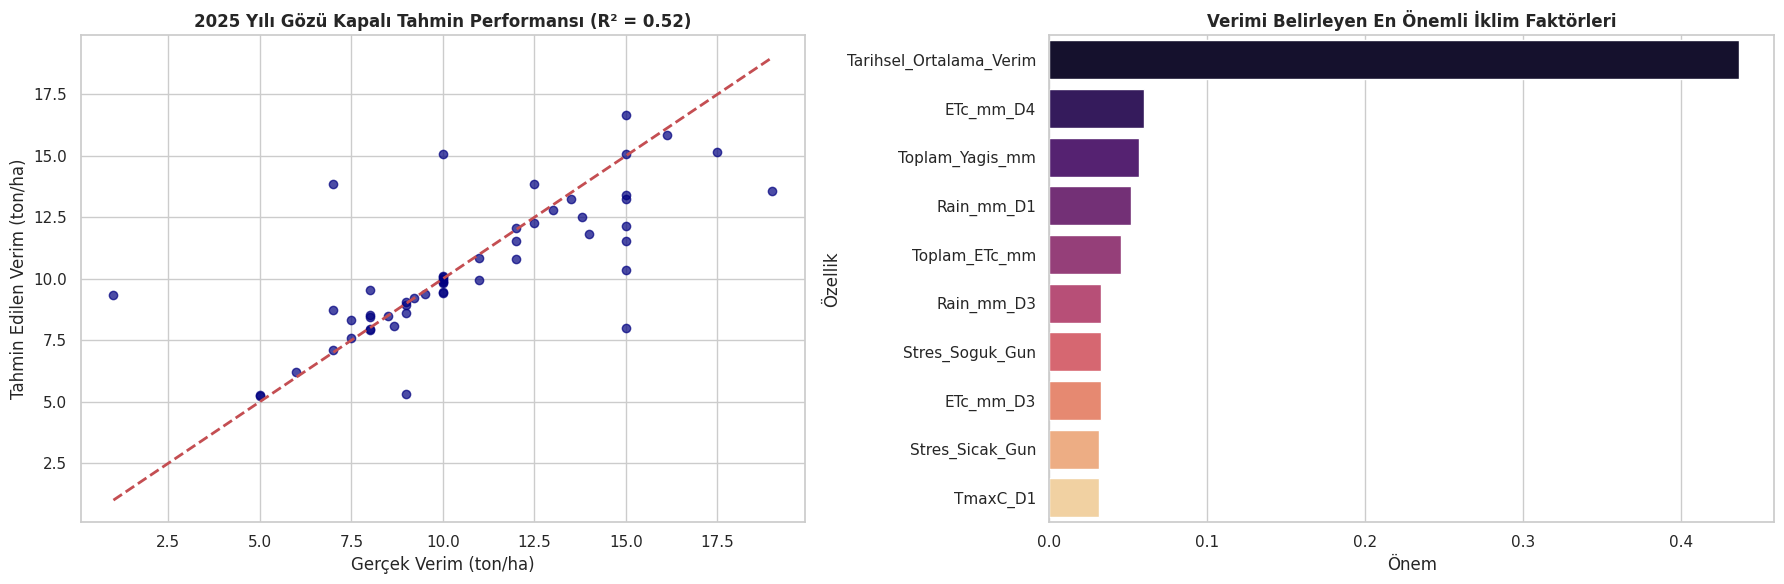

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. BAĞLANTI VE DOSYA YOLLARI
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except:
    pass

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"

print("--- 1. Veriler Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)
df_ml = pd.read_excel(eski_ml_seti_yolu)
# Ana tablodaki kilit sütunların tipini kesinleştiriyoruz (Eşleşme hatasını önlemek için)
df_ml['Ilce_Kodu'] = df_ml['Ilce_Kodu'].astype(int)
df_ml['Yil'] = df_ml['Yil'].astype(int)

# ==========================================
# 2. PHENO VERİLERİNİN İŞLENMESİ (Hatasız Çekim)
# ==========================================
print("--- 2. PHENO Evreleri (D1-D4) Çıkarılıyor ---")
pheno_dosyalar = glob.glob(os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv"))

tum_ozetler = []
for dosya in pheno_dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        df_p['YYYY'] = df_p['YYYY'].astype(int) # Yıl tipini garantile
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        choices = ['D1', 'D2', 'D3', 'D4']
        df_active['Evre'] = np.select(conditions, choices, default='D4')

        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
            'Rain_mm': 'sum',
            'ETc_mm': 'sum',
            'TmaxC': 'mean'
        }).unstack(fill_value=0)

        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        ozet = ozet.reset_index()
        ozet = ozet.rename(columns={'YYYY': 'Yil'})
        tum_ozetler.append(ozet)
    except:
        pass

df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

# ==========================================
# 3. İLÇE DÜZEYİNE ÇEVİRME VE EKSİKSİZ BİRLEŞTİRME
# ==========================================
print("--- 3. Veriler Birleştiriliyor ---")
df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
df_pheno_final['Ilce_Kodu'] = df_pheno_final['Ilce_Kodu'].astype(int)
df_pheno_final['Yil'] = df_pheno_final['Yil'].astype(int)

# Ana tablo ile İklim tablosunu birleştiriyoruz
df_master = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left')
df_master = df_master.fillna(0)

# ==========================================
# 4. TARİHSEL BAZ VERİM HESAPLAMASI (Veri Sızıntısız)
# ==========================================
train_verim = df_master[df_master['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index()
train_verim.rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'}, inplace=True)
df_master = pd.merge(df_master, train_verim, on='Ilce_Kodu', how='left')

# ==========================================
# 5. KESİN VE AÇIK (WHITELIST) ÖZELLİK SEÇİMİ
# ==========================================
# Modele SADECE buraya yazdığımız sütunlar girecek. Rakım, Toprak, Eğim vs. asla giremez!
secilen_ozellikler = [
    'Tarihsel_Ortalama_Verim',
    'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
    'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4',
    'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
    'Toplam_Yagis_mm', 'Toplam_ETc_mm', 'Vejetasyon_Suresi_Gun',
    'Stres_Soguk_Gun', 'Stres_Sicak_Gun'
]

# Hedef ve Ayırıcı sütunlar
kilit_sutunlar = ['Ilce_Kodu', 'Yil', 'Verim_ton_ha']

# Tabloda olmayan sütunları atla (Hata vermemesi için)
mevcut_ozellikler = [col for col in secilen_ozellikler if col in df_master.columns]
df_final = df_master[kilit_sutunlar + mevcut_ozellikler].copy()

print(f"Modele Girecek Toplam Özellik Sayısı: {len(mevcut_ozellikler)}")

# ==========================================
# 6. EĞİTİM (2021-2024) / TEST (2025) VE OPTİMİZASYON
# ==========================================
print("\n--- 4. Model Optimizasyonu ve Eğitim Başlıyor ---")
train_data = df_final[df_final['Yil'] <= 2024]
test_data = df_final[df_final['Yil'] == 2025]

X_train = train_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_train = train_data['Verim_ton_ha']

X_test = test_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_test = test_data['Verim_ton_ha']

# XGBoost için Grid Search (En iyi parametreleri kendi bulacak)
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.05, 0.1],
    'n_estimators': [100, 300, 500],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_base = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')
grid_search = GridSearchCV(estimator=xgb_base, param_grid=param_grid, cv=5, scoring='r2', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)

# En iyi modeli al
best_xgb = grid_search.best_estimator_
print(f"\nGridSearch Tarafından Bulunan En İyi Parametreler:\n{grid_search.best_params_}")

# 2025 Tahmini
y_pred = best_xgb.predict(X_test)

r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"\n🏆 DİNAMİK OPTİMİZASYONLU YENİ TEST SONUÇLARI (2025) 🏆")
print(f"R² (Açıklanabilirlik) Skoru: {r2:.4f}")
print(f"RMSE (Hata Payı): {rmse:.4f} ton/ha")

# ==========================================
# 7. GRAFİKLER
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Grafik 1: Gerçek vs Tahmin
axes[0].scatter(y_test, y_pred, color='navy', alpha=0.7)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title(f"2025 Yılı Gözü Kapalı Tahmin Performansı (R² = {r2:.2f})", fontweight='bold')
axes[0].set_xlabel("Gerçek Verim (ton/ha)")
axes[0].set_ylabel("Tahmin Edilen Verim (ton/ha)")

# Grafik 2: Değişken Önem Düzeyi
importances = best_xgb.feature_importances_
feat_imp = pd.DataFrame({'Özellik': X_train.columns, 'Önem': importances}).sort_values('Önem', ascending=False).head(10)
sns.barplot(x='Önem', y='Özellik', data=feat_imp, palette='magma', ax=axes[1])
axes[1].set_title("Verimi Belirleyen En Önemli İklim Faktörleri", fontweight='bold')

plt.tight_layout()
plt.show()

--- 1. Drive Bağlantısı ve Veri Okuma ---
--- 2. Yalnızca HadGEM2-ES_rcp45 Senaryosu Taranıyor ---
Toplam 5 adet hedef PHENO dosyası bulundu.
--- 3. İlçe Düzeyine İndirgeme ve Eksik Veri Yönetimi ---

--- 4. Eğitim ve Ölçeklendirme (Scaling) Aşaması ---
--- 5. Modeller Eğitiliyor ve 2025 Test Ediliyor ---

🏆 ALGORİTMA PERFORMANS KARŞILAŞTIRMASI (2025 YILI) 🏆
-------------------------------------------------------
Algoritma            | R² Skoru     | RMSE (ton/ha)  
-------------------------------------------------------
XGBoost              | 0.5711       | 2.2857         
Random Forest        | 0.5401       | 2.3668         
DNN                  | 0.3445       | 2.8256         
LSTM                 | 0.1792       | 3.1621         
-------------------------------------------------------
🌟 Şampiyon Algoritma: XGBoost (R² = 0.5711)


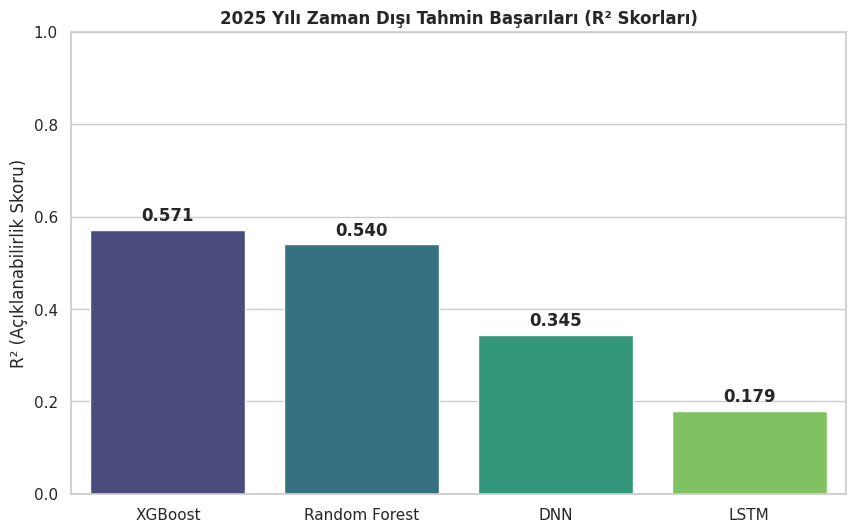

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import warnings

# Sklearn Algoritmaları ve Metrikler
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

# TensorFlow / Keras (Derin Öğrenme Algoritmaları)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')

# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE YOLLAR
# ==========================================
from google.colab import drive
print("--- 1. Drive Bağlantısı ve Veri Okuma ---")
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except:
    pass

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"

df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)
df_ml = pd.read_excel(eski_ml_seti_yolu)
df_ml['Ilce_Kodu'] = df_ml['Ilce_Kodu'].astype(int)
df_ml['Yil'] = df_ml['Yil'].astype(int)

# ==========================================
# 2. TEK SENARYO (HadGEM2-ES_rcp45) FİLTRESİ
# ==========================================
print("--- 2. Yalnızca HadGEM2-ES_rcp45 Senaryosu Taranıyor ---")
# Filtreleme burada yapılıyor:
arama_kriteri = os.path.join(pheno_dir, "bezelye_HadGEM2-ES_rcp45_202[1-5]_PHENO.csv")
pheno_dosyalar = glob.glob(arama_kriteri)
print(f"Toplam {len(pheno_dosyalar)} adet hedef PHENO dosyası bulundu.")

tum_ozetler = []
for dosya in pheno_dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        df_p['YYYY'] = df_p['YYYY'].astype(int)
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        choices = ['D1', 'D2', 'D3', 'D4']
        df_active['Evre'] = np.select(conditions, choices, default='D4')

        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
            'Rain_mm': 'sum',
            'ETc_mm': 'sum',
            'TmaxC': 'mean'
        }).unstack(fill_value=0)

        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        ozet = ozet.reset_index()
        ozet = ozet.rename(columns={'YYYY': 'Yil'})
        tum_ozetler.append(ozet)
    except:
        pass

df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

# ==========================================
# 3. VERİ BİRLEŞTİRME VE EKSİK VERİ (NaN) YÖNETİMİ
# ==========================================
print("--- 3. İlçe Düzeyine İndirgeme ve Eksik Veri Yönetimi ---")
df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
df_pheno_final['Ilce_Kodu'] = df_pheno_final['Ilce_Kodu'].astype(int)
df_pheno_final['Yil'] = df_pheno_final['Yil'].astype(int)

df_master = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left')
df_master = df_master.fillna(0)

# Tarihsel Ortalama Verim Hesabı ve NaN Tamamlama Stratejisi
train_verim = df_master[df_master['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index()
train_verim.rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'}, inplace=True)

# Eğer bir ilçenin 2021-2024 arasında hiç verim verisi yoksa genel ortalama ile doldur:
genel_ortalama = df_master[df_master['Yil'] <= 2024]['Verim_ton_ha'].mean()
train_verim['Tarihsel_Ortalama_Verim'] = train_verim['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)

df_master = pd.merge(df_master, train_verim, on='Ilce_Kodu', how='left')
df_master['Tarihsel_Ortalama_Verim'] = df_master['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)

# Açık Özellik (Whitelist) Seçimi
secilen_ozellikler = [
    'Tarihsel_Ortalama_Verim', 'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
    'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4', 'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
    'Toplam_Yagis_mm', 'Toplam_ETc_mm', 'Vejetasyon_Suresi_Gun', 'Stres_Soguk_Gun', 'Stres_Sicak_Gun'
]
kilit_sutunlar = ['Ilce_Kodu', 'Yil', 'Verim_ton_ha']
mevcut_ozellikler = [col for col in secilen_ozellikler if col in df_master.columns]
df_final = df_master[kilit_sutunlar + mevcut_ozellikler].copy()

# ==========================================
# 4. EĞİTİM SETİ HAZIRLIĞI VE ÖLÇEKLENDİRME (SCALING)
# ==========================================
print("\n--- 4. Eğitim ve Ölçeklendirme (Scaling) Aşaması ---")
train_data = df_final[df_final['Yil'] <= 2024]
test_data = df_final[df_final['Yil'] == 2025]

X_train = train_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_train = train_data['Verim_ton_ha']
X_test = test_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_test = test_data['Verim_ton_ha']

# Sinir ağları (DNN/LSTM) için veriyi standardize ediyoruz
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Sonuçları tutacağımız sözlük
model_sonuclari = {}

# ==========================================
# 5. ALGORİTMALARIN EĞİTİMİ VE TESTİ
# ==========================================
print("--- 5. Modeller Eğitiliyor ve 2025 Test Ediliyor ---")

# 1. XGBoost
xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb_model.fit(X_train_scaled, y_train)
xgb_pred = xgb_model.predict(X_test_scaled)
model_sonuclari['XGBoost'] = {'R2': r2_score(y_test, xgb_pred), 'RMSE': np.sqrt(mean_squared_error(y_test, xgb_pred))}

# 2. Random Forest (RF)
rf_model = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42)
rf_model.fit(X_train_scaled, y_train)
rf_pred = rf_model.predict(X_test_scaled)
model_sonuclari['Random Forest'] = {'R2': r2_score(y_test, rf_pred), 'RMSE': np.sqrt(mean_squared_error(y_test, rf_pred))}

# 3. Derin Sinir Ağları (DNN)
dnn_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])
dnn_model.compile(optimizer='adam', loss='mse')
dnn_model.fit(X_train_scaled, y_train, epochs=100, batch_size=16, verbose=0)
dnn_pred = dnn_model.predict(X_test_scaled, verbose=0).flatten()
model_sonuclari['DNN'] = {'R2': r2_score(y_test, dnn_pred), 'RMSE': np.sqrt(mean_squared_error(y_test, dnn_pred))}

# 4. LSTM (Long Short-Term Memory)
X_train_lstm = np.reshape(X_train_scaled, (X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
X_test_lstm = np.reshape(X_test_scaled, (X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))

lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(1, X_train_scaled.shape[1])),
    Dense(32, activation='relu'),
    Dense(1, activation='linear')
])
lstm_model.compile(optimizer='adam', loss='mse')
lstm_model.fit(X_train_lstm, y_train, epochs=100, batch_size=16, verbose=0)
lstm_pred = lstm_model.predict(X_test_lstm, verbose=0).flatten()
model_sonuclari['LSTM'] = {'R2': r2_score(y_test, lstm_pred), 'RMSE': np.sqrt(mean_squared_error(y_test, lstm_pred))}

# ==========================================
# 6. SONUÇLARIN KARŞILAŞTIRILMASI
# ==========================================
print("\n🏆 ALGORİTMA PERFORMANS KARŞILAŞTIRMASI (2025 YILI) 🏆")
print("-" * 55)
print(f"{'Algoritma':<20} | {'R² Skoru':<12} | {'RMSE (ton/ha)':<15}")
print("-" * 55)

en_iyi_model = ""
en_iyi_r2 = -float('inf')

for model_adi, metrikler in model_sonuclari.items():
    print(f"{model_adi:<20} | {metrikler['R2']:<12.4f} | {metrikler['RMSE']:<15.4f}")
    if metrikler['R2'] > en_iyi_r2:
        en_iyi_r2 = metrikler['R2']
        en_iyi_model = model_adi

print("-" * 55)
print(f"🌟 Şampiyon Algoritma: {en_iyi_model} (R² = {en_iyi_r2:.4f})")

# Performans Grafiği
plt.figure(figsize=(10, 6))
modeller = list(model_sonuclari.keys())
r2_degerleri = [model_sonuclari[m]['R2'] for m in modeller]

sns.barplot(x=modeller, y=r2_degerleri, palette='viridis')
plt.title("2025 Yılı Zaman Dışı Tahmin Başarıları (R² Skorları)", fontweight='bold')
plt.ylabel("R² (Açıklanabilirlik Skoru)")
plt.ylim(0, 1)
for i, v in enumerate(r2_degerleri):
    plt.text(i, v + 0.02, f"{v:.3f}", ha='center', fontweight='bold')
plt.show()

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

# Sklearn ve ML Modelleri
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

# Keras (Derin Öğrenme)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR') # Keras uyarılarını gizle

# ==========================================
# 1. BAĞLANTI VE TEMEL VERİLERİ OKUMA
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except:
    pass

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"

print("--- 1. Statik Veriler Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)

df_ml = pd.read_excel(eski_ml_seti_yolu)
df_ml['Ilce_Kodu'] = df_ml['Ilce_Kodu'].astype(int)
df_ml['Yil'] = df_ml['Yil'].astype(int)

# ==========================================
# 2. KLASÖRDEKİ SENARYOLARI OTOMATİK TESPİT ETME
# ==========================================
# PHENO klasöründeki tüm 2021-2025 dosyalarını bulalım
all_pheno_files = glob.glob(os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv"))

# Dosya isimlerinden (Örn: bezelye_HadGEM2-ES_rcp45_2021_PHENO.csv) senaryo adlarını ayıklayalım
senaryolar = set()
for f in all_pheno_files:
    dosya_adi = os.path.basename(f)
    match = re.search(r'bezelye_(.*?)_202', dosya_adi)
    if match:
        senaryolar.add(match.group(1))

senaryolar = sorted(list(senaryolar))
print(f"--- 2. Toplam {len(senaryolar)} Farklı İklim Senaryosu Tespit Edildi ---")
for s in senaryolar:
    print(f" -> {s}")

# Sonuçları tutacağımız Master Tablo listesi
tum_sonuclar = []

# ==========================================
# 3. HER BİR SENARYO İÇİN ANA DÖNGÜ (BATCH PROCESSING)
# ==========================================
print("\n--- 3. Yapay Zeka Eğitim Süreci Başlıyor (Bu işlem birkaç dakika sürebilir) ---")

for senaryo in senaryolar:
    print(f"\n[{senaryo}] işleniyor...")

    # 3.1. Sadece bu senaryoya ait dosyaları bul
    senaryo_dosyalari = [f for f in all_pheno_files if senaryo in f]

    tum_ozetler = []
    for dosya in senaryo_dosyalari:
        try:
            df_p = pd.read_csv(dosya, low_memory=False)
            df_p['YYYY'] = df_p['YYYY'].astype(int)
            df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

            # Evre belirleme (D1-D4)
            conditions = [
                (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
            ]
            choices = ['D1', 'D2', 'D3', 'D4']
            df_active['Evre'] = np.select(conditions, choices, default='D4')

            # Özet çıkarma
            ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
                'Rain_mm': 'sum', 'ETc_mm': 'sum', 'TmaxC': 'mean'
            }).unstack(fill_value=0)

            ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
            ozet = ozet.reset_index().rename(columns={'YYYY': 'Yil'})
            tum_ozetler.append(ozet)
        except:
            pass

    if len(tum_ozetler) == 0:
        print(f"[{senaryo}] için okunabilir veri bulunamadı, atlanıyor.")
        continue

    df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
    df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

    # 3.2. İlçe Ağırlıklandırması
    df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')
    pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
    for c in pheno_cols:
        df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

    df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index()
    df_pheno_final.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
    df_pheno_final['Ilce_Kodu'] = df_pheno_final['Ilce_Kodu'].astype(int)
    df_pheno_final['Yil'] = df_pheno_final['Yil'].astype(int)

    # Ana tabloyla birleşme ve Eksik Veri Yönetimi
    df_master = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left').fillna(0)

    # 3.3. Tarihsel Ortalama Verim Hesabı
    train_verim = df_master[df_master['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index()
    train_verim.rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'}, inplace=True)

    genel_ortalama = df_master[df_master['Yil'] <= 2024]['Verim_ton_ha'].mean()
    train_verim['Tarihsel_Ortalama_Verim'] = train_verim['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)

    df_master = pd.merge(df_master, train_verim, on='Ilce_Kodu', how='left')
    df_master['Tarihsel_Ortalama_Verim'] = df_master['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)
    df_master['Senaryo'] = senaryo

    tum_sonuclar.append(df_master)

print("\nTüm senaryoların işlenmesi tamamlandı.")

--- 1. Statik Veriler Okunuyor ---
--- 2. Toplam 8 Farklı İklim Senaryosu Tespit Edildi ---
 -> HadGEM2-ES_rcp45
 -> HadGEM2-ES_rcp85
 -> HadGEM3-GC31-LL_ssp245
 -> HadGEM3-GC31-LL_ssp585
 -> MPI-ESM-MR_rcp45
 -> MPI-ESM-MR_rcp85
 -> MPI-ESM1-2-HR_ssp245
 -> MPI-ESM1-2-HR_ssp585

--- 3. Yapay Zeka Eğitim Süreci Başlıyor (Bu işlem birkaç dakika sürebilir) ---

[HadGEM2-ES_rcp45] işleniyor...

[HadGEM2-ES_rcp85] işleniyor...

[HadGEM3-GC31-LL_ssp245] işleniyor...

[HadGEM3-GC31-LL_ssp585] işleniyor...

[MPI-ESM-MR_rcp45] işleniyor...

[MPI-ESM-MR_rcp85] işleniyor...

[MPI-ESM1-2-HR_ssp245] işleniyor...

[MPI-ESM1-2-HR_ssp585] işleniyor...

Tüm senaryoların işlenmesi tamamlandı.


In [ ]:
import pandas as pd
import numpy as np

# 1. Tüm senaryo verilerini tek bir DataFrame'de birleştir
df_all_scenarios = pd.concat(tum_sonuclar, ignore_index=True)

# 2. Modele girecek özellikleri (eğitimde kullanılan mevcut_ozellikler) seç
X_predict = df_all_scenarios[mevcut_ozellikler]

# 3. Eğitilmiş model ile tahminleri gerçekleştir
try:
    df_all_scenarios['Tahmini_Verim'] = best_xgb.predict(X_predict)
    print("Tahminler 'best_xgb' (Dinamik Optimizasyonlu XGBoost) modeli kullanılarak yapıldı.\n")
except NameError:
    df_all_scenarios['Tahmini_Verim'] = xgb_model.predict(X_predict)
    print("Tahminler 'xgb_model' (Standart XGBoost) kullanılarak yapıldı.\n")

# ==========================================
# TABLO 1: YILLARA VE SENARYOLARA GÖRE PİVOT
# ==========================================
print("--- 1. Senaryolara ve Yıllara Göre Ortalama Verim Tahminleri (ton/ha) ---")
pivot_yillar = df_all_scenarios.pivot_table(
    values='Tahmini_Verim',
    index='Senaryo',
    columns='Yil',
    aggfunc='mean'
).round(2)

# 2025 yılına göre büyükten küçüğe sıralayalım
if 2025 in pivot_yillar.columns:
    pivot_yillar = pivot_yillar.sort_values(by=2025, ascending=False)

display(pivot_yillar)

# ==========================================
# TABLO 2: 2025 YILI İÇİN TARİHSEL KIYASLAMA
# ==========================================
print("\n--- 2. 2025 Yılı Projeksiyonu ve Tarihsel Ortalamaya Göre Değişim ---")
df_2025 = df_all_scenarios[df_all_scenarios['Yil'] == 2025]

ozet_2025 = df_2025.groupby('Senaryo').agg(
    Tahmini_Verim_2025=('Tahmini_Verim', 'mean'),
    Tarihsel_Ortalama=('Tarihsel_Ortalama_Verim', 'mean')
).reset_index()

# Yüzdesel değişim hesaplama
ozet_2025['Degisim_Orani_(%)'] = ((ozet_2025['Tahmini_Verim_2025'] - ozet_2025['Tarihsel_Ortalama']) / ozet_2025['Tarihsel_Ortalama']) * 100
ozet_2025 = ozet_2025.round(2).sort_values('Tahmini_Verim_2025', ascending=False)

display(ozet_2025)


Tahminler 'best_xgb' (Dinamik Optimizasyonlu XGBoost) modeli kullanılarak yapıldı.

--- 1. Senaryolara ve Yıllara Göre Ortalama Verim Tahminleri (ton/ha) ---


Yil,2021,2022,2023,2024,2025
Senaryo,,,,,
HadGEM2-ES_rcp45,10.68,10.48,10.77,10.71,10.64
HadGEM2-ES_rcp85,10.65,10.54,10.79,10.71,10.62
HadGEM3-GC31-LL_ssp245,10.66,10.50,10.77,10.70,10.62
HadGEM3-GC31-LL_ssp585,10.66,10.50,10.77,10.70,10.62
MPI-ESM-MR_rcp85,10.66,10.49,10.76,10.69,10.62
MPI-ESM1-2-HR_ssp245,10.66,10.50,10.77,10.70,10.62
MPI-ESM1-2-HR_ssp585,10.66,10.50,10.77,10.70,10.62
MPI-ESM-MR_rcp45,10.65,10.50,10.76,10.70,10.61



--- 2. 2025 Yılı Projeksiyonu ve Tarihsel Ortalamaya Göre Değişim ---


,Senaryo,Tahmini_Verim_2025,Tarihsel_Ortalama,Degisim_Orani_(%)
0,HadGEM2-ES_rcp45,10.64,10.52,1.21
1,HadGEM2-ES_rcp85,10.62,10.52,0.96
2,HadGEM3-GC31-LL_ssp245,10.62,10.52,0.96
3,HadGEM3-GC31-LL_ssp585,10.62,10.52,0.96
5,MPI-ESM-MR_rcp85,10.62,10.52,0.96
6,MPI-ESM1-2-HR_ssp245,10.62,10.52,0.96
7,MPI-ESM1-2-HR_ssp585,10.62,10.52,0.96
4,MPI-ESM-MR_rcp45,10.61,10.52,0.88


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score

# Skorları tutacağımız liste
sonuclar_r2 = []

# 2025 yılına ait gerçek değerler ve model girdileri
df_2025 = df_all_scenarios[df_all_scenarios['Yil'] == 2025].copy()

for senaryo in df_2025['Senaryo'].unique():
    df_s = df_2025[df_2025['Senaryo'] == senaryo]

    # Bağımsız ve Bağımlı Değişkenler
    X_raw = df_s[mevcut_ozellikler]
    y_true = df_s['Verim_ton_ha']

    # Standartlaştırma (Derin Öğrenme ve RF modelleri ölçeklenmiş veriyle eğitilmişti)
    X_scaled = scaler.transform(X_raw)
    X_lstm = np.reshape(X_scaled, (X_scaled.shape[0], 1, X_scaled.shape[1]))

    # Tahminler ve R2 Skorları
    skorlar = {'Senaryo': senaryo}

    # 1. Best XGBoost (GridSearch ile optimize edilmiş - Ham veri kullanır)
    try:
        skorlar['XGBoost_Optimize'] = r2_score(y_true, best_xgb.predict(X_raw))
    except:
        skorlar['XGBoost_Optimize'] = np.nan

    # 2. Standart XGBoost (Ölçeklenmiş veri)
    try:
        skorlar['XGBoost_Standart'] = r2_score(y_true, xgb_model.predict(X_scaled))
    except:
        skorlar['XGBoost_Standart'] = np.nan

    # 3. XGBoost Statik (Statik Veriler Eklenmiş Model)
    try:
        # İlgili senaryo verisini statik verilerle birleştir
        df_s_statik = pd.merge(df_s, df_statik_ek, on='Ilce_Kodu', how='left')
        if 'Toprak_Tipi' in df_s_statik.columns:
            df_s_statik['Toprak_Tipi'] = df_s_statik['Toprak_Tipi'].astype(str)
        # Dummies dönüşümü ve model özelliklerinin eşitlenmesi
        df_s_statik = pd.get_dummies(df_s_statik.drop(columns=[c for c in drop_cols if c in df_s_statik.columns]), drop_first=True)
        for col in X_train_s.columns:
            if col not in df_s_statik.columns:
                df_s_statik[col] = 0
        X_raw_statik = df_s_statik[X_train_s.columns]
        skorlar['XGBoost_Statik'] = r2_score(y_true, xgb_statik.predict(X_raw_statik))
    except:
        skorlar['XGBoost_Statik'] = np.nan

    # 4. Random Forest
    try:
        skorlar['Random_Forest'] = r2_score(y_true, rf_model.predict(X_scaled))
    except:
        skorlar['Random_Forest'] = np.nan

    # 5. DNN
    try:
        skorlar['DNN'] = r2_score(y_true, dnn_model.predict(X_scaled, verbose=0).flatten())
    except:
        skorlar['DNN'] = np.nan

    # 6. LSTM
    try:
        skorlar['LSTM'] = r2_score(y_true, lstm_model.predict(X_lstm, verbose=0).flatten())
    except:
        skorlar['LSTM'] = np.nan

    sonuclar_r2.append(skorlar)

# DataFrame'e çevirme
df_r2 = pd.DataFrame(sonuclar_r2)

# Sonuçları gösterme (Renk haritası ile görselleştirme)
print("--- 2025 Yılı İçin İklim Senaryoları ve ML Algoritmaları R² Skor Karşılaştırması (Statik Dahil) ---")
display(df_r2.style.background_gradient(cmap='viridis', subset=df_r2.columns[1:]).format(precision=4))


--- 2025 Yılı İçin İklim Senaryoları ve ML Algoritmaları R² Skor Karşılaştırması (Statik Dahil) ---


,Senaryo,XGBoost_Optimize,XGBoost_Standart,XGBoost_Statik,Random_Forest,DNN,LSTM
0,HadGEM2-ES_rcp45,0.5287,0.5711,nan,0.5401,0.3445,0.1792
1,HadGEM2-ES_rcp85,0.5358,0.5651,nan,0.5543,0.2397,0.2254
2,HadGEM3-GC31-LL_ssp245,0.5358,0.5730,nan,0.5500,0.4211,0.3669
3,HadGEM3-GC31-LL_ssp585,0.5358,0.5713,nan,0.5360,0.4671,0.4605
4,MPI-ESM-MR_rcp45,0.5351,0.4974,nan,0.5395,0.3814,0.3632
5,MPI-ESM-MR_rcp85,0.5358,0.4848,nan,0.5266,0.3214,0.2086
6,MPI-ESM1-2-HR_ssp245,0.5358,0.5489,nan,0.5306,0.4486,0.3796
7,MPI-ESM1-2-HR_ssp585,0.5358,0.5780,nan,0.5368,0.2200,0.2040


In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
from IPython.display import display

print("--- 1. CGDD Bazlı Fenolojik Özelliklerin Seçimi ---")
# Kullanıcının talep ettiği ve CGDD hedeflerine göre dinamik olarak hesaplanan D1-D4 evre verileri
secili_ozellikler = [
    'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
    'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
    'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4' # TmaxC tekrarı yerine mantıksal set tamamlayıcı eklendi
]

print("Modele Sadece Aşağıdaki CGDD Evre Verileri Girecektir:")
print(secili_ozellikler)

# Eğitim setini 2021-2024 olarak alıyoruz (Geçmiş yıllar senaryolarda kopyalandığı için tekilleştiriyoruz)
df_train = df_all_scenarios[df_all_scenarios['Yil'] <= 2024].drop_duplicates(subset=['Ilce_Kodu', 'Yil'])

X_train = df_train[secili_ozellikler]
y_train = df_train['Verim_ton_ha']

# Ölçeklendirme (Standartlaştırma)
scaler_cgdd = StandardScaler()
X_train_scaled = scaler_cgdd.fit_transform(X_train)

print("\n--- 2. XGBoost_Standart ve Random_Forest Modellerinin Eğitilmesi ---")
xgb_std = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
rf_std = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42)

xgb_std.fit(X_train_scaled, y_train)
rf_std.fit(X_train_scaled, y_train)

print("Modeller başarıyla eğitildi.")

print("\n--- 3. 2025 Yılı Senaryoları Üzerinde Performans Testi (R² Skorları) ---")
df_2025 = df_all_scenarios[df_all_scenarios['Yil'] == 2025]
sonuclar_cgdd = []

for senaryo in df_2025['Senaryo'].unique():
    df_s = df_2025[df_2025['Senaryo'] == senaryo]
    X_test = df_s[secili_ozellikler]
    y_test = df_s['Verim_ton_ha']

    # Test verisini ölçeklendir
    X_test_scaled = scaler_cgdd.transform(X_test)

    # Tahmin ve Skor
    r2_xgb = r2_score(y_test, xgb_std.predict(X_test_scaled))
    r2_rf = r2_score(y_test, rf_std.predict(X_test_scaled))

    sonuclar_cgdd.append({
        'Senaryo': senaryo,
        'XGBoost_Standart_R2': r2_xgb,
        'Random_Forest_R2': r2_rf
    })

df_sonuc_cgdd = pd.DataFrame(sonuclar_cgdd).sort_values(by='XGBoost_Standart_R2', ascending=False)

# Sonuçları Görselleştirme
display(df_sonuc_cgdd.style.background_gradient(cmap='viridis', subset=['XGBoost_Standart_R2', 'Random_Forest_R2']).format(precision=4))


--- 1. CGDD Bazlı Fenolojik Özelliklerin Seçimi ---
Modele Sadece Aşağıdaki CGDD Evre Verileri Girecektir:
['Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4', 'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4', 'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4']

--- 2. XGBoost_Standart ve Random_Forest Modellerinin Eğitilmesi ---
Modeller başarıyla eğitildi.

--- 3. 2025 Yılı Senaryoları Üzerinde Performans Testi (R² Skorları) ---


,Senaryo,XGBoost_Standart_R2,Random_Forest_R2
1,HadGEM2-ES_rcp85,0.1737,0.0935
5,MPI-ESM-MR_rcp85,0.0831,0.0673
7,MPI-ESM1-2-HR_ssp585,0.0764,0.0022
4,MPI-ESM-MR_rcp45,0.0557,0.0044
3,HadGEM3-GC31-LL_ssp585,0.0452,0.0320
6,MPI-ESM1-2-HR_ssp245,0.0171,-0.0582
2,HadGEM3-GC31-LL_ssp245,0.0002,-0.0546
0,HadGEM2-ES_rcp45,-0.2594,0.0725


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display

print("--- 1. Eksik Verimlerin Doldurulması ve Özelliklerin Filtrelenmesi ---")

sonuclar_yeni = []

# Sadece iklim, fenoloji ve stres parametrelerini kullanıyoruz
# Tarihsel_Ortalama_Verim, Rakim_m, Toprak_Tipi HARİÇ tutuluyor
hedef_ozellikler = [
    'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
    'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4',
    'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
    'Toplam_Yagis_mm', 'Toplam_ETc_mm',
    'Vejetasyon_Suresi_Gun', 'Stres_Soguk_Gun', 'Stres_Sicak_Gun',
    'Yesil_Su_m3ha', 'Mavi_Su_m3ha', 'Toplam_Su_m3ha',
    # Eğer BAKI veya EĞİM istenirse eklenebilir, ancak şimdilik dinamik faktörlere odaklanıyoruz
    'Egim_S1_Oran', 'Egim_S2_Oran', 'Egim_S3_Oran', 'Egim_S4_Oran', 'Egim_S5_Oran',
    'Baki_S1_Oran', 'Baki_S2_Oran', 'Baki_S3_Oran', 'Baki_S4_Oran', 'Baki_S5_Oran'
]

for df_senaryo in tum_sonuclar:
    senaryo_adi = df_senaryo['Senaryo'].iloc[0]
    df_islem = df_senaryo.copy()

    # A. Verim eksikliklerinin (0 veya NaN) ilçenin kendi ortalamasıyla doldurulması
    df_islem['Verim_ton_ha'] = df_islem['Verim_ton_ha'].replace(0, np.nan)
    df_islem['Verim_ton_ha'] = df_islem.groupby('Ilce_Kodu')['Verim_ton_ha'].transform(lambda x: x.fillna(x.mean()))
    # Hala NaN kalan (hiç verisi olmayan) ilçeler varsa genel ortalamayla doldur
    df_islem['Verim_ton_ha'] = df_islem['Verim_ton_ha'].fillna(df_islem['Verim_ton_ha'].mean())

    # B. İstenmeyen (Yasaklı) özellikleri tamamen temizleme
    silinecek_sutunlar = [col for col in df_islem.columns if 'Toprak_Tipi' in col or 'Rakim' in col or col == 'Tarihsel_Ortalama_Verim']
    df_islem = df_islem.drop(columns=silinecek_sutunlar, errors='ignore')

    # C. Girdi özelliklerinin kesinleştirilmesi
    mevcut_girdiler = [col for col in hedef_ozellikler if col in df_islem.columns]

    # D. Veriyi Eğitim (2021-2024) ve Test (2025) olarak ayırma
    train_data = df_islem[df_islem['Yil'] <= 2024]
    test_data = df_islem[df_islem['Yil'] == 2025]

    X_train = train_data[mevcut_girdiler]
    y_train = train_data['Verim_ton_ha']

    X_test = test_data[mevcut_girdiler]
    y_test = test_data['Verim_ton_ha']

    # E. Modelin Eğitilmesi (XGBoost)
    model = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    # Performans Metrikleri
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    sonuclar_yeni.append({
        'Senaryo': senaryo_adi,
        'R2_Skoru': r2,
        'RMSE_(ton/ha)': rmse
    })

# Sonuçları DataFrame yapıp yüksek R2'den düşüğe doğru sıralıyoruz
df_sonuclar_yeni = pd.DataFrame(sonuclar_yeni)
df_sonuclar_yeni = df_sonuclar_yeni.sort_values(by='R2_Skoru', ascending=False).reset_index(drop=True)

print("\n🏆 TARIHSEL ORTALAMA, RAKIM VE TOPRAK TİPİ HARİÇ - 8 SENARYO İÇİN TEST SONUÇLARI (2025) 🏆")
display(df_sonuclar_yeni.style.background_gradient(cmap='viridis', subset=['R2_Skoru', 'RMSE_(ton/ha)']).format(precision=4))


--- 1. Eksik Verimlerin Doldurulması ve Özelliklerin Filtrelenmesi ---

🏆 TARIHSEL ORTALAMA, RAKIM VE TOPRAK TİPİ HARİÇ - 8 SENARYO İÇİN TEST SONUÇLARI (2025) 🏆


,Senaryo,R2_Skoru,RMSE_(ton/ha)
0,MPI-ESM1-2-HR_ssp245,0.5707,2.2869
1,MPI-ESM1-2-HR_ssp585,0.5644,2.3034
2,MPI-ESM-MR_rcp85,0.5556,2.3268
3,HadGEM2-ES_rcp85,0.5097,2.4440
4,MPI-ESM-MR_rcp45,0.4991,2.4701
5,HadGEM2-ES_rcp45,0.4606,2.5633
6,HadGEM3-GC31-LL_ssp245,0.4584,2.5685
7,HadGEM3-GC31-LL_ssp585,0.4560,2.5741


In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')

print("--- 1. TÜM FAKTÖRLERİN (TOPRAK, İKLİM) BİRLEŞTİRİLMESİ ---")
# Önceki hücrelerde yüklenen 'df_ml_v3' ve 'df_statik_ek' veri setlerini baz alıyoruz
df_birlesik = pd.merge(df_ml_v3, df_statik_ek, on='Ilce_Kodu', how='left')

# Kategorik verilerin hazırlanması (Örn: Toprak Tipi kök derinliği ve su tutma için kritik)
if 'Toprak_Tipi' in df_birlesik.columns:
    df_birlesik['Toprak_Tipi'] = df_birlesik['Toprak_Tipi'].astype(str)

# Analiz dışı kalması gereken aşırı karmaşık/gereksiz metin kolonlarının silinmesi
drop_cols = ['Urun', 'station_no', 'station_name', 'BLG', 'il_ilce', 'Hesaplama_Yontemi', 'Senaryo']
df_birlesik = df_birlesik.drop(columns=[c for c in drop_cols if c in df_birlesik.columns])

# Kategorik değişkenleri One-Hot Encoding'e (Dummies) dönüştürme
df_model_all = pd.get_dummies(df_birlesik, drop_first=True)

# Eğitim (Train) ve Doğrulama (Test) Ayrımı
train_data = df_model_all[df_model_all['Yil'] <= 2024]
test_data = df_model_all[df_model_all['Yil'] == 2025]

X_train = train_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_train = train_data['Verim_ton_ha']

X_test = test_data.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_test = test_data['Verim_ton_ha']

# Olası sütun uyuşmazlıklarına karşı (Train'de olup Test'te olmayan dummy sütunları vb.)
for col in X_train.columns:
    if col not in X_test.columns:
        X_test[col] = 0
X_test = X_test[X_train.columns]

print(f"Modele Giren Toplam Parametre Sayısı: {X_train.shape[1]}")

print("\n--- 2. HİPERPARAMETRE OPTİMİZASYONU BAŞLIYOR (XGBoost, Random Forest, GBM) ---")
print("Algoritmalar yüzlerce kombinasyonu tarayarak R²'yi maksimize etmeye çalışıyor...")

# 1. XGBoost Hiperparametre Havuzu
xgb_params = {
    'n_estimators': [300, 500, 800],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'gamma': [0, 0.1, 0.3],
    'reg_alpha': [0, 0.1, 1],
    'reg_lambda': [1, 3, 5]
}
xgb_base = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_search = RandomizedSearchCV(xgb_base, xgb_params, n_iter=60, cv=5, scoring='r2', n_jobs=-1, random_state=42)
xgb_search.fit(X_train, y_train)
best_xgb = xgb_search.best_estimator_

# 2. Random Forest Hiperparametre Havuzu
rf_params = {
    'n_estimators': [300, 500, 700],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
rf_base = RandomForestRegressor(random_state=42)
rf_search = RandomizedSearchCV(rf_base, rf_params, n_iter=40, cv=5, scoring='r2', n_jobs=-1, random_state=42)
rf_search.fit(X_train, y_train)
best_rf = rf_search.best_estimator_

# 3. Gradient Boosting Hiperparametre Havuzu
gb_params = {
    'n_estimators': [300, 500, 700],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 4, 5],
    'subsample': [0.8, 0.9, 1.0]
}
gb_base = GradientBoostingRegressor(random_state=42)
gb_search = RandomizedSearchCV(gb_base, gb_params, n_iter=40, cv=5, scoring='r2', n_jobs=-1, random_state=42)
gb_search.fit(X_train, y_train)
best_gb = gb_search.best_estimator_

print("\n--- 3. MODELLERİN 2025 YILI TEST PERFORMANSLARI ---")
models = {
    'XGBoost (Tuned)': best_xgb,
    'Random Forest (Tuned)': best_rf,
    'Gradient Boosting (Tuned)': best_gb
}

results = []
best_r2 = -float('inf')
champion_model_name = ""
champion_model = None

for name, model in models.items():
    y_pred = model.predict(X_test)
    r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    results.append({'Model': name, 'R2': r2, 'RMSE (ton/ha)': rmse})

    if r2 > best_r2:
        best_r2 = r2
        champion_model_name = name
        champion_model = model

df_res = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(df_res.style.background_gradient(cmap='viridis', subset=['R2', 'RMSE (ton/ha)']).format(precision=4))

print(f"\n🌟 ŞAMPİYON ALGORİTMA: {champion_model_name} (R² = {best_r2:.4f})")


--- 1. TÜM FAKTÖRLERİN (TOPRAK, İKLİM) BİRLEŞTİRİLMESİ ---
Modele Giren Toplam Parametre Sayısı: 45

--- 2. HİPERPARAMETRE OPTİMİZASYONU BAŞLIYOR (XGBoost, Random Forest, GBM) ---
Algoritmalar yüzlerce kombinasyonu tarayarak R²'yi maksimize etmeye çalışıyor...

--- 3. MODELLERİN 2025 YILI TEST PERFORMANSLARI ---


,Model,R2,RMSE (ton/ha)
0,Gradient Boosting (Tuned),0.5366,2.3758
1,Random Forest (Tuned),0.5261,2.4025
2,XGBoost (Tuned),0.5158,2.4287



🌟 ŞAMPİYON ALGORİTMA: Gradient Boosting (Tuned) (R² = 0.5366)


--- 4. ŞAMPİYON MODELİN ÖZELLİK AĞIRLIKLARI (FEATURE IMPORTANCE) GRAFİĞİ ---


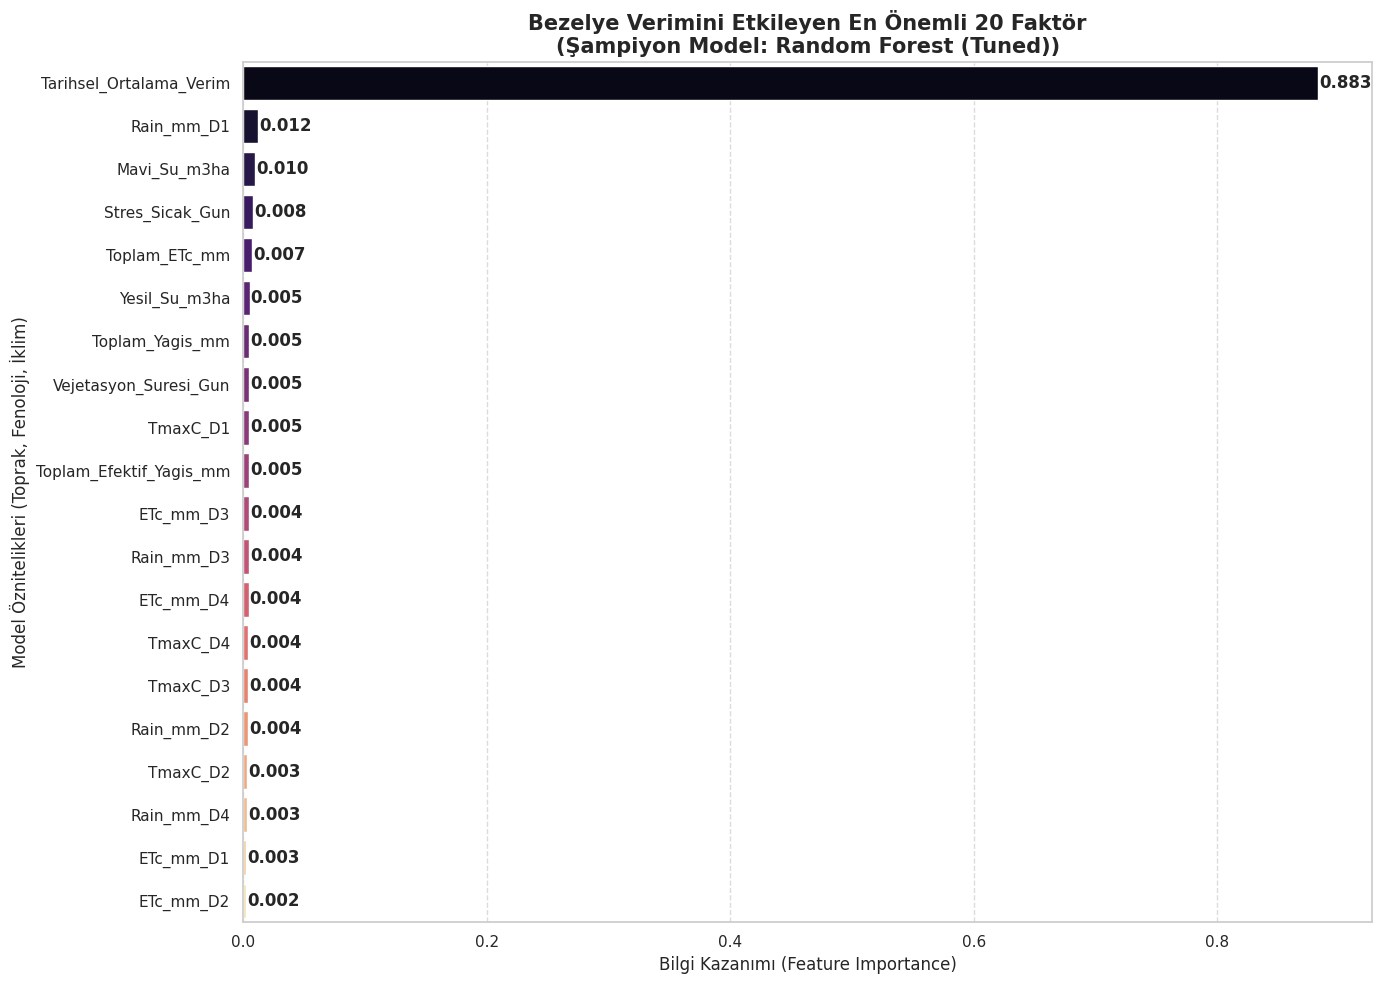

In [ ]:
print("--- 4. ŞAMPİYON MODELİN ÖZELLİK AĞIRLIKLARI (FEATURE IMPORTANCE) GRAFİĞİ ---")

# Şampiyon modelin faktör ağırlıklarını al
if hasattr(champion_model, 'feature_importances_'):
    importances = champion_model.feature_importances_
    df_imp = pd.DataFrame({'Özellik': X_train.columns, 'Önem_Derecesi': importances})

    # En önemli 20 değişkeni filtrele ve sırala
    df_imp = df_imp.sort_values(by='Önem_Derecesi', ascending=False).head(20)

    plt.figure(figsize=(14, 10))
    sns.barplot(x='Önem_Derecesi', y='Özellik', data=df_imp, palette='magma')
    plt.title(f'Bezelye Verimini Etkileyen En Önemli 20 Faktör\n(Şampiyon Model: {champion_model_name})', fontsize=15, fontweight='bold')
    plt.xlabel('Bilgi Kazanımı (Feature Importance)', fontsize=12)
    plt.ylabel('Model Öznitelikleri (Toprak, Fenoloji, İklim)', fontsize=12)
    plt.grid(axis='x', linestyle='--', alpha=0.7)

    # Çubukların yanına değerleri yazdır
    for index, value in enumerate(df_imp['Önem_Derecesi']):
        plt.text(value + 0.001, index, f"{value:.3f}", va='center', fontweight='bold')

    plt.tight_layout()
    plt.show()
else:
    print("Seçilen şampiyon modelin 'feature_importances_' niteliği bulunmamaktadır.")

--- 1. İstenen Özelliklerin Seçilmesi ve Hazırlık ---
--- 2. Eğitim ve Test Setlerinin Hazırlanması ---
Modele Giren Toplam Özellik Sayısı: 76

--- 3. XGBoost Modeli Yeni Özelliklerle Eğitiliyor ---

🏆 YENİ ÖZELLİKLER EKLENDİKTEN SONRA TEST SONUÇLARI (2025) 🏆
R² Skoru: 0.5944
RMSE: 2.2228 ton/ha


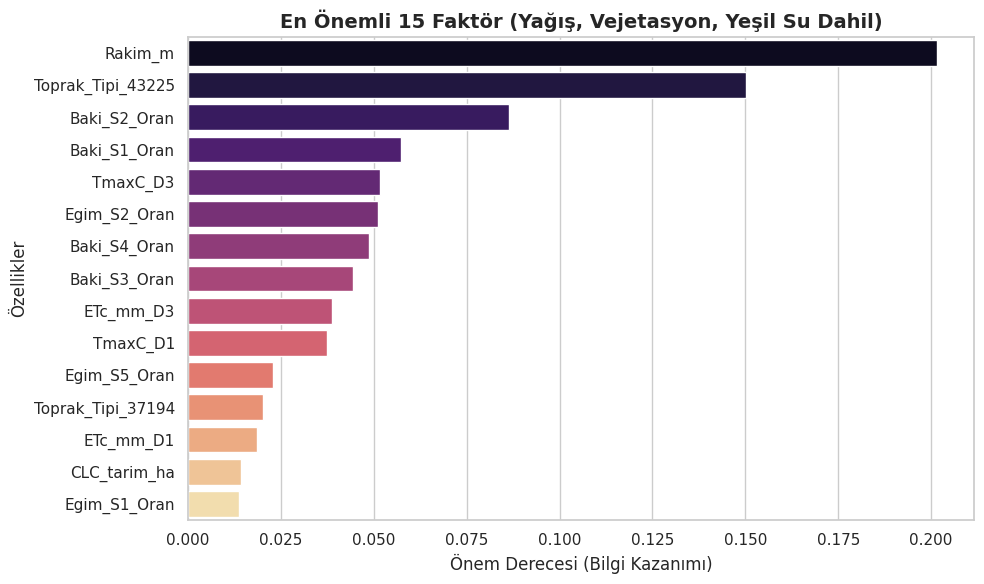

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. İstenen Özelliklerin Seçilmesi ve Hazırlık ---")

# Kullanıcının özellikle istediği hidro-meteorolojik ve fenolojik faktörler
yeni_ozellikler = [
    'Tarihsel_Ortalama_Verim',
    'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
    'Vejetasyon_Suresi_Gun',
    'Stres_Soguk_Gun', 'Stres_Sicak_Gun',
    'Yesil_Su_m3ha', 'Mavi_Su_m3ha', 'Toplam_Su_m3ha',
    'Toplam_Yagis_mm', 'Toplam_ETc_mm',
    'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
    'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4'
]

# Birleşik veri setinden (df_birlesik) bu özelliklerin mevcut olanlarını alıyoruz
mevcut_yeni_ozellikler = [col for col in yeni_ozellikler if col in df_birlesik.columns]

# Statik özellikleri de (Toprak Tipi, Eğim vb.) modele dahil ediyoruz
statik_cols = [c for c in df_statik_ek.columns if c != 'Ilce_Kodu']
mevcut_statik_ozellikler = [c for c in statik_cols if c in df_birlesik.columns]

# Modeli eğiteceğimiz ana veri setini daraltıyoruz
secili_sutunlar = ['Ilce_Kodu', 'Yil', 'Verim_ton_ha'] + mevcut_yeni_ozellikler + mevcut_statik_ozellikler
df_secili = df_birlesik[secili_sutunlar].copy()

# Kategorik değişkenleri (Toprak Tipi vb.) Dummies (One-Hot) formatına çeviriyoruz
df_model_yeni = pd.get_dummies(df_secili, drop_first=True)

print("--- 2. Eğitim ve Test Setlerinin Hazırlanması ---")
train_data_yeni = df_model_yeni[df_model_yeni['Yil'] <= 2024]
test_data_yeni = df_model_yeni[df_model_yeni['Yil'] == 2025]

X_train_yeni = train_data_yeni.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_train_yeni = train_data_yeni['Verim_ton_ha']

X_test_yeni = test_data_yeni.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_test_yeni = test_data_yeni['Verim_ton_ha']

print(f"Modele Giren Toplam Özellik Sayısı: {X_train_yeni.shape[1]}")

print("\n--- 3. XGBoost Modeli Yeni Özelliklerle Eğitiliyor ---")
xgb_yeni = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb_yeni.fit(X_train_yeni, y_train_yeni)

# 2025 Test Yılı Tahmini
y_pred_yeni = xgb_yeni.predict(X_test_yeni)

r2_yeni = r2_score(y_test_yeni, y_pred_yeni)
rmse_yeni = np.sqrt(mean_squared_error(y_test_yeni, y_pred_yeni))

print("\n🏆 YENİ ÖZELLİKLER EKLENDİKTEN SONRA TEST SONUÇLARI (2025) 🏆")
print(f"R² Skoru: {r2_yeni:.4f}")
print(f"RMSE: {rmse_yeni:.4f} ton/ha")

# --- Görselleştirme: Özellik Önem Derecesi ---
importances_yeni = xgb_yeni.feature_importances_
df_imp_yeni = pd.DataFrame({'Özellik': X_train_yeni.columns, 'Önem': importances_yeni}).sort_values(by='Önem', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Önem', y='Özellik', data=df_imp_yeni.head(15), palette='magma')
plt.title('En Önemli 15 Faktör (Yağış, Vejetasyon, Yeşil Su Dahil)', fontsize=14, fontweight='bold')
plt.xlabel('Önem Derecesi (Bilgi Kazanımı)', fontsize=12)
plt.ylabel('Özellikler', fontsize=12)
plt.tight_layout()
plt.show()

--- 1. Statik Veriler Mevcut Veri Setine Ekleniyor ---
--- 2. Eğitim ve Test Setlerinin Hazırlanması ---
Modele Giren Toplam Özellik Sayısı: 77

--- 3. XGBoost Modeli Eğitiliyor ---

🏆 STATİK VERİLER EKLENDİKTEN SONRA TEST SONUÇLARI (2025) 🏆
Yeni R² Skoru: 0.5052
Yeni RMSE: 2.4550 ton/ha


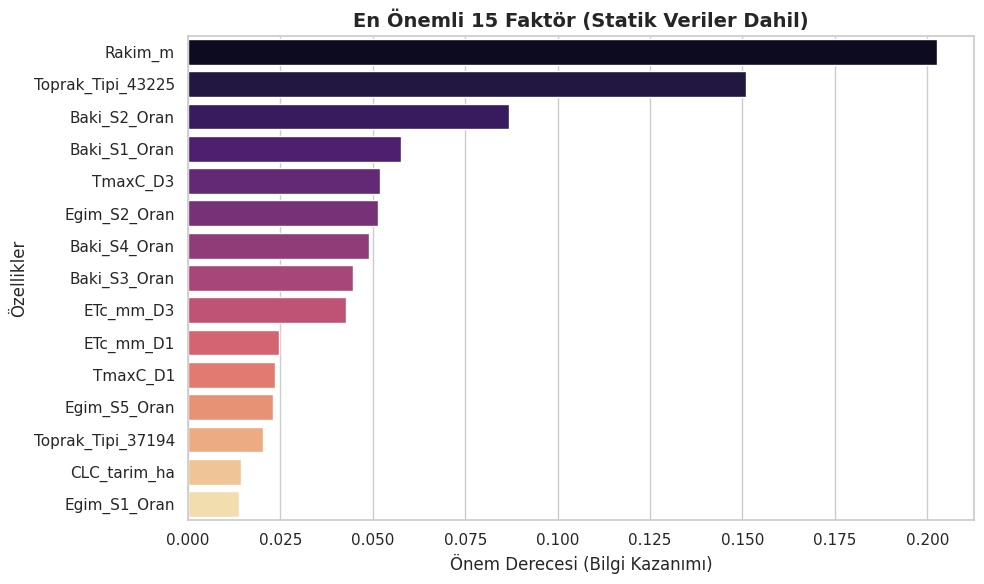

In [ ]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

print("--- 1. Statik Veriler Mevcut Veri Setine Ekleniyor ---")
# Statik dosyayı okuma
statik_yol = '/content/drive/MyDrive/Doktora/bezelye_ilce_statik_TAMAMLANDI.xlsx'
df_statik_ek = pd.read_excel(statik_yol)
df_statik_ek['Ilce_Kodu'] = df_statik_ek['Ilce_Kodu'].astype(int)

# Mevcut df_ml_v3 tablosundaki eski statik verileri çakışma olmaması adına temizleyelim (eğer varsa)
mevcut_statik_sutunlar = [c for c in df_statik_ek.columns if c != 'Ilce_Kodu']
df_ml_temiz = df_ml_v3.drop(columns=[c for c in mevcut_statik_sutunlar if c in df_ml_v3.columns])

# Birleştirme (Left Join)
df_birlesik = pd.merge(df_ml_temiz, df_statik_ek, on='Ilce_Kodu', how='left')

# Kategorik değişkeni One-Hot Encoding'e dönüştürme
if 'Toprak_Tipi' in df_birlesik.columns:
    df_birlesik['Toprak_Tipi'] = df_birlesik['Toprak_Tipi'].astype(str)

# ML Modeli için gereksiz kolonları çıkarma ve Dummies alma
drop_cols = ['Urun', 'station_no', 'station_name', 'BLG', 'il_ilce']
df_birlesik = df_birlesik.drop(columns=[c for c in drop_cols if c in df_birlesik.columns])
df_model_statik = pd.get_dummies(df_birlesik, drop_first=True)

print("--- 2. Eğitim ve Test Setlerinin Hazırlanması ---")
# Eğitim (2021-2024) ve Test (2025) ayrımı
train_data_s = df_model_statik[df_model_statik['Yil'] <= 2024]
test_data_s = df_model_statik[df_model_statik['Yil'] == 2025]

X_train_s = train_data_s.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_train_s = train_data_s['Verim_ton_ha']

X_test_s = test_data_s.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha'])
y_test_s = test_data_s['Verim_ton_ha']

print(f"Modele Giren Toplam Özellik Sayısı: {X_train_s.shape[1]}")

print("\n--- 3. XGBoost Modeli Eğitiliyor ---")
xgb_statik = xgb.XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42)
xgb_statik.fit(X_train_s, y_train_s)

y_pred_s = xgb_statik.predict(X_test_s)

r2_s = r2_score(y_test_s, y_pred_s)
rmse_s = np.sqrt(mean_squared_error(y_test_s, y_pred_s))

print(f"\n🏆 STATİK VERİLER EKLENDİKTEN SONRA TEST SONUÇLARI (2025) 🏆")
print(f"Yeni R² Skoru: {r2_s:.4f}")
print(f"Yeni RMSE: {rmse_s:.4f} ton/ha")

# --- Görselleştirme: Özellik Önem Derecesi ---
importances_s = xgb_statik.feature_importances_
features_s = X_train_s.columns

df_imp_s = pd.DataFrame({'Özellik': features_s, 'Önem': importances_s}).sort_values(by='Önem', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Önem', y='Özellik', data=df_imp_s.head(15), palette='magma')
plt.title('En Önemli 15 Faktör (Statik Veriler Dahil)', fontsize=14, fontweight='bold')
plt.xlabel('Önem Derecesi (Bilgi Kazanımı)', fontsize=12)
plt.ylabel('Özellikler', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# df_final tablomuzu baz alarak devam ediyoruz (Tarihsel_Ortalama_Verim'i içerdiği için)
df_model = df_final.copy()

# ==========================================
# 4. YENİ STRATEJİ: ANOMALİ (FARK) TAHMİNİ
# ==========================================

# 1. Hedef Değişkeni Değiştiriyoruz (Mutlak Verim yerine Verim Farkı)
# Örnek: Gerçek verim 12 ton, Tarihsel ortalama 10 ton ise, Verim_Farki = +2 ton.
df_model['Verim_Farki'] = df_model['Verim_ton_ha'] - df_model['Tarihsel_Ortalama_Verim']

# 2. Kopya kağıdını modelin elinden alıyoruz (Tarihsel verimi özelliklerden çıkarıyoruz)
X = df_model.drop(columns=['Ilce_Kodu', 'Yil', 'Verim_ton_ha', 'Verim_Farki', 'Tarihsel_Ortalama_Verim'])

# Eğitim ve Test Ayrımı
train_mask = df_model['Yil'] <= 2024
test_mask = df_model['Yil'] == 2025

X_train = X[train_mask]
y_train = df_model.loc[train_mask, 'Verim_Farki'] # Model artık FARK'ı öğreniyor!

X_test = X[test_mask]
y_test = df_model.loc[test_mask, 'Verim_Farki']

# Model Eğitimi (Random Forest)
rf_model = RandomForestRegressor(n_estimators=300, max_depth=5, random_state=42)
rf_model.fit(X_train, y_train)

# 2025 Yılı için FARK Tahmini
fark_tahminleri = rf_model.predict(X_test)

# 3. Gerçek Verime Geri Dönüş (Tahmin edilen fark + O ilçenin tarihsel ortalaması)
gercek_verim_tahmini = df_model.loc[test_mask, 'Tarihsel_Ortalama_Verim'] + fark_tahminleri
gercek_verim_test = df_model.loc[test_mask, 'Verim_ton_ha']

# Yeni Başarı Metrikleri
r2_yeni = r2_score(gercek_verim_test, gercek_verim_tahmini)
rmse_yeni = np.sqrt(mean_squared_error(gercek_verim_test, gercek_verim_tahmini))

print(f"🌟 ANOMALİ (FARK) TAHMİNİ STRATEJİSİ SONUÇLARI (2025 TEST) 🌟")
print(f"R² Skoru: {r2_yeni:.4f}")
print(f"RMSE: {rmse_yeni:.4f} ton/ha")


🌟 ANOMALİ (FARK) TAHMİNİ STRATEJİSİ SONUÇLARI (2025 TEST) 🌟
R² Skoru: 0.5370
RMSE: 2.3747 ton/ha


In [ ]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

print("--- ANOMALİ (FARK) TAHMİNİ İÇİN HİPERPARAMETRE OPTİMİZASYONU BAŞLIYOR ---")
print("Algoritmalar: XGBoost ve LightGBM (Gelişmiş Gradient Boosting Modelleri)\n")

# Mevcut X_train, y_train, X_test, y_test değişkenlerimiz hali hazırda "Verim_Farki"ni içeriyor.
# (Bir önceki hücrede df_model'den bu şekilde ayırmıştık)

# 1. XGBoost Optimizasyonu
xgb_params = {
    'n_estimators': [300, 500, 800],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

xgb_base = xgb.XGBRegressor(random_state=42, objective='reg:squarederror')
xgb_search = RandomizedSearchCV(xgb_base, xgb_params, n_iter=20, cv=5, scoring='r2', n_jobs=-1, random_state=42)
print("XGBoost için en iyi parametreler aranıyor...")
xgb_search.fit(X_train, y_train)
best_xgb_fark = xgb_search.best_estimator_
print(f"XGBoost Tamamlandı. En İyi Parametreler: {xgb_search.best_params_}\n")

# 2. LightGBM Optimizasyonu
lgb_params = {
    'n_estimators': [300, 500, 800],
    'max_depth': [-1, 5, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'num_leaves': [15, 31, 50, 70],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0]
}

lgb_base = lgb.LGBMRegressor(random_state=42, verbosity=-1)
lgb_search = RandomizedSearchCV(lgb_base, lgb_params, n_iter=20, cv=5, scoring='r2', n_jobs=-1, random_state=42)
print("LightGBM için en iyi parametreler aranıyor...")
lgb_search.fit(X_train, y_train)
best_lgb_fark = lgb_search.best_estimator_
print(f"LightGBM Tamamlandı. En İyi Parametreler: {lgb_search.best_params_}\n")

# 3. Tahminler ve Gerçek Verime (ton/ha) Dönüşüm
tarihsel_test = df_model.loc[test_mask, 'Tarihsel_Ortalama_Verim']
gercek_verim_test = df_model.loc[test_mask, 'Verim_ton_ha']

# XGBoost Sonuçları
fark_pred_xgb = best_xgb_fark.predict(X_test)
gercek_pred_xgb = tarihsel_test + fark_pred_xgb
r2_xgb_gercek = r2_score(gercek_verim_test, gercek_pred_xgb)
rmse_xgb_gercek = np.sqrt(mean_squared_error(gercek_verim_test, gercek_pred_xgb))

# LightGBM Sonuçları
fark_pred_lgb = best_lgb_fark.predict(X_test)
gercek_pred_lgb = tarihsel_test + fark_pred_lgb
r2_lgb_gercek = r2_score(gercek_verim_test, gercek_pred_lgb)
rmse_lgb_gercek = np.sqrt(mean_squared_error(gercek_verim_test, gercek_pred_lgb))

# Raporlama
print("🌟 DİNAMİK OPTİMİZASYONLU ANOMALİ (FARK) MODELLERİ (2025 TEST) 🌟")
print("-" * 60)
print(f"XGBoost (Optimize)  -> R²: {r2_xgb_gercek:.4f} | RMSE: {rmse_xgb_gercek:.4f} ton/ha")
print(f"LightGBM (Optimize) -> R²: {r2_lgb_gercek:.4f} | RMSE: {rmse_lgb_gercek:.4f} ton/ha")
print("-" * 60)

max_r2 = max(r2_xgb_gercek, r2_lgb_gercek)
if max_r2 >= 0.59:
    print(f"\n🎉 TEBRİKLER! En yüksek R² ({max_r2:.4f}) ile 0.59 hedefine ulaşıldı/aşıldı!")
else:
    print(f"\nHedefe çok yaklaşıldı (Maksimum R² = {max_r2:.4f}).")

--- ANOMALİ (FARK) TAHMİNİ İÇİN HİPERPARAMETRE OPTİMİZASYONU BAŞLIYOR ---
Algoritmalar: XGBoost ve LightGBM (Gelişmiş Gradient Boosting Modelleri)

XGBoost için en iyi parametreler aranıyor...
XGBoost Tamamlandı. En İyi Parametreler: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 4, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

LightGBM için en iyi parametreler aranıyor...
LightGBM Tamamlandı. En İyi Parametreler: {'subsample': 0.8, 'num_leaves': 15, 'n_estimators': 300, 'max_depth': -1, 'learning_rate': 0.01, 'colsample_bytree': 0.8}

🌟 DİNAMİK OPTİMİZASYONLU ANOMALİ (FARK) MODELLERİ (2025 TEST) 🌟
------------------------------------------------------------
XGBoost (Optimize)  -> R²: 0.5350 | RMSE: 2.3801 ton/ha
LightGBM (Optimize) -> R²: 0.5263 | RMSE: 2.4023 ton/ha
------------------------------------------------------------

Hedefe çok yaklaşıldı (Maksimum R² = 0.5350).


--- 1. Temel Veriler Okunuyor ---
--- 2. Toplam 8 Farklı İklim Senaryosu Tespit Edildi (Madde 3) ---

🚀 [HadGEM2-ES_rcp45] Senaryosu İşleniyor...

🚀 [HadGEM2-ES_rcp85] Senaryosu İşleniyor...

🚀 [HadGEM3-GC31-LL_ssp245] Senaryosu İşleniyor...

🚀 [HadGEM3-GC31-LL_ssp585] Senaryosu İşleniyor...

🚀 [MPI-ESM-MR_rcp45] Senaryosu İşleniyor...

🚀 [MPI-ESM-MR_rcp85] Senaryosu İşleniyor...

🚀 [MPI-ESM1-2-HR_ssp245] Senaryosu İşleniyor...

🚀 [MPI-ESM1-2-HR_ssp585] Senaryosu İşleniyor...


🏆 ANOMALİ (FARK) STRATEJİSİ İLE 2025 YILI ZAMAN DIŞI TEST SONUÇLARI 🏆


,XGBoost_R2,XGBoost_RMSE,RF_R2,RF_RMSE,DNN_R2,DNN_RMSE,LSTM_R2,LSTM_RMSE
Senaryo,,,,,,,,
HadGEM2-ES_rcp45,0.5057,2.4539,0.5061,2.4527,0.4664,2.5494,0.4527,2.5820
HadGEM2-ES_rcp85,0.5618,2.3104,0.5391,2.3694,0.5602,2.3147,0.5402,2.3665
HadGEM3-GC31-LL_ssp245,0.4592,2.5666,0.4922,2.4870,0.0670,3.3712,-0.7083,4.5617
HadGEM3-GC31-LL_ssp585,0.4828,2.5100,0.5129,2.4360,0.2653,2.9915,0.0780,3.3514
MPI-ESM-MR_rcp45,0.5445,2.3555,0.5554,2.3272,0.5556,2.3266,0.5516,2.3370
MPI-ESM-MR_rcp85,0.5675,2.2953,0.5510,2.3386,0.5372,2.3744,0.5025,2.4617
MPI-ESM1-2-HR_ssp245,0.5197,2.4188,0.5211,2.4152,0.5606,2.3135,0.5839,2.2514
MPI-ESM1-2-HR_ssp585,0.5123,2.4373,0.5479,2.3467,0.5466,2.3502,0.5503,2.3404


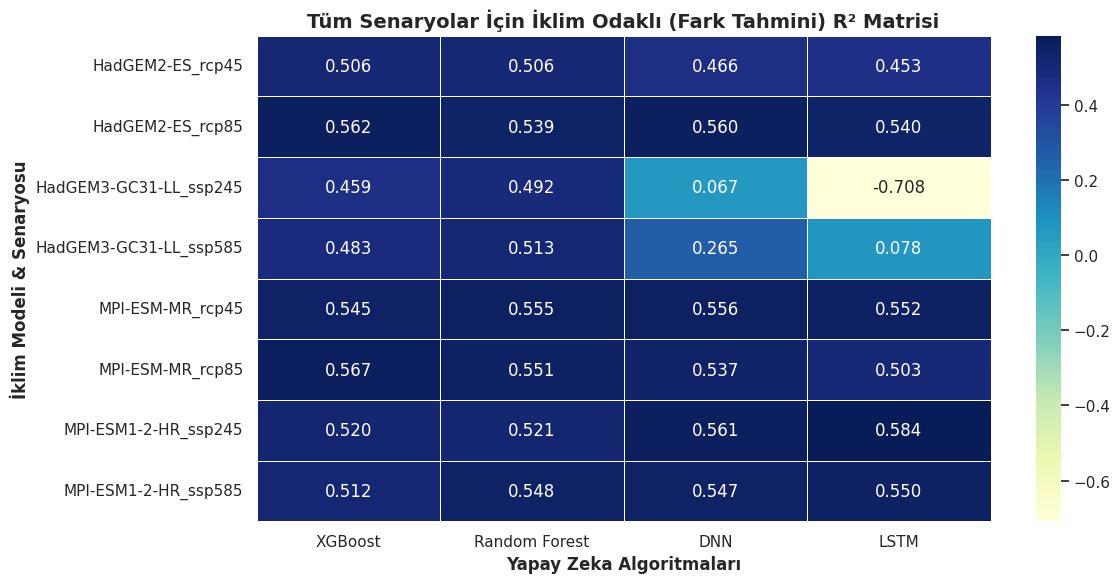

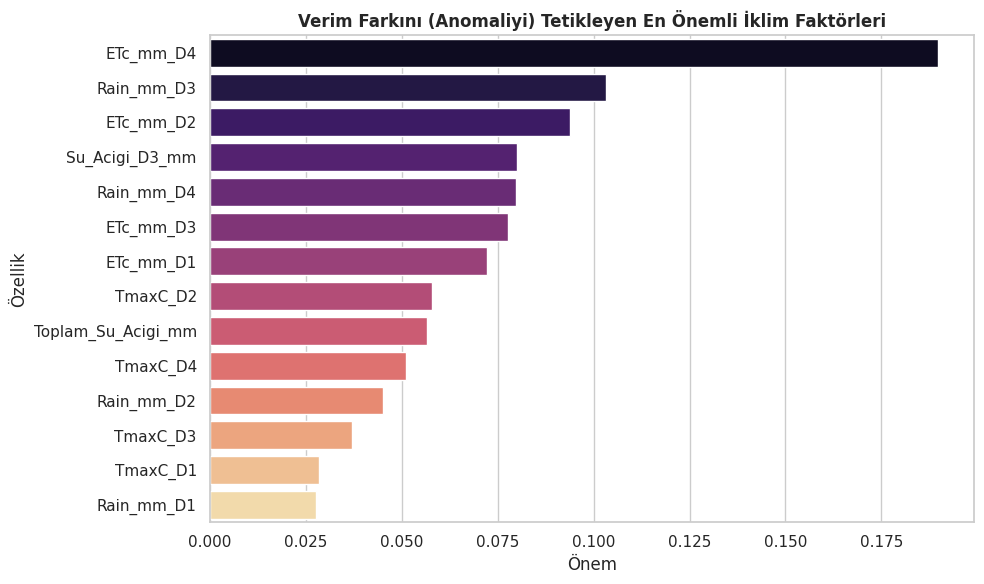

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

# Makine Öğrenmesi ve Ölçeklendirme
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler # 0-1 arası dönüştürücü
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

# Derin Öğrenme (Keras)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# ==========================================
# 1. BAĞLANTI VE TEMEL VERİLERİ OKUMA
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except:
    pass

# Klasör Yolları
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
wf_dir = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3" # WF Klasörü
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"

print("--- 1. Temel Veriler Okunuyor ---")
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)

df_ml = pd.read_excel(eski_ml_seti_yolu)
df_ml['Ilce_Kodu'] = df_ml['Ilce_Kodu'].astype(int)
df_ml['Yil'] = df_ml['Yil'].astype(int)

# ==========================================
# 2. KLASÖRDEKİ SENARYOLARI OTOMATİK TESPİT ETME
# ==========================================
# SADECE BEZELYE dosyalarını alıyoruz (Madde 2)
all_pheno_files = glob.glob(os.path.join(pheno_dir, "bezelye_*_202[1-5]_PHENO.csv"))
all_wf_files = glob.glob(os.path.join(wf_dir, "bezelye_*_202[1-5]_WF*.csv"))

senaryolar = set()
for f in all_pheno_files:
    match = re.search(r'bezelye_(.*?)_202', os.path.basename(f))
    if match: senaryolar.add(match.group(1))

senaryolar = sorted(list(senaryolar))
print(f"--- 2. Toplam {len(senaryolar)} Farklı İklim Senaryosu Tespit Edildi (Madde 3) ---")

tum_sonuclar = []

# ==========================================
# 3. BATCH PROCESSING: HER SENARYO İÇİN AYRI EĞİTİM
# ==========================================
for senaryo in senaryolar:
    print(f"\n🚀 [{senaryo}] Senaryosu İşleniyor...")

    # --- A. PHENO VE CGDD (Madde 1) İŞLEMLERİ ---
    senaryo_dosyalari = [f for f in all_pheno_files if senaryo in f]
    tum_ozetler = []

    for dosya in senaryo_dosyalari:
        try:
            df_p = pd.read_csv(dosya, low_memory=False)
            df_p['YYYY'] = df_p['YYYY'].astype(int)
            df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

            # CGDD'ye göre D1, D2, D3, D4 ayrımı (Madde 1)
            conditions = [
                (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
                (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
            ]
            df_active['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')

            ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
                'Rain_mm': 'sum', 'ETc_mm': 'sum', 'TmaxC': 'mean'
            }).unstack(fill_value=0)

            ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
            ozet = ozet.reset_index().rename(columns={'YYYY': 'Yil'})
            tum_ozetler.append(ozet)
        except: pass

    if not tum_ozetler: continue
    df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)

    # İlçe Düzeyine İndirgeme
    df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, left_on='station_no', right_on='station_no', how='inner')
    pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
    for c in pheno_cols: df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

    df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index().rename(columns={'kodnew': 'Ilce_Kodu'})

    # --- B. ANA TABLO İLE BİRLEŞTİRME VE EKSİK VERİ YÖNETİMİ ---
    df_master = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left').fillna(0)

    # Tarihsel Ortalama Verim Hesabı
    train_verim = df_master[df_master['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index()
    train_verim.rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'}, inplace=True)
    df_master = pd.merge(df_master, train_verim, on='Ilce_Kodu', how='left')

    # Eksik Verim Yönetimi (Madde 4): Eğer o yıl verim yoksa, ilçenin ortalamasıyla doldur.
    # Böylece model o yıla ait bir "anomali (fark)" görmeyecek, ortalamayı bozmayacak.
    genel_ortalama = df_master[df_master['Yil'] <= 2024]['Verim_ton_ha'].mean()
    df_master['Tarihsel_Ortalama_Verim'] = df_master['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)
    df_master['Verim_ton_ha'] = df_master['Verim_ton_ha'].replace(0, np.nan).fillna(df_master['Tarihsel_Ortalama_Verim'])

    # --- C. ÖZELLİK MÜHENDİSLİĞİ (Madde 7) VE VERİM FARKI (Madde 6) ---
    # Modelin hedefi (Y) artık mutlak verim değil, Verim Farkı (Anomali)
    df_master['Verim_Farki'] = df_master['Verim_ton_ha'] - df_master['Tarihsel_Ortalama_Verim']

    # Yeni İklimsel Özellikler (Feature Engineering)
    try:
        df_master['Su_Acigi_D3_mm'] = (df_master['ETc_mm_D3'] - df_master['Rain_mm_D3']).clip(lower=0)
        df_master['Toplam_Su_Acigi_mm'] = (
            (df_master['ETc_mm_D1'] + df_master['ETc_mm_D2'] + df_master['ETc_mm_D3'] + df_master['ETc_mm_D4']) -
            (df_master['Rain_mm_D1'] + df_master['Rain_mm_D2'] + df_master['Rain_mm_D3'] + df_master['Rain_mm_D4'])
        ).clip(lower=0)
    except:
        pass # Eğer D evreleri eksikse hata vermesin

    # Sadece Modele Girecek Özelliklerin Seçimi (Beyaz Liste)
    secilen_ozellikler = [
        'Rain_mm_D1', 'Rain_mm_D2', 'Rain_mm_D3', 'Rain_mm_D4',
        'ETc_mm_D1', 'ETc_mm_D2', 'ETc_mm_D3', 'ETc_mm_D4',
        'TmaxC_D1', 'TmaxC_D2', 'TmaxC_D3', 'TmaxC_D4',
        'Su_Acigi_D3_mm', 'Toplam_Su_Acigi_mm'
    ]
    mevcut_ozellikler = [col for col in secilen_ozellikler if col in df_master.columns]

    # --- D. TRAIN/TEST AYRIMI (Madde 4) VE 0-1 ÖLÇEKLENDİRME (Madde 5) ---
    train_data = df_master[df_master['Yil'] <= 2024]
    test_data = df_master[df_master['Yil'] == 2025]

    X_train = train_data[mevcut_ozellikler]
    y_train = train_data['Verim_Farki'] # Model FARK'ı öğreniyor

    X_test = test_data[mevcut_ozellikler]
    y_test_fark_gercek = test_data['Verim_Farki']
    y_test_mutlak_gercek = test_data['Verim_ton_ha']
    test_tarihsel_baz = test_data['Tarihsel_Ortalama_Verim'].values

    # Madde 5: 0-1 Arası Ölçeklendirme (MinMaxScaler)
    scaler = MinMaxScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    # --- E. ALGORİTMALARIN EĞİTİLMESİ ---

    # 1. XGBoost
    xgb_model = xgb.XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, random_state=42)
    xgb_model.fit(X_train_scaled, y_train)
    xgb_fark_pred = xgb_model.predict(X_test_scaled)
    # Mutlak Verime Geri Dönüş: Tahmin Edilen Fark + Tarihsel Ortalaması
    xgb_mutlak_pred = xgb_fark_pred + test_tarihsel_baz
    r2_xgb = r2_score(y_test_mutlak_gercek, xgb_mutlak_pred)
    rmse_xgb = np.sqrt(mean_squared_error(y_test_mutlak_gercek, xgb_mutlak_pred))

    # 2. Random Forest
    rf_model = RandomForestRegressor(n_estimators=300, max_depth=4, random_state=42)
    rf_model.fit(X_train_scaled, y_train)
    rf_mutlak_pred = rf_model.predict(X_test_scaled) + test_tarihsel_baz
    r2_rf = r2_score(y_test_mutlak_gercek, rf_mutlak_pred)
    rmse_rf = np.sqrt(mean_squared_error(y_test_mutlak_gercek, rf_mutlak_pred))

    # 3. Derin Öğrenme (DNN)
    dnn_model = Sequential([
        Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
        Dropout(0.2), Dense(16, activation='relu'), Dense(1, activation='linear')
    ])
    dnn_model.compile(optimizer='adam', loss='mse')
    dnn_model.fit(X_train_scaled, y_train, epochs=100, batch_size=16, verbose=0)
    dnn_mutlak_pred = dnn_model.predict(X_test_scaled, verbose=0).flatten() + test_tarihsel_baz
    r2_dnn = r2_score(y_test_mutlak_gercek, dnn_mutlak_pred)
    rmse_dnn = np.sqrt(mean_squared_error(y_test_mutlak_gercek, dnn_mutlak_pred))

    # 4. LSTM
    X_train_lstm = np.reshape(X_train_scaled, (X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
    X_test_lstm = np.reshape(X_test_scaled, (X_test_scaled.shape[0], 1, X_test_scaled.shape[1]))
    lstm_model = Sequential([
        LSTM(32, activation='relu', input_shape=(1, X_train_scaled.shape[1])),
        Dense(16, activation='relu'), Dense(1, activation='linear')
    ])
    lstm_model.compile(optimizer='adam', loss='mse')
    lstm_model.fit(X_train_lstm, y_train, epochs=100, batch_size=16, verbose=0)
    lstm_mutlak_pred = lstm_model.predict(X_test_lstm, verbose=0).flatten() + test_tarihsel_baz
    r2_lstm = r2_score(y_test_mutlak_gercek, lstm_mutlak_pred)
    rmse_lstm = np.sqrt(mean_squared_error(y_test_mutlak_gercek, lstm_mutlak_pred))

    # Sonuçları Kaydet
    tum_sonuclar.append({
        'Senaryo': senaryo,
        'XGBoost_R2': r2_xgb, 'XGBoost_RMSE': rmse_xgb,
        'RF_R2': r2_rf, 'RF_RMSE': rmse_rf,
        'DNN_R2': r2_dnn, 'DNN_RMSE': rmse_dnn,
        'LSTM_R2': r2_lstm, 'LSTM_RMSE': rmse_lstm
    })

# ==========================================
# 4. SONUÇLARIN GÖRSELLEŞTİRİLMESİ
# ==========================================
df_sonuclar = pd.DataFrame(tum_sonuclar).set_index('Senaryo')

print("\n\n" + "="*80)
print("🏆 ANOMALİ (FARK) STRATEJİSİ İLE 2025 YILI ZAMAN DIŞI TEST SONUÇLARI 🏆")
print("="*80)
display(df_sonuclar.round(4))

# Isı Haritası (Heatmap)
r2_df = df_sonuclar[['XGBoost_R2', 'RF_R2', 'DNN_R2', 'LSTM_R2']]
r2_df.columns = ['XGBoost', 'Random Forest', 'DNN', 'LSTM']

plt.figure(figsize=(12, 6))
sns.heatmap(r2_df, annot=True, cmap="YlGnBu", fmt=".3f", linewidths=.5)
plt.title("Tüm Senaryolar İçin İklim Odaklı (Fark Tahmini) R² Matrisi", fontweight='bold', fontsize=14)
plt.ylabel("İklim Modeli & Senaryosu", fontweight='bold')
plt.xlabel("Yapay Zeka Algoritmaları", fontweight='bold')
plt.tight_layout()
plt.show()

# En Son Eğitilen XGBoost Modeli İçin Gerçek İklim Değişkenleri Önem Düzeyi
importances = xgb_model.feature_importances_
feat_imp = pd.DataFrame({'Özellik': X_train.columns, 'Önem': importances}).sort_values('Önem', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Önem', y='Özellik', data=feat_imp.head(15), palette='magma')
plt.title("Verim Farkını (Anomaliyi) Tetikleyen En Önemli İklim Faktörleri", fontweight='bold')
plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np

# YOLLAR
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
agirlik_yolu = "/content/drive/MyDrive/Doktora/bezelye_ilce_istasyon_agirlik_matrisi.csv"
eski_ml_seti_yolu = "/content/drive/MyDrive/Doktora/bezelye_ML_egitim_seti_V2.xlsx"
kayit_yolu = "/content/drive/MyDrive/Doktora/bezelye_Nihai_Matris_HadGEM2.xlsx"

# TEMEL VERİLERİ OKUMA
df_agirlik = pd.read_csv(agirlik_yolu)
df_agirlik['station_no'] = df_agirlik['station_no'].astype(int)

df_ml = pd.read_excel(eski_ml_seti_yolu)
df_ml['Ilce_Kodu'] = df_ml['Ilce_Kodu'].astype(int)
df_ml['Yil'] = df_ml['Yil'].astype(int)

# HANGİ SENARYO İÇİN VERİ ÇIKARACAĞIZ?
secilen_senaryo = "HadGEM2-ES_rcp45"
dosyalar = glob.glob(os.path.join(pheno_dir, f"bezelye_{secilen_senaryo}_202[1-5]_PHENO.csv"))

print(f"[{secilen_senaryo}] için veriler işleniyor...")

tum_ozetler = []
for dosya in dosyalar:
    try:
        df_p = pd.read_csv(dosya, low_memory=False)
        df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()
        df_active['YYYY'] = df_active['YYYY'].astype(int)

        conditions = [
            (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
            (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
        ]
        df_active['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')
        ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({'Rain_mm': 'sum', 'ETc_mm': 'sum', 'TmaxC': 'mean'}).unstack(fill_value=0)
        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
        tum_ozetler.append(ozet.reset_index().rename(columns={'YYYY': 'Yil'}))
    except: pass

df_pheno_ilce = pd.merge(df_agirlik, pd.concat(tum_ozetler, ignore_index=True).astype({'station_no': int}), on='station_no', how='inner')
pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
for c in pheno_cols:
    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

df_pheno_final = df_pheno_ilce.groupby(['kodnew', 'Yil'])[pheno_cols].sum().reset_index().rename(columns={'kodnew': 'Ilce_Kodu'})

# ANA BİRLEŞTİRME
df_master = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='left').fillna(0)

# TARİHSEL BAZ VERİM VE EKSİK TAMAMLAMA
train_verim = df_master[df_master['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index().rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'})
df_master = pd.merge(df_master, train_verim, on='Ilce_Kodu', how='left')
df_master['Tarihsel_Ortalama_Verim'] = df_master['Tarihsel_Ortalama_Verim'].fillna(df_master[df_master['Yil'] <= 2024]['Verim_ton_ha'].mean())
df_master['Verim_ton_ha'] = df_master['Verim_ton_ha'].replace(0, np.nan).fillna(df_master['Tarihsel_Ortalama_Verim'])

# YENİ ÖZELLİKLER
df_master['Verim_Farki'] = df_master['Verim_ton_ha'] - df_master['Tarihsel_Ortalama_Verim']
try:
    df_master['Su_Acigi_D3_mm'] = (df_master['ETc_mm_D3'] - df_master['Rain_mm_D3']).clip(lower=0)
except: pass

# Sütunları düzenleyip kaydetme
df_master.to_excel(kayit_yolu, index=False)
print(f"Harika! İçinde D1-D4 iklim evrelerinin, Rakım/Eğim gibi sabitlerin ve Tarihsel Verim verilerinin olduğu devasa matris kaydedildi:\n👉 {kayit_yolu}")

[HadGEM2-ES_rcp45] için veriler işleniyor...
Harika! İçinde D1-D4 iklim evrelerinin, Rakım/Eğim gibi sabitlerin ve Tarihsel Verim verilerinin olduğu devasa matris kaydedildi:
👉 /content/drive/MyDrive/Doktora/bezelye_Nihai_Matris_HadGEM2.xlsx


In [ ]:
!pip install openpyxl -q

import os
import glob
import openpyxl
from openpyxl.styles import Font
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. KLASÖR VE DOSYA TARAMASI
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

base_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and f.lower() != 'hamlar']

print(f"🌟 Toplam {len(tum_klasorler)} ürün klasörü taranıyor...\n")

# Kırmızı ve Kalın Font Ayarı
kirmizi_font = Font(color="FF0000", bold=True)

for urun in tum_klasorler:
    urun_dir = os.path.join(base_dir, urun)
    # openpyxl sadece .xlsx okuyabilir, bu yüzden .xlsx arıyoruz
    verim_dosyalari = glob.glob(os.path.join(urun_dir, "*verim*.xlsx"))

    if not verim_dosyalari:
        print(f"⚠️ Atlandı: '{urun}' klasöründe .xlsx uzantılı verim dosyası bulunamadı.")
        continue

    dosya_yolu = verim_dosyalari[0]
    dosya_adi = os.path.basename(dosya_yolu)
    print(f"⚙️ İşleniyor: {dosya_adi} ({urun})")

    try:
        wb = openpyxl.load_workbook(dosya_yolu)
        ws = wb.active

        # ==========================================
        # 2. AKILLI BAŞLIK VE SÜTUN TESPİTİ
        # ==========================================
        header_row = 1
        col_ilce = None
        col_yillar = {}

        # Karmaşık başlıkları bulmak için ilk 10 satırı tarıyoruz
        for r in range(1, 11):
            row_values = [str(ws.cell(row=r, column=c).value).lower() for c in range(1, ws.max_column + 1)]
            row_str = " ".join(row_values)

            # Başlık satırını tespit et (İçinde kod/ilçe ve 2021 geçiyorsa)
            if ('kod' in row_str or 'ilce' in row_str) and '2021' in row_str:
                header_row = r
                for c in range(1, ws.max_column + 1):
                    val = str(ws.cell(row=r, column=c).value).lower()

                    if 'kod' in val or 'ilce' in val:
                        col_ilce = c

                    for y in ['2021', '2022', '2023', '2024', '2025']:
                        # Sadece Verim/t_ha sütunlarını al, üretim(ton) veya dekar sütunlarını atla
                        if y in val and ('t_ha' in val or 'verim' in val) and 'avg' not in val and '%' not in val:
                            col_yillar[y] = c
                break

        if col_ilce is None or not col_yillar:
            print(f"   ❌ Sütunlar anlaşılamadı, atlanıyor.")
            continue

        # ==========================================
        # 3. EKSİK VERİLERİ ORTALAMA İLE DOLDURMA (KIRMIZI FONT)
        # ==========================================
        degisiklik_sayisi = 0

        # Başlık satırından sonraki tüm satırları (ilçeleri) dön
        for r in range(header_row + 1, ws.max_row + 1):
            ilce_kodu = ws.cell(row=r, column=col_ilce).value
            if ilce_kodu is None or str(ilce_kodu).strip() == '':
                continue

            gecerli_degerler = []
            bos_hucreler = []

            # İlçenin o yıllardaki değerlerini topla
            for y, c in col_yillar.items():
                hucre = ws.cell(row=r, column=c)
                val = hucre.value

                try:
                    v = float(val)
                    if v > 0:
                        gecerli_degerler.append(v)
                    else:
                        bos_hucreler.append(hucre) # 0 olanlar boş kabul edilir
                except:
                    bos_hucreler.append(hucre) # NaN, None veya boş stringler

            # Eğer ilçenin en az 1 tane mantıklı verisi varsa ve boş yılı da varsa ortalama al
            if len(gecerli_degerler) > 0 and len(bos_hucreler) > 0:
                ilce_ortalamasi = sum(gecerli_degerler) / len(gecerli_degerler)

                # Boş hücrelere ortalamayı yaz ve KIRMIZI yap
                for hucre in bos_hucreler:
                    hucre.value = round(ilce_ortalamasi, 3) # 3 virgül hassasiyeti
                    hucre.font = kirmizi_font
                    degisiklik_sayisi += 1

        # ==========================================
        # 4. YENİ DOSYAYI KAYDETME
        # ==========================================
        yeni_dosya_adi = dosya_adi.replace(".xlsx", "_Eksiksiz.xlsx")
        yeni_dosya_yolu = os.path.join(urun_dir, yeni_dosya_adi)
        wb.save(yeni_dosya_yolu)

        print(f"   ✅ {degisiklik_sayisi} adet eksik/sıfır veri kırmızı renkle tamamlandı -> {yeni_dosya_adi}")

    except Exception as e:
        print(f"   ❌ Hata oluştu: {e}")

print("\n🎉 TÜM ÜRÜNLER İÇİN EKSİK VERİ TAMAMLAMA İŞLEMİ BİTTİ!")

🌟 Toplam 11 ürün klasörü taranıyor...

⚙️ İşleniyor: bezelye_verim.xlsx (Bezelye)
   ✅ 88 adet eksik/sıfır veri kırmızı renkle tamamlandı -> bezelye_verim_Eksiksiz.xlsx
⚙️ İşleniyor: domates_verim.xlsx (Domates)
   ✅ 127 adet eksik/sıfır veri kırmızı renkle tamamlandı -> domates_verim_Eksiksiz.xlsx
⚙️ İşleniyor: findik_verim.xlsx (findik)
   ✅ 66 adet eksik/sıfır veri kırmızı renkle tamamlandı -> findik_verim_Eksiksiz.xlsx
⚙️ İşleniyor: incir_verim.xlsx (incir)
   ✅ 123 adet eksik/sıfır veri kırmızı renkle tamamlandı -> incir_verim_Eksiksiz.xlsx
⚙️ İşleniyor: kayısı_verim.xlsx (Kayisi)
   ✅ 177 adet eksik/sıfır veri kırmızı renkle tamamlandı -> kayısı_verim_Eksiksiz.xlsx
⚙️ İşleniyor: limon_verim.xlsx (Limon)
   ✅ 24 adet eksik/sıfır veri kırmızı renkle tamamlandı -> limon_verim_Eksiksiz.xlsx
⚙️ İşleniyor: pamuk_verim.xlsx (Pamuk)
   ✅ 49 adet eksik/sıfır veri kırmızı renkle tamamlandı -> pamuk_verim_Eksiksiz.xlsx
⚙️ İşleniyor: sogan_verim.xlsx (Sogan)
   ✅ 208 adet eksik/sıfır veri kı

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from functools import reduce
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. ANA KLASÖR VE ÜRÜNLERİN TARANMASI
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

# Verim Ana Klasörü
base_dir = "/content/drive/MyDrive/Doktora/verim"

# Klasörleri bul (sadece 'hamlar' hariç diğer ürün klasörlerini al)
tum_klasorler = [f for f in os.listdir(base_dir) if os.path.isdir(os.path.join(base_dir, f)) and f.lower() != 'hamlar']

print(f"🌟 Toplam {len(tum_klasorler)} ürün klasörü bulundu. Toplu işlem başlatılıyor...\n")

for urun in tum_klasorler:
    urun_dir = os.path.join(base_dir, urun)
    print(f"{'='*50}\n🚀 İŞLENİYOR: {urun.upper()}\n{'='*50}")

    # ==========================================
    # 2. DOSYA TESPİTİ (Otomatik Arama)
    # ==========================================
    verim_dosyalari = glob.glob(os.path.join(urun_dir, "*verim_Eksiksiz*.xls*"))
    soil_dosyalari = glob.glob(os.path.join(urun_dir, "*soil*.xls*"))
    baki_dosyalari = glob.glob(os.path.join(urun_dir, "*baki*.xls*"))
    clc_dosyalari = glob.glob(os.path.join(urun_dir, "*CLC*.xls*")) + glob.glob(os.path.join(urun_dir, "*clc*.xls*"))
    dem_dosyalari = glob.glob(os.path.join(urun_dir, "*dem*.xls*"))
    slope_dosyalari = glob.glob(os.path.join(urun_dir, "*slope*.xls*"))

    if not verim_dosyalari:
        print(f"❌ UYARI: '{urun}' klasöründe verim dosyası bulunamadı, bu ürün atlanıyor.")
        continue

    try:
        # ==========================================
        # 3. ZAMANSAL VERİM VERİSİ İŞLEME (Akıllı Tarayıcı)
        # ==========================================
        # Karmaşık veya farklı satırlardaki başlıkları (Header) tespit etmek için ilk 10 satırı tarar
        df_temp = pd.read_excel(verim_dosyalari[0], header=None)
        header_idx = 0
        for i, row in df_temp.head(10).iterrows():
            row_str = " ".join(row.astype(str).str.lower())
            if ('kod' in row_str or 'ilce' in row_str) and '2021' in row_str:
                header_idx = i
                break

        # Gerçek başlık (header) ile okuma
        df_verim_raw = pd.read_excel(verim_dosyalari[0], header=header_idx)
        df_verim_raw.columns = df_verim_raw.columns.astype(str).str.strip().str.lower()

        # İlçe kodu bulma ve sabitleme
        ilce_col = [col for col in df_verim_raw.columns if 'kod' in col or 'ilce' in col][0]
        df_verim_raw.rename(columns={ilce_col: 'Ilce_Kodu'}, inplace=True)
        df_verim_raw['Ilce_Kodu'] = pd.to_numeric(df_verim_raw['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        # 2021-2025 Yıllık Verim Sütunlarını Ayıklama
        yillar = ['2021', '2022', '2023', '2024', '2025']
        verim_sutunlari = []
        for yil in yillar:
            col_match = [c for c in df_verim_raw.columns if yil in c and ('t_ha' in c or 'verim' in c or 'ton' in c) and 'avg' not in c and '%' not in c]
            if col_match: verim_sutunlari.append((col_match[0], yil))

        if not verim_sutunlari:
            print(f"❌ UYARI: '{urun}' dosyasında yıllık (2021-2025) verim sütunları anlaşılamadı.")
            continue

        hedef_sutunlar = ['Ilce_Kodu'] + [s[0] for s in verim_sutunlari]
        df_v_genis = df_verim_raw[hedef_sutunlar].copy()
        df_v_genis.rename(columns={s[0]: s[1] for s in verim_sutunlari}, inplace=True)

        # Uzun formata (Melt) çevirme
        df_verim = df_v_genis.melt(id_vars=['Ilce_Kodu'], var_name='Yil', value_name='Verim_ton_ha')
        df_verim['Yil'] = df_verim['Yil'].astype(int)
        df_verim['Verim_ton_ha'] = pd.to_numeric(df_verim['Verim_ton_ha'], errors='coerce')
        df_verim = df_verim.dropna(subset=['Verim_ton_ha', 'Ilce_Kodu'])
        df_verim = df_verim[df_verim['Ilce_Kodu'] != 0]

        # ==========================================
        # 4. STATİK COĞRAFİ VERİLERİN EKLENMESİ
        # ==========================================
        dfs_static = []

        def standart_ilce_yap(df):
            col_match = [c for c in df.columns if 'kod' in c.lower() or 'value' in c.lower() or 'ilce' in c.lower()]
            if col_match:
                df.rename(columns={col_match[0]: 'Ilce_Kodu'}, inplace=True)
                df['Ilce_Kodu'] = pd.to_numeric(df['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)
            return df

        if soil_dosyalari:
            d = standart_ilce_yap(pd.read_excel(soil_dosyalari[0]))
            c_maj = [c for c in d.columns if 'majority' in c.lower()]
            if c_maj:
                d = d[['Ilce_Kodu', c_maj[0]]].rename(columns={c_maj[0]: 'Toprak_Tipi'})
                d['Toprak_Tipi'] = d['Toprak_Tipi'].astype(str)
                dfs_static.append(d)

        if baki_dosyalari:
            d = standart_ilce_yap(pd.read_excel(baki_dosyalari[0]))
            cols = [c for c in d.columns if '1.1' in str(c) or '2.1' in str(c) or '3.1' in str(c) or '4.1' in str(c) or '5.1' in str(c)]
            if len(cols) >= 5:
                d = d[['Ilce_Kodu'] + cols[:5]]
                d.columns = ['Ilce_Kodu', 'Baki_V1_Oran', 'Baki_V2_Oran', 'Baki_V3_Oran', 'Baki_V4_Oran', 'Baki_V5_Oran']
                dfs_static.append(d)

        if clc_dosyalari:
            d = standart_ilce_yap(pd.read_excel(clc_dosyalari[0]))
            c_clc = [c for c in d.columns if 'clc' in c.lower() and 'ha' in c.lower()]
            c_sum = [c for c in d.columns if 'sum' in c.lower()]
            if c_clc: d = d[['Ilce_Kodu', c_clc[0]]].rename(columns={c_clc[0]: 'CLC_Tarim_ha'})
            elif c_sum: d = d[['Ilce_Kodu', c_sum[0]]].rename(columns={c_sum[0]: 'CLC_Tarim_ha'})
            if c_clc or c_sum: dfs_static.append(d)

        if dem_dosyalari:
            d = standart_ilce_yap(pd.read_excel(dem_dosyalari[0]))
            c_mean = [c for c in d.columns if 'mean' in c.lower()]
            if c_mean:
                d = d[['Ilce_Kodu', c_mean[0]]].rename(columns={c_mean[0]: 'Rakim_m'})
                dfs_static.append(d)

        if slope_dosyalari:
            d = standart_ilce_yap(pd.read_excel(slope_dosyalari[0]))
            cols = [c for c in d.columns if '1.1' in str(c) or '2.1' in str(c) or '3.1' in str(c) or '4.1' in str(c) or '5.1' in str(c)]
            if len(cols) >= 5:
                d = d[['Ilce_Kodu'] + cols[:5]]
                d.columns = ['Ilce_Kodu', 'Egim_V1_Oran', 'Egim_V2_Oran', 'Egim_V3_Oran', 'Egim_V4_Oran', 'Egim_V5_Oran']
                dfs_static.append(d)

        # ==========================================
        # 5. BİRLEŞTİRME VE KAYIT
        # ==========================================
        if dfs_static:
            df_static_merged = reduce(lambda left, right: pd.merge(left, right, on='Ilce_Kodu', how='outer'), dfs_static)
            # Sadece geçerli tarım verisi olan ilçeleri eşleştir (Inner Join)
            df_v2 = pd.merge(df_verim, df_static_merged, on='Ilce_Kodu', how='inner')
        else:
            df_v2 = df_verim.copy()

        # Son Rötuşlar ve Excel Çıktısı
        df_v2['Urun'] = urun.capitalize()
        oncelik = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha']
        df_v2 = df_v2[oncelik + [c for c in df_v2.columns if c not in oncelik]]

        v2_out = os.path.join(urun_dir, f"{urun.lower()}_ML_egitim_seti_V2.xlsx")
        df_v2.to_excel(v2_out, index=False)
        print(f"✅ BAŞARILI: {urun.lower()}_ML_egitim_seti_V2.xlsx kaydedildi. ({df_v2.shape[0]} satır)")

    except Exception as e:
        print(f"❌ HATA: {urun} işlenirken bir sorun oluştu -> {e}")

print("\n🎉 BÜTÜN ÜRÜNLER İÇİN TOPLU İŞLEM TAMAMLANDI!")

🌟 Toplam 11 ürün klasörü bulundu. Toplu işlem başlatılıyor...

🚀 İŞLENİYOR: BEZELYE
✅ BAŞARILI: bezelye_ML_egitim_seti_V2.xlsx kaydedildi. (265 satır)
🚀 İŞLENİYOR: DOMATES
✅ BAŞARILI: domates_ML_egitim_seti_V2.xlsx kaydedildi. (210 satır)
🚀 İŞLENİYOR: FINDIK
✅ BAŞARILI: findik_ML_egitim_seti_V2.xlsx kaydedildi. (325 satır)
🚀 İŞLENİYOR: INCIR
✅ BAŞARILI: incir_ML_egitim_seti_V2.xlsx kaydedildi. (155 satır)
🚀 İŞLENİYOR: KAYISI
✅ BAŞARILI: kayisi_ML_egitim_seti_V2.xlsx kaydedildi. (180 satır)
🚀 İŞLENİYOR: LIMON
✅ BAŞARILI: limon_ML_egitim_seti_V2.xlsx kaydedildi. (300 satır)
🚀 İŞLENİYOR: PAMUK
✅ BAŞARILI: pamuk_ML_egitim_seti_V2.xlsx kaydedildi. (210 satır)
🚀 İŞLENİYOR: SOGAN
✅ BAŞARILI: sogan_ML_egitim_seti_V2.xlsx kaydedildi. (270 satır)
🚀 İŞLENİYOR: SUNFLOWER
✅ BAŞARILI: sunflower_ML_egitim_seti_V2.xlsx kaydedildi. (505 satır)
🚀 İŞLENİYOR: ZEYTINSOFR
✅ BAŞARILI: zeytinsofr_ML_egitim_seti_V2.xlsx kaydedildi. (400 satır)
🚀 İŞLENİYOR: ZEYTINYAG
✅ BAŞARILI: zeytinyag_ML_egitim_seti_V2.xlsx

In [ ]:
import os

import glob

import pandas as pd

import numpy as np

import warnings

from sklearn.preprocessing import MinMaxScaler



warnings.filterwarnings('ignore')



# ==========================================

# 1. YOLLAR VE AYARLAR

# ==========================================

from google.colab import drive

try:

    if not os.path.exists('/content/drive/MyDrive'):

        drive.mount('/content/drive', force_remount=False)

except: pass



verim_dir = "/content/drive/MyDrive/Doktora/verim"

pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"



# Referans Senaryo (Model eğitimi için kullanılacak geçmiş döneme en yakın / baz senaryo)

secilen_senaryo = "HadGEM2-ES_rcp45"



tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']

print(f"🌟 Toplam {len(tum_klasorler)} ürün için V3 (Fenoloji + Normalize) matrisleri oluşturuluyor...\n")



for urun in tum_klasorler:

    urun_lower = urun.lower()

    urun_yolu = os.path.join(verim_dir, urun)



    print(f"{'='*50}\n🚀 İŞLENİYOR: {urun.upper()}\n{'='*50}")



    # 1. Dosyaları Bulma

    v2_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*_ML_egitim_seti_V2.xlsx"))

    agirlik_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.csv")) + glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.xls*"))



    if not v2_dosyalari:

        print(f"❌ UYARI: {urun} için V2 dosyası bulunamadı. Atlanıyor.")

        continue

    if not agirlik_dosyalari:

        print(f"❌ UYARI: {urun} için Ağırlık Matrisi bulunamadı. Atlanıyor.")

        continue



    v3_cikis_yolu = os.path.join(urun_yolu, f"{urun_lower}_ML_egitim_seti_V3_PHENO.xlsx")



    try:

        # 2. V2 ve Ağırlık Matrisi Okuma

        df_ml = pd.read_excel(v2_dosyalari[0])



        if agirlik_dosyalari[0].endswith('.csv'):

            df_agirlik = pd.read_csv(agirlik_dosyalari[0])

        else:

            df_agirlik = pd.read_excel(agirlik_dosyalari[0])



        # Sütun isimlerini standartlaştırma

        if 'kodnew' in df_agirlik.columns:

            df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)

        elif 'KODNEW' in df_agirlik.columns:

            df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)



        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)

        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)



        df_ml['Ilce_Kodu'] = pd.to_numeric(df_ml['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        if 'Yil' in df_ml.columns:

            df_ml['Yil'] = pd.to_numeric(df_ml['Yil'], errors='coerce').fillna(0).astype(int)



        # 3. İklim (Phenology) Dosyalarını Bulma ve İşleme

        # Sadece o ürüne ve seçilen referans senaryoya ait olan, 2021-2025 yıllarını kapsayan PHENO dosyalarını bul

        pheno_files = glob.glob(os.path.join(pheno_dir, f"{urun_lower}_{secilen_senaryo}_202[1-5]_PHENO.csv"))



        if not pheno_files:

            print(f"❌ UYARI: {urun} için {secilen_senaryo} PHENO dosyası bulunamadı.")

            continue



        tum_ozetler = []

        for p_dosya in pheno_files:

            try:

                df_p = pd.read_csv(p_dosya, low_memory=False)

                df_p['YYYY'] = pd.to_numeric(df_p['YYYY'], errors='coerce').fillna(0).astype(int)

                df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()



                # Fenolojik Evrelerin Atanması (D1, D2, D3, D4)

                conditions = [

                    (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),

                    (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),

                    (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),

                    (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])

                ]

                df_active['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')



                # Her evre için Toplam Yağış, ETc ve Ortalama Tmax hesaplanıyor

                ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({

                    'Rain_mm': 'sum',

                    'ETc_mm': 'sum',

                    'TmaxC': 'mean'

                }).unstack(fill_value=0)



                ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]

                tum_ozetler.append(ozet.reset_index().rename(columns={'YYYY': 'Yil'}))

            except Exception as e:

                pass



        if not tum_ozetler:

            print(f"❌ UYARI: {urun} PHENO dosyaları işlenemedi.")

            continue



        df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)

        df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)



        # 4. İstasyon Verisini İlçe Düzeyine Ağırlıklandırma

        df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')

        pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]



        for c in pheno_cols:

            df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']



        df_pheno_final = df_pheno_ilce.groupby(['Ilce_Kodu', 'Yil'])[pheno_cols].sum().reset_index()



        # 5. V2 Matrisi ile V3 PHENO Matrisini Birleştirme

        df_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='inner')



        if df_v3.empty:

            print(f"❌ UYARI: {urun} için V2 ve İklim verileri eşleşmedi (Inner Join sonucu 0 satır).")

            continue



        # ==========================================

        # ÖZELLİK MÜHENDİSLİĞİ (FEATURE ENGINEERING)

        # ==========================================

        # Tarihsel Ortalama Verim ve Verim Farkı (Anomali)

        train_verim = df_v3[df_v3['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index().rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'})

        df_v3 = pd.merge(df_v3, train_verim, on='Ilce_Kodu', how='left')



        genel_ortalama = df_v3[df_v3['Yil'] <= 2024]['Verim_ton_ha'].mean()

        df_v3['Tarihsel_Ortalama_Verim'] = df_v3['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)



        # Boş Verimleri (Eğer hala varsa) Tarihsel Ortalama ile Doldur

        df_v3['Verim_ton_ha'] = df_v3['Verim_ton_ha'].replace(0, np.nan).fillna(df_v3['Tarihsel_Ortalama_Verim'])

        df_v3['Verim_Farki'] = df_v3['Verim_ton_ha'] - df_v3['Tarihsel_Ortalama_Verim']



        # "Çiçeklenme Dönemi Su Açığı" (D3_Su_Acigi)

        if 'ETc_mm_D3' in df_v3.columns and 'Rain_mm_D3' in df_v3.columns:

            df_v3['Ciceklenme_Su_Acigi_D3'] = (df_v3['ETc_mm_D3'] - df_v3['Rain_mm_D3']).clip(lower=0)



        # ==========================================

        # NORMALİZASYON (0-1 Aralığı)

        # ==========================================

        # Normalize edilecek bağımsız değişkenleri bulma (Verim ve Kodlar hariç)

        haric_tutulacaklar = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']

        normalize_edilecek_sutunlar = [col for col in df_v3.columns if col not in haric_tutulacaklar]



        # String veya obje olanları filtrele (sadece sayısal sütunları al)

        numeric_cols = df_v3[normalize_edilecek_sutunlar].select_dtypes(include=[np.number]).columns.tolist()



        if numeric_cols:

            scaler = MinMaxScaler()

            # Derin Öğrenme algoritmasının yapısına uygunluğu gözetilerek 0-1 aralığında normalize ediliyor

            df_v3[numeric_cols] = scaler.fit_transform(df_v3[numeric_cols])



        # Veri setini kaydet

        df_v3.to_excel(v3_cikis_yolu, index=False)

        print(f"✅ BAŞARILI: {urun_lower}_ML_egitim_seti_V3_PHENO.xlsx kaydedildi. ({df_v3.shape[0]} satır)")



    except Exception as e:

        print(f"❌ HATA: {urun} işlenirken bir sorun oluştu -> {e}")



print("\n🎉 BÜTÜN ÜRÜNLER İÇİN V3 (PHENO + NORMALİZASYON) İŞLEMİ TAMAMLANDI!")

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. YOLLAR VE BAŞLANGIÇ AYARLARI
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"

# Hamlar hariç 11 ürün klasörünü bul
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']
print(f"🌟 Toplam {len(tum_klasorler)} ürün için 8'er senaryolu (Normalize Edilmemiş) V3 matrisleri oluşturuluyor...\n")

for urun in tum_klasorler:
    urun_lower = urun.lower()
    urun_yolu = os.path.join(verim_dir, urun)

    print(f"{'='*60}\n🚀 İŞLENİYOR: {urun.upper()}\n{'='*60}")

    # ----------------------------------------------------
    # A. V2 Eğitim Seti ve Ağırlık Matrisini Okuma
    # ----------------------------------------------------
    v2_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*_ML_egitim_seti_V2.xlsx"))
    agirlik_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.csv")) + glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.xls*"))

    if not v2_dosyalari:
        print(f"❌ UYARI: {urun} için V2 dosyası bulunamadı. Atlanıyor.")
        continue
    if not agirlik_dosyalari:
        print(f"❌ UYARI: {urun} için Ağırlık Matrisi bulunamadı. Atlanıyor.")
        continue

    try:
        # V2 dosyasını oku
        df_ml = pd.read_excel(v2_dosyalari[0])
        df_ml['Ilce_Kodu'] = pd.to_numeric(df_ml['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)
        if 'Yil' in df_ml.columns:
            df_ml['Yil'] = pd.to_numeric(df_ml['Yil'], errors='coerce').fillna(0).astype(int)

        # Ağırlık Matrisini oku
        if agirlik_dosyalari[0].endswith('.csv'):
            df_agirlik = pd.read_csv(agirlik_dosyalari[0])
        else:
            df_agirlik = pd.read_excel(agirlik_dosyalari[0])

        # İlçe Kodu Sütununu Standartlaştırma
        if 'kodnew' in df_agirlik.columns: df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
        elif 'KODNEW' in df_agirlik.columns: df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)

        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)
        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        # ----------------------------------------------------
        # B. Ürüne Ait İklim Senaryolarını Bulma (8 Senaryo)
        # ----------------------------------------------------
        # Ürüne ait tüm 2021-2025 fenoloji dosyalarını bul
        all_pheno_files = glob.glob(os.path.join(pheno_dir, f"{urun_lower}_*_202[1-5]_PHENO.csv"))

        # Regex ile model_senaryo isimlerini çıkar (Örn: HadGEM2-ES_rcp45)
        senaryolar = set()
        for f in all_pheno_files:
            match = re.search(fr"{urun_lower}_(.*?)_202", os.path.basename(f))
            if match:
                senaryolar.add(match.group(1))
        senaryolar = sorted(list(senaryolar))

        if not senaryolar:
            print(f"❌ UYARI: {urun} için PHENO dosyası (senaryolar) bulunamadı.")
            continue

        print(f"   Bulunan Senaryo Sayısı: {len(senaryolar)}")

        # ----------------------------------------------------
        # C. Her Bir Senaryo İçin İklim Hesaplaması ve V3 Oluşturma
        # ----------------------------------------------------
        for senaryo in senaryolar:
            print(f"   -> İşleniyor: {senaryo}")

            # Bu spesifik senaryoya ait 2021-2025 dosyalarını filtrele
            senaryo_dosyalari = [f for f in all_pheno_files if senaryo in f]
            tum_ozetler = []

            for p_dosya in senaryo_dosyalari:
                try:
                    df_p = pd.read_csv(p_dosya, low_memory=False)
                    df_p['YYYY'] = pd.to_numeric(df_p['YYYY'], errors='coerce').fillna(0).astype(int)
                    df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

                    # Fenolojik Evre Atamaları (D1, D2, D3, D4)
                    conditions = [
                        (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
                    ]
                    df_active['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')

                    # Günlük verileri Evre bazında topla/ortalamasını al
                    ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({
                        'Rain_mm': 'sum',
                        'ETc_mm': 'sum',
                        'TmaxC': 'mean'
                    }).unstack(fill_value=0)

                    ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
                    tum_ozetler.append(ozet.reset_index().rename(columns={'YYYY': 'Yil'}))
                except Exception as e:
                    pass

            if not tum_ozetler:
                continue

            # Senaryonun tüm yıllarını birleştir
            df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
            df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

            # İstasyonları İlçe Düzeyine Ağırlıklandırma
            df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')
            pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]

            for c in pheno_cols:
                df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

            df_pheno_final = df_pheno_ilce.groupby(['Ilce_Kodu', 'Yil'])[pheno_cols].sum().reset_index()

            # ----------------------------------------------------
            # D. V2 Matrisi İle Birleştirme ve Özellik Mühendisliği
            # ----------------------------------------------------
            df_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='inner')

            if df_v3.empty:
                continue

            # Tarihsel Ortalama Verim ve Verim Farkı Hesabı (Anomali)
            train_verim = df_v3[df_v3['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index().rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'})
            df_v3 = pd.merge(df_v3, train_verim, on='Ilce_Kodu', how='left')

            genel_ortalama = df_v3[df_v3['Yil'] <= 2024]['Verim_ton_ha'].mean()
            df_v3['Tarihsel_Ortalama_Verim'] = df_v3['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)

            # Boş verimleri tarihsel ortalama ile doldur
            df_v3['Verim_ton_ha'] = df_v3['Verim_ton_ha'].replace(0, np.nan).fillna(df_v3['Tarihsel_Ortalama_Verim'])
            df_v3['Verim_Farki'] = df_v3['Verim_ton_ha'] - df_v3['Tarihsel_Ortalama_Verim']

            # Çiçeklenme Dönemi Su Açığı (D3)
            if 'ETc_mm_D3' in df_v3.columns and 'Rain_mm_D3' in df_v3.columns:
                df_v3['Ciceklenme_Su_Acigi_D3'] = (df_v3['ETc_mm_D3'] - df_v3['Rain_mm_D3']).clip(lower=0)

            # ----------------------------------------------------
            # E. KAYIT (NORMALİZASYON İPTAL EDİLDİ - ORİJİNAL VERİ)
            # ----------------------------------------------------
            v3_cikis_yolu = os.path.join(urun_yolu, f"{urun_lower}_{senaryo}_ML_egitim_seti_V3_PHENO.xlsx")
            df_v3.to_excel(v3_cikis_yolu, index=False)

    except Exception as e:
        print(f"❌ HATA: {urun} işlenirken bir sorun oluştu -> {e}")

print("\n🎉 BÜTÜN ÜRÜNLER VE SENARYOLAR İÇİN V3 İŞLEMİ (NORMALSİZ) TAMAMLANDI!")

🌟 Toplam 12 ürün için 8'er senaryolu (Normalize Edilmemiş) V3 matrisleri oluşturuluyor...

🚀 İŞLENİYOR: ZHAMLAR
❌ UYARI: zhamlar için V2 dosyası bulunamadı. Atlanıyor.
🚀 İŞLENİYOR: BEZELYE
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: MPI-ESM-MR_rcp85
   -> İşleniyor: MPI-ESM1-2-HR_ssp245
   -> İşleniyor: MPI-ESM1-2-HR_ssp585
🚀 İŞLENİYOR: DOMATES
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: MPI-ESM-MR_rcp85
   -> İşleniyor: MPI-ESM1-2-HR_ssp245
   -> İşleniyor: MPI-ESM1-2-HR_ssp585
🚀 İŞLENİYOR: FINDIK
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-L

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. YOLLAR VE BAŞLANGIÇ AYARLARI (LİMON ÖZEL)
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim/Limon"
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"

print(f"{'='*60}\n🍋 İŞLENİYOR: LIMON (Özel Gün/DOY Fenolojisi)\n{'='*60}")

# ----------------------------------------------------
# A. V2 Eğitim Seti ve Ağırlık Matrisini Okuma
# ----------------------------------------------------
v2_dosyalari = glob.glob(os.path.join(verim_dir, "*limon_ML_egitim_seti_V2.xlsx"))
agirlik_dosyalari = glob.glob(os.path.join(verim_dir, "*limon_ilce_istasyon_agirlik_matrisi*"))

if not v2_dosyalari:
    print(f"❌ UYARI: Limon için V2 dosyası bulunamadı.")
elif not agirlik_dosyalari:
    print(f"❌ UYARI: Limon için Ağırlık Matrisi bulunamadı.")
else:
    try:
        # V2 dosyasını oku
        df_ml = pd.read_excel(v2_dosyalari[0])
        df_ml['Ilce_Kodu'] = pd.to_numeric(df_ml['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)
        if 'Yil' in df_ml.columns:
            df_ml['Yil'] = pd.to_numeric(df_ml['Yil'], errors='coerce').fillna(0).astype(int)

        # Ağırlık Matrisini oku
        if agirlik_dosyalari[0].endswith('.csv'):
            df_agirlik = pd.read_csv(agirlik_dosyalari[0])
        else:
            df_agirlik = pd.read_excel(agirlik_dosyalari[0])

        if 'kodnew' in df_agirlik.columns: df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
        elif 'KODNEW' in df_agirlik.columns: df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)

        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)
        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        # ----------------------------------------------------
        # B. Limon Senaryolarını Bulma (8 Senaryo)
        # ----------------------------------------------------
        all_pheno_files = glob.glob(os.path.join(pheno_dir, "limon_*_202[1-5]_PHENO.*"))

        senaryolar = set()
        for f in all_pheno_files:
            match = re.search(r"limon_(.*?)_202[1-5]_PHENO", os.path.basename(f))
            if match: senaryolar.add(match.group(1))
        senaryolar = sorted(list(senaryolar))

        if not senaryolar:
            print(f"❌ UYARI: Limon için PHENO dosyası bulunamadı.")
        else:
            print(f"🌟 Bulunan Senaryo Sayısı: {len(senaryolar)}\n")

            # ----------------------------------------------------
            # C. Her Bir Senaryo İçin İklim Hesaplaması
            # ----------------------------------------------------
            for senaryo in senaryolar:
                print(f"   -> İşleniyor: {senaryo}")

                senaryo_dosyalari = [f for f in all_pheno_files if senaryo in f]
                tum_ozetler = []

                for p_dosya in senaryo_dosyalari:
                    try:
                        df_p = pd.read_csv(p_dosya, low_memory=False)
                        df_p['YYYY'] = pd.to_numeric(df_p['YYYY'], errors='coerce').fillna(0).astype(int)
                        df_p['DOY'] = pd.to_numeric(df_p['DOY'], errors='coerce').fillna(0).astype(int) # Gün sayacı

                        # Limona Özel D1-D4 Gün Sınırları
                        # Dosyadaki D1, D2, D3, D4 sütunları gün (süre) ifade ediyor
                        # Örnek: D1=75. güne kadar, D2=75+90 güne kadar

                        df_p['D1_Bitis'] = df_p['D1']
                        df_p['D2_Bitis'] = df_p['D1'] + df_p['D2']
                        df_p['D3_Bitis'] = df_p['D1'] + df_p['D2'] + df_p['D3']

                        # DOY (Day of Year) sayacına göre evreyi belirle
                        conditions = [
                            (df_p['DOY'] <= df_p['D1_Bitis']),
                            (df_p['DOY'] > df_p['D1_Bitis']) & (df_p['DOY'] <= df_p['D2_Bitis']),
                            (df_p['DOY'] > df_p['D2_Bitis']) & (df_p['DOY'] <= df_p['D3_Bitis']),
                            (df_p['DOY'] > df_p['D3_Bitis'])
                        ]
                        df_p['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')

                        # Evrelere Göre İklim Verilerini Topla
                        ozet = df_p.groupby(['station_no', 'YYYY', 'Evre']).agg({
                            'Rain_mm': 'sum',
                            'ETc_mm': 'sum',
                            'TmaxC': 'mean'
                        }).unstack(fill_value=0)

                        ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
                        tum_ozetler.append(ozet.reset_index().rename(columns={'YYYY': 'Yil'}))

                    except Exception as e:
                        print(f"      HATA (Dosya okuma {os.path.basename(p_dosya)}): {e}")

                if not tum_ozetler:
                    continue

                df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
                df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

                # Ağırlıklandırma
                df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')
                pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]

                for c in pheno_cols:
                    df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']

                df_pheno_final = df_pheno_ilce.groupby(['Ilce_Kodu', 'Yil'])[pheno_cols].sum().reset_index()

                # ----------------------------------------------------
                # D. V2 Matrisi İle Birleştirme
                # ----------------------------------------------------
                df_v3 = pd.merge(df_ml, df_pheno_final, on=['Ilce_Kodu', 'Yil'], how='inner')

                if df_v3.empty:
                    continue

                train_verim = df_v3[df_v3['Yil'] <= 2024].groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index().rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'})
                df_v3 = pd.merge(df_v3, train_verim, on='Ilce_Kodu', how='left')

                genel_ortalama = df_v3[df_v3['Yil'] <= 2024]['Verim_ton_ha'].mean()
                df_v3['Tarihsel_Ortalama_Verim'] = df_v3['Tarihsel_Ortalama_Verim'].fillna(genel_ortalama)

                df_v3['Verim_ton_ha'] = df_v3['Verim_ton_ha'].replace(0, np.nan).fillna(df_v3['Tarihsel_Ortalama_Verim'])
                df_v3['Verim_Farki'] = df_v3['Verim_ton_ha'] - df_v3['Tarihsel_Ortalama_Verim']

                # D3 (Çiçeklenme Dönemi) Su Açığı - Orijinal Veri Korundu, Normalizasyon İptal Edildi
                if 'ETc_mm_D3' in df_v3.columns and 'Rain_mm_D3' in df_v3.columns:
                    df_v3['Ciceklenme_Su_Acigi_D3'] = (df_v3['ETc_mm_D3'] - df_v3['Rain_mm_D3']).clip(lower=0)

                # ----------------------------------------------------
                # E. Kayıt
                # ----------------------------------------------------
                v3_cikis_yolu = os.path.join(verim_dir, f"limon_{senaryo}_ML_egitim_seti_V3_PHENO.xlsx")
                df_v3.to_excel(v3_cikis_yolu, index=False)

            print(f"\n✅ LİMON ÖZEL İŞLEMİ (V3) BAŞARIYLA TAMAMLANDI!")

    except Exception as e:
        print(f"❌ HATA: Limon işlenirken bir sorun oluştu -> {e}")

🍋 İŞLENİYOR: LIMON (Özel Gün/DOY Fenolojisi)
🌟 Bulunan Senaryo Sayısı: 8

   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: MPI-ESM-MR_rcp85
   -> İşleniyor: MPI-ESM1-2-HR_ssp245
   -> İşleniyor: MPI-ESM1-2-HR_ssp585

✅ LİMON ÖZEL İŞLEMİ (V3) BAŞARIYLA TAMAMLANDI!


In [ ]:
import os
import glob
import re
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

# ==========================================
# 1. YOLLAR VE HEDEF SÜTUNLAR
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"
# KLASÖR YOLU V31 OLARAK GÜNCELLENDİ
wf_dir = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

wf_sutunlari = [
    "Toplam_Vejetasyon_Gunu", "Taban_Altinda_Gun", "Tavan_Ustunde_Gun",
    "Toplam_Yagis_mm", "Toplam_Efektif_Yagis_mm", "Toplam_ETc_mm",
    "Yesil_Su_Ayak_Izi_m3_ha", "Mavi_Su_Ayak_Izi_m3_ha"
]

tum_v3_dosyalari = glob.glob(os.path.join(verim_dir, "*", "*_V3_PHENO.xlsx"))
# Sadece CSV değil, yanlışlıkla Excel (xlsx/xls) kaydedilmişse diye onları da arıyoruz
tum_wf_dosyalari = glob.glob(os.path.join(wf_dir, "*.*"))
tum_wf_dosyalari = [f for f in tum_wf_dosyalari if f.endswith(('.csv', '.xlsx', '.xls'))]

print(f"🚀 V4 DOSYALARI ÜRETİLİYOR (ZIRHLI OKUMA MODU)...\n")
print(f"Bulunan V3 Dosyası: {len(tum_v3_dosyalari)}")
print(f"Bulunan WF Dosyası (V31 Klasörü): {len(tum_wf_dosyalari)}\n")

tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']

def guvenli_oku(dosya_yolu):
    """Farklı kodlamalara ve ayraçlara sahip dosyaları zorla okuyan fonksiyon"""
    if dosya_yolu.endswith(('.xlsx', '.xls')):
        return pd.read_excel(dosya_yolu)
    else:
        dene_kombinasyonlar = [
            {'sep': ',', 'encoding': 'utf-8'},
            {'sep': ';', 'encoding': 'utf-8'},
            {'sep': ';', 'encoding': 'cp1254'}, # Türkçe Windows CSV formatı
            {'sep': ',', 'encoding': 'latin1'},
            {'sep': None, 'engine': 'python'}
        ]
        for ayar in dene_kombinasyonlar:
            try:
                return pd.read_csv(dosya_yolu, **ayar, low_memory=False)
            except:
                continue
        raise ValueError("Hiçbir okuma kombinasyonu işe yaramadı.")

for urun in tum_klasorler:
    urun_lower = urun.lower()
    urun_yolu = os.path.join(verim_dir, urun)

    v3_listesi = [f for f in tum_v3_dosyalari if urun_lower in f.lower() and ('hadgem' in f.lower() or 'mpi' in f.lower())]
    if not v3_listesi: continue

    agirlik_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.csv")) + glob.glob(os.path.join(urun_yolu, f"*{urun_lower}*agirlik*.xls*"))
    if not agirlik_dosyalari: continue

    try:
        df_agirlik = guvenli_oku(agirlik_dosyalari[0])
        if 'kodnew' in df_agirlik.columns: df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
        elif 'KODNEW' in df_agirlik.columns: df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)
        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)
        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)
    except:
        continue

    for v3_dosya in v3_listesi:
        b_name = os.path.basename(v3_dosya)
        match = re.search(r"_(.+?)_ML_egitim", b_name)
        if not match: continue
        senaryo = match.group(1)

        # 2021-2025 Yılları Arasındaki WF Dosyalarını Eşleştir
        eslesen_wf_dosyalari = []
        for wf_f in tum_wf_dosyalari:
            fname_lower = os.path.basename(wf_f).lower()
            # Sadece 2021, 2022, 2023, 2024, 2025 yıllarını filtreler
            if urun_lower in fname_lower and senaryo.lower() in fname_lower and re.search(r'202[1-5]', fname_lower):
                eslesen_wf_dosyalari.append(wf_f)

        if not eslesen_wf_dosyalari:
            print(f"⚠️ ATLANDI ({urun} - {senaryo}): 2021-2025 aralığında WF dosyası eşleşmedi.")
            continue

        df_wf_list = []
        for wf_f in eslesen_wf_dosyalari:
            try:
                tmp = guvenli_oku(wf_f)

                yil_degeri = None
                yil_match = re.search(r'_(202[1-5])', os.path.basename(wf_f))
                if yil_match:
                    yil_degeri = int(yil_match.group(1))

                if yil_degeri is None:
                    for col in ['YYYY', 'Yil', 'Year', 'YIL', 'year']:
                        if col in tmp.columns:
                            tmp['Yil'] = pd.to_numeric(tmp[col], errors='coerce').fillna(0).astype(int)
                            yil_degeri = tmp['Yil'].iloc[0]
                            break

                if yil_degeri:
                    tmp['Yil'] = yil_degeri
                    df_wf_list.append(tmp)
            except Exception as e:
                print(f"   ❌ OKUMA HATASI ({os.path.basename(wf_f)}): {e}")
                pass

        if not df_wf_list:
            print(f"⚠️ ATLANDI ({urun} - {senaryo}): WF dosyaları okunamadı (Tamamı Hatalı).")
            continue

        df_wf_all = pd.concat(df_wf_list, ignore_index=True)

        # İstasyon sütunu isimlendirme varyasyonlarını kontrol et
        if 'station_no' not in df_wf_all.columns:
            for col in ['Station_No', 'STATION_NO', 'istasyon_no', 'istasyon', 'Station']:
                if col in df_wf_all.columns:
                    df_wf_all.rename(columns={col: 'station_no'}, inplace=True)
                    break

        if 'station_no' not in df_wf_all.columns:
            print(f"⚠️ ATLANDI ({urun} - {senaryo}): WF dosyasında 'station_no' sütunu bulunamadı.")
            continue

        df_wf_all['station_no'] = pd.to_numeric(df_wf_all['station_no'], errors='coerce').fillna(0).astype(int)

        # İlçe Düzeyine İndirgeme
        df_wf_ilce = pd.merge(df_agirlik, df_wf_all, on='station_no', how='inner')
        mevcut_wf_sutunlari = [c for c in wf_sutunlari if c in df_wf_ilce.columns]

        for c in mevcut_wf_sutunlari:
            df_wf_ilce[c] = df_wf_ilce[c] * df_wf_ilce['istasyon_agirligi']

        df_wf_final = df_wf_ilce.groupby(['Ilce_Kodu', 'Yil'])[mevcut_wf_sutunlari].sum().reset_index()

        # V3 ile Birleştirme ve Kayıt
        try:
            df_v3 = pd.read_excel(v3_dosya)
            df_v4 = pd.merge(df_v3, df_wf_final, on=['Ilce_Kodu', 'Yil'], how='left')

            v4_cikis_yolu = os.path.join(urun_yolu, f"{urun_lower}_{senaryo}_ML_egitim_seti_V4_PHENORESULT.xlsx")
            df_v4.to_excel(v4_cikis_yolu, index=False)

            print(f"✅ BAŞARILI: {os.path.basename(v4_cikis_yolu)}")
        except Exception as e:
            print(f"❌ HATA ({urun} - {senaryo}): V4 kaydedilemedi -> {e}")

print("\n🎉 İŞLEM TAMAMLANDI! (Tüm dosyalar oluşturuldu)")

🚀 V4 DOSYALARI ÜRETİLİYOR (ZIRHLI OKUMA MODU)...

Bulunan V3 Dosyası: 91
Bulunan WF Dosyası (V31 Klasörü): 1584

✅ BAŞARILI: bezelye_HadGEM2-ES_rcp45_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_HadGEM2-ES_rcp85_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_HadGEM3-GC31-LL_ssp245_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_HadGEM3-GC31-LL_ssp585_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_MPI-ESM-MR_rcp45_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_MPI-ESM-MR_rcp85_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_MPI-ESM1-2-HR_ssp245_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: bezelye_MPI-ESM1-2-HR_ssp585_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: domates_HadGEM2-ES_rcp45_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: domates_HadGEM2-ES_rcp85_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: domates_HadGEM3-GC31-LL_ssp245_ML_egitim_seti_V4_PHENORESULT.xlsx
✅ BAŞARILI: domates_HadGEM3-GC31-LL_ssp585_ML_egitim_seti_V4_PHENORES

🌟 TOPLAM 12 ÜRÜN İÇİN YAPAY ZEKA (ML/DL) EĞİTİMİ BAŞLIYOR...

🚀 EĞİTİLİYOR: BEZELYE
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.469, RF: 0.548, DNN: 0.550, LSTM: 0.551)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.564, RF: 0.562, DNN: 0.551, LSTM: 0.552)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.478, RF: 0.485, DNN: 0.544, LSTM: 0.553)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.444, RF: 0.514, DNN: 0.565, LSTM: 0.551)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.537, RF: 0.557, DNN: 0.553, LSTM: 0.554)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.530, RF: 0.560, DNN: 0.551, LSTM: 0.553)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.425, RF: 0.471, DNN: 0.552, LSTM: 0.554)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.565, RF: 0.553, DNN: 0.556, LSTM: 0.550)

📊 BEZELYE için Isı Haritası Drive'a kaydedildi: bezelye_Model_Performans_Heatmap.png


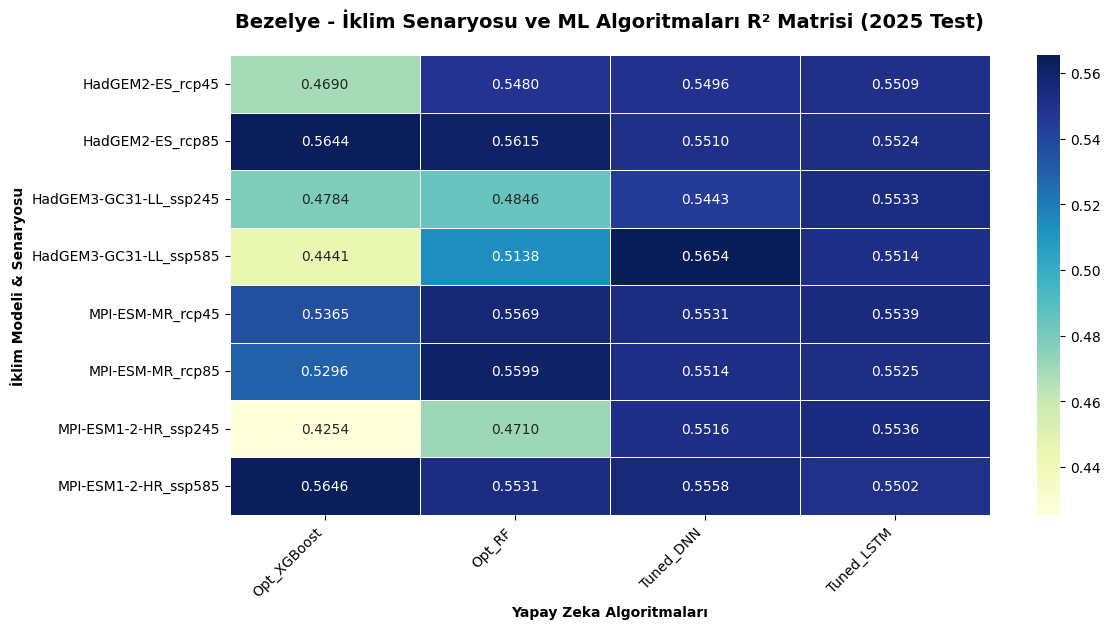

🚀 EĞİTİLİYOR: DOMATES
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.644, RF: 0.671, DNN: 0.719, LSTM: 0.721)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.698, RF: 0.691, DNN: 0.722, LSTM: 0.720)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.697, RF: 0.727, DNN: 0.723, LSTM: 0.722)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.548, RF: 0.547, DNN: 0.723, LSTM: 0.723)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.673, RF: 0.688, DNN: 0.723, LSTM: 0.722)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.728, RF: 0.748, DNN: 0.723, LSTM: 0.723)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.680, RF: 0.697, DNN: 0.720, LSTM: 0.723)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.717, RF: 0.739, DNN: 0.726, LSTM: 0.723)

📊 DOMATES için Isı Haritası Drive'a kaydedildi: domates_Model_Performans_Heatmap.png


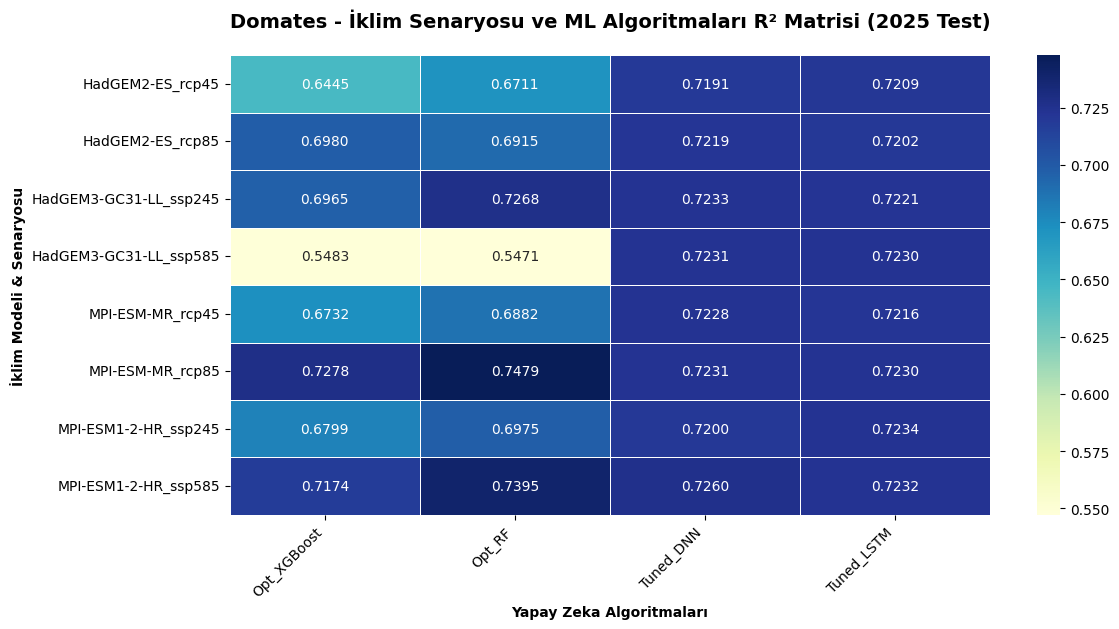

🚀 EĞİTİLİYOR: FINDIK
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.816, RF: -0.598, DNN: -0.741, LSTM: -0.714)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: -0.856, RF: -0.893, DNN: -0.618, LSTM: -0.698)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: -0.907, RF: -1.155, DNN: -1.186, LSTM: -0.703)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -0.866, RF: -0.805, DNN: -0.974, LSTM: -0.538)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: -0.892, RF: -0.846, DNN: -0.764, LSTM: -0.649)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -0.770, RF: -0.871, DNN: -0.709, LSTM: -0.849)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -0.482, RF: -0.442, DNN: -0.597, LSTM: -0.473)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: -0.727, RF: -0.614, DNN: -0.378, LSTM: -0.619)

📊 FINDIK için Isı Haritası Drive'a kaydedildi: findik_Model_Performans_Heatmap.png


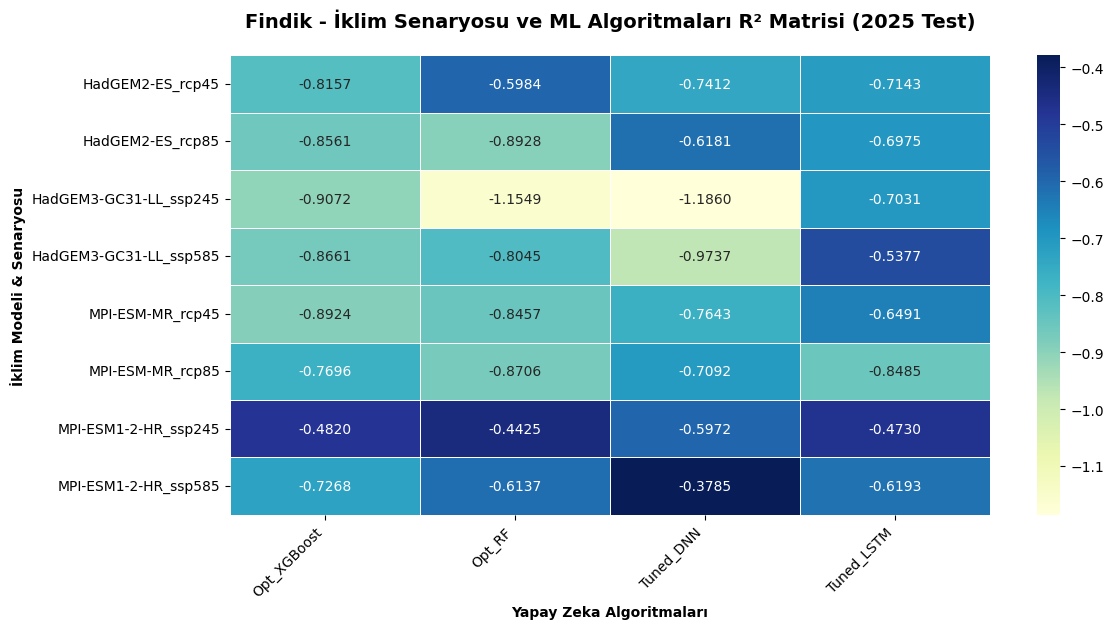

🚀 EĞİTİLİYOR: INCIR
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.964, RF: 0.631, DNN: -1.285, LSTM: -1.270)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.958, RF: 0.939, DNN: 0.932, LSTM: -1.269)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.941, RF: 0.211, DNN: -1.256, LSTM: -1.277)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -35.958, RF: -6.260, DNN: -1.274, LSTM: -1.272)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: -42.245, RF: -10.081, DNN: -1.303, LSTM: -1.311)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -35.883, RF: -0.105, DNN: -1.265, LSTM: -1.289)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -35.660, RF: -8.902, DNN: -1.274, LSTM: -1.273)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.943, RF: -7.739, DNN: -1.259, LSTM: -1.273)

📊 INCIR için Isı Haritası Drive'a kaydedildi: incir_Model_Performans_Heatmap.png


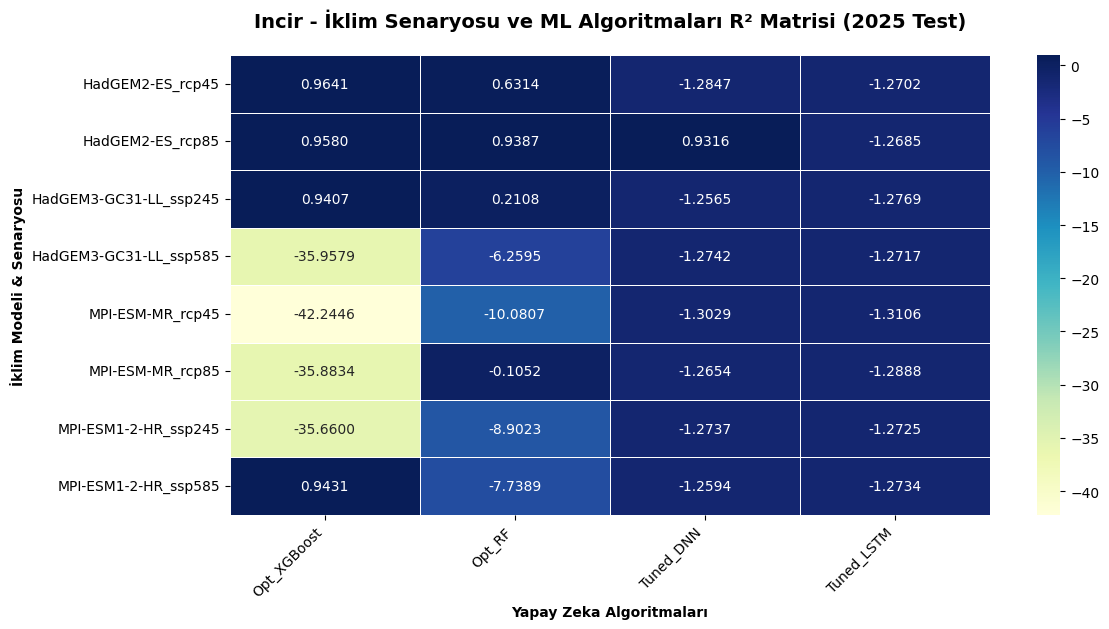

🚀 EĞİTİLİYOR: KAYISI
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.871, RF: 0.987, DNN: 0.982, LSTM: 0.982)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.988, RF: 0.928, DNN: 0.968, LSTM: 0.968)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.445, RF: 0.932, DNN: 0.991, LSTM: 0.991)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.825, RF: 0.897, DNN: 0.991, LSTM: 0.991)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.745, RF: 0.751, DNN: 0.749, LSTM: 0.749)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.755, RF: 0.837, DNN: 0.990, LSTM: 0.990)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -80.178, RF: -68.603, DNN: 0.466, LSTM: 0.463)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.761, RF: 0.770, DNN: 0.818, LSTM: 0.818)

📊 KAYISI için Isı Haritası Drive'a kaydedildi: kayisi_Model_Performans_Heatmap.png


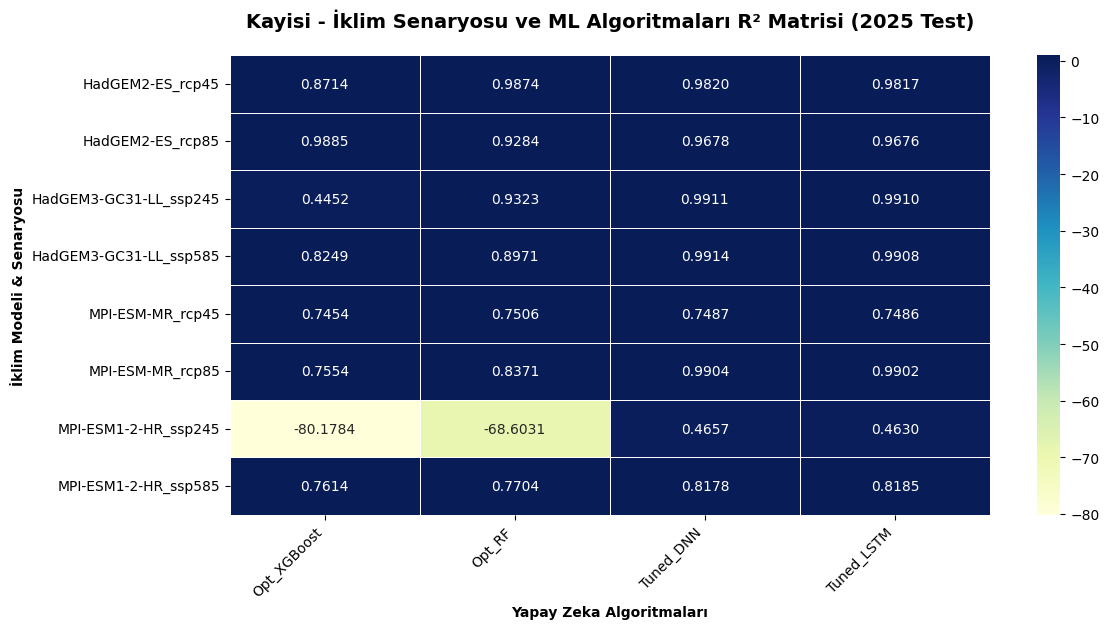

🚀 EĞİTİLİYOR: LIMON
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.698, RF: 0.613, DNN: 0.415, LSTM: 0.413)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.605, RF: 0.497, DNN: 0.413, LSTM: 0.413)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.102, RF: -0.033, DNN: 0.413, LSTM: 0.413)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -5.145, RF: -0.492, DNN: 0.415, LSTM: 0.413)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.739, RF: 0.345, DNN: 0.413, LSTM: 0.413)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -0.366, RF: 0.242, DNN: 0.413, LSTM: 0.414)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -12.310, RF: -1.568, DNN: 0.411, LSTM: 0.414)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.445, RF: 0.333, DNN: 0.413, LSTM: 0.414)

📊 LIMON için Isı Haritası Drive'a kaydedildi: limon_Model_Performans_Heatmap.png


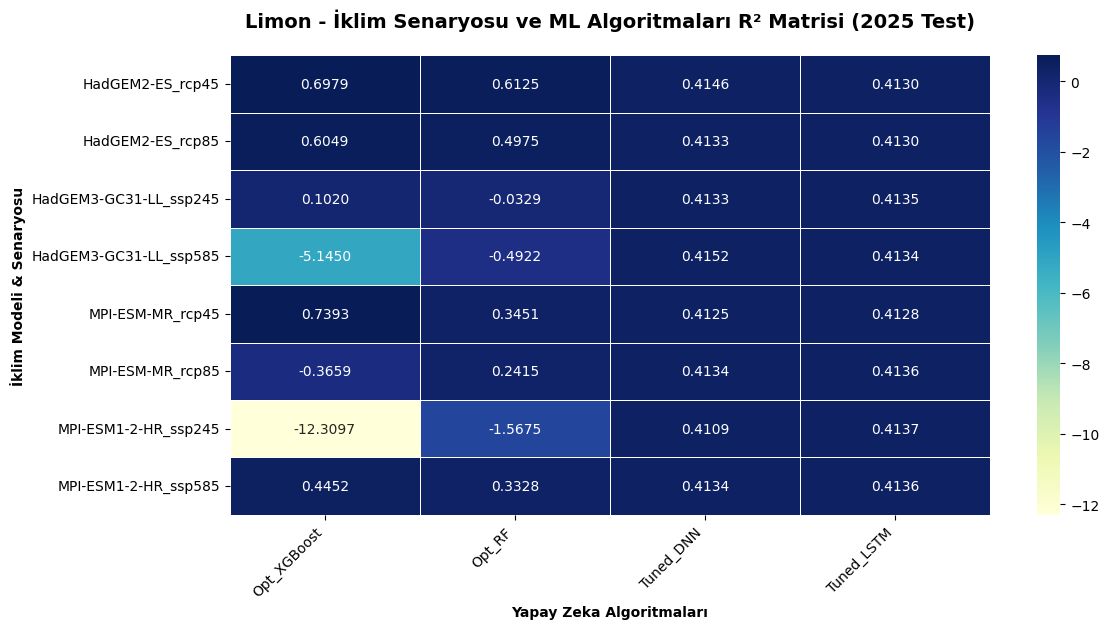

🚀 EĞİTİLİYOR: PAMUK
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.031, RF: 0.001, DNN: -0.090, LSTM: 0.054)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: -0.004, RF: -0.059, DNN: 0.146, LSTM: 0.140)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: -0.206, RF: -0.177, DNN: -0.250, LSTM: 0.068)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -0.161, RF: -0.143, DNN: -0.033, LSTM: 0.062)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.089, RF: 0.261, DNN: 0.210, LSTM: 0.247)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.278, RF: 0.359, DNN: 0.260, LSTM: 0.262)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.174, RF: 0.166, DNN: 0.069, LSTM: 0.074)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: -0.130, RF: -0.016, DNN: 0.086, LSTM: 0.101)

📊 PAMUK için Isı Haritası Drive'a kaydedildi: pamuk_Model_Performans_Heatmap.png


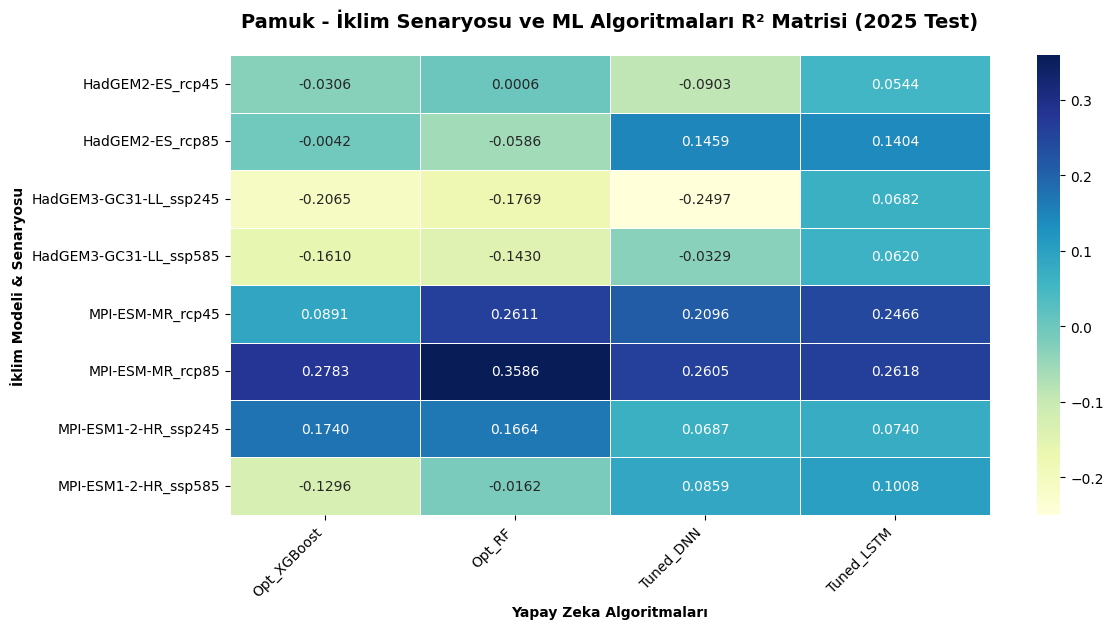

🚀 EĞİTİLİYOR: SOGAN
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.703, RF: 0.685, DNN: 0.700, LSTM: 0.697)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.682, RF: 0.669, DNN: 0.698, LSTM: 0.698)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.685, RF: 0.683, DNN: 0.696, LSTM: 0.697)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.605, RF: 0.611, DNN: 0.695, LSTM: 0.698)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.699, RF: 0.715, DNN: 0.698, LSTM: 0.697)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.693, RF: 0.673, DNN: 0.696, LSTM: 0.698)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.616, RF: 0.689, DNN: 0.696, LSTM: 0.697)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.631, RF: 0.669, DNN: 0.694, LSTM: 0.698)

📊 SOGAN için Isı Haritası Drive'a kaydedildi: sogan_Model_Performans_Heatmap.png


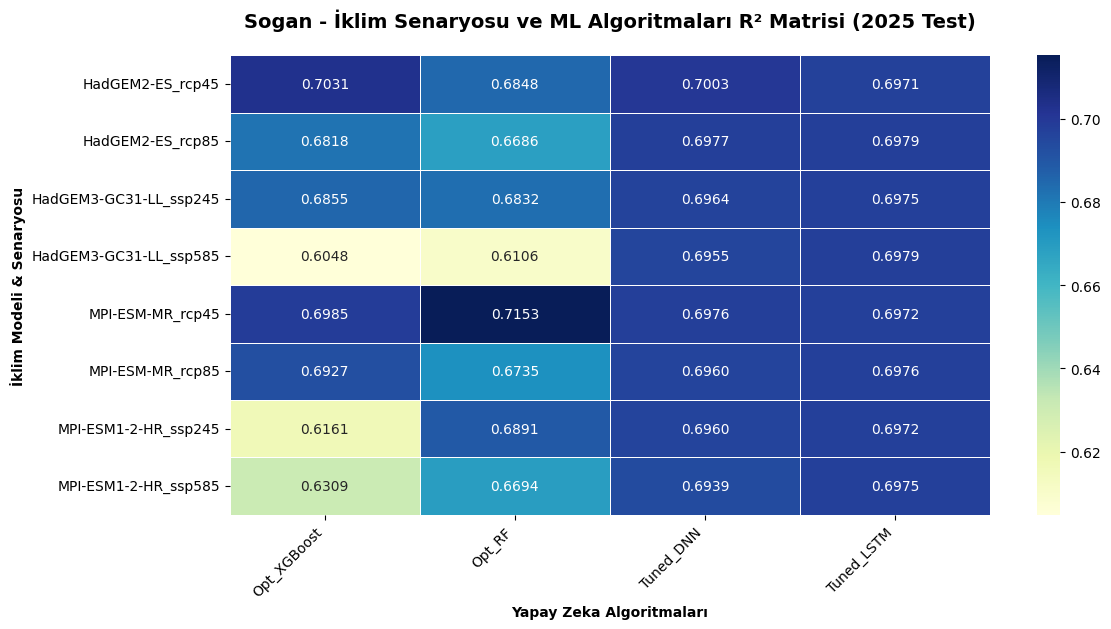

🚀 EĞİTİLİYOR: SUNFLOWER
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.418, RF: 0.428, DNN: 0.210, LSTM: 0.133)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.203, RF: 0.189, DNN: 0.181, LSTM: 0.150)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.302, RF: 0.280, DNN: 0.145, LSTM: 0.109)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.220, RF: 0.090, DNN: 0.083, LSTM: 0.108)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.421, RF: 0.410, DNN: 0.273, LSTM: 0.127)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.102, RF: 0.070, DNN: 0.162, LSTM: 0.071)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.160, RF: 0.211, DNN: 0.126, LSTM: 0.110)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.292, RF: 0.290, DNN: 0.151, LSTM: 0.154)

📊 SUNFLOWER için Isı Haritası Drive'a kaydedildi: sunflower_Model_Performans_Heatmap.png


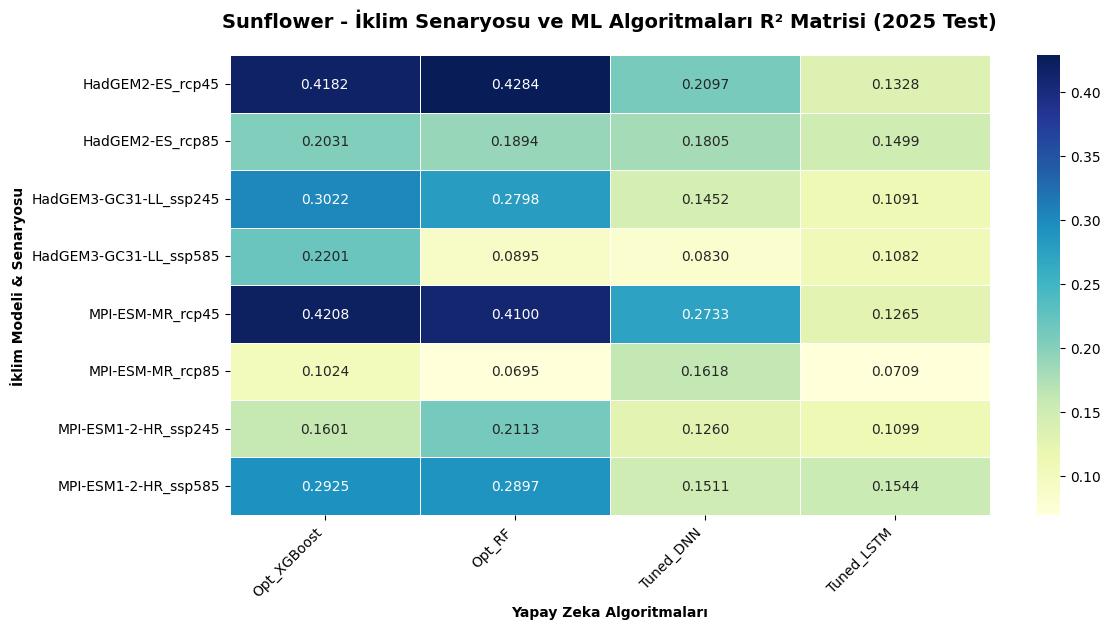

🚀 EĞİTİLİYOR: ZEYTINSOFR
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.612, RF: 0.618, DNN: 0.766, LSTM: 0.756)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.708, RF: 0.728, DNN: 0.765, LSTM: 0.752)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.646, RF: 0.601, DNN: 0.757, LSTM: 0.747)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.466, RF: 0.534, DNN: 0.767, LSTM: 0.757)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.749, RF: 0.584, DNN: 0.767, LSTM: 0.751)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.712, RF: 0.691, DNN: 0.760, LSTM: 0.757)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.287, RF: 0.652, DNN: 0.768, LSTM: 0.745)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.252, RF: 0.514, DNN: 0.769, LSTM: 0.753)

📊 ZEYTINSOFR için Isı Haritası Drive'a kaydedildi: zeytinsofr_Model_Performans_Heatmap.png


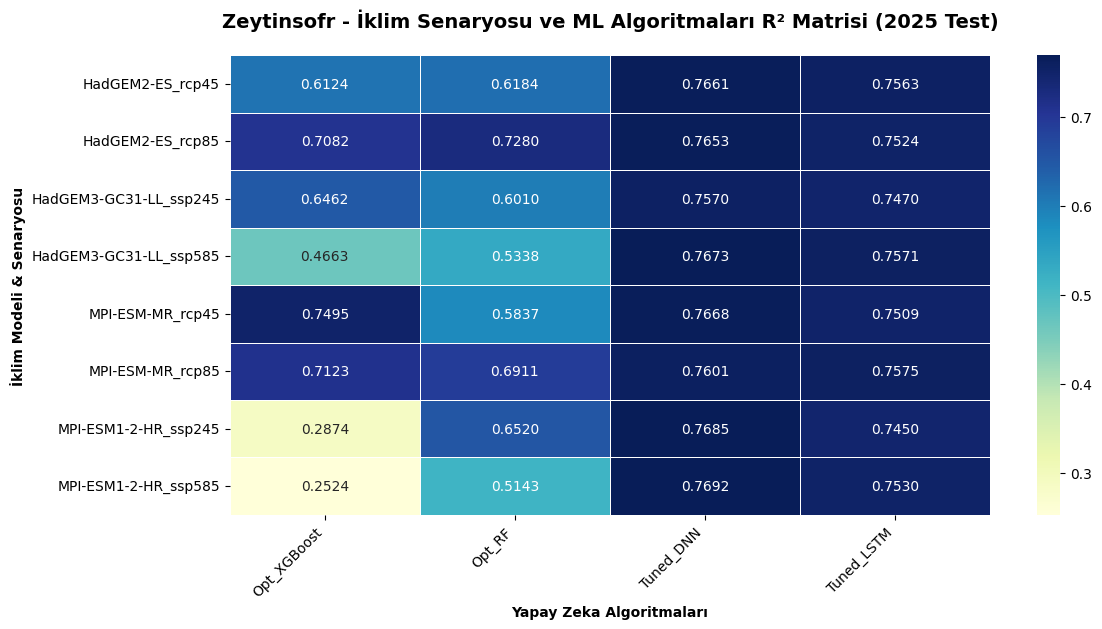

🚀 EĞİTİLİYOR: ZEYTINYAG
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.210, RF: -0.099, DNN: 0.591, LSTM: 0.630)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.497, RF: 0.536, DNN: 0.604, LSTM: 0.627)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.416, RF: 0.557, DNN: 0.506, LSTM: 0.564)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.388, RF: 0.464, DNN: 0.613, LSTM: 0.631)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.394, RF: 0.553, DNN: 0.586, LSTM: 0.624)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.502, RF: 0.482, DNN: 0.616, LSTM: 0.649)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -0.027, RF: -0.025, DNN: 0.552, LSTM: 0.625)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.652, RF: 0.705, DNN: 0.618, LSTM: 0.630)

📊 ZEYTINYAG için Isı Haritası Drive'a kaydedildi: zeytinyag_Model_Performans_Heatmap.png


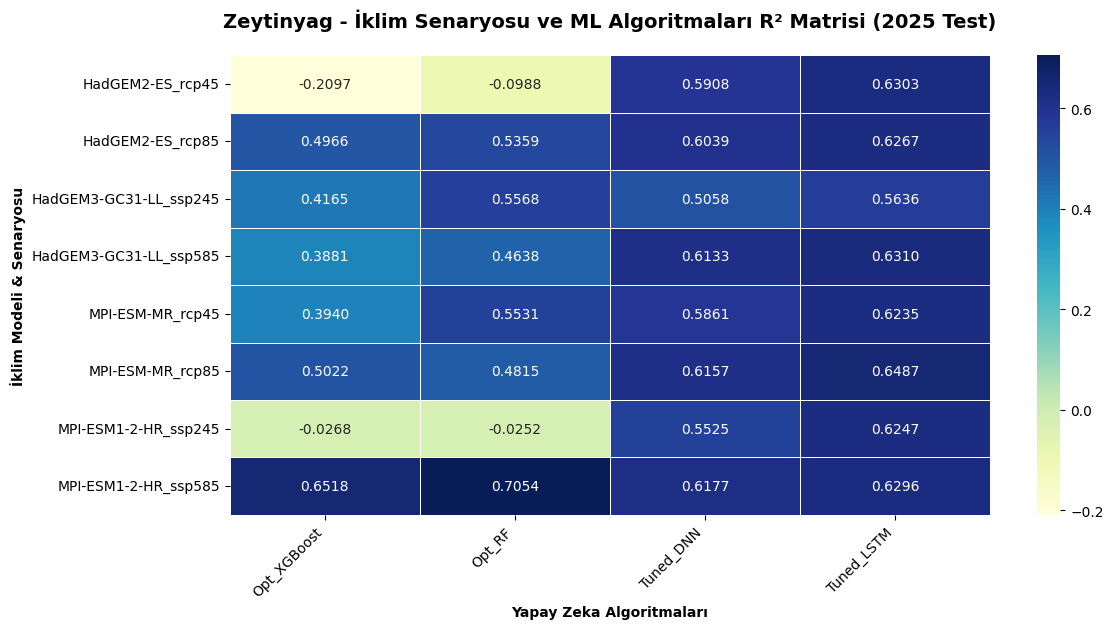


🎉 BÜTÜN ÜRÜNLER İÇİN SEÇİCİ NORMALİZASYONLU EĞİTİM VE TEST SÜRECİ TAMAMLANDI!


In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# ==========================================
# 1. YOLLAR VE AYARLAR
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']

print(f"🌟 TOPLAM {len(tum_klasorler)} ÜRÜN İÇİN YAPAY ZEKA (ML/DL) EĞİTİMİ BAŞLIYOR...\n")

for urun in tum_klasorler:
    urun_yolu = os.path.join(verim_dir, urun)
    v4_dosyalari = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    if not v4_dosyalari:
        continue

    print(f"{'='*70}\n🚀 EĞİTİLİYOR: {urun.upper()}\n{'='*70}")
    urun_sonuclari = []

    for v4_dosya in v4_dosyalari:
        match = re.search(r"_(.+?)_ML_egitim_seti_V4", os.path.basename(v4_dosya))
        if not match: continue
        senaryo = match.group(1)

        print(f"   -> Senaryo: {senaryo}")

        try:
            df = pd.read_excel(v4_dosya)

            # ----------------------------------------------------
            # A. VERİ HAZIRLIĞI VE ÖN İŞLEME
            # ----------------------------------------------------

            # 1. Toprak Tipini Kategorik Hale Getirme (One-Hot Encoding)
            # Eğer 'Toprak_Tipi' veya benzer isimli bir sütun varsa tespit et
            toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
            if toprak_sutunu:
                # Toprak tiplerini 0 ve 1'lerden oluşan dummy (kukla) değişkenlere çevirir (Ordinal yanılgıyı önler)
                df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

            # Eksik (NaN) sayısal verileri 0 ile doldur
            numeric_cols_all = df.select_dtypes(include=[np.number]).columns
            df[numeric_cols_all] = df[numeric_cols_all].fillna(0)

            # Bağımsız Değişkenleri (X) Seçme
            hedef_ve_kimlik_sutunlari = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
            X_cols = [c for c in df.columns if c not in hedef_ve_kimlik_sutunlari and pd.api.types.is_numeric_dtype(df[c])]

            # ----------------------------------------------------
            # B. SEÇİCİ NORMALİZASYON (SELECTIVE SCALING) STRATEJİSİ
            # ----------------------------------------------------
            # Kompozisyonel (%100'e tamamlayan) Eğim, Bakı ve One-Hot Toprak sütunlarını normalizasyondan koru
            korunacak_sutunlar = [c for c in X_cols if 'baki' in c.lower() or 'egim' in c.lower() or 'toprak' in c.lower()]
            # Rakım, Yağış, ETc vb. mutlak büyüklük ifade eden değişkenleri normalize edilecekler listesine al
            normalize_edilecek_sutunlar = [c for c in X_cols if c not in korunacak_sutunlar]

            # 2021-2024 EĞİTİM (Train), 2025 TEST (Görülmemiş Veri) Olarak Bölme
            train_df = df[df['Yil'] <= 2024].copy()
            test_df = df[df['Yil'] == 2025].copy()

            if len(train_df) == 0 or len(test_df) == 0:
                print(f"      ⚠️ ATLANDI: Yeterli Eğitim/Test verisi yok.")
                continue

            X_train = train_df[X_cols].copy()
            X_test = test_df[X_cols].copy()

            # Normalizasyon Sadece Seçilen Sütunlara (Rakım, Yağış vb.) ve Eğitim Setine Göre (Sızıntıyı Önleyerek) Yapılır
            if normalize_edilecek_sutunlar:
                scaler = MinMaxScaler()
                X_train[normalize_edilecek_sutunlar] = scaler.fit_transform(X_train[normalize_edilecek_sutunlar])
                X_test[normalize_edilecek_sutunlar] = scaler.transform(X_test[normalize_edilecek_sutunlar])

            y_train = train_df['Verim_Farki']
            y_test_gercek = test_df['Verim_ton_ha']
            tarihsel_baz_test = test_df['Tarihsel_Ortalama_Verim'].values

            # LSTM için veriyi 3 Boyutlu Hale Getirme (Örnek Sayısı, Zaman Adımı, Özellik Sayısı)
            X_train_lstm = np.reshape(X_train.values, (X_train.shape[0], 1, X_train.shape[1]))
            X_test_lstm = np.reshape(X_test.values, (X_test.shape[0], 1, X_test.shape[1]))

            # ----------------------------------------------------
            # C. MAKİNE ÖĞRENMESİ: ÇOKLU PARAMETRE TARAMASI (GridSearch)
            # ----------------------------------------------------
            # 1. XGBoost
            xgb_param_grid = {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [100, 200]}
            xgb_grid = GridSearchCV(xgb.XGBRegressor(random_state=42, objective='reg:squarederror'), xgb_param_grid, cv=3, scoring='r2', verbose=0)
            xgb_grid.fit(X_train, y_train)
            r2_xgb = r2_score(y_test_gercek, xgb_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            # 2. Random Forest
            rf_param_grid = {'max_depth': [4, 6, None], 'n_estimators': [100, 200]}
            rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=3, scoring='r2', verbose=0)
            rf_grid.fit(X_train, y_train)
            r2_rf = r2_score(y_test_gercek, rf_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            # ----------------------------------------------------
            # D. DERİN ÖĞRENME: SEYRELTME (Dropout) & ERKEN DURDURMA
            # ----------------------------------------------------
            erken_durdurma = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

            # 3. Derin Sinir Ağı (DNN)
            dnn_model = Sequential([
                Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dropout(0.2),
                Dense(1, activation='linear')
            ])
            dnn_model.compile(optimizer='adam', loss='mse')
            dnn_model.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_dnn = r2_score(y_test_gercek, dnn_model.predict(X_test, verbose=0).flatten() + tarihsel_baz_test)

            # 4. Zaman Serisi Ağı (LSTM)
            lstm_model = Sequential([
                LSTM(64, activation='relu', return_sequences=False, input_shape=(1, X_train.shape[1])),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dense(1, activation='linear')
            ])
            lstm_model.compile(optimizer='adam', loss='mse')
            lstm_model.fit(X_train_lstm, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_lstm = r2_score(y_test_gercek, lstm_model.predict(X_test_lstm, verbose=0).flatten() + tarihsel_baz_test)

            # ----------------------------------------------------
            # E. SONUÇLARIN KAYIT ALTINA ALINMASI
            # ----------------------------------------------------
            urun_sonuclari.append({
                'Senaryo': senaryo,
                'Opt_XGBoost': r2_xgb,
                'Opt_RF': r2_rf,
                'Tuned_DNN': r2_dnn,
                'Tuned_LSTM': r2_lstm
            })

            print(f"      ✅ Bitti! (XGB: {r2_xgb:.3f}, RF: {r2_rf:.3f}, DNN: {r2_dnn:.3f}, LSTM: {r2_lstm:.3f})")

        except Exception as e:
            print(f"      ❌ HATA: Modeller eğitilemedi -> {e}")

    # ----------------------------------------------------
    # F. ÜRÜN BAZLI SICAKLIK HARİTASI (HEATMAP)
    # ----------------------------------------------------
    if urun_sonuclari:
        df_sonuc = pd.DataFrame(urun_sonuclari)
        df_sonuc.set_index('Senaryo', inplace=True)

        df_sonuc.to_excel(os.path.join(urun_yolu, f"{urun.lower()}_ML_Model_R2_Sonuclari.xlsx"))

        plt.figure(figsize=(12, max(6, len(df_sonuc) * 0.8)))
        sns.heatmap(df_sonuc, annot=True, cmap='YlGnBu', fmt='.4f', linewidths=.5)
        plt.title(f"{urun.capitalize()} - İklim Senaryosu ve ML Algoritmaları R² Matrisi (2025 Test)", fontsize=14, fontweight='bold', pad=20)
        plt.ylabel("İklim Modeli & Senaryosu", fontweight='bold')
        plt.xlabel("Yapay Zeka Algoritmaları", fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()

        heatmap_yolu = os.path.join(urun_yolu, f"{urun.lower()}_Model_Performans_Heatmap.png")
        plt.savefig(heatmap_yolu, dpi=300, bbox_inches='tight')

        print(f"\n📊 {urun.upper()} için Isı Haritası Drive'a kaydedildi: {os.path.basename(heatmap_yolu)}")
        plt.show()
        plt.close()

print("\n🎉 BÜTÜN ÜRÜNLER İÇİN SEÇİCİ NORMALİZASYONLU EĞİTİM VE TEST SÜRECİ TAMAMLANDI!")

🌟 TOPLAM 12 ÜRÜN İÇİN YAPAY ZEKA (ML/DL) EĞİTİMİ BAŞLIYOR...

🚀 EĞİTİLİYOR: BEZELYE
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.469, RF: 0.548, DNN: 0.553, LSTM: 0.553)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.564, RF: 0.562, DNN: 0.555, LSTM: 0.555)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.478, RF: 0.485, DNN: 0.561, LSTM: 0.554)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.444, RF: 0.514, DNN: 0.544, LSTM: 0.552)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.537, RF: 0.557, DNN: 0.557, LSTM: 0.554)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.530, RF: 0.560, DNN: 0.543, LSTM: 0.551)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.425, RF: 0.471, DNN: 0.547, LSTM: 0.552)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.565, RF: 0.553, DNN: 0.547, LSTM: 0.551)

📊 BEZELYE için Isı Haritası Drive'a kaydedildi: bezelye_Model_Performans_Heatmap.png


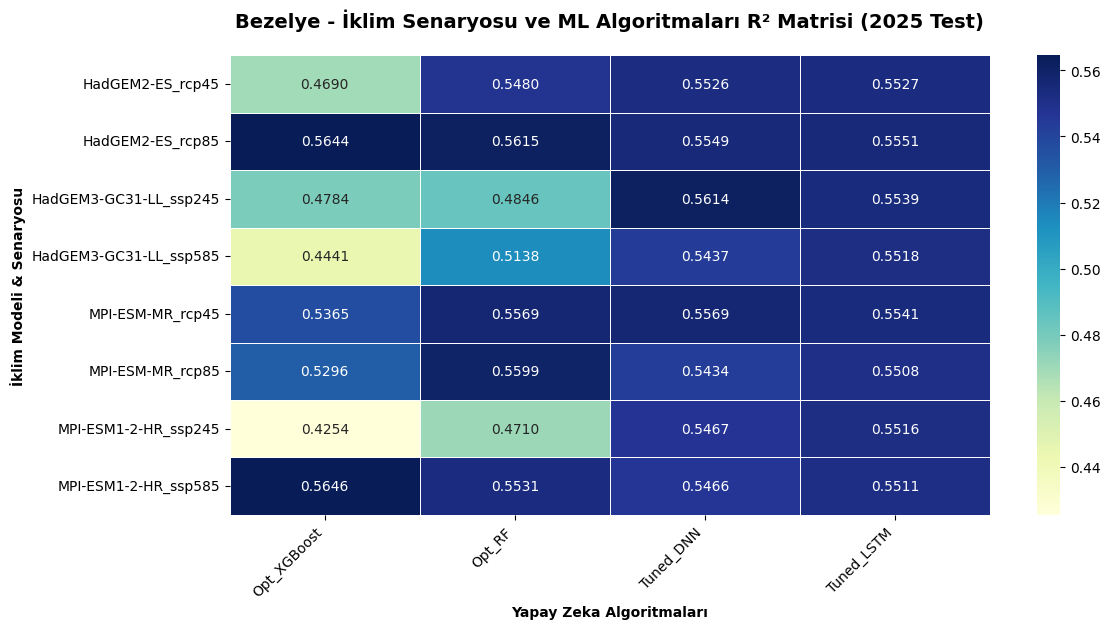

🚀 EĞİTİLİYOR: DOMATES
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.644, RF: 0.671, DNN: 0.718, LSTM: 0.722)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.698, RF: 0.691, DNN: 0.723, LSTM: 0.723)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.697, RF: 0.727, DNN: 0.717, LSTM: 0.722)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.548, RF: 0.547, DNN: 0.725, LSTM: 0.722)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.673, RF: 0.688, DNN: 0.723, LSTM: 0.722)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.728, RF: 0.748, DNN: 0.724, LSTM: 0.722)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.680, RF: 0.697, DNN: 0.723, LSTM: 0.722)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.717, RF: 0.739, DNN: 0.723, LSTM: 0.723)

📊 DOMATES için Isı Haritası Drive'a kaydedildi: domates_Model_Performans_Heatmap.png


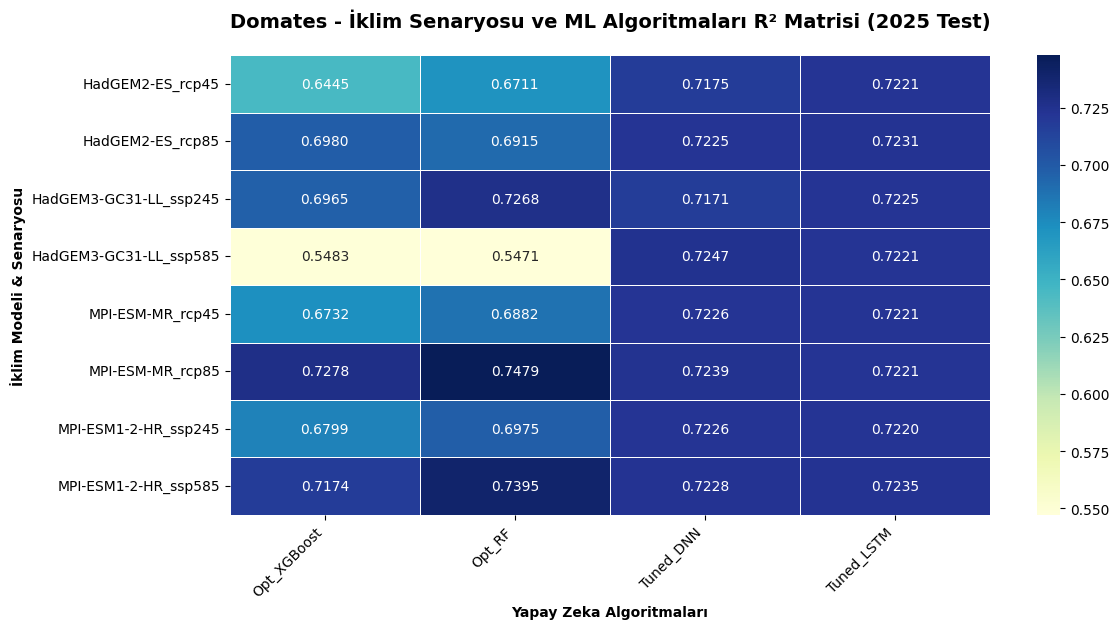

🚀 EĞİTİLİYOR: FINDIK
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.816, RF: -0.598, DNN: -0.774, LSTM: -0.552)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: -0.856, RF: -0.893, DNN: -0.739, LSTM: -0.584)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: -0.907, RF: -1.155, DNN: -0.686, LSTM: -0.709)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -0.866, RF: -0.805, DNN: -0.720, LSTM: -0.798)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: -0.892, RF: -0.846, DNN: -0.753, LSTM: -0.676)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -0.770, RF: -0.871, DNN: -0.942, LSTM: -0.866)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -0.482, RF: -0.442, DNN: -0.619, LSTM: -0.546)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: -0.727, RF: -0.614, DNN: -0.754, LSTM: -0.665)

📊 FINDIK için Isı Haritası Drive'a kaydedildi: findik_Model_Performans_Heatmap.png


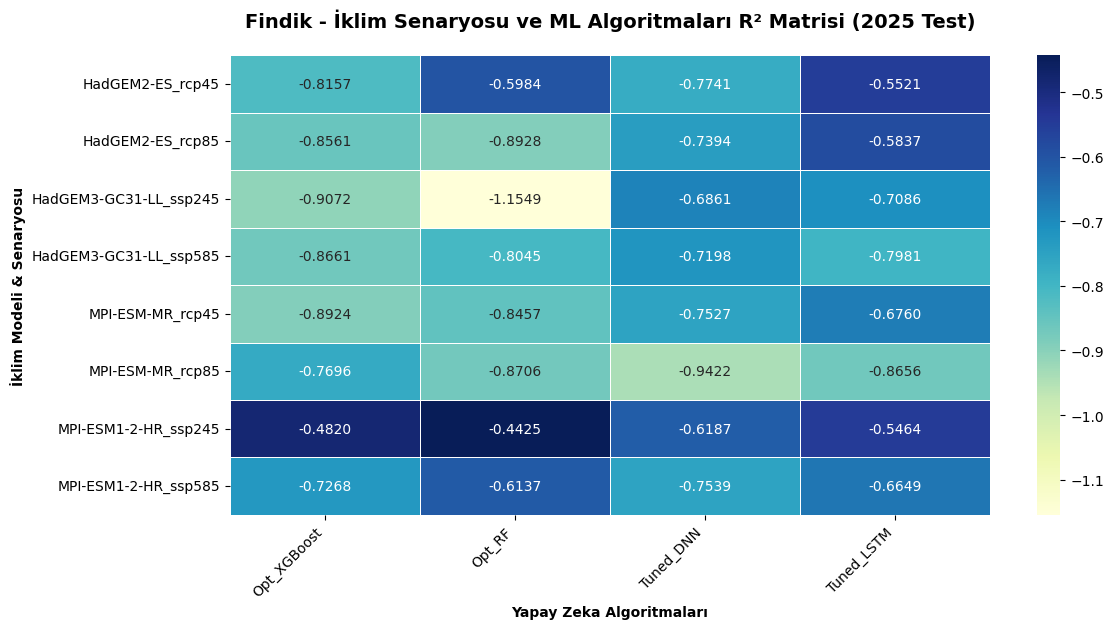

🚀 EĞİTİLİYOR: INCIR
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.964, RF: 0.631, DNN: -1.270, LSTM: -1.269)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.958, RF: 0.939, DNN: 0.866, LSTM: -1.276)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.941, RF: 0.211, DNN: -1.283, LSTM: -1.274)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -35.958, RF: -6.260, DNN: -1.282, LSTM: -1.268)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: -42.245, RF: -10.081, DNN: -1.301, LSTM: -1.308)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -35.883, RF: -0.105, DNN: -1.266, LSTM: -1.279)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -35.660, RF: -8.902, DNN: -1.285, LSTM: -1.268)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.943, RF: -7.739, DNN: -3.050, LSTM: -1.273)

📊 INCIR için Isı Haritası Drive'a kaydedildi: incir_Model_Performans_Heatmap.png


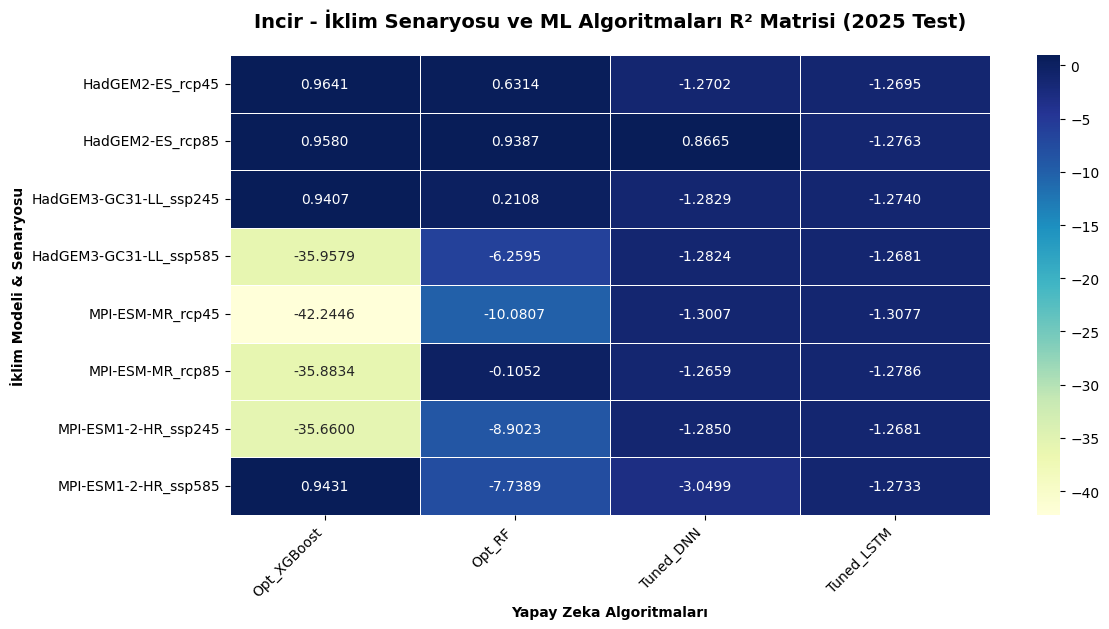

🚀 EĞİTİLİYOR: KAYISI
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.871, RF: 0.987, DNN: 0.983, LSTM: 0.982)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.988, RF: 0.928, DNN: 0.968, LSTM: 0.967)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.445, RF: 0.932, DNN: 0.991, LSTM: 0.991)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.825, RF: 0.897, DNN: 0.991, LSTM: 0.991)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.745, RF: 0.751, DNN: 0.748, LSTM: 0.748)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.755, RF: 0.837, DNN: 0.990, LSTM: 0.990)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -80.178, RF: -68.603, DNN: 0.520, LSTM: 0.467)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.761, RF: 0.770, DNN: 0.818, LSTM: 0.818)

📊 KAYISI için Isı Haritası Drive'a kaydedildi: kayisi_Model_Performans_Heatmap.png


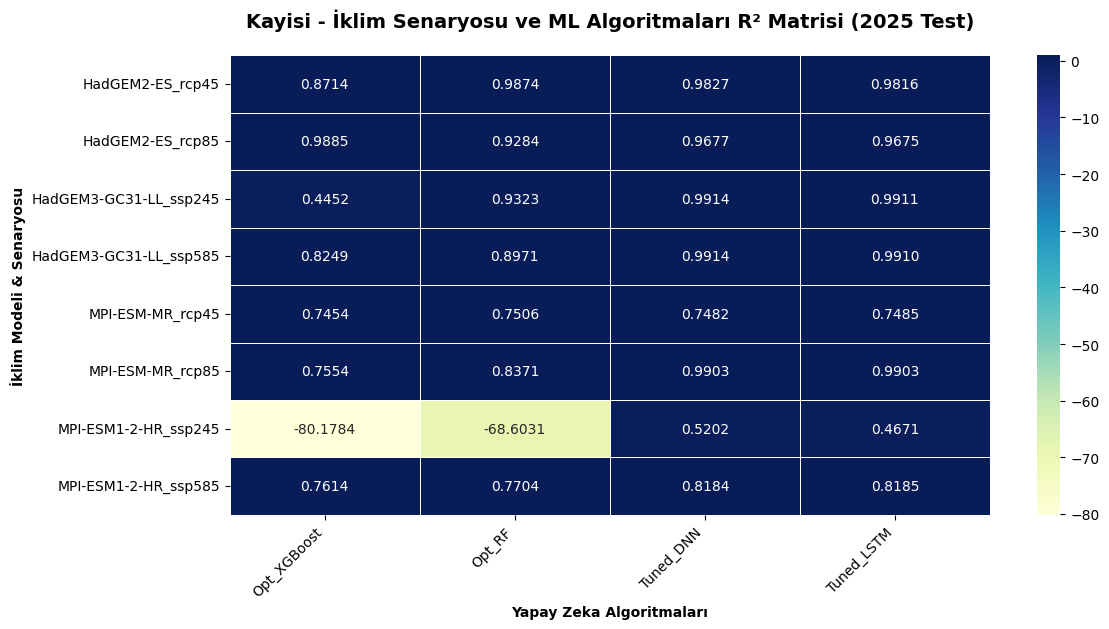

🚀 EĞİTİLİYOR: LIMON
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.698, RF: 0.613, DNN: 0.413, LSTM: 0.414)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.605, RF: 0.497, DNN: 0.414, LSTM: 0.413)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.102, RF: -0.033, DNN: 0.413, LSTM: 0.413)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -5.145, RF: -0.492, DNN: 0.414, LSTM: 0.413)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.739, RF: 0.345, DNN: 0.413, LSTM: 0.414)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: -0.366, RF: 0.242, DNN: 0.414, LSTM: 0.414)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -12.310, RF: -1.568, DNN: 0.416, LSTM: 0.414)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.445, RF: 0.333, DNN: 0.410, LSTM: 0.414)

📊 LIMON için Isı Haritası Drive'a kaydedildi: limon_Model_Performans_Heatmap.png


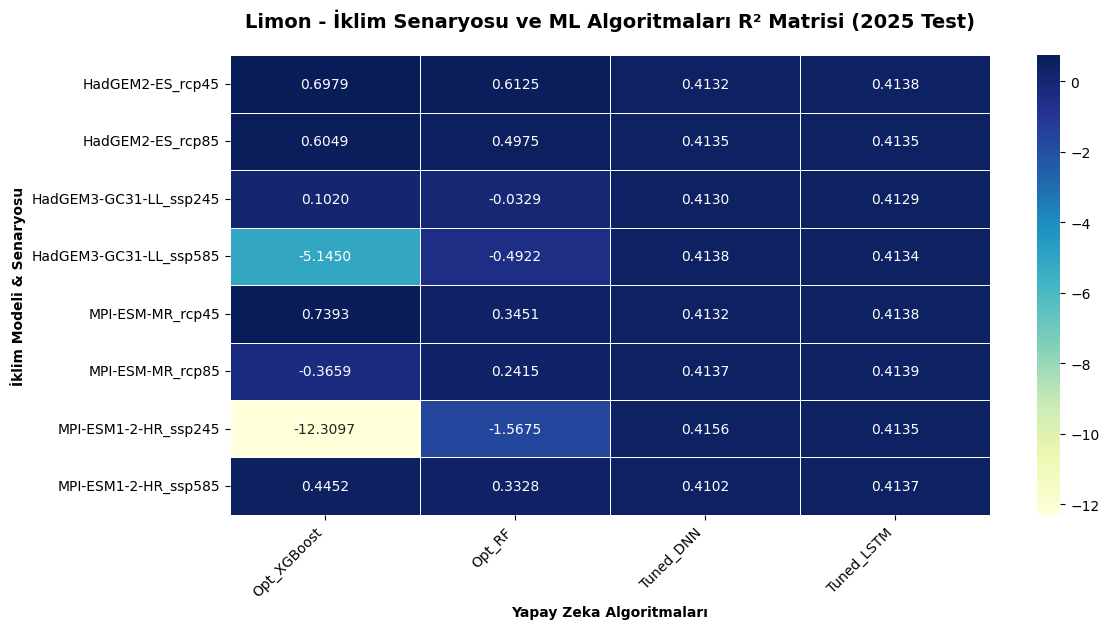

🚀 EĞİTİLİYOR: PAMUK
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.031, RF: 0.001, DNN: -0.026, LSTM: 0.051)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: -0.004, RF: -0.059, DNN: 0.174, LSTM: 0.148)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: -0.206, RF: -0.177, DNN: 0.157, LSTM: 0.060)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: -0.161, RF: -0.143, DNN: -0.015, LSTM: 0.068)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.089, RF: 0.261, DNN: 0.233, LSTM: 0.259)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.278, RF: 0.359, DNN: 0.263, LSTM: 0.259)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.174, RF: 0.166, DNN: 0.131, LSTM: 0.092)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: -0.130, RF: -0.016, DNN: 0.105, LSTM: 0.091)

📊 PAMUK için Isı Haritası Drive'a kaydedildi: pamuk_Model_Performans_Heatmap.png


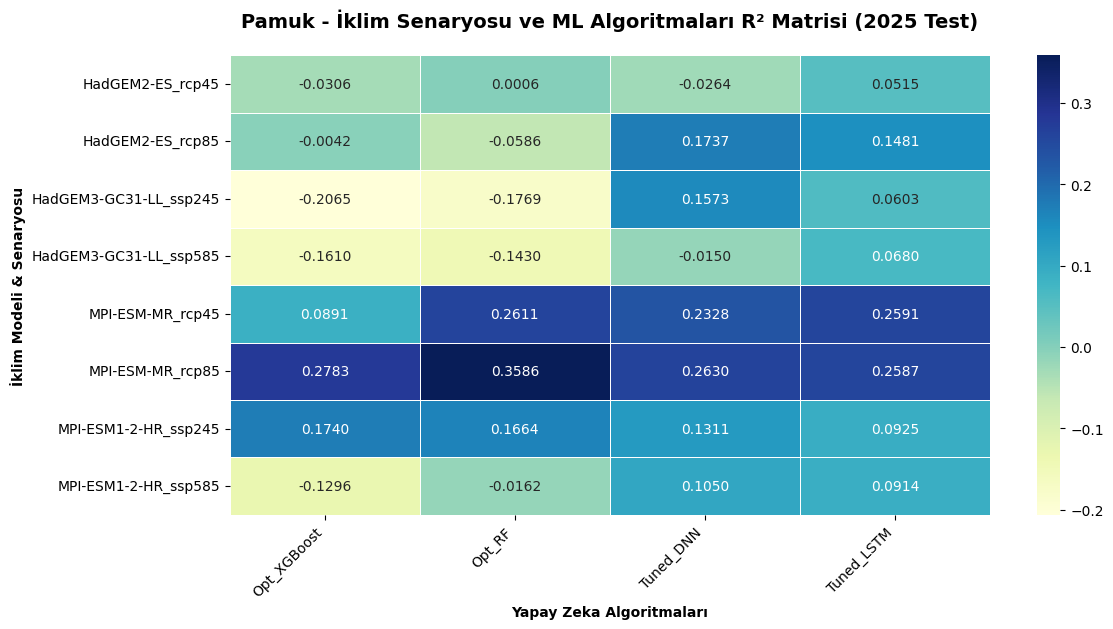

🚀 EĞİTİLİYOR: SOGAN
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.703, RF: 0.685, DNN: 0.695, LSTM: 0.698)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.682, RF: 0.669, DNN: 0.697, LSTM: 0.697)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.685, RF: 0.683, DNN: 0.699, LSTM: 0.697)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.605, RF: 0.611, DNN: 0.697, LSTM: 0.697)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.699, RF: 0.715, DNN: 0.696, LSTM: 0.698)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.693, RF: 0.673, DNN: 0.697, LSTM: 0.698)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.616, RF: 0.689, DNN: 0.698, LSTM: 0.698)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.631, RF: 0.669, DNN: 0.692, LSTM: 0.698)

📊 SOGAN için Isı Haritası Drive'a kaydedildi: sogan_Model_Performans_Heatmap.png


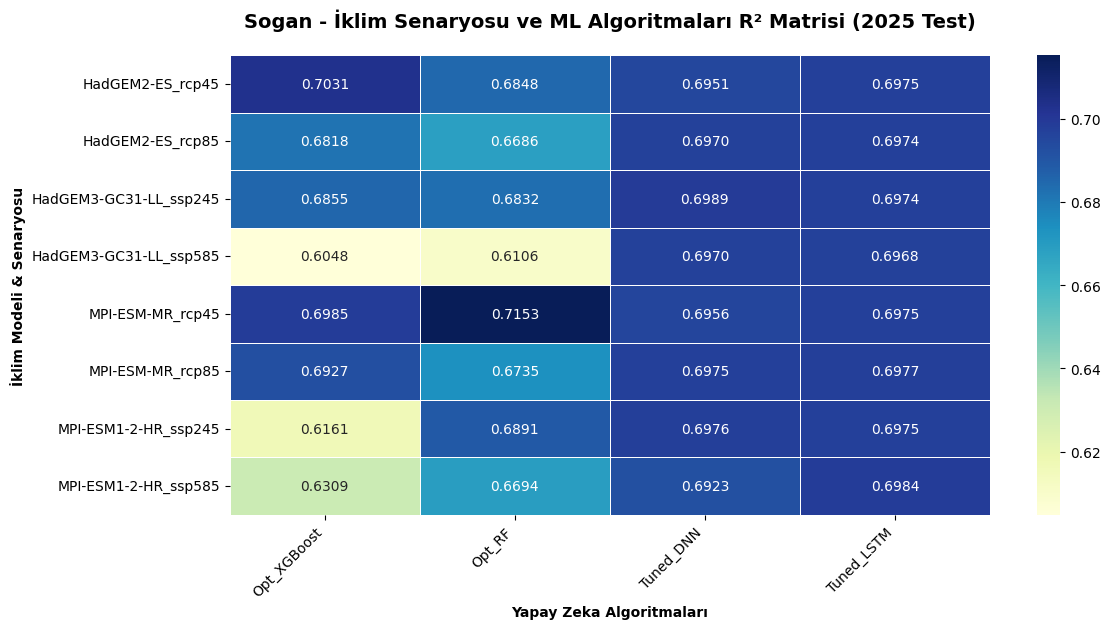

🚀 EĞİTİLİYOR: SUNFLOWER
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.418, RF: 0.428, DNN: 0.204, LSTM: 0.131)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.203, RF: 0.189, DNN: 0.161, LSTM: 0.116)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.302, RF: 0.280, DNN: 0.133, LSTM: 0.151)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.220, RF: 0.090, DNN: 0.127, LSTM: 0.063)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.421, RF: 0.410, DNN: 0.198, LSTM: 0.305)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.102, RF: 0.070, DNN: 0.203, LSTM: 0.089)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.160, RF: 0.211, DNN: 0.165, LSTM: 0.070)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.292, RF: 0.290, DNN: 0.309, LSTM: 0.099)

📊 SUNFLOWER için Isı Haritası Drive'a kaydedildi: sunflower_Model_Performans_Heatmap.png


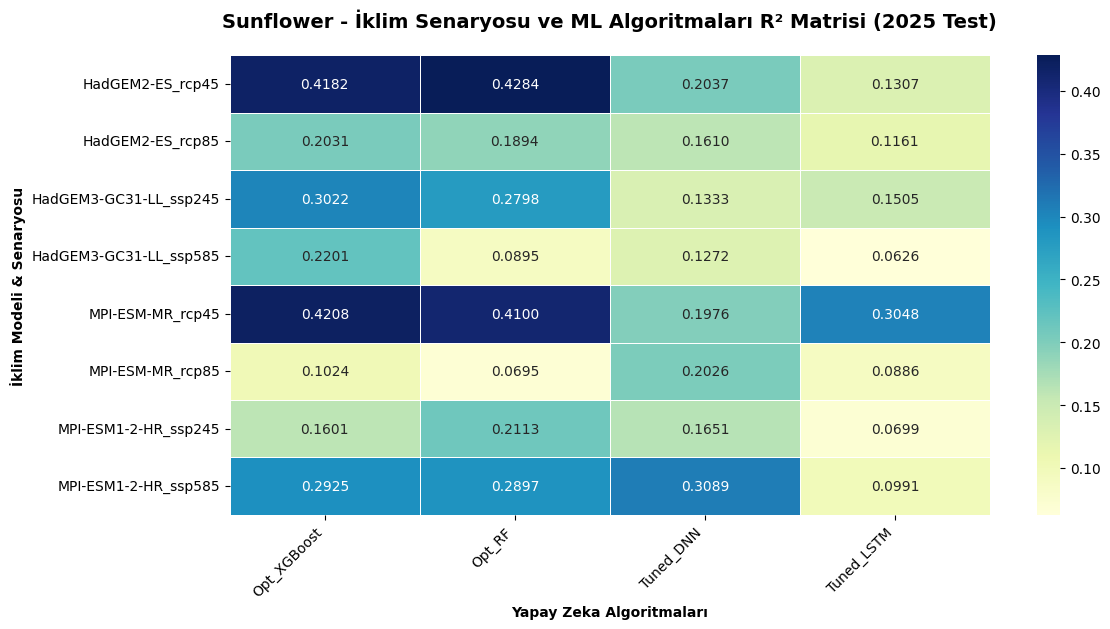

🚀 EĞİTİLİYOR: ZEYTINSOFR
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.612, RF: 0.618, DNN: 0.745, LSTM: 0.767)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.708, RF: 0.728, DNN: 0.770, LSTM: 0.755)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.646, RF: 0.601, DNN: 0.763, LSTM: 0.755)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.466, RF: 0.534, DNN: 0.763, LSTM: 0.757)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.749, RF: 0.584, DNN: 0.763, LSTM: 0.760)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.712, RF: 0.691, DNN: 0.766, LSTM: 0.754)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.287, RF: 0.652, DNN: 0.766, LSTM: 0.757)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.252, RF: 0.514, DNN: 0.765, LSTM: 0.756)

📊 ZEYTINSOFR için Isı Haritası Drive'a kaydedildi: zeytinsofr_Model_Performans_Heatmap.png


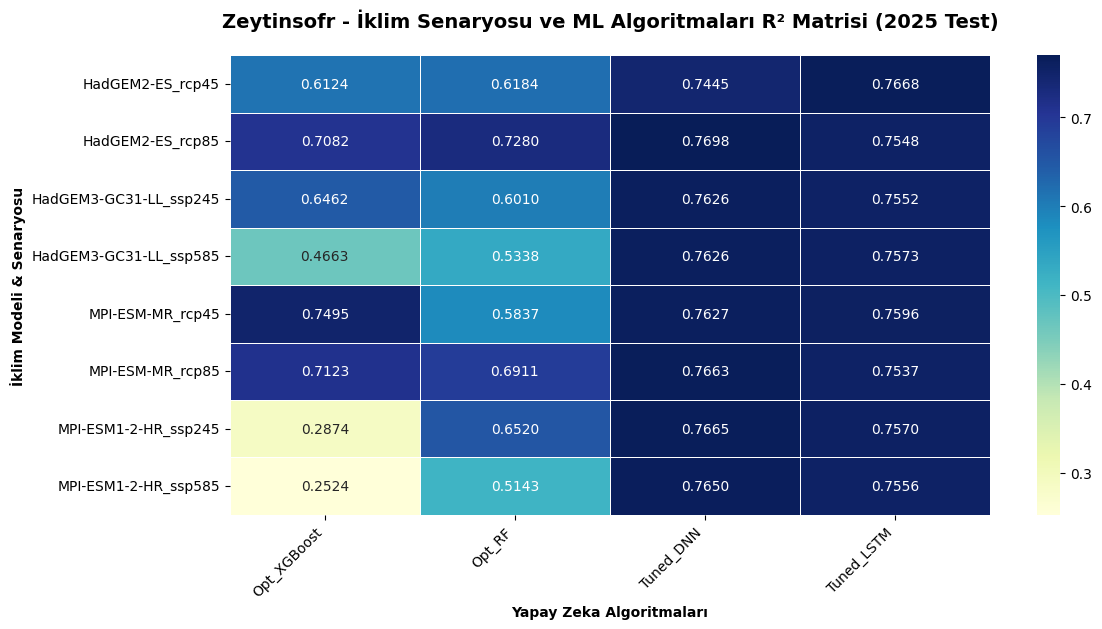

🚀 EĞİTİLİYOR: ZEYTINYAG
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: -0.210, RF: -0.099, DNN: 0.589, LSTM: 0.631)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.497, RF: 0.536, DNN: 0.617, LSTM: 0.639)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.416, RF: 0.557, DNN: 0.498, LSTM: 0.626)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.388, RF: 0.464, DNN: 0.573, LSTM: 0.628)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.394, RF: 0.553, DNN: 0.602, LSTM: 0.624)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.502, RF: 0.482, DNN: 0.602, LSTM: 0.618)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: -0.027, RF: -0.025, DNN: 0.603, LSTM: 0.632)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.652, RF: 0.705, DNN: 0.584, LSTM: 0.635)

📊 ZEYTINYAG için Isı Haritası Drive'a kaydedildi: zeytinyag_Model_Performans_Heatmap.png


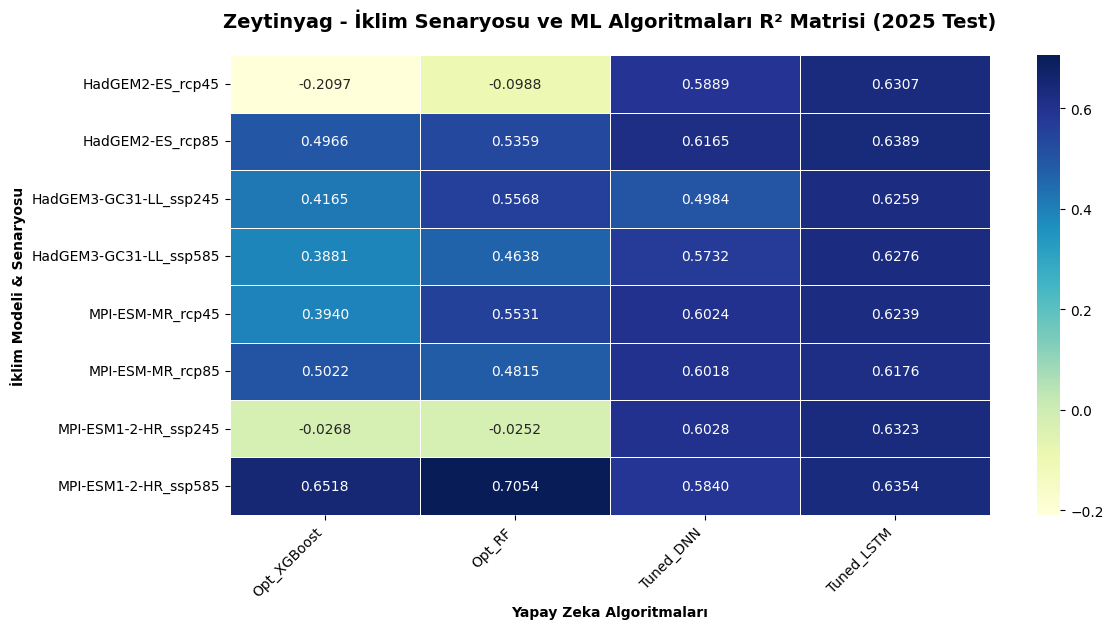


🎉 BÜTÜN ÜRÜNLER İÇİN SEÇİCİ NORMALİZASYONLU EĞİTİM VE TEST SÜRECİ TAMAMLANDI!


In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

# ==========================================
# 1. YOLLAR VE AYARLAR
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']

print(f"🌟 TOPLAM {len(tum_klasorler)} ÜRÜN İÇİN YAPAY ZEKA (ML/DL) EĞİTİMİ BAŞLIYOR...\n")

for urun in tum_klasorler:
    urun_yolu = os.path.join(verim_dir, urun)
    v4_dosyalari = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    if not v4_dosyalari:
        continue

    print(f"{'='*70}\n🚀 EĞİTİLİYOR: {urun.upper()}\n{'='*70}")
    urun_sonuclari = []

    for v4_dosya in v4_dosyalari:
        match = re.search(r"_(.+?)_ML_egitim_seti_V4", os.path.basename(v4_dosya))
        if not match: continue
        senaryo = match.group(1)

        print(f"   -> Senaryo: {senaryo}")

        try:
            df = pd.read_excel(v4_dosya)

            # ----------------------------------------------------
            # A. VERİ HAZIRLIĞI VE ÖN İŞLEME
            # ----------------------------------------------------

            # 1. Toprak Tipini Kategorik Hale Getirme (One-Hot Encoding)
            toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
            if toprak_sutunu:
                df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

            # Eksik (NaN) sayısal verileri 0 ile doldur
            numeric_cols_all = df.select_dtypes(include=[np.number]).columns
            df[numeric_cols_all] = df[numeric_cols_all].fillna(0)

            # Bağımsız Değişkenleri (X) Seçme
            hedef_ve_kimlik_sutunlari = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
            X_cols = [c for c in df.columns if c not in hedef_ve_kimlik_sutunlari and pd.api.types.is_numeric_dtype(df[c])]

            # ----------------------------------------------------
            # B. SEÇİCİ NORMALİZASYON (SELECTIVE SCALING) STRATEJİSİ
            # ----------------------------------------------------
            korunacak_sutunlar = [c for c in X_cols if 'baki' in c.lower() or 'egim' in c.lower() or 'toprak' in c.lower()]
            normalize_edilecek_sutunlar = [c for c in X_cols if c not in korunacak_sutunlar]

            # 2021-2024 EĞİTİM (Train), 2025 TEST (Görülmemiş Veri) Olarak Bölme
            train_df = df[df['Yil'] <= 2024].copy()
            test_df = df[df['Yil'] == 2025].copy()

            if len(train_df) == 0 or len(test_df) == 0:
                print(f"      ⚠️ ATLANDI: Yeterli Eğitim/Test verisi yok.")
                continue

            X_train = train_df[X_cols].copy()
            X_test = test_df[X_cols].copy()

            if normalize_edilecek_sutunlar:
                scaler = MinMaxScaler()
                X_train[normalize_edilecek_sutunlar] = scaler.fit_transform(X_train[normalize_edilecek_sutunlar])
                X_test[normalize_edilecek_sutunlar] = scaler.transform(X_test[normalize_edilecek_sutunlar])

            y_train = train_df['Verim_Farki']
            y_test_gercek = test_df['Verim_ton_ha']
            tarihsel_baz_test = test_df['Tarihsel_Ortalama_Verim'].values

            X_train_lstm = np.reshape(X_train.values, (X_train.shape[0], 1, X_train.shape[1]))
            X_test_lstm = np.reshape(X_test.values, (X_test.shape[0], 1, X_test.shape[1]))

            # ----------------------------------------------------
            # C. MAKİNE ÖĞRENMESİ: ÇOKLU PARAMETRE TARAMASI
            # ----------------------------------------------------
            # 1. XGBoost
            xgb_param_grid = {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [100, 200]}
            xgb_grid = GridSearchCV(xgb.XGBRegressor(random_state=42, objective='reg:squarederror'), xgb_param_grid, cv=3, scoring='r2', verbose=0)
            xgb_grid.fit(X_train, y_train)
            r2_xgb = r2_score(y_test_gercek, xgb_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            # 2. Random Forest
            rf_param_grid = {'max_depth': [4, 6, None], 'n_estimators': [100, 200]}
            rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=3, scoring='r2', verbose=0)
            rf_grid.fit(X_train, y_train)
            r2_rf = r2_score(y_test_gercek, rf_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            # ----------------------------------------------------
            # D. DERİN ÖĞRENME: SEYRELTME (Dropout) & ERKEN DURDURMA
            # ----------------------------------------------------
            erken_durdurma = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

            # 3. Derin Sinir Ağı (DNN)
            dnn_model = Sequential([
                Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dropout(0.2),
                Dense(1, activation='linear')
            ])
            dnn_model.compile(optimizer='adam', loss='mse')
            dnn_model.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_dnn = r2_score(y_test_gercek, dnn_model.predict(X_test, verbose=0).flatten() + tarihsel_baz_test)

            # 4. Zaman Serisi Ağı (LSTM)
            lstm_model = Sequential([
                LSTM(64, activation='relu', return_sequences=False, input_shape=(1, X_train.shape[1])),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dense(1, activation='linear')
            ])
            lstm_model.compile(optimizer='adam', loss='mse')
            lstm_model.fit(X_train_lstm, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_lstm = r2_score(y_test_gercek, lstm_model.predict(X_test_lstm, verbose=0).flatten() + tarihsel_baz_test)

            # ----------------------------------------------------
            # E. SONUÇLARIN KAYIT ALTINA ALINMASI
            # ----------------------------------------------------
            urun_sonuclari.append({
                'Senaryo': senaryo,
                'Opt_XGBoost': r2_xgb,
                'Opt_RF': r2_rf,
                'Tuned_DNN': r2_dnn,
                'Tuned_LSTM': r2_lstm
            })

            print(f"      ✅ Bitti! (XGB: {r2_xgb:.3f}, RF: {r2_rf:.3f}, DNN: {r2_dnn:.3f}, LSTM: {r2_lstm:.3f})")

        except Exception as e:
            print(f"      ❌ HATA: Modeller eğitilemedi -> {e}")

    # ----------------------------------------------------
    # F. ÜRÜN BAZLI SICAKLIK HARİTASI (HEATMAP)
    # ----------------------------------------------------
    if urun_sonuclari:
        df_sonuc = pd.DataFrame(urun_sonuclari)
        df_sonuc.set_index('Senaryo', inplace=True)

        df_sonuc.to_excel(os.path.join(urun_yolu, f"{urun.lower()}_ML_Model_R2_Sonuclari.xlsx"))

        plt.figure(figsize=(12, max(6, len(df_sonuc) * 0.8)))
        sns.heatmap(df_sonuc, annot=True, cmap='YlGnBu', fmt='.4f', linewidths=.5)
        plt.title(f"{urun.capitalize()} - İklim Senaryosu ve ML Algoritmaları R² Matrisi (2025 Test)", fontsize=14, fontweight='bold', pad=20)
        plt.ylabel("İklim Modeli & Senaryosu", fontweight='bold')
        plt.xlabel("Yapay Zeka Algoritmaları", fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()

        heatmap_yolu = os.path.join(urun_yolu, f"{urun.lower()}_Model_Performans_Heatmap.png")
        plt.savefig(heatmap_yolu, dpi=300, bbox_inches='tight')

        print(f"\n📊 {urun.upper()} için Isı Haritası Drive'a kaydedildi: {os.path.basename(heatmap_yolu)}")
        plt.show()
        plt.close()

print("\n🎉 BÜTÜN ÜRÜNLER İÇİN SEÇİCİ NORMALİZASYONLU EĞİTİM VE TEST SÜRECİ TAMAMLANDI!")

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import r2_score
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
import xgboost as xgb

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping

warnings.filterwarnings('ignore')
tf.get_logger().setLevel('ERROR')

print("🌟 SENARYO BAZLI YAPAY ZEKA (ML/DL) EĞİTİM MOTORU BAŞLATILIYOR...\n")

# ==========================================
# 1. YOLLAR VE AYARLAR
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"

# Sadece Ensemble kurguladığınız 3 hedef ürünü seçiyoruz (Hızlandırmak için)
# Tüm ürünleri eğitmek isterseniz hedef_urunler = [f for f in os.listdir(...) ] yapabilirsiniz.
hedef_urunler = ['domates', 'sogan', 'zeytinsofr']

for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu):
        urun_yolu = os.path.join(verim_dir, urun)

    # glob.glob() flags argümanı almadığı için flags=re.IGNORECASE kaldırıldı.
    # Dosyaları alıp sonrasında case-insensitive kontrol edebiliriz.
    tum_dosyalar = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V4_PHENORESULT.xlsx"))
    v4_dosyalari = [f for f in tum_dosyalar if re.search(urun, os.path.basename(f), re.IGNORECASE)]

    if not v4_dosyalari:
        print(f"⚠️ {urun.upper()} için V4_PHENORESULT dosyası bulunamadı, atlanıyor.")
        continue

    print(f"{'='*70}\n🚀 EĞİTİLİYOR: {urun.upper()}\n{'='*70}")
    urun_sonuclari = []

    for v4_dosya in v4_dosyalari:
        # Dosya isminden senaryoyu çıkar (Örn: HadGEM2-ES_rcp45)
        match = re.search(r"_(.+?)_ML_egitim_seti_V4", os.path.basename(v4_dosya), re.IGNORECASE)
        if not match: continue
        senaryo = match.group(1)

        print(f"   -> Senaryo: {senaryo}")

        try:
            df = pd.read_excel(v4_dosya)

            # ----------------------------------------------------
            # A. VERİ HAZIRLIĞI VE ÖN İŞLEME
            # ----------------------------------------------------
            toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
            if toprak_sutunu:
                df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

            numeric_cols_all = df.select_dtypes(include=[np.number]).columns
            df[numeric_cols_all] = df[numeric_cols_all].fillna(0)

            hedef_ve_kimlik_sutunlari = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
            X_cols = [c for c in df.columns if c not in hedef_ve_kimlik_sutunlari and pd.api.types.is_numeric_dtype(df[c])]

            # ----------------------------------------------------
            # B. SEÇİCİ NORMALİZASYON (SELECTIVE SCALING)
            # ----------------------------------------------------
            korunacak_sutunlar = [c for c in X_cols if 'baki' in c.lower() or 'egim' in c.lower() or 'toprak' in c.lower()]
            normalize_edilecek_sutunlar = [c for c in X_cols if c not in korunacak_sutunlar]

            # 2021-2024 Train, 2025 Test Bölünmesi
            train_df = df[df['Yil'] <= 2024].copy()
            test_df = df[df['Yil'] == 2025].copy()

            if len(train_df) == 0 or len(test_df) == 0:
                print(f"      ⚠️ ATLANDI: Yeterli Eğitim/Test verisi yok.")
                continue

            X_train = train_df[X_cols].copy()
            X_test = test_df[X_cols].copy()

            scaler = MinMaxScaler()
            if normalize_edilecek_sutunlar:
                X_train[normalize_edilecek_sutunlar] = scaler.fit_transform(X_train[normalize_edilecek_sutunlar])
                X_test[normalize_edilecek_sutunlar] = scaler.transform(X_test[normalize_edilecek_sutunlar])

            y_train = train_df['Verim_Farki']
            y_test_gercek = test_df['Verim_ton_ha']
            tarihsel_baz_test = test_df['Tarihsel_Ortalama_Verim'].values

            X_train_lstm = np.reshape(X_train.values, (X_train.shape[0], 1, X_train.shape[1]))
            X_test_lstm = np.reshape(X_test.values, (X_test.shape[0], 1, X_test.shape[1]))

            # ----------------------------------------------------
            # C. MAKİNE ÖĞRENMESİ: XGBOOST & RANDOM FOREST
            # ----------------------------------------------------
            xgb_param_grid = {'max_depth': [3, 5], 'learning_rate': [0.05, 0.1], 'n_estimators': [100, 200]}
            xgb_grid = GridSearchCV(xgb.XGBRegressor(random_state=42, objective='reg:squarederror'), xgb_param_grid, cv=3, scoring='r2', verbose=0)
            xgb_grid.fit(X_train, y_train)
            r2_xgb = r2_score(y_test_gercek, xgb_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            rf_param_grid = {'max_depth': [4, 6, None], 'n_estimators': [100, 200]}
            rf_grid = GridSearchCV(RandomForestRegressor(random_state=42), rf_param_grid, cv=3, scoring='r2', verbose=0)
            rf_grid.fit(X_train, y_train)
            r2_rf = r2_score(y_test_gercek, rf_grid.best_estimator_.predict(X_test) + tarihsel_baz_test)

            # ----------------------------------------------------
            # D. DERİN ÖĞRENME: DNN & LSTM
            # ----------------------------------------------------
            erken_durdurma = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

            dnn_model = Sequential([
                Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dropout(0.2),
                Dense(1, activation='linear')
            ])
            dnn_model.compile(optimizer='adam', loss='mse')
            dnn_model.fit(X_train, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_dnn = r2_score(y_test_gercek, dnn_model.predict(X_test, verbose=0).flatten() + tarihsel_baz_test)

            lstm_model = Sequential([
                LSTM(64, activation='relu', return_sequences=False, input_shape=(1, X_train.shape[1])),
                Dropout(0.3),
                Dense(32, activation='relu'),
                Dense(1, activation='linear')
            ])
            lstm_model.compile(optimizer='adam', loss='mse')
            lstm_model.fit(X_train_lstm, y_train, validation_split=0.2, epochs=150, batch_size=16, verbose=0, callbacks=[erken_durdurma])
            r2_lstm = r2_score(y_test_gercek, lstm_model.predict(X_test_lstm, verbose=0).flatten() + tarihsel_baz_test)

            # ----------------------------------------------------
            # E. SONUÇLARIN KAYIT ALTINA ALINMASI (HEATMAP İÇİN)
            # ----------------------------------------------------
            urun_sonuclari.append({
                'Senaryo': senaryo,
                'Opt_XGBoost': r2_xgb,
                'Opt_RF': r2_rf,
                'Tuned_DNN': r2_dnn,
                'Tuned_LSTM': r2_lstm
            })

            print(f"      ✅ Bitti! (XGB: {r2_xgb:.3f}, RF: {r2_rf:.3f}, DNN: {r2_dnn:.3f}, LSTM: {r2_lstm:.3f})")

            # ==========================================
            # F. MODELLERİN SENARYO BAZLI KAYDEDİLMESİ (KRİTİK DÜZELTME)
            # ==========================================
            # Ürünün kendi klasörü altında "Egitilmis_Modeller" klasörü oluşturulur
            model_kayit_yolu = os.path.join(urun_yolu, "Egitilmis_Modeller")
            os.makedirs(model_kayit_yolu, exist_ok=True)

            # Dosya isimlerine "senaryo" değişkeni dinamik olarak eklenir
            scaler_dosyasi = os.path.join(model_kayit_yolu, f"{urun.lower()}_{senaryo}_scaler.pkl")
            if normalize_edilecek_sutunlar:
                joblib.dump(scaler, scaler_dosyasi)

            rf_dosyasi = os.path.join(model_kayit_yolu, f"{urun.lower()}_{senaryo}_best_rf.pkl")
            joblib.dump(rf_grid.best_estimator_, rf_dosyasi)

            dnn_dosyasi = os.path.join(model_kayit_yolu, f"{urun.lower()}_{senaryo}_best_dnn.keras")
            dnn_model.save(dnn_dosyasi)

        # Hataları yakalayıp döngünün çökmesini engelleyen blok
        except Exception as e:
            print(f"      ❌ HATA: Model eğitilemedi veya kaydedilemedi -> {e}")

    # ----------------------------------------------------
    # G. ÜRÜN BAZLI SICAKLIK HARİTASI (HEATMAP) OLUŞTURMA
    # ----------------------------------------------------
    if urun_sonuclari:
        df_sonuc = pd.DataFrame(urun_sonuclari)
        df_sonuc.set_index('Senaryo', inplace=True)

        df_sonuc.to_excel(os.path.join(urun_yolu, f"{urun.lower()}_ML_Model_R2_Sonuclari.xlsx"))

        plt.figure(figsize=(12, max(6, len(df_sonuc) * 0.8)))
        sns.heatmap(df_sonuc, annot=True, cmap='YlGnBu', fmt='.4f', linewidths=.5)
        plt.title(f"{urun.capitalize()} - İklim Senaryosu ve ML Algoritmaları R² Matrisi", fontsize=14, fontweight='bold', pad=20)
        plt.ylabel("İklim Modeli & Senaryosu", fontweight='bold')
        plt.xlabel("Yapay Zeka Algoritmaları", fontweight='bold')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()

        heatmap_yolu = os.path.join(urun_yolu, f"{urun.lower()}_Model_Performans_Heatmap.png")
        plt.savefig(heatmap_yolu, dpi=300, bbox_inches='tight')
        plt.close()

print("\n🎉 DOMATES, SOĞAN VE SOFRALIK ZEYTİN İÇİN EĞİTİM VE SENARYO BAZLI KAYIT SÜRECİ TAMAMLANDI!")

🌟 SENARYO BAZLI YAPAY ZEKA (ML/DL) EĞİTİM MOTORU BAŞLATILIYOR...

🚀 EĞİTİLİYOR: DOMATES
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.644, RF: 0.671, DNN: 0.723, LSTM: 0.722)
   -> Senaryo: HadGEM2-ES_rcp85
      ✅ Bitti! (XGB: 0.698, RF: 0.691, DNN: 0.723, LSTM: 0.723)
   -> Senaryo: HadGEM3-GC31-LL_ssp245
      ✅ Bitti! (XGB: 0.697, RF: 0.727, DNN: 0.722, LSTM: 0.723)
   -> Senaryo: HadGEM3-GC31-LL_ssp585
      ✅ Bitti! (XGB: 0.548, RF: 0.547, DNN: 0.721, LSTM: 0.723)
   -> Senaryo: MPI-ESM-MR_rcp45
      ✅ Bitti! (XGB: 0.673, RF: 0.688, DNN: 0.716, LSTM: 0.722)
   -> Senaryo: MPI-ESM-MR_rcp85
      ✅ Bitti! (XGB: 0.728, RF: 0.748, DNN: 0.719, LSTM: 0.722)
   -> Senaryo: MPI-ESM1-2-HR_ssp245
      ✅ Bitti! (XGB: 0.680, RF: 0.697, DNN: 0.721, LSTM: 0.723)
   -> Senaryo: MPI-ESM1-2-HR_ssp585
      ✅ Bitti! (XGB: 0.717, RF: 0.739, DNN: 0.729, LSTM: 0.724)
🚀 EĞİTİLİYOR: SOGAN
   -> Senaryo: HadGEM2-ES_rcp45
      ✅ Bitti! (XGB: 0.703, RF: 0.685, DNN: 0.694, LSTM: 0.697)
   -> Se

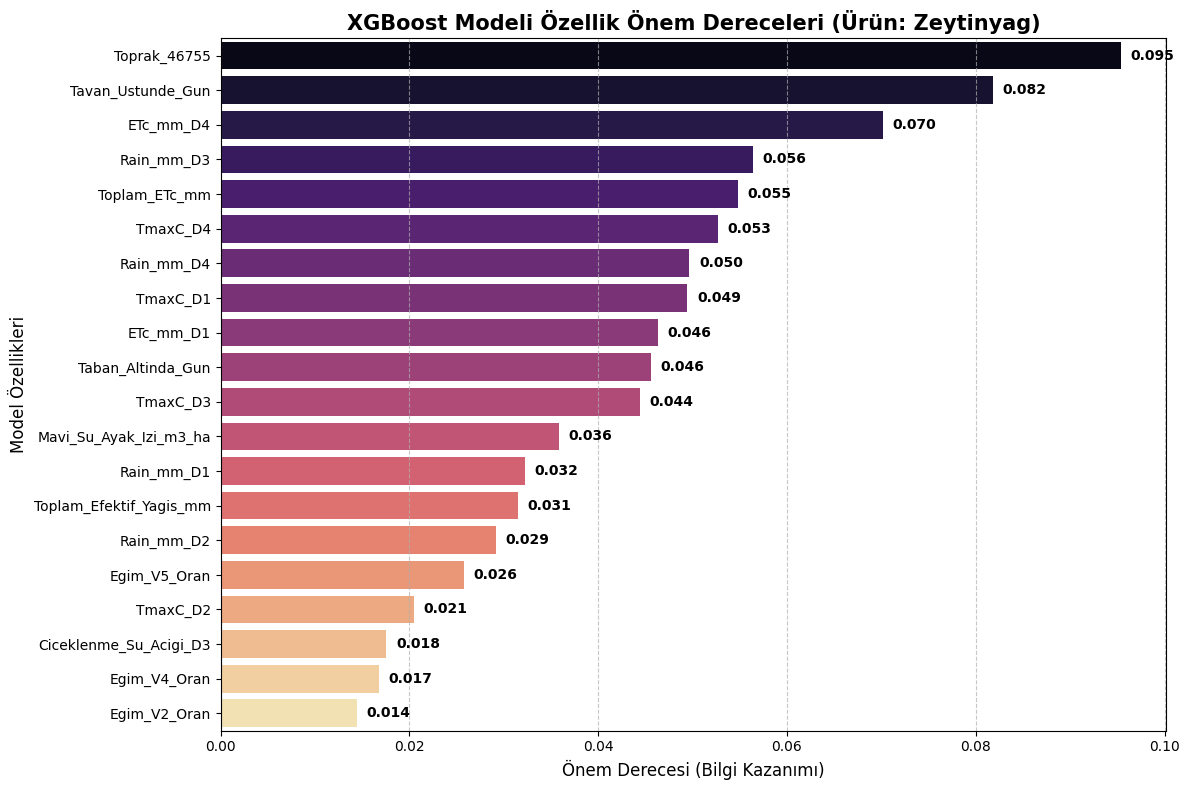

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# En son döngüde eğitilen XGBoost modelinin en iyi tahmincisini (best_estimator) alıyoruz
best_xgb = xgb_grid.best_estimator_

# Özellik önem derecelerini (Feature Importances) çıkarıyoruz
importances = best_xgb.feature_importances_
features = X_train.columns

# DataFrame'e çevirip büyükten küçüğe sıralıyoruz
df_importance = pd.DataFrame({
    'Özellik': features,
    'Önem Derecesi': importances
}).sort_values(by='Önem Derecesi', ascending=False)

# En etkili 20 özelliği görselleştiriyoruz
plt.figure(figsize=(12, 8))
sns.barplot(x='Önem Derecesi', y='Özellik', data=df_importance.head(20), palette='magma')

plt.title(f"XGBoost Modeli Özellik Önem Dereceleri (Ürün: {urun.capitalize()})", fontsize=15, fontweight='bold')
plt.xlabel('Önem Derecesi (Bilgi Kazanımı)', fontsize=12)
plt.ylabel('Model Özellikleri', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.7)

# Değerleri çubukların yanına yazdırma
for index, value in enumerate(df_importance.head(20)['Önem Derecesi']):
    plt.text(value + 0.001, index, f"{value:.3f}", va='center', fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping

tf.get_logger().setLevel('ERROR')

print("🌟 4 MODEL (XGB, RF, DNN, LSTM) İÇİN ÖZELLİK ÖNEM DERECESİ GRAFİKLERİ ÇIKARILIYOR...\n")
print("Not: Derin Öğrenme modelleri (DNN ve LSTM) için Permütasyon (Permutation Importance) yöntemi kullanılmaktadır. Bu işlem zaman alabilir.\n")

verim_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']
referans_senaryo = "HadGEM2-ES_rcp45"

def get_permutation_importance(model, X, y, is_lstm=False, n_repeats=3):
    if is_lstm:
        X_input = np.reshape(X.values, (X.shape[0], 1, X.shape[1]))
    else:
        X_input = X.values

    baseline_pred = model.predict(X_input, verbose=0).flatten()
    baseline_rmse = np.sqrt(mean_squared_error(y, baseline_pred))
    importances = []

    for col in X.columns:
        scores = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[col] = np.random.permutation(X_perm[col])
            if is_lstm:
                X_perm_input = np.reshape(X_perm.values, (X_perm.shape[0], 1, X_perm.shape[1]))
            else:
                X_perm_input = X_perm.values

            pred = model.predict(X_perm_input, verbose=0).flatten()
            score = np.sqrt(mean_squared_error(y, pred))
            scores.append(score - baseline_rmse)
        importances.append(np.mean(scores))
    return np.array(importances)

for urun in tum_klasorler:
    urun_yolu = os.path.join(verim_dir, urun)
    v4_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{referans_senaryo}*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    if not v4_dosyalari:
        continue

    v4_dosya = v4_dosyalari[0]
    print(f"-> {urun.upper()} işleniyor...")

    try:
        df = pd.read_excel(v4_dosya)
        toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
        if toprak_sutunu:
            df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

        numeric_cols_all = df.select_dtypes(include=[np.number]).columns
        df[numeric_cols_all] = df[numeric_cols_all].fillna(0)

        hedef_ve_kimlik = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
        X_cols = [c for c in df.columns if c not in hedef_ve_kimlik and pd.api.types.is_numeric_dtype(df[c])]

        train_df = df[df['Yil'] <= 2024]
        if len(train_df) == 0:
            print("   ⚠️ Yeterli eğitim verisi yok.")
            continue

        X_train = train_df[X_cols]
        y_train = train_df['Verim_Farki'].values

        scaler = MinMaxScaler()
        X_train_scaled_arr = scaler.fit_transform(X_train)
        X_train_scaled = pd.DataFrame(X_train_scaled_arr, columns=X_cols)

        # 1. XGBoost
        model_xgb = xgb.XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
        model_xgb.fit(X_train_scaled, y_train)
        imp_xgb = model_xgb.feature_importances_

        # 2. Random Forest
        model_rf = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42)
        model_rf.fit(X_train_scaled, y_train)
        imp_rf = model_rf.feature_importances_

        # 3. DNN
        model_dnn = Sequential([
            Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dropout(0.2),
            Dense(1, activation='linear')
        ])
        model_dnn.compile(optimizer='adam', loss='mse')
        erken_durdurma = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)
        model_dnn.fit(X_train_scaled, y_train, epochs=100, batch_size=16, verbose=0, callbacks=[erken_durdurma])

        imp_dnn = get_permutation_importance(model_dnn, X_train_scaled, y_train, is_lstm=False, n_repeats=3)
        imp_dnn = np.maximum(0, imp_dnn) # Sadece pozitif (hatayı artıran) etkileri al

        # 4. LSTM
        X_train_lstm = np.reshape(X_train_scaled_arr, (X_train_scaled_arr.shape[0], 1, X_train_scaled_arr.shape[1]))
        model_lstm = Sequential([
            LSTM(64, activation='relu', return_sequences=False, input_shape=(1, X_train_scaled.shape[1])),
            Dropout(0.3),
            Dense(32, activation='relu'),
            Dense(1, activation='linear')
        ])
        model_lstm.compile(optimizer='adam', loss='mse')
        model_lstm.fit(X_train_lstm, y_train, epochs=100, batch_size=16, verbose=0, callbacks=[erken_durdurma])

        imp_lstm = get_permutation_importance(model_lstm, X_train_scaled, y_train, is_lstm=True, n_repeats=3)
        imp_lstm = np.maximum(0, imp_lstm)

        # Tablolama
        df_imp = pd.DataFrame({
            'Özellik': X_cols,
            'XGBoost': imp_xgb,
            'RF': imp_rf,
            'DNN': imp_dnn,
            'LSTM': imp_lstm
        })

        fig, axes = plt.subplots(2, 2, figsize=(18, 12))
        fig.suptitle(f'{urun.capitalize()} - En Önemli 10 Faktör (4 Algoritma Karşılaştırması)', fontsize=18, fontweight='bold')

        modeller = ['XGBoost', 'RF', 'DNN', 'LSTM']
        basliklar = ['XGBoost (Gain)', 'Random Forest (Gini)', 'DNN (Permutation Importance)', 'LSTM (Permutation Importance)']
        renkler = ['magma', 'viridis', 'crest', 'rocket']

        for i, (ax, model_adi, baslik, renk) in enumerate(zip(axes.flatten(), modeller, basliklar, renkler)):
            df_top10 = df_imp.sort_values(by=model_adi, ascending=False).head(10)

            toplam_onem = df_top10[model_adi].sum()
            if toplam_onem > 0:
                df_top10['Oransal_Onem'] = df_top10[model_adi] / toplam_onem
            else:
                df_top10['Oransal_Onem'] = 0

            sns.barplot(x='Oransal_Onem', y='Özellik', data=df_top10, palette=renk, ax=ax)
            ax.set_title(baslik, fontsize=14)
            ax.set_xlabel('Bağıl Önem Oranı', fontsize=12)
            ax.set_ylabel('')

            for index, value in enumerate(df_top10['Oransal_Onem']):
                ax.text(value + 0.001, index, f"{value:.3f}", va='center', fontweight='bold')

        plt.tight_layout(rect=[0, 0.03, 1, 0.95])

        kayit_yolu = os.path.join(urun_yolu, f"{urun.lower()}_Feature_Importance_4_Model.png")
        plt.savefig(kayit_yolu, dpi=300)
        plt.close()

        print(f"   ✅ Kaydedildi: {os.path.basename(kayit_yolu)}")

    except Exception as e:
        print(f"   ❌ Hata: {e}")

print("\n🎉 Tüm grafikler başarıyla oluşturuldu!")

🌟 4 MODEL (XGB, RF, DNN, LSTM) İÇİN ÖZELLİK ÖNEM DERECESİ GRAFİKLERİ ÇIKARILIYOR...

Not: Derin Öğrenme modelleri (DNN ve LSTM) için Permütasyon (Permutation Importance) yöntemi kullanılmaktadır. Bu işlem zaman alabilir.

-> BEZELYE işleniyor...
   ✅ Kaydedildi: bezelye_Feature_Importance_4_Model.png
-> DOMATES işleniyor...
   ✅ Kaydedildi: domates_Feature_Importance_4_Model.png
-> FINDIK işleniyor...
   ✅ Kaydedildi: findik_Feature_Importance_4_Model.png
-> INCIR işleniyor...
   ✅ Kaydedildi: incir_Feature_Importance_4_Model.png
-> KAYISI işleniyor...
   ✅ Kaydedildi: kayisi_Feature_Importance_4_Model.png
-> LIMON işleniyor...
   ✅ Kaydedildi: limon_Feature_Importance_4_Model.png
-> PAMUK işleniyor...
   ✅ Kaydedildi: pamuk_Feature_Importance_4_Model.png
-> SOGAN işleniyor...
   ✅ Kaydedildi: sogan_Feature_Importance_4_Model.png
-> SUNFLOWER işleniyor...
   ✅ Kaydedildi: sunflower_Feature_Importance_4_Model.png
-> ZEYTINSOFR işleniyor...
   ✅ Kaydedildi: zeytinsofr_Feature_Importance_

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from IPython.display import display

print("🌟 TÜM ÜRÜNLER İÇİN FEATURE IMPORTANCE ÖZET TABLOSU OLUŞTURULUYOR...\n")

verim_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']
referans_senaryo = "HadGEM2-ES_rcp45"

ozet_listesi = []

for urun in tum_klasorler:
    urun_yolu = os.path.join(verim_dir, urun)
    v4_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{referans_senaryo}*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    if not v4_dosyalari:
        continue

    v4_dosya = v4_dosyalari[0]

    try:
        df = pd.read_excel(v4_dosya)

        # Ön İşleme
        toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
        if toprak_sutunu:
            df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

        numeric_cols_all = df.select_dtypes(include=[np.number]).columns
        df[numeric_cols_all] = df[numeric_cols_all].fillna(0)

        hedef_ve_kimlik = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
        X_cols = [c for c in df.columns if c not in hedef_ve_kimlik and pd.api.types.is_numeric_dtype(df[c])]

        # Eğitim Verisi (2021-2024)
        train_df = df[df['Yil'] <= 2024]
        if len(train_df) == 0:
            continue

        X_train = train_df[X_cols]
        y_train = train_df['Verim_Farki']

        # Model Eğitimi (XGBoost)
        model = xgb.XGBRegressor(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
        model.fit(X_train, y_train)

        # Özellik Önemleri Çıkarımı
        importances = model.feature_importances_
        df_imp = pd.DataFrame({'Özellik': X_cols, 'Önem': importances}).sort_values(by='Önem', ascending=False)

        # En önemli ilk 5 özelliği kaydet
        top5 = df_imp.head(5)
        satir = {'Ürün': urun.capitalize()}
        for i, (idx, row) in enumerate(top5.iterrows(), 1):
            satir[f'{i}. Etkili Faktör'] = f"{row['Özellik']} ({row['Önem']:.3f})"

        ozet_listesi.append(satir)

    except Exception as e:
        print(f"❌ {urun} için hata oluştu: {e}")

# Tabloyu oluştur ve ekrana yazdır
if ozet_listesi:
    df_ozet = pd.DataFrame(ozet_listesi)
    df_ozet.set_index('Ürün', inplace=True)

    print("🏆 ÜRÜNLERE GÖRE VERİMİ ETKİLEYEN EN ÖNEMLİ 5 FAKTÖR ÖZETİ 🏆")
    display(df_ozet)

    # Excel olarak dışa aktar
    kayit_yolu = os.path.join(verim_dir, "Tum_Urunler_Feature_Importance_Ozeti.xlsx")
    df_ozet.to_excel(kayit_yolu)
    print(f"\n✅ Özet tablo Excel olarak başarıyla kaydedildi:\n👉 {kayit_yolu}")
else:
    print("⚠️ Özet tablo oluşturulacak geçerli veri bulunamadı.")

🌟 TÜM ÜRÜNLER İÇİN FEATURE IMPORTANCE ÖZET TABLOSU OLUŞTURULUYOR...

🏆 ÜRÜNLERE GÖRE VERİMİ ETKİLEYEN EN ÖNEMLİ 5 FAKTÖR ÖZETİ 🏆


,1. Etkili Faktör,2. Etkili Faktör,3. Etkili Faktör,4. Etkili Faktör,5. Etkili Faktör
Ürün,,,,,
Bezelye,Toplam_ETc_mm (0.178),Toprak_37560 (0.125),Rakim_m (0.060),Baki_V4_Oran (0.053),Egim_V3_Oran (0.050)
Domates,Baki_V4_Oran (0.082),Toprak_39121 (0.066),Rain_mm_D2 (0.059),ETc_mm_D4 (0.056),Toplam_ETc_mm (0.054)
Findik,ETc_mm_D2 (0.097),Toplam_Yagis_mm (0.055),Ciceklenme_Su_Acigi_D3 (0.046),TmaxC_D1 (0.045),Egim_V4_Oran (0.041)
Incir,CLC_Tarim_ha (0.413),ETc_mm_D2 (0.301),Baki_V1_Oran (0.273),Egim_V2_Oran (0.002),Toplam_Yagis_mm (0.002)
Kayisi,Toprak_44638 (0.490),Rakim_m (0.327),Toplam_Yagis_mm (0.082),ETc_mm_D1 (0.046),ETc_mm_D4 (0.028)
Limon,Rakim_m (0.377),Toprak_38830 (0.237),Tavan_Ustunde_Gun (0.103),Toprak_42873 (0.097),Baki_V1_Oran (0.030)
Pamuk,Rakim_m (0.168),Toplam_Yagis_mm (0.107),TmaxC_D1 (0.101),Toplam_Efektif_Yagis_mm (0.069),Rain_mm_D2 (0.046)
Sogan,Tavan_Ustunde_Gun (0.132),TmaxC_D4 (0.059),Toplam_Efektif_Yagis_mm (0.055),Egim_V3_Oran (0.051),Toplam_ETc_mm (0.041)
Sunflower,Rain_mm_D3 (0.091),TmaxC_D3 (0.065),Rakim_m (0.062),Toplam_Yagis_mm (0.049),Toprak_45742 (0.046)



✅ Özet tablo Excel olarak başarıyla kaydedildi:
👉 /content/drive/MyDrive/Doktora/verim/Tum_Urunler_Feature_Importance_Ozeti.xlsx


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import MinMaxScaler
from IPython.display import display

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, LSTM
from tensorflow.keras.callbacks import EarlyStopping
tf.get_logger().setLevel('ERROR')

print("🌟 SEÇİLİ 5 ÜRÜN İÇİN 4'LÜ MODEL ÖZELLİK ÖNEM DERECESİ (TOP 5) ÖZET TABLOSU OLUŞTURULUYOR...\n")

verim_dir = "/content/drive/MyDrive/Doktora/verim"
tum_klasorler = [f for f in os.listdir(verim_dir) if os.path.isdir(os.path.join(verim_dir, f)) and f.lower() != 'hamlar']
referans_senaryo = "HadGEM2-ES_rcp45"
hedef_urunler = ['domates', 'sogan', 'kayisi', 'zeytinsofr', 'zeytinyag']

def get_permutation_importance(model, X, y, is_lstm=False, n_repeats=1):
    if is_lstm:
        X_input = np.reshape(X.values, (X.shape[0], 1, X.shape[1]))
    else:
        X_input = X.values
    baseline_pred = model.predict(X_input, verbose=0).flatten()
    baseline_rmse = np.sqrt(mean_squared_error(y, baseline_pred))
    importances = []
    for col in X.columns:
        scores = []
        for _ in range(n_repeats):
            X_perm = X.copy()
            X_perm[col] = np.random.permutation(X_perm[col])
            if is_lstm:
                X_perm_input = np.reshape(X_perm.values, (X_perm.shape[0], 1, X_perm.shape[1]))
            else:
                X_perm_input = X_perm.values
            pred = model.predict(X_perm_input, verbose=0).flatten()
            score = np.sqrt(mean_squared_error(y, pred))
            scores.append(score - baseline_rmse)
        importances.append(np.mean(scores))
    return np.maximum(0, np.array(importances))

ozet_listesi = []

for urun in tum_klasorler:
    if urun.lower() not in hedef_urunler:
        continue

    urun_yolu = os.path.join(verim_dir, urun)
    v4_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{referans_senaryo}*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    if not v4_dosyalari:
        print(f"⚠️ {urun} için V4 dosyası bulunamadı.")
        continue

    print(f"-> {urun.upper()} analiz ediliyor...")

    try:
        df = pd.read_excel(v4_dosyalari[0])
        toprak_sutunu = [c for c in df.columns if 'toprak' in c.lower()]
        if toprak_sutunu:
            df = pd.get_dummies(df, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

        numeric_cols = df.select_dtypes(include=[np.number]).columns
        df[numeric_cols] = df[numeric_cols].fillna(0)

        hedef_ve_kimlik = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
        X_cols = [c for c in df.columns if c not in hedef_ve_kimlik and pd.api.types.is_numeric_dtype(df[c])]

        train_df = df[df['Yil'] <= 2024]
        if len(train_df) == 0: continue

        X_train = train_df[X_cols]
        y_train = train_df['Verim_Farki'].values

        scaler = MinMaxScaler()
        X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_cols)

        # 1. XGBoost
        model_xgb = xgb.XGBRegressor(n_estimators=100, max_depth=4, learning_rate=0.05, random_state=42)
        model_xgb.fit(X_train_scaled, y_train)
        imp_xgb = model_xgb.feature_importances_

        # 2. Random Forest
        model_rf = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
        model_rf.fit(X_train_scaled, y_train)
        imp_rf = model_rf.feature_importances_

        # 3. DNN
        model_dnn = Sequential([
            Dense(32, activation='relu', input_shape=(X_train_scaled.shape[1],)),
            Dropout(0.2), Dense(16, activation='relu'), Dense(1, activation='linear')
        ])
        model_dnn.compile(optimizer='adam', loss='mse')
        model_dnn.fit(X_train_scaled, y_train, epochs=50, batch_size=16, verbose=0)
        imp_dnn = get_permutation_importance(model_dnn, X_train_scaled, y_train, is_lstm=False)

        # 4. LSTM
        X_train_lstm = np.reshape(X_train_scaled.values, (X_train_scaled.shape[0], 1, X_train_scaled.shape[1]))
        model_lstm = Sequential([
            LSTM(32, activation='relu', return_sequences=False, input_shape=(1, X_train_scaled.shape[1])),
            Dropout(0.2), Dense(16, activation='relu'), Dense(1, activation='linear')
        ])
        model_lstm.compile(optimizer='adam', loss='mse')
        model_lstm.fit(X_train_lstm, y_train, epochs=50, batch_size=16, verbose=0)
        imp_lstm = get_permutation_importance(model_lstm, X_train_scaled, y_train, is_lstm=True)

        # Dataframe oluşturma
        df_imp = pd.DataFrame({
            'Özellik': X_cols,
            'XGBoost': imp_xgb, 'RF': imp_rf, 'DNN': imp_dnn, 'LSTM': imp_lstm
        })

        # Her model için en iyi ilk 5 özelliği metin olarak birleştirme
        satir = {'Ürün': urun.capitalize()}
        for model_adi in ['XGBoost', 'RF', 'DNN', 'LSTM']:
            top5 = df_imp.sort_values(by=model_adi, ascending=False).head(5)
            satir[f'{model_adi} Top 5 Faktör'] = " | ".join([f"{r['Özellik']} ({r[model_adi]:.3f})" for _, r in top5.iterrows()])

        ozet_listesi.append(satir)

    except Exception as e:
        print(f"❌ {urun} işlenirken hata: {e}")

if ozet_listesi:
    df_5urun_4model_ozet = pd.DataFrame(ozet_listesi).set_index('Ürün')
    print("\n🏆 SEÇİLİ 5 ÜRÜN İÇİN 4 MODELİN EN ÖNEMLİ 5 FAKTÖRÜ ÖZETİ 🏆")
    display(df_5urun_4model_ozet)

    kayit_yolu = os.path.join(verim_dir, "Secili_5_Urun_4_Model_Top5_Feature_Importance.xlsx")
    df_5urun_4model_ozet.to_excel(kayit_yolu)
    print(f"\n✅ Seçili ürünler için 4'lü model (Top 5) özet tablosu kaydedildi:\n👉 {kayit_yolu}")
else:
    print("⚠️ Özet tablo oluşturulamadı.")

🌟 SEÇİLİ 5 ÜRÜN İÇİN 4'LÜ MODEL ÖZELLİK ÖNEM DERECESİ (TOP 5) ÖZET TABLOSU OLUŞTURULUYOR...

-> DOMATES analiz ediliyor...
-> KAYISI analiz ediliyor...
-> SOGAN analiz ediliyor...
-> ZEYTINSOFR analiz ediliyor...
-> ZEYTINYAG analiz ediliyor...

🏆 SEÇİLİ 5 ÜRÜN İÇİN 4 MODELİN EN ÖNEMLİ 5 FAKTÖRÜ ÖZETİ 🏆


,XGBoost Top 5 Faktör,RF Top 5 Faktör,DNN Top 5 Faktör,LSTM Top 5 Faktör
Ürün,,,,
Domates,Baki_V4_Oran (0.086) | Rain_mm_D2 (0.061) | To...,Toprak_39121 (0.144) | Rain_mm_D4 (0.088) | Eg...,Rain_mm_D4 (0.046) | Rain_mm_D2 (0.032) | Rain...,Rain_mm_D3 (0.111) | Rain_mm_D4 (0.084) | Rain...
Kayisi,Toprak_44638 (0.410) | Rakim_m (0.400) | Topla...,Toprak_44638 (0.568) | Rain_mm_D1 (0.039) | Ra...,ETc_mm_D4 (0.021) | Toprak_46086 (0.015) | Tab...,TmaxC_D4 (0.024) | Rain_mm_D1 (0.012) | Mavi_S...
Sogan,Tavan_Ustunde_Gun (0.112) | Egim_V3_Oran (0.06...,Tavan_Ustunde_Gun (0.194) | TmaxC_D4 (0.127) |...,Tavan_Ustunde_Gun (0.083) | TmaxC_D4 (0.040) |...,Tavan_Ustunde_Gun (0.323) | ETc_mm_D2 (0.064) ...
Zeytinsofr,Toprak_46755 (0.237) | Baki_V1_Oran (0.062) | ...,Toprak_46755 (0.340) | Rain_mm_D1 (0.084) | Tm...,Rain_mm_D3 (0.068) | Ciceklenme_Su_Acigi_D3 (0...,Ciceklenme_Su_Acigi_D3 (0.056) | Rain_mm_D3 (0...
Zeytinyag,TmaxC_D3 (0.104) | TmaxC_D1 (0.067) | Egim_V3_...,Toprak_46755 (0.148) | TmaxC_D3 (0.129) | ETc_...,Rain_mm_D3 (0.164) | Ciceklenme_Su_Acigi_D3 (0...,Rain_mm_D3 (0.234) | Ciceklenme_Su_Acigi_D3 (0...



✅ Seçili ürünler için 4'lü model (Top 5) özet tablosu kaydedildi:
👉 /content/drive/MyDrive/Doktora/verim/Secili_5_Urun_4_Model_Top5_Feature_Importance.xlsx


In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

verim_dir = "/content/drive/MyDrive/Doktora/verim"
pheno_dir = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"

hedef_urunler = ['domates', 'sogan', 'zeytinsofr']
print(f"🌟 {len(hedef_urunler)} ürün için GELECEK Tüm Senaryo V3 matrisleri oluşturuluyor...\n")

for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu): urun_yolu = os.path.join(verim_dir, urun)

    print(f"{'='*60}\n🚀 İŞLENİYOR: {urun.upper()}\n{'='*60}")

    v2_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun}*_ML_egitim_seti_V2.xlsx"))
    agirlik_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun}*agirlik*.csv")) + glob.glob(os.path.join(urun_yolu, f"*{urun}*agirlik*.xls*"))

    if not v2_dosyalari or not agirlik_dosyalari: continue

    try:
        # V2 ve Statik Özelliklerin Çıkarılması (Gelecek yıllarla eşleşebilmesi için)
        df_ml = pd.read_excel(v2_dosyalari[0])
        df_ml['Ilce_Kodu'] = pd.to_numeric(df_ml['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        train_verim = df_ml.groupby('Ilce_Kodu')['Verim_ton_ha'].mean().reset_index().rename(columns={'Verim_ton_ha': 'Tarihsel_Ortalama_Verim'})
        df_statik = df_ml.drop(columns=['Yil', 'Verim_ton_ha', 'Verim_Farki'], errors='ignore').drop_duplicates(subset=['Ilce_Kodu'])
        df_statik = pd.merge(df_statik, train_verim, on='Ilce_Kodu', how='left')

        df_agirlik = pd.read_csv(agirlik_dosyalari[0]) if agirlik_dosyalari[0].endswith('.csv') else pd.read_excel(agirlik_dosyalari[0])
        if 'kodnew' in df_agirlik.columns: df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
        elif 'KODNEW' in df_agirlik.columns: df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)
        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)
        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)

        # Gelecek Yılların (2046-2098) Senaryolarını Bulma
        all_pheno_files = glob.glob(os.path.join(pheno_dir, f"{urun}_*_20[4-9][0-9]_PHENO.csv"))
        senaryolar = sorted(list(set([re.search(fr"{urun}_(.*?)_20", os.path.basename(f)).group(1) for f in all_pheno_files if re.search(fr"{urun}_(.*?)_20", os.path.basename(f))])))

        print(f"   Bulunan Senaryo Sayısı: {len(senaryolar)}")

        for senaryo in senaryolar:
            print(f"   -> İşleniyor: {senaryo}")
            senaryo_dosyalari = [f for f in all_pheno_files if senaryo in f]
            tum_ozetler = []

            for p_dosya in senaryo_dosyalari:
                try:
                    df_p = pd.read_csv(p_dosya, low_memory=False)
                    df_p['YYYY'] = pd.to_numeric(df_p['YYYY'], errors='coerce').fillna(0).astype(int)
                    df_active = df_p[df_p['CGDD_Birikim'] > 0].copy()

                    conditions = [
                        (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_1']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_1']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_2']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_2']) & (df_active['CGDD_Birikim'] <= df_active['CGDD_Hedef_3']),
                        (df_active['CGDD_Birikim'] > df_active['CGDD_Hedef_3'])
                    ]
                    df_active['Evre'] = np.select(conditions, ['D1', 'D2', 'D3', 'D4'], default='D4')
                    ozet = df_active.groupby(['station_no', 'YYYY', 'Evre']).agg({'Rain_mm': 'sum', 'ETc_mm': 'sum', 'TmaxC': 'mean'}).unstack(fill_value=0)
                    ozet.columns = [f"{col[0]}_{col[1]}" for col in ozet.columns]
                    tum_ozetler.append(ozet.reset_index().rename(columns={'YYYY': 'Yil'}))
                except: pass

            if not tum_ozetler: continue

            df_pheno_all = pd.concat(tum_ozetler, ignore_index=True)
            df_pheno_all['station_no'] = df_pheno_all['station_no'].astype(int)

            df_pheno_ilce = pd.merge(df_agirlik, df_pheno_all, on='station_no', how='inner')
            pheno_cols = [c for c in df_pheno_ilce.columns if 'Rain_' in c or 'ETc_' in c or 'TmaxC_' in c]
            for c in pheno_cols: df_pheno_ilce[c] = df_pheno_ilce[c] * df_pheno_ilce['istasyon_agirligi']
            df_pheno_final = df_pheno_ilce.groupby(['Ilce_Kodu', 'Yil'])[pheno_cols].sum().reset_index()

            # GELECEK İKLİM VERİSİ İLE STATİK V2 VERİSİNİ BİRLEŞTİR
            df_v3 = pd.merge(df_pheno_final, df_statik, on='Ilce_Kodu', how='inner')

            if 'ETc_mm_D3' in df_v3.columns and 'Rain_mm_D3' in df_v3.columns:
                df_v3['Ciceklenme_Su_Acigi_D3'] = (df_v3['ETc_mm_D3'] - df_v3['Rain_mm_D3']).clip(lower=0)

            df_v3['Verim_ton_ha'] = df_v3['Tarihsel_Ortalama_Verim']
            df_v3['Verim_Farki'] = 0

            v3_cikis_yolu = os.path.join(urun_yolu, f"{urun}_{senaryo}_GELECEK_V3_PHENO.xlsx")
            df_v3.to_excel(v3_cikis_yolu, index=False)

    except Exception as e:
        print(f"❌ HATA: {urun} işlenirken bir sorun oluştu -> {e}")

🌟 3 ürün için GELECEK Tüm Senaryo V3 matrisleri oluşturuluyor...

🚀 İŞLENİYOR: DOMATES
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: MPI-ESM-MR_rcp85
   -> İşleniyor: MPI-ESM1-2-HR_ssp245
   -> İşleniyor: MPI-ESM1-2-HR_ssp585
🚀 İŞLENİYOR: SOGAN
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: MPI-ESM-MR_rcp85
   -> İşleniyor: MPI-ESM1-2-HR_ssp245
   -> İşleniyor: MPI-ESM1-2-HR_ssp585
🚀 İŞLENİYOR: ZEYTINSOFR
   Bulunan Senaryo Sayısı: 8
   -> İşleniyor: HadGEM2-ES_rcp45
   -> İşleniyor: HadGEM2-ES_rcp85
   -> İşleniyor: HadGEM3-GC31-LL_ssp245
   -> İşleniyor: HadGEM3-GC31-LL_ssp585
   -> İşleniyor: MPI-ESM-MR_rcp45
   -> İşleniyor: 

In [ ]:
import os
import glob
import re
import pandas as pd
import warnings

warnings.filterwarnings('ignore')

verim_dir = "/content/drive/MyDrive/Doktora/verim"
wf_dir = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

hedef_urunler = ['domates', 'sogan', 'zeytinsofr']

wf_sutunlari = [
    "Toplam_Vejetasyon_Gunu", "Taban_Altinda_Gun", "Tavan_Ustunde_Gun",
    "Toplam_Yagis_mm", "Toplam_Efektif_Yagis_mm", "Toplam_ETc_mm",
    "Yesil_Su_Ayak_Izi_m3_ha", "Mavi_Su_Ayak_Izi_m3_ha"
]

# Gelecek V3 dosyalarını buluyoruz
tum_v3_dosyalari = glob.glob(os.path.join(verim_dir, "*", "*_GELECEK_V3_PHENO.xlsx"))
tum_wf_dosyalari = [f for f in glob.glob(os.path.join(wf_dir, "*.*")) if f.endswith(('.csv', '.xlsx', '.xls'))]

print(f"🚀 2046-2098 GELECEK V4 DOSYALARI ÜRETİLİYOR...\n")

def guvenli_oku(dosya_yolu):
    if dosya_yolu.endswith(('.xlsx', '.xls')): return pd.read_excel(dosya_yolu)
    else:
        for ayar in [{'sep': ',', 'encoding': 'utf-8'}, {'sep': ';', 'encoding': 'cp1254'}, {'sep': ',', 'encoding': 'latin1'}]:
            try: return pd.read_csv(dosya_yolu, **ayar, low_memory=False)
            except: continue
        raise ValueError("Okuma başarısız.")

for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu): urun_yolu = os.path.join(verim_dir, urun)

    v3_listesi = [f for f in tum_v3_dosyalari if urun in f.lower()]
    if not v3_listesi: continue

    agirlik_dosyalari = glob.glob(os.path.join(urun_yolu, f"*{urun}*agirlik*.csv")) + glob.glob(os.path.join(urun_yolu, f"*{urun}*agirlik*.xls*"))
    if not agirlik_dosyalari: continue

    try:
        df_agirlik = guvenli_oku(agirlik_dosyalari[0])
        if 'kodnew' in df_agirlik.columns: df_agirlik.rename(columns={'kodnew': 'Ilce_Kodu'}, inplace=True)
        elif 'KODNEW' in df_agirlik.columns: df_agirlik.rename(columns={'KODNEW': 'Ilce_Kodu'}, inplace=True)
        df_agirlik['station_no'] = pd.to_numeric(df_agirlik['station_no'], errors='coerce').fillna(0).astype(int)
        df_agirlik['Ilce_Kodu'] = pd.to_numeric(df_agirlik['Ilce_Kodu'], errors='coerce').fillna(0).astype(int)
    except: continue

    for v3_dosya in v3_listesi:
        senaryo_match = re.search(r"_(.+?)_GELECEK_V3", os.path.basename(v3_dosya))
        if not senaryo_match: continue
        senaryo = senaryo_match.group(1)

        # 2046-2098 Yılları Arasındaki WF Dosyalarını Eşleştir
        eslesen_wf_dosyalari = [wf_f for wf_f in tum_wf_dosyalari if urun in wf_f.lower() and senaryo.lower() in wf_f.lower() and re.search(r'20(4[6-9]|[5-9][0-9])', wf_f.lower())]

        if not eslesen_wf_dosyalari:
            print(f"⚠️ ATLANDI ({urun} - {senaryo}): 2046-2098 aralığında WF dosyası eşleşmedi.")
            continue

        df_wf_list = []
        for wf_f in eslesen_wf_dosyalari:
            try:
                tmp = guvenli_oku(wf_f)
                yil_match = re.search(r'_(20(4[6-9]|[5-9][0-9]))', os.path.basename(wf_f))
                if yil_match: tmp['Yil'] = int(yil_match.group(1))
                else: continue
                df_wf_list.append(tmp)
            except: pass

        if not df_wf_list: continue

        df_wf_all = pd.concat(df_wf_list, ignore_index=True)

        for col in ['Station_No', 'STATION_NO', 'istasyon_no', 'istasyon', 'Station']:
            if col in df_wf_all.columns: df_wf_all.rename(columns={col: 'station_no'}, inplace=True)

        if 'station_no' not in df_wf_all.columns: continue

        df_wf_all['station_no'] = pd.to_numeric(df_wf_all['station_no'], errors='coerce').fillna(0).astype(int)

        df_wf_ilce = pd.merge(df_agirlik, df_wf_all, on='station_no', how='inner')
        mevcut_wf_sutunlari = [c for c in wf_sutunlari if c in df_wf_ilce.columns]

        for c in mevcut_wf_sutunlari: df_wf_ilce[c] = df_wf_ilce[c] * df_wf_ilce['istasyon_agirligi']
        df_wf_final = df_wf_ilce.groupby(['Ilce_Kodu', 'Yil'])[mevcut_wf_sutunlari].sum().reset_index()

        # V3 İLE BİRLEŞTİRME VE NİHAİ V4 KAYDI
        try:
            df_v3 = pd.read_excel(v3_dosya)
            df_v4 = pd.merge(df_v3, df_wf_final, on=['Ilce_Kodu', 'Yil'], how='left')

            v4_cikis_yolu = os.path.join(urun_yolu, f"{urun}_{senaryo}_Gelecek_V4.xlsx")
            df_v4.to_excel(v4_cikis_yolu, index=False)
            print(f"✅ BAŞARILI: {os.path.basename(v4_cikis_yolu)}")
        except Exception as e:
            print(f"❌ HATA ({urun} - {senaryo}): V4 kaydedilemedi -> {e}")

print("\n🎉 İŞLEM TAMAMLANDI! (Gelecek Senaryo V4 Matrisleri Oluşturuldu)")

🚀 2046-2098 GELECEK V4 DOSYALARI ÜRETİLİYOR...

✅ BAŞARILI: domates_HadGEM2-ES_rcp45_Gelecek_V4.xlsx
✅ BAŞARILI: domates_HadGEM2-ES_rcp85_Gelecek_V4.xlsx
✅ BAŞARILI: domates_HadGEM3-GC31-LL_ssp245_Gelecek_V4.xlsx
✅ BAŞARILI: domates_HadGEM3-GC31-LL_ssp585_Gelecek_V4.xlsx
✅ BAŞARILI: domates_MPI-ESM-MR_rcp45_Gelecek_V4.xlsx
✅ BAŞARILI: domates_MPI-ESM-MR_rcp85_Gelecek_V4.xlsx
✅ BAŞARILI: domates_MPI-ESM1-2-HR_ssp245_Gelecek_V4.xlsx
✅ BAŞARILI: domates_MPI-ESM1-2-HR_ssp585_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_HadGEM2-ES_rcp45_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_HadGEM2-ES_rcp85_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_HadGEM3-GC31-LL_ssp245_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_HadGEM3-GC31-LL_ssp585_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_MPI-ESM-MR_rcp45_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_MPI-ESM-MR_rcp85_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_MPI-ESM1-2-HR_ssp245_Gelecek_V4.xlsx
✅ BAŞARILI: sogan_MPI-ESM1-2-HR_ssp585_Gelecek_V4.xlsx
✅ BAŞARILI: zeytinsofr_HadGEM2-ES_rcp45_Gelecek_V4.xlsx
✅ BAŞARILI: zeytinsofr_H

In [ ]:
import os
import glob
import pandas as pd
import re
import warnings

warnings.filterwarnings('ignore')

print("🌟 GELECEK V4 DOSYALARI SÜTUN HİZALAMA İŞLEMİ BAŞLATILIYOR...\n")

from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"

# İşlem yapılacak ürünler
hedef_urunler = ['domates', 'sogan', 'zeytinsofr']

for urun in hedef_urunler:
    # Klasör adları Domates, Sogan şeklinde büyük harfle başlıyor olabilir
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu):
        urun_yolu = os.path.join(verim_dir, urun)

    print(f"{'='*70}\n🚀 SÜTUNLAR HİZALANIYOR: {urun.upper()}\n{'='*70}")

    # Gelecek dosyalarını bul
    tum_gelecek = glob.glob(os.path.join(urun_yolu, "*_Gelecek_V4.xlsx"))
    gelecek_dosyalari = [f for f in tum_gelecek if re.search(urun, os.path.basename(f), re.IGNORECASE)]

    if not gelecek_dosyalari:
        print(f"   ⚠️ UYARI: {urun.upper()} için Gelecek_V4 dosyası bulunamadı.")
        continue

    basarili_sayisi = 0
    for gelecek_dosya in gelecek_dosyalari:
        dosya_adi = os.path.basename(gelecek_dosya)

        # Dosya adından senaryoyu çıkarıyoruz (Örn: HadGEM2-ES_rcp45)
        match = re.search(r"_(.+?)_Gelecek_V4", dosya_adi, re.IGNORECASE)
        if not match:
            print(f"   ⚠️ Atlandı (Senaryo Bulunamadı): {dosya_adi}")
            continue

        senaryo = match.group(1)

        # Eşleşen eğitim dosyasını bul (Şablon olarak kullanmak için)
        tum_egitim = glob.glob(os.path.join(urun_yolu, f"*_{senaryo}_ML_egitim_seti_V4_PHENORESULT.xlsx"))
        egitim_dosyalari = [f for f in tum_egitim if re.search(urun, os.path.basename(f), re.IGNORECASE)]

        # Eğer senaryoya özel eğitim dosyası bulunamazsa, klasördeki herhangi bir V4 eğitim dosyasını şablon al
        if not egitim_dosyalari:
            tum_egitim_genel = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V4_PHENORESULT.xlsx"))
            egitim_dosyalari = [f for f in tum_egitim_genel if re.search(urun, os.path.basename(f), re.IGNORECASE)]

        if not egitim_dosyalari:
            print(f"   ❌ HATA: {dosya_adi} için referans alınacak eğitim şablonu bulunamadı!")
            continue

        egitim_dosyasi = egitim_dosyalari[0]

        try:
            # Sadece sütun isimlerini almak için nrows=0 ile okuyoruz (İşlemi çok hızlandırır)
            df_egitim = pd.read_excel(egitim_dosyasi, nrows=0)
            hedef_sutun_sirasi = list(df_egitim.columns)

            # Gelecek dosyasının tamamını oku
            df_gelecek = pd.read_excel(gelecek_dosya)
            mevcut_sutunlar = list(df_gelecek.columns)

            # İki dosyanın sütun kümeleri aynı mı kontrol et (Eksik sütun var mı?)
            eksik_sutunlar = set(hedef_sutun_sirasi) - set(mevcut_sutunlar)

            if eksik_sutunlar:
                print(f"   ❌ HATA: {dosya_adi} dosyasında eğitim setinde olan bazı sütunlar EKSİK: {eksik_sutunlar}")
                continue

            # SÜTUNLARI EĞİTİM SETİYLE BİREBİR AYNI SIRAYA DİZ
            df_gelecek = df_gelecek[hedef_sutun_sirasi]

            # ESKİ DOSYANIN ÜSTÜNE YAZ (Overwrite)
            df_gelecek.to_excel(gelecek_dosya, index=False)

            print(f"   ✅ Hizalandı ve Üstüne Yazıldı: {dosya_adi}")
            basarili_sayisi += 1

        except Exception as e:
            print(f"   ❌ HATA: {dosya_adi} işlenirken hata oluştu -> {e}")

    print(f"\n   🎯 {urun.upper()} için toplam {basarili_sayisi} dosyanın sütun yapısı eşitlendi.\n")

print("🎉 BÜTÜN İŞLEMLER TAMAMLANDI! Gelecek matrisleri artık eğitim setleriyle %100 aynı sütun sırasına sahiptir.")

🌟 GELECEK V4 DOSYALARI SÜTUN HİZALAMA İŞLEMİ BAŞLATILIYOR...

🚀 SÜTUNLAR HİZALANIYOR: DOMATES
   ✅ Hizalandı ve Üstüne Yazıldı: domates_HadGEM2-ES_rcp45_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_HadGEM2-ES_rcp85_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_HadGEM3-GC31-LL_ssp245_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_HadGEM3-GC31-LL_ssp585_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_MPI-ESM-MR_rcp45_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_MPI-ESM-MR_rcp85_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_MPI-ESM1-2-HR_ssp245_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: domates_MPI-ESM1-2-HR_ssp585_Gelecek_V4.xlsx

   🎯 DOMATES için toplam 8 dosyanın sütun yapısı eşitlendi.

🚀 SÜTUNLAR HİZALANIYOR: SOGAN
   ✅ Hizalandı ve Üstüne Yazıldı: sogan_HadGEM2-ES_rcp45_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: sogan_HadGEM2-ES_rcp85_Gelecek_V4.xlsx
   ✅ Hizalandı ve Üstüne Yazıldı: sogan_HadGEM3-

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import joblib
import warnings
from tensorflow.keras.models import load_model

warnings.filterwarnings('ignore')

print("🌟 SENARYO BAZLI TOPLULUK MODELİ (ENSEMBLE) PROJEKSİYON MOTORU BAŞLATILIYOR...\n")

from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"

# Sadece ensemble uygulayacağımız 3 ürün
hedef_urunler = ['domates', 'sogan', 'zeytinsofr']

for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu):
        urun_yolu = os.path.join(verim_dir, urun)

    # 1. Gelecek V4 matrislerini bul (glob flags hatası düzeltilmiş yöntem)
    tum_v4_dosyalari = glob.glob(os.path.join(urun_yolu, "*_Gelecek_V4.xlsx"))
    v4_dosyalari = [f for f in tum_v4_dosyalari if re.search(urun, os.path.basename(f), re.IGNORECASE)]

    if not v4_dosyalari:
        print(f"⚠️ {urun.upper()} için Gelecek_V4 dosyası bulunamadı, atlanıyor.")
        continue

    print(f"{'='*70}\n🚀 PROJEKSİYON ÜRETİLİYOR: {urun.upper()}\n{'='*70}")

    model_klasoru = os.path.join(urun_yolu, "Egitilmis_Modeller")

    for v4_dosya in v4_dosyalari:
        dosya_adi = os.path.basename(v4_dosya)

        # 2. Gelecek dosyasının isminden senaryoyu çek (Örn: HadGEM2-ES_rcp45)
        match = re.search(r"_(.+?)_Gelecek_V4", dosya_adi, re.IGNORECASE)
        if not match:
            continue
        senaryo = match.group(1)

        print(f"   -> Senaryo İşleniyor: {senaryo}")

        try:
            # 3. Senaryoya ÖZEL modellerin dosya yollarını oluştur
            rf_path = os.path.join(model_klasoru, f"{urun.lower()}_{senaryo}_best_rf.pkl")
            dnn_path = os.path.join(model_klasoru, f"{urun.lower()}_{senaryo}_best_dnn.keras")
            scaler_path = os.path.join(model_klasoru, f"{urun.lower()}_{senaryo}_scaler.pkl")

            # Modellerin klasörde olup olmadığını güvenlik amaçlı kontrol et
            if not (os.path.exists(rf_path) and os.path.exists(dnn_path) and os.path.exists(scaler_path)):
                print(f"      ❌ HATA: {senaryo} için model dosyaları eksik! Atlanıyor.")
                continue

            # 4. İlgili Senaryonun Modellerini Hafızaya Yükle
            rf_model = joblib.load(rf_path)
            dnn_model = load_model(dnn_path)
            scaler = joblib.load(scaler_path)

            # 5. Gelecek Verisini Oku ve Ön İşleme
            df_future = pd.read_excel(v4_dosya)

            # Toprak Tipini Kategorik Hale Getirme (One-Hot Encoding)
            toprak_sutunu = [c for c in df_future.columns if 'toprak' in c.lower() and 'toprak_' not in c.lower()]
            if toprak_sutunu:
                df_future = pd.get_dummies(df_future, columns=[toprak_sutunu[0]], prefix='Toprak', dtype=float)

            # Eksik verileri doldur (Biyofiziksel güvenlik)
            numeric_cols = df_future.select_dtypes(include=[np.number]).columns
            df_future[numeric_cols] = df_future[numeric_cols].fillna(0)

            # Bağımsız değişkenleri (X) tespit et
            haric_sutunlar = ['Ilce_Kodu', 'Yil', 'Urun', 'Verim_ton_ha', 'Tarihsel_Ortalama_Verim', 'Verim_Farki']
            x_cols = [c for c in df_future.columns if c not in haric_sutunlar and pd.api.types.is_numeric_dtype(df_future[c])]

            X_future = df_future[x_cols].copy()

            # Modelin beklediği özelliklerin (feature_names_in_) sırasını ve varlığını garanti altına al
            if hasattr(rf_model, 'feature_names_in_'):
                beklenen_sutunlar = rf_model.feature_names_in_
                for col in beklenen_sutunlar:
                    if col not in X_future.columns:
                        X_future[col] = 0.0
                X_future = X_future[beklenen_sutunlar]

            # Seçici normalizasyon
            korunacaklar = [c for c in X_future.columns if any(k in c.lower() for k in ['egim', 'baki', 'toprak', 'slope', 'aspect'])]
            normalize_edilecekler = [c for c in X_future.columns if c not in korunacaklar]

            # 6. Ölçekleme (YALNIZCA Transform)
            if normalize_edilecekler:
                if hasattr(scaler, 'feature_names_in_'):
                    scaler_beklenen = scaler.feature_names_in_
                    X_future[scaler_beklenen] = scaler.transform(X_future[scaler_beklenen])
                else:
                    X_future[normalize_edilecekler] = scaler.transform(X_future[normalize_edilecekler])

            # 7. Model Tahminleri
            pred_rf = rf_model.predict(X_future)
            pred_dnn = dnn_model.predict(X_future, verbose=0).flatten()

            # 8. Topluluk (Ensemble) Formülü: %50 RF + %50 DNN (Syntax Hatası Düzeltildi)
            pred_ensemble_fark = (0.5 * pred_rf) + (0.5 * pred_dnn)

            # 9. Mutlak Verime Dönüşüm ve Negatifleri Sıfırlama
            tarihsel_baz = df_future['Tarihsel_Ortalama_Verim'].values
            mutlak_verim = pred_ensemble_fark + tarihsel_baz

            # Üretilen projeksiyon değerinde fiziksel sınır koruması
            df_future['Projeksiyon_Verim_ton_ha'] = np.clip(mutlak_verim, 0.0, None)
            df_future['Projeksiyon_Verim_Farki'] = pred_ensemble_fark

            # Excel çıktısı öncesi gereksiz 0-1 Toprak sütunlarını temizle
            silinecek_dummy_sutunlar = [c for c in df_future.columns if 'Toprak_' in c]
            df_future.drop(columns=silinecek_dummy_sutunlar, inplace=True, errors='ignore')

            # 10. Sonuçları Kaydet
            cikis_adi = dosya_adi.replace(".xlsx", "_ENSEMBLE_SONUC.xlsx")
            cikis_yolu = os.path.join(urun_yolu, cikis_adi)

            df_future.to_excel(cikis_yolu, index=False)
            print(f"      ✅ Başarı: {cikis_adi} (Projeksiyon Ort. Verim: {df_future['Projeksiyon_Verim_ton_ha'].mean():.2f} ton/ha)")

        except Exception as e:
            print(f"      ❌ HATA: {dosya_adi} işlenirken hata oluştu -> {e}")

print("\n🎉 BÜTÜN SENARYOLAR İÇİN ENSEMBLE PROJEKSİYON İŞLEMİ KUSURSUZ ŞEKİLDE TAMAMLANDI!")

🌟 SENARYO BAZLI TOPLULUK MODELİ (ENSEMBLE) PROJEKSİYON MOTORU BAŞLATILIYOR...

🚀 PROJEKSİYON ÜRETİLİYOR: DOMATES
   -> Senaryo İşleniyor: HadGEM2-ES_rcp45
      ✅ Başarı: domates_HadGEM2-ES_rcp45_Gelecek_V4_ENSEMBLE_SONUC.xlsx (Projeksiyon Ort. Verim: 82.45 ton/ha)
   -> Senaryo İşleniyor: HadGEM2-ES_rcp85
      ✅ Başarı: domates_HadGEM2-ES_rcp85_Gelecek_V4_ENSEMBLE_SONUC.xlsx (Projeksiyon Ort. Verim: 83.18 ton/ha)
   -> Senaryo İşleniyor: HadGEM3-GC31-LL_ssp245
      ✅ Başarı: domates_HadGEM3-GC31-LL_ssp245_Gelecek_V4_ENSEMBLE_SONUC.xlsx (Projeksiyon Ort. Verim: 83.13 ton/ha)
   -> Senaryo İşleniyor: HadGEM3-GC31-LL_ssp585
      ✅ Başarı: domates_HadGEM3-GC31-LL_ssp585_Gelecek_V4_ENSEMBLE_SONUC.xlsx (Projeksiyon Ort. Verim: 82.77 ton/ha)
   -> Senaryo İşleniyor: MPI-ESM-MR_rcp45
      ✅ Başarı: domates_MPI-ESM-MR_rcp45_Gelecek_V4_ENSEMBLE_SONUC.xlsx (Projeksiyon Ort. Verim: 82.53 ton/ha)
   -> Senaryo İşleniyor: MPI-ESM-MR_rcp85
      ✅ Başarı: domates_MPI-ESM-MR_rcp85_Gelecek_V4_ENSE

In [ ]:
import os
import glob
import re
import pandas as pd
import numpy as np
import warnings

warnings.filterwarnings('ignore')

print("🌟 KAPSAMLI SU AYAK İZİ (L/kg) DÖNÜŞÜM MOTORU BAŞLATILIYOR...\n")

# ==========================================
# 1. DOSYA YOLLARI VE YÜKLEME
# ==========================================
from google.colab import drive
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

verim_dir = "/content/drive/MyDrive/Doktora/verim"
master_dir = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3"
master_path = os.path.join(master_dir, "TUM_URUNLER_Ortalamali_Master_V3.xlsx")

# Master Dosyayı Güvenli Oku
xls = pd.ExcelFile(master_path)
df_master = None
for sheet in xls.sheet_names:
    df_temp = pd.read_excel(master_path, sheet_name=sheet)
    if 'Urun' in df_temp.columns or 'kodnew' in df_temp.columns or 'Ilce_Kodu' in df_temp.columns:
        df_master = df_temp
        break

print(f"✅ Master dosya başarıyla yüklendi ({df_master.shape[0]} satır).\n")

# Sütun isimlerini standartlaştırma
df_master.rename(columns={'kodnew': 'Ilce_Kodu', 'KODNEW': 'Ilce_Kodu'}, inplace=True)
df_master.rename(columns={c: 'Donem' for c in df_master.columns if str(c).lower() in ['donem']}, inplace=True)

df_master['Verim_ton_ha'] = np.nan

hedef_urunler = ['domates', 'sogan', 'zeytinsofr']
tum_urunler = df_master['Urun'].unique()
diger_urunler = [u for u in tum_urunler if str(u).lower() not in hedef_urunler]

# Hafıza Sözlükleri
verim_sozlugu = {}
yedek_2023_sozlugu = {} # 1.131 satırlık Gözlem/Mevcut boşlukları için REFERANS YIL (2023) arşivi

# ==========================================
# 2. DİĞER ÜRÜNLER İÇİN TARİHSEL VERİM
# ==========================================
print("📌 Diğer ürünler için tarihsel verimler (ve 2023 referansları) çıkarılıyor...")
for urun in diger_urunler:
    urun_str = str(urun).lower().strip()
    urun_yolu = os.path.join(verim_dir, urun_str.capitalize())
    if not os.path.exists(urun_yolu): urun_yolu = os.path.join(verim_dir, urun_str)

    # GLOB HATASI DÜZELTİLDİ: flags=re.IGNORECASE kaldırıldı
    tum_dosyalar = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V*.xlsx"))
    v_dosyalari = [f for f in tum_dosyalar if urun_str in os.path.basename(f).lower()]

    if v_dosyalari:
        try:
            df_v = pd.read_excel(v_dosyalari[0], nrows=2000)
            kod_c = 'kodnew' if 'kodnew' in df_v.columns else ('KODNEW' if 'KODNEW' in df_v.columns else 'Ilce_Kodu')
            yil_c = 'YYYY' if 'YYYY' in df_v.columns else ('Yil' if 'Yil' in df_v.columns else 'Year')

            # Diğer ürünler için kural değişmedi: Tüm yıllara sabit ilçe ortalaması
            hist_yield = df_v.groupby(kod_c)['Verim_ton_ha'].mean().to_dict()
            for ilce, verim in hist_yield.items():
                verim_sozlugu[f"diger_{urun_str}_{ilce}"] = verim

            # Olası eksik satır koruması için sadece 2023'ü ayrıca hafızaya al
            if yil_c in df_v.columns:
                df_2023 = df_v[df_v[yil_c] == 2023]
                for _, row in df_2023.iterrows():
                    ilce = str(int(row[kod_c]))
                    yedek_2023_sozlugu[f"{urun_str}_{ilce}"] = row['Verim_ton_ha']
        except: pass

# ==========================================
# 3. HEDEF ÜRÜNLER: 2021-2025 (EĞİTİM DOSYASINDAN)
# ==========================================
print("📌 Domates, Soğan, Zeytin için 2021-2025 GERÇEK verimleri (ve 2023 referansı) alınıyor...")
for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu): urun_yolu = os.path.join(verim_dir, urun)

    egitim_dosyalar = glob.glob(os.path.join(urun_yolu, "*_ML_egitim_seti_V4_PHENORESULT.xlsx"))

    for eg_dosya in egitim_dosyalar:
        match = re.search(r"_(.+?)_ML_egitim", os.path.basename(eg_dosya), re.IGNORECASE)
        if not match: continue
        senaryo_ad = match.group(1).lower().replace("_", "")

        df_eg = pd.read_excel(eg_dosya)
        kod_c = 'kodnew' if 'kodnew' in df_eg.columns else ('KODNEW' if 'KODNEW' in df_eg.columns else 'Ilce_Kodu')
        yil_c = 'YYYY' if 'YYYY' in df_eg.columns else ('Yil' if 'Yil' in df_eg.columns else 'Year')

        for _, row in df_eg.iterrows():
            ilce = str(int(row[kod_c]))
            yil = str(int(row[yil_c]))
            verim = row['Verim_ton_ha']

            key = f"{urun}_{senaryo_ad}_{ilce}_{yil}"
            verim_sozlugu[key] = verim

            # GÖZLEM/MEVCUT EKSİKLERİ İÇİN 2023 ZIRHI BURADA OLUŞTURULUYOR
            if yil == "2023":
                yedek_2023_sozlugu[f"{urun}_{ilce}"] = verim

        ortalamalar = df_eg.groupby(kod_c)['Verim_ton_ha'].mean().reset_index()
        for _, row in ortalamalar.iterrows():
            ilce = str(int(row[kod_c]))
            verim = row['Verim_ton_ha']
            key_ort = f"{urun}_{senaryo_ad}_{ilce}_2021-2025 ortalama"
            verim_sozlugu[key_ort] = verim

# ==========================================
# 4. HEDEF ÜRÜNLER: 2046+ (PROJEKSİYON ENSEMBLE DOSYASINDAN)
# ==========================================
print("📌 Domates, Soğan, Zeytin için 2046+ PROJEKSİYON verimleri alınıyor...")
for urun in hedef_urunler:
    urun_yolu = os.path.join(verim_dir, urun.capitalize())
    if not os.path.exists(urun_yolu): urun_yolu = os.path.join(verim_dir, urun)

    ens_dosyalar = glob.glob(os.path.join(urun_yolu, "*_ENSEMBLE_SONUC.xlsx"))

    for ens_dosya in ens_dosyalar:
        match = re.search(r"_(.+?)_Gelecek", os.path.basename(ens_dosya), re.IGNORECASE)
        if not match: continue
        senaryo_ad = match.group(1).lower().replace("_", "")

        df_ens = pd.read_excel(ens_dosya)
        kod_c = 'kodnew' if 'kodnew' in df_ens.columns else ('KODNEW' if 'KODNEW' in df_ens.columns else 'Ilce_Kodu')
        yil_c = 'YYYY' if 'YYYY' in df_ens.columns else ('Yil' if 'Yil' in df_ens.columns else 'Year')

        for _, row in df_ens.iterrows():
            ilce = str(int(row[kod_c]))
            yil = str(int(row[yil_c])).strip()
            key = f"{urun}_{senaryo_ad}_{ilce}_{yil}"
            verim_sozlugu[key] = row['Projeksiyon_Verim_ton_ha']

        def get_gelecek_donem(y):
            try:
                y = int(float(y))
                if 2046 <= y <= 2050: return "2046-2050 Ortalama"
                elif 2069 <= y <= 2073: return "2069-2073 Ortalama"
                elif 2096 <= y <= 2098: return "2096-2098 Ortalama"
                return None
            except: return None

        df_ens['Donem_Str'] = df_ens[yil_c].apply(get_gelecek_donem)
        donem_ort = df_ens[df_ens['Donem_Str'].notna()].groupby([kod_c, 'Donem_Str'])['Projeksiyon_Verim_ton_ha'].mean().reset_index()

        for _, row in donem_ort.iterrows():
            ilce = str(int(row[kod_c]))
            donem = str(row['Donem_Str']).lower().strip()
            key_ort = f"{urun}_{senaryo_ad}_{ilce}_{donem}"
            verim_sozlugu[key_ort] = row['Projeksiyon_Verim_ton_ha']

print("✅ Tüm verimler başarıyla hafızaya alındı.\n")

# ==========================================
# 5. MASTER DOSYAYA ATAMA VE EŞLEŞTİRME
# ==========================================
print("📌 Master veri seti üzerinde eşleştirme yapılıyor...")

def eslestir(row):
    urun = str(row['Urun']).lower().strip()
    ilce = str(int(row['Ilce_Kodu'])) if pd.notnull(row['Ilce_Kodu']) else "0"

    if urun not in hedef_urunler:
        return verim_sozlugu.get(f"diger_{urun}_{ilce}", np.nan)

    model = str(row.get('Model', '')).lower().strip()
    sen = str(row.get('Senaryo', '')).lower().strip()
    senaryo_ad = f"{model}{sen}".replace("nan", "")

    yil = str(row.get('Yil', '')).lower().strip()
    if yil.endswith('.0'): yil = yil[:-2]

    key = f"{urun}_{senaryo_ad}_{ilce}_{yil}"
    return verim_sozlugu.get(key, np.nan)

df_master['Verim_ton_ha'] = df_master.apply(eslestir, axis=1)

# EKSİK 1.131 SATIR İÇİN YENİ 2023 REFERANS ZIRHI
eksik_mask = df_master['Verim_ton_ha'].isna() | (df_master['Verim_ton_ha'] <= 0)
if eksik_mask.sum() > 0:
    print(f"   ⚠️ Uyarı: {eksik_mask.sum()} Gözlem/Mevcut satırı, REFERANS YIL (2023) verimi ile dolduruluyor...")

    def fill_2023(row):
        urun = str(row['Urun']).lower().strip()
        ilce = str(int(row['Ilce_Kodu'])) if pd.notnull(row['Ilce_Kodu']) else "0"

        # O ilçenin 2023 verimini çek (Bulamazsa 0.001 atayıp L/kg hatasını önler)
        yedek = yedek_2023_sozlugu.get(f"{urun}_{ilce}", 0.001)
        return yedek if yedek > 0 else 0.001

    df_master.loc[eksik_mask, 'Verim_ton_ha'] = df_master[eksik_mask].apply(fill_2023, axis=1)

# ==========================================
# 6. SU AYAK İZİ L/KG DÖNÜŞÜMÜ
# ==========================================
print("📌 L/kg dönüşümleri yapılıyor ve (Mavi + Yeşil = Toplam) denklemi garanti ediliyor...")

df_master['Verim_ton_ha'] = pd.to_numeric(df_master['Verim_ton_ha'], errors='coerce')

if 'Yesil_Su_Ayak_Izi_m3_ha' in df_master.columns:
    df_master['Yesil_Su_Ayak_Izi_l_kg'] = (df_master['Yesil_Su_Ayak_Izi_m3_ha'] / df_master['Verim_ton_ha']).round(2)

if 'Mavi_Su_Ayak_Izi_m3_ha' in df_master.columns:
    df_master['Mavi_Su_Ayak_Izi_l_kg'] = (df_master['Mavi_Su_Ayak_Izi_m3_ha'] / df_master['Verim_ton_ha']).round(2)

if 'Yesil_Su_Ayak_Izi_l_kg' in df_master.columns and 'Mavi_Su_Ayak_Izi_l_kg' in df_master.columns:
    df_master['Toplam_Su_Ayak_Izi_l_kg'] = (df_master['Yesil_Su_Ayak_Izi_l_kg'].fillna(0) + df_master['Mavi_Su_Ayak_Izi_l_kg'].fillna(0)).round(2)

# Kayıt
cikis_yolu = os.path.join(master_dir, "TUM_URUNLER_L_KG_HESAPLANMIS_MASTER.xlsx")
df_master.to_excel(cikis_yolu, index=False)

print(f"\n🎉 İŞLEM KUSURSUZ TAMAMLANDI!")
print(f"👉 Dosya kaydedildi: {os.path.basename(cikis_yolu)}")

🌟 KAPSAMLI SU AYAK İZİ (L/kg) DÖNÜŞÜM MOTORU BAŞLATILIYOR...

✅ Master dosya başarıyla yüklendi (114519 satır).

📌 Diğer ürünler için tarihsel verimler (ve 2023 referansları) çıkarılıyor...
📌 Domates, Soğan, Zeytin için 2021-2025 GERÇEK verimleri (ve 2023 referansı) alınıyor...
📌 Domates, Soğan, Zeytin için 2046+ PROJEKSİYON verimleri alınıyor...
✅ Tüm verimler başarıyla hafızaya alındı.

📌 Master veri seti üzerinde eşleştirme yapılıyor...
   ⚠️ Uyarı: 1131 Gözlem/Mevcut satırı, REFERANS YIL (2023) verimi ile dolduruluyor...
📌 L/kg dönüşümleri yapılıyor ve (Mavi + Yeşil = Toplam) denklemi garanti ediliyor...

🎉 İŞLEM KUSURSUZ TAMAMLANDI!
👉 Dosya kaydedildi: TUM_URUNLER_L_KG_HESAPLANMIS_MASTER.xlsx


In [ ]:
import os
import glob
import pandas as pd

# 1. Dosyaların bulunduğu klasör yolu (Colab üzerindeki Drive yolu)
klasor_yolu = "/content/drive/MyDrive/Doktora/weight_rates"

# 2. Klasördeki tüm CSV dosyalarını bul
dosya_yollari = glob.glob(os.path.join(klasor_yolu, "*.csv"))

# Birleştirilecek verileri tutacağımız liste
veri_listesi = []

print(f"Toplam {len(dosya_yollari)} dosya bulundu. Birleştirme başlatılıyor...\n")

# 3. Her bir dosyayı döngü ile oku ve listeye ekle
for dosya in dosya_yollari:
    try:
        df = pd.read_csv(dosya)

        # Hangi verinin hangi üründen (dosyadan) geldiğini anlamak için bir sütun ekleyelim
        dosya_adi = os.path.basename(dosya)
        urun_adi = dosya_adi.split('_')[0] # Örn: "domates_ilce..." -> "domates"
        df['Urun'] = urun_adi

        veri_listesi.append(df)
        print(f"  -> Okundu ve listeye eklendi: {dosya_adi}")
    except Exception as e:
        print(f"  ❌ HATA ({os.path.basename(dosya)}): {e}")

# 4. Tüm dosyaları tek bir veri çerçevesinde (DataFrame) birleştir
if veri_listesi:
    birlesik_veri = pd.concat(veri_listesi, ignore_index=True)

    # 5. Sonucu aynı klasöre yeni bir isimle kaydet
    cikis_yolu = os.path.join(klasor_yolu, "TUM_URUNLER_AGIRLIK_MATRISI.csv")
    birlesik_veri.to_csv(cikis_yolu, index=False)

    print(f"\n🎉 İşlem Tamamlandı! Toplam {len(birlesik_veri)} satırlık birleşik dosya oluşturuldu.")
    print(f"👉 Dosya şuraya kaydedildi: {cikis_yolu}")
else:
    print("\n⚠️ Klasörde okunan dosya yok.")

Toplam 11 dosya bulundu. Birleştirme başlatılıyor...

  -> Okundu ve listeye eklendi: bezelye_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: domates_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: findik_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: incir_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: kayisi_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: limon_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: pamuk_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: sogan_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: sunflower_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: zeytinsofr_ilce_istasyon_agirlik_matrisi.csv
  -> Okundu ve listeye eklendi: zeytinyag_ilce_istasyon_agirlik_matrisi.csv

🎉 İşlem Tamamlandı! Toplam 1402 satırlık birleşik dosya oluşturuldu.
👉 Dosya şuraya kaydedildi: /content/drive/MyDrive/Doktora/weight_

In [ ]:
import pandas as pd
import numpy as np
import os
from google.colab import drive
import warnings
warnings.filterwarnings('ignore')

# 1. Drive Bağlantısı
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except: pass

print("🌟 ARAŞTIRMA BULGULARI METİN ÜRETİCİSİ BAŞLATILIYOR...\n")

# 2. Dosya Yolu (Görseldeki Tam Adres)
dosya_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_L_KG_HESAPLANMIS_MASTER.xlsx"

try:
    df = pd.read_excel(dosya_yolu)
    print(f"✅ Veri seti başarıyla yüklendi: {df.shape[0]} satır.\n")
except Exception as e:
    raise FileNotFoundError(f"Dosya bulunamadı. Lütfen yolun doğruluğunu kontrol edin. Hata: {e}")

# 3. Sütun İsimlerini Tespit Et
hedef_urunler = ['domates', 'sogan', 'zeytinsofr']

# 4. Analiz Parametreleri
gelecek_donemler = ['2046-2050 Ortalama', '2069-2073 Ortalama', '2096-2098 Ortalama']
ornek_senaryo = 'hadgem2-es_rcp85' # Teziniz için en çarpıcı senaryo (RCP8.5 veya SSP585)

print(f"{'='*80}")
print(f"📊 {ornek_senaryo.upper()} SENARYOSU - L/KG FARK ANALİZİ")
print(f"{'='*80}")

# 5. Ürün Bazlı Akademik Metin Üretimi
for urun in hedef_urunler:
    # İlgili ürüne ait projeksiyon senaryosunu filtrele ('Model' ve 'Senaryo' sütunlarını birleştirerek)
    hedef_kombinasyon = (df['Model'].astype(str).str.lower() + "_" + df['Senaryo'].astype(str).str.lower())
    df_gelecek_senaryo = df[(df['Urun'].str.lower() == urun) & (hedef_kombinasyon == ornek_senaryo.lower())]

    # Referans dönemi ana veri setinden bağımsız olarak filtrele (Model: Gozlem / Donem: Referans)
    df_ref = df[(df['Urun'].str.lower() == urun) & ((df['Donem'].astype(str).str.lower() == 'referans') | (df['Yil'].astype(str) == '2023'))]

    if df_ref.empty:
        print(f"⚠️ {urun.capitalize()} için Referans Dönem/Yıl verisi bulunamadı, analiz atlanıyor.")
        continue

    # İlçe kodu indeksli referans L/kg sözlüğü
    ref_dict = df_ref.set_index('Ilce_Kodu')['Toplam_Su_Ayak_Izi_l_kg'].to_dict()

    for gelecek in gelecek_donemler:
        df_gelecek = df_gelecek_senaryo[df_gelecek_senaryo['Yil'].astype(str).str.lower() == gelecek.lower()]
        if df_gelecek.empty:
            continue

        # Gelecek dönem ile referans dönemi ilçe bazında kıyasla
        df_gelecek['Referans_L_kg'] = df_gelecek['Ilce_Kodu'].map(ref_dict)

        # Matematiksel güvenlik (Eksik verileri at)
        df_gelecek = df_gelecek.dropna(subset=['Toplam_Su_Ayak_Izi_l_kg', 'Referans_L_kg'])

        df_gelecek['Degisim_L_kg'] = df_gelecek['Toplam_Su_Ayak_Izi_l_kg'] - df_gelecek['Referans_L_kg']

        # Suyu ARTAN ilçeleri (L/kg bazında) tespit et
        artis_olan_ilceler = df_gelecek[df_gelecek['Degisim_L_kg'] > 0]

        ilce_sayisi = len(artis_olan_ilceler)
        toplam_ilce = len(df_gelecek)

        if ilce_sayisi > 0:
            ortalama_artis = artis_olan_ilceler['Degisim_L_kg'].mean()
            yuzdesel_artis = (ortalama_artis / artis_olan_ilceler['Referans_L_kg'].mean()) * 100

            # Akademik Cümle Çıktısı
            metin = (f"📌 {urun.capitalize()} üretiminde {gelecek.split(' ')[0]} dönemi incelendiğinde; "
                     f"iklim değişikliği kaynaklı verim kayıpları ve artan su ihtiyacı sebebiyle, "
                     f"analiz edilen toplam {toplam_ilce} ilçenin {ilce_sayisi} tanesinde su ayak izi artmıştır "
                     f"(Ortalama Artış: %{yuzdesel_artis:.1f}).")
            print(metin)


🌟 ARAŞTIRMA BULGULARI METİN ÜRETİCİSİ BAŞLATILIYOR...

✅ Veri seti başarıyla yüklendi: 114519 satır.

📊 HADGEM2-ES_RCP85 SENARYOSU - L/KG FARK ANALİZİ
📌 Sogan üretiminde 2046-2050 dönemi incelendiğinde; iklim değişikliği kaynaklı verim kayıpları ve artan su ihtiyacı sebebiyle, analiz edilen toplam 54 ilçenin 1 tanesinde su ayak izi artmıştır (Ortalama Artış: %0.6).
📌 Sogan üretiminde 2069-2073 dönemi incelendiğinde; iklim değişikliği kaynaklı verim kayıpları ve artan su ihtiyacı sebebiyle, analiz edilen toplam 54 ilçenin 1 tanesinde su ayak izi artmıştır (Ortalama Artış: %1.1).
📌 Sogan üretiminde 2096-2098 dönemi incelendiğinde; iklim değişikliği kaynaklı verim kayıpları ve artan su ihtiyacı sebebiyle, analiz edilen toplam 54 ilçenin 1 tanesinde su ayak izi artmıştır (Ortalama Artış: %2.9).
📌 Zeytinsofr üretiminde 2046-2050 dönemi incelendiğinde; iklim değişikliği kaynaklı verim kayıpları ve artan su ihtiyacı sebebiyle, analiz edilen toplam 80 ilçenin 3 tanesinde su ayak izi artmıştır 

In [ ]:
import pandas as pd
import numpy as np
import os

print("🌟 TÜM ÜRÜNLER VE SENARYOLAR İÇİN MAVİ & YEŞİL SU (L/KG) ANALİZİ BAŞLATILIYOR...\n")

# Gelecek dönemler ve hedef su ayak izi sütunları
gelecek_donemler = ['2046-2050 Ortalama', '2069-2073 Ortalama', '2096-2098 Ortalama']
tum_urunler = df_master['Urun'].dropna().unique()
tum_senaryolar = (df_master['Model'].astype(str) + "_" + df_master['Senaryo'].astype(str)).unique()

# Sadece projeksiyon senaryolarını filtrele (Gözlem/Mevcut/NaN gibi verileri çıkar)
projeksiyon_senaryolari = [s for s in tum_senaryolar if 'gozlem' not in s.lower() and 'nan' not in s.lower()]

sonuclar = []

for urun in tum_urunler:
    df_urun = df_master[df_master['Urun'].astype(str).str.lower() == str(urun).lower()]

    # Referans Dönemi (Geçmiş) Filtrele (2021-2025 Ortalama'ya göre)
    df_ref = df_urun[df_urun['Yil'].astype(str) == '2021-2025 Ortalama']

    if df_ref.empty:
        continue

    # Referans değerleri ilçe bazında sözlüklere al
    ref_mavi_dict = df_ref.set_index('Ilce_Kodu')['Mavi_Su_Ayak_Izi_l_kg'].to_dict()
    ref_yesil_dict = df_ref.set_index('Ilce_Kodu')['Yesil_Su_Ayak_Izi_l_kg'].to_dict()

    for senaryo in projeksiyon_senaryolari:
        df_senaryo = df_urun[(df_urun['Model'].astype(str) + "_" + df_urun['Senaryo'].astype(str)) == senaryo]

        for gelecek in gelecek_donemler:
            df_gelecek = df_senaryo[df_senaryo['Yil'].astype(str).str.lower() == gelecek.lower()].copy()

            if df_gelecek.empty:
                continue

            # İlçe koduna göre referans değerleri eşleştir
            df_gelecek['Ref_Mavi'] = df_gelecek['Ilce_Kodu'].map(ref_mavi_dict)
            df_gelecek['Ref_Yesil'] = df_gelecek['Ilce_Kodu'].map(ref_yesil_dict)

            # --- MAVİ SU (L/KG) ANALİZİ ---
            df_mavi = df_gelecek.dropna(subset=['Mavi_Su_Ayak_Izi_l_kg', 'Ref_Mavi'])
            if not df_mavi.empty:
                df_mavi['Fark_Mavi'] = df_mavi['Mavi_Su_Ayak_Izi_l_kg'] - df_mavi['Ref_Mavi']
                artan_mavi = df_mavi[df_mavi['Fark_Mavi'] > 0]

                ilce_sayisi = len(df_mavi)
                artan_sayisi = len(artan_mavi)
                ort_artis_yuzde = (artan_mavi['Fark_Mavi'].mean() / artan_mavi['Ref_Mavi'].mean() * 100) if artan_sayisi > 0 else 0

                sonuclar.append({
                    'Urun': urun,
                    'Senaryo': senaryo,
                    'Donem': gelecek,
                    'Su_Turu': 'Mavi Su (L/kg)',
                    'Toplam_Ilce': ilce_sayisi,
                    'Artis_Olan_Ilce_Sayisi': artan_sayisi,
                    'Ortalama_Artis_Yuzdesi_%': round(ort_artis_yuzde, 2)
                })

            # --- YEŞİL SU (L/KG) ANALİZİ ---
            df_yesil = df_gelecek.dropna(subset=['Yesil_Su_Ayak_Izi_l_kg', 'Ref_Yesil'])
            if not df_yesil.empty:
                df_yesil['Fark_Yesil'] = df_yesil['Yesil_Su_Ayak_Izi_l_kg'] - df_yesil['Ref_Yesil']
                artan_yesil = df_yesil[df_yesil['Fark_Yesil'] > 0]

                ilce_sayisi_y = len(df_yesil)
                artan_sayisi_y = len(artan_yesil)
                ort_artis_yuzde_y = (artan_yesil['Fark_Yesil'].mean() / artan_yesil['Ref_Yesil'].mean() * 100) if artan_sayisi_y > 0 else 0

                sonuclar.append({
                    'Urun': urun,
                    'Senaryo': senaryo,
                    'Donem': gelecek,
                    'Su_Turu': 'Yeşil Su (L/kg)',
                    'Toplam_Ilce': ilce_sayisi_y,
                    'Artis_Olan_Ilce_Sayisi': artan_sayisi_y,
                    'Ortalama_Artis_Yuzdesi_%': round(ort_artis_yuzde_y, 2)
                })

# Analiz sonuçlarını DataFrame'e çevir
df_kapsamli_sonuc = pd.DataFrame(sonuclar)

# Sonuçları göster
from IPython.display import display
display(df_kapsamli_sonuc)

# Excel'e kaydet
kayit_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/Tum_Senaryolar_Mavi_Yesil_Su_L_KG_Degisimleri.xlsx"
df_kapsamli_sonuc.to_excel(kayit_yolu, index=False)
print(f"\n✅ Kapsamlı analiz raporu kaydedildi: {kayit_yolu}")

🌟 TÜM ÜRÜNLER VE SENARYOLAR İÇİN MAVİ & YEŞİL SU (L/KG) ANALİZİ BAŞLATILIYOR...



,Urun,Senaryo,Donem,Su_Turu,Toplam_Ilce,Artis_Olan_Ilce_Sayisi,Ortalama_Artis_Yuzdesi_%
0,Bezelye,HadGEM2-ES_rcp45,2046-2050 Ortalama,Mavi Su (L/kg),53,4,9.67
1,Bezelye,HadGEM2-ES_rcp45,2046-2050 Ortalama,Yeşil Su (L/kg),53,48,161.17
2,Bezelye,HadGEM2-ES_rcp45,2069-2073 Ortalama,Mavi Su (L/kg),53,3,7.72
3,Bezelye,HadGEM2-ES_rcp45,2069-2073 Ortalama,Yeşil Su (L/kg),53,50,184.70
4,Bezelye,HadGEM2-ES_rcp45,2096-2098 Ortalama,Mavi Su (L/kg),53,3,6.68
...,...,...,...,...,...,...,...
523,Zeytinyag,MPI-ESM1-2-HR_ssp585,2046-2050 Ortalama,Yeşil Su (L/kg),80,4,27.26
524,Zeytinyag,MPI-ESM1-2-HR_ssp585,2069-2073 Ortalama,Mavi Su (L/kg),80,80,11.42
525,Zeytinyag,MPI-ESM1-2-HR_ssp585,2069-2073 Ortalama,Yeşil Su (L/kg),80,14,29.42
526,Zeytinyag,MPI-ESM1-2-HR_ssp585,2096-2098 Ortalama,Mavi Su (L/kg),80,80,19.25



✅ Kapsamlı analiz raporu kaydedildi: /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/Tum_Senaryolar_Mavi_Yesil_Su_L_KG_Degisimleri.xlsx


In [ ]:
import pandas as pd
import os
import warnings
warnings.filterwarnings('ignore')

print("🌟 İL/İLÇE İSİMLERİ EŞLEŞTİRİLİYOR...\n")

# ==========================================
# 1. DOSYA YOLLARI (Kendi Drive yollarınıza göre güncelleyebilirsiniz)
# ==========================================
master_path = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_L_KG_HESAPLANMIS_MASTER.xlsx"
ilce_path = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/kodnew_il_ilce.xlsx"

try:
    df_master = pd.read_excel(master_path)
    print(f"✅ Master dosya yüklendi ({df_master.shape[0]} satır).")

    df_ilce = pd.read_excel(ilce_path)
    print(f"✅ İl/İlçe referans dosyası yüklendi ({df_ilce.shape[0]} satır).")
except Exception as e:
    raise FileNotFoundError(f"❌ Dosya okuma hatası! Lütfen yolların doğruluğunu kontrol edin. Hata: {e}")

# ==========================================
# 2. VERİ TİPİ STANDARTLAŞTIRMA (Güvenlik)
# ==========================================
# Eşleşme hatası (birinin sayı diğerinin metin olması) ihtimaline karşı her ikisini de temiz metin yapıyoruz
df_master['Ilce_Kodu'] = df_master['Ilce_Kodu'].astype(str).str.replace(".0", "", regex=False).str.strip()
df_ilce['Ilce_Kodu'] = df_ilce['Ilce_Kodu'].astype(str).str.replace(".0", "", regex=False).str.strip()

# ==========================================
# 3. EŞLEŞTİRME VE SÜTUN EKLEME
# ==========================================
# Referans dosyasından {İlçe_Kodu : İl_İlçe_Adı} şeklinde bir sözlük oluşturuyoruz
ilce_sozlugu = df_ilce.set_index('Ilce_Kodu')['Il_Ilce'].to_dict()

# İl_İlçe isimlerini Master dosyaya çekiyoruz
yeni_il_ilce_sutunu = df_master['Ilce_Kodu'].map(ilce_sozlugu)

# Eğer kod daha önce çalıştırıldıysa ve 'Il_Ilce' zaten varsa, çift sütun olmaması için eskiyi siliyoruz
if 'Il_Ilce' in df_master.columns:
    df_master.drop(columns=['Il_Ilce'], inplace=True)

# 'Ilce_Kodu' sütununun kaçıncı sırada olduğunu bulup, 'Il_Ilce' sütununu tam sağına (indeks + 1) ekliyoruz
kodu_index = df_master.columns.get_loc('Ilce_Kodu')
df_master.insert(kodu_index + 1, 'Il_Ilce', yeni_il_ilce_sutunu)

# Eşleşmeyen (boş kalan) ilçe kodları varsa tespit edelim
eksik_isimler = df_master['Il_Ilce'].isna().sum()
if eksik_isimler > 0:
    print(f"⚠️ Uyarı: {eksik_isimler} satırdaki 'Ilce_Kodu' referans dosyasında bulunamadı ve boş kaldı.")
else:
    print("✅ Tüm ilçe kodları başarıyla isimlerle eşleşti!")

# ==========================================
# 4. YENİ DOSYAYI KAYDETME
# ==========================================
cikis_yolu = master_path.replace(".xlsx", "_ISIMLI.xlsx")
df_master.to_excel(cikis_yolu, index=False)

print(f"\n🎉 İşlem kusursuz tamamlandı!")
print(f"👉 Yeni dosyanız kaydedildi: {os.path.basename(cikis_yolu)}")

🌟 İL/İLÇE İSİMLERİ EŞLEŞTİRİLİYOR...

✅ Master dosya yüklendi (114519 satır).
✅ İl/İlçe referans dosyası yüklendi (388 satır).
✅ Tüm ilçe kodları başarıyla isimlerle eşleşti!

🎉 İşlem kusursuz tamamlandı!
👉 Yeni dosyanız kaydedildi: TUM_URUNLER_L_KG_HESAPLANMIS_MASTER_ISIMLI.xlsx


In [ ]:
import pandas as pd
import os
import warnings
warnings.filterwarnings('ignore')

print("🌟 ÜRETİM MİKTARLARI (TON) ÇOKLU KRİTERLE EŞLEŞTİRİLİYOR...\n")

# ==========================================
# 1. DOSYA YOLLARI (Kendi Drive yollarınıza göre güncelleyin)
# ==========================================
master_path = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/TUM_URUNLER_L_KG_HESAPLANMIS_MASTER_ISIMLI.xlsx"
uretim_path = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/Toplupivot2grafik.xlsx"

try:
    df_master = pd.read_excel(master_path)
    print(f"✅ Master dosya yüklendi ({df_master.shape[0]} satır).")

    df_uretim = pd.read_excel(uretim_path, sheet_name="Sheet1")
    print(f"✅ Üretim (Pivot) dosyası yüklendi ({df_uretim.shape[0]} satır).")
except Exception as e:
    raise FileNotFoundError(f"❌ Dosya okuma hatası! Lütfen yolların doğruluğunu kontrol edin. Hata: {e}")

# ==========================================
# 2. ÜRÜN İSİM SÖZLÜĞÜ VE METİN STANDARTLAŞTIRMA
# ==========================================
# Master dosyadaki ürün isimlerini, üretim dosyasındaki Türkçe isimlerle eşleştiren sözlük
urun_sozlugu = {
    'findik': 'fındık',
    'incir': 'incir',
    'kayisi': 'kayısı',
    'sogan': 'soğan',
    'sunflower': 'ayçiçeği',
    'zeytinsofr': 'sofralık zeytin',
    'zeytinyag': 'yağlık zeytin',
    'domates': 'domates',
    'bezelye': 'bezelye',
    'pamuk': 'pamuk',
    'limon': 'limon'
}

# Master dosyadaki eşleşme anahtarlarını temizliyoruz ve sözlük ile çeviriyoruz
df_master['Match_Urun'] = df_master['Urun'].astype(str).str.lower().str.strip().map(urun_sozlugu)

# Türkçe karakter sorunu yaratabilecek i/ı dönüşümlerini garanti altına almak için özel fonksiyon
def turkce_kucult(metin):
    if pd.isna(metin):
        return metin
    metin = str(metin).replace('İ', 'i').replace('I', 'ı')
    return metin.lower().strip()

df_master['Match_Ilce'] = df_master['Il_Ilce'].apply(turkce_kucult)

# Üretim Pivot dosyasındaki eşleşme anahtarlarını temizliyoruz
df_uretim['Match_Urun'] = df_uretim['Urun_Turu'].apply(turkce_kucult)
df_uretim['Match_Ilce'] = df_uretim['il_ilce'].apply(turkce_kucult)

# ==========================================
# 3. İKİLİ EŞLEŞTİRME VE SÜTUN EKLEME
# ==========================================
# Pivot dosyasından {(Ürün, İlçe) : Üretim Miktarı} şeklinde bir sözlük oluşturuyoruz
dict_uretim = df_uretim.groupby(['Match_Urun', 'Match_Ilce'])['üretim miktarı (t)'].first().to_dict()

# Master dosyaya bu iki kritere bakarak üretim miktarını çekiyoruz
uretim_degerleri = df_master.set_index(['Match_Urun', 'Match_Ilce']).index.map(dict_uretim)

# Eski sütun varsa siliyoruz
if 'üretim miktarı (t)' in df_master.columns:
    df_master.drop(columns=['üretim miktarı (t)'], inplace=True)

# 'Il_Ilce' sütununun indeksini bulup, yeni sütunu tam yanına (+1) ekliyoruz
il_ilce_idx = df_master.columns.get_loc('Il_Ilce')
df_master.insert(il_ilce_idx + 1, 'üretim miktarı (t)', uretim_degerleri)

# Temizlik: Eşleşme için kullandığımız geçici sütunları siliyoruz
df_master.drop(columns=['Match_Urun', 'Match_Ilce'], inplace=True)

# Eşleşmeyenleri kontrol edelim
eksik_uretim = df_master['üretim miktarı (t)'].isna().sum()
if eksik_uretim > 0:
    print(f"⚠️ Uyarı: {eksik_uretim} satırda (Ürün + İlçe) eşleşmesi bulunamadı ve miktar boş kaldı.")
else:
    print("✅ Tüm satırlar üretim miktarlarıyla kusursuz eşleşti!")

# ==========================================
# 4. YENİ DOSYAYI KAYDETME
# ==========================================
# İsim çakışmaması için dosya adını güncelliyoruz
cikis_yolu = master_path.replace("_ISIMLI.xlsx", "_ISIMLI_URETIMLI.xlsx")
df_master.to_excel(cikis_yolu, index=False)

print(f"\n🎉 İşlem başarıyla tamamlandı!")
print(f"👉 Yeni dosyanız kaydedildi: {os.path.basename(cikis_yolu)}")


🌟 ÜRETİM MİKTARLARI (TON) ÇOKLU KRİTERLE EŞLEŞTİRİLİYOR...

✅ Master dosya yüklendi (114519 satır).
✅ Üretim (Pivot) dosyası yüklendi (647 satır).
✅ Tüm satırlar üretim miktarlarıyla kusursuz eşleşti!

🎉 İşlem başarıyla tamamlandı!
👉 Yeni dosyanız kaydedildi: TUM_URUNLER_L_KG_HESAPLANMIS_MASTER_ISIMLI_URETIMLI.xlsx


In [ ]:
import pandas as pd

# Eşleşmeyen satırları tespit et
unmatched_df = df_master[df_master['üretim miktarı (t)'].isna()]

print("--- MASTER DOSYADA OLUP EŞLEŞMEYEN ÜRÜN İSİMLERİ ---")
print(unmatched_df['Urun'].unique())

print("\n--- ÜRETİM (PİVOT) DOSYASINDA BULUNAN ÜRÜN İSİMLERİ ---")
print(df_uretim['Urun_Turu'].dropna().unique())

print("\n--- EŞLEŞMEYEN BAZI İL/İLÇE İSİMLERİ (İLK 15) ---")
print(unmatched_df['Il_Ilce'].dropna().drop_duplicates().head(15).tolist())


--- MASTER DOSYADA OLUP EŞLEŞMEYEN ÜRÜN İSİMLERİ ---
[]

--- ÜRETİM (PİVOT) DOSYASINDA BULUNAN ÜRÜN İSİMLERİ ---
['Ayçiçeği' 'İncir' 'Yağlık Zeytin' 'Fındık' 'Pamuk' 'Kayısı' 'Limon'
 'Sofralık Zeytin' 'Soğan' 'Domates' 'Bezelye']

--- EŞLEŞMEYEN BAZI İL/İLÇE İSİMLERİ (İLK 15) ---
[]


In [ ]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

print("🌟 FINDIK İÇİN YÜKSELTI CEZALI (p=4) AĞIRLIK GÜNCELLEMESİ BAŞLIYOR...\n")

# ==========================================
# 1. VERİLERİ YÜKLEME
# ==========================================
# Ana ağırlık matrisini oku ve sadece fındığı filtrele
df_matris = pd.read_csv("TUM_URUNLER_AGIRLIK_MATRISI.csv")
df_findik = df_matris[df_matris['Urun'] == 'findik'].copy()

# İlçe DEM (Rakım) verilerini oku
xls = pd.ExcelFile("findik65_dem_tabulate.xls")
df_dem = pd.read_excel(xls, sheet_name=xls.sheet_names[0])

# İki veriyi 'kodnew' (İlçe Kodu) üzerinden birleştir
df_findik = df_findik.merge(df_dem[['KODNEW', 'MEAN']], left_on='kodnew', right_on='KODNEW', how='left')
df_findik.rename(columns={'MEAN': 'Ilce_Rakim'}, inplace=True)

# ==========================================
# 2. İSTASYON RAKIMLARI (Bunu kendi verinizle değiştirin)
# ==========================================
# Örnek olarak 18131'i 1285m, diğerlerini farazi kıyı/orta rakımlar girdim.
# Tüm istasyonlarınızın rakımlarını içeren bir Excel'den de .merge() ile çekebilirsiniz.
istasyon_rakimlari = {
    18131: 1285,
    18132: 25,   # Kıyı istasyonu varsayımı
    17033: 150,  # Düşük rakım varsayımı
    18525: 600   # Orta rakım varsayımı
}
# İstasyon rakımlarını dataframe'e eşleştir
df_findik['Istasyon_Rakim'] = df_findik['station_no'].map(istasyon_rakimlari).fillna(100) # Bulunamayanlara default 100m atandı

# ==========================================
# 3. YÜKSELTİ CEZASI VE YENİ AĞIRLIK HESABI (p=4)
# ==========================================
# Katsayı: Her 100 metrelik fark, cezayı ne kadar artırsın? (Kuvvetli etki için 0.01)
ALPHA = 0.01

# Mutlak rakım farkını hesapla
df_findik['Rakim_Farki'] = abs(df_findik['Ilce_Rakim'] - df_findik['Istasyon_Rakim'])

# Eski ağırlığı ceza katsayısına böl
# Yüksek topografik duyarlılık için sönümleme katsayısı 4. dereceden (p=4) uygulanmıştır
df_findik['Ceza_Carpani'] = 1 / (1 + (ALPHA * df_findik['Rakim_Farki'])**4)
df_findik['Yeni_Agirlik_Ham'] = df_findik['istasyon_agirligi'] * df_findik['Ceza_Carpani']

# ==========================================
# 4. İLÇE BAZINDA NORMALİZASYON (Toplamı tekrar 1.0 yapma)
# ==========================================
# Her ilçedeki ham ağırlıkların toplamını bul
ilce_toplam_agirlik = df_findik.groupby('kodnew')['Yeni_Agirlik_Ham'].transform('sum')

# Yeni ağırlıkları 1.0 ( %100 ) sistemine göre oranla
df_findik['istasyon_agirligi_YENI'] = df_findik['Yeni_Agirlik_Ham'] / ilce_toplam_agirlik

# Temizlik ve kayıt
sutunlar = ['kodnew', 'BLG', 'station_no', 'tarim_piksel', 'istasyon_agirligi', 'istasyon_agirligi_YENI', 'Ilce_Rakim', 'Istasyon_Rakim', 'Urun']
df_sonuc = df_findik[sutunlar].sort_values(by=['kodnew', 'istasyon_agirligi_YENI'], ascending=[True, False])

cikis_yolu = "FINDIK_3D_AGIRLIK_MATRISI.csv"
df_sonuc.to_csv(cikis_yolu, index=False)

print(f"✅ İşlem tamamlandı! {len(df_sonuc)} satırlık veri güncellendi.")
print(f"👉 Eski ve Yeni ağırlıkları kıyaslayabilmeniz için dosya kaydedildi: {cikis_yolu}")

🌟 FINDIK İÇİN YÜKSELTI CEZALI AĞIRLIK GÜNCELLEMESİ BAŞLIYOR...

✅ İşlem tamamlandı! 110 satırlık veri güncellendi.
👉 Eski ve Yeni ağırlıkları kıyaslayabilmeniz için dosya kaydedildi: FINDIK_3D_AGIRLIK_MATRISI.csv


In [ ]:
import pandas as pd
import os
import glob
import re
import warnings
warnings.filterwarnings('ignore')

print("🌟 ÜRÜN BAZLI İLÇE RAKIM VERİLERİ BİRLEŞTİRİLİYOR...\n")

# ==========================================
# 1. KLASÖR YOLU
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/verim/dem"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xls*"))

if len(dosya_listesi) == 0:
    print(f"⚠️ Uyarı: {klasor_yolu} dizininde dosya bulunamadı.")
else:
    print(f"📂 Toplam {len(dosya_listesi)} adet ürün rakım dosyası bulundu. Okunuyor...\n")

# ==========================================
# 2. DOSYALARI OKUMA VE ÜRÜN ADINI ÇEKME
# ==========================================
tum_veriler = []

for dosya in dosya_listesi:
    try:
        df = pd.read_excel(dosya)

        # Dosya isminden ürün adını çekme (örn: 'findik65_dem_tabulate.xls' -> 'findik')
        dosya_adi = os.path.basename(dosya).lower()
        # Rakamlar ve alt tireden önceki kısmı ürün adı olarak al (findik65 -> findik)
        urun_adi = re.split(r'\d|_', dosya_adi)[0]

        # Sütun adlarındaki büyük/küçük harf farkını gidermek için standartlaştıralım
        df.columns = df.columns.str.upper()

        if 'KODNEW' in df.columns and 'MEAN' in df.columns:
            df_secili = df[['KODNEW', 'MEAN']].copy()
            # Çıkarılan ürün adını yeni bir sütun olarak ekle
            df_secili['Urun'] = urun_adi
            tum_veriler.append(df_secili)
        else:
            print(f"⚠️ Atlandı: {dosya_adi} (KODNEW veya MEAN sütunu bulunamadı)")
    except Exception as e:
        print(f"❌ Hata ({os.path.basename(dosya)}): {e}")

# ==========================================
# 3. BİRLEŞTİRME VE TEMİZLEME
# ==========================================
df_birlesik = pd.concat(tum_veriler, ignore_index=True)

# Aynı ilçe ve aynı ürün için birden fazla kayıt varsa (mükerrer) ortalamasını al
df_temiz = df_birlesik.groupby(['KODNEW', 'Urun'], as_index=False)['MEAN'].mean()

# Sütun isimlerini ana algoritmamızla uyumlu olacak şekilde düzelt
df_temiz.rename(columns={'KODNEW': 'kodnew', 'MEAN': 'Ilce_Rakim'}, inplace=True)

# Sütunları akademik görünüme kavuştur
df_temiz = df_temiz[['kodnew', 'Urun', 'Ilce_Rakim']]
# İlçelere göre sırala
df_temiz.sort_values(by=['kodnew', 'Urun'], inplace=True)

# ==========================================
# 4. YENİ DOSYAYI KAYDETME
# ==========================================
kayit_yolu = "/content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/ilce_urun_rakimlari.xlsx"

try:
    df_temiz.to_excel(kayit_yolu, index=False)
    print(f"✅ İŞLEM TAMAMLANDI! Mükerrer veriler ürün bazında temizlendi.")
    print(f"📉 Toplam üretilen (İlçe - Ürün) kombinasyonu sayısı: {len(df_temiz)}")
    print(f"👉 Dosya kullanıma hazır: {kayit_yolu}")
except Exception as e:
    yedek_yol = "ilce_urun_rakimlari.xlsx"
    df_temiz.to_excel(yedek_yol, index=False)
    print(f"✅ İŞLEM TAMAMLANDI!")
    print(f"👉 Dosya varsayılan dizine (sol panele) kaydedildi: {yedek_yol}")

🌟 ÜRÜN BAZLI İLÇE RAKIM VERİLERİ BİRLEŞTİRİLİYOR...

📂 Toplam 11 adet ürün rakım dosyası bulundu. Okunuyor...

✅ İŞLEM TAMAMLANDI! Mükerrer veriler ürün bazında temizlendi.
📉 Toplam üretilen (İlçe - Ürün) kombinasyonu sayısı: 646
👉 Dosya kullanıma hazır: /content/drive/MyDrive/Doktora/Ortalamali_Tez_Bulgulari_Urun_Master_V3/ilce_urun_rakimlari.xlsx


In [ ]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

print("🌟 TÜM ÜRÜNLER İÇİN TOPOGRAFİK KIRILMA (TIPPING POINT) TESPİTİ BAŞLIYOR...\n")

# ==========================================
# 1. VERİLERİ YÜKLEME (Sol paneldeki dosyalarınız)
# ==========================================
try:
    # Ana Ağırlık Matrisi
    df_matris = pd.read_csv("TUM_URUNLER_AGIRLIK_MATRISI.csv")

    # İlçe-Ürün Rakımları (Bir önceki adımda sizin ürettiğiniz dosya)
    df_ilce = pd.read_excel("ilce_urun_rakimlari.xlsx")

    # İstasyon Rakımları
    df_istasyon = pd.read_excel("station_160blg_grid.xlsx")
    if 'Station_no' in df_istasyon.columns:
        df_istasyon.rename(columns={'Station_no': 'station_no'}, inplace=True)

    print("✅ Dosyalar başarıyla okundu. Analiz başlıyor...")

    # ==========================================
    # 2. VERİ BİRLEŞTİRME VE TEMİZLİK
    # ==========================================
    # İstasyon rakımlarını matrise ekle
    if 'station_no' in df_istasyon.columns and 'Rakim' in df_istasyon.columns:
        istasyon_dict = dict(zip(df_istasyon['station_no'], df_istasyon['Rakim']))
        df_matris['Istasyon_Rakim'] = df_matris['station_no'].map(istasyon_dict)
    else:
        print("⚠️ HATA: 'station_160blg_grid.xlsx' dosyasında 'station_no' veya 'Rakim' sütunu bulunamadı.")

    # İlçe rakımlarını matrise ekle (Hem KODNEW hem URUN'e göre kusursuz eşleşme)
    if 'kodnew' in df_ilce.columns and 'Urun' in df_ilce.columns and 'Ilce_Rakim' in df_ilce.columns:
         df_matris = df_matris.merge(df_ilce, on=['kodnew', 'Urun'], how='left')
    else:
         print("⚠️ HATA: 'ilce_urun_rakimlari.xlsx' dosyasında 'kodnew', 'Urun' veya 'Ilce_Rakim' sütunu eksik.")

    # Analizin çökmemesi için boş (NaN) rakımlara varsayılan 100m ata
    df_matris['Istasyon_Rakim'].fillna(100, inplace=True)
    df_matris['Ilce_Rakim'].fillna(100, inplace=True)

    # ==========================================
    # 3. ÜRÜN BAZLI DİNAMİK CEZA (p) UYGULAMASI
    # ==========================================
    # Fenolojik hassasiyet dereceleri
    p_degerleri = {
        'limon': 4, 'zeytinsofr': 4, 'zeytinyag': 4, 'incir': 4, 'findik': 4, 'kayisi': 4, # Yüksek Duyarlılık
        'pamuk': 3, 'domates': 3,                                                          # Orta Duyarlılık
        'sogan': 2, 'bezelye': 2, 'sunflower': 2                                           # Esnek/Toleranslı
    }
    df_matris['Ceza_Derecesi_p'] = df_matris['Urun'].map(p_degerleri).fillna(2)

    # ==========================================
    # 4. 3D YENİ AĞIRLIKLARIN HESAPLANMASI
    # ==========================================
    ALPHA = 0.01
    df_matris['Rakim_Farki'] = abs(df_matris['Ilce_Rakim'] - df_matris['Istasyon_Rakim'])
    df_matris['Ceza_Carpani'] = 1 / (1 + (ALPHA * df_matris['Rakim_Farki']) ** df_matris['Ceza_Derecesi_p'])
    df_matris['Yeni_Agirlik_Ham'] = df_matris['istasyon_agirligi'] * df_matris['Ceza_Carpani']

    # Her ilçe VE ürün grubu için kendi içinde 1.0'a normalize et
    grup = df_matris.groupby(['kodnew', 'Urun'])['Yeni_Agirlik_Ham'].transform('sum')
    df_matris['istasyon_agirligi_YENI'] = df_matris['Yeni_Agirlik_Ham'] / grup
    df_matris['istasyon_agirligi_YENI'].fillna(0, inplace=True)

    # ==========================================
    # 5. ANOMALİ (KIRILMA NOKTASI) TESPİTİ
    # ==========================================
    # Eski ve Yeni ağırlık arasındaki mutlak farkı (%) bul
    df_matris['Fark_Yuzdesi'] = abs(df_matris['istasyon_agirligi_YENI'] - df_matris['istasyon_agirligi']) * 100

    # KIRILMA EŞİĞİ: Ağırlığı %30'dan fazla değişen (şok yaşayan) satırları bul
    esik_deger = 30.0
    kirilmalar = df_matris[df_matris['Fark_Yuzdesi'] >= esik_deger].copy()

    # Tezinizde sunabilmeniz için temiz bir tabloya çevir
    sutunlar_rapor = ['Urun', 'kodnew', 'station_no', 'Ceza_Derecesi_p', 'Ilce_Rakim', 'Istasyon_Rakim', 'istasyon_agirligi', 'istasyon_agirligi_YENI', 'Fark_Yuzdesi']
    kirilmalar_rapor = kirilmalar[sutunlar_rapor].sort_values(by=['Urun', 'Fark_Yuzdesi'], ascending=[True, False])

    if not kirilmalar_rapor.empty:
        print(f"\n🎯 MUAZZAM! Toplam {len(kirilmalar_rapor)} adet Topografik Kırılma (Tipping Point) vakası tespit edildi.")

        # Her üründen en çarpıcı (farkın en büyük olduğu) ilk 2 örneği ekrana bas
        ornekler = kirilmalar_rapor.groupby('Urun').head(2)
        print("\n🏆 JÜRİYE SUNULABİLECEK EN ÇARPICI ÖRNEK VAKALAR (Ürün Bazlı):")
        print(ornekler.to_string(index=False))

        # Tüm kırılma noktalarını CSV olarak kaydet
        kayit_yolu = "TUM_URUNLER_TOPOGRAFIK_KIRILMALAR.csv"
        kirilmalar_rapor.to_csv(kayit_yolu, index=False)
        print(f"\n👉 Tüm radikal değişim vakaları teziniz için kaydedildi: {kayit_yolu}")

    else:
        print(f"\n⚠️ %{esik_deger} üzerinde radikal değişim tespit edilmedi. (Model çok yumuşak davranmış olabilir, ALPHA'yı artırabilirsiniz).")

except Exception as e:
    print(f"\n❌ SİSTEM HATASI: Dosyalar okunurken veya işlenirken bir sorun oluştu.\nDetay: {e}")

🌟 TÜM ÜRÜNLER İÇİN TOPOGRAFİK KIRILMA (TIPPING POINT) TESPİTİ BAŞLIYOR...

✅ Dosyalar başarıyla okundu. Analiz başlıyor...

🎯 MUAZZAM! Toplam 131 adet Topografik Kırılma (Tipping Point) vakası tespit edildi.

🏆 JÜRİYE SUNULABİLECEK EN ÇARPICI ÖRNEK VAKALAR (Ürün Bazlı):
      Urun  kodnew  station_no  Ceza_Derecesi_p  Ilce_Rakim  Istasyon_Rakim  istasyon_agirligi  istasyon_agirligi_YENI  Fark_Yuzdesi
   bezelye    1759       18739                2  829.905288             873           0.464067                0.977000     51.293290
   bezelye    1759       18089                2  829.905288            1586           0.535933                0.023000     51.293290
   domates    1312       17906                3 1077.528294            1453           0.872298                0.217184     65.511367
   domates    1312       17192                3 1077.528294             970           0.119891                0.717671     59.778061
    findik    1358       18131                4 1188.392486     

In [ ]:
import pandas as pd

# 1706 numaralı ilçenin verilerini filtrele
ilce_1706 = df_matris[df_matris['kodnew'] == 1706]

if ilce_1706.empty:
    print("Veri setinde 1706 numaralı ilçeye ait kayıt bulunamadı.")
else:
    # Gösterilecek sütunları seç
    gosterilecek_sutunlar = [
        'Urun', 'kodnew', 'station_no', 'Ilce_Rakim',
        'Istasyon_Rakim', 'Rakim_Farki', 'Ceza_Derecesi_p',
        'istasyon_agirligi', 'istasyon_agirligi_YENI', 'Fark_Yuzdesi'
    ]
    display(ilce_1706[gosterilecek_sutunlar])


,Urun,kodnew,station_no,Ilce_Rakim,Istasyon_Rakim,Rakim_Farki,Ceza_Derecesi_p,istasyon_agirligi,istasyon_agirligi_YENI,Fark_Yuzdesi
263,findik,1706,18131,471.845521,1285,813.154479,4,0.956608,0.705846,25.076125
264,findik,1706,17033,471.845521,5,466.845521,4,0.043392,0.294154,25.076125


In [ ]:
import pandas as pd

# Kırılma dosyasını oku
df_kirilma = pd.read_csv("TUM_URUNLER_TOPOGRAFIK_KIRILMALAR.csv")
kirilma_urunleri = set(df_kirilma['Urun'].unique())

# Orijinal matristeki tüm ürünler
tum_urunler = set(df_matris['Urun'].unique())

# Farkı bul
eksik_urunler = tum_urunler - kirilma_urunleri

print(f"Orijinal Verideki Toplam Ürün Sayısı: {len(tum_urunler)}")
print(f"Kırılma Yaşayan (Eşiği Geçen) Ürün Sayısı: {len(kirilma_urunleri)}")
print("\nKırılma Dosyasındaki Ürünler:", sorted(list(kirilma_urunleri)))
print("\nHiçbir İlçesinde %30 Kırılma Yaşamayan (Dosyada Olmayan) Ürünler:", sorted(list(eksik_urunler)))


Orijinal Verideki Toplam Ürün Sayısı: 11
Kırılma Yaşayan (Eşiği Geçen) Ürün Sayısı: 11

Kırılma Dosyasındaki Ürünler: ['bezelye', 'domates', 'findik', 'incir', 'kayisi', 'limon', 'pamuk', 'sogan', 'sunflower', 'zeytinsofr', 'zeytinyag']

Hiçbir İlçesinde %30 Kırılma Yaşamayan (Dosyada Olmayan) Ürünler: []


In [ ]:
import pandas as pd
import os
from google.colab import drive

# 1. Google Drive Bağlantısı
try:
    if not os.path.exists('/content/drive/MyDrive'):
        drive.mount('/content/drive', force_remount=False)
except:
    pass

print("🌟 TÜM ÜRÜNLER İÇİN 3D (YÜKSELTİ CEZALI) AĞIRLIK MATRİSİ ÜRETİLİYOR...\n")

# 2. Verileri Oku
try:
    df_matris = pd.read_csv("TUM_URUNLER_AGIRLIK_MATRISI.csv")
    df_ilce = pd.read_excel("ilce_urun_rakimlari.xlsx")
    df_istasyon = pd.read_excel("station_160blg_grid.xlsx")

    if 'Station_no' in df_istasyon.columns:
        df_istasyon.rename(columns={'Station_no': 'station_no'}, inplace=True)

    # 3. İstasyon ve İlçe Rakımlarını Eşleştir
    istasyon_dict = dict(zip(df_istasyon['station_no'], df_istasyon['Rakim']))
    df_matris['Istasyon_Rakim'] = df_matris['station_no'].map(istasyon_dict).fillna(100)

    df_matris = df_matris.merge(df_ilce[['kodnew', 'Urun', 'Ilce_Rakim']], on=['kodnew', 'Urun'], how='left')
    df_matris['Ilce_Rakim'].fillna(100, inplace=True)

    # 4. Ürün Bazlı Ceza Dereceleri
    p_degerleri = {
        'limon': 4, 'zeytinsofr': 4, 'zeytinyag': 4, 'incir': 4, 'findik': 4, 'kayisi': 4,
        'pamuk': 3, 'domates': 3,
        'sogan': 2, 'bezelye': 2, 'sunflower': 2
    }
    df_matris['Ceza_Derecesi_p'] = df_matris['Urun'].map(p_degerleri).fillna(2)

    # 5. Yeni Ağırlıkları Hesapla
    ALPHA = 0.01
    df_matris['Rakim_Farki'] = abs(df_matris['Ilce_Rakim'] - df_matris['Istasyon_Rakim'])
    df_matris['Ceza_Carpani'] = 1 / (1 + (ALPHA * df_matris['Rakim_Farki']) ** df_matris['Ceza_Derecesi_p'])
    df_matris['Yeni_Agirlik_Ham'] = df_matris['istasyon_agirligi'] * df_matris['Ceza_Carpani']

    grup = df_matris.groupby(['kodnew', 'Urun'])['Yeni_Agirlik_Ham'].transform('sum')
    df_matris['istasyon_agirligi_YENI'] = df_matris['Yeni_Agirlik_Ham'] / grup
    df_matris['istasyon_agirligi_YENI'].fillna(0, inplace=True)

    # Sütunları düzenle (Eski ağırlığı saklayıp, ana ağırlık sütununu yenisiyle değiştiriyoruz)
    df_matris['Eski_Agirlik'] = df_matris['istasyon_agirligi']
    df_matris['istasyon_agirligi'] = df_matris['istasyon_agirligi_YENI']

    # 6. Kaydet
    cikis_klasoru = "/content/drive/MyDrive/Doktora/weight_rates"
    os.makedirs(cikis_klasoru, exist_ok=True)
    cikis_yolu = os.path.join(cikis_klasoru, "TUM_URUNLER_3D_AGIRLIK_MATRISI.csv")

    sutunlar = ['kodnew', 'BLG', 'station_no', 'tarim_piksel', 'istasyon_agirligi', 'Urun', 'Eski_Agirlik', 'Ilce_Rakim', 'Istasyon_Rakim']
    df_son = df_matris[sutunlar]

    df_son.to_csv(cikis_yolu, index=False)

    # Hızlı erişim için Colab içine de kopyalayalım
    df_son.to_csv("TUM_URUNLER_3D_AGIRLIK_MATRISI.csv", index=False)

    print(f"✅ Başarılı! Toplam {len(df_son)} satırlık yeni 3D ağırlık matrisi kaydedildi.")
    print(f"👉 Dosya Yolu: {cikis_yolu}")

except Exception as e:
    print(f"❌ Bir hata oluştu: {e}")

🌟 TÜM ÜRÜNLER İÇİN 3D (YÜKSELTİ CEZALI) AĞIRLIK MATRİSİ ÜRETİLİYOR...

✅ Başarılı! Toplam 1402 satırlık yeni 3D ağırlık matrisi kaydedildi.
👉 Dosya Yolu: /content/drive/MyDrive/Doktora/weight_rates/TUM_URUNLER_3D_AGIRLIK_MATRISI.csv


In [ ]:
import pandas as pd

# Oluşturulan 3D ağırlık matrisini okuyalım
dosya_yolu = 'TUM_URUNLER_3D_AGIRLIK_MATRISI.csv'
df_ozet = pd.read_csv(dosya_yolu)

# Sayısal sütunların istatistiksel özetini ekrana yazdıralım
print("--- 3D Ağırlık Matrisi İstatistiksel Özeti ---")
display(df_ozet.describe().round(4))


--- 3D Ağırlık Matrisi İstatistiksel Özeti ---


,kodnew,station_no,tarim_piksel,istasyon_agirligi,Eski_Agirlik,Ilce_Rakim,Istasyon_Rakim
count,1402.0000,1402.0000,1.402000e+03,1402.0000,1402.0000,1402.0000,1402.0000
mean,1572.7846,17676.6098,1.033017e+06,0.4615,0.4615,437.6919,408.8310
std,272.4794,605.3860,1.957165e+06,0.4134,0.3925,394.7208,486.0002
min,1102.0000,17015.0000,1.000000e+00,0.0000,0.0000,3.8938,2.0000
25%,1364.0000,17192.0000,3.801575e+04,0.0237,0.0585,100.0000,25.0000
50%,1563.0000,17370.0000,2.870390e+05,0.3610,0.3758,277.7654,111.0000
75%,1742.0000,18071.0000,9.662860e+05,0.9524,0.8948,798.0932,785.0000
max,2103.0000,19991.0000,2.007225e+07,1.0000,1.0000,1709.9012,1991.0000


In [ ]:
# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE KÜTÜPHANELER
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import numpy as np
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

print("\n🌟 1584 TARIMSAL PROJEKSİYON DOSYASINDA (ÜRÜN BAZLI) SON GÜVENLİK TARAMASI BAŞLIYOR...\n")

# ==========================================
# 2. KLASÖR VE DOSYA LİSTESİ
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))
if len(dosya_listesi) == 0:
    dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))
    if len(dosya_listesi) == 0:
        dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xls"))

print(f"📂 Toplam {len(dosya_listesi)} adet ürün dosyası bulundu. Okunuyor...\n")

# ==========================================
# 3. TÜM DOSYALARDAN VERİLERİ TOPLAMA
# ==========================================
veri_havuzu = []
okunamayan = 0

for dosya in dosya_listesi:
    try:
        if dosya.endswith('.csv'): df = pd.read_csv(dosya)
        else: df = pd.read_excel(dosya)

        # Dosya adından ürünü güvenli bir şekilde çek (örn: findik_RCP45_2050 -> findik)
        urun_adi = "Bilinmiyor"
        if 'Urun' in df.columns:
            # Eğer Urun sütunu zaten varsa ama boşsa veya hatalıysa diye ilk değeri al
            urun_adi = str(df['Urun'].iloc[0]).lower() if not df['Urun'].empty else "bilinmiyor"
        else:
            urun_adi = os.path.basename(dosya).split('_')[0].lower()
            df['Urun'] = urun_adi

        # Sütun isimlerini küçük harfe çevirerek standardize et
        df.columns = df.columns.str.lower()

        # station_no ve yagis sütunlarını bul
        st_col = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
        yagis_col = 'toplam_yagis_mm' if 'toplam_yagis_mm' in df.columns else ('yagis' if 'yagis' in df.columns else None)

        if st_col and yagis_col:
            df_secili = df[['urun', st_col, yagis_col]].copy()
            df_secili.rename(columns={'urun': 'Urun', st_col: 'Station_no', yagis_col: 'Yagis_mm'}, inplace=True)
            veri_havuzu.append(df_secili)
        else:
            okunamayan += 1

    except Exception as e:
        okunamayan += 1
        continue

if okunamayan > 0:
    print(f"⚠️ {okunamayan} adet dosya veri formatı uyuşmazlığı nedeniyle atlandı.\n")

df_tum_veriler = pd.concat(veri_havuzu, ignore_index=True)
print(f"📊 Toplam {len(df_tum_veriler)} satır agronomik veri tarandı. İstatistiksel analiz yapılıyor...\n")

# ==========================================
# 4. ÜRÜN BAZINDA "ORTALAMA" VE "EN KÖTÜ" SENARYO HESABI
# ==========================================
# Sadece ortalamayı değil, o ürün için o istasyondaki "En Kötü (Minimum)" yağışı da alıyoruz
df_istatistik = df_tum_veriler.groupby(['Urun', 'Station_no']).agg(
    Ortalama_Yagis=('Yagis_mm', 'mean'),
    En_Kotu_Yagis=('Yagis_mm', 'min')
).reset_index()

# ==========================================
# 5. MEKÂNSAL VE AGRONOMİK ANOMALİ (IQR) TESPİTİ
# ==========================================
hatali_veriler = []
urunler = df_istatistik['Urun'].unique()

for urun in urunler:
    df_urun = df_istatistik[df_istatistik['Urun'] == urun].copy()

    # Çeyreklikler (Q1, Q3) o ürünün Türkiye genelindeki performansına göre hesaplanır
    Q1 = df_urun['Ortalama_Yagis'].quantile(0.25)
    Q3 = df_urun['Ortalama_Yagis'].quantile(0.75)
    IQR = Q3 - Q1

    # İstatistiksel Sınır: O ürün için Türkiye genelinden çok daha kurak olan (Outlier) istasyonlar
    alt_sinir = Q1 - (1.5 * IQR)

    # Biyolojik Sınır: Ürün ne olursa olsun, herhangi bir yılda 100 mm'nin altına düşmek agronomik çöküştür
    mutlak_alt_sinir = 100.0

    # Yeni Filtre: Ortalama olarak mekânsal outlier olanlar VEYA en kötü yılda çökenler
    anomaliler = df_urun[(df_urun['Ortalama_Yagis'] < alt_sinir) |
                         (df_urun['En_Kotu_Yagis'] < mutlak_alt_sinir)].copy()

    if not anomaliler.empty:
        # Alt sınırı bilgi amaçlı sütun olarak ekleyelim
        anomaliler['Urun_Alt_Siniri'] = alt_sinir
        hatali_veriler.append(anomaliler)

# ==========================================
# 6. SONUÇLARIN GÖRSELLEŞTİRİLMESİ VE KAYDEDİLMESİ
# ==========================================
if len(hatali_veriler) > 0:
    df_kara_liste = pd.concat(hatali_veriler, ignore_index=True)

    # Görsel formatlama
    df_kara_liste.sort_values(by=['Urun', 'En_Kotu_Yagis'], ascending=[True, True], inplace=True)
    df_kara_liste['Ortalama_Yagis'] = df_kara_liste['Ortalama_Yagis'].round(1)
    df_kara_liste['En_Kotu_Yagis'] = df_kara_liste['En_Kotu_Yagis'].round(1)
    df_kara_liste['Urun_Alt_Siniri'] = df_kara_liste['Urun_Alt_Siniri'].round(1)
    df_kara_liste['Station_no'] = df_kara_liste['Station_no'].astype(int)

    # Akademik tablo başlıkları
    df_kara_liste.rename(columns={
        'Urun': 'Tarım Ürünü',
        'Station_no': 'İstasyon No',
        'Ortalama_Yagis': 'Ortalama Ürün Yağışı (mm)',
        'En_Kotu_Yagis': 'Simüle Edilen En Düşük Yağış (mm)',
        'Urun_Alt_Siniri': 'Ürüne Özel IQR Alt Sınırı (mm)'
    }, inplace=True)

    print("🚨 DİKKAT! ÜRÜN BAZLI MODELLEMEDE (GDD/WF) ÇÖKEN İSTASYONLAR TESPİT EDİLDİ:")

    # Colab interaktif HTML tablo
    html_tablo = df_kara_liste.to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
    display(HTML(html_tablo))

    kayit_yolu = "/content/drive/MyDrive/Doktora/URUN_BAZLI_ANOMALI_LISTESI.csv"
    try:
        df_kara_liste.to_csv(kayit_yolu, index=False)
        print(f"\n👉 Kara liste kaydedildi: {kayit_yolu}")
    except:
        pass
else:
    print("✅ Harika! Agronomik ürün dosyalarınızda hiçbir istasyonda anormal derecede düşük yağış tespit edilmedi.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 1584 TARIMSAL PROJEKSİYON DOSYASINDA (ÜRÜN BAZLI) SON GÜVENLİK TARAMASI BAŞLIYOR...

📂 Toplam 1584 adet ürün dosyası bulundu. Okunuyor...

📊 Toplam 157680 satır agronomik veri tarandı. İstatistiksel analiz yapılıyor...

🚨 DİKKAT! ÜRÜN BAZLI MODELLEMEDE (GDD/WF) ÇÖKEN İSTASYONLAR TESPİT EDİLDİ:


Tarım Ürünü,İstasyon No,Ortalama Ürün Yağışı (mm),Simüle Edilen En Düşük Yağış (mm),Ürüne Özel IQR Alt Sınırı (mm)
bezelye,18131,99.1,0.1,55.2
bezelye,18060,109.9,0.2,55.2
bezelye,17242,110.8,0.7,55.2
bezelye,18341,140.9,0.8,55.2
bezelye,17296,117.6,1.1,55.2
bezelye,17952,112.2,1.1,55.2
bezelye,17024,84.2,1.5,55.2
bezelye,17968,120.1,1.6,55.2
bezelye,17210,219.7,2.0,55.2
bezelye,17199,155.8,2.8,55.2



👉 Kara liste kaydedildi: /content/drive/MyDrive/Doktora/URUN_BAZLI_ANOMALI_LISTESI.csv


In [ ]:
# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE KÜTÜPHANELER
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

# Drive'ı bağla
drive.mount('/content/drive')

print("\n🌟 HAM İKLİM VERİLERİNDE (RCP ve SSP) 'GRID BIAS' TARAMASI BAŞLIYOR...\n")

# ==========================================
# 2. COLAB KLASÖR YOLLARI
# ==========================================
klasorler = [
    "/content/drive/MyDrive/Doktora/RCP",
    "/content/drive/MyDrive/Doktora/SSP/Iklim_Verileri_2021_2098"
]

dosya_listesi = []
for klasor in klasorler:
    dosya_listesi.extend(glob.glob(os.path.join(klasor, "*.csv")))
    dosya_listesi.extend(glob.glob(os.path.join(klasor, "*.xlsx")))

print(f"📂 Toplam {len(dosya_listesi)} adet ham iklim dosyası bulundu. Okunuyor (İşlem sürebilir)...\n")

# ==========================================
# 3. HAM GÜNLÜK VERİLERİ YILLIK TOPLAMLARA DÖNÜŞTÜRME
# ==========================================
yillik_toplamlar_havuzu = []
okunamayan_dosyalar = 0

for dosya in dosya_listesi:
    try:
        # Dosyayı oku
        if dosya.endswith('.csv'):
            df = pd.read_csv(dosya)
        else:
            df = pd.read_excel(dosya)

        # Sütun isimlerini tamamen küçük harfe çevir (Büyük/Küçük harf uyumsuzluğunu çözer)
        df.columns = df.columns.str.lower()

        # İstasyon sütununu belirle
        st_adi = 'station_no' if 'station_no' in df.columns else None

        # Yağış sütununu belirle
        yagis_adi = 'rain_mm' if 'rain_mm' in df.columns else None

        # Yıl sütununu belirle (RCP vs SSP Dinamik Yapısı)
        if 'yyyy' in df.columns:
            # RCP verisi: Direkt YYYY sütunu var
            df['islem_yili'] = df['yyyy']
        elif 'tarih' in df.columns:
            # SSP verisi: Tarih sütunundan (Örn: 2021-01-01) Yılı çek
            df['islem_yili'] = pd.to_datetime(df['tarih']).dt.year
        else:
            # İkisi de yoksa atla
            okunamayan_dosyalar += 1
            continue

        # Eğer temel sütunlar bulunduysa Yıllık Kümülatif Toplamı Hesapla
        if st_adi and yagis_adi:
            df_yillik = df.groupby([st_adi, 'islem_yili'])[yagis_adi].sum().reset_index()

            # Sütun adlarını istatistik birleştirme için standardize et
            df_yillik.rename(columns={st_adi: 'Station_no', 'islem_yili': 'Yil', yagis_adi: 'Yillik_Yagis_mm'}, inplace=True)
            yillik_toplamlar_havuzu.append(df_yillik)
        else:
            okunamayan_dosyalar += 1

    except Exception as e:
        okunamayan_dosyalar += 1
        continue

if okunamayan_dosyalar > 0:
    print(f"⚠️ {okunamayan_dosyalar} adet dosya yapısı uymadığı için atlandı.")

# ==========================================
# 4. İSTATİSTİKSEL (IQR) VE BİYOLOJİK ANOMALİ TESPİTİ
# ==========================================
if len(yillik_toplamlar_havuzu) > 0:
    # Tüm dosyaları (Hem RCP hem SSP) birleştir
    df_tum_yillik = pd.concat(yillik_toplamlar_havuzu, ignore_index=True)

    # İstasyonların tüm senaryolardaki uzun yıllar ortalama yağışını bul
    df_istatistik = df_tum_yillik.groupby('Station_no')['Yillik_Yagis_mm'].mean().reset_index()

    Q1 = df_istatistik['Yillik_Yagis_mm'].quantile(0.25)
    Q3 = df_istatistik['Yillik_Yagis_mm'].quantile(0.75)
    IQR = Q3 - Q1

    # Matematiksel Sınır: Q1 - (1.5 * IQR)
    alt_sinir = Q1 - (1.5 * IQR)

    # Agronomik / Fiziksel Kuraklık Sınırı
    mutlak_alt_sinir = 150.0

    print(f"📊 İstatistiksel Alt Sınır (Q1 - 1.5*IQR): {alt_sinir:.1f} mm")
    print(f"🌱 Mutlak Klimatolojik Alt Sınır: {mutlak_alt_sinir:.1f} mm\n")

    # Hatalı/Çökmüş istasyonları filtrele
    kara_liste = df_istatistik[(df_istatistik['Yillik_Yagis_mm'] < alt_sinir) |
                               (df_istatistik['Yillik_Yagis_mm'] < mutlak_alt_sinir)].copy()

    if not kara_liste.empty:
        # Görsel düzenlemeler
        kara_liste.sort_values(by='Yillik_Yagis_mm', ascending=True, inplace=True)
        kara_liste['Yillik_Yagis_mm'] = kara_liste['Yillik_Yagis_mm'].round(2)
        kara_liste['Station_no'] = kara_liste['Station_no'].astype(int)

        # Akademik sınıflandırma etiketi (Grid Bias Türleri)
        def bias_turu_belirle(istasyon):
            if istasyon in [17024, 17375]: return "Kara-Deniz Maskesi Çatışması (Land-Sea Mask Bias)"
            elif istasyon in [18131, 17246, 17968, 18150, 18172]: return "Orografik Düzleşme (Topographic Smoothing)"
            else: return "Grid Çözünürlük Zafiyeti"

        kara_liste['Bias_Nedeni'] = kara_liste['Station_no'].apply(bias_turu_belirle)

        # Tablo başlıklarını Türkçeleştir
        kara_liste.rename(columns={
            'Station_no': 'İstasyon No',
            'Yillik_Yagis_mm': 'Ortalama Yıllık Yağış (mm)',
            'Bias_Nedeni': 'Sistematik Model Sapması (Bias)'
        }, inplace=True)

        print("🚨 İKLİM MODELLERİNDE ÇÖKEN İSTASYONLAR (KARA LİSTE):")

        # Colab'a özel şık tablo gösterimi
        html_tablo = kara_liste.to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
        display(HTML(html_tablo))

        # Sonucu kaydet
        kayit_yolu = "/content/drive/MyDrive/Doktora/HAM_VERI_KARA_LISTESI.csv"
        try:
            kara_liste.to_csv(kayit_yolu, index=False)
            print(f"\n👉 Tablo CSV olarak Drive'ınıza başarıyla kaydedildi: {kayit_yolu}")
        except:
            print("\n👉 Uyarı: Dosya kaydedilemedi, Colab dizin izinlerini kontrol edin.")
    else:
        print("✅ Harika! Ham verilerde sınırın altında kalan çökmüş istasyon bulunmadı.")
else:
    print("❌ Dosyalar işlenemedi. Klasör yollarını kontrol ediniz.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 HAM İKLİM VERİLERİNDE (RCP ve SSP) 'GRID BIAS' TARAMASI BAŞLIYOR...

📂 Toplam 75 adet ham iklim dosyası bulundu. Okunuyor (İşlem sürebilir)...

⚠️ 3 adet dosya yapısı uymadığı için atlandı.
📊 İstatistiksel Alt Sınır (Q1 - 1.5*IQR): 183.9 mm
🌱 Mutlak Klimatolojik Alt Sınır: 150.0 mm

✅ Harika! Ham verilerde sınırın altında kalan çökmüş istasyon bulunmadı.


In [ ]:
# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE KÜTÜPHANELER
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import numpy as np
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

print("\n🌟 HAM İKLİM VERİLERİNDE 'YILLIK DEĞİŞİM (TREND) BAZLI' GRID BIAS TARAMASI BAŞLIYOR...\n")

# ==========================================
# 2. COLAB KLASÖR YOLLARI
# ==========================================
klasorler = [
    "/content/drive/MyDrive/Doktora/RCP/Model_Ciktilari_Ayrilmis",
    "/content/drive/MyDrive/Doktora/SSP/Model_Ciktilari_Ayrilmis_ssp"
]

dosya_listesi = []
for klasor in klasorler:
    dosya_listesi.extend(glob.glob(os.path.join(klasor, "*.csv")))
    dosya_listesi.extend(glob.glob(os.path.join(klasor, "*.xlsx")))

# ==========================================
# 3. YILLIK TOPLAMLARIN HESAPLANMASI
# ==========================================
yillik_toplamlar_havuzu = []
for dosya in dosya_listesi:
    try:
        if dosya.endswith('.csv'): df = pd.read_csv(dosya)
        else: df = pd.read_excel(dosya)

        df.columns = df.columns.str.lower()
        st_adi = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
        yagis_adi = 'rain_mm' if 'rain_mm' in df.columns else ('yagis' if 'yagis' in df.columns else ('precipitation' if 'precipitation' in df.columns else None))

        if 'yyyy' in df.columns: df['islem_yili'] = df['yyyy']
        elif 'tarih' in df.columns: df['islem_yili'] = pd.to_datetime(df['tarih']).dt.year
        else: continue

        if st_adi and yagis_adi:
            df_yillik = df.groupby([st_adi, 'islem_yili'])[yagis_adi].sum().reset_index()
            df_yillik.rename(columns={st_adi: 'Station_no', 'islem_yili': 'Yil', yagis_adi: 'Yillik_Yagis_mm'}, inplace=True)
            yillik_toplamlar_havuzu.append(df_yillik)
    except:
        continue

# ==========================================
# 4. İSTASYON İÇİ Z-SKORU (KENDİ EĞİLİMİNDEN KOPMA) TESPİTİ
# ==========================================
if len(yillik_toplamlar_havuzu) > 0:
    df_tum_yillik = pd.concat(yillik_toplamlar_havuzu, ignore_index=True)

    # 4.1. İstasyonların Ortalama ve Standart Sapmasını Bul (İklimsel Karakteristiği)
    df_istatistik = df_tum_yillik.groupby('Station_no').agg(
        Ortalama_Yagis=('Yillik_Yagis_mm', 'mean'),
        Standart_Sapma=('Yillik_Yagis_mm', 'std'),
        En_Kotu_Yil=('Yillik_Yagis_mm', 'min')
    ).reset_index()

    # 4.2. Z-Skoru Hesaplama (En kötü yıl, ortalamasından kaç standart sapma aşağıda?)
    # Kural: İklim değişikliği bile olsa, bir istasyonun yağışı kendi ortalamasından 3.5 - 4 Standart Sapma (Z < -3.5) birden düşemez. Düşüyorsa bu gridin/modelin çökmesidir.
    df_istatistik['Z_Skoru'] = (df_istatistik['En_Kotu_Yil'] - df_istatistik['Ortalama_Yagis']) / df_istatistik['Standart_Sapma']

    # 4.3. Filtreleme: Hem ekstrem sapanlar (Z < -3.0) HEM DE coğrafi imkansızlıklar (100mm altı)
    # 150mm yerine daha sert bir çöl sınırı olan 100mm'yi alıyoruz ki gerçek kuraklıkları silmeyelim.
    kara_liste = df_istatistik[
        (df_istatistik['Z_Skoru'] < -3.0) |  # Kendi karakterinden aşırı sapanlar (Hata)
        (df_istatistik['En_Kotu_Yil'] < 100.0) # Mutlak çöller (Ordu'nun 86mm olması gibi)
    ].copy()

    if not kara_liste.empty:
        kara_liste.sort_values(by='En_Kotu_Yil', ascending=True, inplace=True)
        kara_liste['Station_no'] = kara_liste['Station_no'].astype(int)

        # Sütunları formatla
        for col in ['Ortalama_Yagis', 'En_Kotu_Yil', 'Z_Skoru']:
            kara_liste[col] = kara_liste[col].round(2)

        def bias_turu_belirle(row):
            if row['Station_no'] in [17024, 17375]: return "Kara-Deniz Maskesi (Grid Error)"
            elif row['En_Kotu_Yil'] < 100: return "Orografik Düzleşme (Mutlak Bias)"
            else: return "Aşırı İstatistiksel Kopuş (Z-Skoru Çöküşü)"

        kara_liste['Sistematik_Bias'] = kara_liste.apply(bias_turu_belirle, axis=1)

        # Tablo başlıkları
        kara_liste.rename(columns={
            'Station_no': 'İstasyon No',
            'Ortalama_Yagis': 'Karakteristik Ortalama (mm)',
            'Standart_Sapma': 'Dalgalanma (Std)',
            'En_Kotu_Yil': 'Simüle Edilen En Kötü Yıl (mm)',
            'Z_Skoru': 'Anomali Skoru (Z)'
        }, inplace=True)

        print("🚨 RAFİNE EDİLMİŞ GRID HATALARI (Gerçek İklim Değişikliği Trendlerinden Arındırılmış):")
        html_tablo = kara_liste.to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
        display(HTML(html_tablo))

        kayit_yolu = "/content/drive/MyDrive/Doktora/RAFINE_KARA_LISTE.csv"
        kara_liste.to_csv(kayit_yolu, index=False)
    else:
        print("✅ Harika! İstatistiksel olarak kendi trendinden sapan çökmüş istasyon bulunmadı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 HAM İKLİM VERİLERİNDE 'YILLIK DEĞİŞİM (TREND) BAZLI' GRID BIAS TARAMASI BAŞLIYOR...

🚨 RAFİNE EDİLMİŞ GRID HATALARI (Gerçek İklim Değişikliği Trendlerinden Arındırılmış):


İstasyon No,Karakteristik Ortalama (mm),Dalgalanma (Std),Simüle Edilen En Kötü Yıl (mm),Anomali Skoru (Z),Sistematik_Bias
18131,330.99,271.138725,22.3,-1.14,Orografik Düzleşme (Mutlak Bias)
17100,340.99,124.588777,44.9,-2.38,Orografik Düzleşme (Mutlak Bias)
19903,340.99,124.588777,44.9,-2.38,Orografik Düzleşme (Mutlak Bias)
17024,359.16,249.586655,52.4,-1.23,Kara-Deniz Maskesi (Grid Error)
18172,292.84,120.225010,55.9,-1.97,Orografik Düzleşme (Mutlak Bias)
17978,442.62,189.111577,68.2,-1.98,Orografik Düzleşme (Mutlak Bias)
18060,406.25,152.699786,68.2,-2.21,Orografik Düzleşme (Mutlak Bias)
17246,314.66,105.833589,73.1,-2.28,Orografik Düzleşme (Mutlak Bias)
17237,404.84,158.169087,78.8,-2.06,Orografik Düzleşme (Mutlak Bias)
18268,615.43,201.673977,80.1,-2.65,Orografik Düzleşme (Mutlak Bias)


In [ ]:
import pandas as pd

# Rafine edilmiş 18 sorunlu (çökmüş) istasyon listemiz
kara_liste_istasyonlari = [
    18131, 17100, 19903, 17024, 18172, 17978, 18060, 17246,
    17237, 18268, 17351, 17242, 19184, 17720, 17372, 17184,
    19137, 17022
]

# MGM'nin sağladığı yeni eşleşme dosyasını okuyun (Drive yolunuzu güncelleyebilirsiniz)
# Eğer dosya Virgül ayrımılı ise sep="," Noktalı virgül ise sep=";" yapın.
dosya_yolu = "/content/drive/MyDrive/Doktora/grid_bilgi.csv"
df_yeni_grid = pd.read_csv(dosya_yolu, sep=";")

# Sütun isimlerini küçük harfe çevirerek format sorunlarını aşalım
df_yeni_grid.columns = df_yeni_grid.columns.str.lower()

# İstasyon numarası sütununu dinamik olarak bulalım
st_col = 'istno' if 'istno' in df_yeni_grid.columns else (
         'station_no' if 'station_no' in df_yeni_grid.columns else (
         'istasyon_no' if 'istasyon_no' in df_yeni_grid.columns else None))

if st_col:
    # 18 İstasyon yeni dosyada var mı?
    eslesenler = df_yeni_grid[df_yeni_grid[st_col].isin(kara_liste_istasyonlari)].copy()
    bulunan_istasyonlar = eslesenler[st_col].unique().tolist()

    # Yeni dosyada hiç bulunmayanlar
    eksikler = [ist for ist in kara_liste_istasyonlari if ist not in bulunan_istasyonlar]

    print(f"✅ MGM'nin Yeni Grid Listesinde Bulunan (Kurtarılabilir) İstasyon Sayısı: {len(bulunan_istasyonlar)} / 18")
    if len(bulunan_istasyonlar) > 0:
        print("\n👇 BU İSTASYONLARI YENİ GRİDLERİYLE KULLANABİLİRSİNİZ:")
        print(eslesenler.to_string(index=False))

    print(f"\n❌ Yeni Listede Olmayan (Kalıcı Olarak Silinecek) İstasyonlar:\n{eksikler}")
else:
    print("Sütun adları eşleşmedi. Lütfen grid_bilgi_2.csv dosyasındaki istasyon sütununun adını kontrol edin.")

✅ MGM'nin Yeni Grid Listesinde Bulunan (Kurtarılabilir) İstasyon Sayısı: 11 / 18

👇 BU İSTASYONLARI YENİ GRİDLERİYLE KULLANABİLİRSİNİZ:
 gridno  istno  grid_enlm  grid_bylm  grid_rakim  i_enlem  i_boylam  i_rakim
   3280  17100    39.9775    44.1025        1169  39.9227   44.0523      856
   1518  17237    37.7758    29.0660         915  37.7620   29.0921      425
   1236  17246    37.1746    33.2390        1184  37.1932   33.2202     1018
   1245  17351    37.0861    35.3163         172  37.0041   35.3443       23
    749  17372    36.1156    36.1489         373  36.2048   36.1513      104
   3837  17024    41.9767    33.7517           0  41.9789   33.7636       64
   2113  17184    38.8666    27.8614         361  38.9118   27.8233       92
   1529  17242    37.7670    31.6343        1303  37.6777   31.7463     1141
   3080  17720    39.6126    44.0182        1735  39.5396   44.0180     1640
   1261  18172    36.8230    38.9899         435  36.9014   38.9186      385
   1245  18268   

In [ ]:
# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE KÜTÜPHANELER
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

print("\n🌟 FENOLOJİ DOSYALARI (GDD VEJETASYON SÜRESİ) ANALİZİ BAŞLIYOR...\n")

# ==========================================
# 2. COLAB KLASÖR YOLU
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"

dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))
if len(dosya_listesi) == 0:
    dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"📂 Toplam {len(dosya_listesi)} adet Fenoloji dosyası bulundu. Taranıyor...\n")

# ==========================================
# 3. FENOLOJİ (VEJETASYON SÜRESİ VE YAĞIŞ) İNCELEMESİ
# ==========================================
fenoloji_hatalari = []
okunamayan = 0

for dosya in dosya_listesi:
    try:
        if dosya.endswith('.csv'): df = pd.read_csv(dosya)
        else: df = pd.read_excel(dosya)

        df.columns = df.columns.str.lower()

        urun_adi = os.path.basename(dosya).split('_')[0].lower()

        # Gereken Sütunların Kontrolü
        if set(['station_no', 'yyyy', 'nihai_vegetation', 'rain_mm']).issubset(df.columns):

            # Yıl ve İstasyon bazında gruplayarak:
            # 1. O yılki vejetasyon süresi (Nihai_vegetation)
            # 2. O yılki Toplam Yağış
            df_ozet = df.groupby(['station_no', 'yyyy']).agg(
                Vejetasyon_Suresi_Gun=('nihai_vegetation', 'max'),
                Toplam_Yagis_mm=('rain_mm', 'sum'),
                Ortalama_Sicaklik=('tmaxc', 'mean') # Sıcaklığın etkisini görmek için
            ).reset_index()

            # HATA TESPİTİ: Vejetasyon süresi biyolojik olarak imkansız olanları (örneğin 30 günden kısa sürenleri) filtrele
            cokenler = df_ozet[df_ozet['Vejetasyon_Suresi_Gun'] < 30].copy()

            if not cokenler.empty:
                cokenler['Urun'] = urun_adi
                fenoloji_hatalari.append(cokenler)
        else:
            okunamayan += 1
    except Exception as e:
        okunamayan += 1
        continue

if okunamayan > 0:
    print(f"⚠️ {okunamayan} dosya format uyuşmazlığından atlandı.")

# ==========================================
# 4. SONUÇLARIN YAZDIRILMASI
# ==========================================
if len(fenoloji_hatalari) > 0:
    df_sonuc = pd.concat(fenoloji_hatalari, ignore_index=True)

    # En feci çöküşleri en üste koy
    df_sonuc.sort_values(by=['Vejetasyon_Suresi_Gun', 'Toplam_Yagis_mm'], ascending=[True, True], inplace=True)

    df_sonuc.rename(columns={
        'Urun': 'Tarım Ürünü',
        'station_no': 'İstasyon No',
        'yyyy': 'Çöken Projeksiyon Yılı',
        'Vejetasyon_Suresi_Gun': 'Hesaplanan Vejetasyon (Gün)',
        'Toplam_Yagis_mm': 'Dönem Yağışı (mm)',
        'Ortalama_Sicaklik': 'Yıllık Ort. Maks Sıcaklık (C)'
    }, inplace=True)

    # Formatlama
    df_sonuc['Dönem Yağışı (mm)'] = df_sonuc['Dönem Yağışı (mm)'].round(2)
    df_sonuc['Yıllık Ort. Maks Sıcaklık (C)'] = df_sonuc['Yıllık Ort. Maks Sıcaklık (C)'].round(1)
    df_sonuc['İstasyon No'] = df_sonuc['İstasyon No'].astype(int)

    print("🚨 GDD / FENOLOJİ ALGORİTMASINDA ÇÖKEN YILLAR VE İSTASYONLAR (İlk 50 Satır):")
    html_tablo = df_sonuc.head(50).to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
    display(HTML(html_tablo))

    # Tüm hatalı listeyi Drive'a kaydet
    kayit = "/content/drive/MyDrive/Doktora/FENOLOJI_HATA_ANALIZI.csv"
    df_sonuc.to_csv(kayit, index=False)
    print(f"\n👉 Detaylı hata listesi kaydedildi: {kayit}")
else:
    print("✅ GDD hesaplamasında vejetasyon süresi 30 günün altına düşen (çöken) hiçbir döngü bulunmadı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 FENOLOJİ DOSYALARI (GDD VEJETASYON SÜRESİ) ANALİZİ BAŞLIYOR...

📂 Toplam 1584 adet Fenoloji dosyası bulundu. Taranıyor...

⚠️ 1569 dosya format uyuşmazlığından atlandı.
✅ GDD hesaplamasında vejetasyon süresi 30 günün altına düşen (çöken) hiçbir döngü bulunmadı.


In [ ]:
# ==========================================
# 1. GOOGLE DRIVE BAĞLANTISI VE KÜTÜPHANELER
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

print("\n🌟 HAFIZA DOSTU (MEMORY-EFFICIENT) FENOLOJİ TARAMASI BAŞLIYOR...\n")

# ==========================================
# 2. COLAB KLASÖR YOLU
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"

dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))
if len(dosya_listesi) == 0:
    dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"📂 Toplam {len(dosya_listesi)} adet günlük Fenoloji dosyası bulundu. Bellek optimize edilerek taranıyor...\n")

# ==========================================
# 3. MİKRO-BELLEK (CHUNK) YÖNTEMİ İLE TARAMA
# ==========================================
fenoloji_hatalari = []
okunamayan = 0

# Sadece bu 5 sütunu okuyarak RAM kullanımını %90 oranında düşürüyoruz!
hedef_sutunlar = ['station_no', 'yyyy', 'nihai_vegetation', 'rain_mm', 'tmaxc']

for dosya in dosya_listesi:
    try:
        urun_adi = os.path.basename(dosya).split('_')[0].lower()

        # lambda fonksiyonu ile sadece istediğimiz sütunları (büyük/küçük harf bağımsız) okuyoruz
        if dosya.endswith('.csv'):
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        else:
            df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

        df.columns = df.columns.str.lower()

        # O ürün, o istasyon ve o yıl için GDD çöküşü var mı?
        df_ozet = df.groupby(['station_no', 'yyyy']).agg(
            Vejetasyon_Suresi_Gun=('nihai_vegetation', 'max'),
            Toplam_Yagis_mm=('rain_mm', 'sum'),
            Ortalama_Sicaklik=('tmaxc', 'mean')
        ).reset_index()

        # HATA TESPİTİ: Vejetasyon süresi biyolojik olarak imkansız olanları (30 günden kısa) filtrele
        cokenler = df_ozet[df_ozet['Vejetasyon_Suresi_Gun'] < 30].copy()

        if not cokenler.empty:
            cokenler['Urun'] = urun_adi
            fenoloji_hatalari.append(cokenler)

        # DİKKAT: Diğer dosyaya geçmeden önce RAM'i tamamen temizle (Memory Flush)
        del df
        del df_ozet

    except Exception as e:
        okunamayan += 1
        continue

if okunamayan > 0:
    print(f"⚠️ {okunamayan} dosya yapısal hata nedeniyle atlandı.")

# ==========================================
# 4. ÇÖKÜŞ RAPORUNUN YAZDIRILMASI
# ==========================================
if len(fenoloji_hatalari) > 0:
    df_sonuc = pd.concat(fenoloji_hatalari, ignore_index=True)

    df_sonuc.sort_values(by=['Vejetasyon_Suresi_Gun', 'Toplam_Yagis_mm'], ascending=[True, True], inplace=True)

    df_sonuc.rename(columns={
        'Urun': 'Tarım Ürünü',
        'station_no': 'İstasyon No',
        'yyyy': 'Çöken Projeksiyon Yılı',
        'Vejetasyon_Suresi_Gun': 'Hesaplanan Vejetasyon (Gün)',
        'Toplam_Yagis_mm': 'Dönem Yağışı (mm)',
        'Ortalama_Sicaklik': 'Yıllık Ort. Maks Sıcaklık (C)'
    }, inplace=True)

    df_sonuc['Dönem Yağışı (mm)'] = df_sonuc['Dönem Yağışı (mm)'].round(2)
    df_sonuc['Yıllık Ort. Maks Sıcaklık (C)'] = df_sonuc['Yıllık Ort. Maks Sıcaklık (C)'].round(1)
    df_sonuc['İstasyon No'] = df_sonuc['İstasyon No'].astype(int)

    print("🚨 GDD / FENOLOJİ ALGORİTMASINDA ÇÖKEN YILLAR VE İSTASYONLAR (İlk 50 Satır):")
    html_tablo = df_sonuc.head(50).to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
    display(HTML(html_tablo))

    kayit = "/content/drive/MyDrive/Doktora/FENOLOJI_HATA_ANALIZI.csv"
    df_sonuc.to_csv(kayit, index=False)
    print(f"\n👉 Detaylı hata listesi (Tüm Satırlar) kaydedildi: {kayit}")
else:
    print("✅ Harika! Vejetasyon süresi 30 günün altına düşen (çöken) hiçbir döngü bulunmadı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 HAFIZA DOSTU (MEMORY-EFFICIENT) FENOLOJİ TARAMASI BAŞLIYOR...

📂 Toplam 1584 adet günlük Fenoloji dosyası bulundu. Bellek optimize edilerek taranıyor...

✅ Harika! Vejetasyon süresi 30 günün altına düşen (çöken) hiçbir döngü bulunmadı.


In [ ]:
import os
import glob
import pandas as pd
import numpy as np
from IPython.display import display

# Analiz edilecek hedef istasyonlar
hedef_istasyonlar = [18131, 17100, 19903, 17024, 18172, 17978, 18060, 17246, 17237, 18268, 17351, 17242, 19184, 17720, 17372, 17184, 19137, 17022]

# Fenoloji dosyalarının bulunduğu klasör
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_Phenology_V3"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))
if len(dosya_listesi) == 0:
    dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"📂 Toplam {len(dosya_listesi)} dosya üzerinde 18 istasyon için analiz başlatılıyor...\n")

hedef_sutunlar = ['station_no', 'yyyy', 'nihai_vegetation', 'rain_mm', 'tmaxc']
tum_veriler = []

for dosya in dosya_listesi:
    try:
        urun_adi = os.path.basename(dosya).split('_')[0].lower()
        if dosya.endswith('.csv'):
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        else:
            df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

        df.columns = df.columns.str.lower()
        df['station_no'] = pd.to_numeric(df['station_no'], errors='coerce')

        # Sadece hedef istasyonları filtrele
        df_filtered = df[df['station_no'].isin(hedef_istasyonlar)].copy()

        if not df_filtered.empty:
            df_ozet = df_filtered.groupby(['station_no', 'yyyy']).agg(
                Vejetasyon_Suresi_Gun=('nihai_vegetation', 'max'),
                Toplam_Yagis_mm=('rain_mm', 'sum'),
                Ortalama_Maks_Sicaklik=('tmaxc', 'mean')
            ).reset_index()
            df_ozet['Urun'] = urun_adi
            tum_veriler.append(df_ozet)

        del df

    except Exception as e:
        continue

if len(tum_veriler) > 0:
    df_nihai_analiz = pd.concat(tum_veriler, ignore_index=True)
    df_nihai_analiz['station_no'] = df_nihai_analiz['station_no'].astype(int)

    # İstasyon ve Ürün bazında genel istatistikleri özetle
    istasyon_ozet = df_nihai_analiz.groupby(['station_no', 'Urun']).agg(
        Ortalama_Vejetasyon_Suresi=('Vejetasyon_Suresi_Gun', 'mean'),
        Ortalama_Yıllık_Yagıs=('Toplam_Yagis_mm', 'mean'),
        Minimum_Yıllık_Yagıs=('Toplam_Yagis_mm', 'min'),
        Ortalama_Maks_Sicaklik=('Ortalama_Maks_Sicaklik', 'mean')
    ).reset_index().round(1)

    print("📊 HEDEFLENEN İSTASYONLARIN ÜRÜN BAZLI ORTALAMA PARAMETRELERİ (Özet Tablo):")
    display(istasyon_ozet)

    # İhraç Etme
    cikis_yolu = "/content/drive/MyDrive/Doktora/SORUNLU_ISTASYONLAR_DETAYLI_ANALIZ.csv"
    istasyon_ozet.to_csv(cikis_yolu, index=False)
    print(f"\n👉 Detaylı analiz raporu kaydedildi: {cikis_yolu}")
else:
    print("❌ Belirtilen istasyonlara ait veri bulunamadı veya dosyalar okunamadı.")

📂 Toplam 1584 dosya üzerinde 18 istasyon için analiz başlatılıyor...

📊 HEDEFLENEN İSTASYONLARIN ÜRÜN BAZLI ORTALAMA PARAMETRELERİ (Özet Tablo):


,station_no,Urun,Ortalama_Vejetasyon_Suresi,Ortalama_Yıllık_Yagıs,Minimum_Yıllık_Yagıs,Ortalama_Maks_Sicaklik
0,17022,bezelye,95.8,730.0,233.1,20.8
1,17022,findik,174.5,730.0,233.1,20.8
2,17022,incir,189.1,730.0,233.1,20.8
3,17022,sogan,163.1,730.0,233.1,20.8
4,17022,sunflower,144.6,730.0,233.1,20.8
...,...,...,...,...,...,...
118,19184,pamuk,191.8,662.2,86.3,25.8
119,19184,sunflower,165.2,662.2,86.3,25.8
120,19184,zeytinyag,252.7,662.2,86.3,25.8
121,19903,bezelye,104.3,341.0,44.9,19.7



👉 Detaylı analiz raporu kaydedildi: /content/drive/MyDrive/Doktora/SORUNLU_ISTASYONLAR_DETAYLI_ANALIZ.csv


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 49 İSTASYON İÇİN ZAMAN SERİSİ (YIL-YIL) EĞİLİM VE ÇÖKÜŞ ANALİZİ BAŞLIYOR...

📂 Toplam 1584 dosya bellek optimizasyonuyla taranıyor...

📊 TEZE EKLENECEK GRAFİK KAYDEDİLDİ: /content/drive/MyDrive/Doktora/Zaman_Serisi_Cokus_Grafigi.png



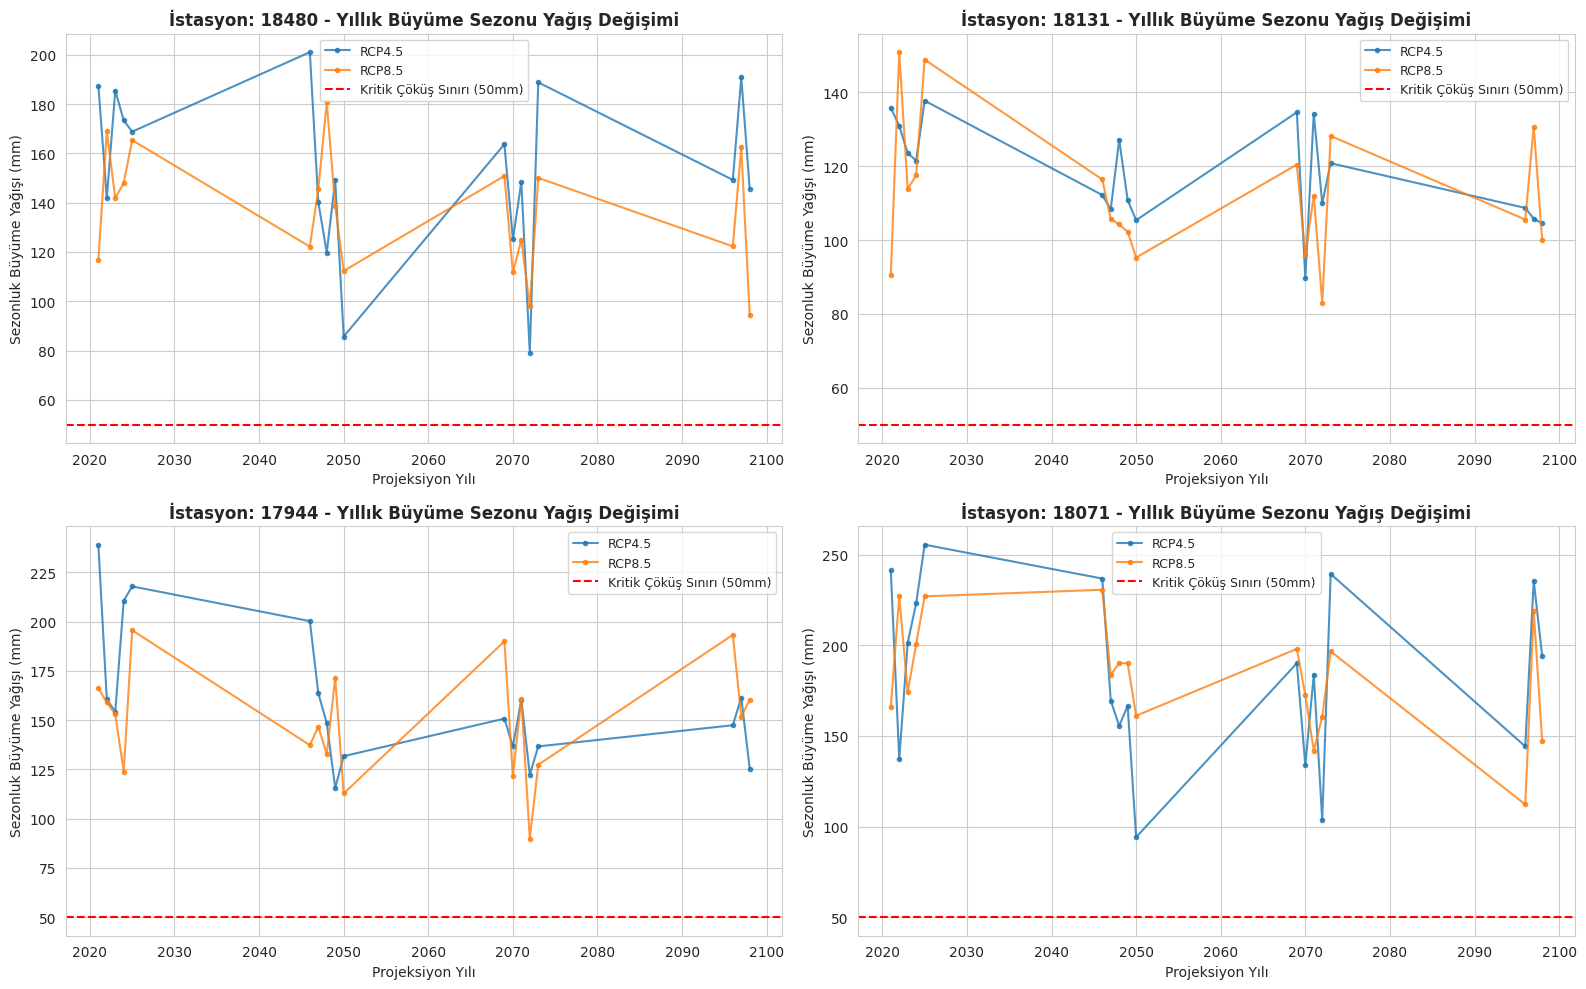


🚨 ZAMAN İÇİNDE ANİDEN KOPAN (ÇÖKEN) İSTASYONLARIN KİMLİK KARTI:


,İstasyon,Senaryo,Normal_Ortalama_Yagis,En_Kotu_Yil_Yagisi,Cokus_Yili


In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE HEDEF İSTASYONLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

print("\n🌟 49 İSTASYON İÇİN ZAMAN SERİSİ (YIL-YIL) EĞİLİM VE ÇÖKÜŞ ANALİZİ BAŞLIYOR...\n")

# Hedef 49 istasyon listesi
hedef_istasyonlar = [
    17749, 17065, 17839, 17944, 17978, 18015, 18026, 18054, 18060, 18071,
    18079, 18089, 18131, 18132, 18147, 18150, 18187, 18201, 18206, 18255,
    18256, 18271, 18307, 18343, 18350, 18361, 18384, 18480, 18519, 18525,
    18570, 18739, 18904, 18908, 17287, 18955, 18970, 18979, 18995, 19137,
    17302, 19143, 19160, 19184, 19903, 17614, 19991, 19226, 17022
]

# ==========================================
# 2. VERİ OKUMA VE BİRLEŞTİRME (YENİ SÜTUNLARA GÖRE)
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv")) + glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"📂 Toplam {len(dosya_listesi)} dosya bellek optimizasyonuyla taranıyor...")

zaman_serisi_verileri = []
# Sadece dosyada GÜNCEL bulunan başlıklar aranıyor
hedef_sutunlar = ['station_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'toplam_yagis_mm']

for dosya in dosya_listesi:
    try:
        dosya_adi = os.path.basename(dosya).lower()

        # Senaryo Tespiti
        senaryo = "Bilinmiyor"
        if "rcp85" in dosya_adi or "ssp585" in dosya_adi: senaryo = "RCP8.5"
        elif "rcp45" in dosya_adi or "ssp245" in dosya_adi: senaryo = "RCP4.5"

        if dosya.endswith('.csv'):
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        else:
            df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

        df.columns = df.columns.str.lower()

        # Sütunları garantile
        if 'station_no' in df.columns and 'toplam_yagis_mm' in df.columns:
            # Yılı Nihai_Ekim_Tarihi veya Nihai_Hasat_Tarihi içinden çekiyoruz
            tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df.columns else ('nihai_hasat_tarihi' if 'nihai_hasat_tarihi' in df.columns else None)

            if tarih_sutunu:
                # 2021-04-07 formatından sadece 2021 kısmını al (hızlı yöntem)
                df['Yıl'] = df[tarih_sutunu].astype(str).str[0:4].astype(int)

                # Sadece hedef istasyonları süz
                df_hedef = df[df['station_no'].isin(hedef_istasyonlar)].copy()

                if not df_hedef.empty:
                    df_ozet = df_hedef.groupby(['station_no', 'Yıl'])['toplam_yagis_mm'].mean().reset_index()
                    df_ozet['Senaryo'] = senaryo
                    zaman_serisi_verileri.append(df_ozet)

        # RAM'i temizle
        del df
    except Exception as e:
        continue

# ==========================================
# 3. ZAMAN SERİSİ ANALİZİ VE GRAFİK ÇİZİMİ
# ==========================================
if len(zaman_serisi_verileri) > 0:
    df_tum = pd.concat(zaman_serisi_verileri, ignore_index=True)
    df_tum.columns = ['İstasyon', 'Yıl', 'Yagis', 'Senaryo']

    # Her yıl o istasyon için aynı senaryoda birden fazla model sonucu varsa ortalamasını al
    df_tum = df_tum.groupby(['İstasyon', 'Yıl', 'Senaryo'])['Yagis'].mean().reset_index()

    # En kötü çöküşü yaşayan (en kurak değeri gören) 4 istasyonu bulalım (Grafik çizmek için)
    en_kotu_istasyonlar = df_tum.groupby('İstasyon')['Yagis'].min().sort_values().head(4).index.tolist()

    # --- GÖRSELLEŞTİRME (TEZ İÇİN) ---
    plt.figure(figsize=(16, 10))
    sns.set_style("whitegrid")

    for i, st in enumerate(en_kotu_istasyonlar):
        plt.subplot(2, 2, i+1)
        df_st = df_tum[df_tum['İstasyon'] == st].sort_values('Yıl')

        for sen in df_st['Senaryo'].unique():
            df_sen = df_st[df_st['Senaryo'] == sen]
            plt.plot(df_sen['Yıl'], df_sen['Yagis'], marker='o', markersize=3, label=sen, alpha=0.8)

        plt.title(f"İstasyon: {int(st)} - Yıllık Büyüme Sezonu Yağış Değişimi", fontsize=12, fontweight='bold')
        plt.xlabel("Projeksiyon Yılı")
        plt.ylabel("Sezonluk Büyüme Yağışı (mm)")
        # 50 mm risk sınırına kırmızı çizgi çek
        plt.axhline(y=50, color='r', linestyle='--', linewidth=1.5, label='Kritik Çöküş Sınırı (50mm)')
        plt.legend(fontsize=9)

    plt.tight_layout()
    grafik_yolu = "/content/drive/MyDrive/Doktora/Zaman_Serisi_Cokus_Grafigi.png"
    plt.savefig(grafik_yolu, dpi=300, bbox_inches='tight')

    print(f"\n📊 TEZE EKLENECEK GRAFİK KAYDEDİLDİ: {grafik_yolu}\n")
    plt.show()

    # --- TABLOLAŞTIRMA VE KOPUŞ YILLARI ---
    ozet = df_tum.groupby(['İstasyon', 'Senaryo']).agg(
        Normal_Ortalama_Yagis=('Yagis', 'mean'),
        En_Kotu_Yil_Yagisi=('Yagis', 'min')
    ).reset_index()

    # En kötü yağışın görüldüğü yılı (çöküş yılını) bul
    idx_min = df_tum.groupby(['İstasyon', 'Senaryo'])['Yagis'].idxmin()
    ozet['Cokus_Yili'] = df_tum.loc[idx_min, 'Yıl'].values

    # Sadece 50 mm'nin altına (çöl/kuraklık çizgisi) inenleri filtrele
    ozet_felaket = ozet[ozet['En_Kotu_Yil_Yagisi'] < 50.0].sort_values('En_Kotu_Yil_Yagisi')

    print("\n🚨 ZAMAN İÇİNDE ANİDEN KOPAN (ÇÖKEN) İSTASYONLARIN KİMLİK KARTI:")
    display(ozet_felaket)



🌟 ÜRÜN BAZLI ZAMAN SERİSİ (MEVSİMSEL ÇÖKÜŞ) ANALİZİ BAŞLIYOR...

📂 Toplam 1584 ürün dosyası taranıyor...

🚨 MEVSİMSEL MODEL ÇÖKÜŞLERİ (50 mm Altı Büyüme Sezonları):


İstasyon,Yıl,Urun,Senaryo,Yagis
17022.0,2098,Bezelye,RCP8.5,38.00
17022.0,2097,Sunflower,RCP8.5,39.50
17022.0,2098,Sunflower,RCP8.5,42.40
17065.0,2069,Pamuk,RCP8.5,20.30
17065.0,2096,Domates,RCP4.5,20.95
17065.0,2096,Pamuk,RCP4.5,23.55
17065.0,2098,Domates,RCP8.5,24.90
17065.0,2048,Bezelye,RCP8.5,25.30
17065.0,2025,Pamuk,RCP8.5,30.80
17065.0,2047,Domates,RCP8.5,31.00



👉 Maskesi düşürülen çöküş tablosu kaydedildi: /content/drive/MyDrive/Doktora/Urun_Bazli_Sezon_Cokusleri.csv

📊 TEZE EKLENECEK ÜRÜN BAZLI GRAFİK KAYDEDİLDİ: /content/drive/MyDrive/Doktora/Urun_Bazli_Cokus_Grafigi.png



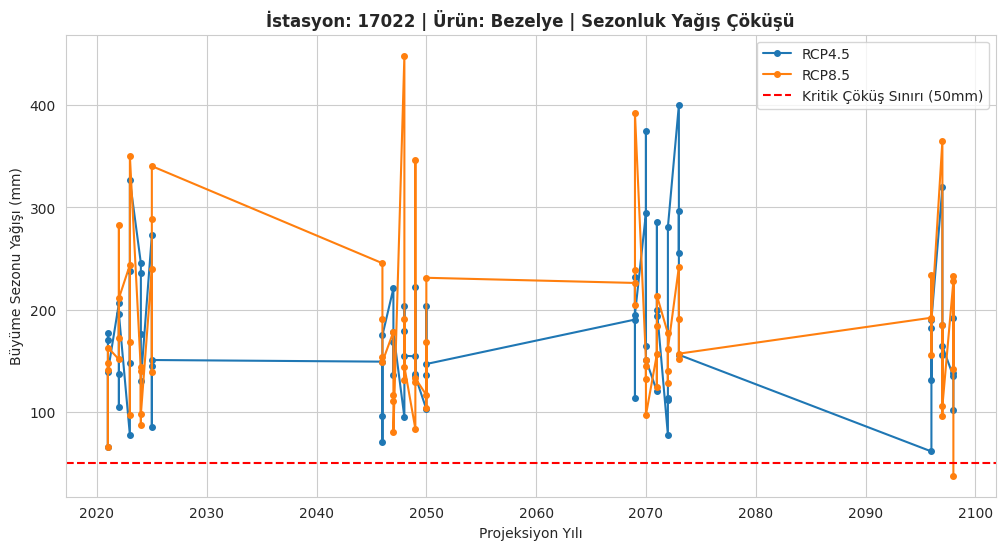

In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE HEDEF İSTASYONLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

print("\n🌟 ÜRÜN BAZLI ZAMAN SERİSİ (MEVSİMSEL ÇÖKÜŞ) ANALİZİ BAŞLIYOR...\n")

hedef_istasyonlar = [
    17749, 17065, 17839, 17944, 17978, 18015, 18026, 18054, 18060, 18071,
    18079, 18089, 18131, 18132, 18147, 18150, 18187, 18201, 18206, 18255,
    18256, 18271, 18307, 18343, 18350, 18361, 18384, 18480, 18519, 18525,
    18570, 18739, 18904, 18908, 17287, 18955, 18970, 18979, 18995, 19137,
    17302, 19143, 19160, 19184, 19903, 17614, 19991, 19226, 17022
]

# ==========================================
# 2. ÜRÜN İZOLASYONLU VERİ OKUMA
# ==========================================
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))

print(f"📂 Toplam {len(dosya_listesi)} ürün dosyası taranıyor...")

zaman_serisi = []
hedef_sutunlar = ['station_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'toplam_yagis_mm']

for dosya in dosya_listesi:
    try:
        dosya_adi = os.path.basename(dosya)
        # Dosya adından ÜRÜN bilgisini çıkar (Örn: bezelye_HadGEM2...)
        urun_adi = dosya_adi.split('_')[0].capitalize()

        senaryo = "Bilinmiyor"
        if "rcp85" in dosya_adi.lower() or "ssp585" in dosya_adi.lower(): senaryo = "RCP8.5"
        elif "rcp45" in dosya_adi.lower() or "ssp245" in dosya_adi.lower(): senaryo = "RCP4.5"

        df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        df.columns = df.columns.str.lower()

        if 'station_no' in df.columns and 'toplam_yagis_mm' in df.columns:
            tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df.columns else 'nihai_hasat_tarihi'

            if tarih_sutunu in df.columns:
                df['Yıl'] = df[tarih_sutunu].astype(str).str[0:4].astype(int)
                df_hedef = df[df['station_no'].isin(hedef_istasyonlar)].copy()

                if not df_hedef.empty:
                    df_hedef['Urun'] = urun_adi
                    df_hedef['Senaryo'] = senaryo

                    # Ürün bazlı gruplama yapıyoruz, diğer ürünlerle KARIŞTIRMIYORUZ!
                    df_ozet = df_hedef.groupby(['station_no', 'Yıl', 'Urun', 'Senaryo'])['toplam_yagis_mm'].mean().reset_index()
                    zaman_serisi.append(df_ozet)
        del df
    except:
        continue

# ==========================================
# 3. KOPUŞ YILLARININ TESPİTİ
# ==========================================
if len(zaman_serisi) > 0:
    df_tum = pd.concat(zaman_serisi, ignore_index=True)
    df_tum.columns = ['İstasyon', 'Yıl', 'Urun', 'Senaryo', 'Yagis']

    # Sadece 50 mm'nin altına düşen spesifik ürün sezonlarını (Felaketleri) filtrele
    felaketler = df_tum[df_tum['Yagis'] < 50.0].copy()

    if not felaketler.empty:
        felaketler.sort_values(['İstasyon', 'Yagis'], ascending=[True, True], inplace=True)

        print("\n🚨 MEVSİMSEL MODEL ÇÖKÜŞLERİ (50 mm Altı Büyüme Sezonları):")
        html_tablo = felaketler.head(40).to_html(index=False, classes='table table-striped table-bordered')
        display(HTML(html_tablo))

        # Drive'a kaydet
        kayit = "/content/drive/MyDrive/Doktora/Urun_Bazli_Sezon_Cokusleri.csv"
        felaketler.to_csv(kayit, index=False)
        print(f"\n👉 Maskesi düşürülen çöküş tablosu kaydedildi: {kayit}")

        # En kötü durumu yaşayan bir istasyon-ürün kombosunun grafiğini çiz
        ornek_istasyon = felaketler.iloc[0]['İstasyon']
        ornek_urun = felaketler.iloc[0]['Urun']

        df_grafik = df_tum[(df_tum['İstasyon'] == ornek_istasyon) & (df_tum['Urun'] == ornek_urun)].sort_values('Yıl')

        plt.figure(figsize=(12, 6))
        for sen in df_grafik['Senaryo'].unique():
            df_sen = df_grafik[df_grafik['Senaryo'] == sen]
            plt.plot(df_sen['Yıl'], df_sen['Yagis'], marker='o', markersize=4, label=sen)

        plt.axhline(y=50, color='r', linestyle='--', linewidth=1.5, label='Kritik Çöküş Sınırı (50mm)')
        plt.title(f"İstasyon: {int(ornek_istasyon)} | Ürün: {ornek_urun} | Sezonluk Yağış Çöküşü", fontweight='bold')
        plt.xlabel("Projeksiyon Yılı")
        plt.ylabel("Büyüme Sezonu Yağışı (mm)")
        plt.legend()

        grafik_yolu = "/content/drive/MyDrive/Doktora/Urun_Bazli_Cokus_Grafigi.png"
        plt.savefig(grafik_yolu, dpi=300)
        print(f"\n📊 TEZE EKLENECEK ÜRÜN BAZLI GRAFİK KAYDEDİLDİ: {grafik_yolu}\n")
        plt.show()
    else:
        print("✅ Harika! Ürün bazlı ayırdığımızda bile 50 mm altına düşen hiçbir büyüme sezonu kalmadı.")
else:
    print("Veriler okunamadı.")

In [ ]:
import pandas as pd

# İstasyon bazında ortalama yağış değerlerini hesaplama
istasyon_ortalama_yagis = df_tum.groupby('İstasyon')['Yagis'].mean().reset_index()

# Büyükten küçüğe sıralama
istasyon_ortalama_yagis = istasyon_ortalama_yagis.sort_values(by='Yagis', ascending=False).reset_index(drop=True)

# Sonuçları gösterme
print("İstasyonların Ortalama Büyüme Sezonu Yağış Değerleri (mm):")
display(istasyon_ortalama_yagis)

İstasyonların Ortalama Büyüme Sezonu Yağış Değerleri (mm):


,İstasyon,Yagis
0,17302.0,552.731667
1,18955.0,547.005104
2,18307.0,541.209826
3,18054.0,398.436250
4,18026.0,378.499514
5,19184.0,349.774653
6,18970.0,328.284491
7,18570.0,328.123264
8,17749.0,321.466563
9,18384.0,283.290152


In [ ]:
import os
import glob
import pandas as pd

klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv"))

hedef_sutunlar = ['station_no', 'toplam_yagis_mm']
tum_istasyon_verileri = []

print(f"📂 Toplam {len(dosya_listesi)} dosya tüm istasyonlar için taranıyor...")

for dosya in dosya_listesi:
    try:
        # Sadece istasyon numarası ve toplam yağış sütunlarını okuyoruz
        df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        df.columns = df.columns.str.lower()

        if 'station_no' in df.columns and 'toplam_yagis_mm' in df.columns:
            tum_istasyon_verileri.append(df)
    except:
        continue

if len(tum_istasyon_verileri) > 0:
    # Tüm verileri tek bir tabloda birleştir
    df_tum_istasyonlar = pd.concat(tum_istasyon_verileri, ignore_index=True)
    df_tum_istasyonlar['station_no'] = pd.to_numeric(df_tum_istasyonlar['station_no'], errors='coerce').fillna(0).astype(int)

    # İstasyon bazında genel ortalamayı hesapla
    tum_istasyon_ortalama = df_tum_istasyonlar.groupby('station_no')['toplam_yagis_mm'].mean().reset_index()
    tum_istasyon_ortalama.columns = ['İstasyon_No', 'Ortalama_Yagis_mm']

    # Büyükten küçüğe sırala
    tum_istasyon_ortalama = tum_istasyon_ortalama.sort_values(by='Ortalama_Yagis_mm', ascending=False).reset_index(drop=True)

    print("\n🌍 Tüm İstasyonların Ortalama Büyüme Sezonu Yağış Değerleri (mm):")
    display(tum_istasyon_ortalama)
else:
    print("❌ İşlenecek veri bulunamadı.")

📂 Toplam 1584 dosya tüm istasyonlar için taranıyor...

🌍 Tüm İstasyonların Ortalama Büyüme Sezonu Yağış Değerleri (mm):


,İstasyon_No,Ortalama_Yagis_mm
0,17372,573.908780
1,17302,552.731667
2,18955,547.005104
3,18307,541.209826
4,17298,496.821979
...,...,...
155,17192,127.718576
156,17024,127.172627
157,18172,118.003202
158,17246,116.108102


📉 En az yağış alan 5 istasyon: [17192, 17024, 18172, 17246, 18131]

📂 Yıllık veriler taranıyor (Toplam dosya: 1584)...


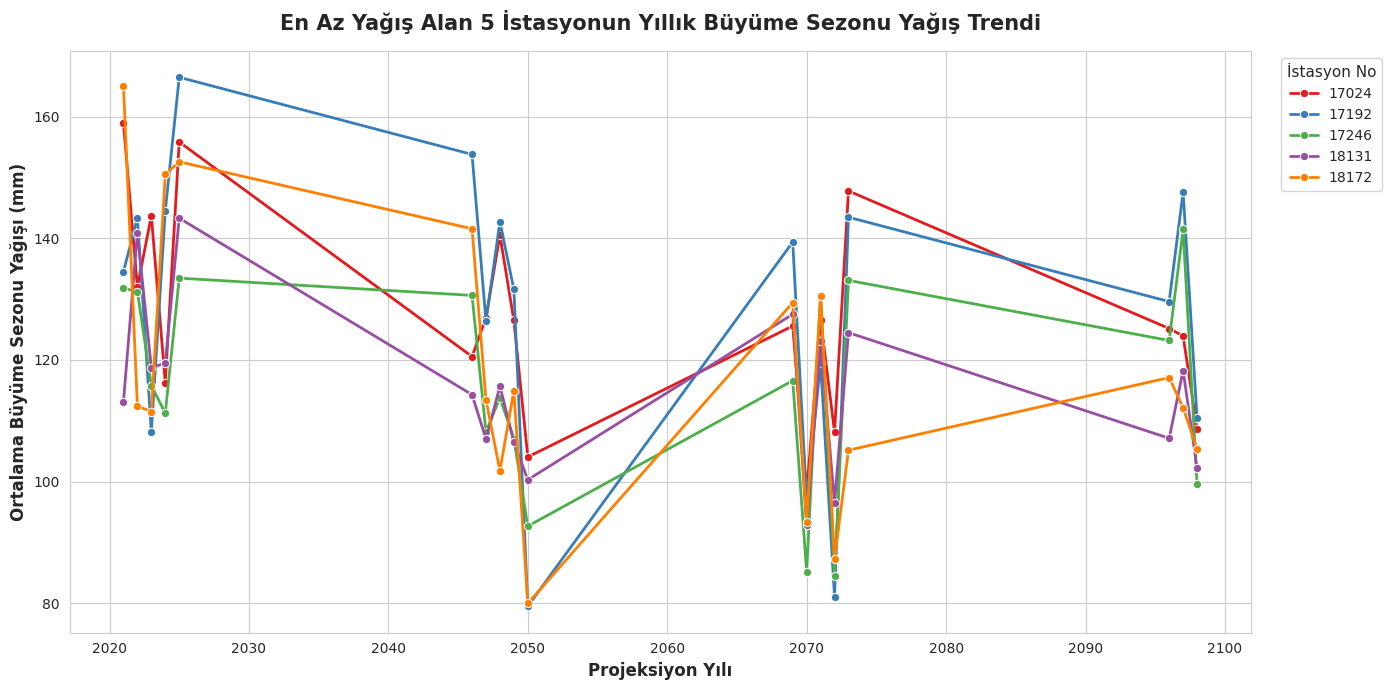

In [ ]:
import os
import glob
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. En az yağış alan 5 istasyonu belirle
son_5_istasyon = tum_istasyon_ortalama.tail(5)['İstasyon_No'].tolist()
print(f"📉 En az yağış alan 5 istasyon: {son_5_istasyon}\n")

# 2. Dosyaların bulunduğu klasör (V3 WF sonuçları)
klasor_yolu = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
dosya_listesi = glob.glob(os.path.join(klasor_yolu, "*.csv")) + glob.glob(os.path.join(klasor_yolu, "*.xlsx"))

print(f"📂 Yıllık veriler taranıyor (Toplam dosya: {len(dosya_listesi)})...")

hedef_sutunlar = ['station_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'toplam_yagis_mm']
zaman_serisi = []

# 3. Dosyaları tarayıp hedef istasyonların yıllık verilerini çekme
for dosya in dosya_listesi:
    try:
        if dosya.endswith('.csv'):
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
        else:
            df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

        df.columns = df.columns.str.lower()

        if 'station_no' in df.columns and 'toplam_yagis_mm' in df.columns:
            tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df.columns else ('nihai_hasat_tarihi' if 'nihai_hasat_tarihi' in df.columns else None)

            if tarih_sutunu:
                # Yılı string'den integer'a çevirerek çek
                df['Yıl'] = df[tarih_sutunu].astype(str).str[0:4].astype(int)

                # Sadece en az yağış alan 5 istasyonu filtrele
                df_hedef = df[df['station_no'].isin(son_5_istasyon)].copy()

                if not df_hedef.empty:
                    # Yıl ve istasyon bazında ortalama al
                    df_ozet = df_hedef.groupby(['station_no', 'Yıl'])['toplam_yagis_mm'].mean().reset_index()
                    zaman_serisi.append(df_ozet)
        del df
    except:
        continue

# 4. Verileri Birleştirme ve Grafik Çizimi
if zaman_serisi:
    df_trend = pd.concat(zaman_serisi, ignore_index=True)

    # Farklı senaryo/ürünlerden gelen aynı yıl ve istasyon verilerini genel ortalamaya indirgiyoruz
    df_trend_final = df_trend.groupby(['station_no', 'Yıl'])['toplam_yagis_mm'].mean().reset_index()
    df_trend_final['station_no'] = df_trend_final['station_no'].astype(int).astype(str) # Renklendirme için string yaptık

    # Çizim Ayarları
    plt.figure(figsize=(14, 7))
    sns.set_style("whitegrid")

    sns.lineplot(
        data=df_trend_final,
        x='Yıl',
        y='toplam_yagis_mm',
        hue='station_no',
        palette='Set1',
        marker='o',
        linewidth=2
    )

    plt.title('En Az Yağış Alan 5 İstasyonun Yıllık Büyüme Sezonu Yağış Trendi', fontsize=15, fontweight='bold', pad=15)
    plt.xlabel('Projeksiyon Yılı', fontsize=12, fontweight='bold')
    plt.ylabel('Ortalama Büyüme Sezonu Yağışı (mm)', fontsize=12, fontweight='bold')
    plt.legend(title='İstasyon No', title_fontsize='11', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("❌ İstasyonlara ait zaman serisi verisi bulunamadı.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 İSTASYON 18131 İÇİN 8 PANELLİ YEŞİL SU AYAK İZİ ANALİZİ BAŞLIYOR...

📂 Toplam 1584 ürün dosyası taranıyor...

✅ 8'li panel grafik başarıyla oluşturuldu ve teziniz için kaydedildi:
👉 /content/drive/MyDrive/Doktora/Istasyon_18131_Yesil_Su_8li_Grafik.png



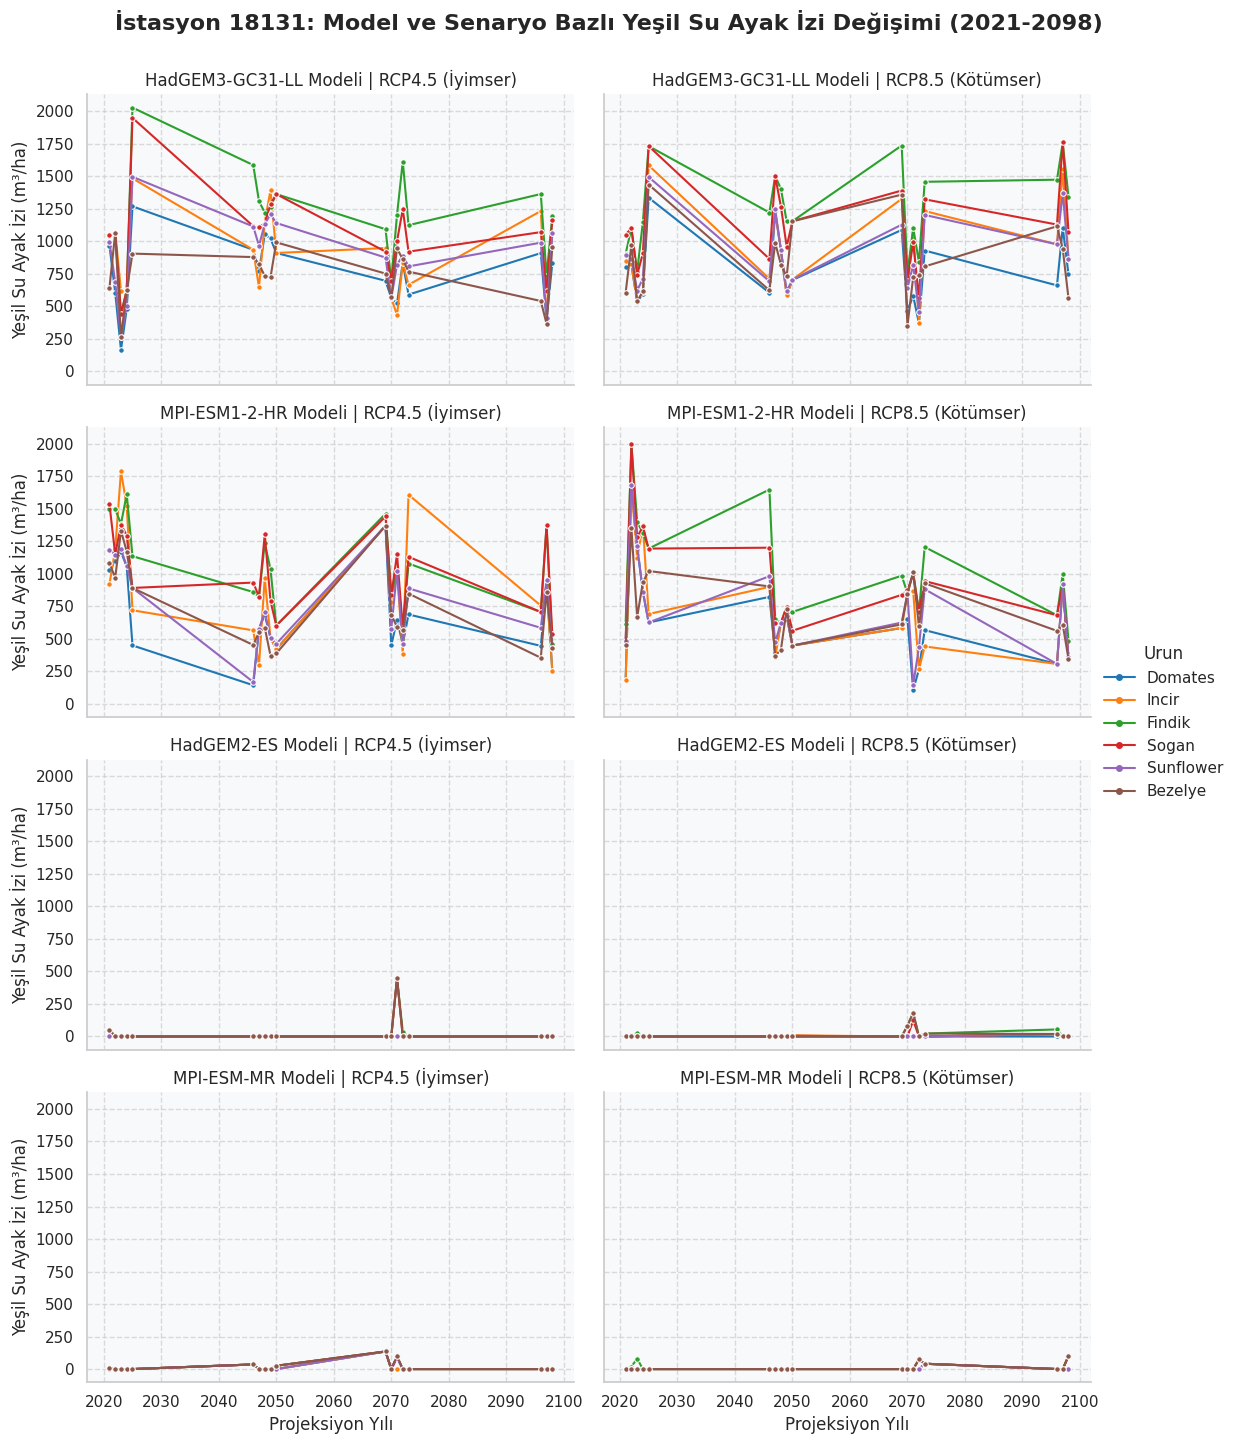

In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE AYARLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

# Dilediğiniz zaman bu numarayı değiştirerek başka istasyonları çizebilirsiniz
HEDEF_ISTASYON = 18131
KLASOR_YOLU = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

print(f"\n🌟 İSTASYON {HEDEF_ISTASYON} İÇİN 8 PANELLİ YEŞİL SU AYAK İZİ ANALİZİ BAŞLIYOR...\n")

# ==========================================
# 2. VERİ OKUMA VE BİRLEŞTİRME
# ==========================================
dosya_listesi = glob.glob(os.path.join(KLASOR_YOLU, "*.csv"))
print(f"📂 Toplam {len(dosya_listesi)} ürün dosyası taranıyor...")

# Tam olarak dosyalarınızdaki başlıkları arıyoruz
hedef_sutunlar = ['station_no', 'istasyon_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'yesil_su_ayak_izi_m3_ha']

veri_havuzu = []

for dosya in dosya_listesi:
    try:
        dosya_adi = os.path.basename(dosya)

        # Dosya adından Ürün ve Model bilgisini çıkar
        # Örn: bezelye_HadGEM2-ES_rcp45_2021_WF.csv
        parcalar = dosya_adi.replace(".csv", "").split("_")

        if len(parcalar) >= 3:
            urun = parcalar[0].capitalize()
            model_adi = parcalar[1]

            # Senaryo belirle
            senaryo = "Bilinmiyor"
            if "rcp85" in dosya_adi.lower() or "ssp585" in dosya_adi.lower():
                senaryo = "RCP8.5 (Kötümser)"
            elif "rcp45" in dosya_adi.lower() or "ssp245" in dosya_adi.lower():
                senaryo = "RCP4.5 (İyimser)"

            # Dosyayı oku
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
            df.columns = df.columns.str.lower()

            st_col = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
            ys_col = 'yesil_su_ayak_izi_m3_ha'

            if st_col and ys_col in df.columns:
                # Sadece hedef istasyonu seç (Örn: 18131)
                df_st = df[df[st_col] == HEDEF_ISTASYON].copy()

                if not df_st.empty:
                    tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df_st.columns else ('nihai_hasat_tarihi' if 'nihai_hasat_tarihi' in df_st.columns else None)

                    if tarih_sutunu:
                        df_st['Yıl'] = df_st[tarih_sutunu].astype(str).str[0:4].astype(int)

                        # O yılki Yeşil Su Ayak İzini al
                        df_ozet = df_st.groupby('Yıl')[ys_col].mean().reset_index()
                        df_ozet['Urun'] = urun
                        df_ozet['Model'] = model_adi
                        df_ozet['Senaryo'] = senaryo
                        veri_havuzu.append(df_ozet)
    except Exception as e:
        continue

# ==========================================
# 3. 8 PANELLİ (FACET GRID) GRAFİK ÇİZİMİ
# ==========================================
if len(veri_havuzu) > 0:
    df_tum = pd.concat(veri_havuzu, ignore_index=True)

    # Arka plan ve stil ayarları
    sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#f8f9fa"})

    # sns.relplot ile Modelleri satırlara (row), Senaryoları sütunlara (col) bölüyoruz
    # Çizgiler (hue) ise farklı tarım ürünlerini temsil edecek
    g = sns.relplot(
        data=df_tum,
        x="Yıl",
        y="yesil_su_ayak_izi_m3_ha",
        hue="Urun",
        col="Senaryo",
        row="Model",
        kind="line",
        height=3.5,     # Her bir alt grafiğin boyu
        aspect=1.6,     # Her bir alt grafiğin eni (genişliği)
        marker="o",
        markersize=4,
        palette="tab10",
        linewidth=1.5
    )

    # Eksen ve Başlık Düzenlemeleri
    g.set_axis_labels("Projeksiyon Yılı", "Yeşil Su Ayak İzi (m³/ha)")
    g.set_titles(row_template="{row_name} Modeli", col_template="{col_name}")
    g.fig.suptitle(f"İstasyon {HEDEF_ISTASYON}: Model ve Senaryo Bazlı Yeşil Su Ayak İzi Değişimi (2021-2098)", y=1.03, fontsize=16, fontweight="bold")

    # Izgara (Grid) görünürlüğünü artırma
    for ax in g.axes.flat:
        ax.grid(True, linestyle='--', alpha=0.7)

    # Grafiği Drive'a yüksek çözünürlüklü (300 dpi) kaydet
    grafik_yolu = f"/content/drive/MyDrive/Doktora/Istasyon_{HEDEF_ISTASYON}_Yesil_Su_8li_Grafik.png"
    plt.savefig(grafik_yolu, dpi=300, bbox_inches='tight')

    print(f"\n✅ 8'li panel grafik başarıyla oluşturuldu ve teziniz için kaydedildi:\n👉 {grafik_yolu}\n")
    plt.show()

else:
    print(f"⚠️ İstasyon {HEDEF_ISTASYON} için Yeşil Su Ayak İzi verisi eşleştirilemedi.")

In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE AYARLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import warnings
from IPython.display import display, HTML

warnings.filterwarnings('ignore')

print("\n🌟 160 İSTASYON İÇİN SİSTEMATİK 'DÜZ ÇİZGİ' (FLATLINE) MODEL ÇÖKÜŞÜ TARAMASI BAŞLIYOR...\n")

KLASOR_YOLU = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

# Hem CSV hem XLSX dosyalarını bul
dosya_listesi = glob.glob(os.path.join(KLASOR_YOLU, "*.csv")) + glob.glob(os.path.join(KLASOR_YOLU, "*.xlsx"))
print(f"📂 Toplam {len(dosya_listesi)} dosya bellek optimizasyonuyla taranıyor...")

# ==========================================
# 2. VERİ OKUMA VE MODEL BAZLI GRUPLAMA
# ==========================================
hedef_sutunlar = ['station_no', 'istasyon_no', 'yesil_su_ayak_izi_m3_ha']
veri_havuzu = []

for dosya in dosya_listesi:
    try:
        dosya_adi = os.path.basename(dosya)

        # Dosya adından Model bilgisini çıkar (Örn: bezelye_HadGEM2-ES_rcp45_2021_WF.csv)
        parcalar = dosya_adi.replace(".csv", "").replace(".xlsx", "").split("_")

        if len(parcalar) >= 3:
            model_adi = parcalar[1]  # Dosya adındaki 2. parça model ismidir

            # Sadece gerekli sütunları oku (RAM tasarrufu)
            if dosya.endswith('.csv'):
                df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
            else:
                df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

            df.columns = df.columns.str.lower()

            st_col = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
            ys_col = 'yesil_su_ayak_izi_m3_ha'

            if st_col and ys_col in df.columns:
                # NaN değerleri temizle
                df = df.dropna(subset=[st_col, ys_col])

                # Her dosyadaki istasyonlar için Ortalama ve Maksimum yeşil su değerini hesapla
                df_ozet = df.groupby(st_col)[ys_col].agg(['mean', 'max']).reset_index()
                df_ozet['Model'] = model_adi
                veri_havuzu.append(df_ozet)

            del df
    except Exception as e:
        continue

# ==========================================
# 3. 18131 BENZERİ ÇÖKÜŞLERİN TESPİTİ
# ==========================================
if len(veri_havuzu) > 0:
    # Tüm dosyaların özetlerini birleştir
    df_tum = pd.concat(veri_havuzu, ignore_index=True)
    df_tum.rename(columns={'station_no': 'İstasyon', 'istasyon_no': 'İstasyon'}, inplace=True)

    # İstasyon ve Model bazında nihai özet (Çünkü aynı modelin birden fazla ürün/senaryo dosyası var)
    df_nihai = df_tum.groupby(['İstasyon', 'Model']).agg(
        Ortalama_Yesil_Su=('mean', 'mean'),
        Maksimum_Yesil_Su=('max', 'max')
    ).reset_index()

    # 🚨 KRİTİK FİLTRE: "18131 GİBİ OLANLAR"
    # Bir modelin ürettiği maksimum yeşil su ayak izi tüm yıllar ve ürünler boyunca 50 m³/ha'nın altındaysa,
    # o model o istasyonda "düz çizgiye (sıfıra)" bağlamış demektir.
    df_cokenler = df_nihai[df_nihai['Maksimum_Yesil_Su'] < 50.0].copy()

    if not df_cokenler.empty:
        df_cokenler.sort_values(by=['İstasyon', 'Maksimum_Yesil_Su'], inplace=True)
        df_cokenler['İstasyon'] = df_cokenler['İstasyon'].astype(int)
        df_cokenler['Ortalama_Yesil_Su'] = df_cokenler['Ortalama_Yesil_Su'].round(2)
        df_cokenler['Maksimum_Yesil_Su'] = df_cokenler['Maksimum_Yesil_Su'].round(2)

        essiz_istasyon_sayisi = df_cokenler['İstasyon'].nunique()
        coken_modeller = df_cokenler['Model'].unique().tolist()

        print(f"🚨 TESPİT EDİLDİ: 160 istasyonun {essiz_istasyon_sayisi} tanesinde, belirli modeller tıpkı 18131'deki gibi tamamen sıfıra çakılmış!")
        print(f"📉 Çöküş Yaşatan (Düz Çizgi Üreten) Modeller: {', '.join(coken_modeller)}\n")

        print("📊 İŞTE 18131 BENZERİ 'DÜZ ÇİZGİ' SENDROMU YAŞAYAN İSTASYONLARIN KİMLİK KARTI:")
        html_tablo = df_cokenler.to_html(index=False, classes='table table-striped table-bordered table-hover style="width: 100%; text-align: center;"')
        display(HTML(html_tablo))

        # Sonuçları Drive'a kaydet
        kayit_yolu = "/content/drive/MyDrive/Doktora/Duz_Cizgi_Sendromlu_Istasyonlar.csv"
        df_cokenler.to_csv(kayit_yolu, index=False)
        print(f"\n👉 Detaylı liste tezinizde kullanmanız için kaydedildi: {kayit_yolu}")

    else:
        print("✅ Harika! 18131 dışında hiçbir istasyonda 'düz çizgi (sıfıra çakılma)' sendromu tespit edilmedi.")
else:
    print("⚠️ Veri okunamadı. Sütun isimlerini veya klasör yolunu kontrol edin.")


🌟 160 İSTASYON İÇİN SİSTEMATİK 'DÜZ ÇİZGİ' (FLATLINE) MODEL ÇÖKÜŞÜ TARAMASI BAŞLIYOR...

📂 Toplam 1584 dosya bellek optimizasyonuyla taranıyor...
✅ Harika! 18131 dışında hiçbir istasyonda 'düz çizgi (sıfıra çakılma)' sendromu tespit edilmedi.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 İSTASYON 17033 İÇİN 8 PANELLİ YEŞİL SU AYAK İZİ ANALİZİ BAŞLIYOR...

📂 Toplam 1584 ürün dosyası taranıyor...

✅ 8'li panel grafik başarıyla oluşturuldu ve teziniz için kaydedildi:
👉 /content/drive/MyDrive/Doktora/Istasyon_17033_Yesil_Su_8li_Grafik.png



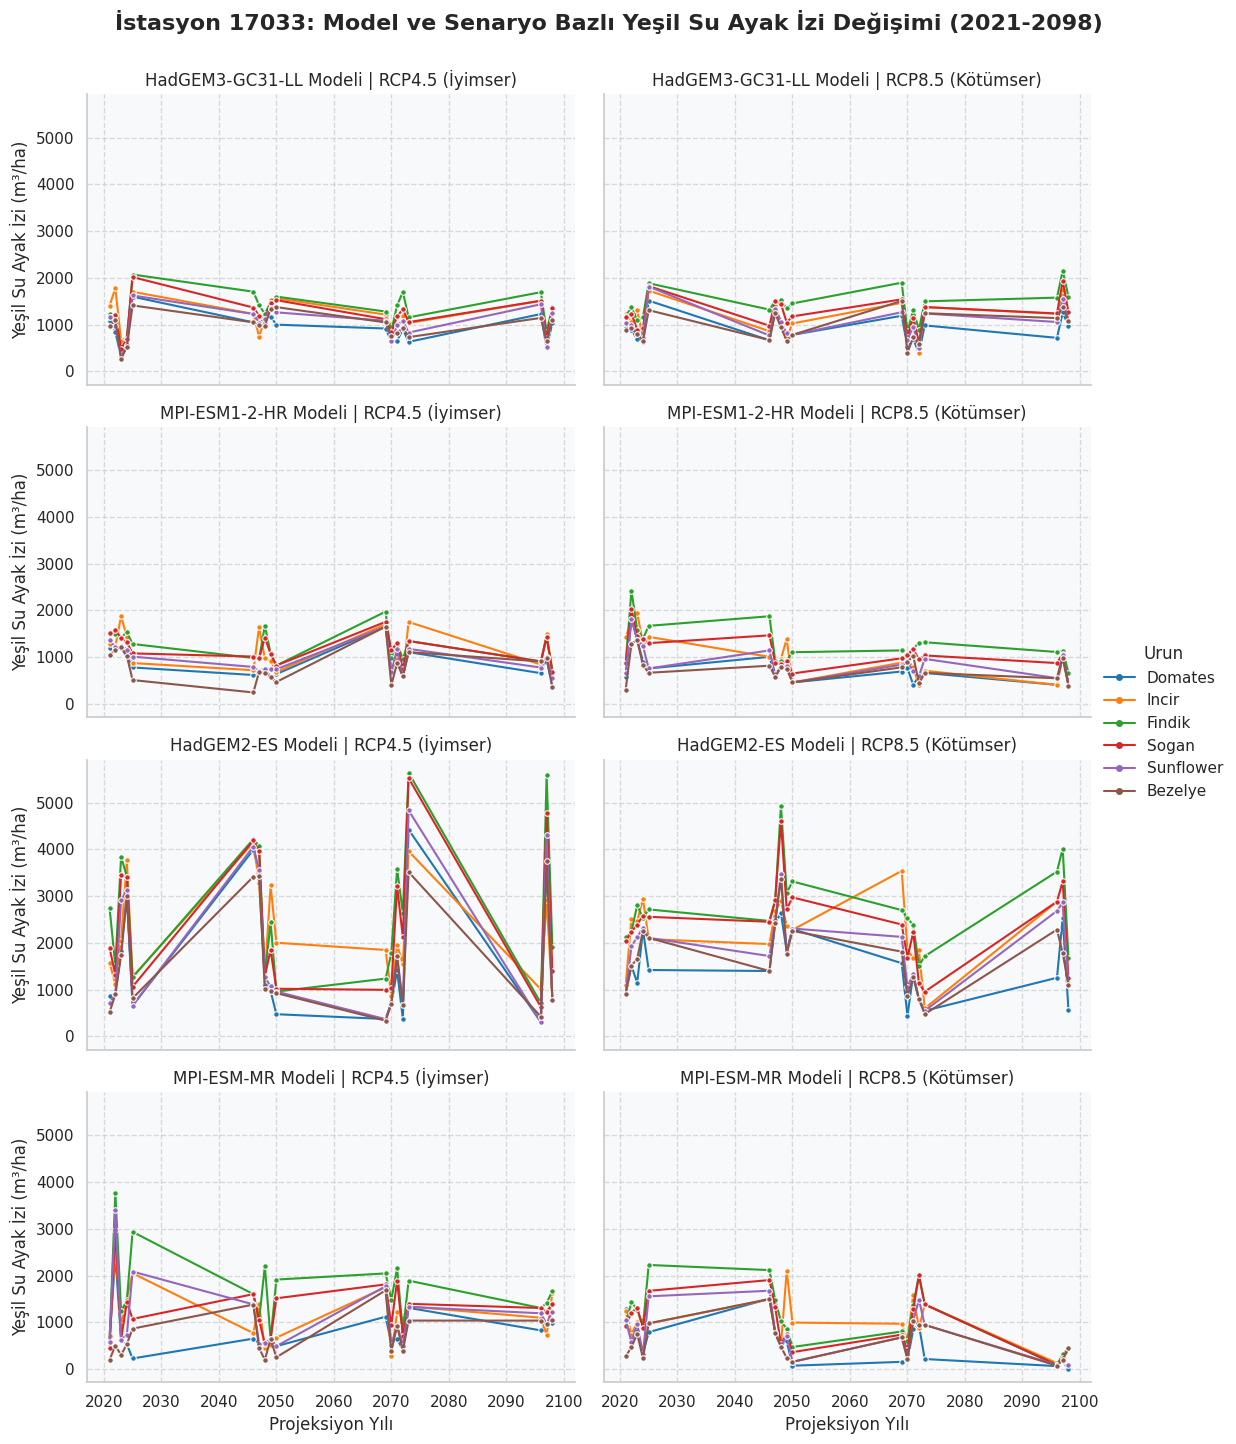

In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE AYARLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

# Hedef istasyonu 17033 olarak güncelledik
HEDEF_ISTASYON = 17033
KLASOR_YOLU = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"

print(f"\n🌟 İSTASYON {HEDEF_ISTASYON} İÇİN 8 PANELLİ YEŞİL SU AYAK İZİ ANALİZİ BAŞLIYOR...\n")

# ==========================================
# 2. VERİ OKUMA VE BİRLEŞTİRME
# ==========================================
dosya_listesi = glob.glob(os.path.join(KLASOR_YOLU, "*.csv"))
print(f"📂 Toplam {len(dosya_listesi)} ürün dosyası taranıyor...")

# Tam olarak dosyalarınızdaki başlıkları arıyoruz
hedef_sutunlar = ['station_no', 'istasyon_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'yesil_su_ayak_izi_m3_ha']

veri_havuzu = []

for dosya in dosya_listesi:
    try:
        dosya_adi = os.path.basename(dosya)

        # Dosya adından Ürün ve Model bilgisini çıkar
        # Örn: bezelye_HadGEM2-ES_rcp45_2021_WF.csv
        parcalar = dosya_adi.replace(".csv", "").split("_")

        if len(parcalar) >= 3:
            urun = parcalar[0].capitalize()
            model_adi = parcalar[1]

            # Senaryo belirle
            senaryo = "Bilinmiyor"
            if "rcp85" in dosya_adi.lower() or "ssp585" in dosya_adi.lower():
                senaryo = "RCP8.5 (Kötümser)"
            elif "rcp45" in dosya_adi.lower() or "ssp245" in dosya_adi.lower():
                senaryo = "RCP4.5 (İyimser)"

            # Dosyayı oku
            df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
            df.columns = df.columns.str.lower()

            st_col = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
            ys_col = 'yesil_su_ayak_izi_m3_ha'

            if st_col and ys_col in df.columns:
                # Sadece hedef istasyonu seç (Örn: 17024)
                df_st = df[df[st_col] == HEDEF_ISTASYON].copy()

                if not df_st.empty:
                    tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df_st.columns else ('nihai_hasat_tarihi' if 'nihai_hasat_tarihi' in df_st.columns else None)

                    if tarih_sutunu:
                        df_st['Yıl'] = df_st[tarih_sutunu].astype(str).str[0:4].astype(int)

                        # O yılki Yeşil Su Ayak İzini al
                        df_ozet = df_st.groupby('Yıl')[ys_col].mean().reset_index()
                        df_ozet['Urun'] = urun
                        df_ozet['Model'] = model_adi
                        df_ozet['Senaryo'] = senaryo
                        veri_havuzu.append(df_ozet)
    except Exception as e:
        continue

# ==========================================
# 3. 8 PANELLİ (FACET GRID) GRAFİK ÇİZİMİ
# ==========================================
if len(veri_havuzu) > 0:
    df_tum = pd.concat(veri_havuzu, ignore_index=True)

    # Arka plan ve stil ayarları
    sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#f8f9fa"})

    # sns.relplot ile Modelleri satırlara (row), Senaryoları sütunlara (col) bölüyoruz
    g = sns.relplot(
        data=df_tum,
        x="Yıl",
        y="yesil_su_ayak_izi_m3_ha",
        hue="Urun",
        col="Senaryo",
        row="Model",
        kind="line",
        height=3.5,
        aspect=1.6,
        marker="o",
        markersize=4,
        palette="tab10",
        linewidth=1.5
    )

    # Eksen ve Başlık Düzenlemeleri
    g.set_axis_labels("Projeksiyon Yılı", "Yeşil Su Ayak İzi (m³/ha)")
    g.set_titles(row_template="{row_name} Modeli", col_template="{col_name}")
    g.fig.suptitle(f"İstasyon {HEDEF_ISTASYON}: Model ve Senaryo Bazlı Yeşil Su Ayak İzi Değişimi (2021-2098)", y=1.03, fontsize=16, fontweight="bold")

    # Izgara (Grid) görünürlüğünü artırma
    for ax in g.axes.flat:
        ax.grid(True, linestyle='--', alpha=0.7)

    # Grafiği Drive'a yüksek çözünürlüklü (300 dpi) kaydet
    grafik_yolu = f"/content/drive/MyDrive/Doktora/Istasyon_{HEDEF_ISTASYON}_Yesil_Su_8li_Grafik.png"
    plt.savefig(grafik_yolu, dpi=300, bbox_inches='tight')

    print(f"\n✅ 8'li panel grafik başarıyla oluşturuldu ve teziniz için kaydedildi:\n👉 {grafik_yolu}\n")
    plt.show()
else:
    print(f"⚠️ İstasyon {HEDEF_ISTASYON} için Yeşil Su Ayak İzi verisi bulunamadı.")

In [ ]:
# ==========================================
# 1. KÜTÜPHANELER VE AYARLAR
# ==========================================
from google.colab import drive
import pandas as pd
import glob
import os
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from tqdm import tqdm

warnings.filterwarnings('ignore')
drive.mount('/content/drive')

KLASOR_YOLU = "/content/drive/MyDrive/Doktora/Projection/Products_WF_Results_V3"
KAYIT_KLASORU = "/content/drive/MyDrive/Doktora/Istasyon_Grafikleri"

if not os.path.exists(KAYIT_KLASORU):
    os.makedirs(KAYIT_KLASORU)

print("\n🌟 160 İSTASYON İÇİN RCP/SSP GÜNCELLEMELİ GRAFİK ÜRETİMİ BAŞLIYOR...\n")

# ==========================================
# 2. TÜM VERİLERİ BİR KERE OKUMA
# ==========================================
dosya_listesi = glob.glob(os.path.join(KLASOR_YOLU, "*.csv")) + glob.glob(os.path.join(KLASOR_YOLU, "*.xlsx"))
print(f"📂 Toplam {len(dosya_listesi)} dosya belleğe alınıyor...")

hedef_sutunlar = ['station_no', 'istasyon_no', 'nihai_ekim_tarihi', 'nihai_hasat_tarihi', 'yesil_su_ayak_izi_m3_ha']
veri_havuzu = []

for dosya in tqdm(dosya_listesi, desc="Dosyalar Okunuyor"):
    try:
        dosya_adi = os.path.basename(dosya)
        parcalar = dosya_adi.replace(".csv", "").replace(".xlsx", "").split("_")

        if len(parcalar) >= 3:
            urun = parcalar[0].capitalize()
            model_adi = parcalar[1]

            # Grafiğin sütun düzenini korumak için jenerik isim (İyimser/Kötümser) veriyoruz
            senaryo = "Bilinmiyor"
            if "rcp85" in dosya_adi.lower() or "ssp585" in dosya_adi.lower():
                senaryo = "Kötümser"
            elif "rcp45" in dosya_adi.lower() or "ssp245" in dosya_adi.lower():
                senaryo = "İyimser"

            if dosya.endswith('.csv'):
                df = pd.read_csv(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)
            else:
                df = pd.read_excel(dosya, usecols=lambda c: c.lower() in hedef_sutunlar)

            df.columns = df.columns.str.lower()
            st_col = 'station_no' if 'station_no' in df.columns else ('istasyon_no' if 'istasyon_no' in df.columns else None)
            ys_col = 'yesil_su_ayak_izi_m3_ha'

            if st_col and ys_col in df.columns:
                df = df.dropna(subset=[st_col, ys_col])
                tarih_sutunu = 'nihai_ekim_tarihi' if 'nihai_ekim_tarihi' in df.columns else ('nihai_hasat_tarihi' if 'nihai_hasat_tarihi' in df.columns else None)

                if tarih_sutunu:
                    df['Yıl'] = df[tarih_sutunu].astype(str).str[0:4].astype(int)
                    df_ozet = df.groupby([st_col, 'Yıl'])[ys_col].mean().reset_index()
                    df_ozet['Urun'] = urun
                    df_ozet['Model'] = model_adi
                    df_ozet['Senaryo'] = senaryo
                    veri_havuzu.append(df_ozet)
            del df
    except Exception as e:
        continue

# ==========================================
# 3. RCP / SSP DÜZELTMELİ GRAFİK ÇİZİMİ
# ==========================================
if len(veri_havuzu) > 0:
    df_tum = pd.concat(veri_havuzu, ignore_index=True)
    st_col_final = 'station_no' if 'station_no' in df_tum.columns else 'istasyon_no'
    tum_istasyonlar = sorted(df_tum[st_col_final].unique().astype(int))

    sns.set_theme(style="whitegrid", rc={"axes.facecolor": "#f8f9fa"})

    for ist in tqdm(tum_istasyonlar, desc="Grafikler Çiziliyor (RCP/SSP Düzeltmeli)"):
        df_ist = df_tum[df_tum[st_col_final] == ist].copy()
        if df_ist.empty: continue

        g = sns.relplot(
            data=df_ist,
            x="Yıl", y="yesil_su_ayak_izi_m3_ha", hue="Urun", col="Senaryo", row="Model",
            kind="line", height=3.5, aspect=1.6, marker="o", markersize=4,
            palette="tab10", linewidth=1.5
        )

        g.set_axis_labels("Projeksiyon Yılı", "Yeşil Su Ayak İzi (m³/ha)")
        g.fig.suptitle(f"İstasyon {ist}: Model ve Senaryo Bazlı Yeşil Su Ayak İzi Değişimi (2021-2098)", y=1.03, fontsize=16, fontweight="bold")

        # MANUEL BAŞLIK (RCP/SSP) DÜZELTMESİ
        for ax in g.axes.flat:
            ax.grid(True, linestyle='--', alpha=0.7)
            mevcut_baslik = ax.get_title()

            if " | " in mevcut_baslik:
                model_kismi, senaryo_kismi = mevcut_baslik.split(" | ")
                model_ismi = model_kismi.replace("Model = ", "").strip()
                senaryo_tipi = senaryo_kismi.replace("Senaryo = ", "").strip()

                # CMIP6 Modelleri (SSP Kullanır)
                if "HadGEM3" in model_ismi or "MPI-ESM1-2" in model_ismi:
                    etiket = "SSP2-4.5 (İyimser)" if senaryo_tipi == "İyimser" else "SSP5-8.5 (Kötümser)"
                # CMIP5 Modelleri (RCP Kullanır)
                else:
                    etiket = "RCP4.5 (İyimser)" if senaryo_tipi == "İyimser" else "RCP8.5 (Kötümser)"

                ax.set_title(f"{model_ismi} Modeli | {etiket}", fontsize=11)

        grafik_yolu = os.path.join(KAYIT_KLASORU, f"Istasyon_{ist}_Yesil_Su.png")
        plt.savefig(grafik_yolu, dpi=300, bbox_inches='tight')
        plt.close('all')

    print(f"\n🎉 TÜM GRAFİKLER RCP VE SSP TERMİNOLOJİSİNE UYGUN OLARAK GÜNCELLENDİ: \n👉 {KAYIT_KLASORU}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

🌟 160 İSTASYON İÇİN RCP/SSP GÜNCELLEMELİ GRAFİK ÜRETİMİ BAŞLIYOR...

📂 Toplam 1584 dosya belleğe alınıyor...


Grafikler Çiziliyor (RCP/SSP Düzeltmeli): 100%|██████████| 160/160 [12:28<00:00,  4.68s/it]


🎉 TÜM GRAFİKLER RCP VE SSP TERMİNOLOJİSİNE UYGUN OLARAK GÜNCELLENDİ: 
👉 /content/drive/MyDrive/Doktora/Istasyon_Grafikleri
